#Breast Lesion Detection Using Weakly Dependent Customized Features and Machine Learning Models with Explainable Artificial Intelligence


**Paper:** Moldovanu et al., *Journal of Imaging* 2025, 11, 135  
**DOI:** [10.3390/jimaging11050135](https://doi.org/10.3390/jimaging11050135)

### Project positioning (important)

This notebook is **not** an exact numerical reproduction of the published Table 3 results.

It is an **independent scientific study** that:

1. Re-implements the CHi (bounded histogram) and Ci (grayscale density) feature families from the public BUSI dataset using ground-truth lesion masks.
2. Detects and documents serious inconsistencies in the authors’ publicly released feature tables (label inversion between the two CSVs; “density” table contains raw counts, not ratios).
3. Extends the original feature set with geometric descriptors (`mask_extent`, `bbox_aspect_ratio`, `lesion_area_fraction`, …) and evaluates the extension with paired McNemar tests.
4. Applies a full XAI stack (native importance, permutation importance, SHAP, LIME) and quantifies rank agreement.
5. Provides a transparent methodological audit (sample counts, split protocol, patient-level independence, clinical scope).

**Claim level:** Independent reimplementation + methodological extension + critical data audit.  
**Not claimed:** Exact reproduction of the paper’s reported accuracies, identical sample selection, or clinical deployment readiness.

##Cell 1 — Reproducible Environment Setup

In [1]:
# ============================================================
# CELL 1 — REPRODUCIBLE ENVIRONMENT SETUP
# ============================================================
# Purpose:
#   1. Select a dependency profile compatible with the active Python version.
#   2. Install the packages required by the BUSI feature-classification study.
#   3. Verify installed versions against explicit requirements.
#   4. Detect package changes that require a runtime restart.
#   5. Run pip check and preserve its complete diagnostic output.
#   6. Write a machine-readable environment manifest.
#
# Reproducibility policy:
#   - Python 3.9–3.12 uses the legacy pinned package profile.
#   - Python 3.13+ uses bounded compatibility constraints.
#   - The compatibility profile is not an exact reproduction of the
#     paper's Python 3.10 / scikit-learn 1.4.1 environment.
#   - The exact versions resolved at execution time are always recorded.
# ============================================================

import sys
import json
import platform
import subprocess

from datetime import datetime, timezone
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError


# ------------------------------------------------------------
# 1. Inspect the active Python interpreter
# ------------------------------------------------------------

PYTHON_VERSION = tuple(sys.version_info[:3])
PYTHON_VERSION_STRING = sys.version.split()[0]
IS_PYTHON_313_PLUS = sys.version_info >= (3, 13)

print("=" * 78)
print("REPRODUCIBLE ENVIRONMENT SETUP")
print("=" * 78)
print(f"Python version   : {PYTHON_VERSION_STRING}")
print(f"Python executable : {sys.executable}")
print(f"Platform          : {platform.platform()}")

if sys.version_info < (3, 9):
    raise RuntimeError(
        "Python 3.9 or newer is required. "
        f"Detected Python {PYTHON_VERSION_STRING}."
    )


# ------------------------------------------------------------
# 2. Declare the legacy pinned environment
# ------------------------------------------------------------
# These pins approximate the package versions listed in the paper.
# They should be used only when compatible with the active Python version.

LEGACY_PINNED_REQUIREMENTS = {
    "numpy": "numpy==1.26.4",
    "scipy": "scipy==1.13.1",
    "pandas": "pandas==2.2.3",
    "matplotlib": "matplotlib==3.9.2",
    "scikit-learn": "scikit-learn==1.4.1.post1",
    "xgboost": "xgboost==2.1.4",
    "shap": "shap==0.46.0",
    "lime": "lime==0.2.0.1",
    "statsmodels": "statsmodels==0.14.4",
    "scikit-image": "scikit-image==0.24.0",
    "joblib": "joblib==1.4.2",
    "Pillow": "Pillow==11.0.0",
    "seaborn": "seaborn==0.13.2",
    "packaging": "packaging==24.2",
    # IPython in the current Colab base image may require Jedi.
    "jedi": "jedi==0.19.2",
}


# ------------------------------------------------------------
# 3. Declare compatibility constraints for Python 3.13+
# ------------------------------------------------------------
# Bounded requirements allow compatible package resolution but do not
# guarantee identical results on every future runtime.

PYTHON_313_COMPATIBILITY_REQUIREMENTS = {
    "numpy": "numpy>=2.1,<3.0",
    "scipy": "scipy>=1.14,<2.0",
    "pandas": "pandas>=2.2.3,<3.0",
    "matplotlib": "matplotlib>=3.9,<4.0",
    "scikit-learn": "scikit-learn>=1.6,<2.0",
    "xgboost": "xgboost>=2.1,<4.0",
    "shap": "shap>=0.50,<1.0",
    "lime": "lime==0.2.0.1",
    "statsmodels": "statsmodels>=0.14.4,<1.0",
    "scikit-image": "scikit-image>=0.25,<1.0",
    "joblib": "joblib>=1.4,<2.0",
    "Pillow": "Pillow>=11.0,<13.0",
    "seaborn": "seaborn>=0.13.2,<1.0",
    "packaging": "packaging>=24.2,<27.0",
    "jedi": "jedi>=0.19.2,<1.0",
}


# ------------------------------------------------------------
# 4. Select the dependency profile
# ------------------------------------------------------------

if IS_PYTHON_313_PLUS:
    ENVIRONMENT_MODE = "python_3.13_compatible_constraints"
    PACKAGE_REQUIREMENTS = (
        PYTHON_313_COMPATIBILITY_REQUIREMENTS.copy()
    )
    REPRODUCIBILITY_LEVEL = (
        "Compatibility constraints; resolved versions are recorded, "
        "but the full dependency graph is not exactly pinned."
    )
else:
    ENVIRONMENT_MODE = "legacy_exact_pins"
    PACKAGE_REQUIREMENTS = LEGACY_PINNED_REQUIREMENTS.copy()
    REPRODUCIBILITY_LEVEL = (
        "Exact direct-dependency pins selected; verify the resolved "
        "environment and platform before making reproduction claims."
    )

EXPECTED_VERSIONS = {
    package_name: (
        requirement_text.split("==", 1)[1]
        if "==" in requirement_text
        else None
    )
    for package_name, requirement_text in PACKAGE_REQUIREMENTS.items()
}

print(f"\nEnvironment mode: {ENVIRONMENT_MODE}")
print(f"Direct dependencies: {len(PACKAGE_REQUIREMENTS)}")


# ------------------------------------------------------------
# 5. Record pre-install versions and loaded modules
# ------------------------------------------------------------

PACKAGE_IMPORT_MAP = {
    "numpy": "numpy",
    "scipy": "scipy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scikit-learn": "sklearn",
    "xgboost": "xgboost",
    "shap": "shap",
    "lime": "lime",
    "statsmodels": "statsmodels",
    "scikit-image": "skimage",
    "joblib": "joblib",
    "Pillow": "PIL",
    "seaborn": "seaborn",
    "packaging": "packaging",
    "jedi": "jedi",
}

PRE_INSTALL_VERSIONS = {}

for package_name in PACKAGE_REQUIREMENTS:
    try:
        PRE_INSTALL_VERSIONS[package_name] = version(package_name)
    except PackageNotFoundError:
        PRE_INSTALL_VERSIONS[package_name] = None

PRELOADED_MODULES = {
    package_name: import_name in sys.modules
    for package_name, import_name in PACKAGE_IMPORT_MAP.items()
}


# ------------------------------------------------------------
# 6. Install requirements using the active Python interpreter
# ------------------------------------------------------------
# Using sys.executable avoids installing packages into a different
# interpreter found on PATH.

install_command = [
    sys.executable,
    "-m",
    "pip",
    "install",
    "--disable-pip-version-check",
    "--upgrade-strategy",
    "only-if-needed",
    *PACKAGE_REQUIREMENTS.values(),
]

print("\nInstalling required packages...")
installation_result = subprocess.run(
    install_command,
    text=True,
    check=False,
)

if installation_result.returncode != 0:
    raise RuntimeError(
        "Package installation failed. Review the pip output and rerun "
        "Cell 1 only after resolving the installation failure."
    )


# ------------------------------------------------------------
# 7. Verify each installed version against its requirement
# ------------------------------------------------------------

from packaging.requirements import Requirement
from packaging.version import Version

version_report = []
version_mismatches = []
INSTALLED_VERSIONS = {}

for package_name, requirement_text in PACKAGE_REQUIREMENTS.items():
    requirement = Requirement(requirement_text)

    try:
        installed_version = version(package_name)
    except PackageNotFoundError:
        installed_version = "NOT INSTALLED"

    INSTALLED_VERSIONS[package_name] = installed_version

    if installed_version == "NOT INSTALLED":
        requirement_satisfied = False
    else:
        requirement_satisfied = requirement.specifier.contains(
            Version(installed_version),
            prereleases=True,
        )

    version_report.append({
        "package": package_name,
        "requirement": requirement_text,
        "installed_version": installed_version,
        "requirement_satisfied": bool(requirement_satisfied),
    })

    if not requirement_satisfied:
        version_mismatches.append(
            f"{package_name}: required={requirement_text}; "
            f"installed={installed_version}"
        )


# ------------------------------------------------------------
# 8. Detect whether a runtime restart is required
# ------------------------------------------------------------

restart_required_packages = []

for package_name, was_preloaded in PRELOADED_MODULES.items():
    if not was_preloaded:
        continue

    previous_version = PRE_INSTALL_VERSIONS.get(package_name)
    current_version = INSTALLED_VERSIONS.get(package_name)

    if (
        previous_version is not None
        and current_version not in (None, "NOT INSTALLED")
        and previous_version != current_version
    ):
        restart_required_packages.append({
            "package": package_name,
            "version_before_install": previous_version,
            "version_after_install": current_version,
        })


# ------------------------------------------------------------
# 9. Run pip check and preserve all diagnostics
# ------------------------------------------------------------
# A non-zero pip-check status is recorded and reported. It is not silently
# treated as success. Unrelated base-image conflicts may require separate
# investigation.

dependency_check = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True,
    check=False,
)

if dependency_check.returncode == 0:
    print("pip check: no dependency conflicts reported.")
else:
    print("WARNING: pip check reported dependency conflicts.")
    if dependency_check.stdout.strip():
        print(dependency_check.stdout.strip())
    if dependency_check.stderr.strip():
        print(dependency_check.stderr.strip())


# ------------------------------------------------------------
# 10. Save the environment manifest
# ------------------------------------------------------------

ENVIRONMENT_RECORD_PATH = (
    Path.cwd() / "environment_record_cell1.json"
)

environment_record = {
    "paper_title": (
        "Breast Lesion Detection Using Weakly Dependent Customized "
        "Features and Machine Learning Models with XAI"
    ),
    "paper_doi": "10.3390/jimaging11050135",
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "python_version_short": PYTHON_VERSION_STRING,
    "python_executable": sys.executable,
    "platform": platform.platform(),
    "environment_mode": ENVIRONMENT_MODE,
    "reproducibility_level": REPRODUCIBILITY_LEVEL,
    # Record the paper's reported software stack separately from the active stack.
    # Compatibility constraints do not constitute an exact environment match.
    "paper_reported_environment": {
        "python": "3.10",
        "scikit_learn": "1.4.1",
        "shap": "0.46.0",
        "lime": "0.2.0.1",
        "matlab_feature_extraction": "R2021a",
    },
    "paper_software_versions_match": bool(
        sys.version_info[:2] == (3, 10)
        and INSTALLED_VERSIONS.get("scikit-learn") in {"1.4.1", "1.4.1.post1"}
        and INSTALLED_VERSIONS.get("shap") == "0.46.0"
        and INSTALLED_VERSIONS.get("lime") == "0.2.0.1"
    ),
    "package_requirements": PACKAGE_REQUIREMENTS,
    "expected_package_versions": EXPECTED_VERSIONS,
    "installed_package_versions": INSTALLED_VERSIONS,
    "version_report": version_report,
    "version_mismatches": version_mismatches,
    "preloaded_modules": PRELOADED_MODULES,
    "restart_required_packages": restart_required_packages,
    "pip_check_returncode": int(dependency_check.returncode),
    "pip_check_stdout": dependency_check.stdout.strip(),
    "pip_check_stderr": dependency_check.stderr.strip(),
}

with ENVIRONMENT_RECORD_PATH.open("w", encoding="utf-8") as file:
    json.dump(
        environment_record,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(f"\nEnvironment manifest: {ENVIRONMENT_RECORD_PATH}")


# ------------------------------------------------------------
# 11. Stop when stale imported modules could affect the run
# ------------------------------------------------------------

if restart_required_packages:
    print("\nRUNTIME RESTART REQUIRED")
    for item in restart_required_packages:
        print(
            f"- {item['package']}: "
            f"{item['version_before_install']} -> "
            f"{item['version_after_install']}"
        )

    raise RuntimeError(
        "One or more loaded packages changed during installation. "
        "Restart the runtime and rerun Cell 1 before continuing."
    )


# ------------------------------------------------------------
# 12. Display version verification and fail on unmet requirements
# ------------------------------------------------------------

import pandas as pd
from IPython.display import display

version_df = pd.DataFrame(version_report)
display(version_df)

if version_mismatches:
    raise RuntimeError(
        "Environment requirement verification failed:\n"
        + "\n".join(version_mismatches)
    )


# ------------------------------------------------------------
# 13. Final environment status
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("ENVIRONMENT SETUP SUMMARY")
print("=" * 78)
print(f"Python version        : {PYTHON_VERSION_STRING}")
print(f"Environment mode      : {ENVIRONMENT_MODE}")
print(
    "Requirements satisfied: "
    f"{len(version_report) - len(version_mismatches)}/{len(version_report)}"
)
print(f"Manifest               : {ENVIRONMENT_RECORD_PATH}")
print(
    "Paper software stack matched: "
    f"{environment_record['paper_software_versions_match']}"
)
if not environment_record["paper_software_versions_match"]:
    print(
        "NOTE: the active runtime is compatibility-tested, not an exact match "
        "to the software versions reported in the paper."
    )

if dependency_check.returncode != 0:
    print(
        "WARNING: dependency consistency is not fully clean. "
        "Review pip_check_stdout/stderr in the environment manifest."
    )

print(
    "\nCell 1 completed. Package versions and dependency diagnostics "
    "have been recorded."
)


REPRODUCIBLE ENVIRONMENT SETUP
Python version   : 3.13.16
Python executable : /usr/bin/python3
Platform          : Linux-6.6.122+-x86_64-with-glibc2.39

Environment mode: python_3.13_compatible_constraints
Direct dependencies: 15

Installing required packages...
pip check: no dependency conflicts reported.

Environment manifest: /content/environment_record_cell1.json


,package,requirement,installed_version,requirement_satisfied
0,numpy,"numpy>=2.1,<3.0",2.1.3,True
1,scipy,"scipy>=1.14,<2.0",1.16.3,True
2,pandas,"pandas>=2.2.3,<3.0",2.2.3,True
3,matplotlib,"matplotlib>=3.9,<4.0",3.10.0,True
4,scikit-learn,"scikit-learn>=1.6,<2.0",1.6.1,True
5,xgboost,"xgboost>=2.1,<4.0",3.4.1,True
6,shap,"shap>=0.50,<1.0",0.52.0,True
7,lime,lime==0.2.0.1,0.2.0.1,True
8,statsmodels,"statsmodels>=0.14.4,<1.0",0.15.0,True
9,scikit-image,"scikit-image>=0.25,<1.0",0.25.2,True



ENVIRONMENT SETUP SUMMARY
Python version        : 3.13.16
Environment mode      : python_3.13_compatible_constraints
Requirements satisfied: 15/15
Manifest               : /content/environment_record_cell1.json
Paper software stack matched: False
NOTE: the active runtime is compatibility-tested, not an exact match to the software versions reported in the paper.

Cell 1 completed. Package versions and dependency diagnostics have been recorded.


##Cell 2 — Initialize the Research Environment

In [2]:
# ============================================================
# Cell 2 — Initialize and Validate the Research Environment
#
# Project:
# Breast Lesion Detection Using Weakly Dependent Customized
# Features and Machine Learning Models with XAI
#
# Paper DOI: 10.3390/jimaging11050135
#
# Objectives:
#   1. Mount Google Drive and verify accessibility.
#   2. Initialize reproducibility settings.
#   3. Validate the BUSI dataset directory structure.
#   4. Create and test experiment output directories.
#   5. Verify installed package versions against Cell 1.
#   6. Check Python package dependency consistency.
#   7. Save project configuration and environment metadata.
#
# Important:
#   - This cell does not modify the original BUSI dataset.
#   - The binary task excludes the "normal" class from training.
#   - Label encoding is fixed as malignant=0 and benign=1.
#   - Random seeds must also be set explicitly in each estimator
#     and cross-validation splitter.
# ============================================================


# ------------------------------------------------------------
# 2.1. Import Standard Python Libraries
# ------------------------------------------------------------

import os
import sys
import re
import json
import random
import hashlib
import platform
import subprocess
import tempfile
import uuid

from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import (
    version,
    PackageNotFoundError,
)

from IPython.display import display


# ------------------------------------------------------------
# 2.2. Verify That the Notebook Is Running in Google Colab
# ------------------------------------------------------------

try:
    from google.colab import drive

except ImportError as exc:
    raise RuntimeError(
        "This cell requires Google Colab because it mounts Google Drive. "
        "Run the notebook in Google Colab or adapt the path configuration "
        "for a local Jupyter environment."
    ) from exc


# ------------------------------------------------------------
# 2.3. Mount Google Drive
# ------------------------------------------------------------

# Use the existing mount when available; avoid forcing a remount.
DRIVE_MOUNT_POINT = Path("/content/drive")

drive.mount(
    str(DRIVE_MOUNT_POINT),
    force_remount=False,
)

DRIVE_ROOT = DRIVE_MOUNT_POINT / "MyDrive"

if not DRIVE_ROOT.is_dir():
    raise RuntimeError(
        "Google Drive was not mounted at the expected location:\n"
        f"  {DRIVE_ROOT}\n"
        "Verify the Drive authorization and rerun this cell."
    )

print("=" * 78)
print("GOOGLE DRIVE")
print("=" * 78)
print(f"Mount point : {DRIVE_MOUNT_POINT}")
print(f"Drive root  : {DRIVE_ROOT}")


# ------------------------------------------------------------
# 2.4. Initialize Reproducibility Settings
# ------------------------------------------------------------

# Use the same master seed as the remaining notebook.
SEED = 42

# Seed Python's built-in random generator.
random.seed(SEED)

# Do not set PYTHONHASHSEED here and claim that it controls the
# current interpreter: Python reads this setting at process startup.
# For strict hash-seed reproducibility, set PYTHONHASHSEED before
# launching the notebook kernel.

print(f"\nMaster random seed: {SEED}")


# ------------------------------------------------------------
# 2.5. Define Dataset and Experiment Output Paths
# ------------------------------------------------------------

# Expected BUSI directory layout:
#
# Dataset_BUSI_with_GT/
# ├── benign/
# ├── malignant/
# └── normal/

DATASET_DIR = DRIVE_ROOT / "Dataset_BUSI_with_GT"

# Main directory for this paper-reproduction project.
OUTPUT_DIR = DRIVE_ROOT / "BUSI_paper_reproduction"

# Separate directories for result artifacts.
FIG_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = OUTPUT_DIR / "models"
CSV_DIR = OUTPUT_DIR / "csv"
AUTHOR_DIR = OUTPUT_DIR / "author_csvs"

OUTPUT_DIRS = {
    "root": OUTPUT_DIR,
    "figures": FIG_DIR,
    "models": MODEL_DIR,
    "csv": CSV_DIR,
    "author_csvs": AUTHOR_DIR,
}

# Folder names and short identifiers used in data-audit reports.
CLASS_DIRS = {
    "benign": "B",
    "malignant": "M",
    "normal": "N",
}

# Binary classification label mapping used by the paper-oriented
# experiments and downstream explainability functions.
LABEL_MAPPING = {
    "malignant": 0,
    "benign": 1,
}

# Image extensions expected in the BUSI dataset.
# Masks also use common image extensions; this check only verifies
# that each class directory contains image files.
IMAGE_EXTENSIONS = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
}

# Validate the label mapping explicitly.
if LABEL_MAPPING != {"malignant": 0, "benign": 1}:
    raise ValueError(
        "Unexpected binary label mapping. "
        "Expected malignant=0 and benign=1."
    )


# ------------------------------------------------------------
# 2.6. Validate the BUSI Dataset Directory Structure
# ------------------------------------------------------------

if not DATASET_DIR.is_dir():

    # Search the Drive root for likely path or naming alternatives.
    try:
        possible_matches = sorted(
            path.name
            for path in DRIVE_ROOT.iterdir()
            if path.is_dir()
            and "BUSI" in path.name.upper()
        )
    except OSError:
        possible_matches = []

    raise FileNotFoundError(
        "\nBUSI dataset directory was not found.\n\n"
        f"Expected path:\n  {DATASET_DIR}\n\n"
        "Expected subdirectories:\n"
        "  Dataset_BUSI_with_GT/benign/\n"
        "  Dataset_BUSI_with_GT/malignant/\n"
        "  Dataset_BUSI_with_GT/normal/\n\n"
        f"Potentially relevant directories: {possible_matches or 'None'}\n\n"
        "Update DATASET_DIR if the dataset is stored under a different path."
    )


# Verify that all expected class directories exist.
missing_class_dirs = [
    class_name
    for class_name in CLASS_DIRS
    if not (DATASET_DIR / class_name).is_dir()
]

if missing_class_dirs:
    raise FileNotFoundError(
        f"Missing BUSI class directories: {missing_class_dirs}\n"
        f"Dataset root: {DATASET_DIR}"
    )


# Verify that each class directory contains at least one image file.
# This is a structural check, not the final sample-count audit.
class_directory_checks = {}

for class_name in CLASS_DIRS:

    class_path = DATASET_DIR / class_name

    image_files = [
        path
        for path in class_path.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    class_directory_checks[class_name] = {
        "directory": str(class_path),
        "image_file_count_including_possible_masks": len(image_files),
        "has_image_files": bool(image_files),
    }

empty_class_dirs = [
    class_name
    for class_name, result in class_directory_checks.items()
    if not result["has_image_files"]
]

if empty_class_dirs:
    raise FileNotFoundError(
        "No supported image files were detected in these class directories: "
        f"{empty_class_dirs}"
    )

print("\n" + "=" * 78)
print("DATASET STRUCTURE")
print("=" * 78)
print(f"Dataset root: {DATASET_DIR.resolve()}")

for class_name, result in class_directory_checks.items():
    print(
        f"{class_name:10s} | "
        f"directory={result['directory']} | "
        f"image files={result['image_file_count_including_possible_masks']}"
    )

print(
    "\nNote: these counts include files that may be segmentation masks. "
    "Use the dedicated dataset-inventory cell for lesion-level sample counts."
)


# ------------------------------------------------------------
# 2.7. Create Research Output Directories
# ------------------------------------------------------------

# Create output folders without modifying the source dataset.
for directory in OUTPUT_DIRS.values():
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# Test write access to the root output directory.
# A unique temporary filename avoids overwriting previous artifacts.
write_test_path = OUTPUT_DIR / f".write_test_{uuid.uuid4().hex}.tmp"

try:
    write_test_path.write_text(
        "BUSI experiment output write test",
        encoding="utf-8",
    )

    if not write_test_path.is_file():
        raise OSError("The test output file was not created.")

finally:
    # Clean up only the temporary test artifact created by this cell.
    if write_test_path.exists():
        write_test_path.unlink()

print("\n" + "=" * 78)
print("OUTPUT DIRECTORIES")
print("=" * 78)

for name, directory in OUTPUT_DIRS.items():
    print(f"{name:12s} -> {directory}")

print("Write-access test passed.")


# ------------------------------------------------------------
# 2.8. Verify Package Requirements Defined in Cell 1
# ------------------------------------------------------------

# Cell 1 defines PACKAGE_REQUIREMENTS. Its values may be either:
#   - Exact pins, for example: "xgboost==2.1.4"
#   - Version ranges, for example: "xgboost>=2.1,<4.0"
#
# EXPECTED_VERSIONS may contain None for range-based requirements.
# Therefore, do not compare every installed version directly with
# EXPECTED_VERSIONS using string equality.

PACKAGE_DISTRIBUTIONS = [
    "numpy",
    "scipy",
    "pandas",
    "matplotlib",
    "scikit-learn",
    "xgboost",
    "shap",
    "lime",
    "statsmodels",
    "scikit-image",
    "joblib",
    "Pillow",
    "seaborn",
    "packaging",
    "jedi",
]

package_requirements = globals().get(
    "PACKAGE_REQUIREMENTS",
    {},
)

expected_versions = globals().get(
    "EXPECTED_VERSIONS",
    {},
)

# Build a requirement specification for each package.
# Prefer the authoritative requirements defined by Cell 1.
effective_requirements = {}

for package_name in PACKAGE_DISTRIBUTIONS:

    if package_name in package_requirements:
        effective_requirements[package_name] = (
            package_requirements[package_name]
        )

    elif expected_versions.get(package_name):
        # Backward-compatible fallback for an older Cell 1.
        effective_requirements[package_name] = (
            f"{package_name}=={expected_versions[package_name]}"
        )

    else:
        # No precise requirement is available for this distribution.
        effective_requirements[package_name] = None


# Retrieve installed distribution versions without importing
# each scientific library first.
installed_versions = {}
missing_packages = []

for package_name in PACKAGE_DISTRIBUTIONS:

    try:
        installed_versions[package_name] = version(package_name)

    except PackageNotFoundError:
        installed_versions[package_name] = "NOT INSTALLED"
        missing_packages.append(package_name)


# ------------------------------------------------------------
# 2.9. Evaluate Exact Pins and Version Ranges Correctly
# ------------------------------------------------------------

# The packaging library is itself a required distribution from Cell 1.
if "packaging" in missing_packages:
    raise ImportError(
        "The 'packaging' distribution is not installed. "
        "Rerun Cell 1 before proceeding."
    )

from packaging.requirements import Requirement
from packaging.version import Version

version_report = []
version_mismatches = []

for package_name in PACKAGE_DISTRIBUTIONS:

    installed_version = installed_versions[package_name]
    requirement_text = effective_requirements[package_name]

    requirement_satisfied = None
    verification_note = ""

    if installed_version == "NOT INSTALLED":
        requirement_satisfied = False
        verification_note = "Required distribution is missing."

    elif requirement_text is None:
        # No exact version or range was supplied by Cell 1.
        # Record the installed version without inventing a constraint.
        requirement_satisfied = True
        verification_note = "Installed; no version constraint supplied."

    else:
        requirement = Requirement(requirement_text)

        requirement_satisfied = requirement.specifier.contains(
            Version(installed_version),
            prereleases=True,
        )

        verification_note = (
            "Version satisfies the Cell 1 requirement."
            if requirement_satisfied
            else "Installed version violates the Cell 1 requirement."
        )

    version_report.append({
        "package": package_name,
        "requirement": (
            requirement_text
            if requirement_text is not None
            else "No additional constraint"
        ),
        "installed_version": installed_version,
        "requirement_satisfied": bool(requirement_satisfied),
        "verification_note": verification_note,
    })

    if not requirement_satisfied:
        version_mismatches.append(
            f"{package_name}: requirement={requirement_text}, "
            f"installed={installed_version}"
        )


# Display the package report.
try:
    import pandas as pd

    version_df = pd.DataFrame(version_report)
    display(version_df)

except ImportError:
    # Keep the diagnostic usable even if pandas is unavailable.
    for report_row in version_report:
        print(report_row)


# ------------------------------------------------------------
# 2.10. Record Python and Runtime Information
# ------------------------------------------------------------

python_version_string = sys.version.split()[0]
runtime_platform = platform.platform()

print("\n" + "=" * 78)
print("RUNTIME INFORMATION")
print("=" * 78)
print(f"Python version : {python_version_string}")
print(f"Python executable: {sys.executable}")
print(f"Platform       : {runtime_platform}")
print(f"Seed           : {SEED}")


# ------------------------------------------------------------
# 2.11. Configure NumPy and Plotting Libraries
# ------------------------------------------------------------

# Import scientific libraries after checking their distributions.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize the global random number generators available in this cell.
np.random.seed(SEED)
random.seed(SEED)

# Configure consistent defaults for notebook figures.
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

sns.set_theme(
    style="whitegrid",
    context="notebook",
)


# ------------------------------------------------------------
# 2.12. Run pip Dependency Consistency Check
# ------------------------------------------------------------

print("\nChecking installed dependency consistency...")

dependency_check = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "check",
    ],
    capture_output=True,
    text=True,
    check=False,
)

pip_check_stdout = dependency_check.stdout.strip()
pip_check_stderr = dependency_check.stderr.strip()

if dependency_check.returncode == 0:
    print("pip check: no dependency conflicts reported.")

else:
    print("WARNING: pip check reported dependency conflicts.")

    if pip_check_stdout:
        print(pip_check_stdout)

    if pip_check_stderr:
        print(pip_check_stderr)


# ------------------------------------------------------------
# 2.13. Load the Cell 1 Environment Manifest, If Available
# ------------------------------------------------------------

# Cell 1 saves a local manifest named environment_record_cell1.json.
# Copy its contents into the persistent project directory when available.

cell1_manifest_source = globals().get(
    "ENVIRONMENT_RECORD_PATH",
    Path.cwd() / "environment_record_cell1.json",
)

cell1_manifest_source = Path(cell1_manifest_source)

cell1_environment_record = None

if cell1_manifest_source.is_file():

    try:
        with cell1_manifest_source.open(
            "r",
            encoding="utf-8",
        ) as file:
            cell1_environment_record = json.load(file)

    except (OSError, json.JSONDecodeError) as exc:
        warnings_message = (
            "The Cell 1 environment manifest could not be read: "
            f"{exc}"
        )
        print(f"\nWARNING: {warnings_message}")

else:
    print(
        "\nNote: the Cell 1 environment manifest was not found at "
        f"{cell1_manifest_source}. The current runtime information "
        "will still be recorded."
    )


# ------------------------------------------------------------
# 2.14. Save Project Configuration and Environment Metadata
# ------------------------------------------------------------

timestamp_utc = datetime.now(timezone.utc).isoformat()

project_config = {
    "project_name": (
        "BUSI Paper Reproduction and Explainable AI"
    ),
    "paper_title": (
        "Breast Lesion Detection Using Weakly Dependent Customized "
        "Features and Machine Learning Models with XAI"
    ),
    "paper_doi": "10.3390/jimaging11050135",
    "created_utc": timestamp_utc,
    "master_random_seed": SEED,
    "dataset_directory": str(DATASET_DIR),
    "output_directory": str(OUTPUT_DIR),
    "class_directories": CLASS_DIRS,
    "binary_label_mapping": LABEL_MAPPING,
    "image_extensions": sorted(IMAGE_EXTENSIONS),
    "output_directories": {
        name: str(path)
        for name, path in OUTPUT_DIRS.items()
    },
    "dataset_structure_checks": class_directory_checks,
}


environment_record = {
    "created_utc": timestamp_utc,
    "python_version": sys.version,
    "python_version_short": python_version_string,
    "python_executable": sys.executable,
    "platform": runtime_platform,
    "master_random_seed": SEED,
    "package_requirements": effective_requirements,
    "installed_package_versions": installed_versions,
    "package_version_report": version_report,
    "package_version_mismatches": version_mismatches,
    "pip_check_returncode": dependency_check.returncode,
    "pip_check_stdout": pip_check_stdout,
    "pip_check_stderr": pip_check_stderr,
    "dataset_directory": str(DATASET_DIR),
    "output_directory": str(OUTPUT_DIR),
    "cell1_manifest_source": str(cell1_manifest_source),
    "cell1_manifest_found": cell1_environment_record is not None,
}


def write_json_report(
    destination: Path,
    payload: dict,
) -> None:
    """Write a JSON report with a UTF-8 encoding and readable formatting."""

    with destination.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            payload,
            file,
            indent=2,
            ensure_ascii=False,
            default=str,
        )


project_config_path = OUTPUT_DIR / "project_config.json"
environment_setup_path = OUTPUT_DIR / "environment_setup.json"

write_json_report(
    project_config_path,
    project_config,
)

write_json_report(
    environment_setup_path,
    environment_record,
)

# Preserve the original Cell 1 manifest separately, if available.
cell1_manifest_copy_path = (
    OUTPUT_DIR / "environment_record_cell1.json"
)

if cell1_environment_record is not None:
    write_json_report(
        cell1_manifest_copy_path,
        cell1_environment_record,
    )


# ------------------------------------------------------------
# 2.15. Final Validation Gate
# ------------------------------------------------------------

# Required packages must exist, and installed versions must satisfy
# the actual requirements selected by Cell 1. Do not silently ignore
# version mismatches on Python 3.13 or any other Python version.

if missing_packages or version_mismatches:

    error_lines = [
        "Environment validation failed.",
        "",
    ]

    if missing_packages:
        error_lines.append(
            "Missing packages: " + ", ".join(missing_packages)
        )

    if version_mismatches:
        error_lines.append(
            "Package requirement mismatches:"
        )
        error_lines.extend(
            f"  - {message}"
            for message in version_mismatches
        )

    error_lines.extend([
        "",
        "Diagnostic metadata has been saved to:",
        f"  {environment_setup_path}",
        "",
        "Resolve the issues before running the remaining notebook cells.",
    ])

    raise RuntimeError("\n".join(error_lines))


# A nonzero pip check result is reported separately because it may
# identify conflicts elsewhere in a hosted notebook environment.
# The package-version checks above remain the authoritative gate for
# the selected dependencies of this project.


# ------------------------------------------------------------
# 2.16. Final Initialization Summary
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("CELL 2 — INITIALIZATION COMPLETED")
print("=" * 78)

print(f"Dataset root  : {DATASET_DIR}")
print(f"Output root   : {OUTPUT_DIR}")
print(f"Python        : {python_version_string}")
print(f"Random seed   : {SEED}")
print(f"Class mapping : {LABEL_MAPPING}")
print(f"Packages checked: {len(version_report)}")
print(f"Version mismatches: {len(version_mismatches)}")
print(f"pip check return code: {dependency_check.returncode}")

print("\nSaved metadata:")
print(f"  {project_config_path}")
print(f"  {environment_setup_path}")

if cell1_environment_record is not None:
    print(f"  {cell1_manifest_copy_path}")

if dependency_check.returncode != 0:
    print(
        "\nWARNING: pip check reported dependency conflicts. "
        "Review the diagnostic output in environment_setup.json."
    )

print("=" * 78)

# ------------------------------------------------------------
# 2.17. Explicit Reproducibility Scope and Runtime Gate
# ------------------------------------------------------------
# Keep environment compatibility separate from exact paper reproduction.
# Cell 1 may use bounded constraints on newer Python versions; that is not
# equivalent to the paper's Python 3.10 / scikit-learn 1.4.1 / SHAP 0.46.0 stack.

PAPER_RUNTIME_MATCH = bool(
    isinstance(cell1_environment_record, dict)
    and cell1_environment_record.get("paper_software_versions_match", False)
)

RUNTIME_VALIDATION_STATUS = {
    "validated_at_utc": timestamp_utc,
    "python_version": python_version_string,
    "platform": runtime_platform,
    "paper_software_versions_match": PAPER_RUNTIME_MATCH,
    "dataset_path_exists": bool(DATASET_DIR.is_dir()),
    "output_directories_writable": True,
    "label_mapping": LABEL_MAPPING.copy(),
    "exact_paper_reproduction_established": False,
    "note": (
        "Environment and path checks establish runtime readiness only. They do not establish "
        "equivalence of sample selection, feature extraction, split membership, or reported metrics."
    ),
}

RUNTIME_VALIDATION_PATH = OUTPUT_DIR / "runtime_validation_cell2.json"
with RUNTIME_VALIDATION_PATH.open("w", encoding="utf-8") as _runtime_file:
    json.dump(RUNTIME_VALIDATION_STATUS, _runtime_file, ensure_ascii=False, indent=2, default=str)

print(f"Runtime validation report: {RUNTIME_VALIDATION_PATH}")
print(f"Paper software-version match: {PAPER_RUNTIME_MATCH}")


Mounted at /content/drive
GOOGLE DRIVE
Mount point : /content/drive
Drive root  : /content/drive/MyDrive

Master random seed: 42

DATASET STRUCTURE
Dataset root: /content/drive/MyDrive/Dataset_BUSI_with_GT
benign     | directory=/content/drive/MyDrive/Dataset_BUSI_with_GT/benign | image files=891
malignant  | directory=/content/drive/MyDrive/Dataset_BUSI_with_GT/malignant | image files=421
normal     | directory=/content/drive/MyDrive/Dataset_BUSI_with_GT/normal | image files=266

Note: these counts include files that may be segmentation masks. Use the dedicated dataset-inventory cell for lesion-level sample counts.

OUTPUT DIRECTORIES
root         -> /content/drive/MyDrive/BUSI_paper_reproduction
figures      -> /content/drive/MyDrive/BUSI_paper_reproduction/figures
models       -> /content/drive/MyDrive/BUSI_paper_reproduction/models
csv          -> /content/drive/MyDrive/BUSI_paper_reproduction/csv
author_csvs  -> /content/drive/MyDrive/BUSI_paper_reproduction/author_csvs
Write-acce

,package,requirement,installed_version,requirement_satisfied,verification_note
0,numpy,"numpy>=2.1,<3.0",2.1.3,True,Version satisfies the Cell 1 requirement.
1,scipy,"scipy>=1.14,<2.0",1.16.3,True,Version satisfies the Cell 1 requirement.
2,pandas,"pandas>=2.2.3,<3.0",2.2.3,True,Version satisfies the Cell 1 requirement.
3,matplotlib,"matplotlib>=3.9,<4.0",3.10.0,True,Version satisfies the Cell 1 requirement.
4,scikit-learn,"scikit-learn>=1.6,<2.0",1.6.1,True,Version satisfies the Cell 1 requirement.
5,xgboost,"xgboost>=2.1,<4.0",3.4.1,True,Version satisfies the Cell 1 requirement.
6,shap,"shap>=0.50,<1.0",0.52.0,True,Version satisfies the Cell 1 requirement.
7,lime,lime==0.2.0.1,0.2.0.1,True,Version satisfies the Cell 1 requirement.
8,statsmodels,"statsmodels>=0.14.4,<1.0",0.15.0,True,Version satisfies the Cell 1 requirement.
9,scikit-image,"scikit-image>=0.25,<1.0",0.25.2,True,Version satisfies the Cell 1 requirement.



RUNTIME INFORMATION
Python version : 3.13.16
Python executable: /usr/bin/python3
Platform       : Linux-6.6.122+-x86_64-with-glibc2.39
Seed           : 42

Checking installed dependency consistency...
pip check: no dependency conflicts reported.

CELL 2 — INITIALIZATION COMPLETED
Dataset root  : /content/drive/MyDrive/Dataset_BUSI_with_GT
Output root   : /content/drive/MyDrive/BUSI_paper_reproduction
Python        : 3.13.16
Random seed   : 42
Class mapping : {'malignant': 0, 'benign': 1}
Packages checked: 15
Version mismatches: 0
pip check return code: 0

Saved metadata:
  /content/drive/MyDrive/BUSI_paper_reproduction/project_config.json
  /content/drive/MyDrive/BUSI_paper_reproduction/environment_setup.json
  /content/drive/MyDrive/BUSI_paper_reproduction/environment_record_cell1.json
Runtime validation report: /content/drive/MyDrive/BUSI_paper_reproduction/runtime_validation_cell2.json
Paper software-version match: False


##Cell 3 — Dataset Inventory and Image–Mask Pairing Audit

In [3]:
# ============================================================
# Cell 3 — BUSI Dataset Inventory and Image-Mask Pairing Audit
#
# Paper:
# Breast Lesion Detection Using Weakly Dependent Customized
# Features and Machine Learning Models with XAI
#
# DOI: 10.3390/jimaging11050135
#
# Objectives:
#   1. Count original images without counting segmentation masks as samples.
#   2. Identify matching masks for every original image.
#   3. Detect missing masks, multiple masks, orphan masks, and ambiguous matches.
#   4. Compare local image counts with commonly reported BUSI counts.
#   5. Compare local counts with the counts reported in the paper.
#   6. Detect whether the paper's reported counts match the total number
#      of original images plus associated mask files.
#   7. Save detailed, reproducible dataset-audit manifests.
#
# Important:
#   - No source image, mask, filename, or label is modified.
#   - A mask is not treated as an independent training sample.
#   - Multiple masks are identified but are not merged in this cell.
#   - Image-count differences are reported, not automatically corrected.
#   - Count agreement does not prove that the same samples were used
#     in the published experiments.
# ============================================================


# ------------------------------------------------------------
# 3.1. Import Required Libraries
# ------------------------------------------------------------

import re
import json
import hashlib
import warnings

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

from IPython.display import display


# ------------------------------------------------------------
# 3.2. Validate the Existing Project Configuration
# ------------------------------------------------------------

# Cell 2 must define the dataset root, output root, and class mapping.
required_globals = [
    "DATASET_DIR",
    "OUTPUT_DIR",
    "CSV_DIR",
    "CLASS_DIRS",
    "LABEL_MAPPING",
]

missing_globals = [
    name for name in required_globals
    if name not in globals()
]

if missing_globals:
    raise RuntimeError(
        "Required variables are missing. Run Cell 2 first. "
        f"Missing variables: {missing_globals}"
    )

DATASET_DIR = Path(DATASET_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)
CSV_DIR = Path(CSV_DIR)

# Ensure that the output directory exists before writing audit files.
CSV_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"BUSI dataset directory was not found: {DATASET_DIR}"
    )

# Verify the expected class-folder configuration.
EXPECTED_CLASS_DIRS = {
    "benign": "B",
    "malignant": "M",
    "normal": "N",
}

if CLASS_DIRS != EXPECTED_CLASS_DIRS:
    raise ValueError(
        "CLASS_DIRS differs from the expected BUSI configuration.\n"
        f"Expected: {EXPECTED_CLASS_DIRS}\n"
        f"Received: {CLASS_DIRS}"
    )

if LABEL_MAPPING != {
    "malignant": 0,
    "benign": 1,
}:
    raise ValueError(
        "Unexpected binary label mapping. "
        "This notebook requires malignant=0 and benign=1."
    )

missing_class_dirs = [
    class_name
    for class_name in CLASS_DIRS
    if not (DATASET_DIR / class_name).is_dir()
]

if missing_class_dirs:
    raise FileNotFoundError(
        f"Required class folders are missing: {missing_class_dirs}"
    )

print("=" * 80)
print("BUSI DATASET AUDIT")
print("=" * 80)
print(f"Dataset root : {DATASET_DIR.resolve()}")
print(f"Output root  : {OUTPUT_DIR.resolve()}")
print(f"Audit time   : {datetime.now(timezone.utc).isoformat()}")


# ------------------------------------------------------------
# 3.3. Define Image Formats and Reference Counts
# ------------------------------------------------------------

# Supported image formats. Masks use the same image extensions.
IMAGE_EXTS = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
}

# Retain the CLASS_DIRS variable for downstream notebook cells.
CLASS_DIRS = {
    "benign": "B",
    "malignant": "M",
    "normal": "N",
}

# Commonly reported counts of original BUSI images.
# These are diagnostic reference values, not mandatory dataset limits.
REFERENCE_IMAGE_COUNTS = {
    "benign": 437,
    "malignant": 210,
    "normal": 133,
}

# Counts reported in Section 3.1 of the supplied paper.
# These values are kept separately from the original-image counts.
PAPER_REPORTED_CLASS_COUNTS = {
    "benign": 891,
    "malignant": 421,
    "normal": 266,
}

# The paper additionally reports the following selected lesion-image counts.
PAPER_SELECTED_LESION_COUNTS = {
    "benign": 438,
    "malignant": 211,
}

# Mask filenames commonly follow these patterns:
#   benign (1)_mask.png
#   benign (1)_mask_1.png
#   benign (1)_mask_2.png
MASK_SUFFIX_PATTERN = re.compile(
    r"_mask(?:_\d+)?$",
    flags=re.IGNORECASE,
)

# Ignore macOS AppleDouble resource-fork files.
def is_hidden_resource_file(path: Path) -> bool:
    """Identify macOS resource-fork files that are not actual images."""

    return path.name.startswith("._")


# ------------------------------------------------------------
# 3.4. Identify Mask Files
# ------------------------------------------------------------

def is_mask_file(path: Path) -> bool:
    """
    Return True if a supported image file follows the BUSI mask convention.

    The function is deliberately strict: a filename must end with
    '_mask' or '_mask_<integer>' before its extension.
    """

    if not path.is_file():
        return False

    if path.suffix.lower() not in IMAGE_EXTS:
        return False

    if is_hidden_resource_file(path):
        return False

    return MASK_SUFFIX_PATTERN.search(path.stem) is not None


# ------------------------------------------------------------
# 3.5. List Original Images
# ------------------------------------------------------------

def image_files_in(folder: Path) -> list[Path]:
    """
    Return original images from a flat BUSI class directory.

    Segmentation masks and hidden resource files are excluded.
    The function does not recursively enumerate nested directories.
    """

    folder = Path(folder)

    if not folder.is_dir():
        return []

    images = [
        path
        for path in folder.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTS
        and not is_hidden_resource_file(path)
        and not is_mask_file(path)
    ]

    return sorted(
        images,
        key=lambda path: (
            path.name.casefold(),
            path.name,
        ),
    )


# ------------------------------------------------------------
# 3.6. Match Masks to an Original Image
# ------------------------------------------------------------

def masks_for_image(image_path: Path) -> list[Path]:
    """
    Find mask files associated with one original image.

    Matching is case-insensitive and anchored to the entire original
    image stem, preventing prefix matches such as image_1 versus image_10.
    """

    image_path = Path(image_path)
    folder = image_path.parent

    if not folder.is_dir():
        return []

    # Escape the literal image stem before building the regular expression.
    escaped_stem = re.escape(image_path.stem)

    mask_pattern = re.compile(
        rf"^{escaped_stem}_mask(?:_\d+)?$",
        flags=re.IGNORECASE,
    )

    candidates = [
        path
        for path in folder.iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTS
        and not is_hidden_resource_file(path)
        and mask_pattern.fullmatch(path.stem) is not None
    ]

    return sorted(
        candidates,
        key=lambda path: (
            path.name.casefold(),
            path.name,
        ),
    )


# ------------------------------------------------------------
# 3.7. Build Image-Level and Mask-Level Manifests
# ------------------------------------------------------------

# One row per original image.
pairing_rows = []

# One row per recognized mask file.
mask_rows = []

# One row per class folder.
inventory_rows = []

for class_name, short_label in CLASS_DIRS.items():

    class_folder = DATASET_DIR / class_name

    # The class directories are validated above. This additional check
    # protects the audit against a directory disappearing during execution.
    if not class_folder.is_dir():
        raise FileNotFoundError(
            f"Class directory became unavailable: {class_folder}"
        )

    # Enumerate original images and masks separately.
    images = image_files_in(class_folder)

    masks = sorted(
        [
            path
            for path in class_folder.iterdir()
            if is_mask_file(path)
        ],
        key=lambda path: (
            path.name.casefold(),
            path.name,
        ),
    )

    # Find masks associated with each original image.
    image_to_masks = {
        image_path: masks_for_image(image_path)
        for image_path in images
    }

    # Reverse the mapping to detect orphan and ambiguously matched masks.
    mask_to_images = {
        mask_path: []
        for mask_path in masks
    }

    for image_path, matched_masks in image_to_masks.items():

        for mask_path in matched_masks:

            if mask_path in mask_to_images:
                mask_to_images[mask_path].append(
                    image_path
                )

    # Build the image-level pairing manifest.
    for image_path in images:

        matched_masks = image_to_masks[image_path]

        if len(matched_masks) == 0:
            match_status = "missing_mask"

        elif len(matched_masks) == 1:
            match_status = "single_mask"

        else:
            match_status = "multiple_masks"

        pairing_rows.append({
            "class_folder": class_name,
            "label_code": short_label,
            "binary_label": (
                LABEL_MAPPING[class_name]
                if class_name in LABEL_MAPPING
                else np.nan
            ),
            "image_name": image_path.name,
            "image_relative_path": (
                image_path.relative_to(DATASET_DIR).as_posix()
            ),
            "image_suffix": image_path.suffix.lower(),
            "mask_count": len(matched_masks),
            "has_mask": len(matched_masks) > 0,
            "has_multiple_masks": len(matched_masks) > 1,
            "mask_names": "|".join(
                path.name for path in matched_masks
            ),
            "mask_relative_paths": "|".join(
                path.relative_to(DATASET_DIR).as_posix()
                for path in matched_masks
            ),
            "pairing_status": match_status,
        })

    # Build the mask-level audit manifest.
    for mask_path in masks:

        associated_images = mask_to_images[mask_path]

        if len(associated_images) == 0:
            mask_status = "orphan_mask"

        elif len(associated_images) == 1:
            mask_status = "matched_mask"

        else:
            mask_status = "ambiguous_mask_match"

        mask_rows.append({
            "class_folder": class_name,
            "mask_name": mask_path.name,
            "mask_relative_path": (
                mask_path.relative_to(DATASET_DIR).as_posix()
            ),
            "associated_image_count": len(associated_images),
            "associated_image_names": "|".join(
                path.name for path in associated_images
            ),
            "associated_image_paths": "|".join(
                path.relative_to(DATASET_DIR).as_posix()
                for path in associated_images
            ),
            "mask_status": mask_status,
        })

    # --------------------------------------------------------
    # 3.7.1. Calculate class-level counts and pairing metrics
    # --------------------------------------------------------

    image_count = len(images)
    mask_count = len(masks)

    images_with_mask = sum(
        len(matched_masks) > 0
        for matched_masks in image_to_masks.values()
    )

    images_without_mask = sum(
        len(matched_masks) == 0
        for matched_masks in image_to_masks.values()
    )

    images_with_multiple_masks = sum(
        len(matched_masks) > 1
        for matched_masks in image_to_masks.values()
    )

    matched_mask_paths = {
        mask_path
        for matched_masks in image_to_masks.values()
        for mask_path in matched_masks
    }

    orphan_mask_count = sum(
        len(mask_to_images[mask_path]) == 0
        for mask_path in masks
    )

    ambiguous_mask_count = sum(
        len(mask_to_images[mask_path]) > 1
        for mask_path in masks
    )

    mask_file_count_matched = len(matched_mask_paths)

    # Total files in this simple audit are original images plus recognized
    # mask files. Masks are not treated as independent original images.
    original_plus_mask_file_count = (
        image_count + mask_count
    )

    reference_image_count = REFERENCE_IMAGE_COUNTS.get(
        class_name
    )

    paper_reported_count = PAPER_REPORTED_CLASS_COUNTS.get(
        class_name
    )

    paper_selected_count = PAPER_SELECTED_LESION_COUNTS.get(
        class_name
    )

    # These differences are reported independently so that the commonly
    # distributed image count does not hide a difference from the paper.
    count_difference = (
        image_count - reference_image_count
        if reference_image_count is not None
        else np.nan
    )

    paper_reported_minus_original = (
        paper_reported_count - image_count
        if paper_reported_count is not None
        else np.nan
    )

    selected_count_difference = (
        image_count - paper_selected_count
        if paper_selected_count is not None
        else np.nan
    )

    paper_count_matches_original_plus_masks = (
        bool(
            paper_reported_count == original_plus_mask_file_count
        )
        if paper_reported_count is not None
        else None
    )

    # Mask policy is class-specific. Normal masks remain in the audit,
    # even though the primary binary task excludes Normal samples.
    if class_name in {"benign", "malignant"}:
        mask_policy = (
            "A non-empty lesion mask is required for the planned "
            "mask-derived feature extraction."
        )
    else:
        mask_policy = (
            "Normal images are excluded from the primary binary task; "
            "mask files are audited but are not used in lesion classification."
        )

    inventory_rows.append({
        "class_folder": class_name,
        "label_code": short_label,
        "folder_exists": True,

        "image_count": int(image_count),
        "reference_image_count": reference_image_count,
        "count_difference": count_difference,

        "paper_reported_class_count": paper_reported_count,
        "paper_reported_minus_original_count": (
            paper_reported_minus_original
        ),

        "paper_selected_lesion_count": paper_selected_count,
        "selected_count_difference": selected_count_difference,

        "mask_file_count": int(mask_count),
        "original_plus_mask_file_count": int(
            original_plus_mask_file_count
        ),
        "paper_count_matches_original_plus_masks": (
            paper_count_matches_original_plus_masks
        ),

        "matched_mask_file_count": int(
            mask_file_count_matched
        ),
        "images_with_mask": int(images_with_mask),
        "images_without_mask": int(images_without_mask),
        "images_with_multiple_masks": int(
            images_with_multiple_masks
        ),
        "orphan_mask_count": int(orphan_mask_count),
        "ambiguous_mask_count": int(ambiguous_mask_count),

        "mask_coverage_pct": (
            100.0 * images_with_mask / image_count
            if image_count > 0
            else np.nan
        ),

        "mask_policy": mask_policy,
    })


# ------------------------------------------------------------
# 3.8. Create Audit DataFrames
# ------------------------------------------------------------

pairing_columns = [
    "class_folder",
    "label_code",
    "binary_label",
    "image_name",
    "image_relative_path",
    "image_suffix",
    "mask_count",
    "has_mask",
    "has_multiple_masks",
    "mask_names",
    "mask_relative_paths",
    "pairing_status",
]

mask_columns = [
    "class_folder",
    "mask_name",
    "mask_relative_path",
    "associated_image_count",
    "associated_image_names",
    "associated_image_paths",
    "mask_status",
]

inventory_columns = [
    "class_folder",
    "label_code",
    "folder_exists",
    "image_count",
    "reference_image_count",
    "count_difference",
    "paper_reported_class_count",
    "paper_reported_minus_original_count",
    "paper_selected_lesion_count",
    "selected_count_difference",
    "mask_file_count",
    "original_plus_mask_file_count",
    "paper_count_matches_original_plus_masks",
    "matched_mask_file_count",
    "images_with_mask",
    "images_without_mask",
    "images_with_multiple_masks",
    "orphan_mask_count",
    "ambiguous_mask_count",
    "mask_coverage_pct",
    "mask_policy",
]

pairing_manifest_df = pd.DataFrame(
    pairing_rows,
    columns=pairing_columns,
)

mask_manifest_df = pd.DataFrame(
    mask_rows,
    columns=mask_columns,
)

inventory_df = pd.DataFrame(
    inventory_rows,
    columns=inventory_columns,
)


# ------------------------------------------------------------
# 3.9. Save the Audit Manifests
# ------------------------------------------------------------

inventory_path = CSV_DIR / "dataset_inventory.csv"

pairing_manifest_path = (
    CSV_DIR / "image_mask_pairing_manifest.csv"
)

mask_manifest_path = (
    CSV_DIR / "mask_file_audit.csv"
)

orphan_mask_manifest_path = (
    CSV_DIR / "orphan_mask_manifest.csv"
)

inventory_df.to_csv(
    inventory_path,
    index=False,
)

pairing_manifest_df.to_csv(
    pairing_manifest_path,
    index=False,
)

mask_manifest_df.to_csv(
    mask_manifest_path,
    index=False,
)

mask_manifest_df.loc[
    mask_manifest_df["mask_status"] == "orphan_mask"
].to_csv(
    orphan_mask_manifest_path,
    index=False,
)


# ------------------------------------------------------------
# 3.10. Create a Reproducible Dataset-Audit Summary
# ------------------------------------------------------------

# Record the total counts separately from the per-class table.
# This avoids mixing paper-reported counts with local image counts.

audit_summary = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_directory": str(DATASET_DIR),
    "image_extensions": sorted(IMAGE_EXTS),

    "class_counts": {
        row["class_folder"]: {
            "original_images": int(row["image_count"]),
            "recognized_mask_files": int(row["mask_file_count"]),
            "original_plus_mask_files": int(
                row["original_plus_mask_file_count"]
            ),
            "commonly_reported_original_image_count": (
                int(row["reference_image_count"])
            ),
            "paper_reported_class_count": (
                int(row["paper_reported_class_count"])
            ),
            "paper_selected_lesion_count": (
                int(row["paper_selected_lesion_count"])
                if pd.notna(row["paper_selected_lesion_count"])
                else None
            ),
        }
        for row in inventory_df.to_dict(orient="records")
    },

    "total_original_images": int(
        inventory_df["image_count"].sum()
    ),
    "total_recognized_mask_files": int(
        inventory_df["mask_file_count"].sum()
    ),
    "total_original_plus_mask_files": int(
        inventory_df["original_plus_mask_file_count"].sum()
    ),

    "total_images_without_masks": int(
        inventory_df["images_without_mask"].sum()
    ),
    "total_images_with_multiple_masks": int(
        inventory_df["images_with_multiple_masks"].sum()
    ),
    "total_orphan_masks": int(
        inventory_df["orphan_mask_count"].sum()
    ),
    "total_ambiguous_mask_matches": int(
        inventory_df["ambiguous_mask_count"].sum()
    ),

    "interpretation": (
        "Counts are recorded without modifying the dataset. "
        "Paper-reported counts and local original-image counts are "
        "kept separate. A match between paper-reported counts and "
        "original-plus-mask file totals is a diagnostic observation, "
        "not proof that masks were incorrectly included in training."
    ),
}

audit_summary_path = (
    OUTPUT_DIR / "dataset_inventory_summary.json"
)

with audit_summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        audit_summary,
        file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False,
    )


# ------------------------------------------------------------
# 3.11. Display Class Counts and Mask-Pairing Results
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CLASS-LEVEL INVENTORY")
print("=" * 80)

display(
    inventory_df[
        [
            "class_folder",
            "image_count",
            "reference_image_count",
            "count_difference",
            "paper_reported_class_count",
            "paper_reported_minus_original_count",
            "paper_selected_lesion_count",
            "selected_count_difference",
            "mask_file_count",
            "original_plus_mask_file_count",
            "paper_count_matches_original_plus_masks",
        ]
    ]
)

print("\n" + "=" * 80)
print("IMAGE-MASK PAIRING SUMMARY")
print("=" * 80)

display(
    inventory_df[
        [
            "class_folder",
            "image_count",
            "images_with_mask",
            "images_without_mask",
            "images_with_multiple_masks",
            "mask_coverage_pct",
            "orphan_mask_count",
            "ambiguous_mask_count",
        ]
    ]
)

print("\nImage-mask manifest preview:")
display(
    pairing_manifest_df.head(10)
)

print("\nMask manifest preview:")
display(
    mask_manifest_df.head(10)
)


# ------------------------------------------------------------
# 3.12. Report Potential Dataset Issues
# ------------------------------------------------------------

# 1. Check for lesion images with no associated mask.
lesion_mask_gaps = inventory_df[
    inventory_df["class_folder"].isin(
        ["benign", "malignant"]
    )
    & (inventory_df["images_without_mask"] > 0)
]

if not lesion_mask_gaps.empty:

    print(
        "\nWARNING: Some benign or malignant images lack a matching mask."
    )

    display(
        lesion_mask_gaps[
            [
                "class_folder",
                "images_without_mask",
                "image_count",
            ]
        ]
    )


# 2. Report original-image counts differing from common BUSI references.
reference_differences = inventory_df[
    inventory_df["count_difference"].notna()
    & (inventory_df["count_difference"] != 0)
]

if not reference_differences.empty:

    print(
        "\nNOTICE: Original-image counts differ from the commonly "
        "reported BUSI counts. Check dataset version and file organization."
    )

    display(
        reference_differences[
            [
                "class_folder",
                "image_count",
                "reference_image_count",
                "count_difference",
            ]
        ]
    )


# 3. Report differences from the paper's selected lesion-image counts.
selected_count_differences = inventory_df[
    inventory_df["paper_selected_lesion_count"].notna()
    & (inventory_df["selected_count_difference"] != 0)
]

if not selected_count_differences.empty:

    print(
        "\nNOTICE: Local original-image counts differ from the lesion-image "
        "counts selected in the paper."
    )

    display(
        selected_count_differences[
            [
                "class_folder",
                "image_count",
                "paper_selected_lesion_count",
                "selected_count_difference",
            ]
        ]
    )


# 4. Check whether reported class counts equal original images plus masks.
paper_count_matches = inventory_df[
    inventory_df["paper_count_matches_original_plus_masks"] == True
]

if not paper_count_matches.empty:

    print(
        "\nIMPORTANT COUNT OBSERVATION:"
    )

    display(
        paper_count_matches[
            [
                "class_folder",
                "image_count",
                "mask_file_count",
                "original_plus_mask_file_count",
                "paper_reported_class_count",
            ]
        ]
    )

    print(
        "For these classes, the paper-reported count equals the total "
        "number of original images plus recognized mask files in this "
        "local dataset. This deserves methodological review because "
        "a segmentation mask is not an independent clinical image."
    )


# 5. Report orphan masks and ambiguous associations.
orphan_masks = mask_manifest_df[
    mask_manifest_df["mask_status"] == "orphan_mask"
]

ambiguous_masks = mask_manifest_df[
    mask_manifest_df["mask_status"] == "ambiguous_mask_match"
]

if not orphan_masks.empty:

    print(
        f"\nWARNING: {len(orphan_masks)} mask files do not match "
        "any original image."
    )

    display(
        orphan_masks.head(20)
    )

if not ambiguous_masks.empty:

    print(
        f"\nWARNING: {len(ambiguous_masks)} mask files match more than "
        "one original image under case-insensitive matching."
    )

    display(
        ambiguous_masks.head(20)
    )


# 6. Report multiple masks per image.
multiple_mask_images = pairing_manifest_df[
    pairing_manifest_df["has_multiple_masks"]
]

if not multiple_mask_images.empty:

    print(
        f"\nNOTICE: {len(multiple_mask_images)} original images have "
        "multiple matching masks. No masks were merged in this cell."
    )

    display(
        multiple_mask_images[
            [
                "class_folder",
                "image_name",
                "mask_count",
                "mask_names",
            ]
        ].head(30)
    )


# ------------------------------------------------------------
# 3.13. Final Audit Status
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CELL 3 COMPLETED")
print("=" * 80)

print(
    f"Original images: {audit_summary['total_original_images']}"
)
print(
    f"Recognized mask files: {audit_summary['total_recognized_mask_files']}"
)
print(
    f"Original images + masks: "
    f"{audit_summary['total_original_plus_mask_files']}"
)
print(
    f"Images without masks: {audit_summary['total_images_without_masks']}"
)
print(
    f"Images with multiple masks: "
    f"{audit_summary['total_images_with_multiple_masks']}"
)
print(
    f"Orphan masks: {audit_summary['total_orphan_masks']}"
)
print(
    f"Ambiguous mask matches: "
    f"{audit_summary['total_ambiguous_mask_matches']}"
)

print("\nAudit files saved:")
print(f"  Inventory       : {inventory_path}")
print(f"  Pairing manifest: {pairing_manifest_path}")
print(f"  Mask audit      : {mask_manifest_path}")
print(f"  Orphan masks    : {orphan_mask_manifest_path}")
print(f"  JSON summary    : {audit_summary_path}")

print(
    "\nNo dataset files were modified or deleted. "
    "Review all discrepancies before proceeding to Cell 4."
)

# ------------------------------------------------------------
# 3.14. Content-Independent Dataset Inventory Fingerprint
# ------------------------------------------------------------
# Fingerprint the ordered relative paths and pairing states, not image pixels.
# Cell 4 separately performs content-hash duplicate checks. The two audits
# answer different questions and must not be conflated.

import hashlib as _hashlib_cell3

_fingerprint_columns = [
    column for column in [
        "class_folder", "image_relative_path", "image_name",
        "mask_count", "pairing_status", "has_multiple_masks",
    ] if column in pairing_manifest_df.columns
]
if not _fingerprint_columns:
    raise RuntimeError(
        "Cell 3 cannot produce a reproducible inventory fingerprint: "
        "no expected columns were found in pairing_manifest_df."
    )

_fingerprint_frame = (
    pairing_manifest_df[_fingerprint_columns]
    .fillna("<NA>")
    .astype(str)
    .sort_values(_fingerprint_columns, kind="stable")
    .reset_index(drop=True)
)
_fingerprint_payload = _fingerprint_frame.to_csv(
    index=False, lineterminator="\n"
).encode("utf-8")
DATASET_INVENTORY_FINGERPRINT_SHA256 = _hashlib_cell3.sha256(
    _fingerprint_payload
).hexdigest()

DATASET_INVENTORY_FINGERPRINT = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_root": str(DATASET_DIR.resolve()),
    "fingerprint_scope": "sorted image-level path and mask-pairing metadata; not pixel content",
    "sha256": DATASET_INVENTORY_FINGERPRINT_SHA256,
    "n_original_images": int(len(pairing_manifest_df)),
    "n_recognized_mask_files": int(len(mask_manifest_df)),
    "columns_in_fingerprint": _fingerprint_columns,
    "exact_paper_reproduction_established": False,
}
DATASET_INVENTORY_FINGERPRINT_PATH = OUTPUT_DIR / "dataset_inventory_fingerprint_cell3.json"
with DATASET_INVENTORY_FINGERPRINT_PATH.open("w", encoding="utf-8") as _fp_file:
    json.dump(DATASET_INVENTORY_FINGERPRINT, _fp_file, ensure_ascii=False, indent=2)

print(f"Dataset inventory SHA-256: {DATASET_INVENTORY_FINGERPRINT_SHA256}")
print(f"Inventory fingerprint saved: {DATASET_INVENTORY_FINGERPRINT_PATH}")


BUSI DATASET AUDIT
Dataset root : /content/drive/MyDrive/Dataset_BUSI_with_GT
Output root  : /content/drive/MyDrive/BUSI_paper_reproduction
Audit time   : 2026-10-11T15:39:13.011204+00:00

CLASS-LEVEL INVENTORY


,class_folder,image_count,reference_image_count,count_difference,paper_reported_class_count,paper_reported_minus_original_count,paper_selected_lesion_count,selected_count_difference,mask_file_count,original_plus_mask_file_count,paper_count_matches_original_plus_masks
0,benign,437,437,0,891,454,438.0,-1.0,454,891,True
1,malignant,210,210,0,421,211,211.0,-1.0,211,421,True
2,normal,133,133,0,266,133,NaN,NaN,133,266,True



IMAGE-MASK PAIRING SUMMARY


,class_folder,image_count,images_with_mask,images_without_mask,images_with_multiple_masks,mask_coverage_pct,orphan_mask_count,ambiguous_mask_count
0,benign,437,437,0,16,100.0,0,0
1,malignant,210,210,0,1,100.0,0,0
2,normal,133,133,0,0,100.0,0,0



Image-mask manifest preview:


...


IMPORTANT COUNT OBSERVATION:


,class_folder,image_count,mask_file_count,original_plus_mask_file_count,paper_reported_class_count
0,benign,437,454,891,891
1,malignant,210,211,421,421
2,normal,133,133,266,266


For these classes, the paper-reported count equals the total number of original images plus recognized mask files in this local dataset. This deserves methodological review because a segmentation mask is not an independent clinical image.

NOTICE: 17 original images have multiple matching masks. No masks were merged in this cell.


,class_folder,image_name,mask_count,mask_names
2,benign,benign (100).png,2,benign (100)_mask.png|benign (100)_mask_1.png
71,benign,benign (163).png,2,benign (163)_mask.png|benign (163)_mask_1.png
82,benign,benign (173).png,2,benign (173)_mask.png|benign (173)_mask_1.png
91,benign,benign (181).png,2,benign (181)_mask.png|benign (181)_mask_1.png
106,benign,benign (195).png,3,benign (195)_mask.png|benign (195)_mask_1.png|...
167,benign,benign (25).png,2,benign (25)_mask.png|benign (25)_mask_1.png
240,benign,benign (315).png,2,benign (315)_mask.png|benign (315)_mask_1.png
274,benign,benign (346).png,2,benign (346)_mask.png|benign (346)_mask_1.png
333,benign,benign (4).png,2,benign (4)_mask.png|benign (4)_mask_1.png
361,benign,benign (424).png,2,benign (424)_mask.png|benign (424)_mask_1.png



CELL 3 COMPLETED
Original images: 780
Recognized mask files: 798
Original images + masks: 1578
Images without masks: 0
Images with multiple masks: 17
Orphan masks: 0
Ambiguous mask matches: 0

Audit files saved:
  Inventory       : /content/drive/MyDrive/BUSI_paper_reproduction/csv/dataset_inventory.csv
  Pairing manifest: /content/drive/MyDrive/BUSI_paper_reproduction/csv/image_mask_pairing_manifest.csv
  Mask audit      : /content/drive/MyDrive/BUSI_paper_reproduction/csv/mask_file_audit.csv
  Orphan masks    : /content/drive/MyDrive/BUSI_paper_reproduction/csv/orphan_mask_manifest.csv
  JSON summary    : /content/drive/MyDrive/BUSI_paper_reproduction/dataset_inventory_summary.json

No dataset files were modified or deleted. Review all discrepancies before proceeding to Cell 4.
Dataset inventory SHA-256: aa54813ecd8d730796814316083e0e1b81c3a69c4a5669246e2d7a13db5010bc
Inventory fingerprint saved: /content/drive/MyDrive/BUSI_paper_reproduction/dataset_inventory_fingerprint_cell3.json

Cell 3B — Dataset Reconciliation

In [4]:
# ============================================================
# CELL 3B — DATASET RECONCILIATION AND SAMPLE-COUNT AUDIT
# ============================================================
# Purpose:
#   1. Reconcile unique local images, associated masks, and paper counts.
#   2. Distinguish image counts from image-plus-mask file counts.
#   3. Check whether every local image has an unambiguous mask association.
#   4. Document the remaining difference in the paper's selected B/M counts.
#   5. Save a machine-readable reconciliation report without modifying data.
#
# Placement:
#   Run immediately after Cell 3 (Dataset Inventory) and before Cell 4.
#
# Important interpretation rule:
#   This cell reports numerical relationships. It does not infer why the
#   paper selected 438 benign and 211 malignant images while the local folder
#   contains 437 and 210 unique original images, respectively.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Validate the outputs created by Cell 3
# ------------------------------------------------------------

_REQUIRED_GLOBALS = [
    "inventory_df",
    "pairing_manifest_df",
    "mask_manifest_df",
    "DATASET_DIR",
    "CSV_DIR",
    "REFERENCE_IMAGE_COUNTS",
    "PAPER_REPORTED_CLASS_COUNTS",
    "PAPER_SELECTED_LESION_COUNTS",
]

_missing = [name for name in _REQUIRED_GLOBALS if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run Cell 3 successfully before Cell 3B. Missing objects: "
        f"{_missing}"
    )

if not isinstance(inventory_df, pd.DataFrame) or inventory_df.empty:
    raise TypeError("inventory_df must be a non-empty DataFrame.")
if not isinstance(pairing_manifest_df, pd.DataFrame):
    raise TypeError("pairing_manifest_df must be a pandas DataFrame.")
if not isinstance(mask_manifest_df, pd.DataFrame):
    raise TypeError("mask_manifest_df must be a pandas DataFrame.")

DATASET_DIR = Path(DATASET_DIR)
CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(parents=True, exist_ok=True)

_required_inventory_columns = {
    "class_folder",
    "image_count",
    "reference_image_count",
    "paper_reported_class_count",
    "paper_selected_lesion_count",
    "mask_file_count",
    "original_plus_mask_file_count",
    "paper_count_matches_original_plus_masks",
    "images_with_mask",
    "images_without_mask",
    "images_with_multiple_masks",
    "orphan_mask_count",
    "ambiguous_mask_count",
}
_missing_columns = sorted(
    _required_inventory_columns - set(inventory_df.columns)
)
if _missing_columns:
    raise KeyError(
        "The Cell 3 inventory schema is incomplete. Missing columns: "
        f"{_missing_columns}"
    )


# ------------------------------------------------------------
# 2. Summarize unique images and mask associations per class
# ------------------------------------------------------------

_class_names = ["benign", "malignant", "normal"]
_reconciliation_rows = []

for _class_name in _class_names:
    _matches = inventory_df.loc[
        inventory_df["class_folder"].astype(str).str.lower() == _class_name
    ]

    if len(_matches) != 1:
        raise ValueError(
            f"Expected exactly one inventory row for class {_class_name!r}; "
            f"found {len(_matches)}."
        )

    _row = _matches.iloc[0]
    _n_images = int(_row["image_count"])
    _n_masks = int(_row["mask_file_count"])
    _n_image_plus_mask_files = int(_row["original_plus_mask_file_count"])

    _reference_unique_count = REFERENCE_IMAGE_COUNTS.get(_class_name)
    _paper_total_file_count = PAPER_REPORTED_CLASS_COUNTS.get(_class_name)
    _paper_selected_count = PAPER_SELECTED_LESION_COUNTS.get(_class_name)

    _paper_total_file_count_matches = (
        bool(_n_image_plus_mask_files == int(_paper_total_file_count))
        if _paper_total_file_count is not None
        else None
    )

    _selected_count_difference = (
        int(_n_images - _paper_selected_count)
        if _paper_selected_count is not None
        else None
    )

    if _reference_unique_count is None:
        _local_reference_status = "reference_count_not_available"
    elif _n_images == int(_reference_unique_count):
        _local_reference_status = "matches_common_local_release_count"
    else:
        _local_reference_status = "differs_from_common_local_release_count"

    if _paper_selected_count is None:
        _selected_sample_status = "not_applicable_to_binary_task"
    elif _n_images == int(_paper_selected_count):
        _selected_sample_status = "selected_count_matches_local_unique_images"
    else:
        _selected_sample_status = "unresolved_selection_count_difference"

    _reconciliation_rows.append({
        "class_folder": _class_name,
        "local_unique_original_images": _n_images,
        "common_local_release_reference_images": (
            int(_reference_unique_count)
            if _reference_unique_count is not None else None
        ),
        "local_minus_release_reference": (
            int(_n_images - _reference_unique_count)
            if _reference_unique_count is not None else None
        ),
        "local_unique_image_count_status": _local_reference_status,
        "local_mask_files": _n_masks,
        "local_original_plus_mask_file_count": _n_image_plus_mask_files,
        "paper_reported_class_count": (
            int(_paper_total_file_count)
            if _paper_total_file_count is not None else None
        ),
        "local_original_plus_mask_equals_paper_count": (
            _paper_total_file_count_matches
        ),
        "paper_selected_binary_sample_count": (
            int(_paper_selected_count)
            if _paper_selected_count is not None else None
        ),
        "local_images_minus_paper_selected_count": _selected_count_difference,
        "paper_selected_count_status": _selected_sample_status,
        "images_with_mask": int(_row["images_with_mask"]),
        "images_without_mask": int(_row["images_without_mask"]),
        "images_with_multiple_masks": int(_row["images_with_multiple_masks"]),
        "orphan_mask_count": int(_row["orphan_mask_count"]),
        "ambiguous_mask_count": int(_row["ambiguous_mask_count"]),
        "mask_coverage_pct": float(_row.get("mask_coverage_pct", np.nan)),
    })


dataset_reconciliation_df = pd.DataFrame(_reconciliation_rows)


# ------------------------------------------------------------
# 3. Inspect image-mask pairing status at the image level
# ------------------------------------------------------------

_pairing_required = {
    "class_folder",
    "image_relative_path",
    "pairing_status",
}
if not _pairing_required.issubset(pairing_manifest_df.columns):
    raise KeyError(
        "pairing_manifest_df is missing expected fields: "
        f"{sorted(_pairing_required - set(pairing_manifest_df.columns))}"
    )

pairing_status_df = (
    pairing_manifest_df
    .groupby(["class_folder", "pairing_status"], dropna=False)
    .size()
    .rename("image_count")
    .reset_index()
    .sort_values(["class_folder", "pairing_status"], kind="stable")
    .reset_index(drop=True)
)

# The paper's Table 3 experiments are binary: benign and malignant only.
_binary_inventory = dataset_reconciliation_df.loc[
    dataset_reconciliation_df["class_folder"].isin(["benign", "malignant"])
].copy()

_local_binary_unique_images = int(
    _binary_inventory["local_unique_original_images"].sum()
)
_local_binary_paper_selected = int(
    _binary_inventory["paper_selected_binary_sample_count"].sum()
)
_local_binary_minus_selected = int(
    _binary_inventory["local_images_minus_paper_selected_count"].sum()
)

_total_local_originals = int(
    dataset_reconciliation_df["local_unique_original_images"].sum()
)
_total_local_masks = int(
    dataset_reconciliation_df["local_mask_files"].sum()
)
_total_local_image_and_mask_files = int(
    dataset_reconciliation_df["local_original_plus_mask_file_count"].sum()
)
_total_paper_reported = int(
    dataset_reconciliation_df["paper_reported_class_count"].fillna(0).sum()
)

# Equality here is only a numerical observation. It is consistent with a
# count convention that includes original images and mask files, but the
# paper does not explicitly document that interpretation in the quoted text.
_all_class_bundle_counts_match = bool(
    dataset_reconciliation_df[
        "local_original_plus_mask_equals_paper_count"
    ].fillna(False).all()
)


# ------------------------------------------------------------
# 4. Save CSV and JSON audit artifacts
# ------------------------------------------------------------

_reconciliation_csv = CSV_DIR / "dataset_reconciliation_cell3b.csv"
_pairing_status_csv = CSV_DIR / "image_mask_pairing_status_cell3b.csv"
_reconciliation_json = CSV_DIR / "dataset_reconciliation_cell3b.json"

dataset_reconciliation_df.to_csv(_reconciliation_csv, index=False)
pairing_status_df.to_csv(_pairing_status_csv, index=False)

_report = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "dataset_root": str(DATASET_DIR),
    "reconciliation_scope": (
        "Unique local original images, associated mask files, and counts "
        "reported in the supplied paper."
    ),
    "local_total_unique_original_images": _total_local_originals,
    "local_total_mask_files": _total_local_masks,
    "local_total_original_plus_mask_files": _total_local_image_and_mask_files,
    "paper_total_reported_class_count_sum": _total_paper_reported,
    "all_local_original_plus_mask_counts_equal_paper_reported_counts": (
        _all_class_bundle_counts_match
    ),
    "interpretation_of_count_equality": (
        "The local original-image count plus recognized mask-file count equals "
        "the paper-reported class totals in this audit. This is consistent with "
        "counting original images and masks together, but does not prove the "
        "authors used that counting convention."
    ),
    "local_binary_unique_image_count": _local_binary_unique_images,
    "paper_selected_binary_sample_count": _local_binary_paper_selected,
    "local_minus_paper_selected_binary_count": _local_binary_minus_selected,
    "selected_count_difference_status": (
        "unresolved; do not create or relabel samples to force equality"
        if _local_binary_minus_selected != 0
        else "counts match"
    ),
    "mask_quality_notes": [
        "Multiple masks are recorded and are handled by the existing mask-union procedure in Cell 6.",
        "Missing, orphan, and ambiguous mask associations must be reviewed before claiming a complete mask-derived feature table.",
        "Image paths are not patient identifiers; patient-level independence cannot be established from these filenames alone.",
    ],
    "csv_outputs": {
        "class_reconciliation": str(_reconciliation_csv),
        "pairing_status_summary": str(_pairing_status_csv),
    },
}

with _reconciliation_json.open("w", encoding="utf-8") as _handle:
    json.dump(_report, _handle, indent=2, ensure_ascii=False)


# ------------------------------------------------------------
# 5. Print interpretation without silently resolving discrepancies
# ------------------------------------------------------------

print("=" * 84)
print("CELL 3B — DATASET RECONCILIATION")
print("=" * 84)
display(dataset_reconciliation_df)
display(pairing_status_df)

print(f"\nLocal unique original images:        {_total_local_originals}")
print(f"Local recognized mask files:         {_total_local_masks}")
print(f"Local originals + masks:             {_total_local_image_and_mask_files}")
print(f"Paper-reported class-count sum:      {_total_paper_reported}")
print(f"Per-class originals-plus-mask match: {_all_class_bundle_counts_match}")
print(f"Local binary images (B + M):         {_local_binary_unique_images}")
print(f"Paper selected binary samples (B + M): {_local_binary_paper_selected}")
print(f"Local minus paper-selected count:    {_local_binary_minus_selected}")
print(
    "\nDo not force the selected-sample counts to match. Resolve the provenance "
    "difference using a documented selection list or source dataset version."
)
print(f"\nSaved: {_reconciliation_csv}")
print(f"Saved: {_pairing_status_csv}")
print(f"Saved: {_reconciliation_json}")

CELL 3B — DATASET RECONCILIATION


,class_folder,local_unique_original_images,common_local_release_reference_images,local_minus_release_reference,local_unique_image_count_status,local_mask_files,local_original_plus_mask_file_count,paper_reported_class_count,local_original_plus_mask_equals_paper_count,paper_selected_binary_sample_count,local_images_minus_paper_selected_count,paper_selected_count_status,images_with_mask,images_without_mask,images_with_multiple_masks,orphan_mask_count,ambiguous_mask_count,mask_coverage_pct
0,benign,437,437,0,matches_common_local_release_count,454,891,891,True,438.0,-1.0,unresolved_selection_count_difference,437,0,16,0,0,100.0
1,malignant,210,210,0,matches_common_local_release_count,211,421,421,True,211.0,-1.0,unresolved_selection_count_difference,210,0,1,0,0,100.0
2,normal,133,133,0,matches_common_local_release_count,133,266,266,True,NaN,NaN,not_applicable_to_binary_task,133,0,0,0,0,100.0


,class_folder,pairing_status,image_count
0,benign,multiple_masks,16
1,benign,single_mask,421
2,malignant,multiple_masks,1
3,malignant,single_mask,209
4,normal,single_mask,133



Local unique original images:        780
Local recognized mask files:         798
Local originals + masks:             1578
Paper-reported class-count sum:      1578
Per-class originals-plus-mask match: True
Local binary images (B + M):         647
Paper selected binary samples (B + M): 649
Local minus paper-selected count:    -2

Do not force the selected-sample counts to match. Resolve the provenance difference using a documented selection list or source dataset version.

Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/dataset_reconciliation_cell3b.csv
Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/image_mask_pairing_status_cell3b.csv
Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/dataset_reconciliation_cell3b.json


##Cell 4 — Image Integrity and Duplicate Detection Audit

In [5]:
# ============================================================
# Cell 4 — Image Integrity, Duplicate Detection, and Mask Audit
#
# Paper:
# Breast Lesion Detection Using Weakly Dependent Customized
# Features and Machine Learning Models with XAI
#
# DOI: 10.3390/jimaging11050135
#
# Objectives:
#   1. Compute SHA-256 hashes of original image files.
#   2. Detect pixel-identical grayscale images.
#   3. Screen for perceptually similar image pairs.
#   4. Identify potential cross-class duplicate images.
#   5. Validate image-to-mask associations.
#   6. Detect unreadable images, unreadable masks, and dimension mismatches.
#   7. Save detailed audit tables and a reproducibility summary.
#
# Important:
#   - No source images or masks are modified or deleted.
#   - A perceptual-hash match is only a candidate for review.
#   - Identical images in different classes require label verification.
#   - Duplicate screening does not establish patient identity.
#   - Review possible duplicates before constructing train/test splits.
# ============================================================


# ------------------------------------------------------------
# 4.1. Import Dependencies and Validate Previous Cell Outputs
# ------------------------------------------------------------

from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone

import hashlib
import json
import warnings

import numpy as np
import pandas as pd

from PIL import Image
from scipy.fft import dct

from IPython.display import display


# Validate variables and helper functions created in Cell 2 and Cell 3.
required_variables = [
    "DATASET_DIR",
    "CSV_DIR",
    "CLASS_DIRS",
    "IMAGE_EXTS",
]

required_functions = [
    "image_files_in",
    "masks_for_image",
    "is_mask_file",
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

missing_functions = [
    name for name in required_functions
    if name not in globals()
]

if missing_variables or missing_functions:
    raise RuntimeError(
        "Cell 4 prerequisites are missing.\n"
        f"Missing variables: {missing_variables}\n"
        f"Missing functions: {missing_functions}\n"
        "Run Cells 2 and 3 successfully before running Cell 4."
    )


DATASET_DIR = Path(DATASET_DIR)
CSV_DIR = Path(CSV_DIR)

CSV_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset directory is not accessible: {DATASET_DIR}"
    )


# ------------------------------------------------------------
# 4.2. Configure Hashing and Duplicate-Screening Parameters
# ------------------------------------------------------------

# A Hamming distance of four or fewer bits is used as a screening threshold.
# It is not a universal definition of a duplicate image.
PHASH_MAX_HAMMING_DISTANCE = 4

# Perceptual-hash configuration.
PHASH_RESIZE = (32, 32)
PHASH_LOW_FREQUENCY_SIZE = 8

# Supported image formats are inherited from Cell 3.
SUPPORTED_IMAGE_EXTENSIONS = {
    extension.lower()
    for extension in IMAGE_EXTS
}

# A stable ordering helps reproduce manifests and pairwise comparisons.
CLASS_ORDER = list(CLASS_DIRS.keys())

if not CLASS_ORDER:
    raise ValueError("CLASS_DIRS is empty.")

print("=" * 80)
print("IMAGE INTEGRITY AND MASK QUALITY AUDIT")
print("=" * 80)
print(f"Dataset root: {DATASET_DIR.resolve()}")
print(f"Output directory: {CSV_DIR.resolve()}")
print(f"Perceptual-hash threshold: {PHASH_MAX_HAMMING_DISTANCE}")


# ------------------------------------------------------------
# 4.3. Utility Functions
# ------------------------------------------------------------

def relative_dataset_path(path: Path) -> str:
    """Return a normalized path relative to the dataset root."""

    return Path(path).resolve().relative_to(
        DATASET_DIR.resolve()
    ).as_posix()


def sha256_file(
    path: Path,
    chunk_size: int = 1 << 20,
) -> str:
    """
    Compute SHA-256 for the exact bytes of a file.

    File-byte identity is stronger than perceptual similarity. Files
    with different metadata or encoding may still represent the same image.
    """

    digest = hashlib.sha256()

    with open(path, "rb") as file_handle:
        while True:
            chunk = file_handle.read(chunk_size)

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


def pixel_sha256(path: Path) -> str:
    """
    Hash the decoded grayscale pixel array and its dimensions.

    Images with different file bytes may have the same pixel hash if they
    decode to exactly the same grayscale pixels with the same dimensions.
    """

    with Image.open(path) as image:
        grayscale = np.asarray(
            image.convert("L"),
            dtype=np.uint8,
        )

    if grayscale.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale image: {path}; "
            f"received shape={grayscale.shape}"
        )

    digest = hashlib.sha256()

    # Include dimensions and dtype to avoid ambiguities in raw byte sequences.
    digest.update(
        json.dumps(
            {
                "shape": list(grayscale.shape),
                "dtype": str(grayscale.dtype),
            },
            sort_keys=True,
        ).encode("utf-8")
    )

    digest.update(
        grayscale.tobytes(order="C")
    )

    return digest.hexdigest()


def perceptual_hash_64(path: Path) -> str:
    """
    Compute a 64-bit DCT-based perceptual hash.

    The hash is useful for screening possible visual duplicates, but it is
    not a cryptographic identifier and can produce false matches.
    """

    with Image.open(path) as image:
        grayscale = np.asarray(
            image.convert("L").resize(
                PHASH_RESIZE,
                resample=Image.Resampling.LANCZOS,
            ),
            dtype=np.float64,
        )

    coefficients = dct(
        dct(
            grayscale,
            axis=0,
            norm="ortho",
        ),
        axis=1,
        norm="ortho",
    )

    low_frequency = coefficients[
        :PHASH_LOW_FREQUENCY_SIZE,
        :PHASH_LOW_FREQUENCY_SIZE,
    ].flatten()

    if len(low_frequency) != 64:
        raise ValueError(
            f"Unexpected DCT coefficient count for {path}: "
            f"{len(low_frequency)}"
        )

    # Exclude the DC component when calculating the threshold.
    median_value = np.median(
        low_frequency[1:]
    )

    bits = low_frequency > median_value

    return "".join(
        "1" if bit else "0"
        for bit in bits
    )


def phash_hamming_distance(
    hash_a: str,
    hash_b: str,
) -> int:
    """Return the bitwise Hamming distance between two 64-bit hashes."""

    if len(hash_a) != 64 or len(hash_b) != 64:
        raise ValueError(
            "Both perceptual hashes must contain exactly 64 bits."
        )

    return (
        int(hash_a, 2) ^ int(hash_b, 2)
    ).bit_count()


def safe_int(value):
    """Convert a value to an integer or return None if unavailable."""

    if value is None:
        return None

    return int(value)


# ------------------------------------------------------------
# 4.4. Build the Image-Level Integrity Audit
# ------------------------------------------------------------

image_rows = []
image_errors = []

# Keep image metadata separate from mask metadata.
# This ensures that segmentation masks are never counted as original images.

for class_name, label_code in CLASS_DIRS.items():

    class_folder = DATASET_DIR / class_name

    if not class_folder.is_dir():
        image_errors.append({
            "class_folder": class_name,
            "relative_path": class_name,
            "error_stage": "class_directory_validation",
            "error_type": "MissingDirectory",
            "error_message": str(class_folder),
        })
        continue

    original_images = image_files_in(
        class_folder
    )

    for image_path in original_images:

        # Initialize every field before attempting any image operation.
        # This prevents secondary errors if the image cannot be opened.
        image_format = None
        width = None
        height = None
        image_mode = None
        image_file_hash = None
        grayscale_pixel_hash = None
        perceptual_hash = None
        read_error = None

        matched_masks = masks_for_image(
            image_path
        )

        try:
            # Inspect metadata and validate the encoded image.
            with Image.open(image_path) as image:
                image_format = image.format
                width, height = image.size
                image_mode = image.mode
                image.verify()

            # Reopen the source file independently for each decoding operation.
            image_file_hash = sha256_file(
                image_path
            )

            grayscale_pixel_hash = pixel_sha256(
                image_path
            )

            perceptual_hash = perceptual_hash_64(
                image_path
            )

        except Exception as exc:
            read_error = (
                f"{type(exc).__name__}: {exc}"
            )

            image_errors.append({
                "class_folder": class_name,
                "relative_path": relative_dataset_path(image_path),
                "error_stage": "image_integrity_check",
                "error_type": type(exc).__name__,
                "error_message": str(exc),
            })

        # Preserve every enumerated original image, including unreadable files.
        image_rows.append({
            "class_folder": class_name,
            "label_code": label_code,
            "image_name": image_path.name,
            "relative_path": relative_dataset_path(image_path),
            "file_size_bytes": (
                int(image_path.stat().st_size)
                if image_path.exists()
                else None
            ),
            "width": width,
            "height": height,
            "image_mode": image_mode,
            "image_format": image_format,
            "mask_count": len(matched_masks),
            "mask_names": "|".join(
                mask.name
                for mask in matched_masks
            ),
            "mask_relative_paths": "|".join(
                relative_dataset_path(mask)
                for mask in matched_masks
            ),
            "image_sha256": image_file_hash,
            "pixel_sha256": grayscale_pixel_hash,
            "phash64": perceptual_hash,
            "read_error": read_error,
        })


image_audit_columns = [
    "class_folder",
    "label_code",
    "image_name",
    "relative_path",
    "file_size_bytes",
    "width",
    "height",
    "image_mode",
    "image_format",
    "mask_count",
    "mask_names",
    "mask_relative_paths",
    "image_sha256",
    "pixel_sha256",
    "phash64",
    "read_error",
]

file_audit_df = pd.DataFrame(
    image_rows,
    columns=image_audit_columns,
)

image_errors_df = pd.DataFrame(
    image_errors,
    columns=[
        "class_folder",
        "relative_path",
        "error_stage",
        "error_type",
        "error_message",
    ],
)

if file_audit_df.empty:
    raise RuntimeError(
        "No original images were found for the integrity audit. "
        "Review the class directory names and Cell 3 file-matching rules."
    )


# ------------------------------------------------------------
# 4.5. Build a Separate Mask-Level Integrity Audit
# ------------------------------------------------------------

# Build a reverse association from each mask path to its original images.
mask_to_images = defaultdict(list)

for image_path_text in file_audit_df["relative_path"]:

    image_path = DATASET_DIR / image_path_text

    try:
        for mask_path in masks_for_image(image_path):
            mask_to_images[
                relative_dataset_path(mask_path)
            ].append(
                image_path_text
            )

    except Exception as exc:
        image_errors.append({
            "class_folder": image_path.parent.name,
            "relative_path": image_path_text,
            "error_stage": "mask_association",
            "error_type": type(exc).__name__,
            "error_message": str(exc),
        })


mask_rows = []
mask_errors = []

for class_name in CLASS_DIRS:

    class_folder = DATASET_DIR / class_name

    if not class_folder.is_dir():
        continue

    mask_files = sorted(
        [
            path
            for path in class_folder.iterdir()
            if path.is_file()
            and not path.name.startswith("._")
            and is_mask_file(path)
        ],
        key=lambda path: (
            path.name.casefold(),
            path.name,
        ),
    )

    for mask_path in mask_files:

        mask_relpath = relative_dataset_path(
            mask_path
        )

        associated_images = mask_to_images.get(
            mask_relpath,
            [],
        )

        mask_width = None
        mask_height = None
        mask_mode = None
        mask_file_hash = None
        mask_pixel_hash = None
        mask_binary_0_255 = None
        mask_nonzero_fraction = None
        dimension_mismatch_count = None
        mask_read_error = None

        associated_image_dimensions = []

        # Collect image dimensions for all associated images.
        for associated_relpath in associated_images:

            associated_path = DATASET_DIR / associated_relpath

            try:
                with Image.open(associated_path) as image:
                    associated_image_dimensions.append(
                        tuple(image.size)
                    )

            except Exception:
                associated_image_dimensions.append(
                    None
                )

        try:
            # Validate the mask image without resizing or altering it.
            with Image.open(mask_path) as mask_image:
                mask_width, mask_height = mask_image.size
                mask_mode = mask_image.mode
                mask_image.verify()

            # Hash the original encoded mask file.
            mask_file_hash = sha256_file(
                mask_path
            )

            # Decode the mask separately to inspect its pixel values.
            with Image.open(mask_path) as mask_image:
                mask_array = np.asarray(
                    mask_image.convert("L"),
                    dtype=np.uint8,
                )

            mask_pixel_hash = hashlib.sha256(
                json.dumps(
                    {
                        "shape": list(mask_array.shape),
                        "dtype": str(mask_array.dtype),
                    },
                    sort_keys=True,
                ).encode("utf-8")
                + mask_array.tobytes(order="C")
            ).hexdigest()

            unique_values = np.unique(
                mask_array
            )

            mask_binary_0_255 = bool(
                np.isin(
                    unique_values,
                    [0, 255],
                ).all()
            )

            # A mask's nonzero pixel fraction is reported only as a
            # diagnostic. It is not used to change the annotation.
            mask_nonzero_fraction = float(
                np.count_nonzero(mask_array)
                / mask_array.size
            )

            mismatch_count = sum(
                dimensions is not None
                and dimensions != (mask_width, mask_height)
                for dimensions in associated_image_dimensions
            )

            dimension_mismatch_count = int(
                mismatch_count
            )

        except Exception as exc:
            mask_read_error = (
                f"{type(exc).__name__}: {exc}"
            )

            mask_errors.append({
                "class_folder": class_name,
                "relative_path": mask_relpath,
                "error_stage": "mask_integrity_check",
                "error_type": type(exc).__name__,
                "error_message": str(exc),
            })

        if len(associated_images) == 0:
            mask_status = "orphan_mask"

        elif len(associated_images) > 1:
            mask_status = "ambiguous_mask_match"

        else:
            mask_status = "matched_mask"

        mask_rows.append({
            "class_folder": class_name,
            "mask_name": mask_path.name,
            "mask_relative_path": mask_relpath,
            "associated_image_count": len(associated_images),
            "associated_image_paths": "|".join(
                associated_images
            ),
            "mask_width": mask_width,
            "mask_height": mask_height,
            "mask_mode": mask_mode,
            "mask_status": mask_status,
            "mask_binary_0_255": mask_binary_0_255,
            "mask_nonzero_fraction": mask_nonzero_fraction,
            "dimension_mismatch_count": dimension_mismatch_count,
            "mask_sha256": mask_file_hash,
            "mask_pixel_sha256": mask_pixel_hash,
            "read_error": mask_read_error,
        })


mask_audit_columns = [
    "class_folder",
    "mask_name",
    "mask_relative_path",
    "associated_image_count",
    "associated_image_paths",
    "mask_width",
    "mask_height",
    "mask_mode",
    "mask_status",
    "mask_binary_0_255",
    "mask_nonzero_fraction",
    "dimension_mismatch_count",
    "mask_sha256",
    "mask_pixel_sha256",
    "read_error",
]

mask_audit_df = pd.DataFrame(
    mask_rows,
    columns=mask_audit_columns,
)

mask_errors_df = pd.DataFrame(
    mask_errors,
    columns=[
        "class_folder",
        "relative_path",
        "error_stage",
        "error_type",
        "error_message",
    ],
)


# ------------------------------------------------------------
# 4.6. Save Image and Mask Integrity Manifests
# ------------------------------------------------------------

image_audit_path = (
    CSV_DIR / "image_mask_audit.csv"
)

image_errors_path = (
    CSV_DIR / "image_audit_errors.csv"
)

mask_audit_path = (
    CSV_DIR / "mask_file_audit.csv"
)

mask_errors_path = (
    CSV_DIR / "mask_audit_errors.csv"
)

file_audit_df.to_csv(
    image_audit_path,
    index=False,
)

# Combine image and mask errors in a single quality-control log.
all_errors_df = pd.concat(
    [
        image_errors_df,
        mask_errors_df,
    ],
    ignore_index=True,
)

all_errors_df.to_csv(
    image_errors_path,
    index=False,
)

mask_audit_df.to_csv(
    mask_audit_path,
    index=False,
)

mask_errors_df.to_csv(
    mask_errors_path,
    index=False,
)

print("\nImage-level audit saved:")
print(f"  {image_audit_path}")

print("Mask-level audit saved:")
print(f"  {mask_audit_path}")

print("Quality-control logs saved:")
print(f"  {image_errors_path}")
print(f"  {mask_errors_path}")


# ------------------------------------------------------------
# 4.7. Summarize Image Quality by Class
# ------------------------------------------------------------

def count_unique_non_null(series: pd.Series) -> int:
    """Count unique, non-null values in a pandas Series."""

    return int(
        series.dropna().nunique()
    )


class_image_summary = (
    file_audit_df
    .groupby("class_folder", dropna=False)
    .agg(
        original_images=("image_name", "count"),
        unreadable_images=(
            "read_error",
            lambda series: int(series.notna().sum()),
        ),
        missing_masks=(
            "mask_count",
            lambda series: int((series == 0).sum()),
        ),
        multiple_mask_images=(
            "mask_count",
            lambda series: int((series > 1).sum()),
        ),
        width_min=("width", "min"),
        width_max=("width", "max"),
        height_min=("height", "min"),
        height_max=("height", "max"),
        unique_grayscale_pixel_hashes=(
            "pixel_sha256",
            count_unique_non_null,
        ),
    )
    .reset_index()
)

mask_summary_rows = []

for class_name in CLASS_ORDER:

    current_masks = mask_audit_df[
        mask_audit_df["class_folder"] == class_name
    ]

    mask_summary_rows.append({
        "class_folder": class_name,
        "mask_files": int(len(current_masks)),
        "unreadable_masks": int(
            current_masks["read_error"].notna().sum()
        ),
        "orphan_masks": int(
            (current_masks["mask_status"] == "orphan_mask").sum()
        ),
        "ambiguous_mask_matches": int(
            (
                current_masks["mask_status"]
                == "ambiguous_mask_match"
            ).sum()
        ),
        "dimension_mismatch_masks": int(
            (
                pd.to_numeric(
                    current_masks["dimension_mismatch_count"],
                    errors="coerce",
                ).fillna(0) > 0
            ).sum()
        ),
        "nonbinary_mask_files": int(
            (
                current_masks["mask_binary_0_255"] == False
            ).sum()
        ),
    })

mask_summary_df = pd.DataFrame(
    mask_summary_rows
)

image_summary_path = (
    CSV_DIR / "image_mask_audit_summary.csv"
)

mask_summary_path = (
    CSV_DIR / "mask_integrity_audit_summary.csv"
)

class_image_summary.to_csv(
    image_summary_path,
    index=False,
)

mask_summary_df.to_csv(
    mask_summary_path,
    index=False,
)

print("\n" + "=" * 80)
print("IMAGE QUALITY SUMMARY")
print("=" * 80)

display(
    class_image_summary
)

print("\n" + "=" * 80)
print("MASK INTEGRITY SUMMARY")
print("=" * 80)

display(
    mask_summary_df
)


# ------------------------------------------------------------
# 4.8. Identify Exact Duplicate Files
# ------------------------------------------------------------

# Byte-identical files share the same cryptographic SHA-256.
# Group-level flags reveal whether duplicate files span different classes.

valid_file_hashes = file_audit_df.dropna(
    subset=["image_sha256"]
).copy()

exact_duplicate_groups = (
    valid_file_hashes
    .groupby("image_sha256")
    .filter(
        lambda group: len(group) > 1
    )
    .sort_values(
        ["image_sha256", "relative_path"]
    )
    .copy()
)

if not exact_duplicate_groups.empty:

    cross_class_by_file_hash = (
        exact_duplicate_groups
        .groupby("image_sha256")["class_folder"]
        .nunique()
        .gt(1)
    )

    exact_duplicate_groups[
        "cross_class_duplicate_candidate"
    ] = (
        exact_duplicate_groups["image_sha256"]
        .map(cross_class_by_file_hash)
        .fillna(False)
        .astype(bool)
    )

else:

    exact_duplicate_groups[
        "cross_class_duplicate_candidate"
    ] = pd.Series(
        dtype=bool
    )


exact_duplicates_path = (
    CSV_DIR / "exact_duplicate_files.csv"
)

exact_duplicate_groups.to_csv(
    exact_duplicates_path,
    index=False,
)

number_of_exact_file_groups = (
    int(exact_duplicate_groups["image_sha256"].nunique())
    if not exact_duplicate_groups.empty
    else 0
)

print("\nExact duplicate file groups:", number_of_exact_file_groups)
print(
    "Image records in exact duplicate groups:",
    int(len(exact_duplicate_groups)),
)

if not exact_duplicate_groups.empty:

    display(
        exact_duplicate_groups[
            [
                "class_folder",
                "relative_path",
                "image_sha256",
                "cross_class_duplicate_candidate",
            ]
        ]
    )


# ------------------------------------------------------------
# 4.9. Identify Pixel-Identical Grayscale Images
# ------------------------------------------------------------

# Pixel identity can occur even if original files have different encodings,
# file metadata, or compression settings.

valid_pixel_hashes = file_audit_df.dropna(
    subset=["pixel_sha256"]
).copy()

pixel_duplicate_groups = (
    valid_pixel_hashes
    .groupby("pixel_sha256")
    .filter(
        lambda group: len(group) > 1
    )
    .sort_values(
        ["pixel_sha256", "relative_path"]
    )
    .copy()
)

if not pixel_duplicate_groups.empty:

    cross_class_by_pixel_hash = (
        pixel_duplicate_groups
        .groupby("pixel_sha256")["class_folder"]
        .nunique()
        .gt(1)
    )

    pixel_duplicate_groups[
        "cross_class_duplicate_candidate"
    ] = (
        pixel_duplicate_groups["pixel_sha256"]
        .map(cross_class_by_pixel_hash)
        .fillna(False)
        .astype(bool)
    )

else:

    pixel_duplicate_groups[
        "cross_class_duplicate_candidate"
    ] = pd.Series(
        dtype=bool
    )


pixel_duplicates_path = (
    CSV_DIR / "pixel_identical_images.csv"
)

pixel_duplicate_groups.to_csv(
    pixel_duplicates_path,
    index=False,
)

number_of_pixel_duplicate_groups = (
    int(pixel_duplicate_groups["pixel_sha256"].nunique())
    if not pixel_duplicate_groups.empty
    else 0
)

cross_class_pixel_duplicate_count = (
    int(
        pixel_duplicate_groups.loc[
            pixel_duplicate_groups[
                "cross_class_duplicate_candidate"
            ],
            "pixel_sha256",
        ].nunique()
    )
    if not pixel_duplicate_groups.empty
    else 0
)

print(
    "\nPixel-identical grayscale groups:",
    number_of_pixel_duplicate_groups,
)

print(
    "Cross-class pixel-identical groups:",
    cross_class_pixel_duplicate_count,
)

if not pixel_duplicate_groups.empty:

    display(
        pixel_duplicate_groups[
            [
                "class_folder",
                "relative_path",
                "image_sha256",
                "pixel_sha256",
                "cross_class_duplicate_candidate",
            ]
        ]
    )


# ------------------------------------------------------------
# 4.10. Screen for Perceptual Near-Duplicate Candidates
# ------------------------------------------------------------

# Compare each unique image pair once.
# With approximately 647 images, the O(n^2) comparison is manageable.
# No candidate is deleted or relabeled automatically.

valid_phashes = (
    file_audit_df
    .dropna(subset=["phash64"])
    .reset_index(drop=True)
)

near_duplicate_rows = []

# Convert the binary hash strings to integers for faster XOR comparisons.
phash_integers = [
    int(hash_value, 2)
    for hash_value in valid_phashes["phash64"]
]

for index_a in range(len(valid_phashes)):

    row_a = valid_phashes.iloc[index_a]
    hash_a = phash_integers[index_a]

    for index_b in range(index_a + 1, len(valid_phashes)):

        row_b = valid_phashes.iloc[index_b]
        hash_b = phash_integers[index_b]

        distance = (
            hash_a ^ hash_b
        ).bit_count()

        if distance > PHASH_MAX_HAMMING_DISTANCE:
            continue

        pixel_hash_a = row_a["pixel_sha256"]
        pixel_hash_b = row_b["pixel_sha256"]

        same_pixel_hash = bool(
            pd.notna(pixel_hash_a)
            and pd.notna(pixel_hash_b)
            and pixel_hash_a == pixel_hash_b
        )

        cross_class_candidate = bool(
            row_a["class_folder"] != row_b["class_folder"]
        )

        near_duplicate_rows.append({
            "path_a": row_a["relative_path"],
            "class_a": row_a["class_folder"],
            "path_b": row_b["relative_path"],
            "class_b": row_b["class_folder"],
            "phash_hamming_distance": int(distance),
            "cross_class_candidate": cross_class_candidate,
            "same_pixel_hash": same_pixel_hash,
            "image_sha256_a": row_a["image_sha256"],
            "image_sha256_b": row_b["image_sha256"],
        })


near_duplicate_columns = [
    "path_a",
    "class_a",
    "path_b",
    "class_b",
    "phash_hamming_distance",
    "cross_class_candidate",
    "same_pixel_hash",
    "image_sha256_a",
    "image_sha256_b",
]

near_duplicate_df = pd.DataFrame(
    near_duplicate_rows,
    columns=near_duplicate_columns,
)

if not near_duplicate_df.empty:

    near_duplicate_df = near_duplicate_df.sort_values(
        [
            "phash_hamming_distance",
            "cross_class_candidate",
            "path_a",
            "path_b",
        ],
        ascending=[
            True,
            False,
            True,
            True,
        ],
    ).reset_index(drop=True)


near_duplicates_path = (
    CSV_DIR / "near_duplicate_candidates_phash.csv"
)

near_duplicate_df.to_csv(
    near_duplicates_path,
    index=False,
)

print(
    "\nPerceptual near-duplicate candidate pairs "
    f"(Hamming distance <= {PHASH_MAX_HAMMING_DISTANCE}): "
    f"{len(near_duplicate_df)}"
)

if not near_duplicate_df.empty:

    display(
        near_duplicate_df.head(50)
    )

print(
    "Perceptual-hash candidates are for manual review only. "
    "They are not proof of duplicated patients or duplicated clinical cases."
)


# ------------------------------------------------------------
# 4.11. Combine Audit Errors and Generate a Final Summary
# ------------------------------------------------------------

# Errors that arose during image-to-mask association are recorded separately
# from the initial image-integrity failures.
all_image_errors_df = pd.DataFrame(
    image_errors,
    columns=[
        "class_folder",
        "relative_path",
        "error_stage",
        "error_type",
        "error_message",
    ],
)

all_errors_df = pd.concat(
    [
        all_image_errors_df,
        mask_errors_df,
    ],
    ignore_index=True,
)

# Update the combined error file after mask auditing is complete.
all_errors_df.to_csv(
    image_errors_path,
    index=False,
)

# Group-level counts use unique hashes, not the number of rows in a group.
audit_summary = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "dataset_directory": str(DATASET_DIR),

    "original_image_count": int(
        len(file_audit_df)
    ),

    "image_count_with_valid_file_sha256": int(
        file_audit_df["image_sha256"].notna().sum()
    ),

    "image_count_with_valid_pixel_sha256": int(
        file_audit_df["pixel_sha256"].notna().sum()
    ),

    "image_count_with_valid_phash": int(
        file_audit_df["phash64"].notna().sum()
    ),

    "unreadable_image_count": int(
        file_audit_df["read_error"].notna().sum()
    ),

    "recognized_mask_file_count": int(
        len(mask_audit_df)
    ),

    "unreadable_mask_count": int(
        mask_audit_df["read_error"].notna().sum()
    ),

    "mask_dimension_mismatch_count": int(
        (
            pd.to_numeric(
                mask_audit_df["dimension_mismatch_count"],
                errors="coerce",
            ).fillna(0) > 0
        ).sum()
    ),

    "orphan_mask_count": int(
        (
            mask_audit_df["mask_status"] == "orphan_mask"
        ).sum()
    ),

    "ambiguous_mask_match_count": int(
        (
            mask_audit_df["mask_status"]
            == "ambiguous_mask_match"
        ).sum()
    ),

    "exact_duplicate_file_group_count": (
        number_of_exact_file_groups
    ),

    "pixel_identical_grayscale_group_count": (
        number_of_pixel_duplicate_groups
    ),

    "cross_class_pixel_identical_group_count": (
        cross_class_pixel_duplicate_count
    ),

    "perceptual_near_duplicate_pair_count": int(
        len(near_duplicate_df)
    ),

    "perceptual_hash_hamming_threshold": int(
        PHASH_MAX_HAMMING_DISTANCE
    ),

    "error_log_row_count": int(
        len(all_errors_df)
    ),

    "artifacts": {
        "image_audit_csv": str(image_audit_path),
        "image_summary_csv": str(image_summary_path),
        "image_errors_csv": str(image_errors_path),
        "mask_audit_csv": str(mask_audit_path),
        "mask_summary_csv": str(mask_summary_path),
        "mask_errors_csv": str(mask_errors_path),
        "exact_duplicate_files_csv": str(exact_duplicates_path),
        "pixel_identical_images_csv": str(pixel_duplicates_path),
        "near_duplicate_candidates_csv": str(near_duplicates_path),
    },

    "interpretation": (
        "All duplicate and mask findings are diagnostic. "
        "No files or labels were automatically changed. "
        "Review cross-class duplicates and mask inconsistencies before "
        "constructing the final evaluation split."
    ),
}


audit_summary_path = (
    CSV_DIR / "image_integrity_audit_summary.json"
)

with audit_summary_path.open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        audit_summary,
        file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False,
    )


# ------------------------------------------------------------
# 4.12. Display the Final Audit Report
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL IMAGE INTEGRITY AUDIT")
print("=" * 80)

print(
    f"Original images: {audit_summary['original_image_count']}"
)

print(
    f"Recognized masks: {audit_summary['recognized_mask_file_count']}"
)

print(
    f"Unreadable images: {audit_summary['unreadable_image_count']}"
)

print(
    f"Unreadable masks: {audit_summary['unreadable_mask_count']}"
)

print(
    "Exact duplicate file groups:",
    audit_summary["exact_duplicate_file_group_count"],
)

print(
    "Pixel-identical grayscale groups:",
    audit_summary["pixel_identical_grayscale_group_count"],
)

print(
    "Cross-class pixel-identical groups:",
    audit_summary["cross_class_pixel_identical_group_count"],
)

print(
    "Perceptual near-duplicate pairs:",
    audit_summary["perceptual_near_duplicate_pair_count"],
)

print(
    "Orphan masks:",
    audit_summary["orphan_mask_count"],
)

print(
    "Mask dimension-mismatch count:",
    audit_summary["mask_dimension_mismatch_count"],
)

print("\nAudit summary saved to:")
print(f"  {audit_summary_path}")

print("\nCELL 4 COMPLETED")
print(
    "No source images or masks were modified or deleted. "
    "Review the generated audit files before model training."
)

IMAGE INTEGRITY AND MASK QUALITY AUDIT
Dataset root: /content/drive/MyDrive/Dataset_BUSI_with_GT
Output directory: /content/drive/MyDrive/BUSI_paper_reproduction/csv
Perceptual-hash threshold: 4

Image-level audit saved:
  /content/drive/MyDrive/BUSI_paper_reproduction/csv/image_mask_audit.csv
Mask-level audit saved:
  /content/drive/MyDrive/BUSI_paper_reproduction/csv/mask_file_audit.csv
Quality-control logs saved:
  /content/drive/MyDrive/BUSI_paper_reproduction/csv/image_audit_errors.csv
  /content/drive/MyDrive/BUSI_paper_reproduction/csv/mask_audit_errors.csv

IMAGE QUALITY SUMMARY


,class_folder,original_images,unreadable_images,missing_masks,multiple_mask_images,width_min,width_max,height_min,height_max,unique_grayscale_pixel_hashes
0,benign,437,0,0,16,315,1028,324,719,437
1,malignant,210,0,0,1,190,1048,332,677,210
2,normal,133,0,0,0,391,948,310,712,133



MASK INTEGRITY SUMMARY


,class_folder,mask_files,unreadable_masks,orphan_masks,ambiguous_mask_matches,dimension_mismatch_masks,nonbinary_mask_files
0,benign,454,0,0,0,0,0
1,malignant,211,0,0,0,0,0
2,normal,133,0,0,0,0,0



Exact duplicate file groups: 1
Image records in exact duplicate groups: 2


...


Pixel-identical grayscale groups: 1
Cross-class pixel-identical groups: 1


,class_folder,relative_path,image_sha256,pixel_sha256,cross_class_duplicate_candidate
371,benign,benign/benign (433).png,058e7538fa53b2bd8b87500ff47721c84ec442dc964d9d...,4eef3656772b353871cb523e3e9a2785040686c331adf6...,True
488,malignant,malignant/malignant (145).png,058e7538fa53b2bd8b87500ff47721c84ec442dc964d9d...,4eef3656772b353871cb523e3e9a2785040686c331adf6...,True



Perceptual near-duplicate candidate pairs (Hamming distance <= 4): 185


,path_a,class_a,path_b,class_b,phash_hamming_distance,cross_class_candidate,same_pixel_hash,image_sha256_a,image_sha256_b
0,benign/benign (399).png,benign,malignant/malignant (93).png,malignant,0,True,False,f9ca9bb1e481f3f17fd509efa0ef02fadb3521060a87c2...,8f2b84be94b453f53a2cd075b90c1dc2bf432eda8ad09a...
1,benign/benign (42).png,benign,malignant/malignant (51).png,malignant,0,True,False,2a3b66dcfb666d1c795b3866abe493e573daacd5bf9f7a...,5d9cbd2afcd281e8bc96bfca3576c41b2b7f2af2d73e4a...
2,benign/benign (433).png,benign,malignant/malignant (145).png,malignant,0,True,True,058e7538fa53b2bd8b87500ff47721c84ec442dc964d9d...,058e7538fa53b2bd8b87500ff47721c84ec442dc964d9d...
3,benign/benign (10).png,benign,benign/benign (327).png,benign,0,False,False,05168bd19ca6820136249f830b97aae5e0baead5dad117...,40b7b39167757f98415da69907e986a82d2f35734fe6ce...
4,benign/benign (105).png,benign,benign/benign (156).png,benign,0,False,False,d04506fd5b1d50cf1f3e447edc4b76c4fe4be961636a3d...,a835cad5d0f2e47a9d64920abfa7c903e60adc1e1363d9...
5,benign/benign (127).png,benign,benign/benign (37).png,benign,0,False,False,cc8d32e98de3b05e1ddffaf0fe8f794a0c7e901b5c9027...,8190a752cd9390c13f2b7fe39b547c72a6e46936844dfd...
6,benign/benign (135).png,benign,benign/benign (58).png,benign,0,False,False,860f351b2ac3309c6aba40f59b193de6a77becbe83d7ec...,21b5269656facc342dced365401be7e0b8bb197567f23b...
7,benign/benign (139).png,benign,benign/benign (157).png,benign,0,False,False,803743706bac2257b6fd2d11e29e890376061a30a9afd1...,475fa51f05fcd779ee435b369f235b12a57ab7d5593e2f...
8,benign/benign (139).png,benign,benign/benign (65).png,benign,0,False,False,803743706bac2257b6fd2d11e29e890376061a30a9afd1...,31eda5a52a3f86b2e41b7734e9c7d998e6df54c7735f9e...
9,benign/benign (14).png,benign,benign/benign (331).png,benign,0,False,False,4bffaa8b1c1d6c6ca926ede76039a59832e5ca7a84e680...,bb37f39ff656104fd0e7171da6cb1b1ced50e9e2b08fbf...


Perceptual-hash candidates are for manual review only. They are not proof of duplicated patients or duplicated clinical cases.

FINAL IMAGE INTEGRITY AUDIT
Original images: 780
Recognized masks: 798
Unreadable images: 0
Unreadable masks: 0
Exact duplicate file groups: 1
Pixel-identical grayscale groups: 1
Cross-class pixel-identical groups: 1
Perceptual near-duplicate pairs: 185
Orphan masks: 0
Mask dimension-mismatch count: 0

Audit summary saved to:
  /content/drive/MyDrive/BUSI_paper_reproduction/csv/image_integrity_audit_summary.json

CELL 4 COMPLETED
No source images or masks were modified or deleted. Review the generated audit files before model training.


##Cell 5 — Image Loading, Mask Validation, and Visualization

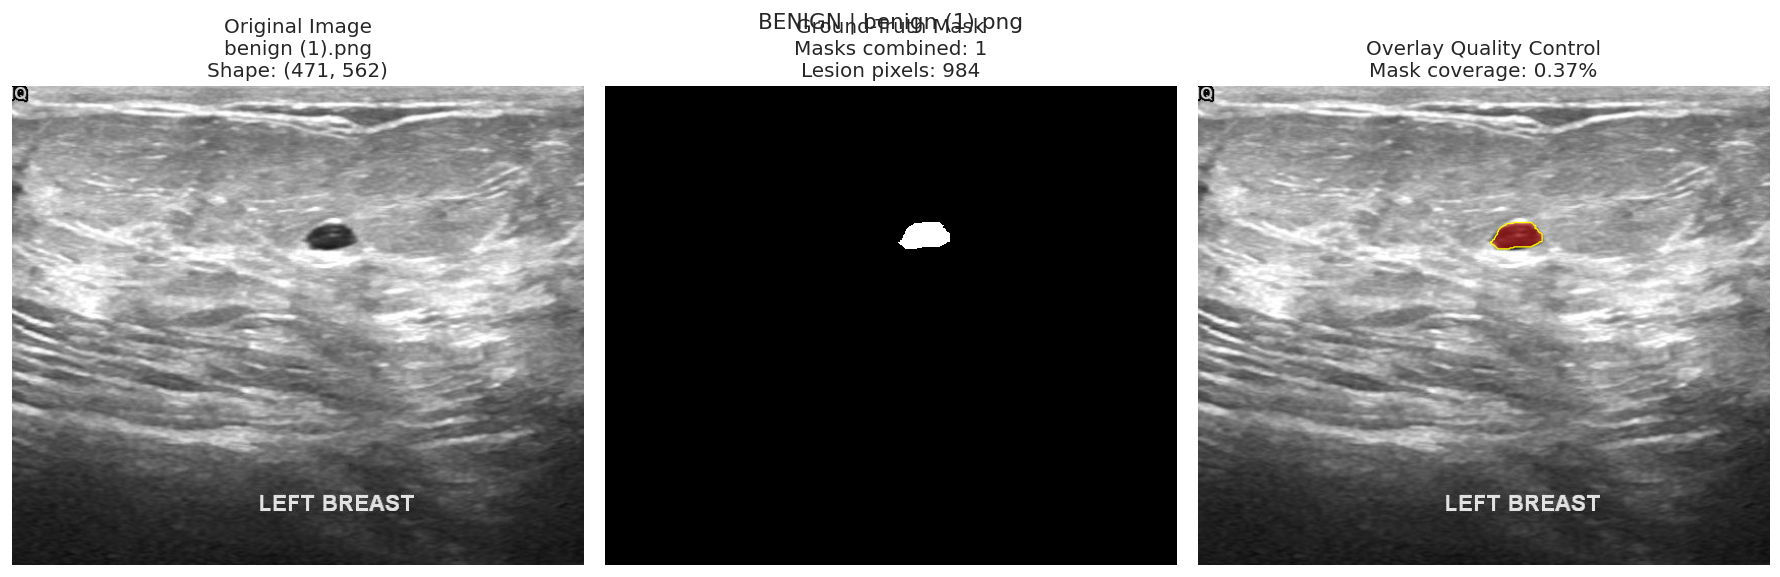

,class_folder,label_code,image_name,image_relative_path,image_shape,image_height,image_width,image_dtype,mask_count,mask_names,mask_status,mask_area_pixels,mask_area_fraction,mask_error
0,benign,B,benign (1).png,benign/benign (1).png,"(471, 562)",471,562,uint8,1,[benign (1)_mask.png],valid,984,0.003717,None


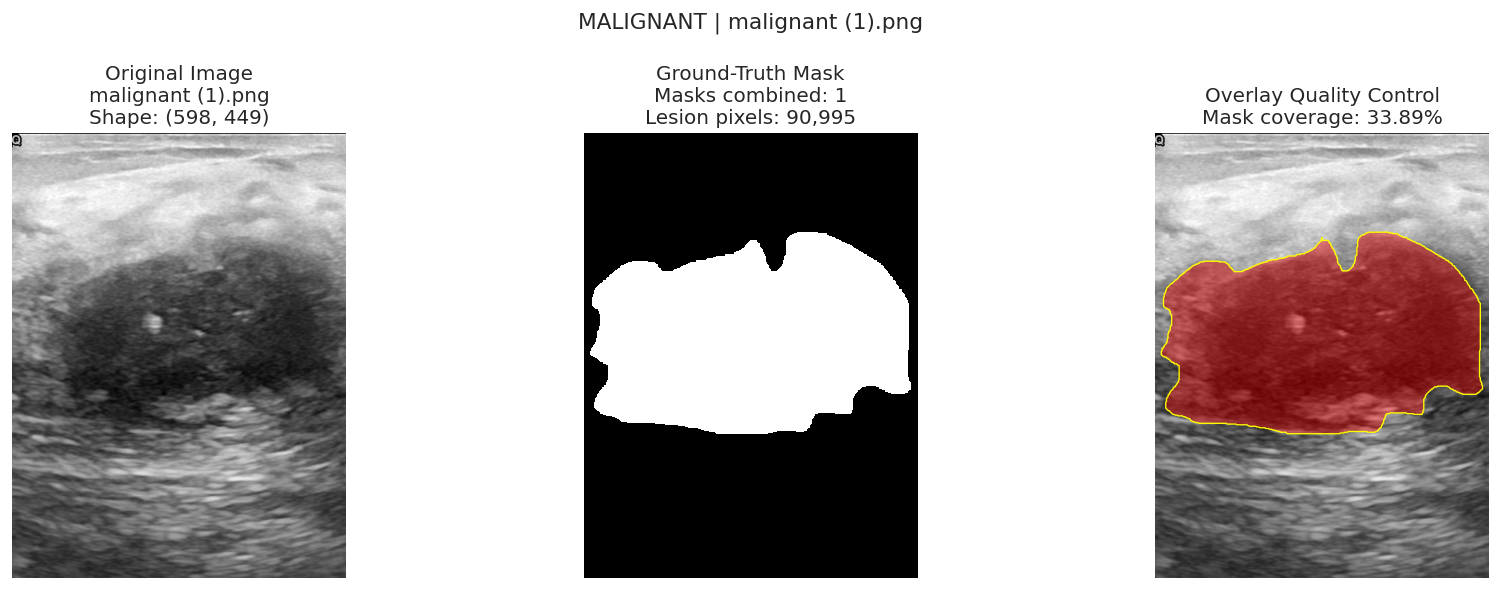

,class_folder,label_code,image_name,image_relative_path,image_shape,image_height,image_width,image_dtype,mask_count,mask_names,mask_status,mask_area_pixels,mask_area_fraction,mask_error
0,malignant,M,malignant (1).png,malignant/malignant (1).png,"(598, 449)",598,449,uint8,1,[malignant (1)_mask.png],valid,90995,0.338899,None



Representative sample validation summary:


,class_folder,image_name,image_shape,mask_count,mask_status,mask_area_pixels,mask_area_fraction
0,benign,benign (1).png,"(471, 562)",1,valid,984,0.003717
1,malignant,malignant (1).png,"(598, 449)",1,valid,90995,0.338899


Representative-sample validation report saved to:
/content/drive/MyDrive/BUSI_paper_reproduction/csv/representative_sample_validation.csv


In [6]:
# ============================================================
# Cell 5 — Image Loading, Mask Validation, and Visualization
#
# Research objectives:
# 1. Load ultrasound images as consistent 8-bit grayscale arrays.
# 2. Load and combine all masks associated with an original image.
# 3. Validate image-mask spatial alignment without silent resizing.
# 4. Detect unreadable, empty, and potentially non-binary masks.
# 5. Visualize the original image, ground-truth mask, and overlay.
# 6. Return structured metadata for downstream feature extraction.
# 7. Export representative-sample validation metadata.
#
# Research integrity:
# - Original dataset files are never modified.
# - Image-mask dimension mismatches are never silently repaired.
# - Multiple masks are combined using binary union.
# - Missing, unreadable, and invalid masks are explicitly reported.
# - The non-zero mask convention is configurable and documented.
# - This cell performs quality control, not dataset-wide relabeling.
# ============================================================


# ------------------------------------------------------------
# 5.1. Imports and Configuration Validation
# ------------------------------------------------------------

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display


# Check that the configuration and pairing utilities from
# the preceding cells are available.
required_objects = [
    "DATASET_DIR",
    "CSV_DIR",
    "CLASS_DIRS",
    "IMAGE_EXTS",
    "image_files_in",
    "masks_for_image",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Required objects are missing: "
        f"{missing_objects}. "
        "Run Cells 2 and 3 before executing Cell 5."
    )


# Normalize configured paths and prepare the reporting directory.
DATASET_DIR = Path(DATASET_DIR)
CSV_DIR = Path(CSV_DIR)

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset directory does not exist: {DATASET_DIR}"
    )

CSV_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not isinstance(CLASS_DIRS, dict) or not CLASS_DIRS:
    raise TypeError(
        "CLASS_DIRS must be a non-empty dictionary mapping "
        "class-folder names to their label codes."
    )

if not IMAGE_EXTS:
    raise ValueError(
        "IMAGE_EXTS must contain the supported image extensions."
    )


# Pixels strictly greater than this value are considered foreground.
#
# For standard BUSI masks encoded as 0 (background) and 255 (lesion),
# a threshold of 0 preserves all non-zero lesion pixels.
#
# Verify this convention if the dataset uses another mask encoding.
MASK_THRESHOLD = 0

# Alpha transparency used to display the foreground region.
MASK_ALPHA = 0.40

# Display settings for grayscale ultrasound images.
GRAYSCALE_VMIN = 0
GRAYSCALE_VMAX = 255


# ------------------------------------------------------------
# 5.2. Load an Ultrasound Image as 8-Bit Grayscale
# ------------------------------------------------------------

def read_gray(path: Path) -> np.ndarray:
    """
    Load an image as an independent 8-bit grayscale NumPy array.

    Parameters
    ----------
    path : Path
        Path to an original ultrasound image.

    Returns
    -------
    np.ndarray
        A two-dimensional uint8 grayscale array.

    Raises
    ------
    FileNotFoundError
        If the source image does not exist.
    ValueError
        If the image cannot be decoded or has an unexpected
        grayscale representation.

    Notes
    -----
    The conversion to grayscale is performed in memory.
    The source image file is never overwritten or modified.
    """

    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            f"Image file not found: {path}"
        )

    try:
        with Image.open(path) as image:
            grayscale = np.array(
                image.convert("L"),
                dtype=np.uint8,
                copy=True
            )

    except Exception as exc:
        raise ValueError(
            f"Unable to decode image '{path}': "
            f"{type(exc).__name__}: {exc}"
        ) from exc

    # Enforce a consistent representation for subsequent processing.
    if grayscale.ndim != 2:
        raise ValueError(
            f"Expected a 2D grayscale image for '{path}', "
            f"but received shape={grayscale.shape}."
        )

    if grayscale.dtype != np.uint8:
        raise ValueError(
            f"Expected uint8 image data for '{path}', "
            f"but received dtype={grayscale.dtype}."
        )

    if grayscale.size == 0:
        raise ValueError(
            f"Decoded image contains no pixels: {path}"
        )

    return grayscale


# ------------------------------------------------------------
# 5.3. Load and Combine Ground-Truth Masks
# ------------------------------------------------------------

def read_mask_union(
    image_path: Path
) -> tuple[np.ndarray | None, list[Path]]:
    """
    Load all masks associated with an original image and combine them
    using a Boolean union.

    Parameters
    ----------
    image_path : Path
        Path to the original ultrasound image.

    Returns
    -------
    tuple[np.ndarray | None, list[Path]]
        union_mask:
            A Boolean array whose True pixels belong to the union
            of all associated masks. Returns None if no mask exists.

        mask_paths:
            The list of mask paths returned by masks_for_image().

    Raises
    ------
    ValueError
        If a matching mask cannot be decoded or if its dimensions
        do not exactly match the original image.

    Important
    ---------
    Masks are not resized or geometrically transformed.
    A mismatch is an explicit validation failure, not a reason
    to silently alter the ground truth.
    """

    image_path = Path(image_path)

    # Use the centralized filename-pairing logic from Cell 3.
    mask_paths = sorted(
        (Path(path) for path in masks_for_image(image_path)),
        key=lambda path: path.as_posix().lower()
    )

    # Distinguish a missing mask from an existing empty mask.
    if not mask_paths:
        return None, []

    # The original image defines the only acceptable spatial shape.
    image_gray = read_gray(image_path)
    expected_shape = image_gray.shape

    # Initialize a Boolean accumulator for all associated masks.
    union_mask = np.zeros(
        expected_shape,
        dtype=bool
    )

    for mask_path in mask_paths:

        if not mask_path.is_file():
            raise ValueError(
                f"Mask file does not exist or is not a regular file: "
                f"{mask_path}"
            )

        try:
            with Image.open(mask_path) as mask_image:
                mask_array = np.array(
                    mask_image.convert("L"),
                    dtype=np.uint8,
                    copy=True
                )

        except Exception as exc:
            raise ValueError(
                f"Unable to decode mask '{mask_path}': "
                f"{type(exc).__name__}: {exc}"
            ) from exc

        # Reject spatial mismatches before performing any Boolean operation.
        if mask_array.ndim != 2:
            raise ValueError(
                f"Expected a 2D grayscale mask for '{mask_path}', "
                f"but received shape={mask_array.shape}."
            )

        if mask_array.shape != expected_shape:
            raise ValueError(
                "Image-mask spatial mismatch detected.\n"
                f"Image: {image_path}\n"
                f"Mask:  {mask_path}\n"
                f"Image shape: {expected_shape}\n"
                f"Mask shape:  {mask_array.shape}\n"
                "No automatic resizing has been performed. "
                "Inspect the original files before continuing."
            )

        # Identify unique grayscale levels for mask quality control.
        unique_values = np.unique(mask_array)

        # More than two intensity levels may indicate a grayscale,
        # anti-aliased, or otherwise non-binary mask.
        #
        # The mask is not discarded automatically. A non-zero
        # threshold is applied consistently, and the warning is
        # retained so that the encoding can be inspected.
        if len(unique_values) > 2:
            warnings.warn(
                f"Mask '{mask_path.name}' contains "
                f"{len(unique_values)} unique grayscale levels: "
                f"{unique_values[:12].tolist()}"
                f"{' ...' if len(unique_values) > 12 else ''}. "
                f"Foreground pixels will be defined as values "
                f"> {MASK_THRESHOLD}. Verify this convention.",
                RuntimeWarning,
                stacklevel=2
            )

        # Convert the grayscale mask to a Boolean foreground mask.
        binary_mask = mask_array > MASK_THRESHOLD

        # Combine all associated masks without losing positive pixels.
        union_mask |= binary_mask

    # Report a mask file that contains no foreground pixels.
    if not union_mask.any():
        warnings.warn(
            f"The union mask for '{image_path.name}' is empty. "
            "Review the source mask files before feature extraction.",
            RuntimeWarning,
            stacklevel=2
        )

    # Flag an unusual mask that covers the entire image.
    elif union_mask.all():
        warnings.warn(
            f"The union mask for '{image_path.name}' covers the "
            "entire image. Verify the mask encoding and pairing.",
            RuntimeWarning,
            stacklevel=2
        )

    return union_mask, mask_paths


# ------------------------------------------------------------
# 5.4. Visualization Helpers
# ------------------------------------------------------------

def _hide_axes(axes) -> None:
    """Remove axis decorations from all supplied Matplotlib axes."""

    for axis in np.ravel(axes):
        axis.axis("off")


def _show_message(
    axis,
    message: str,
    *,
    color: str = "black",
    fontsize: int = 11
) -> None:
    """Display a centered diagnostic message inside an axis."""

    axis.text(
        0.5,
        0.5,
        message,
        transform=axis.transAxes,
        ha="center",
        va="center",
        color=color,
        fontsize=fontsize,
        wrap=True
    )


# ------------------------------------------------------------
# 5.5. Display a Sample, Ground-Truth Mask, and Overlay
# ------------------------------------------------------------

def show_sample(
    folder_name: str,
    index: int = 0
) -> dict:
    """
    Visualize one dataset sample and return auditable metadata.

    The zero-based index refers to the deterministic ordering
    provided by image_files_in().

    Supported outcomes
    ------------------
    valid:
        Matching mask files were read, aligned, and non-empty.

    empty_mask:
        Matching mask files were read, but their union is empty.

    missing_mask:
        No matching mask was found.

    invalid_or_misaligned_mask:
        A matching mask could not be decoded or did not align
        spatially with the original image.

    Returns
    -------
    dict
        Sample-level metadata suitable for a DataFrame and CSV export.
    """

    # Validate the requested class.
    if folder_name not in CLASS_DIRS:
        raise ValueError(
            f"Unknown class folder: {folder_name!r}. "
            f"Expected one of: {list(CLASS_DIRS.keys())}"
        )

    # Reject Boolean values, even though bool is a subclass of int.
    if (
        not isinstance(index, (int, np.integer))
        or isinstance(index, (bool, np.bool_))
        or index < 0
    ):
        raise ValueError(
            "index must be a non-negative integer."
        )

    index = int(index)

    class_folder = DATASET_DIR / folder_name

    if not class_folder.is_dir():
        raise FileNotFoundError(
            f"Class directory does not exist: {class_folder}"
        )

    # Obtain a deterministic list of original images, excluding masks.
    images = sorted(
        (Path(path) for path in image_files_in(class_folder)),
        key=lambda path: path.as_posix().lower()
    )

    if not images:
        raise FileNotFoundError(
            f"No original images were found in: {class_folder}"
        )

    if index >= len(images):
        raise IndexError(
            f"Index {index} is out of range for '{folder_name}'. "
            f"Number of available images: {len(images)}."
        )

    image_path = images[index]
    image_gray = read_gray(image_path)

    # Retrieve the paired masks for reporting.
    mask_paths = sorted(
        (Path(path) for path in masks_for_image(image_path)),
        key=lambda path: path.as_posix().lower()
    )

    # Initialize a consistent metadata schema.
    sample_info = {
        "class_folder": folder_name,
        "label_code": CLASS_DIRS[folder_name],
        "image_name": image_path.name,
        "image_relative_path": image_path.relative_to(
            DATASET_DIR
        ).as_posix(),
        "image_shape": tuple(image_gray.shape),
        "image_height": int(image_gray.shape[0]),
        "image_width": int(image_gray.shape[1]),
        "image_dtype": str(image_gray.dtype),
        "mask_count": int(len(mask_paths)),
        "mask_names": [path.name for path in mask_paths],
        "mask_status": None,
        "mask_area_pixels": None,
        "mask_area_fraction": None,
        "mask_error": None,
    }

    # --------------------------------------------------------
    # Case A: No Matching Mask
    # --------------------------------------------------------

    if not mask_paths:
        sample_info["mask_status"] = "missing_mask"

        fig, axes = plt.subplots(
            1,
            3,
            figsize=(14, 4.5)
        )

        axes[0].imshow(
            image_gray,
            cmap="gray",
            vmin=GRAYSCALE_VMIN,
            vmax=GRAYSCALE_VMAX
        )
        axes[0].set_title("Original Ultrasound Image")

        _show_message(
            axes[1],
            "NO MATCHING MASK",
            color="red"
        )
        axes[1].set_title("Ground-Truth Mask")

        _show_message(
            axes[2],
            "Overlay unavailable",
            color="black"
        )
        axes[2].set_title("Image-Mask Overlay")

        _hide_axes(axes)

        fig.suptitle(
            f"{folder_name.upper()} | {image_path.name}",
            fontsize=12
        )

        fig.tight_layout()
        plt.show()

        print(
            "WARNING: No matching mask was found for "
            f"{sample_info['image_relative_path']}."
        )

        display(pd.DataFrame([sample_info]))

        return sample_info

    # --------------------------------------------------------
    # Case B: Read Masks and Validate Spatial Alignment
    # --------------------------------------------------------

    try:
        union_mask, validated_mask_paths = read_mask_union(
            image_path
        )

    except (ValueError, FileNotFoundError) as exc:

        sample_info["mask_status"] = (
            "invalid_or_misaligned_mask"
        )
        sample_info["mask_error"] = str(exc)

        # Keep the original dimensions of every displayed mask.
        # The figure is diagnostic and does not repair the data.
        n_panels = 2 + len(mask_paths)

        fig, axes = plt.subplots(
            1,
            n_panels,
            figsize=(5 * n_panels, 4.5),
            squeeze=False
        )

        axes = axes.ravel()

        axes[0].imshow(
            image_gray,
            cmap="gray",
            vmin=GRAYSCALE_VMIN,
            vmax=GRAYSCALE_VMAX
        )
        axes[0].set_title(
            f"Original Image\n"
            f"{image_path.name}\n"
            f"Shape: {image_gray.shape}"
        )
        axes[0].axis("off")

        _show_message(
            axes[1],
            "MASK VALIDATION FAILED\n"
            "No automatic resizing performed",
            color="red"
        )
        axes[1].set_title("Validation Status")
        axes[1].axis("off")

        for panel_index, mask_path in enumerate(
            mask_paths,
            start=2
        ):
            try:
                with Image.open(mask_path) as mask_image:
                    mask_array = np.array(
                        mask_image.convert("L"),
                        dtype=np.uint8,
                        copy=True
                    )

                axes[panel_index].imshow(
                    mask_array,
                    cmap="gray",
                    vmin=0,
                    vmax=255
                )

                axes[panel_index].set_title(
                    f"Mask {panel_index - 1}\n"
                    f"{mask_path.name}\n"
                    f"Shape: {mask_array.shape}"
                )

            except Exception as mask_exc:
                _show_message(
                    axes[panel_index],
                    "Unable to read mask\n"
                    f"{type(mask_exc).__name__}: {mask_exc}",
                    color="red",
                    fontsize=9
                )

                axes[panel_index].set_title(
                    mask_path.name
                )

            axes[panel_index].axis("off")

        fig.suptitle(
            f"SPATIAL VALIDATION WARNING | {image_path.name}",
            fontsize=12
        )

        fig.tight_layout()
        plt.show()

        print("Mask validation failed:")
        print(sample_info["mask_error"])

        display(pd.DataFrame([sample_info]))

        return sample_info

    # --------------------------------------------------------
    # Case C: No Mask Returned by the Loader
    # --------------------------------------------------------

    if union_mask is None:
        sample_info["mask_status"] = "missing_mask"

        print(
            "WARNING: The mask loader returned None for "
            f"{image_path.name}."
        )

        display(pd.DataFrame([sample_info]))

        return sample_info

    # Keep the validated path list returned by the loading function.
    # This also ensures the reported count matches the actual union.
    mask_paths = validated_mask_paths
    sample_info["mask_count"] = int(len(mask_paths))
    sample_info["mask_names"] = [
        path.name for path in mask_paths
    ]

    # --------------------------------------------------------
    # 5.6. Calculate Mask-Level Quality-Control Metrics
    # --------------------------------------------------------

    if union_mask.shape != image_gray.shape:
        # Defensive check in case the loader is later modified.
        raise RuntimeError(
            "Internal validation failure: image and union-mask "
            f"shapes differ ({image_gray.shape} vs "
            f"{union_mask.shape})."
        )

    lesion_area = int(np.count_nonzero(union_mask))
    image_area = int(image_gray.size)

    if image_area == 0:
        raise RuntimeError(
            f"Image contains no pixels: {image_path}"
        )

    lesion_area_fraction = lesion_area / image_area

    sample_info["mask_area_pixels"] = lesion_area
    sample_info["mask_area_fraction"] = float(
        lesion_area_fraction
    )

    if lesion_area == 0:
        sample_info["mask_status"] = "empty_mask"
    else:
        sample_info["mask_status"] = "valid"

    # --------------------------------------------------------
    # 5.7. Visualize the Image, Union Mask, and Overlay
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 5)
    )

    # Panel 1: original ultrasound image.
    axes[0].imshow(
        image_gray,
        cmap="gray",
        vmin=GRAYSCALE_VMIN,
        vmax=GRAYSCALE_VMAX
    )

    axes[0].set_title(
        f"Original Image\n"
        f"{image_path.name}\n"
        f"Shape: {image_gray.shape}"
    )

    # Panel 2: binary union of all associated ground-truth masks.
    axes[1].imshow(
        union_mask,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    axes[1].set_title(
        f"Ground-Truth Mask\n"
        f"Masks combined: {len(mask_paths)}\n"
        f"Lesion pixels: {lesion_area:,}"
    )

    # Panel 3: original image with a transparent lesion overlay.
    axes[2].imshow(
        image_gray,
        cmap="gray",
        vmin=GRAYSCALE_VMIN,
        vmax=GRAYSCALE_VMAX
    )

    if lesion_area > 0:

        # Create an RGBA image with a transparent background.
        overlay = np.zeros(
            (*union_mask.shape, 4),
            dtype=np.float32
        )

        # Use red to distinguish lesion pixels from the grayscale image.
        overlay[union_mask] = [
            1.0,
            0.0,
            0.0,
            MASK_ALPHA
        ]

        axes[2].imshow(
            overlay,
            interpolation="nearest"
        )

        # Contours require both foreground and background pixels.
        # This avoids a meaningless contour for a full-image mask.
        if union_mask.any() and (~union_mask).any():
            axes[2].contour(
                union_mask.astype(np.uint8),
                levels=[0.5],
                colors=["yellow"],
                linewidths=0.8
            )

    else:
        _show_message(
            axes[2],
            "EMPTY MASK",
            color="red",
            fontsize=12
        )

    axes[2].set_title(
        "Overlay Quality Control\n"
        f"Mask coverage: {100.0 * lesion_area_fraction:.2f}%"
    )

    _hide_axes(axes)

    fig.suptitle(
        f"{folder_name.upper()} | {image_path.name}",
        fontsize=13
    )

    fig.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 5.8. Report Sample-Level Validation Metadata
    # --------------------------------------------------------

    display(pd.DataFrame([sample_info]))

    if sample_info["mask_status"] == "empty_mask":
        print(
            "WARNING: The mask exists, but the union contains "
            "no foreground pixels."
        )

    elif lesion_area_fraction > 0.95:
        # Very high coverage may be legitimate in some cases, but it
        # should be reviewed before using mask area as a lesion feature.
        print(
            "WARNING: Mask coverage exceeds 95% of the image. "
            "Inspect the mask and its encoding."
        )

    return sample_info


# ------------------------------------------------------------
# 5.9. Inspect Representative Benign and Malignant Samples
# ------------------------------------------------------------

# These are quality-control examples, not a dataset-wide audit.
# Use other zero-based indices to inspect additional samples.

benign_sample_info = show_sample(
    "benign",
    index=0
)

malignant_sample_info = show_sample(
    "malignant",
    index=0
)


# ------------------------------------------------------------
# 5.10. Summarize and Export Representative-Sample Validation
# ------------------------------------------------------------

sample_validation_df = pd.DataFrame(
    [
        benign_sample_info,
        malignant_sample_info
    ]
)

summary_columns = [
    "class_folder",
    "image_name",
    "image_shape",
    "mask_count",
    "mask_status",
    "mask_area_pixels",
    "mask_area_fraction",
]

# Select only columns guaranteed by the metadata schema.
summary_columns = [
    column
    for column in summary_columns
    if column in sample_validation_df.columns
]

print("\nRepresentative sample validation summary:")

display(
    sample_validation_df[summary_columns]
)


# Convert collection-valued fields to JSON strings so they remain
# readable and consistently structured when exported to CSV.
sample_validation_export = sample_validation_df.copy()

for column in ("image_shape", "mask_names"):
    if column in sample_validation_export.columns:
        sample_validation_export[column] = (
            sample_validation_export[column].apply(
                lambda value: json.dumps(
                    value,
                    ensure_ascii=False
                )
                if isinstance(value, (tuple, list))
                else value
            )
        )


sample_validation_path = (
    CSV_DIR / "representative_sample_validation.csv"
)

sample_validation_export.to_csv(
    sample_validation_path,
    index=False,
    encoding="utf-8"
)

print(
    "Representative-sample validation report saved to:\n"
    f"{sample_validation_path}"
)

##Cell 6 — Independent Feature Extraction and Quality Control

In [7]:
# ============================================================
# Cell 6 — Independent Feature Extraction and Quality Control
#
# Research objectives:
# 1. Extract eight raw grayscale histogram features from pixels
#    inside each ground-truth lesion mask.
# 2. Compute normalized histogram ratios for the same eight bins.
# 3. Extract five additional geometric and intensity descriptors.
# 4. Validate histogram, mask-area, and feature invariants.
# 5. Record extraction failures in an auditable issue manifest.
# 6. Save reproducible feature tables and extraction metadata.
#
# Methodological scope:
# Features are computed from ground-truth lesion masks.
# This experiment evaluates classification using pre-segmented
# lesions; it does not perform end-to-end lesion localization
# or segmentation from raw ultrasound images.
#
# Only benign and malignant samples are processed.
# Normal images are excluded because this workflow requires
# a lesion mask and focuses on binary lesion classification.
#
# Label convention:
#   malignant = 0
#   benign    = 1
#
# No original image or mask file is modified.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and Dependency Validation
# ------------------------------------------------------------

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd

from IPython.display import display


# Verify that the required configuration and functions exist.
_REQUIRED_OBJECTS = [
    "DATASET_DIR",
    "CSV_DIR",
    "read_gray",
    "read_mask_union",
    "image_files_in",
]

_missing_objects = [
    name
    for name in _REQUIRED_OBJECTS
    if name not in globals()
]

if _missing_objects:
    raise RuntimeError(
        "Required objects are missing. Run the preceding cells first. "
        f"Missing objects: {_missing_objects}"
    )


# Normalize path objects and initialize the output directory.
DATASET_DIR = Path(DATASET_DIR)
CSV_DIR = Path(CSV_DIR)

if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset directory does not exist: {DATASET_DIR}"
    )

CSV_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Feature Configuration and Label Convention
# ------------------------------------------------------------

# Eight non-overlapping intensity intervals for 8-bit grayscale images.
#
# The bins are:
#   [0, 32), [32, 64), ..., [224, 256)
#
# The final edge is 256 so that intensity 255 is included.
BIN_EDGES = np.array(
    [0, 32, 64, 96, 128, 160, 192, 224, 256],
    dtype=np.int16,
)

# Raw histogram counts.
CH_COLS = [
    f"CH{i}"
    for i in range(1, 9)
]

# Normalized histogram ratios.
C_COLS = [
    f"C{i}"
    for i in range(1, 9)
]

# Backward-compatible aliases for downstream notebook cells.
# These columns duplicate C1-C8 exactly and are not independent features.
CH_NORM_ALIAS_COLS = [
    f"CHf{i}"
    for i in range(1, 9)
]

# Explicit binary classification target mapping.
BINARY_LABELS = {
    "malignant": 0,
    "benign": 1,
}


# The five engineered extension features used by the downstream
# own_CV_extended experiment.
EXTENSION_FEATURE_COLS = [
    "lesion_area_fraction",
    "bbox_aspect_ratio",
    "mask_extent",
    "lesion_mean_intensity",
    "lesion_std_intensity",
]


# Define issue-manifest columns before starting extraction.
ISSUE_COLUMNS = [
    "image",
    "image_relpath",
    "class_folder",
    "issue",
    "error_type",
    "error_message",
]


# Validate the histogram configuration.
if len(BIN_EDGES) != 9:
    raise ValueError(
        "Eight histogram bins require exactly nine bin edges."
    )

if not np.all(np.diff(BIN_EDGES) > 0):
    raise ValueError(
        "Histogram bin edges must be strictly increasing."
    )

if BIN_EDGES[0] != 0 or BIN_EDGES[-1] != 256:
    raise ValueError(
        "The bins must cover the complete uint8 intensity range [0, 255]."
    )

if len(CH_COLS) != 8 or len(C_COLS) != 8:
    raise ValueError(
        "The raw and normalized histogram representations must "
        "each contain exactly eight features."
    )


# Validate the required class directories.
for _class_name in BINARY_LABELS:
    _class_dir = DATASET_DIR / _class_name

    if not _class_dir.is_dir():
        raise FileNotFoundError(
            f"Required class directory does not exist: {_class_dir}"
        )


# ------------------------------------------------------------
# 3. Define Output Paths and Stable Image Identifiers
# ------------------------------------------------------------

FEATURES_OUTPUT_PATH = (
    CSV_DIR / "independently_extracted_features.csv"
)

ISSUES_OUTPUT_PATH = (
    CSV_DIR / "feature_extraction_issues.csv"
)

METADATA_OUTPUT_PATH = (
    CSV_DIR / "feature_extraction_metadata.json"
)


def _relative_image_path(image_path: Path) -> str:
    """
    Return a stable dataset-relative image identifier.

    This identifier distinguishes files within the dataset, but it
    must not be interpreted as a patient identifier.
    """

    image_path = Path(image_path)

    try:
        return image_path.resolve().relative_to(
            DATASET_DIR.resolve()
        ).as_posix()

    except ValueError:
        # Keep the path visible if the image is outside DATASET_DIR.
        return image_path.as_posix()


def _make_issue_record(
    image_path: Path,
    class_folder: str,
    issue: str,
    exception: Exception | None = None,
) -> dict:
    """
    Construct a standardized record for a failed extraction.

    The full image path is retained for diagnosis, while the error
    message is bounded to keep the issue CSV manageable.
    """

    image_path = Path(image_path)

    return {
        "image": str(image_path),
        "image_relpath": _relative_image_path(image_path),
        "class_folder": str(class_folder),
        "issue": str(issue),
        "error_type": (
            type(exception).__name__
            if exception is not None
            else ""
        ),
        "error_message": (
            str(exception)[:1500]
            if exception is not None
            else ""
        ),
    }


def _classify_mask_loading_error(exception: Exception) -> str:
    """
    Categorize mask-loading errors without relying on one exact message.

    The original error message is also stored in the issue manifest.
    """

    message = str(exception).lower()

    if (
        "spatial mismatch" in message
        or (
            "mismatch" in message
            and (
                "shape" in message
                or "dimension" in message
            )
        )
    ):
        return "mask_shape_mismatch"

    if "empty" in message:
        return "empty_mask"

    if (
        "decode" in message
        or "read mask" in message
        or "unable to read" in message
    ):
        return "mask_read_error"

    return "mask_validation_error"


# ------------------------------------------------------------
# 4. Extract Features from One Image
# ------------------------------------------------------------

def extract_one_image(
    image_path: Path,
    class_folder: str,
) -> tuple[dict | None, dict | None]:
    """
    Extract raw histogram, normalized histogram, and extension features.

    Parameters
    ----------
    image_path : Path
        Path to an original ultrasound image, not a mask file.
    class_folder : str
        Expected class name: 'benign' or 'malignant'.

    Returns
    -------
    tuple
        (feature_row, issue_record)

        Successful extraction:
            (feature_row, None)

        Failed extraction:
            (None, issue_record)

    Notes
    -----
    - Image and mask dimensions must match exactly.
    - No automatic mask resizing is performed.
    - Histogram features use foreground pixels only.
    - Empty masks are excluded and explicitly reported.
    - CH1-CH8 contain integer pixel counts.
    - C1-C8 contain counts divided by total mask area.
    """

    image_path = Path(image_path)

    # Validate the requested target class.
    if class_folder not in BINARY_LABELS:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="unsupported_class",
        )

    # --------------------------------------------------------
    # 4.1. Load and validate the grayscale image
    # --------------------------------------------------------

    try:
        gray = np.asarray(
            read_gray(image_path)
        )

    except Exception as exc:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="image_read_error",
            exception=exc,
        )

    # Enforce the expected image representation.
    if gray.ndim != 2:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="invalid_grayscale_dimensions",
        )

    if gray.dtype != np.uint8:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="unexpected_grayscale_dtype",
        )

    if gray.size == 0:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="empty_grayscale_image",
        )

    # --------------------------------------------------------
    # 4.2. Load the union of ground-truth masks
    # --------------------------------------------------------

    try:
        mask, mask_paths = read_mask_union(
            image_path
        )

    except Exception as exc:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue=_classify_mask_loading_error(exc),
            exception=exc,
        )

    # A missing mask makes lesion-specific feature extraction invalid.
    if mask is None or mask_paths is None or len(mask_paths) == 0:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="missing_mask",
        )

    mask_paths = sorted(
        (Path(path) for path in mask_paths),
        key=lambda path: path.as_posix().lower()
    )

    mask_array = np.asarray(mask)

    if mask_array.ndim != 2:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="invalid_mask_dimensions",
        )

    # Do not resize either object to conceal an alignment problem.
    if gray.shape != mask_array.shape:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="mask_shape_mismatch",
            exception=ValueError(
                f"Image shape={gray.shape}; mask shape={mask_array.shape}"
            ),
        )

    # read_mask_union() normally returns a Boolean union mask.
    # This conversion also supports binary numeric masks if necessary.
    mask_binary = mask_array > 0

    mask_area = int(
        np.count_nonzero(mask_binary)
    )

    if mask_area == 0:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="empty_mask",
        )

    # Record a diagnostic warning for an unusually large mask.
    # Such cases are retained rather than silently removed.
    image_area = int(gray.size)

    if mask_area == image_area:
        warnings.warn(
            f"Mask covers the entire image: {image_path.name}. "
            "Review the pairing and mask encoding.",
            RuntimeWarning,
            stacklevel=2,
        )

    # --------------------------------------------------------
    # 4.3. Extract the lesion pixels
    # --------------------------------------------------------

    lesion_pixels = gray[mask_binary]

    if lesion_pixels.size != mask_area:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="lesion_pixel_count_mismatch",
        )

    # --------------------------------------------------------
    # 4.4. Calculate the eight raw histogram features
    # --------------------------------------------------------

    # All lesion pixels should fall into exactly one bin because
    # BIN_EDGES covers the complete uint8 range [0, 255].
    raw_counts, _ = np.histogram(
        lesion_pixels,
        bins=BIN_EDGES,
    )

    raw_counts = raw_counts.astype(
        np.int64,
        copy=False
    )

    histogram_pixel_count = int(
        raw_counts.sum()
    )

    # Invariant 1: the eight raw counts must account for every
    # positive pixel in the ground-truth union mask.
    if histogram_pixel_count != mask_area:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="histogram_pixel_count_mismatch",
            exception=AssertionError(
                f"Histogram sum={histogram_pixel_count}; "
                f"mask area={mask_area}"
            ),
        )

    # --------------------------------------------------------
    # 4.5. Calculate normalized histogram ratios
    # --------------------------------------------------------

    # C_i = CH_i / mask_area_px
    #
    # Each C_i is the proportion of lesion pixels in one intensity bin.
    # The normalized histogram should sum to one.
    ratios = (
        raw_counts.astype(np.float64)
        / float(mask_area)
    )

    ratio_sum = float(
        ratios.sum()
    )

    if not np.isclose(
        ratio_sum,
        1.0,
        rtol=0.0,
        atol=1e-8,
    ):
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="normalized_histogram_sum_mismatch",
            exception=AssertionError(
                f"Normalized histogram sum={ratio_sum}"
            ),
        )

    # --------------------------------------------------------
    # 4.6. Compute extension features
    # --------------------------------------------------------
    # These five descriptors form an additional experiment.
    # They are separate from the original eight-bin histogram baseline.

    ys, xs = np.where(mask_binary)

    if ys.size == 0 or xs.size == 0:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="empty_mask_coordinates",
        )

    # Use an exclusive upper boundary when calculating box dimensions.
    # This preserves single-pixel width and height correctly.
    x_min = int(xs.min())
    x_max_exclusive = int(xs.max()) + 1

    y_min = int(ys.min())
    y_max_exclusive = int(ys.max()) + 1

    bbox_width = x_max_exclusive - x_min
    bbox_height = y_max_exclusive - y_min

    if bbox_width <= 0 or bbox_height <= 0:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="invalid_bounding_box",
        )

    bbox_area = int(
        bbox_width * bbox_height
    )

    if bbox_area < mask_area:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="mask_area_exceeds_bounding_box_area",
        )

    # Geometric descriptors.
    lesion_area_fraction = float(
        mask_area / image_area
    )

    bbox_aspect_ratio = float(
        bbox_width / bbox_height
    )

    mask_extent = float(
        mask_area / bbox_area
    )

    # Intensity descriptors, computed only over lesion pixels.
    # NumPy's default std() uses population standard deviation (ddof=0).
    lesion_mean_intensity = float(
        lesion_pixels.mean()
    )

    lesion_std_intensity = float(
        lesion_pixels.std()
    )

    # Validate the geometric and intensity outputs.
    extension_values = np.array(
        [
            lesion_area_fraction,
            bbox_aspect_ratio,
            mask_extent,
            lesion_mean_intensity,
            lesion_std_intensity,
        ],
        dtype=np.float64,
    )

    if not np.isfinite(extension_values).all():
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="non_finite_extension_feature",
        )

    if not (
        0.0 < lesion_area_fraction <= 1.0
    ):
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="invalid_lesion_area_fraction",
        )

    if not (
        0.0 < mask_extent <= 1.0
    ):
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="invalid_mask_extent",
        )

    if bbox_aspect_ratio <= 0.0:
        return None, _make_issue_record(
            image_path=image_path,
            class_folder=class_folder,
            issue="invalid_bbox_aspect_ratio",
        )

    # --------------------------------------------------------
    # 4.7. Build the feature record
    # --------------------------------------------------------

    row = {
        # Target and image identity.
        "class_folder": class_folder,
        "label": int(BINARY_LABELS[class_folder]),
        "image_name": image_path.name,
        "image_relpath": _relative_image_path(image_path),

        # Mask provenance.
        "mask_names": "|".join(
            path.name for path in mask_paths
        ),
        "num_masks_union": int(len(mask_paths)),

        # Image dimensions and area.
        "image_height": int(gray.shape[0]),
        "image_width": int(gray.shape[1]),
        "image_area_px": image_area,

        # Ground-truth mask geometry.
        "mask_area_px": mask_area,
        "lesion_area_fraction": lesion_area_fraction,
        "bbox_width_px": int(bbox_width),
        "bbox_height_px": int(bbox_height),
        "bbox_aspect_ratio": bbox_aspect_ratio,
        "mask_extent": mask_extent,

        # Lesion-region grayscale statistics.
        "lesion_mean_intensity": lesion_mean_intensity,
        "lesion_std_intensity": lesion_std_intensity,

        # Audit fields for mathematical validation.
        "sum_CH_raw": histogram_pixel_count,
        "sum_C_ratio": ratio_sum,
        "mask_area_matches_histogram": bool(
            histogram_pixel_count == mask_area
        ),
        "normalized_histogram_sums_to_one": bool(
            np.isclose(
                ratio_sum,
                1.0,
                rtol=0.0,
                atol=1e-8,
            )
        ),
    }

    # Store raw histogram counts as integer-valued features.
    row.update({
        column: int(value)
        for column, value in zip(
            CH_COLS,
            raw_counts
        )
    })

    # Store normalized histogram proportions.
    row.update({
        column: float(value)
        for column, value in zip(
            C_COLS,
            ratios
        )
    })

    # Preserve compatibility columns required by earlier notebook code.
    # These aliases duplicate C1-C8 exactly.
    row.update({
        column: float(value)
        for column, value in zip(
            CH_NORM_ALIAS_COLS,
            ratios
        )
    })

    return row, None


# ------------------------------------------------------------
# 5. Extract Features from All Benign and Malignant Images
# ------------------------------------------------------------

extracted_rows = []
extraction_issues = []

for class_folder in BINARY_LABELS:

    class_dir = DATASET_DIR / class_folder

    # Use the image enumeration function from Cell 3 and enforce
    # deterministic ordering for reproducibility.
    try:
        image_paths = [
            Path(path)
            for path in image_files_in(class_dir)
        ]

    except Exception as exc:
        extraction_issues.append(
            _make_issue_record(
                image_path=class_dir,
                class_folder=class_folder,
                issue="class_image_inventory_error",
                exception=exc,
            )
        )

        print(
            f"WARNING: Unable to enumerate images in {class_dir}: "
            f"{type(exc).__name__}: {exc}"
        )
        continue

    image_paths = sorted(
        image_paths,
        key=lambda path: path.as_posix().lower()
    )

    # Report duplicate enumeration separately instead of silently
    # counting the same path more than once.
    path_strings = [
        _relative_image_path(path)
        for path in image_paths
    ]

    duplicate_paths = sorted({
        path_string
        for path_string in path_strings
        if path_strings.count(path_string) > 1
    })

    if duplicate_paths:
        raise RuntimeError(
            f"Duplicate image paths were returned for class "
            f"'{class_folder}': {duplicate_paths[:10]}. "
            "Inspect image_files_in() before extraction."
        )

    print(
        f"Processing class '{class_folder}': "
        f"{len(image_paths)} candidate image(s)"
    )

    for image_path in image_paths:
        try:
            row, issue = extract_one_image(
                image_path=image_path,
                class_folder=class_folder,
            )

            if row is not None:
                extracted_rows.append(row)

            if issue is not None:
                extraction_issues.append(issue)

        except Exception as exc:
            # Keep an unexpected sample-level error visible in the
            # manifest while allowing other samples to be processed.
            extraction_issues.append(
                _make_issue_record(
                    image_path=image_path,
                    class_folder=class_folder,
                    issue="unexpected_extraction_error",
                    exception=exc,
                )
            )


# ------------------------------------------------------------
# 6. Construct Deterministic Feature and Issue Tables
# ------------------------------------------------------------

# Define an explicit column order so the schema remains stable even
# when some or all samples fail during an extraction run.
FEATURE_COLUMNS = [
    "class_folder",
    "label",
    "image_name",
    "image_relpath",
    "mask_names",
    "num_masks_union",
    "image_height",
    "image_width",
    "image_area_px",
    "mask_area_px",
    "lesion_area_fraction",
    "bbox_width_px",
    "bbox_height_px",
    "bbox_aspect_ratio",
    "mask_extent",
    "lesion_mean_intensity",
    "lesion_std_intensity",
    "sum_CH_raw",
    "sum_C_ratio",
    "mask_area_matches_histogram",
    "normalized_histogram_sums_to_one",
    *CH_COLS,
    *C_COLS,
    *CH_NORM_ALIAS_COLS,
]

own_df = pd.DataFrame(
    extracted_rows,
    columns=FEATURE_COLUMNS,
)

if not own_df.empty:
    own_df = (
        own_df
        .sort_values(
            ["class_folder", "image_relpath"],
            kind="stable",
        )
        .reset_index(drop=True)
    )

issues_df = pd.DataFrame(
    extraction_issues,
    columns=ISSUE_COLUMNS,
)


# ------------------------------------------------------------
# 7. Persist Outputs Before Final Integrity Assertions
# ------------------------------------------------------------

# Save a feature table and issue manifest even if the current run
# extracts no samples. This makes failed runs diagnosable.
own_df.to_csv(
    FEATURES_OUTPUT_PATH,
    index=False,
    encoding="utf-8",
)

issues_df.to_csv(
    ISSUES_OUTPUT_PATH,
    index=False,
    encoding="utf-8",
)


# ------------------------------------------------------------
# 8. Create Reproducibility Metadata
# ------------------------------------------------------------

metadata = {
    "feature_extraction_version": "1.1",
    "dataset_directory": str(DATASET_DIR),
    "processed_classes": list(BINARY_LABELS.keys()),
    "binary_label_mapping": BINARY_LABELS,
    "n_successfully_extracted": int(len(own_df)),
    "n_recorded_issues": int(len(issues_df)),
    "histogram": {
        "pixel_source": "ground_truth_mask_foreground_only",
        "grayscale_dtype": "uint8",
        "bin_edges": BIN_EDGES.tolist(),
        "n_bins": 8,
        "raw_feature_columns": CH_COLS,
        "normalized_feature_columns": C_COLS,
        "compatibility_alias_columns": CH_NORM_ALIAS_COLS,
        "raw_histogram_definition": (
            "CH_i is the number of foreground-mask pixels whose "
            "grayscale intensity falls in bin i."
        ),
        "normalized_histogram_definition": (
            "C_i = CH_i / mask_area_px. "
            "The sum of C1-C8 should equal one."
        ),
        "alias_definition": (
            "CHf1-CHf8 are exact duplicates of C1-C8. "
            "They are retained for notebook compatibility, not as "
            "additional independent predictors."
        ),
    },
    "extension_features": {
        "columns": EXTENSION_FEATURE_COLS,
        "description": (
            "Five additional geometric and intensity descriptors. "
            "This extension is separate from the eight-feature "
            "histogram baseline."
        ),
        "intensity_standard_deviation": (
            "Population standard deviation, computed using NumPy "
            "with ddof=0."
        ),
    },
    "mask_handling": {
        "mask_source": "read_mask_union",
        "combination_method": "binary_union",
        "automatic_resizing": False,
        "empty_masks": "excluded_and_recorded",
        "missing_masks": "excluded_and_recorded",
        "mismatched_dimensions": "excluded_and_recorded",
    },
    "methodological_notes": [
        (
            "Features are derived using ground-truth masks; this is "
            "not an end-to-end raw-image lesion detection experiment."
        ),
        (
            "Only benign and malignant image folders are processed."
        ),
        (
            "Image-relative paths identify files, not patients."
        ),
        (
            "Raw counts and normalized ratios represent two "
            "representations of the same histogram information."
        ),
        (
            "The five extension features are not part of the "
            "eight-feature histogram baseline."
        ),
    ],
    "output_files": {
        "features": FEATURES_OUTPUT_PATH.name,
        "issues": ISSUES_OUTPUT_PATH.name,
    },
}

with open(
    METADATA_OUTPUT_PATH,
    "w",
    encoding="utf-8"
) as metadata_file:
    json.dump(
        metadata,
        metadata_file,
        indent=2,
        ensure_ascii=False,
    )


# ------------------------------------------------------------
# 9. Report Extraction Outcomes
# ------------------------------------------------------------

print("\n" + "=" * 68)
print("INDEPENDENT FEATURE EXTRACTION SUMMARY")
print("=" * 68)

print(f"Successfully extracted images: {len(own_df)}")
print(f"Images with recorded issues:   {len(issues_df)}")
print(f"Feature table:                 {FEATURES_OUTPUT_PATH}")
print(f"Issue manifest:                {ISSUES_OUTPUT_PATH}")
print(f"Extraction metadata:            {METADATA_OUTPUT_PATH}")


# Provide a short failure summary for auditability.
if not issues_df.empty:
    print("\nIssue counts by type:")

    issue_summary = (
        issues_df
        .groupby(
            ["class_folder", "issue"],
            dropna=False
        )
        .size()
        .reset_index(name="count")
        .sort_values(
            ["class_folder", "count", "issue"],
            ascending=[True, False, True],
            kind="stable",
        )
        .reset_index(drop=True)
    )

    display(issue_summary)

    print("\nFirst 20 detailed issues:")
    display(
        issues_df.head(20)
    )

if own_df.empty:
    raise RuntimeError(
        "No feature rows were successfully extracted. "
        "Inspect feature_extraction_issues.csv and verify the "
        "dataset paths, image-mask pairing, and mask dimensions."
    )


# ------------------------------------------------------------
# 10. Validate Sample Identity and Target Labels
# ------------------------------------------------------------

# Image-relative identifiers must uniquely identify rows in this table.
if own_df["image_relpath"].isna().any():
    raise AssertionError(
        "Missing image-relative identifiers were found."
    )

if own_df["image_relpath"].astype(str).str.strip().eq("").any():
    raise AssertionError(
        "Empty image-relative identifiers were found."
    )

if own_df["image_relpath"].duplicated().any():
    duplicate_ids = (
        own_df.loc[
            own_df["image_relpath"].duplicated(keep=False),
            "image_relpath"
        ]
        .tolist()
    )

    raise AssertionError(
        "Duplicate image-relative identifiers were detected: "
        f"{duplicate_ids[:10]}"
    )

# Verify the target label using the class-folder name.
expected_labels = (
    own_df["class_folder"]
    .map(BINARY_LABELS)
)

if expected_labels.isna().any():
    raise AssertionError(
        "Unexpected class-folder values were found in own_df."
    )

if not np.array_equal(
    own_df["label"].to_numpy(dtype=np.int64),
    expected_labels.to_numpy(dtype=np.int64),
):
    raise AssertionError(
        "The recorded target labels disagree with the class-folder "
        "mapping. Expected malignant=0 and benign=1."
    )


# Report the number of successful samples in each class.
class_counts = (
    own_df["class_folder"]
    .value_counts()
    .reindex(
        list(BINARY_LABELS.keys()),
        fill_value=0,
    )
    .rename_axis("class")
    .reset_index(name="n_images")
)

print("\nSuccessfully extracted samples by class:")
display(class_counts)


# ------------------------------------------------------------
# 11. Validate Raw Histogram Counts and Mask Areas
# ------------------------------------------------------------

raw_histogram_values = own_df[
    CH_COLS
].to_numpy(dtype=np.float64)

mask_areas = pd.to_numeric(
    own_df["mask_area_px"],
    errors="coerce",
).to_numpy(dtype=np.float64)

if not np.isfinite(raw_histogram_values).all():
    raise AssertionError(
        "Non-finite raw histogram values were detected."
    )

if not np.isfinite(mask_areas).all():
    raise AssertionError(
        "Non-finite mask areas were detected."
    )

if np.any(raw_histogram_values < 0):
    raise AssertionError(
        "Negative raw histogram counts were detected."
    )

if np.any(mask_areas <= 0):
    raise AssertionError(
        "Every retained sample must have a strictly positive mask area."
    )

# All raw histogram features must be integer-valued pixel counts.
if not np.allclose(
    raw_histogram_values,
    np.round(raw_histogram_values),
    rtol=0.0,
    atol=0.0,
):
    raise AssertionError(
        "Raw histogram features contain non-integer values."
    )

# Fundamental invariant: sum_i CH_i = mask_area_px.
raw_histogram_sums = raw_histogram_values.sum(axis=1)

raw_histogram_matches_mask = np.array_equal(
    raw_histogram_sums.astype(np.int64),
    mask_areas.astype(np.int64),
)

if not raw_histogram_matches_mask:
    raise AssertionError(
        "At least one raw histogram does not sum to its mask area."
    )


# ------------------------------------------------------------
# 12. Validate Normalized Histograms and Compatibility Aliases
# ------------------------------------------------------------

ratio_histogram_values = own_df[
    C_COLS
].to_numpy(dtype=np.float64)

alias_histogram_values = own_df[
    CH_NORM_ALIAS_COLS
].to_numpy(dtype=np.float64)

if not np.isfinite(ratio_histogram_values).all():
    raise AssertionError(
        "Non-finite normalized histogram values were detected."
    )

if np.any(ratio_histogram_values < 0):
    raise AssertionError(
        "Negative normalized histogram values were detected."
    )

# Invariant: normalized histogram ratios must sum to one.
ratio_histogram_sums = ratio_histogram_values.sum(axis=1)

normalized_histograms_sum_to_one = np.allclose(
    ratio_histogram_sums,
    1.0,
    rtol=0.0,
    atol=1e-8,
)

if not normalized_histograms_sum_to_one:
    raise AssertionError(
        "At least one normalized histogram does not sum to one."
    )

# Invariant: C_i = CH_i / mask_area_px.
expected_ratios = (
    raw_histogram_values
    / mask_areas[:, np.newaxis]
)

if not np.allclose(
    expected_ratios,
    ratio_histogram_values,
    rtol=1e-10,
    atol=1e-12,
):
    raise AssertionError(
        "Normalized ratios do not match raw histogram counts divided "
        "by mask area."
    )

# Compatibility aliases must be identical to the normalized ratios.
alias_max_absolute_difference = float(
    np.max(
        np.abs(
            ratio_histogram_values
            - alias_histogram_values
        )
    )
)

if not np.allclose(
    ratio_histogram_values,
    alias_histogram_values,
    rtol=0.0,
    atol=0.0,
):
    raise AssertionError(
        "CHf1-CHf8 are not exact aliases of C1-C8."
    )


# ------------------------------------------------------------
# 13. Validate the Five Extension Features
# ------------------------------------------------------------

extension_values = own_df[
    EXTENSION_FEATURE_COLS
].to_numpy(dtype=np.float64)

if not np.isfinite(extension_values).all():
    raise AssertionError(
        "Non-finite values were found in the extension features."
    )

# Lesion area fraction must lie in (0, 1].
if not (
    (
        own_df["lesion_area_fraction"] > 0
    )
    & (
        own_df["lesion_area_fraction"] <= 1
    )
).all():
    raise AssertionError(
        "Invalid lesion_area_fraction values were detected."
    )

# The axis-aligned bounding-box aspect ratio must be strictly positive.
if not (
    own_df["bbox_aspect_ratio"] > 0
).all():
    raise AssertionError(
        "Invalid bbox_aspect_ratio values were detected."
    )

# Mask extent is mask area divided by bounding-box area.
if not (
    (
        own_df["mask_extent"] > 0
    )
    & (
        own_df["mask_extent"] <= 1
    )
).all():
    raise AssertionError(
        "Invalid mask_extent values were detected."
    )


# ------------------------------------------------------------
# 14. Display the Core Integrity Report
# ------------------------------------------------------------

max_ratio_sum_error = float(
    np.max(
        np.abs(
            ratio_histogram_sums - 1.0
        )
    )
)

print("\n" + "=" * 68)
print("FEATURE INTEGRITY VALIDATION")
print("=" * 68)

print(
    "Raw histogram sums equal mask area:          PASS"
    if raw_histogram_matches_mask
    else
    "Raw histogram sums equal mask area:          FAIL"
)

print(
    "Normalized histograms sum to one:             PASS"
    if normalized_histograms_sum_to_one
    else
    "Normalized histograms sum to one:             FAIL"
)

print(
    "C_i equals CH_i / mask_area_px:               PASS"
)

print(
    "CHf aliases equal C features exactly:         PASS"
)

print(
    "Extension features are finite and valid:      PASS"
)

print(
    "Maximum normalized-histogram sum error:       "
    f"{max_ratio_sum_error:.12g}"
)

print(
    "Maximum CHf-versus-C absolute difference:      "
    f"{alias_max_absolute_difference:.12g}"
)


# Display a concise view of representative rows.
preview_columns = [
    "class_folder",
    "label",
    "image_name",
    "mask_area_px",
    "sum_CH_raw",
    "sum_C_ratio",
    "lesion_area_fraction",
    "lesion_mean_intensity",
    "lesion_std_intensity",
]

print("\nRepresentative extracted records:")

display(
    own_df[preview_columns].head(10)
)


# ------------------------------------------------------------
# 15. Final Output Confirmation
# ------------------------------------------------------------

print("\nSaved output files:")
print(f"1. Feature table: {FEATURES_OUTPUT_PATH}")
print(f"2. Issue manifest: {ISSUES_OUTPUT_PATH}")
print(f"3. Metadata: {METADATA_OUTPUT_PATH}")

print(
    "\nCell 6 completed. "
    "The extracted feature table is available as `own_df`."
)

# ------------------------------------------------------------
# 16. Reproducible Feature-Table Fingerprint and Scope Declaration
# ------------------------------------------------------------
# The SHA-256 value helps detect changes to the extracted table between runs.
# It does not prove numerical correspondence to the authors' MATLAB features.

import hashlib as _hashlib_cell6

if own_df["image_relpath"].astype(str).duplicated().any():
    _dup_paths = own_df.loc[
        own_df["image_relpath"].astype(str).duplicated(keep=False),
        "image_relpath",
    ].astype(str).tolist()
    raise AssertionError(
        "Feature extraction contains duplicate image IDs. Resolve them before modeling: "
        f"{_dup_paths[:10]}"
    )

_FEATURE_TABLE_BYTES = own_df.to_csv(
    index=False, lineterminator="\n", float_format="%.17g"
).encode("utf-8")
FEATURE_TABLE_SHA256 = _hashlib_cell6.sha256(_FEATURE_TABLE_BYTES).hexdigest()
FEATURE_PROVENANCE_MANIFEST = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "feature_table_path": str(FEATURES_OUTPUT_PATH),
    "feature_table_sha256_in_memory_serialization": FEATURE_TABLE_SHA256,
    "n_samples": int(len(own_df)),
    "n_features_CH_raw": int(len(CH_COLS)),
    "n_features_C_ratio": int(len(C_COLS)),
    "n_features_extension": int(len(EXTENSION_FEATURE_COLS)),
    "feature_source": "ultrasound grayscale pixels within ground-truth lesion masks",
    "task_scope": "binary classification of pre-segmented lesions; not end-to-end image detection",
    "label_mapping": BINARY_LABELS.copy(),
    "raw_histogram_counts_sum_to_mask_area": bool(raw_histogram_matches_mask),
    "normalized_histograms_sum_to_one": bool(normalized_histograms_sum_to_one),
    "exact_numeric_correspondence_to_authors_MATLAB_output_verified": False,
}
FEATURE_PROVENANCE_PATH = CSV_DIR / "feature_provenance_cell6.json"
with FEATURE_PROVENANCE_PATH.open("w", encoding="utf-8") as _feature_manifest_file:
    json.dump(FEATURE_PROVENANCE_MANIFEST, _feature_manifest_file, ensure_ascii=False, indent=2, default=str)

print(f"Feature table SHA-256 (serialized in-memory table): {FEATURE_TABLE_SHA256}")
print(f"Feature provenance manifest: {FEATURE_PROVENANCE_PATH}")


Processing class 'malignant': 210 candidate image(s)
Processing class 'benign': 437 candidate image(s)

INDEPENDENT FEATURE EXTRACTION SUMMARY
Successfully extracted images: 647
Images with recorded issues:   0
Feature table:                 /content/drive/MyDrive/BUSI_paper_reproduction/csv/independently_extracted_features.csv
Issue manifest:                /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_extraction_issues.csv
Extraction metadata:            /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_extraction_metadata.json

Successfully extracted samples by class:


,class,n_images
0,malignant,210
1,benign,437



FEATURE INTEGRITY VALIDATION
Raw histogram sums equal mask area:          PASS
Normalized histograms sum to one:             PASS
C_i equals CH_i / mask_area_px:               PASS
CHf aliases equal C features exactly:         PASS
Extension features are finite and valid:      PASS
Maximum normalized-histogram sum error:       2.22044604925e-16
Maximum CHf-versus-C absolute difference:      0

Representative extracted records:


,class_folder,label,image_name,mask_area_px,sum_CH_raw,sum_C_ratio,lesion_area_fraction,lesion_mean_intensity,lesion_std_intensity
0,benign,1,benign (1).png,984,984,1.0,0.003717,73.695122,37.521329
1,benign,1,benign (10).png,32918,32918,1.0,0.082387,9.815025,19.644558
2,benign,1,benign (100).png,10011,10011,1.0,0.065526,68.890820,36.086935
3,benign,1,benign (101).png,4167,4167,1.0,0.015648,70.040077,30.824695
4,benign,1,benign (102).png,18857,18857,1.0,0.048759,14.296283,16.367718
5,benign,1,benign (103).png,49587,49587,1.0,0.110658,13.466211,17.477096
6,benign,1,benign (104).png,3930,3930,1.0,0.008751,76.164122,42.032827
7,benign,1,benign (105).png,8813,8813,1.0,0.017198,34.217066,33.823877
8,benign,1,benign (106).png,11670,11670,1.0,0.020172,36.855356,21.735186
9,benign,1,benign (107).png,9871,9871,1.0,0.021112,51.662040,26.130104



Saved output files:
1. Feature table: /content/drive/MyDrive/BUSI_paper_reproduction/csv/independently_extracted_features.csv
2. Issue manifest: /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_extraction_issues.csv
3. Metadata: /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_extraction_metadata.json

Cell 6 completed. The extracted feature table is available as `own_df`.
Feature table SHA-256 (serialized in-memory table): 9a9898e7aae8802494f982d68b4f3c0f3cb25be687b4a1aae5b1f2d7f25223d0
Feature provenance manifest: /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_provenance_cell6.json


Cell 6B — Feature-Definition Reconciliation

In [8]:
# ============================================================
# CELL 6B — FEATURE-DEFINITION RECONCILIATION AUDIT
# ============================================================
# Purpose:
#   1. Independently recompute histogram-bin counts from the original image
#      and its ground-truth mask, without altering the existing feature table.
#   2. Verify the current implementation of CH_i and C_i.
#   3. Quantify alternative normalizations that help expose the paper's
#      equation/pseudocode ambiguity.
#   4. Keep the equation-based interpretation separate from the pseudocode
#      interpretation; do not silently choose a formula to force agreement.
#   5. Save row-level and bin-level diagnostics for reproducibility.
#
# Placement:
#   Run immediately after Cell 6 (Independent Feature Extraction) and before Cell 7.
#
# Methodological boundary:
#   This is a read-only audit. It does not overwrite own_df, CH_i, C_i,
#   authors_CH, authors_C, or any model inputs.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Validate required feature-extraction outputs
# ------------------------------------------------------------

_REQUIRED_GLOBALS = [
    "own_df",
    "DATASET_DIR",
    "CSV_DIR",
    "BIN_EDGES",
    "CH_COLS",
    "C_COLS",
    "read_gray",
    "read_mask_union",
]
_missing = [name for name in _REQUIRED_GLOBALS if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run Cells 2–6 successfully before Cell 6B. Missing objects: "
        f"{_missing}"
    )

if not isinstance(own_df, pd.DataFrame) or own_df.empty:
    raise ValueError("own_df must be a non-empty feature table from Cell 6.")

DATASET_DIR = Path(DATASET_DIR).resolve()
CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(parents=True, exist_ok=True)

CH_COLS = list(CH_COLS)
C_COLS = list(C_COLS)
BIN_EDGES = np.asarray(BIN_EDGES, dtype=np.int64)

if len(CH_COLS) != 8 or len(C_COLS) != 8 or len(BIN_EDGES) != 9:
    raise ValueError(
        "The audit expects eight CH_i features, eight C_i features, "
        "and nine bin edges."
    )

_REQUIRED_COLUMNS = {
    "image_relpath",
    "class_folder",
    "label",
    "mask_area_px",
    "image_area_px",
    *CH_COLS,
    *C_COLS,
}
_missing_columns = sorted(_REQUIRED_COLUMNS - set(own_df.columns))
if _missing_columns:
    raise KeyError(f"own_df is missing required columns: {_missing_columns}")

if not np.array_equal(
    BIN_EDGES,
    np.array([0, 32, 64, 96, 128, 160, 192, 224, 256]),
):
    raise ValueError(
        "Cell 6B expects the documented eight 32-level uint8 bins. "
        f"Detected edges: {BIN_EDGES.tolist()}"
    )


# ------------------------------------------------------------
# 2. Declare the interpretations being compared
# ------------------------------------------------------------

# Interpretation A — Current independent implementation:
#   CH_i = number of ground-truth-mask pixels in intensity bin i
#   C_i  = CH_i / mask_area_px
#   Sum(C_i) = 1
#
# Interpretation B — A possible full-image histogram normalization:
#   CH_i / image_area_px
# This is a diagnostic alternative, not asserted to be the authors' formula.
#
# Interpretation C — A possible literal reading of the algorithm pseudocode:
#   sum(grayscale intensities in bin i) / mask_area_px
# These eight values sum to the lesion's mean grayscale intensity, not 1.
# This is computed only to demonstrate how materially different the
# intensity-sum reading is; it is not substituted into the classifier.

_EQUATION_INTERPRETATION = (
    "The paper gives C_i = area(CH_i) / areaGT. If area(CH_i) means the "
    "number of ground-truth lesion pixels assigned to intensity bin i, the "
    "current count/mask-area ratio is compatible with Equation (4)."
)
_PSEUDOCODE_CAVEAT = (
    "The algorithm pseudocode also mentions sum(sum(ROI(:))) / S in a way "
    "that may be read as summing grayscale intensity values after binning. "
    "The article does not define that operation consistently enough to prove "
    "that it is numerically equivalent to Equation (4). The alternative below "
    "is diagnostic only and is not claimed to reproduce the authors' MATLAB code."
)


# ------------------------------------------------------------
# 3. Recompute each sample directly from its source image and mask
# ------------------------------------------------------------

_bin_audit_rows = []
_sample_audit_rows = []
_failure_rows = []

# Use only binary lesion classes, consistent with the independent extraction.
_audit_df = own_df.loc[
    own_df["class_folder"].astype(str).str.lower().isin(["benign", "malignant"])
].copy()

if _audit_df.empty:
    raise ValueError("No benign/malignant rows are available in own_df.")

if _audit_df["image_relpath"].astype(str).duplicated().any():
    _duplicates = _audit_df.loc[
        _audit_df["image_relpath"].astype(str).duplicated(keep=False),
        "image_relpath",
    ].astype(str).tolist()
    raise ValueError(
        "Duplicate image_relpath values occur in own_df: "
        f"{_duplicates[:10]}"
    )

for _row_index, _row in _audit_df.iterrows():
    _sample_id = str(_row["image_relpath"]).replace("\\", "/").strip()
    _image_path = (DATASET_DIR / _sample_id).resolve()

    try:
        # Guard against malformed IDs that resolve outside the dataset root.
        _image_path.relative_to(DATASET_DIR)
        if not _image_path.is_file():
            raise FileNotFoundError(f"Source image not found: {_image_path}")

        _gray = np.asarray(read_gray(_image_path))
        _mask, _mask_paths = read_mask_union(_image_path)
        _mask_array = np.asarray(_mask)

        if _gray.ndim != 2 or _gray.dtype != np.uint8:
            raise ValueError(
                f"Expected uint8 grayscale image; shape={_gray.shape}, dtype={_gray.dtype}"
            )
        if _mask_array.ndim != 2 or _mask_array.shape != _gray.shape:
            raise ValueError(
                f"Image/mask shape mismatch: image={_gray.shape}, mask={_mask_array.shape}"
            )

        _mask_bool = _mask_array > 0
        _mask_area = int(np.count_nonzero(_mask_bool))
        _image_area = int(_gray.size)

        if _mask_area <= 0:
            raise ValueError("The union mask is empty.")
        if _image_area <= 0:
            raise ValueError("The image contains no pixels.")

        _lesion_pixels = _gray[_mask_bool]
        _counts, _ = np.histogram(_lesion_pixels, bins=BIN_EDGES)
        _counts = _counts.astype(np.int64, copy=False)

        if int(_counts.sum()) != _mask_area:
            raise AssertionError(
                f"Recomputed histogram sum={int(_counts.sum())}; mask area={_mask_area}"
            )

        _observed_ch = pd.to_numeric(
            _row[CH_COLS], errors="raise"
        ).to_numpy(dtype=np.float64)
        _observed_c = pd.to_numeric(
            _row[C_COLS], errors="raise"
        ).to_numpy(dtype=np.float64)

        _expected_c = _counts.astype(np.float64) / float(_mask_area)
        _whole_image_fraction = _counts.astype(np.float64) / float(_image_area)

        # A diagnostic alternative inspired by the pseudocode's mention of ROI intensity sums.
        _intensity_sums = np.array([
            float(_lesion_pixels[
                (_lesion_pixels >= _lower) & (_lesion_pixels < _upper)
            ].astype(np.float64).sum())
            for _lower, _upper in zip(BIN_EDGES[:-1], BIN_EDGES[1:])
        ])
        _intensity_sum_over_mask_area = _intensity_sums / float(_mask_area)

        _ch_match = bool(np.array_equal(
            _observed_ch.astype(np.int64), _counts
        ))
        _c_match = bool(np.allclose(
            _observed_c, _expected_c, rtol=1e-10, atol=1e-12
        ))
        _stored_mask_area = int(float(_row["mask_area_px"]))
        _stored_image_area = int(float(_row["image_area_px"]))
        _mask_area_match = bool(_stored_mask_area == _mask_area)
        _image_area_match = bool(_stored_image_area == _image_area)

        _sample_audit_rows.append({
            "sample_id": _sample_id,
            "class_folder": str(_row["class_folder"]),
            "label": int(_row["label"]),
            "stored_mask_area_px": _stored_mask_area,
            "recomputed_mask_area_px": _mask_area,
            "mask_area_match": _mask_area_match,
            "stored_image_area_px": _stored_image_area,
            "recomputed_image_area_px": _image_area,
            "image_area_match": _image_area_match,
            "stored_CH_matches_recomputed_bin_counts": _ch_match,
            "stored_C_matches_recomputed_count_ratio": _c_match,
            "stored_C_sum": float(_observed_c.sum()),
            "count_ratio_sum": float(_expected_c.sum()),
            "whole_image_fraction_sum": float(_whole_image_fraction.sum()),
            "pseudocode_intensity_candidate_sum": float(_intensity_sum_over_mask_area.sum()),
            "recomputed_lesion_mean_intensity": float(_lesion_pixels.mean()),
            "number_of_masks_in_union": int(len(_mask_paths) if _mask_paths is not None else 0),
        })

        for _bin_index, (_lower, _upper) in enumerate(zip(BIN_EDGES[:-1], BIN_EDGES[1:])):
            _bin_audit_rows.append({
                "sample_id": _sample_id,
                "class_folder": str(_row["class_folder"]),
                "bin_index": _bin_index + 1,
                "intensity_interval_inclusive": f"[{int(_lower)}, {int(_upper - 1)}]",
                "lower_edge_inclusive": int(_lower),
                "upper_edge_exclusive": int(_upper),
                "stored_CH_i": float(_observed_ch[_bin_index]),
                "recomputed_mask_pixel_count": int(_counts[_bin_index]),
                "stored_C_i": float(_observed_c[_bin_index]),
                "candidate_count_divided_by_mask_area": float(_expected_c[_bin_index]),
                "candidate_count_divided_by_full_image_area": float(_whole_image_fraction[_bin_index]),
                "candidate_grayscale_intensity_sum_divided_by_mask_area": float(_intensity_sum_over_mask_area[_bin_index]),
            })

    except Exception as _exc:
        _failure_rows.append({
            "sample_id": _sample_id,
            "error_type": type(_exc).__name__,
            "error_message": str(_exc)[:1500],
        })


# ------------------------------------------------------------
# 4. Summarize, persist, and apply explicit integrity checks
# ------------------------------------------------------------

feature_definition_sample_audit_df = pd.DataFrame(_sample_audit_rows)
feature_definition_bin_audit_df = pd.DataFrame(_bin_audit_rows)
feature_definition_failure_df = pd.DataFrame(
    _failure_rows,
    columns=["sample_id", "error_type", "error_message"],
)

_sample_csv = CSV_DIR / "feature_definition_sample_audit_cell6b.csv"
_bin_csv = CSV_DIR / "feature_definition_bin_candidates_cell6b.csv"
_failure_csv = CSV_DIR / "feature_definition_audit_failures_cell6b.csv"
_summary_json = CSV_DIR / "feature_definition_reconciliation_cell6b.json"

feature_definition_sample_audit_df.to_csv(_sample_csv, index=False)
feature_definition_bin_audit_df.to_csv(_bin_csv, index=False)
feature_definition_failure_df.to_csv(_failure_csv, index=False)

_all_raw_counts_match = bool(
    not feature_definition_sample_audit_df.empty
    and feature_definition_sample_audit_df[
        "stored_CH_matches_recomputed_bin_counts"
    ].all()
)
_all_ratio_values_match = bool(
    not feature_definition_sample_audit_df.empty
    and feature_definition_sample_audit_df[
        "stored_C_matches_recomputed_count_ratio"
    ].all()
)
_all_areas_match = bool(
    not feature_definition_sample_audit_df.empty
    and feature_definition_sample_audit_df["mask_area_match"].all()
    and feature_definition_sample_audit_df["image_area_match"].all()
)

_summary = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "n_samples_in_own_df_binary_task": int(len(_audit_df)),
    "n_samples_recomputed_successfully": int(len(feature_definition_sample_audit_df)),
    "n_samples_with_recomputation_failures": int(len(feature_definition_failure_df)),
    "bin_edges": BIN_EDGES.tolist(),
    "current_CH_definition": "Foreground pixel count in each 32-level grayscale bin.",
    "current_C_definition": "CH_i / mask_area_px; the eight ratios sum to one.",
    "equation_4_assessment": _EQUATION_INTERPRETATION,
    "pseudocode_assessment": _PSEUDOCODE_CAVEAT,
    "all_stored_CH_values_match_source_recomputation": _all_raw_counts_match,
    "all_stored_C_values_match_count_over_mask_area": _all_ratio_values_match,
    "all_stored_image_and_mask_areas_match_recomputation": _all_areas_match,
    "current_feature_table_modified": False,
    "alternative_candidates_are_used_for_training": False,
    "exact_correspondence_to_authors_MATLAB_features_established": False,
    "interpretation": (
        "If all integrity checks pass, the independent implementation is internally consistent. "
        "The article's Equation (4) is compatible with count-based area ratios when area(CH_i) "
        "means bin pixel count, but the histogram normalization and Algorithm 1 pseudocode are "
        "not sufficiently unambiguous to establish exact numerical equivalence to the authors' "
        "MATLAB implementation. Do not replace features based on this diagnostic alone."
    ),
    "outputs": {
        "sample_audit_csv": str(_sample_csv),
        "bin_candidate_csv": str(_bin_csv),
        "failure_csv": str(_failure_csv),
    },
}

with _summary_json.open("w", encoding="utf-8") as _handle:
    json.dump(_summary, _handle, ensure_ascii=False, indent=2)

print("=" * 88)
print("CELL 6B — FEATURE-DEFINITION RECONCILIATION")
print("=" * 88)
print("Samples audited:", len(_audit_df))
print("Samples recomputed successfully:", len(feature_definition_sample_audit_df))
print("Samples with failures:", len(feature_definition_failure_df))
print("Stored CH equals raw bin counts:", _all_raw_counts_match)
print("Stored C equals CH / mask area:", _all_ratio_values_match)
print("Stored image/mask areas match source files:", _all_areas_match)

display(feature_definition_sample_audit_df.head(12))
display(feature_definition_bin_audit_df.head(16))
if not feature_definition_failure_df.empty:
    display(feature_definition_failure_df.head(20))

print("\nEquation (4) interpretation:", _EQUATION_INTERPRETATION)
print("Pseudocode caveat:", _PSEUDOCODE_CAVEAT)
print("\nSaved:", _sample_csv)
print("Saved:", _bin_csv)
print("Saved:", _failure_csv)
print("Saved:", _summary_json)

if (
    not _all_raw_counts_match
    or not _all_ratio_values_match
    or not _all_areas_match
    or not feature_definition_failure_df.empty
):
    raise AssertionError(
        "Cell 6B found an internal feature-definition inconsistency. "
        "Review the saved audit tables before running model evaluation."
    )

CELL 6B — FEATURE-DEFINITION RECONCILIATION
Samples audited: 647
Samples recomputed successfully: 647
Samples with failures: 0
Stored CH equals raw bin counts: True
Stored C equals CH / mask area: True
Stored image/mask areas match source files: True


,sample_id,class_folder,label,stored_mask_area_px,recomputed_mask_area_px,mask_area_match,stored_image_area_px,recomputed_image_area_px,image_area_match,stored_CH_matches_recomputed_bin_counts,stored_C_matches_recomputed_count_ratio,stored_C_sum,count_ratio_sum,whole_image_fraction_sum,pseudocode_intensity_candidate_sum,recomputed_lesion_mean_intensity,number_of_masks_in_union
0,benign/benign (1).png,benign,1,984,984,True,264702,264702,True,True,True,1.0,1.0,0.003717,73.695122,73.695122,1
1,benign/benign (10).png,benign,1,32918,32918,True,399555,399555,True,True,True,1.0,1.0,0.082387,9.815025,9.815025,1
2,benign/benign (100).png,benign,1,10011,10011,True,152779,152779,True,True,True,1.0,1.0,0.065526,68.890820,68.890820,2
3,benign/benign (101).png,benign,1,4167,4167,True,266299,266299,True,True,True,1.0,1.0,0.015648,70.040077,70.040077,1
4,benign/benign (102).png,benign,1,18857,18857,True,386740,386740,True,True,True,1.0,1.0,0.048759,14.296283,14.296283,1
5,benign/benign (103).png,benign,1,49587,49587,True,448110,448110,True,True,True,1.0,1.0,0.110658,13.466211,13.466211,1
6,benign/benign (104).png,benign,1,3930,3930,True,449106,449106,True,True,True,1.0,1.0,0.008751,76.164122,76.164122,1
7,benign/benign (105).png,benign,1,8813,8813,True,512442,512442,True,True,True,1.0,1.0,0.017198,34.217066,34.217066,1
8,benign/benign (106).png,benign,1,11670,11670,True,578528,578528,True,True,True,1.0,1.0,0.020172,36.855356,36.855356,1
9,benign/benign (107).png,benign,1,9871,9871,True,467544,467544,True,True,True,1.0,1.0,0.021112,51.662040,51.662040,1


,sample_id,class_folder,bin_index,intensity_interval_inclusive,lower_edge_inclusive,upper_edge_exclusive,stored_CH_i,recomputed_mask_pixel_count,stored_C_i,candidate_count_divided_by_mask_area,candidate_count_divided_by_full_image_area,candidate_grayscale_intensity_sum_divided_by_mask_area
0,benign/benign (1).png,benign,1,"[0, 31]",0,32,12.0,12,0.012195,0.012195,0.000045,0.351626
1,benign/benign (1).png,benign,2,"[32, 63]",32,64,534.0,534,0.542683,0.542683,0.002017,27.591463
2,benign/benign (1).png,benign,3,"[64, 95]",64,96,257.0,257,0.261179,0.261179,0.000971,19.904472
3,benign/benign (1).png,benign,4,"[96, 127]",96,128,87.0,87,0.088415,0.088415,0.000329,9.803862
4,benign/benign (1).png,benign,5,"[128, 159]",128,160,36.0,36,0.036585,0.036585,0.000136,5.217480
5,benign/benign (1).png,benign,6,"[160, 191]",160,192,42.0,42,0.042683,0.042683,0.000159,7.308943
6,benign/benign (1).png,benign,7,"[192, 223]",192,224,10.0,10,0.010163,0.010163,0.000038,2.094512
7,benign/benign (1).png,benign,8,"[224, 255]",224,256,6.0,6,0.006098,0.006098,0.000023,1.422764
8,benign/benign (10).png,benign,1,"[0, 31]",0,32,29657.0,29657,0.900936,0.900936,0.074225,3.927699
9,benign/benign (10).png,benign,2,"[32, 63]",32,64,2202.0,2202,0.066893,0.066893,0.005511,2.997053



Equation (4) interpretation: The paper gives C_i = area(CH_i) / areaGT. If area(CH_i) means the number of ground-truth lesion pixels assigned to intensity bin i, the current count/mask-area ratio is compatible with Equation (4).
Pseudocode caveat: The algorithm pseudocode also mentions sum(sum(ROI(:))) / S in a way that may be read as summing grayscale intensity values after binning. The article does not define that operation consistently enough to prove that it is numerically equivalent to Equation (4). The alternative below is diagnostic only and is not claimed to reproduce the authors' MATLAB code.

Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_definition_sample_audit_cell6b.csv
Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_definition_bin_candidates_cell6b.csv
Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_definition_audit_failures_cell6b.csv
Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_definition_recon

CELL 6C — AUDIT THE PAPER'S C_i FEATURE DEFINITION

In [9]:
# ============================================================
# CELL 6C — AUDIT THE PAPER'S C_i FEATURE DEFINITION
# ============================================================
# Purpose:
#   1. Recompute normalized histogram ratios from the source images.
#   2. Compute a literal interpretation of the paper's C_i formula.
#   3. Compare both definitions against the existing Cell 6 features.
#   4. Validate the algebraic properties of each interpretation.
#   5. Save a separate audit without changing own_df or experiments_data.
#
# Important:
#   This cell is a methodological audit, not a replacement for Cell 6.
#   The literal interpretation must be distinguished from a verified
#   reproduction of the authors' implementation.
# ============================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Validate the upstream objects
# ------------------------------------------------------------

required_objects = [
    "own_df",
    "DATASET_DIR",
    "CSV_DIR",
    "BIN_EDGES",
    "read_gray",
    "read_mask_union",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Cells 1-6 first. Missing objects: "
        f"{missing_objects}"
    )

required_columns = {
    "class_folder",
    "image_relpath",
    "mask_area_px",
    *[f"CH{i}" for i in range(1, 9)],
    *[f"C{i}" for i in range(1, 9)],
}

missing_columns = sorted(
    required_columns.difference(own_df.columns)
)

if missing_columns:
    raise KeyError(
        "The extracted feature table is missing required columns: "
        f"{missing_columns}"
    )

DATASET_DIR = Path(DATASET_DIR)
CSV_DIR = Path(CSV_DIR)

CSV_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

bin_edges = np.asarray(
    BIN_EDGES,
    dtype=np.int64,
)

if not np.array_equal(
    bin_edges,
    np.array([0, 32, 64, 96, 128, 160, 192, 224, 256]),
):
    raise ValueError(
        "Unexpected intensity-bin configuration. "
        f"Observed bin edges: {bin_edges.tolist()}"
    )

print("=" * 78)
print("C_i FEATURE-DEFINITION AUDIT")
print("=" * 78)
print(f"Input samples: {len(own_df)}")
print(f"Dataset root: {DATASET_DIR}")


# ------------------------------------------------------------
# 2. Define the two candidate interpretations
# ------------------------------------------------------------

def calculate_candidate_features(
    lesion_pixels: np.ndarray,
) -> dict:
    """
    Calculate normalized histogram ratios and literal C_i candidates.

    Definition A — normalized histogram ratio:
        C_ratio_i = number of lesion pixels in bin i / mask area

    Definition B — literal algorithm interpretation:
        C_literal_i = sum of grayscale intensities in bin i / mask area

    The second definition follows the intensity-sum expression in the
    paper's pseudocode. It is kept separate until its intended semantics
    have been established.
    """

    lesion_pixels = np.asarray(
        lesion_pixels,
        dtype=np.float64,
    ).reshape(-1)

    if lesion_pixels.size == 0:
        raise ValueError(
            "The ground-truth mask contains no lesion pixels."
        )

    if not np.isfinite(lesion_pixels).all():
        raise ValueError(
            "The lesion region contains non-finite intensity values."
        )

    if np.any(
        (lesion_pixels < 0)
        | (lesion_pixels > 255)
    ):
        raise ValueError(
            "The current implementation expects 8-bit grayscale intensities."
        )

    mask_area = int(lesion_pixels.size)

    # Raw histogram counts: number of pixels in each intensity bin.
    raw_counts, _ = np.histogram(
        lesion_pixels,
        bins=bin_edges,
    )

    raw_counts = raw_counts.astype(
        np.int64,
        copy=False,
    )

    # Candidate A: normalized frequency of lesion pixels per bin.
    ratio_values = (
        raw_counts.astype(np.float64)
        / float(mask_area)
    )

    # Candidate B: sum of pixel intensities within each bin,
    # divided by the number of foreground pixels.
    literal_values = []

    for lower, upper in zip(
        bin_edges[:-1],
        bin_edges[1:],
    ):
        pixels_in_bin = lesion_pixels[
            (lesion_pixels >= lower)
            & (lesion_pixels < upper)
        ]

        literal_values.append(
            float(pixels_in_bin.sum() / mask_area)
        )

    literal_values = np.asarray(
        literal_values,
        dtype=np.float64,
    )

    mean_lesion_intensity = float(
        lesion_pixels.mean()
    )

    # Verify the mathematical properties of both definitions.
    if int(raw_counts.sum()) != mask_area:
        raise AssertionError(
            "Raw histogram counts do not equal the mask area."
        )

    if not np.isclose(
        ratio_values.sum(),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):
        raise AssertionError(
            "Normalized histogram ratios do not sum to one."
        )

    if not np.isclose(
        literal_values.sum(),
        mean_lesion_intensity,
        rtol=0.0,
        atol=1e-10,
    ):
        raise AssertionError(
            "The literal C_i candidate does not sum to mean intensity."
        )

    return {
        "mask_area_px": mask_area,
        "raw_counts": raw_counts,
        "ratio_values": ratio_values,
        "literal_values": literal_values,
        "ratio_sum": float(ratio_values.sum()),
        "literal_sum": float(literal_values.sum()),
        "mean_lesion_intensity": mean_lesion_intensity,
    }


# ------------------------------------------------------------
# 3. Recompute features from the source images and masks
# ------------------------------------------------------------

audit_rows = []

for row in own_df.itertuples(index=False):

    row_data = row._asdict()

    relative_path = str(
        row_data["image_relpath"]
    )

    image_path = (
        DATASET_DIR
        / Path(relative_path)
    )

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Source image not found: {image_path}"
        )

    # Load the original image and the corresponding union mask.
    gray = read_gray(image_path)

    mask_binary, mask_paths = read_mask_union(
        image_path
    )

    if mask_binary is None:
        raise ValueError(
            f"No valid ground-truth mask was returned for {relative_path}."
        )

    mask_binary = np.asarray(
        mask_binary,
        dtype=bool,
    )

    if mask_binary.shape != gray.shape:
        raise ValueError(
            f"Image-mask dimension mismatch for {relative_path}: "
            f"image={gray.shape}, mask={mask_binary.shape}"
        )

    # Extract only pixels inside the ground-truth lesion mask.
    lesion_pixels = gray[mask_binary]

    candidate = calculate_candidate_features(
        lesion_pixels
    )

    stored_area = int(
        row_data["mask_area_px"]
    )

    if candidate["mask_area_px"] != stored_area:
        raise AssertionError(
            f"Mask area mismatch for {relative_path}: "
            f"stored={stored_area}, "
            f"recomputed={candidate['mask_area_px']}"
        )

    stored_CH = np.asarray(
        [
            row_data[f"CH{i}"]
            for i in range(1, 9)
        ],
        dtype=np.float64,
    )

    stored_C = np.asarray(
        [
            row_data[f"C{i}"]
            for i in range(1, 9)
        ],
        dtype=np.float64,
    )

    raw_counts = candidate["raw_counts"].astype(
        np.float64
    )

    # Check that the source-image recomputation reproduces Cell 6.
    ch_max_abs_error = float(
        np.max(
            np.abs(stored_CH - raw_counts)
        )
    )

    ratio_max_abs_error = float(
        np.max(
            np.abs(
                stored_C
                - candidate["ratio_values"]
            )
        )
    )

    if ch_max_abs_error > 0:
        raise AssertionError(
            f"Raw histogram mismatch for {relative_path}: "
            f"max absolute error={ch_max_abs_error}"
        )

    if not np.isclose(
        ratio_max_abs_error,
        0.0,
        rtol=0.0,
        atol=1e-10,
    ):
        raise AssertionError(
            f"Stored C ratios do not match CH / mask_area for "
            f"{relative_path}: max absolute error={ratio_max_abs_error}"
        )

    record = {
        "class_folder": row_data["class_folder"],
        "image_relpath": relative_path,
        "mask_area_px": stored_area,
        "n_masks_combined": len(mask_paths),
        "mean_lesion_intensity": (
            candidate["mean_lesion_intensity"]
        ),
        "sum_C_ratio": candidate["ratio_sum"],
        "sum_C_literal": candidate["literal_sum"],
        "raw_CH_max_abs_error": ch_max_abs_error,
        "stored_ratio_max_abs_error": ratio_max_abs_error,
    }

    # Preserve both candidate feature vectors for direct inspection.
    for i in range(8):
        record[f"C_ratio_{i + 1}"] = float(
            candidate["ratio_values"][i]
        )

        record[f"C_literal_{i + 1}"] = float(
            candidate["literal_values"][i]
        )

    audit_rows.append(record)


# ------------------------------------------------------------
# 4. Create and save the audit table
# ------------------------------------------------------------

c_definition_audit_df = pd.DataFrame(
    audit_rows
)

if c_definition_audit_df.empty:
    raise RuntimeError(
        "No samples were processed by the C_i audit."
    )

audit_path = (
    CSV_DIR
    / "paper_literal_C_feature_interpretation_audit.csv"
)

c_definition_audit_df.to_csv(
    audit_path,
    index=False,
    encoding="utf-8",
)


# ------------------------------------------------------------
# 5. Summarize both feature definitions
# ------------------------------------------------------------

ratio_sum_errors = np.abs(
    c_definition_audit_df["sum_C_ratio"].to_numpy()
    - 1.0
)

literal_mean_errors = np.abs(
    c_definition_audit_df["sum_C_literal"].to_numpy()
    - c_definition_audit_df[
        "mean_lesion_intensity"
    ].to_numpy()
)

summary = {
    "n_samples_audited": int(
        len(c_definition_audit_df)
    ),
    "normalized_ratio_max_sum_error": float(
        ratio_sum_errors.max()
    ),
    "literal_C_max_mean_intensity_error": float(
        literal_mean_errors.max()
    ),
    "maximum_raw_histogram_recomputation_error": float(
        c_definition_audit_df[
            "raw_CH_max_abs_error"
        ].max()
    ),
    "maximum_stored_ratio_recomputation_error": float(
        c_definition_audit_df[
            "stored_ratio_max_abs_error"
        ].max()
    ),
    "outputs": {
        "row_level_audit": str(audit_path),
    },
    "interpretation": [
        (
            "Normalized histogram ratios should sum to one."
        ),
        (
            "The literal intensity-sum interpretation of C_i should "
            "sum to mean lesion intensity."
        ),
        (
            "Matching these mathematical invariants does not establish "
            "which interpretation the authors actually implemented."
        ),
        (
            "No original feature table, dataset file, or experiment "
            "registry was modified by this audit."
        ),
    ],
}

summary_path = (
    CSV_DIR
    / "paper_literal_C_feature_interpretation_summary.json"
)

with summary_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        summary,
        file,
        ensure_ascii=False,
        indent=2,
    )


# ------------------------------------------------------------
# 6. Display the audit results
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("C_i FEATURE-DEFINITION AUDIT COMPLETED")
print("=" * 78)

print(
    "Samples audited:",
    summary["n_samples_audited"],
)

print(
    "Maximum normalized-ratio sum error:",
    f"{summary['normalized_ratio_max_sum_error']:.12g}",
)

print(
    "Maximum literal-C / mean-intensity error:",
    f"{summary['literal_C_max_mean_intensity_error']:.12g}",
)

print(
    "Maximum raw-histogram recomputation error:",
    summary["maximum_raw_histogram_recomputation_error"],
)

print(
    "Maximum stored-ratio recomputation error:",
    f"{summary['maximum_stored_ratio_recomputation_error']:.12g}",
)

print(f"\nRow-level audit: {audit_path}")
print(f"Summary JSON:    {summary_path}")

display(
    c_definition_audit_df[
        [
            "class_folder",
            "image_relpath",
            "mask_area_px",
            "mean_lesion_intensity",
            "sum_C_ratio",
            "sum_C_literal",
            "raw_CH_max_abs_error",
            "stored_ratio_max_abs_error",
        ]
    ].head(10)
)

print(
    "\nThe audit is diagnostic only. Do not replace the current C_i "
    "definition until its relation to the intended paper method is resolved."
)

C_i FEATURE-DEFINITION AUDIT
Input samples: 647
Dataset root: /content/drive/MyDrive/Dataset_BUSI_with_GT

C_i FEATURE-DEFINITION AUDIT COMPLETED
Samples audited: 647
Maximum normalized-ratio sum error: 2.22044604925e-16
Maximum literal-C / mean-intensity error: 2.84217094304e-14
Maximum raw-histogram recomputation error: 0.0
Maximum stored-ratio recomputation error: 0

Row-level audit: /content/drive/MyDrive/BUSI_paper_reproduction/csv/paper_literal_C_feature_interpretation_audit.csv
Summary JSON:    /content/drive/MyDrive/BUSI_paper_reproduction/csv/paper_literal_C_feature_interpretation_summary.json


,class_folder,image_relpath,mask_area_px,mean_lesion_intensity,sum_C_ratio,sum_C_literal,raw_CH_max_abs_error,stored_ratio_max_abs_error
0,benign,benign/benign (1).png,984,73.695122,1.0,73.695122,0.0,0.0
1,benign,benign/benign (10).png,32918,9.815025,1.0,9.815025,0.0,0.0
2,benign,benign/benign (100).png,10011,68.890820,1.0,68.890820,0.0,0.0
3,benign,benign/benign (101).png,4167,70.040077,1.0,70.040077,0.0,0.0
4,benign,benign/benign (102).png,18857,14.296283,1.0,14.296283,0.0,0.0
5,benign,benign/benign (103).png,49587,13.466211,1.0,13.466211,0.0,0.0
6,benign,benign/benign (104).png,3930,76.164122,1.0,76.164122,0.0,0.0
7,benign,benign/benign (105).png,8813,34.217066,1.0,34.217066,0.0,0.0
8,benign,benign/benign (106).png,11670,36.855356,1.0,36.855356,0.0,0.0
9,benign,benign/benign (107).png,9871,51.662040,1.0,51.662040,0.0,0.0



The audit is diagnostic only. Do not replace the current C_i definition until its relation to the intended paper method is resolved.


##Cell 7 — Download, Version, and Validate Author-Provided Feature Tables

In [10]:
# ============================================================
# Cell 7 — Download and Validate Author-Provided Feature Tables
#
# Research objectives:
# 1. Retrieve the feature tables published by the paper authors.
# 2. Resolve and record an immutable Git commit when available.
# 3. Cache the original CSV bytes without modifying source content.
# 4. Fall back to a validated local cache when downloading fails.
# 5. Verify cached-file integrity against previously recorded hashes.
# 6. Record SHA-256 checksums, HTTP metadata, schemas, and provenance.
# 7. Inspect the imported tables without silently filtering or relabeling.
#
# Reproducibility safeguards:
# - Prefer commit-pinned GitHub URLs over the mutable "main" branch.
# - Preserve the exact source bytes and calculate SHA-256 checksums.
# - Do not pair records between tables by row number.
# - Do not normalize, relabel, impute, or drop data in this cell.
# - Treat file integrity and semantic validity as separate questions.
# - Feature-vector and cross-table label consistency are audited in Cell 8.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and Environment Validation
# ------------------------------------------------------------

from pathlib import Path
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError

from datetime import datetime, timezone

import csv
import hashlib
import io
import json
import re
import warnings

import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 2. Validate Configuration and Prepare the Author-File Cache
# ------------------------------------------------------------

if "OUTPUT_DIR" not in globals():
    raise NameError(
        "OUTPUT_DIR is undefined. Run the project-configuration cell first."
    )

OUTPUT_DIR = Path(OUTPUT_DIR)

AUTHOR_DIR = OUTPUT_DIR / "author_csvs"
AUTHOR_DIR.mkdir(
    parents=True,
    exist_ok=True
)

if not AUTHOR_DIR.is_dir():
    raise OSError(
        f"Could not access the author CSV directory: {AUTHOR_DIR}"
    )


AUTHOR_MANIFEST_PATH = (
    AUTHOR_DIR / "author_csv_manifest.json"
)


# ------------------------------------------------------------
# 3. Define GitHub Repository and Source Files
# ------------------------------------------------------------

GITHUB_OWNER = "simonamoldovanu"
GITHUB_REPOSITORY = "features_breast"
GITHUB_BRANCH = "main"

GITHUB_API_COMMIT_URL = (
    f"https://api.github.com/repos/"
    f"{GITHUB_OWNER}/{GITHUB_REPOSITORY}/commits/{GITHUB_BRANCH}"
)

AUTHOR_URLS = {
    "authors_CH": (
        f"https://raw.githubusercontent.com/"
        f"{GITHUB_OWNER}/{GITHUB_REPOSITORY}/"
        f"{GITHUB_BRANCH}/histogram_features.csv"
    ),
    "authors_C": (
        f"https://raw.githubusercontent.com/"
        f"{GITHUB_OWNER}/{GITHUB_REPOSITORY}/"
        f"{GITHUB_BRANCH}/density_features.csv"
    ),
}

AUTHOR_RELATIVE_PATHS = {
    "authors_CH": "histogram_features.csv",
    "authors_C": "density_features.csv",
}

AUTHOR_FILENAMES = {
    "authors_CH": "histogram_features.csv",
    "authors_C": "density_features.csv",
}


# ------------------------------------------------------------
# 4. Download and Parsing Configuration
# ------------------------------------------------------------

DOWNLOAD_TIMEOUT_SECONDS = 30

HTTP_USER_AGENT = (
    "BUSI-Research-Reproduction/1.1 "
    "(research-data-integrity)"
)

# Only these response headers are stored in the provenance manifest.
RELEVANT_HTTP_HEADERS = {
    "content-type",
    "content-length",
    "etag",
    "last-modified",
    "date",
    "cache-control",
}


# ------------------------------------------------------------
# 5. Generic Integrity and Manifest Utilities
# ------------------------------------------------------------

def utc_timestamp() -> str:
    """Return the current timezone-aware UTC timestamp."""

    return datetime.now(timezone.utc).isoformat()


def sha256_bytes(content: bytes) -> str:
    """Compute SHA-256 over the exact bytes of a file or download."""

    return hashlib.sha256(content).hexdigest()


def _selected_headers(headers) -> dict:
    """Retain useful HTTP response headers without storing every header."""

    if headers is None:
        return {}

    result = {}

    for key, value in headers.items():
        if str(key).strip().lower() in RELEVANT_HTTP_HEADERS:
            result[str(key)] = str(value)

    return result


def _atomic_write_bytes(
    destination: Path,
    content: bytes,
) -> None:
    """
    Write bytes through a temporary file and atomically replace the target.

    The original download payload is written without text decoding,
    newline conversion, or CSV reserialization.
    """

    destination = Path(destination)

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary_path = destination.with_name(
        destination.name + ".part"
    )

    try:
        temporary_path.write_bytes(content)
        temporary_path.replace(destination)

    finally:
        # Remove a temporary file if the write or replacement failed.
        if temporary_path.exists():
            temporary_path.unlink()


def _atomic_write_json(
    destination: Path,
    data: dict,
) -> None:
    """Write a JSON manifest atomically to avoid partial metadata files."""

    destination = Path(destination)

    destination.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    temporary_path = destination.with_name(
        destination.name + ".part"
    )

    try:
        temporary_path.write_text(
            json.dumps(
                data,
                indent=2,
                ensure_ascii=False,
            ),
            encoding="utf-8",
        )

        temporary_path.replace(destination)

    finally:
        if temporary_path.exists():
            temporary_path.unlink()


def _save_author_manifest(manifest: dict) -> None:
    """Persist the current provenance manifest, including partial progress."""

    _atomic_write_json(
        AUTHOR_MANIFEST_PATH,
        manifest,
    )


# ------------------------------------------------------------
# 6. Load the Previous Manifest for Cached-File Verification
# ------------------------------------------------------------

previous_manifest = {}

if AUTHOR_MANIFEST_PATH.is_file():

    try:
        previous_manifest = json.loads(
            AUTHOR_MANIFEST_PATH.read_text(
                encoding="utf-8"
            )
        )

        if not isinstance(previous_manifest, dict):
            warnings.warn(
                "The existing author manifest is not a JSON object. "
                "Previous cache checksums will not be trusted.",
                UserWarning,
            )
            previous_manifest = {}

    except Exception as exc:
        warnings.warn(
            "The previous author manifest could not be read. "
            "Cached files can still undergo structural validation, "
            "but historical checksum verification will be unavailable. "
            f"Reason: {type(exc).__name__}: {exc}",
            UserWarning,
        )

        previous_manifest = {}


# ------------------------------------------------------------
# 7. Resolve the GitHub Commit Before Downloading the Tables
# ------------------------------------------------------------

def resolve_github_commit() -> dict:
    """
    Resolve the target branch to a specific Git commit.

    Returns
    -------
    dict
        A provenance record containing the commit SHA and metadata,
        or an error description if the GitHub API is unavailable.

    Notes
    -----
    The function does not fail the entire cell if the API is unavailable.
    In that case, file retrieval can fall back to the mutable branch URL,
    and exact file-byte checksums are still recorded.
    """

    request = Request(
        GITHUB_API_COMMIT_URL,
        headers={
            "User-Agent": HTTP_USER_AGENT,
            "Accept": "application/vnd.github+json",
        },
    )

    try:
        with urlopen(
            request,
            timeout=DOWNLOAD_TIMEOUT_SECONDS,
        ) as response:

            status_code = getattr(
                response,
                "status",
                None,
            )

            response_headers = _selected_headers(
                response.headers
            )

            response_bytes = response.read()

        if status_code is not None and not (
            200 <= status_code < 300
        ):
            raise RuntimeError(
                f"Unexpected GitHub API status: {status_code}"
            )

        payload = json.loads(
            response_bytes.decode("utf-8")
        )

        commit_sha = str(
            payload.get("sha", "")
        ).strip()

        # Git object identifiers are expected to be hexadecimal.
        # Accept either a 40-character SHA-1 or a 64-character SHA-256 ID.
        if not re.fullmatch(
            r"(?:[0-9a-fA-F]{40}|[0-9a-fA-F]{64})",
            commit_sha,
        ):
            raise ValueError(
                "The GitHub API response did not contain a valid "
                "full-length commit identifier."
            )

        commit_details = (
            payload.get("commit", {})
            if isinstance(payload.get("commit", {}), dict)
            else {}
        )

        committer_details = (
            commit_details.get("committer", {})
            if isinstance(
                commit_details.get("committer", {}),
                dict,
            )
            else {}
        )

        return {
            "resolution_status": "success",
            "api_url": GITHUB_API_COMMIT_URL,
            "http_status_code": status_code,
            "response_headers": response_headers,
            "branch": GITHUB_BRANCH,
            "commit_sha": commit_sha,
            "commit_html_url": payload.get("html_url"),
            "commit_message": commit_details.get("message"),
            "commit_committer_date": committer_details.get("date"),
            "resolved_at_utc": utc_timestamp(),
            "resolution_error": None,
        }

    except Exception as exc:
        return {
            "resolution_status": "failed",
            "api_url": GITHUB_API_COMMIT_URL,
            "http_status_code": (
                exc.code
                if isinstance(exc, HTTPError)
                else None
            ),
            "response_headers": (
                _selected_headers(exc.headers)
                if isinstance(exc, HTTPError)
                else {}
            ),
            "branch": GITHUB_BRANCH,
            "commit_sha": None,
            "commit_html_url": None,
            "commit_message": None,
            "commit_committer_date": None,
            "resolved_at_utc": utc_timestamp(),
            "resolution_error": (
                f"{type(exc).__name__}: {exc}"
            ),
        }


github_commit_record = resolve_github_commit()

RESOLVED_COMMIT_SHA = github_commit_record["commit_sha"]

if RESOLVED_COMMIT_SHA:

    print("GitHub commit resolution: SUCCESS")
    print(f"Repository: {GITHUB_OWNER}/{GITHUB_REPOSITORY}")
    print(f"Branch:     {GITHUB_BRANCH}")
    print(f"Commit SHA: {RESOLVED_COMMIT_SHA}")
    print(
        "Source mode: commit-pinned URLs "
        "(both files will use the same commit)"
    )

else:

    warnings.warn(
        "The GitHub commit could not be resolved. Downloads will use "
        "the mutable main branch URL. SHA-256 checksums will still "
        "identify the exact bytes retrieved, but the two source files "
        "cannot be guaranteed to originate from the same commit.",
        UserWarning,
    )

    print("GitHub commit resolution: FAILED")
    print(
        "Reason:",
        github_commit_record["resolution_error"]
    )
    print("Source mode: branch URLs with file-level checksums")


def resolved_source_url(source_name: str) -> str:
    """Return a commit-pinned URL when a commit SHA is available."""

    if source_name not in AUTHOR_RELATIVE_PATHS:
        raise KeyError(
            f"Unknown author source: {source_name}"
        )

    relative_path = AUTHOR_RELATIVE_PATHS[source_name]

    if RESOLVED_COMMIT_SHA:
        return (
            f"https://raw.githubusercontent.com/"
            f"{GITHUB_OWNER}/{GITHUB_REPOSITORY}/"
            f"{RESOLVED_COMMIT_SHA}/{relative_path}"
        )

    return AUTHOR_URLS[source_name]


# ------------------------------------------------------------
# 8. Inspect CSV Headers and Validate the Downloaded Bytes
# ------------------------------------------------------------

def inspect_raw_csv_header(content: bytes) -> dict:
    """
    Inspect the raw CSV header before pandas parses the file.

    This function is diagnostic only. It does not edit the source bytes.
    """

    try:
        decoded_text = content.decode("utf-8-sig")

    except UnicodeDecodeError:
        # CSV content outside UTF-8 is not silently reinterpreted here.
        return {
            "header_status": "unable_to_decode_as_utf8",
            "raw_header_columns": [],
            "raw_duplicate_header_names": [],
            "header_error": "CSV header could not be decoded as UTF-8.",
        }

    try:
        reader = csv.reader(
            io.StringIO(
                decoded_text,
                newline="",
            )
        )

        raw_header = next(
            reader,
            None
        )

        if raw_header is None:
            return {
                "header_status": "missing_header",
                "raw_header_columns": [],
                "raw_duplicate_header_names": [],
                "header_error": None,
            }

        header_values = [
            str(value)
            for value in raw_header
        ]

        duplicate_names = sorted({
            column
            for column in header_values
            if header_values.count(column) > 1
        })

        return {
            "header_status": "read",
            "raw_header_columns": header_values,
            "raw_duplicate_header_names": duplicate_names,
            "header_error": None,
        }

    except Exception as exc:
        return {
            "header_status": "parse_error",
            "raw_header_columns": [],
            "raw_duplicate_header_names": [],
            "header_error": (
                f"{type(exc).__name__}: {exc}"
            ),
        }


def validate_author_csv_bytes(
    content: bytes,
    source_name: str,
) -> tuple[pd.DataFrame, dict]:
    """
    Parse and perform structural validation on a CSV payload.

    The source file is never reserialized here. The returned DataFrame
    is an analytical representation; the original bytes are retained
    separately for caching and checksum verification.
    """

    if not content or not content.strip():
        raise ValueError(
            f"{source_name}: the CSV file is empty."
        )

    # Reject common HTML error pages returned instead of CSV content.
    prefix = content.lstrip()[:300].lower()

    if (
        prefix.startswith(b"<!doctype html")
        or prefix.startswith(b"<html")
    ):
        raise ValueError(
            f"{source_name}: the response appears to be HTML, "
            "not a CSV file."
        )

    header_info = inspect_raw_csv_header(content)

    try:
        # Blank lines are not silently skipped.
        # The raw source bytes remain the authoritative original.
        df = pd.read_csv(
            io.BytesIO(content),
            skip_blank_lines=False,
        )

    except Exception as exc:
        raise ValueError(
            f"{source_name}: pandas could not parse the CSV. "
            f"Original error: {type(exc).__name__}: {exc}"
        ) from exc

    if len(df.columns) == 0:
        raise ValueError(
            f"{source_name}: no columns were detected."
        )

    if len(df) == 0:
        raise ValueError(
            f"{source_name}: no data rows were detected."
        )

    # Warn about duplicate names in the original CSV header.
    if header_info["raw_duplicate_header_names"]:
        warnings.warn(
            f"{source_name}: duplicate column names were found "
            "in the original CSV header: "
            f"{header_info['raw_duplicate_header_names']}. "
            "Pandas may disambiguate duplicate headers when parsing; "
            "the original header and source bytes are preserved.",
            UserWarning,
        )

    # Warn about columns that contain no parsed values.
    all_null_columns = [
        str(column)
        for column in df.columns
        if df[column].isna().all()
    ]

    all_null_rows = int(
        df.isna().all(axis=1).sum()
    )

    if all_null_columns:
        warnings.warn(
            f"{source_name}: fully null column(s) detected: "
            f"{all_null_columns}. No columns were removed.",
            UserWarning,
        )

    if all_null_rows:
        warnings.warn(
            f"{source_name}: {all_null_rows} fully null row(s) "
            "detected. No rows were removed.",
            UserWarning,
        )

    # Potential index columns are flagged for later schema inspection.
    possible_index_columns = [
        str(column)
        for column in df.columns
        if str(column).strip().lower() in {
            "unnamed: 0",
            "index",
            "row_id",
        }
    ]

    if possible_index_columns:
        warnings.warn(
            f"{source_name}: possible exported index column(s): "
            f"{possible_index_columns}. They have been preserved.",
            UserWarning,
        )

    validation_info = {
        **header_info,
        "parsed_shape": [
            int(df.shape[0]),
            int(df.shape[1]),
        ],
        "parsed_columns": [
            str(column)
            for column in df.columns
        ],
        "all_null_row_count": all_null_rows,
        "all_null_columns": all_null_columns,
        "possible_exported_index_columns": possible_index_columns,
        "duplicate_parsed_column_names": bool(
            df.columns.duplicated().any()
        ),
        "duplicate_row_count": int(
            df.duplicated().sum()
        ),
        "total_missing_cells": int(
            df.isna().sum().sum()
        ),
    }

    return df, validation_info


def read_and_validate_local_csv(
    local_path: Path,
    source_name: str,
) -> tuple[pd.DataFrame, bytes, dict]:
    """Read the exact cached bytes and perform structural validation."""

    local_path = Path(local_path)

    raw_bytes = local_path.read_bytes()

    df, validation_info = validate_author_csv_bytes(
        content=raw_bytes,
        source_name=source_name,
    )

    return df, raw_bytes, validation_info


# ------------------------------------------------------------
# 9. Download Each Source or Use a Validated Local Cache
# ------------------------------------------------------------

author_dfs = {}
author_manifest = {}

for source_name in AUTHOR_URLS:

    local_filename = AUTHOR_FILENAMES[source_name]
    local_path = AUTHOR_DIR / local_filename

    branch_url = AUTHOR_URLS[source_name]
    actual_source_url = resolved_source_url(source_name)

    previous_entry = previous_manifest.get(
        source_name,
        {},
    )

    if not isinstance(previous_entry, dict):
        previous_entry = {}

    print("\n" + "=" * 76)
    print(f"Source name: {source_name}")
    print(f"Resolved URL: {actual_source_url}")
    print(f"Local cache:  {local_path}")

    df = None
    raw_bytes = None
    validation_info = None

    download_error = None
    cache_error = None

    http_status_code = None
    response_headers = {}
    response_final_url = None

    load_method = None
    cache_status = "not_written"
    cache_integrity_status = "not_applicable"

    # --------------------------------------------------------
    # 9A. Attempt remote retrieval and source validation
    # --------------------------------------------------------

    try:
        request = Request(
            actual_source_url,
            headers={
                "User-Agent": HTTP_USER_AGENT,
                "Accept": "text/csv,text/plain,*/*",
            },
        )

        with urlopen(
            request,
            timeout=DOWNLOAD_TIMEOUT_SECONDS,
        ) as response:

            http_status_code = getattr(
                response,
                "status",
                None,
            )

            response_headers = _selected_headers(
                response.headers
            )

            response_final_url = response.geturl()

            if http_status_code is not None and not (
                200 <= http_status_code < 300
            ):
                raise RuntimeError(
                    f"Unexpected HTTP status code: "
                    f"{http_status_code}"
                )

            downloaded_bytes = response.read()

        # Validate the payload before writing it to the cache.
        downloaded_df, downloaded_validation = (
            validate_author_csv_bytes(
                content=downloaded_bytes,
                source_name=source_name,
            )
        )

        # A valid download remains usable in memory even if the local
        # cache cannot be updated. Cache errors are handled separately.
        df = downloaded_df
        raw_bytes = downloaded_bytes
        validation_info = downloaded_validation

        load_method = "downloaded"

        # ----------------------------------------------------
        # 9B. Persist exact downloaded bytes without CSV rewriting
        # ----------------------------------------------------

        try:
            _atomic_write_bytes(
                destination=local_path,
                content=downloaded_bytes,
            )

            # Verify that the cached bytes are exactly those downloaded.
            cached_bytes = local_path.read_bytes()

            if sha256_bytes(cached_bytes) != sha256_bytes(
                downloaded_bytes
            ):
                raise IOError(
                    "The cached file checksum differs from "
                    "the downloaded payload."
                )

            cache_status = "written_and_verified"
            cache_integrity_status = "sha256_matches_download"

            load_method = "downloaded_and_cached"

            print("Download status: SUCCESS")
            print(f"HTTP status:     {http_status_code}")
            print("Cache status:    WRITTEN AND VERIFIED")

        except Exception as exc:
            cache_error = (
                f"{type(exc).__name__}: {exc}"
            )

            cache_status = "write_failed"
            cache_integrity_status = "not_verified"

            warnings.warn(
                f"{source_name}: the download was valid, but the "
                "local cache could not be updated. The validated "
                "download will remain available in memory. "
                f"Cache error: {cache_error}",
                UserWarning,
            )

            load_method = "downloaded_in_memory_cache_write_failed"

            print("Download status: SUCCESS")
            print(f"HTTP status:     {http_status_code}")
            print(f"Cache status:    WRITE FAILED — {cache_error}")

    except Exception as exc:

        # HTTPError exposes the server's status code and headers.
        if isinstance(exc, HTTPError):
            http_status_code = exc.code
            response_headers = _selected_headers(
                exc.headers
            )

        download_error = (
            f"{type(exc).__name__}: {exc}"
        )

        print("Download status: FAILED")
        print(f"Reason:          {download_error}")

        # ----------------------------------------------------
        # 9C. Fall back to an existing local copy
        # ----------------------------------------------------

        if not local_path.is_file():

            author_manifest[source_name] = {
                "source_url": actual_source_url,
                "branch_source_url": branch_url,
                "local_path": str(local_path),
                "load_method": "failed",
                "cache_status": "unavailable",
                "cache_integrity_status": "not_applicable",
                "download_error": download_error,
                "cache_error": None,
                "http_status_code": http_status_code,
                "response_headers": response_headers,
                "response_final_url": response_final_url,
                "file_size_bytes": None,
                "sha256": None,
                "content_sha256": None,
                "cache_sha256": None,
                "validation": None,
                "verified_at_utc": utc_timestamp(),
            }

            _save_author_manifest(
                {
                    "github_commit": github_commit_record,
                    "sources": author_manifest,
                }
            )

            raise RuntimeError(
                f"Unable to retrieve '{source_name}', and no local "
                "cache is available.\n"
                f"Source URL: {actual_source_url}\n"
                f"Expected local path: {local_path}\n"
                f"Download error: {download_error}"
            ) from exc

        try:
            # Read and validate the cached bytes.
            cached_df, cached_bytes, cached_validation = (
                read_and_validate_local_csv(
                    local_path=local_path,
                    source_name=source_name,
                )
            )

            cached_sha256 = sha256_bytes(
                cached_bytes
            )

            # Verify the cache against the last recorded checksum.
            # Prefer the checksum explicitly associated with the saved
            # cache; support the earlier manifest's "sha256" key.
            expected_cache_sha256 = (
                previous_entry.get("cache_sha256")
                or previous_entry.get("sha256")
                or previous_entry.get("content_sha256")
            )

            if expected_cache_sha256:

                if cached_sha256 != expected_cache_sha256:
                    raise ValueError(
                        "The local cache checksum differs from the "
                        "previously recorded checksum. The cached file "
                        "may have changed or become corrupted.\n"
                        f"Expected: {expected_cache_sha256}\n"
                        f"Observed: {cached_sha256}"
                    )

                cache_integrity_status = (
                    "sha256_matches_previous_manifest"
                )

            else:
                # Structural checks passed, but no historical checksum
                # exists to confirm byte-for-byte cache integrity.
                cache_integrity_status = (
                    "structurally_validated_no_previous_checksum"
                )

                warnings.warn(
                    f"{source_name}: the local cache passed structural "
                    "validation, but no previous checksum is available. "
                    "Its exact historical provenance cannot be verified.",
                    UserWarning,
                )

            df = cached_df
            raw_bytes = cached_bytes
            validation_info = cached_validation

            load_method = "validated_local_cache"
            cache_status = "existing_cache_used"

            print("Cache status:    VALIDATED")
            print(
                "Cache integrity:",
                cache_integrity_status,
            )
            print(f"Loaded from:     {load_method}")

        except Exception as cache_exc:

            cache_error = (
                f"{type(cache_exc).__name__}: {cache_exc}"
            )

            author_manifest[source_name] = {
                "source_url": actual_source_url,
                "branch_source_url": branch_url,
                "local_path": str(local_path),
                "load_method": "failed",
                "cache_status": "invalid_or_untrusted",
                "cache_integrity_status": "failed",
                "download_error": download_error,
                "cache_error": cache_error,
                "http_status_code": http_status_code,
                "response_headers": response_headers,
                "response_final_url": response_final_url,
                "file_size_bytes": None,
                "sha256": None,
                "content_sha256": None,
                "cache_sha256": None,
                "validation": None,
                "verified_at_utc": utc_timestamp(),
            }

            _save_author_manifest(
                {
                    "github_commit": github_commit_record,
                    "sources": author_manifest,
                }
            )

            raise RuntimeError(
                f"Both retrieval and cache validation failed for "
                f"'{source_name}'.\n"
                f"Download error: {download_error}\n"
                f"Cache path: {local_path}\n"
                f"Cache error: {cache_error}"
            ) from cache_exc

    # --------------------------------------------------------
    # 9D. Validate the Final In-Memory Result
    # --------------------------------------------------------

    if df is None or raw_bytes is None or validation_info is None:
        raise RuntimeError(
            f"{source_name}: no validated DataFrame, source bytes, "
            "or validation metadata were produced."
        )

    content_sha256 = sha256_bytes(
        raw_bytes
    )

    # This is the actual checksum currently stored at local_path.
    # It may differ from content_sha256 when cache writing failed.
    if local_path.is_file():
        cache_sha256_observed = sha256_bytes(
            local_path.read_bytes()
        )
    else:
        cache_sha256_observed = None

    # --------------------------------------------------------
    # 9E. Record Retrieval, Integrity, and Schema Metadata
    # --------------------------------------------------------

    source_record = {
        "source_name": source_name,
        "source_url": actual_source_url,
        "branch_source_url": branch_url,
        "source_version_mode": (
            "commit_pinned"
            if RESOLVED_COMMIT_SHA
            else "mutable_branch_checksum_identified"
        ),
        "repository_commit_sha": RESOLVED_COMMIT_SHA,
        "local_path": str(local_path),
        "load_method": load_method,
        "cache_status": cache_status,
        "cache_integrity_status": cache_integrity_status,
        "download_error": download_error,
        "cache_error": cache_error,
        "http_status_code": http_status_code,
        "response_headers": response_headers,
        "response_final_url": response_final_url,
        "retrieved_or_verified_at_utc": utc_timestamp(),
        "file_size_bytes": int(len(raw_bytes)),
        # Preserve "sha256" as a convenient content checksum field.
        "sha256": content_sha256,
        "content_sha256": content_sha256,
        "cache_sha256": cache_sha256_observed,
        "n_rows": int(df.shape[0]),
        "n_columns": int(df.shape[1]),
        "columns": [
            str(column)
            for column in df.columns
        ],
        "validation": validation_info,
    }

    author_dfs[source_name] = df
    author_manifest[source_name] = source_record

    # Save after each source so the manifest records partial progress.
    _save_author_manifest(
        {
            "github_commit": github_commit_record,
            "sources": author_manifest,
        }
    )

    print(f"Load method:     {load_method}")
    print(f"Data shape:      {df.shape}")
    print(f"File size:       {len(raw_bytes):,} bytes")
    print(f"Content SHA-256: {content_sha256}")
    print(f"Cache SHA-256:   {cache_sha256_observed}")
    print(f"Columns:         {list(df.columns)}")


# ------------------------------------------------------------
# 10. Confirm That Both Author Tables Are Available
# ------------------------------------------------------------

_expected_sources = {
    "authors_CH",
    "authors_C",
}

_missing_sources = _expected_sources.difference(
    author_dfs.keys()
)

if _missing_sources:
    raise RuntimeError(
        "One or more author tables could not be loaded: "
        f"{sorted(_missing_sources)}"
    )


# ------------------------------------------------------------
# 11. Save the Final Source-Provenance Manifest
# ------------------------------------------------------------

final_manifest = {
    "manifest_version": "1.1",
    "created_at_utc": utc_timestamp(),
    "repository": {
        "owner": GITHUB_OWNER,
        "name": GITHUB_REPOSITORY,
        "branch": GITHUB_BRANCH,
    },
    "github_commit": github_commit_record,
    "sources": author_manifest,
    "methodological_notes": [
        (
            "SHA-256 identifies the exact byte content that was loaded."
        ),
        (
            "Commit-pinned URLs are preferred when GitHub commit "
            "resolution succeeds."
        ),
        (
            "If commit resolution fails, branch-based URLs are used "
            "and the limitation is recorded."
        ),
        (
            "The CSV source bytes are cached without reserialization."
        ),
        (
            "The in-memory pandas DataFrames are used for inspection "
            "and are not substituted for the original source files."
        ),
        (
            "Cross-table feature-vector consistency and label alignment "
            "must be assessed separately in Cell 8."
        ),
    ],
}

_save_author_manifest(
    final_manifest
)

print("\n" + "=" * 76)
print("AUTHOR CSV RETRIEVAL AND PROVENANCE SUMMARY")
print("=" * 76)

print(f"Author CSV directory: {AUTHOR_DIR}")
print(f"Manifest path:        {AUTHOR_MANIFEST_PATH}")

print(
    "Resolved commit SHA:",
    RESOLVED_COMMIT_SHA or "Unavailable — see manifest",
)

for source_name, df in author_dfs.items():
    record = author_manifest[source_name]

    print(
        f"\n{source_name}: "
        f"{df.shape[0]:,} rows × {df.shape[1]:,} columns"
    )

    print(
        "  Load method:",
        record["load_method"],
    )

    print(
        "  SHA-256:",
        record["content_sha256"],
    )

    print(
        "  Cache status:",
        record["cache_status"],
    )


# ------------------------------------------------------------
# 12. Inspect the Histogram Feature Table
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("AUTHOR-PROVIDED HISTOGRAM FEATURE TABLE")
print("=" * 76)

display(
    author_dfs["authors_CH"].head(10)
)

print("\nHistogram table — parsed column types:")

display(
    author_dfs["authors_CH"]
    .dtypes
    .rename("dtype")
    .to_frame()
)

print("\nHistogram table — descriptive summary:")

display(
    author_dfs["authors_CH"]
    .describe(include="all")
    .T
)


# ------------------------------------------------------------
# 13. Inspect the Density Feature Table
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("AUTHOR-PROVIDED DENSITY FEATURE TABLE")
print("=" * 76)

display(
    author_dfs["authors_C"].head(10)
)

print("\nDensity table — parsed column types:")

display(
    author_dfs["authors_C"]
    .dtypes
    .rename("dtype")
    .to_frame()
)

print("\nDensity table — descriptive summary:")

display(
    author_dfs["authors_C"]
    .describe(include="all")
    .T
)


# ------------------------------------------------------------
# 14. Report Data-Quality Concerns Without Modifying the Tables
# ------------------------------------------------------------

for source_name, df in author_dfs.items():

    print("\n" + "-" * 76)
    print(f"STRUCTURAL DATA-QUALITY REPORT: {source_name}")
    print("-" * 76)

    print(f"Parsed rows:             {len(df):,}")
    print(f"Parsed columns:          {len(df.columns):,}")
    print(
        "Parsed duplicate names: ",
        bool(df.columns.duplicated().any()),
    )
    print(
        "Duplicate parsed rows:   ",
        f"{int(df.duplicated().sum()):,}",
    )
    print(
        "Total missing cells:     ",
        f"{int(df.isna().sum().sum()):,}",
    )

    record = author_manifest[source_name]
    validation_info = record.get("validation", {})

    print(
        "Duplicate raw headers:   ",
        validation_info.get(
            "raw_duplicate_header_names",
            [],
        ),
    )

    print(
        "Fully null rows:         ",
        validation_info.get(
            "all_null_row_count",
            0,
        ),
    )

    print(
        "Fully null columns:      ",
        validation_info.get(
            "all_null_columns",
            [],
        ),
    )

    # Identify probable target columns without assuming their semantics.
    possible_label_columns = [
        column
        for column in df.columns
        if any(
            token in str(column).strip().lower()
            for token in (
                "class",
                "label",
                "target",
                "diagnosis",
            )
        )
    ]

    if possible_label_columns:
        print(
            "\nPotential class/label columns:",
            possible_label_columns,
        )

        for column in possible_label_columns:
            print(
                f"\nValue counts for {column!r}:"
            )

            display(
                df[column]
                .value_counts(dropna=False)
                .rename_axis(column)
                .reset_index(name="count")
            )

    else:
        print(
            "No likely class/label column was identified by name. "
            "Inspect the schema before defining the prediction target."
        )


# ------------------------------------------------------------
# 15. Final Status
# ------------------------------------------------------------

print("\nCell 7 completed.")

print(
    "Both author tables are loaded in memory as "
    "`author_dfs['authors_CH']` and `author_dfs['authors_C']`."
)

print(
    "Original CSV bytes and their provenance metadata are stored under:"
)

print(AUTHOR_DIR)

print(
    "\nImportant: successful download, valid CSV structure, and a "
    "matching checksum do not establish that the tables' feature "
    "definitions or class labels are semantically correct. "
    "Cross-table auditing is required in Cell 8."
)

GitHub commit resolution: SUCCESS
Repository: simonamoldovanu/features_breast
Branch:     main
Commit SHA: 0beaa55f92e141b5cb97fbef526d2424d85b9f05
Source mode: commit-pinned URLs (both files will use the same commit)

Source name: authors_CH
Resolved URL: https://raw.githubusercontent.com/simonamoldovanu/features_breast/0beaa55f92e141b5cb97fbef526d2424d85b9f05/histogram_features.csv
Local cache:  /content/drive/MyDrive/BUSI_paper_reproduction/author_csvs/histogram_features.csv
Download status: SUCCESS
HTTP status:     200
Cache status:    WRITTEN AND VERIFIED
Load method:     downloaded_and_cached
Data shape:      (647, 9)
File size:       22,667 bytes
Content SHA-256: f1c39e292df8574063186513bd9f0d53cd7ee65f34b22abd926e7d1dc219623e
Cache SHA-256:   f1c39e292df8574063186513bd9f0d53cd7ee65f34b22abd926e7d1dc219623e
Columns:         ['clasa', 'CH1', 'CH2', 'CH3', 'CH4', 'CH5', 'CH6', 'CH7', 'CH8']

Source name: authors_C
Resolved URL: https://raw.githubusercontent.com/simonamoldovanu/fea

,clasa,CH1,CH2,CH3,CH4,CH5,CH6,CH7,CH8
0,M,12010,6239,2798,831,93,0,72,12
1,M,0,0,27,1527,4422,8089,5710,1102
2,M,1167,607,103,12,1,0,0,0
3,M,7158,1180,212,39,0,0,0,0
4,M,0,2624,4236,657,181,149,9,0
5,B,18,3043,4454,2867,1845,1208,121,0
6,M,58,710,2552,1312,425,328,245,26
7,B,16,3006,4894,2227,671,366,74,7
8,B,36997,29887,16562,10884,5848,3965,1018,86
9,M,433,974,538,185,56,4,0,0



Histogram table — parsed column types:


,dtype
clasa,object
CH1,int64
CH2,int64
CH3,int64
CH4,int64
CH5,int64
CH6,int64
CH7,int64
CH8,int64



Histogram table — descriptive summary:


...


Density table — parsed column types:


,dtype
clasa,object
c1,int64
c2,int64
c3,int64
c4,int64
c5,int64
c6,int64
c7,int64
c8,int64



Density table — descriptive summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
clasa,647,2,B,437,NaN,NaN,NaN,NaN,NaN,NaN,NaN
c1,647.0,NaN,NaN,NaN,8800.528594,16790.756269,0.0,83.5,1941.0,8969.5,172914.0
c2,647.0,NaN,NaN,NaN,7338.265842,9431.834526,0.0,1006.5,3889.0,10485.5,65447.0
c3,647.0,NaN,NaN,NaN,5721.768161,8259.697583,0.0,928.0,3050.0,7209.5,68912.0
c4,647.0,NaN,NaN,NaN,3625.355487,6066.946887,0.0,400.5,1475.0,4341.5,56372.0
c5,647.0,NaN,NaN,NaN,1655.281298,3287.792241,0.0,130.5,438.0,1862.5,35364.0
c6,647.0,NaN,NaN,NaN,639.112828,1297.651072,0.0,35.0,157.0,675.5,13851.0
c7,647.0,NaN,NaN,NaN,207.675425,487.675573,0.0,2.0,56.0,201.5,5710.0
c8,647.0,NaN,NaN,NaN,25.887172,100.960992,0.0,0.0,0.0,15.0,1102.0



----------------------------------------------------------------------------
STRUCTURAL DATA-QUALITY REPORT: authors_CH
----------------------------------------------------------------------------
Parsed rows:             647
Parsed columns:          9
Parsed duplicate names:  False
Duplicate parsed rows:    0
Total missing cells:      0
Duplicate raw headers:    []
Fully null rows:          0
Fully null columns:       []
No likely class/label column was identified by name. Inspect the schema before defining the prediction target.

----------------------------------------------------------------------------
STRUCTURAL DATA-QUALITY REPORT: authors_C
----------------------------------------------------------------------------
Parsed rows:             647
Parsed columns:          9
Parsed duplicate names:  False
Duplicate parsed rows:    0
Total missing cells:      0
Duplicate raw headers:    []
Fully null rows:          0
Fully null columns:       []
No likely class/label column was ide

##Cell 8 — Author CSV Schema, Label, and Cross-Table Consistency Audit

In [11]:
# ============================================================
# Cell 8 — Author CSV Schema, Label, and Cross-Table Audit
#
# Research objectives:
# 1. Identify and validate target-label columns.
# 2. Map recognized benign/malignant labels consistently.
# 3. Inspect numeric feature values without modifying source tables.
# 4. Detect missing, non-numeric, infinite, and negative values.
# 5. Identify duplicate feature vectors and conflicting labels.
# 6. Compare author tables by feature values, never by row position.
# 7. Detect identical feature-vector multisets across the two tables.
# 8. Detect conflicting or systematically reversed labels.
# 9. Check whether the purported density features behave like
#    normalized histogram ratios.
# 10. Save structured audit reports and an experiment-blocking flag.
#
# Label convention:
#   0 = Malignant
#   1 = Benign
#
# Research safeguards:
# - The original author DataFrames are never modified.
# - Unknown labels remain unmapped (NaN).
# - Invalid values are reported, not imputed.
# - Feature vectors are matched by numeric values, not row numbers.
# - Identical or contradictory records are never silently deleted.
# - Suspicious author tables block downstream reference experiments
#   until their provenance and semantic interpretation are resolved.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and Input Validation
# ------------------------------------------------------------

from pathlib import Path
from collections import Counter, defaultdict
import json
import re
import warnings

import numpy as np
import pandas as pd

from IPython.display import display


if (
    "author_dfs" not in globals()
    or not isinstance(author_dfs, dict)
):
    raise NameError(
        "author_dfs is unavailable. "
        "Run Cell 7 successfully before executing Cell 8."
    )

if not author_dfs:
    raise ValueError(
        "author_dfs is empty. No author-provided tables are available."
    )

if "CSV_DIR" not in globals():
    if "OUTPUT_DIR" not in globals():
        raise NameError(
            "Neither CSV_DIR nor OUTPUT_DIR is defined. "
            "Run the project-configuration cell first."
        )

    OUTPUT_DIR = Path(OUTPUT_DIR)
    CSV_DIR = OUTPUT_DIR / "csv"

CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. Configure Label Mapping, Schema Rules, and Output Paths
# ------------------------------------------------------------

# The notebook's explicitly adopted binary-label convention.
# Numeric source labels 0 and 1 are interpreted according to this
# convention; confirm their meaning against the original source.
LABEL_VALUE_MAPPING = {
    "M": 0,
    "MALIGNANT": 0,
    "MALIGNANTLESION": 0,
    "MALIGNANTTUMOR": 0,
    "B": 1,
    "BENIGN": 1,
    "BENIGNLESION": 1,
    "BENIGNTUMOR": 1,
    "0": 0,
    "1": 1,
}

# Common target-column names, ordered from specific to generic.
LABEL_COLUMN_ALIASES = [
    "clasa",
    "classlabel",
    "diagnosis",
    "diagnostic",
    "class",
    "label",
    "target",
]

# These names are treated as identifiers or exported row-index fields,
# rather than numerical predictors, when they occur in the source schema.
IDENTIFIER_COLUMN_ALIASES = {
    "unnamed0",
    "index",
    "rowid",
    "id",
    "recordid",
    "imageid",
    "sampleid",
    "patientid",
    "filename",
    "imagename",
    "imagepath",
    "imagerelpath",
    "filepath",
    "uuid",
}

EXPECTED_AUTHOR_FEATURE_COUNT = 8

# Numerical tolerance for testing whether density rows sum to one.
# This is a diagnostic threshold, not a transformation of the data.
RATIO_SUM_ATOL = 1e-3

# At least this proportion of valid density rows must sum to one
# before the table is considered consistent with normalized ratios.
MIN_NORMALIZED_ROW_FRACTION = 0.95


# Output paths.
AUDIT_OUTPUT_PATH = CSV_DIR / "authors_csv_audit.csv"
LABEL_COUNTS_OUTPUT_PATH = CSV_DIR / "authors_csv_label_counts.csv"

DUPLICATE_VECTORS_OUTPUT_PATH = (
    CSV_DIR / "authors_duplicate_feature_vectors.csv"
)

CROSS_TABLE_SUMMARY_OUTPUT_PATH = (
    CSV_DIR / "authors_cross_table_audit.csv"
)

CROSS_TABLE_DETAILS_OUTPUT_PATH = (
    CSV_DIR / "authors_cross_table_vector_details.csv"
)

CROSS_TABLE_JSON_OUTPUT_PATH = (
    CSV_DIR / "authors_cross_table_audit_summary.json"
)


# ------------------------------------------------------------
# 3. General-Purpose Normalization and Label Utilities
# ------------------------------------------------------------

def normalize_column_name(column_name) -> str:
    """
    Normalize a column name for matching only.

    The original column names are retained in the source DataFrames.
    """
    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(column_name).strip().lower(),
    )


def normalize_label_value(value):
    """
    Map a recognized source label to the notebook's binary encoding.

    Returns
    -------
    int or np.nan
        0 for malignant, 1 for benign, NaN for unknown/missing labels.

    Numeric labels 0 and 1 are accepted according to the notebook's
    convention. Other numeric values are not guessed or remapped.
    """

    if pd.isna(value):
        return np.nan

    # Normalize textual labels by removing spaces and punctuation.
    text = re.sub(
        r"[^A-Z0-9]+",
        "",
        str(value).strip().upper(),
    )

    if text in LABEL_VALUE_MAPPING:
        return LABEL_VALUE_MAPPING[text]

    # Accept equivalent numerical representations such as "0.0" and "1.0".
    try:
        numeric_value = float(str(value).strip())

        if np.isfinite(numeric_value):
            if numeric_value == 0:
                return 0

            if numeric_value == 1:
                return 1

    except (TypeError, ValueError, OverflowError):
        pass

    # Never guess the interpretation of an unknown label.
    return np.nan


def identify_label_columns(columns) -> list:
    """
    Find columns whose normalized names match known label aliases.

    The order of the returned list follows LABEL_COLUMN_ALIASES,
    giving specific label names priority over generic names.
    """

    columns = list(columns)

    normalized_lookup = {
        column: normalize_column_name(column)
        for column in columns
    }

    alias_order = [
        normalize_column_name(alias)
        for alias in LABEL_COLUMN_ALIASES
    ]

    matched_columns = []

    for alias in alias_order:
        for column in columns:
            if (
                normalized_lookup[column] == alias
                and column not in matched_columns
            ):
                matched_columns.append(column)

    return matched_columns


def identify_identifier_columns(columns) -> list:
    """
    Identify likely identifier/index columns that should not be treated
    as numerical lesion features.

    These columns are excluded from the analytical feature matrix,
    but they remain unchanged in the original author DataFrames.
    """

    return [
        column
        for column in columns
        if normalize_column_name(column)
        in IDENTIFIER_COLUMN_ALIASES
    ]


def order_feature_columns(columns) -> tuple[list, str]:
    """
    Order eight feature columns by their explicit trailing bin indices.

    Examples:
        CH1, CH2, ..., CH8
        C1, C2, ..., C8

    If the names do not establish an unambiguous 1-to-8 order,
    preserve their source order and record that the ordering is assumed.
    """

    columns = list(columns)

    if len(columns) != EXPECTED_AUTHOR_FEATURE_COUNT:
        return columns, "feature_count_not_equal_to_8"

    suffix_map = {}

    for column in columns:
        normalized = normalize_column_name(column)
        match = re.search(r"(\d+)$", normalized)

        if match is None:
            return columns, "source_column_order_assumed"

        suffix = int(match.group(1))

        if suffix in suffix_map:
            return columns, "ambiguous_feature_suffixes"

        suffix_map[suffix] = column

    if set(suffix_map.keys()) == set(range(1, 9)):
        ordered = [
            suffix_map[index]
            for index in range(1, 9)
        ]

        return ordered, "explicit_bin_suffix_order_1_to_8"

    return columns, "source_column_order_assumed"


def _raw_label_display(value) -> str:
    """Convert a raw source label to a readable, report-safe string."""

    if pd.isna(value):
        return "<MISSING>"

    return str(value).strip()


def _feature_vector_key(values) -> tuple:
    """
    Convert a valid numerical feature vector into a hashable key.

    Feature values are compared exactly after pandas numeric parsing.
    No rounding, normalization, or feature rescaling is performed.
    Positive and negative zero are represented identically.
    """

    key = []

    for value in values:
        numeric_value = float(value)

        if not np.isfinite(numeric_value):
            raise ValueError(
                "Non-finite values cannot form a valid feature-vector key."
            )

        if numeric_value == 0:
            numeric_value = 0.0

        key.append(numeric_value)

    return tuple(key)


def _single_known_class(labels):
    """
    Return a class if every label in a vector group is known and identical.

    Return None when the group contains unknown labels or conflicting
    classes. This prevents ambiguous groups from being called reversed.
    """

    if not labels:
        return None

    if any(label is None for label in labels):
        return None

    unique_labels = set(labels)

    if len(unique_labels) != 1:
        return None

    only_label = next(iter(unique_labels))

    return int(only_label) if only_label in (0, 1) else None


def _json_safe_vector(vector_key):
    """Serialize a numerical vector for CSV/JSON audit output."""

    return json.dumps(
        [float(value) for value in vector_key],
        ensure_ascii=False,
        allow_nan=False,
    )


# ------------------------------------------------------------
# 4. Define the Per-Table Audit
# ------------------------------------------------------------

def audit_author_csv(
    source_name: str,
    source_df: pd.DataFrame,
) -> tuple[dict, dict]:
    """
    Audit a single author-provided feature table without modifying it.

    Returns
    -------
    report : dict
        Table-level schema, label, and numerical-quality statistics.

    state : dict
        Parsed labels, ordered features, valid vector profiles,
        and additional information used by the cross-table audit.
    """

    report = {
        "dataset": source_name,
        "audit_status": "not_started",
        "audit_error": None,
        "rows": 0,
        "columns": 0,
        "label_column": None,
        "additional_label_columns": [],
        "identifier_columns_excluded": [],
        "feature_columns": [],
        "n_features": 0,
        "feature_order_basis": None,
        "schema_has_expected_8_features": False,
        "label_column_count": 0,
        "rows_with_known_labels": 0,
        "malignant_n": 0,
        "benign_n": 0,
        "unknown_labels": 0,
        "unknown_raw_label_values": [],
        "source_missing_feature_cells": 0,
        "non_numeric_feature_cells": 0,
        "missing_or_unparsed_numeric_cells": 0,
        "infinite_feature_cells": 0,
        "negative_feature_cells": 0,
        "invalid_feature_rows": 0,
        "valid_feature_vector_rows": 0,
        "duplicate_feature_vector_groups": 0,
        "duplicate_feature_rows_involved": 0,
        "duplicate_feature_rows_excess": 0,
        "conflicting_known_label_vector_groups": 0,
        "duplicate_parsed_column_names": False,
    }

    state = {
        "source_name": source_name,
        "source_df": source_df,
        "label_column": None,
        "label_columns": [],
        "feature_columns": [],
        "feature_order_basis": None,
        "numeric_features": None,
        "mapped_labels": None,
        "raw_labels": None,
        "valid_feature_mask": None,
        "profiles": {},
        "valid_row_count": 0,
        "schema_valid": False,
    }

    # --------------------------------------------------------
    # 4.1. Validate the input object and original schema
    # --------------------------------------------------------

    if not isinstance(source_df, pd.DataFrame):
        report["audit_status"] = "invalid_input_type"
        report["audit_error"] = (
            f"Expected DataFrame, received {type(source_df).__name__}."
        )
        return report, state

    report["rows"] = int(len(source_df))
    report["columns"] = int(len(source_df.columns))

    if source_df.empty:
        report["audit_status"] = "empty_dataframe"
        report["audit_error"] = "Source DataFrame contains no rows."
        return report, state

    # Duplicate column names make name-based extraction ambiguous.
    duplicate_column_mask = source_df.columns.duplicated(
        keep=False
    )

    if duplicate_column_mask.any():
        duplicated_columns = (
            source_df.columns[duplicate_column_mask]
            .astype(str)
            .tolist()
        )

        report["duplicate_parsed_column_names"] = True
        report["audit_status"] = "duplicate_column_names"
        report["audit_error"] = (
            f"Duplicate column names detected: {duplicated_columns}"
        )

        return report, state

    source_columns = list(source_df.columns)

    # All operations below use separate objects; source_df remains intact.
    working_df = source_df.copy(deep=True)

    # --------------------------------------------------------
    # 4.2. Identify label and identifier columns
    # --------------------------------------------------------

    label_columns = identify_label_columns(
        source_columns
    )

    report["label_column_count"] = int(
        len(label_columns)
    )

    state["label_columns"] = label_columns

    if not label_columns:
        report["audit_status"] = "label_column_not_found"
        report["audit_error"] = (
            "No recognizable target column was found. "
            f"Available columns: {source_columns}"
        )

        return report, state

    # Select the highest-priority recognized target column.
    label_column = label_columns[0]

    additional_label_columns = [
        column
        for column in label_columns
        if column != label_column
    ]

    identifier_columns = identify_identifier_columns(
        source_columns
    )

    report["label_column"] = str(label_column)

    report["additional_label_columns"] = [
        str(column)
        for column in additional_label_columns
    ]

    report["identifier_columns_excluded"] = [
        str(column)
        for column in identifier_columns
    ]

    state["label_column"] = label_column

    # All recognized label-like columns are excluded from feature values.
    feature_columns = [
        column
        for column in source_columns
        if (
            column not in label_columns
            and column not in identifier_columns
        )
    ]

    ordered_feature_columns, order_basis = order_feature_columns(
        feature_columns
    )

    report["feature_columns"] = [
        str(column)
        for column in ordered_feature_columns
    ]

    report["n_features"] = int(
        len(ordered_feature_columns)
    )

    report["feature_order_basis"] = order_basis

    report["schema_has_expected_8_features"] = bool(
        len(ordered_feature_columns)
        == EXPECTED_AUTHOR_FEATURE_COUNT
    )

    state["feature_columns"] = ordered_feature_columns
    state["feature_order_basis"] = order_basis

    # A reliable cross-table comparison requires eight features.
    if len(ordered_feature_columns) == 0:
        report["audit_status"] = "no_feature_columns"
        report["audit_error"] = (
            "No candidate feature columns remain after excluding "
            "label and identifier fields."
        )

        return report, state

    # --------------------------------------------------------
    # 4.3. Normalize labels in a separate Series
    # --------------------------------------------------------

    raw_labels = working_df[label_column].copy()

    mapped_values = np.array(
        [
            normalize_label_value(value)
            for value in raw_labels.to_numpy()
        ],
        dtype=np.float64,
    )

    # A new Series preserves the row index but does not alter the source.
    mapped_labels = pd.Series(
        mapped_values,
        index=working_df.index,
        name="label",
    )

    unknown_label_mask = mapped_labels.isna()

    unknown_raw_values = (
        raw_labels.loc[unknown_label_mask]
        .map(_raw_label_display)
        .drop_duplicates()
        .tolist()
    )

    report["rows_with_known_labels"] = int(
        mapped_labels.notna().sum()
    )

    report["malignant_n"] = int(
        (mapped_labels == 0).sum()
    )

    report["benign_n"] = int(
        (mapped_labels == 1).sum()
    )

    report["unknown_labels"] = int(
        unknown_label_mask.sum()
    )

    report["unknown_raw_label_values"] = unknown_raw_values

    state["mapped_labels"] = mapped_labels
    state["raw_labels"] = raw_labels

    # --------------------------------------------------------
    # 4.4. Convert feature columns to numeric values for auditing
    # --------------------------------------------------------

    raw_features = working_df.loc[
        :,
        ordered_feature_columns,
    ].copy()

    numeric_features = pd.DataFrame(
        {
            column: pd.to_numeric(
                raw_features[column],
                errors="coerce",
            )
            for column in ordered_feature_columns
        },
        index=working_df.index,
    )

    numeric_array = numeric_features.to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    )

    source_missing_mask = raw_features.isna().to_numpy()

    coerced_to_missing_mask = numeric_features.isna().to_numpy()

    # Missing source cells and non-numeric values are reported separately.
    source_missing_cells = int(
        source_missing_mask.sum()
    )

    non_numeric_cells = int(
        (
            ~source_missing_mask
            & coerced_to_missing_mask
        ).sum()
    )

    missing_or_unparsed_cells = int(
        coerced_to_missing_mask.sum()
    )

    infinite_cells = int(
        np.isinf(numeric_array).sum()
    )

    negative_cells = int(
        (
            np.isfinite(numeric_array)
            & (numeric_array < 0)
        ).sum()
    )

    report["source_missing_feature_cells"] = source_missing_cells
    report["non_numeric_feature_cells"] = non_numeric_cells
    report["missing_or_unparsed_numeric_cells"] = (
        missing_or_unparsed_cells
    )
    report["infinite_feature_cells"] = infinite_cells
    report["negative_feature_cells"] = negative_cells

    # A valid vector must contain finite, non-negative feature values.
    finite_rows = np.isfinite(
        numeric_array
    ).all(axis=1)

    nonnegative_rows = (
        numeric_array >= 0
    ).all(axis=1)

    valid_feature_mask = (
        finite_rows
        & nonnegative_rows
    )

    invalid_feature_rows = int(
        (~valid_feature_mask).sum()
    )

    valid_feature_row_count = int(
        valid_feature_mask.sum()
    )

    report["invalid_feature_rows"] = invalid_feature_rows
    report["valid_feature_vector_rows"] = valid_feature_row_count

    state["numeric_features"] = numeric_features
    state["valid_feature_mask"] = valid_feature_mask
    state["valid_row_count"] = valid_feature_row_count

    # --------------------------------------------------------
    # 4.5. Create vector profiles for exact value-based comparison
    # --------------------------------------------------------

    profiles = {}

    # Only eight-feature tables can participate in the expected
    # cross-table comparison for this paper.
    if len(ordered_feature_columns) == EXPECTED_AUTHOR_FEATURE_COUNT:

        label_values = mapped_labels.to_numpy(
            dtype=np.float64
        )

        raw_label_values = raw_labels.to_numpy()

        for position, vector in enumerate(numeric_array):

            if not valid_feature_mask[position]:
                continue

            vector_key = _feature_vector_key(
                vector
            )

            label_value = label_values[position]

            if np.isfinite(label_value) and label_value in (0, 1):
                normalized_label = int(label_value)
            else:
                normalized_label = None

            raw_label_value = _raw_label_display(
                raw_label_values[position]
            )

            if vector_key not in profiles:
                profiles[vector_key] = {
                    "positions": [],
                    "labels": [],
                    "raw_labels": [],
                }

            # Row positions are retained for diagnostics only.
            # They are never used to match vectors across CSV files.
            profiles[vector_key]["positions"].append(
                int(position + 1)
            )

            profiles[vector_key]["labels"].append(
                normalized_label
            )

            profiles[vector_key]["raw_labels"].append(
                raw_label_value
            )

    state["profiles"] = profiles

    # --------------------------------------------------------
    # 4.6. Detect duplicate vectors and conflicting labels
    # --------------------------------------------------------

    duplicate_groups = 0
    duplicate_rows_involved = 0
    duplicate_rows_excess = 0
    conflicting_label_groups = 0

    for vector_key, profile in profiles.items():

        n_occurrences = len(
            profile["positions"]
        )

        if n_occurrences > 1:
            duplicate_groups += 1
            duplicate_rows_involved += n_occurrences
            duplicate_rows_excess += n_occurrences - 1

        known_labels = {
            label
            for label in profile["labels"]
            if label in (0, 1)
        }

        if len(known_labels) > 1:
            conflicting_label_groups += 1

        if n_occurrences > 1:
            duplicate_feature_vector_records.append({
                "dataset": source_name,
                "feature_vector": _json_safe_vector(
                    vector_key
                ),
                "n_occurrences": int(n_occurrences),
                "mapped_labels": json.dumps(
                    profile["labels"],
                    ensure_ascii=False,
                ),
                "raw_labels": json.dumps(
                    profile["raw_labels"],
                    ensure_ascii=False,
                ),
                "source_row_positions": json.dumps(
                    profile["positions"],
                    ensure_ascii=False,
                ),
                "n_unique_known_labels": int(
                    len(known_labels)
                ),
                "has_conflicting_known_labels": bool(
                    len(known_labels) > 1
                ),
            })

    report["duplicate_feature_vector_groups"] = int(
        duplicate_groups
    )

    report["duplicate_feature_rows_involved"] = int(
        duplicate_rows_involved
    )

    report["duplicate_feature_rows_excess"] = int(
        duplicate_rows_excess
    )

    report["conflicting_known_label_vector_groups"] = int(
        conflicting_label_groups
    )

    # --------------------------------------------------------
    # 4.7. Finalize table-level audit status
    # --------------------------------------------------------

    schema_valid = (
        len(ordered_feature_columns)
        == EXPECTED_AUTHOR_FEATURE_COUNT
        and len(label_columns) >= 1
    )

    state["schema_valid"] = bool(schema_valid)

    if not schema_valid:
        report["audit_status"] = "unexpected_feature_schema"
        report["audit_error"] = (
            f"Expected exactly {EXPECTED_AUTHOR_FEATURE_COUNT} "
            f"feature columns; found {len(ordered_feature_columns)}."
        )

    else:
        report["audit_status"] = "completed"

    return report, state


# ------------------------------------------------------------
# 5. Initialize Audit Outputs
# ------------------------------------------------------------

author_audit_records = []
author_feature_cols = {}
author_mapped_labels = {}
author_numeric_features = {}
author_vector_profiles = {}
author_audit_states = {}

duplicate_feature_vector_records = []
author_label_count_records = []


# ------------------------------------------------------------
# 6. Audit Each Author-Provided Table
# ------------------------------------------------------------

for source_name, source_df in author_dfs.items():

    print("\n" + "=" * 76)
    print(f"AUTHOR TABLE AUDIT: {source_name}")
    print("=" * 76)

    report, state = audit_author_csv(
        source_name=source_name,
        source_df=source_df,
    )

    author_audit_records.append(
        report
    )

    author_audit_states[source_name] = state

    author_feature_cols[source_name] = (
        state["feature_columns"]
    )

    author_mapped_labels[source_name] = (
        state["mapped_labels"]
    )

    author_numeric_features[source_name] = (
        state["numeric_features"]
    )

    author_vector_profiles[source_name] = (
        state["profiles"]
    )

    print("Audit status:", report["audit_status"])
    print("Label column:", report["label_column"])
    print("Feature columns:", report["feature_columns"])
    print("Feature ordering:", report["feature_order_basis"])

    display(
        pd.DataFrame([report])
    )

    # Record raw and mapped label counts for traceability.
    raw_df = source_df

    label_column = state["label_column"]

    if label_column is not None:

        for raw_value, count in (
            raw_df[label_column]
            .map(_raw_label_display)
            .value_counts(dropna=False)
            .items()
        ):

            mapped_value = normalize_label_value(
                raw_value
                if raw_value != "<MISSING>"
                else np.nan
            )

            author_label_count_records.append({
                "dataset": source_name,
                "label_column": str(label_column),
                "raw_label": str(raw_value),
                "mapped_label": (
                    int(mapped_value)
                    if pd.notna(mapped_value)
                    else None
                ),
                "count": int(count),
            })


# ------------------------------------------------------------
# 7. Save the Table-Level and Label Audits
# ------------------------------------------------------------

author_audit_df = pd.DataFrame(
    author_audit_records
)

author_label_counts_df = pd.DataFrame(
    author_label_count_records
)

duplicate_feature_vector_df = pd.DataFrame(
    duplicate_feature_vector_records,
    columns=[
        "dataset",
        "feature_vector",
        "n_occurrences",
        "mapped_labels",
        "raw_labels",
        "source_row_positions",
        "n_unique_known_labels",
        "has_conflicting_known_labels",
    ],
)

author_audit_df.to_csv(
    AUDIT_OUTPUT_PATH,
    index=False,
    encoding="utf-8",
)

author_label_counts_df.to_csv(
    LABEL_COUNTS_OUTPUT_PATH,
    index=False,
    encoding="utf-8",
)

duplicate_feature_vector_df.to_csv(
    DUPLICATE_VECTORS_OUTPUT_PATH,
    index=False,
    encoding="utf-8",
)

print("\n" + "=" * 76)
print("TABLE-LEVEL AUTHOR AUDIT SUMMARY")
print("=" * 76)

display(
    author_audit_df
)

print(
    "\nLabel-count report:",
    LABEL_COUNTS_OUTPUT_PATH,
)

print(
    "Duplicate-vector report:",
    DUPLICATE_VECTORS_OUTPUT_PATH,
)


# ------------------------------------------------------------
# 8. Compare the Two Author Tables by Feature Values
# ------------------------------------------------------------

EXPECTED_AUTHOR_TABLES = [
    "authors_CH",
    "authors_C",
]

cross_table_block_reasons = []

cross_table_detail_records = []

cross_table_summary = {
    "comparison_status": "not_performed",
    "left_table": "authors_CH",
    "right_table": "authors_C",
    "feature_count_left": None,
    "feature_count_right": None,
    "feature_order_basis_left": None,
    "feature_order_basis_right": None,
    "feature_order_verified": False,
    "comparison_uses_row_order": False,
    "n_valid_vectors_left": None,
    "n_valid_vectors_right": None,
    "n_unique_vectors_left": None,
    "n_unique_vectors_right": None,
    "n_shared_unique_vectors": None,
    "n_shared_vector_occurrences": None,
    "n_unmatched_valid_rows_left": None,
    "n_unmatched_valid_rows_right": None,
    "feature_multiset_equal_by_position": None,
    "feature_multiset_identical_confirmed": None,
    "same_label_matched_occurrences": None,
    "opposite_label_matched_occurrences": None,
    "ambiguous_label_matched_occurrences": None,
    "labels_fully_reversed_for_all_matches": False,
    "labels_consistent_for_all_matches": False,
    "cross_table_label_conflict_groups": None,
    "authors_C_ratio_sum_to_one_fraction": None,
    "authors_C_rows_appear_normalized": None,
}


missing_author_tables = [
    name
    for name in EXPECTED_AUTHOR_TABLES
    if name not in author_audit_states
]

if missing_author_tables:

    cross_table_summary["comparison_status"] = (
        "required_author_table_missing"
    )

    cross_table_block_reasons.append(
        "Cross-table audit cannot be completed because these required "
        f"tables are missing: {missing_author_tables}."
    )

else:

    left_state = author_audit_states["authors_CH"]
    right_state = author_audit_states["authors_C"]

    left_report = next(
        record
        for record in author_audit_records
        if record["dataset"] == "authors_CH"
    )

    right_report = next(
        record
        for record in author_audit_records
        if record["dataset"] == "authors_C"
    )

    left_profiles = left_state["profiles"]
    right_profiles = right_state["profiles"]

    left_n_features = len(
        left_state["feature_columns"]
    )

    right_n_features = len(
        right_state["feature_columns"]
    )

    left_order_basis = left_state["feature_order_basis"]
    right_order_basis = right_state["feature_order_basis"]

    feature_order_verified = (
        left_order_basis == "explicit_bin_suffix_order_1_to_8"
        and right_order_basis == "explicit_bin_suffix_order_1_to_8"
    )

    cross_table_summary.update({
        "feature_count_left": int(left_n_features),
        "feature_count_right": int(right_n_features),
        "feature_order_basis_left": left_order_basis,
        "feature_order_basis_right": right_order_basis,
        "feature_order_verified": bool(feature_order_verified),
    })

    # Require eight numerical features in each table.
    schemas_comparable = (
        left_state["schema_valid"]
        and right_state["schema_valid"]
        and left_n_features == EXPECTED_AUTHOR_FEATURE_COUNT
        and right_n_features == EXPECTED_AUTHOR_FEATURE_COUNT
    )

    if not schemas_comparable:

        cross_table_summary["comparison_status"] = (
            "incompatible_feature_schemas"
        )

        cross_table_block_reasons.append(
            "The author tables do not both contain the expected "
            "eight-feature schema; cross-table semantic comparison "
            "cannot be considered reliable."
        )

    else:

        # When suffixes 1-8 exist, columns have been ordered by bin index.
        # Otherwise, the comparison below is provisional and uses source
        # column order only; the code never uses source row position.
        left_counter = Counter({
            vector_key: len(profile["positions"])
            for vector_key, profile in left_profiles.items()
        })

        right_counter = Counter({
            vector_key: len(profile["positions"])
            for vector_key, profile in right_profiles.items()
        })

        left_total_valid = int(
            sum(left_counter.values())
        )

        right_total_valid = int(
            sum(right_counter.values())
        )

        shared_keys = (
            set(left_profiles)
            & set(right_profiles)
        )

        all_keys = (
            set(left_profiles)
            | set(right_profiles)
        )

        shared_occurrences = int(
            sum(
                min(
                    len(left_profiles[key]["positions"]),
                    len(right_profiles[key]["positions"]),
                )
                for key in shared_keys
            )
        )

        unmatched_left = int(
            left_total_valid - shared_occurrences
        )

        unmatched_right = int(
            right_total_valid - shared_occurrences
        )

        feature_multiset_equal_by_position = (
            left_counter == right_counter
        )

        # This stronger result is trusted only when the feature ordering
        # is explicitly identifiable from the bin suffixes.
        feature_multiset_identical_confirmed = (
            bool(feature_multiset_equal_by_position)
            if feature_order_verified
            else None
        )

        same_label_occurrences = 0
        opposite_label_occurrences = 0
        ambiguous_label_occurrences = 0
        cross_table_label_conflict_groups = 0

        # ----------------------------------------------------
        # 8.1. Compare labels within each identical feature-vector group
        # ----------------------------------------------------

        for vector_key in shared_keys:

            left_profile = left_profiles[vector_key]
            right_profile = right_profiles[vector_key]

            left_labels = left_profile["labels"]
            right_labels = right_profile["labels"]

            left_class = _single_known_class(
                left_labels
            )

            right_class = _single_known_class(
                right_labels
            )

            n_paired_occurrences = min(
                len(left_profile["positions"]),
                len(right_profile["positions"]),
            )

            if (
                left_class is not None
                and right_class is not None
            ):

                if left_class == right_class:
                    label_relation = "same"

                    same_label_occurrences += (
                        n_paired_occurrences
                    )

                else:
                    label_relation = "reversed"

                    opposite_label_occurrences += (
                        n_paired_occurrences
                    )

                    cross_table_label_conflict_groups += 1

            else:
                label_relation = "ambiguous"

                ambiguous_label_occurrences += (
                    n_paired_occurrences
                )

                # A single vector with internally conflicting known labels
                # is a separate issue from disagreement between the tables.
                known_left = {
                    value
                    for value in left_labels
                    if value in (0, 1)
                }

                known_right = {
                    value
                    for value in right_labels
                    if value in (0, 1)
                }

                if (
                    len(known_left) > 1
                    or len(known_right) > 1
                ):
                    cross_table_label_conflict_groups += 1

            # Record every unique vector group for a transparent audit.
            cross_table_detail_records.append({
                "vector_status": "shared_vector",
                "feature_vector": _json_safe_vector(
                    vector_key
                ),
                "n_occurrences_authors_CH": int(
                    len(left_profile["positions"])
                ),
                "n_occurrences_authors_C": int(
                    len(right_profile["positions"])
                ),
                "paired_occurrences_by_multiplicity": int(
                    n_paired_occurrences
                ),
                "mapped_labels_authors_CH": json.dumps(
                    left_labels,
                    ensure_ascii=False,
                ),
                "mapped_labels_authors_C": json.dumps(
                    right_labels,
                    ensure_ascii=False,
                ),
                "raw_labels_authors_CH": json.dumps(
                    left_profile["raw_labels"],
                    ensure_ascii=False,
                ),
                "raw_labels_authors_C": json.dumps(
                    right_profile["raw_labels"],
                    ensure_ascii=False,
                ),
                "source_row_positions_authors_CH": json.dumps(
                    left_profile["positions"],
                    ensure_ascii=False,
                ),
                "source_row_positions_authors_C": json.dumps(
                    right_profile["positions"],
                    ensure_ascii=False,
                ),
                "label_relation": label_relation,
            })

        # ----------------------------------------------------
        # 8.2. Record vector groups occurring in only one table
        # ----------------------------------------------------

        for vector_key in (
            set(left_profiles) - set(right_profiles)
        ):
            profile = left_profiles[vector_key]

            cross_table_detail_records.append({
                "vector_status": "authors_CH_only",
                "feature_vector": _json_safe_vector(
                    vector_key
                ),
                "n_occurrences_authors_CH": int(
                    len(profile["positions"])
                ),
                "n_occurrences_authors_C": 0,
                "paired_occurrences_by_multiplicity": 0,
                "mapped_labels_authors_CH": json.dumps(
                    profile["labels"],
                    ensure_ascii=False,
                ),
                "mapped_labels_authors_C": "[]",
                "raw_labels_authors_CH": json.dumps(
                    profile["raw_labels"],
                    ensure_ascii=False,
                ),
                "raw_labels_authors_C": "[]",
                "source_row_positions_authors_CH": json.dumps(
                    profile["positions"],
                    ensure_ascii=False,
                ),
                "source_row_positions_authors_C": "[]",
                "label_relation": "not_comparable",
            })

        for vector_key in (
            set(right_profiles) - set(left_profiles)
        ):
            profile = right_profiles[vector_key]

            cross_table_detail_records.append({
                "vector_status": "authors_C_only",
                "feature_vector": _json_safe_vector(
                    vector_key
                ),
                "n_occurrences_authors_CH": 0,
                "n_occurrences_authors_C": int(
                    len(profile["positions"])
                ),
                "paired_occurrences_by_multiplicity": 0,
                "mapped_labels_authors_CH": "[]",
                "mapped_labels_authors_C": json.dumps(
                    profile["labels"],
                    ensure_ascii=False,
                ),
                "raw_labels_authors_CH": "[]",
                "raw_labels_authors_C": json.dumps(
                    profile["raw_labels"],
                    ensure_ascii=False,
                ),
                "source_row_positions_authors_CH": "[]",
                "source_row_positions_authors_C": json.dumps(
                    profile["positions"],
                    ensure_ascii=False,
                ),
                "label_relation": "not_comparable",
            })

        labels_fully_reversed = (
            feature_order_verified
            and feature_multiset_equal_by_position
            and shared_occurrences > 0
            and shared_occurrences == left_total_valid
            and shared_occurrences == right_total_valid
            and opposite_label_occurrences == shared_occurrences
            and same_label_occurrences == 0
            and ambiguous_label_occurrences == 0
        )

        labels_consistent_for_all_matches = (
            feature_order_verified
            and feature_multiset_equal_by_position
            and shared_occurrences > 0
            and shared_occurrences == left_total_valid
            and shared_occurrences == right_total_valid
            and same_label_occurrences == shared_occurrences
            and opposite_label_occurrences == 0
            and ambiguous_label_occurrences == 0
        )

        cross_table_summary.update({
            "comparison_status": (
                "completed"
                if feature_order_verified
                else "provisional_column_order_assumed"
            ),
            "n_valid_vectors_left": left_total_valid,
            "n_valid_vectors_right": right_total_valid,
            "n_unique_vectors_left": int(
                len(left_profiles)
            ),
            "n_unique_vectors_right": int(
                len(right_profiles)
            ),
            "n_shared_unique_vectors": int(
                len(shared_keys)
            ),
            "n_shared_vector_occurrences": shared_occurrences,
            "n_unmatched_valid_rows_left": unmatched_left,
            "n_unmatched_valid_rows_right": unmatched_right,
            "feature_multiset_equal_by_position": bool(
                feature_multiset_equal_by_position
            ),
            "feature_multiset_identical_confirmed": (
                feature_multiset_identical_confirmed
            ),
            "same_label_matched_occurrences": int(
                same_label_occurrences
            ),
            "opposite_label_matched_occurrences": int(
                opposite_label_occurrences
            ),
            "ambiguous_label_matched_occurrences": int(
                ambiguous_label_occurrences
            ),
            "labels_fully_reversed_for_all_matches": bool(
                labels_fully_reversed
            ),
            "labels_consistent_for_all_matches": bool(
                labels_consistent_for_all_matches
            ),
            "cross_table_label_conflict_groups": int(
                cross_table_label_conflict_groups
            ),
        })

        if not feature_order_verified:
            cross_table_block_reasons.append(
                "The two feature schemas do not both establish an explicit "
                "bin order from 1 to 8. Numerical cross-table matches are "
                "provisional and must not be interpreted as confirmed."
            )

        if feature_order_verified and feature_multiset_equal_by_position:
            cross_table_block_reasons.append(
                "The two author tables contain identical multisets of "
                "eight-dimensional feature vectors. They cannot currently "
                "be treated as independent feature representations."
            )

        if labels_fully_reversed:
            cross_table_block_reasons.append(
                "For every matched feature-vector occurrence, the mapped "
                "class label in authors_CH is opposite to the label in "
                "authors_C. Do not flip labels automatically; verify the "
                "original data definitions and sample correspondence."
            )

        elif (
            feature_order_verified
            and cross_table_label_conflict_groups > 0
        ):
            cross_table_block_reasons.append(
                "Some identical feature-vector groups have conflicting "
                "or ambiguous label assignments between the two author "
                "tables. Resolve the discrepancy before reference modeling."
            )


# ------------------------------------------------------------
# 9. Test Whether authors_C Behaves Like a Normalized Ratio Table
# ------------------------------------------------------------

authors_C_ratio_sum_fraction = None
authors_C_median_row_sum = None
authors_C_min_row_sum = None
authors_C_max_row_sum = None
authors_C_appears_normalized = None

if "authors_C" in author_audit_states:

    c_state = author_audit_states["authors_C"]

    if (
        c_state["numeric_features"] is not None
        and len(c_state["feature_columns"])
        == EXPECTED_AUTHOR_FEATURE_COUNT
    ):

        c_array = c_state["numeric_features"].to_numpy(
            dtype=np.float64,
            na_value=np.nan,
        )

        c_valid_mask = c_state["valid_feature_mask"]

        if (
            c_valid_mask is not None
            and np.any(c_valid_mask)
        ):

            # This diagnostic assumes C1-C8 are intended to be
            # proportions of a normalized histogram. It does not
            # normalize or modify the source values.
            c_valid_array = c_array[c_valid_mask]

            c_row_sums = c_valid_array.sum(
                axis=1
            )

            close_to_one = np.isclose(
                c_row_sums,
                1.0,
                rtol=0.0,
                atol=RATIO_SUM_ATOL,
            )

            authors_C_ratio_sum_fraction = float(
                close_to_one.mean()
            )

            authors_C_median_row_sum = float(
                np.median(c_row_sums)
            )

            authors_C_min_row_sum = float(
                np.min(c_row_sums)
            )

            authors_C_max_row_sum = float(
                np.max(c_row_sums)
            )

            authors_C_appears_normalized = bool(
                authors_C_ratio_sum_fraction
                >= MIN_NORMALIZED_ROW_FRACTION
            )

cross_table_summary.update({
    "authors_C_ratio_sum_to_one_fraction": (
        authors_C_ratio_sum_fraction
    ),
    "authors_C_median_row_sum": (
        authors_C_median_row_sum
    ),
    "authors_C_min_row_sum": (
        authors_C_min_row_sum
    ),
    "authors_C_max_row_sum": (
        authors_C_max_row_sum
    ),
    "authors_C_rows_appear_normalized": (
        authors_C_appears_normalized
    ),
    "ratio_sum_tolerance": RATIO_SUM_ATOL,
    "minimum_normalized_row_fraction": MIN_NORMALIZED_ROW_FRACTION,
})

if (
    authors_C_ratio_sum_fraction is not None
    and not authors_C_appears_normalized
):
    cross_table_block_reasons.append(
        "The numerical rows in authors_C do not behave like normalized "
        "histogram ratios: fewer than the required proportion of valid "
        f"rows sum to one within tolerance {RATIO_SUM_ATOL}. "
        "Inspect the paper's definition and the source CSV before "
        "interpreting C1-C8 as normalized density ratios."
    )


# ------------------------------------------------------------
# 10. Apply Table-Level Blocking Rules
# ------------------------------------------------------------

for report in author_audit_records:

    source_name = report["dataset"]

    # A failed or incomplete schema must not flow into model preparation.
    if report["audit_status"] != "completed":
        cross_table_block_reasons.append(
            f"{source_name}: table audit did not complete cleanly "
            f"(status={report['audit_status']})."
        )

    if report["n_features"] != EXPECTED_AUTHOR_FEATURE_COUNT:
        cross_table_block_reasons.append(
            f"{source_name}: expected eight feature columns but found "
            f"{report['n_features']}."
        )

    if report["additional_label_columns"]:
        cross_table_block_reasons.append(
            f"{source_name}: multiple label-like columns were detected. "
            "Confirm which column defines the intended target."
        )

    if report["unknown_labels"] > 0:
        cross_table_block_reasons.append(
            f"{source_name}: {report['unknown_labels']} target labels "
            "could not be mapped safely."
        )

    if report["source_missing_feature_cells"] > 0:
        cross_table_block_reasons.append(
            f"{source_name}: source feature columns contain missing values."
        )

    if report["non_numeric_feature_cells"] > 0:
        cross_table_block_reasons.append(
            f"{source_name}: non-numeric feature values were detected."
        )

    if report["infinite_feature_cells"] > 0:
        cross_table_block_reasons.append(
            f"{source_name}: infinite feature values were detected."
        )

    if report["negative_feature_cells"] > 0:
        cross_table_block_reasons.append(
            f"{source_name}: negative feature values were detected. "
            "These are unexpected for histogram counts or ratios."
        )

    if report["conflicting_known_label_vector_groups"] > 0:
        cross_table_block_reasons.append(
            f"{source_name}: at least one identical feature vector "
            "has conflicting known labels within the same table."
        )


# ------------------------------------------------------------
# 11. Deduplicate the Blocking Reasons and Set Explicit Gate Variables
# ------------------------------------------------------------

# Maintain order while removing duplicate messages.
AUTHOR_CSV_BLOCK_REASONS = list(
    dict.fromkeys(cross_table_block_reasons)
)

# The downstream preparation cell must check this flag before fitting
# or reporting the author-table experiments.
AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED = (
    len(AUTHOR_CSV_BLOCK_REASONS) == 0
)

# Compatibility alias: True means that the author-table issue blocks
# the reference experiments and requires investigation.
AUTHOR_CSV_CROSS_TABLE_BLOCKER = (
    not AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED
)


# ------------------------------------------------------------
# 12. Save Cross-Table Comparison Details and Summary
# ------------------------------------------------------------

cross_table_summary["reference_experiments_allowed"] = bool(
    AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED
)

cross_table_summary["cross_table_blocker"] = bool(
    AUTHOR_CSV_CROSS_TABLE_BLOCKER
)

cross_table_summary["block_reasons"] = (
    AUTHOR_CSV_BLOCK_REASONS
)

cross_table_summary["methodological_notes"] = [
    (
        "Feature vectors were matched by numerical values, never by "
        "CSV row positions."
    ),
    (
        "Source-row positions in the detail report are diagnostic "
        "references only and are not used to establish correspondence."
    ),
    (
        "Exact feature-vector equality does not prove image identity."
    ),
    (
        "Opposite labels are reported as a discrepancy, not automatically "
        "corrected."
    ),
    (
        "Normalized ratio checks are diagnostics; source data are "
        "never rescaled or overwritten."
    ),
]

cross_table_audit_df = pd.DataFrame(
    [cross_table_summary]
)

cross_table_vector_details_df = pd.DataFrame(
    cross_table_detail_records,
    columns=[
        "vector_status",
        "feature_vector",
        "n_occurrences_authors_CH",
        "n_occurrences_authors_C",
        "paired_occurrences_by_multiplicity",
        "mapped_labels_authors_CH",
        "mapped_labels_authors_C",
        "raw_labels_authors_CH",
        "raw_labels_authors_C",
        "source_row_positions_authors_CH",
        "source_row_positions_authors_C",
        "label_relation",
    ],
)

cross_table_audit_df.to_csv(
    CROSS_TABLE_SUMMARY_OUTPUT_PATH,
    index=False,
    encoding="utf-8",
)

cross_table_vector_details_df.to_csv(
    CROSS_TABLE_DETAILS_OUTPUT_PATH,
    index=False,
    encoding="utf-8",
)

with open(
    CROSS_TABLE_JSON_OUTPUT_PATH,
    "w",
    encoding="utf-8",
) as summary_file:

    json.dump(
        cross_table_summary,
        summary_file,
        indent=2,
        ensure_ascii=False,
        default=str,
    )


# ------------------------------------------------------------
# 13. Display the Cross-Table Findings
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("CROSS-TABLE FEATURE-VECTOR AND LABEL AUDIT")
print("=" * 76)

display(
    cross_table_audit_df.T.rename(
        columns={0: "audit_result"}
    )
)

if not cross_table_vector_details_df.empty:

    print("\nCross-table vector details — first 20 records:")

    display(
        cross_table_vector_details_df.head(20)
    )

    print("\nLabel-relation summary:")

    display(
        cross_table_vector_details_df[
            cross_table_vector_details_df["vector_status"]
            == "shared_vector"
        ]["label_relation"]
        .value_counts(dropna=False)
        .rename_axis("label_relation")
        .reset_index(name="n_vector_groups")
    )


# ------------------------------------------------------------
# 14. Report the Final Experiment Gate
# ------------------------------------------------------------

print("\n" + "=" * 76)
print("AUTHOR REFERENCE EXPERIMENT GATE")
print("=" * 76)

print(
    "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED =",
    AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED,
)

print(
    "AUTHOR_CSV_CROSS_TABLE_BLOCKER =",
    AUTHOR_CSV_CROSS_TABLE_BLOCKER,
)

if AUTHOR_CSV_BLOCK_REASONS:

    print(
        "\nReference experiments are BLOCKED until the following "
        "issues are reviewed:"
    )

    for reason_index, reason in enumerate(
        AUTHOR_CSV_BLOCK_REASONS,
        start=1,
    ):
        print(f"{reason_index}. {reason}")

else:

    print(
        "\nNo blocking issue was detected by this cell. "
        "This does not, by itself, establish exact reproduction "
        "of the original paper."
    )


# ------------------------------------------------------------
# 15. Final Output Paths
# ------------------------------------------------------------

print("\nSaved audit outputs:")
print(f"1. Table audit:         {AUDIT_OUTPUT_PATH}")
print(f"2. Label counts:        {LABEL_COUNTS_OUTPUT_PATH}")
print(f"3. Duplicate vectors:   {DUPLICATE_VECTORS_OUTPUT_PATH}")
print(f"4. Cross-table summary: {CROSS_TABLE_SUMMARY_OUTPUT_PATH}")
print(f"5. Vector details:      {CROSS_TABLE_DETAILS_OUTPUT_PATH}")
print(f"6. JSON summary:        {CROSS_TABLE_JSON_OUTPUT_PATH}")

print("\nCell 8 completed.")


AUTHOR TABLE AUDIT: authors_CH
Audit status: completed
Label column: clasa
Feature columns: ['CH1', 'CH2', 'CH3', 'CH4', 'CH5', 'CH6', 'CH7', 'CH8']
Feature ordering: explicit_bin_suffix_order_1_to_8


,dataset,audit_status,audit_error,rows,columns,label_column,additional_label_columns,identifier_columns_excluded,feature_columns,n_features,...,missing_or_unparsed_numeric_cells,infinite_feature_cells,negative_feature_cells,invalid_feature_rows,valid_feature_vector_rows,duplicate_feature_vector_groups,duplicate_feature_rows_involved,duplicate_feature_rows_excess,conflicting_known_label_vector_groups,duplicate_parsed_column_names
0,authors_CH,completed,None,647,9,clasa,[],[],"[CH1, CH2, CH3, CH4, CH5, CH6, CH7, CH8]",8,...,0,0,0,0,647,0,0,0,0,False



AUTHOR TABLE AUDIT: authors_C
Audit status: completed
Label column: clasa
Feature columns: ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8']
Feature ordering: explicit_bin_suffix_order_1_to_8


,dataset,audit_status,audit_error,rows,columns,label_column,additional_label_columns,identifier_columns_excluded,feature_columns,n_features,...,missing_or_unparsed_numeric_cells,infinite_feature_cells,negative_feature_cells,invalid_feature_rows,valid_feature_vector_rows,duplicate_feature_vector_groups,duplicate_feature_rows_involved,duplicate_feature_rows_excess,conflicting_known_label_vector_groups,duplicate_parsed_column_names
0,authors_C,completed,None,647,9,clasa,[],[],"[c1, c2, c3, c4, c5, c6, c7, c8]",8,...,0,0,0,0,647,0,0,0,0,False



TABLE-LEVEL AUTHOR AUDIT SUMMARY


...


Cross-table vector details — first 20 records:


,vector_status,feature_vector,n_occurrences_authors_CH,n_occurrences_authors_C,paired_occurrences_by_multiplicity,mapped_labels_authors_CH,mapped_labels_authors_C,raw_labels_authors_CH,raw_labels_authors_C,source_row_positions_authors_CH,source_row_positions_authors_C,label_relation
0,shared_vector,"[26025.0, 15928.0, 2809.0, 1329.0, 634.0, 84.0...",1,1,1,[0],[1],"[""M""]","[""B""]",[150],[101],reversed
1,shared_vector,"[1864.0, 5552.0, 2415.0, 687.0, 393.0, 307.0, ...",1,1,1,[0],[1],"[""M""]","[""B""]",[419],[354],reversed
2,shared_vector,"[12010.0, 6239.0, 2798.0, 831.0, 93.0, 0.0, 72...",1,1,1,[0],[1],"[""M""]","[""B""]",[1],[65],reversed
3,shared_vector,"[31400.0, 9911.0, 4569.0, 2423.0, 1164.0, 1074...",1,1,1,[0],[1],"[""M""]","[""B""]",[296],[548],reversed
4,shared_vector,"[6640.0, 4664.0, 792.0, 277.0, 20.0, 1.0, 0.0,...",1,1,1,[0],[1],"[""M""]","[""B""]",[646],[575],reversed
5,shared_vector,"[2.0, 1594.0, 5694.0, 5131.0, 3466.0, 1881.0, ...",1,1,1,[1],[0],"[""B""]","[""M""]",[92],[244],reversed
6,shared_vector,"[0.0, 662.0, 968.0, 253.0, 163.0, 100.0, 20.0,...",1,1,1,[0],[1],"[""M""]","[""B""]",[514],[230],reversed
7,shared_vector,"[5276.0, 11278.0, 2281.0, 1197.0, 467.0, 147.0...",1,1,1,[0],[1],"[""M""]","[""B""]",[424],[509],reversed
8,shared_vector,"[1052.0, 3889.0, 4541.0, 2827.0, 1093.0, 391.0...",1,1,1,[1],[0],"[""B""]","[""M""]",[446],[258],reversed
9,shared_vector,"[19187.0, 4944.0, 1905.0, 1155.0, 685.0, 366.0...",1,1,1,[0],[1],"[""M""]","[""B""]",[263],[393],reversed



Label-relation summary:


,label_relation,n_vector_groups
0,reversed,647



AUTHOR REFERENCE EXPERIMENT GATE
AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED = False
AUTHOR_CSV_CROSS_TABLE_BLOCKER = True

Reference experiments are BLOCKED until the following issues are reviewed:
1. The two author tables contain identical multisets of eight-dimensional feature vectors. They cannot currently be treated as independent feature representations.
2. For every matched feature-vector occurrence, the mapped class label in authors_CH is opposite to the label in authors_C. Do not flip labels automatically; verify the original data definitions and sample correspondence.
3. The numerical rows in authors_C do not behave like normalized histogram ratios: fewer than the required proportion of valid rows sum to one within tolerance 0.001. Inspect the paper's definition and the source CSV before interpreting C1-C8 as normalized density ratios.

Saved audit outputs:
1. Table audit:         /content/drive/MyDrive/BUSI_paper_reproduction/csv/authors_csv_audit.csv
2. Label counts:        /

##Cell 9 — Leakage-Safe Model Evaluation and Feature Importance

In [12]:
# ============================================================
# Cell 9 — Leakage-Safe Model Definitions and Evaluation Setup
#
# Research objectives:
# 1. Define four reproducible binary classification models.
# 2. Create a stratified training/holdout split.
# 3. Perform outer cross-validation exclusively on training data.
# 4. Tune L1 logistic regression using inner cross-validation.
# 5. Preserve the independent holdout set for final evaluation.
# 6. Report class-specific metrics with explicit label semantics.
# 7. Save sample-level predictions, split assignments, and metrics.
# 8. Record feature importance without using the holdout set
#    for feature selection or model tuning.
# 9. Prevent unresolved author-table inconsistencies from entering
#    reference experiments.
#
# Binary-label convention:
#   0 = Malignant
#   1 = Benign
#
# Evaluation protocol:
#   - One stratified 75/25 train/holdout split.
#   - Five-fold stratified outer CV on the training partition.
#   - Five-fold inner CV for L1 logistic regression.
#   - Inner-CV optimization metric: ROC-AUC.
#   - The holdout set is used only for final performance estimation.
#
# Methodological limitations:
#   - Splitting is sample-wise, not patient-group-wise.
#   - Patient-independent evaluation requires reliable patient IDs.
#   - Ground-truth-mask features represent pre-segmented lesions;
#     they do not establish end-to-end lesion detection performance.
#   - The paper-reported XGBoost criterion is not a supported
#     XGBClassifier parameter and is documented as an implementation
#     discrepancy rather than silently emulated.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and Configuration Validation
# ------------------------------------------------------------

from pathlib import Path
from inspect import signature
import json
import re
import warnings

import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb

from packaging.version import Version

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    GridSearchCV,
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    matthews_corrcoef,
    make_scorer,
)

from sklearn.utils.validation import check_is_fitted


_REQUIRED_GLOBALS = [
    "SEED",
    "CSV_DIR",
]

_missing_globals = [
    variable
    for variable in _REQUIRED_GLOBALS
    if variable not in globals()
]

if _missing_globals:
    raise NameError(
        "Required notebook configuration is missing. "
        f"Run the project-configuration cells first. "
        f"Missing variables: {_missing_globals}"
    )

SEED = int(SEED)

CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(f"Python-compatible scikit-learn version: {sklearn.__version__}")
print(f"XGBoost version:                       {xgb.__version__}")
print(f"Random seed:                           {SEED}")


# ------------------------------------------------------------
# 2. Define the Evaluation Protocol
# ------------------------------------------------------------

N_OUTER_SPLITS = 5
N_INNER_SPLITS = 5

HOLDOUT_SIZE = 0.25

OUTER_CV = StratifiedKFold(
    n_splits=N_OUTER_SPLITS,
    shuffle=True,
    random_state=SEED,
)

INNER_CV = StratifiedKFold(
    n_splits=N_INNER_SPLITS,
    shuffle=True,
    random_state=SEED + 1,
)

# C is the inverse regularization strength:
# smaller C values impose stronger regularization.
C_GRID = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100,
    1000,
]

# Every confusion matrix uses this explicit label order.
LABEL_ORDER = [0, 1]

LABEL_DISPLAY_NAMES = {
    0: "Malignant",
    1: "Benign",
}

# The original article reports this threshold for feature importance.
# It is recorded only when the model and feature representation make
# that comparison meaningful; it does not automatically remove features.
PAPER_IMPORTANCE_THRESHOLD = 0.125


print("\nEvaluation configuration:")
print(f"  Holdout fraction:       {HOLDOUT_SIZE:.0%}")
print(f"  Outer CV folds:         {N_OUTER_SPLITS}")
print(f"  Inner CV folds:         {N_INNER_SPLITS}")
print(f"  Logistic regression C:  {C_GRID}")
print(f"  Label convention:       {LABEL_DISPLAY_NAMES}")

print(
    "\nThe holdout set is reserved for final evaluation. "
    "Hyperparameter tuning and cross-validation use training data only."
)


# ------------------------------------------------------------
# 3. Record Model-Implementation Decisions
# ------------------------------------------------------------

MODEL_SPECIFICATION_NOTES = {
    "RF": {
        "estimator": "RandomForestClassifier",
        "parameters": {
            "n_estimators": 200,
            "criterion": "gini",
            "random_state": 0,
        },
        "note": (
            "The declared configuration uses the reported RF settings "
            "adopted in this notebook."
        ),
    },

    "XGB": {
        "estimator": "XGBClassifier",
        "parameters": {
            "learning_rate": 0.02,
            "max_depth": 3,
            "n_estimators": 100,
            "random_state": 2,
            "objective": "binary:logistic",
            "eval_metric": "logloss",
        },
        "note": (
            "The paper mentions criterion='friedman_mse', which is not "
            "a supported parameter of the standard XGBClassifier API. "
            "It is therefore omitted, and this implementation difference "
            "must be considered when interpreting reproduction results."
        ),
    },

    "GBC": {
        "estimator": "GradientBoostingClassifier",
        "parameters": {
            "n_estimators": 100,
            "learning_rate": 1.0,
            "max_depth": 1,
            "random_state": 0,
        },
        "note": (
            "The model uses sklearn GradientBoostingClassifier."
        ),
    },

    "L1_Logistic": {
        "estimator": "LogisticRegression",
        "parameters": {
            "solver": "saga",
            "class_weight": "balanced",
            "max_iter": 10000,
            "C_grid": C_GRID,
            "selection_metric": "ROC-AUC",
            "inner_folds": N_INNER_SPLITS,
        },
        "note": (
            "The L1-regularized logistic model is implemented as "
            "a scaled logistic-regression pipeline with inner-CV "
            "selection of C. This is the notebook's operational "
            "implementation of the LASSO-style binary classifier."
        ),
    },
}


MODEL_SPECIFICATION_PATH = (
    CSV_DIR / "model_specification_and_evaluation_protocol.json"
)

with open(
    MODEL_SPECIFICATION_PATH,
    "w",
    encoding="utf-8",
) as specification_file:
    json.dump(
        {
            "created_at_utc": pd.Timestamp.now(
                tz="UTC"
            ).isoformat(),
            "seed": SEED,
            "scikit_learn_version": sklearn.__version__,
            "xgboost_version": xgb.__version__,
            "holdout_fraction": HOLDOUT_SIZE,
            "outer_cv_folds": N_OUTER_SPLITS,
            "inner_cv_folds": N_INNER_SPLITS,
            "label_mapping": LABEL_DISPLAY_NAMES,
            "importance_threshold": PAPER_IMPORTANCE_THRESHOLD,
            "models": MODEL_SPECIFICATION_NOTES,
            "paper_to_code_scope": {
                "paper_selected_samples": "438 benign + 211 malignant = 649 reported",
                "holdout_protocol": "stratified 75/25 split; five-fold CV restricted to training partition",
                "feature_extraction": "independent Python implementation from ground-truth masks",
                "exact_paper_reproduction_verified": False,
                "patient_level_independence_verified": False,
                "note": (
                    "Matching broad model names and split ratios does not prove exact reproduction. "
                    "See Cell 9B and the final audit for unresolved differences."
                ),
            },
        },
        specification_file,
        indent=2,
        ensure_ascii=False,
    )

print(
    f"\nModel specification saved to: {MODEL_SPECIFICATION_PATH}"
)


# ------------------------------------------------------------
# 4. Filename and Feature-Schema Utilities
# ------------------------------------------------------------

def safe_filename(value: str) -> str:
    """Convert an experiment or model name to a safe filename token."""

    token = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(value).strip(),
    )

    return token.strip("._") or "unnamed"


def normalize_feature_name(value) -> str:
    """Normalize a feature name for conservative schema recognition."""

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).strip().lower(),
    )


def is_eight_bin_histogram_baseline(columns) -> bool:
    """
    Identify the recognized eight-bin histogram feature families.

    The 0.125 paper threshold is not automatically applied to arbitrary
    engineered feature sets that happen to contain eight columns.
    """

    normalized_columns = {
        normalize_feature_name(column)
        for column in columns
    }

    expected_families = [
        {f"ch{i}" for i in range(1, 9)},
        {f"c{i}" for i in range(1, 9)},
        {f"chf{i}" for i in range(1, 9)},
    ]

    return normalized_columns in expected_families


# ------------------------------------------------------------
# 5. Define a Version-Compatible L1 Logistic Regression
# ------------------------------------------------------------

def make_l1_logistic_estimator():
    """
    Construct pure L1 logistic regression using a version-compatible API.

    Newer scikit-learn versions may expose l1_ratio to specify pure L1
    regularization. Older versions use penalty='l1'.
    """

    shared_parameters = {
        "solver": "saga",
        "class_weight": "balanced",
        "max_iter": 10000,
        "random_state": SEED,
    }

    available_parameters = signature(
        LogisticRegression
    ).parameters

    if (
        "l1_ratio" in available_parameters
        and Version(sklearn.__version__) >= Version("1.8")
    ):
        return LogisticRegression(
            l1_ratio=1.0,
            **shared_parameters,
        )

    return LogisticRegression(
        penalty="l1",
        **shared_parameters,
    )


# ------------------------------------------------------------
# 6. Define the Four-Model Suite
# ------------------------------------------------------------

def make_model_suite():
    """
    Construct the four classifiers used in the evaluation protocol.

    Tree-based models operate on the original feature scale.
    StandardScaler is placed inside the logistic-regression pipeline
    so each scaler is fitted only on the relevant training fold.
    """

    logistic_model = make_l1_logistic_estimator()

    model_suite = {
        "RF": Pipeline([
            (
                "model",
                RandomForestClassifier(
                    n_estimators=200,
                    criterion="gini",
                    random_state=0,
                    n_jobs=1,
                ),
            ),
        ]),

        "XGB": Pipeline([
            (
                "model",
                xgb.XGBClassifier(
                    learning_rate=0.02,
                    max_depth=3,
                    random_state=2,
                    n_estimators=100,
                    objective="binary:logistic",
                    eval_metric="logloss",
                    n_jobs=1,
                    verbosity=0,
                ),
            ),
        ]),

        "GBC": Pipeline([
            (
                "model",
                GradientBoostingClassifier(
                    n_estimators=100,
                    learning_rate=1.0,
                    max_depth=1,
                    random_state=0,
                ),
            ),
        ]),

        "L1_Logistic": GridSearchCV(
            estimator=Pipeline([
                ("scaler", StandardScaler()),
                ("model", logistic_model),
            ]),
            param_grid={
                "model__C": C_GRID,
            },
            scoring="roc_auc",
            cv=INNER_CV,
            refit=True,
            n_jobs=1,
            error_score="raise",
            return_train_score=False,
        ),
    }

    return model_suite


def final_pipeline(estimator):
    """
    Return the fitted estimator pipeline.

    GridSearchCV.best_estimator_ contains the selected fitted pipeline.
    Other models are already represented by their fitted pipelines.
    """

    if isinstance(estimator, GridSearchCV):
        return estimator.best_estimator_

    return estimator


# ------------------------------------------------------------
# 7. Define Metrics with Explicit Class Semantics
# ------------------------------------------------------------

def metric_row(
    y_true,
    y_pred,
    proba_class1,
):
    """
    Calculate binary classification metrics using an explicit label convention.

    Class semantics:
        0 = Malignant
        1 = Benign

    Parameters
    ----------
    y_true : array-like
        Ground-truth labels.
    y_pred : array-like
        Predicted labels.
    proba_class1 : array-like
        Predicted probability of class 1 (benign).

    Returns
    -------
    dict
        Classification, ranking, and probability-quality metrics.

    Notes
    -----
    - Malignant sensitivity is recall for class 0.
    - Malignant specificity is recall for class 1.
    - Average precision is reported with malignant as the positive event.
    - Brier score is computed for the probability of benign (class 1);
      lower values indicate better probability accuracy.
    """

    from sklearn.metrics import (
        accuracy_score,
        balanced_accuracy_score,
        f1_score,
        precision_score,
        recall_score,
        roc_auc_score,
        matthews_corrcoef,
        average_precision_score,
        brier_score_loss,
    )

    # Convert input values to validated, one-dimensional arrays.
    y_true = np.asarray(y_true, dtype=np.int64).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=np.int64).reshape(-1)
    proba_class1 = np.asarray(
        proba_class1,
        dtype=np.float64,
    ).reshape(-1)

    if len(y_true) == 0:
        raise ValueError(
            "Cannot compute classification metrics on an empty evaluation set."
        )

    if not (
        len(y_true) == len(y_pred) == len(proba_class1)
    ):
        raise ValueError(
            "y_true, y_pred, and proba_class1 must have identical lengths."
        )

    if set(np.unique(y_true).tolist()) != {0, 1}:
        raise ValueError(
            "Both classes must be present in y_true: "
            "0=malignant and 1=benign."
        )

    if not np.isin(y_pred, [0, 1]).all():
        raise ValueError(
            "Predicted labels must contain only 0 and 1."
        )

    if not np.isfinite(proba_class1).all():
        raise ValueError(
            "Predicted probabilities contain NaN or infinite values."
        )

    if np.any((proba_class1 < 0.0) | (proba_class1 > 1.0)):
        raise ValueError(
            "Predicted probabilities must lie within [0, 1]."
        )

    # Define the malignant event explicitly for malignant-oriented metrics.
    y_malignant = (y_true == 0).astype(np.int64)
    proba_class0 = 1.0 - proba_class1

    return {
        # Overall metrics.
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "mcc": float(
            matthews_corrcoef(y_true, y_pred)
        ),

        # Malignant-class metrics (label 0).
        "precision_malignant": float(
            precision_score(
                y_true,
                y_pred,
                pos_label=0,
                zero_division=0,
            )
        ),
        "sensitivity_malignant": float(
            recall_score(
                y_true,
                y_pred,
                pos_label=0,
                zero_division=0,
            )
        ),
        "specificity_malignant": float(
            recall_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0,
            )
        ),
        "f1_malignant": float(
            f1_score(
                y_true,
                y_pred,
                pos_label=0,
                zero_division=0,
            )
        ),
        "average_precision_malignant": float(
            average_precision_score(
                y_malignant,
                proba_class0,
            )
        ),

        # Benign-class metrics (label 1).
        "precision_benign": float(
            precision_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0,
            )
        ),
        "sensitivity_benign": float(
            recall_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0,
            )
        ),
        "f1_benign": float(
            f1_score(
                y_true,
                y_pred,
                pos_label=1,
                zero_division=0,
            )
        ),
        "average_precision_benign": float(
            average_precision_score(
                1 - y_malignant,
                proba_class1,
            )
        ),

        # ROC-AUC is computed for the probability of the declared class.
        "roc_auc_benign_class1": float(
            roc_auc_score(
                y_true,
                proba_class1,
            )
        ),

        # Probability calibration / accuracy metric for P(Benign = 1).
        "brier_score_benign_class1": float(
            brier_score_loss(
                y_true,
                proba_class1,
            )
        ),

        # Class prevalence in the evaluated sample.
        "malignant_prevalence": float(
            y_malignant.mean()
        ),
        "benign_prevalence": float(
            (y_true == 1).mean()
        ),
    }



# ------------------------------------------------------------
# 8. Validate Feature Matrices, Targets, and Sample Identifiers
# ------------------------------------------------------------

def validate_experiment_inputs(
    name,
    X,
    y,
    sample_ids=None,
):
    """
    Validate the feature matrix, binary target, and sample identifiers.

    No rows or feature columns are silently deleted, imputed, or rescaled.
    """

    # Enforce alignment when X and y are pandas objects with indexes.
    if (
        isinstance(X, pd.DataFrame)
        and isinstance(y, pd.Series)
        and not X.index.equals(y.index)
    ):
        raise ValueError(
            f"{name}: X and y have different pandas indexes. "
            "Align the rows explicitly before evaluation."
        )

    # Preserve a private copy of the input feature matrix.
    if isinstance(X, pd.DataFrame):
        X_raw = X.copy(deep=True)
    else:
        X_raw = pd.DataFrame(X)

    if X_raw.empty:
        raise ValueError(
            f"{name}: the feature matrix is empty."
        )

    if X_raw.columns.duplicated().any():
        duplicated_columns = (
            X_raw.columns[
                X_raw.columns.duplicated(keep=False)
            ]
            .astype(str)
            .tolist()
        )

        raise ValueError(
            f"{name}: duplicate feature column names detected: "
            f"{duplicated_columns}"
        )

    # Convert only for validation. Do not modify the source DataFrame.
    X_numeric = X_raw.apply(
        pd.to_numeric,
        errors="coerce",
    )

    non_numeric_mask = (
        X_raw.notna()
        & X_numeric.isna()
    )

    non_numeric_count = int(
        non_numeric_mask.sum().sum()
    )

    if non_numeric_count > 0:
        invalid_counts = (
            non_numeric_mask.sum()
            .loc[lambda values: values > 0]
            .to_dict()
        )

        raise ValueError(
            f"{name}: {non_numeric_count} non-missing feature cell(s) "
            "could not be converted to numeric values. "
            f"Counts by column: {invalid_counts}"
        )

    if X_numeric.isna().any().any():
        missing_counts = (
            X_numeric.isna()
            .sum()
            .loc[lambda values: values > 0]
            .to_dict()
        )

        raise ValueError(
            f"{name}: missing feature values detected. "
            f"Counts by column: {missing_counts}. "
            "Specify a documented preprocessing strategy before fitting."
        )

    X_values = X_numeric.to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(X_values).all():
        infinite_counts = {}

        for column in X_numeric.columns:
            values = X_numeric[column].to_numpy(
                dtype=np.float64
            )

            count = int(
                np.isinf(values).sum()
            )

            if count:
                infinite_counts[str(column)] = count

        raise ValueError(
            f"{name}: infinite feature values detected: "
            f"{infinite_counts}"
        )

    # Validate the target vector.
    y_array = np.asarray(y)

    if y_array.ndim != 1:
        raise ValueError(
            f"{name}: y must be one-dimensional; "
            f"received shape={y_array.shape}."
        )

    if len(X_numeric) != len(y_array):
        raise ValueError(
            f"{name}: X/y length mismatch "
            f"({len(X_numeric)} versus {len(y_array)})."
        )

    y_numeric = pd.to_numeric(
        pd.Series(y_array),
        errors="coerce",
    )

    if y_numeric.isna().any():
        raise ValueError(
            f"{name}: missing or non-numeric target labels were detected."
        )

    y_values = y_numeric.to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(y_values).all():
        raise ValueError(
            f"{name}: target labels contain non-finite values."
        )

    observed_labels = set(
        y_values.tolist()
    )

    if observed_labels != {0.0, 1.0}:
        raise ValueError(
            f"{name}: labels must be exactly 0=malignant and 1=benign. "
            f"Observed labels: {sorted(observed_labels)}"
        )

    X_numeric = X_numeric.reset_index(
        drop=True
    )

    y_numeric = pd.Series(
        y_values.astype(int),
        name="label",
    ).reset_index(
        drop=True
    )

    # Generate synthetic identifiers only when real identifiers are absent.
    # Synthetic row IDs must never be interpreted as image/patient IDs.
    if sample_ids is None:

        ids = np.asarray(
            [
                f"{safe_filename(name)}_row_{i}"
                for i in range(len(X_numeric))
            ],
            dtype=object,
        )

        ids_are_synthetic = True

    else:

        ids_series = pd.Series(
            np.asarray(
                sample_ids,
                dtype=object,
            )
        )

        if len(ids_series) != len(X_numeric):
            raise ValueError(
                f"{name}: sample_ids has {len(ids_series)} entries, "
                f"but X has {len(X_numeric)} rows."
            )

        if ids_series.isna().any():
            raise ValueError(
                f"{name}: sample_ids contains missing values."
            )

        ids_series = ids_series.astype(str)

        if ids_series.str.strip().eq("").any():
            raise ValueError(
                f"{name}: empty sample identifiers were detected."
            )

        duplicated_ids = ids_series[
            ids_series.duplicated(keep=False)
        ].unique().tolist()

        if duplicated_ids:
            raise ValueError(
                f"{name}: duplicate sample identifiers detected, e.g. "
                f"{duplicated_ids[:10]}. Use reliable unique IDs or "
                "define a group-aware evaluation design."
            )

        ids = ids_series.to_numpy(
            dtype=object
        )

        ids_are_synthetic = False

    return (
        X_numeric,
        y_numeric,
        ids,
        ids_are_synthetic,
    )


# ------------------------------------------------------------
# 9. Check the Author-Table Audit Gate Before Reference Experiments
# ------------------------------------------------------------

def assert_reference_experiment_allowed(
    experiment_name: str,
) -> None:
    """
    Block author-table reference experiments when Cell 8 has flagged
    unresolved table inconsistencies.

    Independently extracted feature experiments are not blocked by this
    author-table-specific gate.
    """

    normalized_name = str(
        experiment_name
    ).strip().lower()

    is_author_reference_experiment = (
        normalized_name in {
            "authors_ch",
            "authors_c",
            "authors_ch_original",
            "authors_c_original",
            "authors_ch_corrected",
            "authors_c_corrected",
        }
        or normalized_name.startswith("authors_")
    )

    if not is_author_reference_experiment:
        return

    # Fail closed if Cell 8 has not been run successfully.
    allowed = bool(
        globals().get(
            "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED",
            False,
        )
    )

    blocked = bool(
        globals().get(
            "AUTHOR_CSV_CROSS_TABLE_BLOCKER",
            True,
        )
    )

    if not allowed or blocked:

        block_reasons = globals().get(
            "AUTHOR_CSV_BLOCK_REASONS",
            [
                "The author-table audit gate is unavailable or blocked."
            ],
        )

        details = "\n".join(
            f"  - {reason}"
            for reason in block_reasons
        )

        raise RuntimeError(
            f"Reference experiment '{experiment_name}' is blocked by "
            "the author-table integrity gate from Cell 8.\n"
            "Do not automatically reverse labels or treat the two author "
            "tables as independent representations.\n"
            f"Reported reasons:\n{details}"
        )


# ------------------------------------------------------------
# 10. Evaluate One Experiment Using Training-Only CV and a Holdout
# ------------------------------------------------------------

def evaluate_experiment(
    name,
    X,
    y,
    sample_ids=None,
):
    """
    Evaluate RF, XGBoost, Gradient Boosting, and L1 Logistic Regression.

    Evaluation sequence
    -------------------
    1. Apply the author-table integrity gate where relevant.
    2. Validate X, y, and sample identifiers.
    3. Create one stratified training/holdout split.
    4. Run outer CV using only the training partition.
    5. Generate training-only out-of-fold predictions.
    6. Fit each final estimator using the entire training partition.
    7. Evaluate predictions on the untouched holdout set.
    8. Save metrics, predictions, confusion matrices, and importances.

    Notes
    -----
    The function does not select features based on holdout results.
    """

    # --------------------------------------------------------
    # 10.1. Block unresolved author-table reference experiments
    # --------------------------------------------------------

    assert_reference_experiment_allowed(
        experiment_name=name
    )

    # --------------------------------------------------------
    # 10.2. Validate the data before any split or fit
    # --------------------------------------------------------

    X, y, ids, ids_are_synthetic = validate_experiment_inputs(
        name=name,
        X=X,
        y=y,
        sample_ids=sample_ids,
    )

    if len(X) < 10:
        raise ValueError(
            f"{name}: only {len(X)} samples are available. "
            "This is insufficient for the configured holdout and "
            "nested five-fold evaluation protocol."
        )

    class_counts = (
        y.value_counts()
        .reindex(LABEL_ORDER, fill_value=0)
    )

    print("\n" + "=" * 78)
    print(f"EXPERIMENT: {name}")
    print("=" * 78)

    print(f"Number of samples:  {len(X)}")
    print(f"Number of features: {X.shape[1]}")
    print("\nClass counts:")

    display(
        class_counts.rename(
            index=LABEL_DISPLAY_NAMES
        ).rename(
            "n_samples"
        ).to_frame()
    )

    print(
        "Sample ID type:",
        "synthetic row identifiers"
        if ids_are_synthetic
        else "provided identifiers",
    )

    if ids_are_synthetic:
        print(
            "WARNING: these synthetic IDs distinguish rows only. "
            "They do not establish image identity, patient identity, "
            "or independence across author tables."
        )

    print(
        "Evaluation unit: individual rows. "
        "Patient-level independence is not established by this split."
    )

    # Both classes need at least two samples for the initial stratified
    # train/holdout split.
    if int(class_counts.min()) < 2:
        raise ValueError(
            f"{name}: at least two samples per class are required "
            "for a stratified holdout split."
        )

    # --------------------------------------------------------
    # 10.3. Create the independent holdout partition
    # --------------------------------------------------------

    all_indices = np.arange(
        len(X)
    )

    train_idx, test_idx = train_test_split(
        all_indices,
        test_size=HOLDOUT_SIZE,
        random_state=SEED,
        stratify=y.to_numpy(),
    )

    X_train = X.iloc[
        train_idx
    ].copy()

    X_test = X.iloc[
        test_idx
    ].copy()

    y_train = y.iloc[
        train_idx
    ].copy()

    y_test = y.iloc[
        test_idx
    ].copy()

    ids_train = ids[
        train_idx
    ].copy()

    ids_test = ids[
        test_idx
    ].copy()

    train_class_counts = (
        y_train.value_counts()
        .reindex(
            LABEL_ORDER,
            fill_value=0,
        )
    )

    test_class_counts = (
        y_test.value_counts()
        .reindex(
            LABEL_ORDER,
            fill_value=0,
        )
    )

    if set(
        y_test.unique()
    ) != {0, 1}:
        raise ValueError(
            f"{name}: the holdout partition does not contain both classes."
        )

    print("\nSplit summary:")
    print(f"  Training samples: {len(X_train)}")
    print(f"  Holdout samples:  {len(X_test)}")

    print("\nTraining class counts:")

    display(
        train_class_counts.rename(
            index=LABEL_DISPLAY_NAMES
        ).rename(
            "n_samples"
        ).to_frame()
    )

    print("\nHoldout class counts:")

    display(
        test_class_counts.rename(
            index=LABEL_DISPLAY_NAMES
        ).rename(
            "n_samples"
        ).to_frame()
    )

    # Conservative minimum per class for five-fold outer CV whose
    # outer-training portion must also support five-fold inner CV.
    minimum_training_class_count = int(
        np.ceil(
            N_OUTER_SPLITS
            * N_INNER_SPLITS
            / (N_OUTER_SPLITS - 1)
        )
    )

    if int(train_class_counts.min()) < minimum_training_class_count:
        raise ValueError(
            f"{name}: the training partition has only "
            f"{int(train_class_counts.min())} sample(s) in its minority "
            f"class. At least {minimum_training_class_count} are required "
            "for the configured nested stratified CV."
        )

    # IDs must remain disjoint between training and holdout sets.
    if set(ids_train).intersection(
        set(ids_test)
    ):
        raise AssertionError(
            f"{name}: sample identifiers overlap between train and holdout."
        )

    # --------------------------------------------------------
    # 10.4. Save split assignments for reproducibility
    # --------------------------------------------------------

    split_assignment_df = pd.DataFrame({
        "sample_id": ids,
        "label": y.to_numpy(dtype=int),
        "split": np.where(
            np.isin(all_indices, train_idx),
            "train",
            "holdout",
        ),
        "input_row_position": all_indices,
    })

    split_assignment_path = (
        CSV_DIR
        / f"split_assignments_{safe_filename(name)}.csv"
    )

    split_assignment_df.to_csv(
        split_assignment_path,
        index=False,
        encoding="utf-8",
    )

    # --------------------------------------------------------
    # 10.5. Diagnose exact feature-vector overlap across the split
    # --------------------------------------------------------
    # Exact duplicate feature vectors are reported rather than removed.
    # Such overlap can make the holdout less informative about generalization.

    train_feature_keys = set(
        map(
            tuple,
            X_train.to_numpy(dtype=np.float64),
        )
    )

    test_feature_keys = list(
        map(
            tuple,
            X_test.to_numpy(dtype=np.float64),
        )
    )

    exact_feature_overlap_rows = int(
        sum(
            feature_key in train_feature_keys
            for feature_key in test_feature_keys
        )
    )

    if exact_feature_overlap_rows > 0:
        warnings.warn(
            f"{name}: {exact_feature_overlap_rows} holdout row(s) have "
            "an exact feature-vector match in the training partition. "
            "Review duplicate records and their labels before interpreting "
            "generalization performance.",
            UserWarning,
        )

    print(
        "\nExact feature-vector matches between train and holdout:",
        exact_feature_overlap_rows,
    )

    # --------------------------------------------------------
    # 10.6. Prepare the outer-CV folds from training data only
    # --------------------------------------------------------

    cv_splits = list(
        OUTER_CV.split(
            X_train,
            y_train,
        )
    )

    model_suite = make_model_suite()

    summary_rows = []
    cv_fold_rows = []
    importance_rows = []

    fitted_models = {}
    test_predictions = {}
    oof_predictions = {}

    baseline_eight_bin = is_eight_bin_histogram_baseline(
        X.columns
    )

    # --------------------------------------------------------
    # 10.7. Fit and evaluate each model
    # --------------------------------------------------------

    for model_name, estimator in model_suite.items():

        print("\n" + "-" * 72)
        print(f"[{name}] Evaluating {model_name}")
        print("-" * 72)

        # ----------------------------------------------------
        # Outer cross-validation using training data only
        # ----------------------------------------------------

        # For the L1 model, GridSearchCV performs inner CV within each
        # outer training fold. No holdout observation enters this process.

        cv_scoring = {
            "accuracy": "accuracy",

            "f1_benign": make_scorer(
                f1_score,
                pos_label=1,
                zero_division=0,
            ),

            "f1_malignant": make_scorer(
                f1_score,
                pos_label=0,
                zero_division=0,
            ),

            # In sklearn's binary ROC-AUC convention, label 1 is positive.
            "roc_auc": "roc_auc",

            "balanced_accuracy": "balanced_accuracy",
        }

        print(
            f"Running {N_OUTER_SPLITS}-fold outer CV "
            "on the training partition..."
        )

        cv_out = cross_validate(
            estimator=clone(estimator),
            X=X_train,
            y=y_train,
            cv=cv_splits,
            scoring=cv_scoring,
            return_train_score=False,
            n_jobs=1,
            error_score="raise",
        )

        # ----------------------------------------------------
        # Training-only out-of-fold hard predictions
        # ----------------------------------------------------

        print(
            "Generating training-only out-of-fold predictions..."
        )

        oof_pred = cross_val_predict(
            estimator=clone(estimator),
            X=X_train,
            y=y_train,
            cv=cv_splits,
            method="predict",
            n_jobs=1,
        )

        oof_pred = np.asarray(
            oof_pred,
            dtype=int,
        )

        cm_oof = confusion_matrix(
            y_train,
            oof_pred,
            labels=LABEL_ORDER,
        )

        # ----------------------------------------------------
        # Fit the final model using all training observations
        # ----------------------------------------------------

        fitted = clone(estimator)

        fitted.fit(
            X_train,
            y_train,
        )

        fitted_models[model_name] = fitted

        fitted_pipeline = final_pipeline(
            fitted
        )

        fitted_model = fitted_pipeline.named_steps[
            "model"
        ]

        check_is_fitted(
            fitted_model
        )

        # ----------------------------------------------------
        # Predict the independent holdout set
        # ----------------------------------------------------

        y_pred = np.asarray(
            fitted.predict(X_test),
            dtype=int,
        )

        probas = np.asarray(
            fitted.predict_proba(X_test),
            dtype=np.float64,
        )

        fitted_classes = np.asarray(
            fitted_pipeline.classes_
        )

        class0_positions = np.flatnonzero(
            fitted_classes == 0
        )

        class1_positions = np.flatnonzero(
            fitted_classes == 1
        )

        if (
            len(class0_positions) != 1
            or len(class1_positions) != 1
        ):
            raise RuntimeError(
                f"{name}/{model_name}: expected fitted classes "
                "{0, 1}, but the classifier exposed "
                f"{fitted_classes.tolist()}."
            )

        class0_index = int(
            class0_positions[0]
        )

        class1_index = int(
            class1_positions[0]
        )

        if probas.shape != (
            len(X_test),
            len(fitted_classes),
        ):
            raise RuntimeError(
                f"{name}/{model_name}: unexpected predict_proba shape "
                f"{probas.shape}."
            )

        proba_class0 = probas[
            :,
            class0_index,
        ]

        proba_class1 = probas[
            :,
            class1_index,
        ]

        holdout_metrics = metric_row(
            y_true=y_test,
            y_pred=y_pred,
            proba_class1=proba_class1,
        )

        cm_test = confusion_matrix(
            y_test,
            y_pred,
            labels=LABEL_ORDER,
        )

        # ----------------------------------------------------
        # Summarize CV and holdout metrics separately
        # ----------------------------------------------------

        cv_accuracy = np.asarray(
            cv_out["test_accuracy"],
            dtype=np.float64,
        )

        cv_f1_benign = np.asarray(
            cv_out["test_f1_benign"],
            dtype=np.float64,
        )

        cv_f1_malignant = np.asarray(
            cv_out["test_f1_malignant"],
            dtype=np.float64,
        )

        cv_auc = np.asarray(
            cv_out["test_roc_auc"],
            dtype=np.float64,
        )

        cv_balanced_accuracy = np.asarray(
            cv_out["test_balanced_accuracy"],
            dtype=np.float64,
        )

        # Preserve the established column names for downstream cells.
        summary_row = {
            "experiment": name,
            "model": model_name,

            "n_total_samples": int(len(X)),
            "n_train_samples": int(len(X_train)),
            "n_holdout_samples": int(len(X_test)),
            "n_features": int(X.shape[1]),

            "cv_accuracy_mean": float(
                cv_accuracy.mean()
            ),

            "cv_accuracy_sd": float(
                cv_accuracy.std(ddof=1)
            ),

            "cv_f1_benign_mean": float(
                cv_f1_benign.mean()
            ),

            "cv_f1_malignant_mean": float(
                cv_f1_malignant.mean()
            ),

            "cv_auc_mean": float(
                cv_auc.mean()
            ),

            "cv_auc_sd": float(
                cv_auc.std(ddof=1)
            ),

            "cv_balanced_accuracy_mean": float(
                cv_balanced_accuracy.mean()
            ),

            "holdout_exact_feature_overlap_rows": (
                exact_feature_overlap_rows
            ),
        }

        # Prefix the holdout results to keep them separate from CV metrics.
        summary_row.update({
            f"test_{metric_name}": float(metric_value)
            for metric_name, metric_value
            in holdout_metrics.items()
        })

        if isinstance(
            fitted,
            GridSearchCV,
        ):
            summary_row["best_C"] = float(
                fitted.best_params_["model__C"]
            )

            summary_row["best_inner_cv_roc_auc"] = float(
                fitted.best_score_
            )

        else:
            summary_row["best_C"] = np.nan
            summary_row["best_inner_cv_roc_auc"] = np.nan

        summary_rows.append(
            summary_row
        )

        # ----------------------------------------------------
        # Preserve fold-level validation metrics
        # ----------------------------------------------------

        for fold_index, (
            fold_train_local_idx,
            fold_valid_local_idx,
        ) in enumerate(
            cv_splits,
            start=1,
        ):

            validation_sample_ids = ids_train[
                fold_valid_local_idx
            ]

            cv_fold_rows.append({
                "experiment": name,
                "model": model_name,
                "fold": int(fold_index),

                "n_fold_train": int(
                    len(fold_train_local_idx)
                ),

                "n_fold_validation": int(
                    len(fold_valid_local_idx)
                ),

                "validation_sample_ids": json.dumps(
                    validation_sample_ids.tolist(),
                    ensure_ascii=False,
                ),

                "accuracy": float(
                    cv_out["test_accuracy"][fold_index - 1]
                ),

                "f1_benign": float(
                    cv_out["test_f1_benign"][fold_index - 1]
                ),

                "f1_malignant": float(
                    cv_out["test_f1_malignant"][fold_index - 1]
                ),

                "roc_auc_benign_class1": float(
                    cv_out["test_roc_auc"][fold_index - 1]
                ),

                "balanced_accuracy": float(
                    cv_out["test_balanced_accuracy"][fold_index - 1]
                ),
            })

        # ----------------------------------------------------
        # Store sample-level predictions and partition information
        # ----------------------------------------------------

        test_predictions[model_name] = {
            "y_true": y_test.to_numpy(),
            "y_pred": y_pred,

            "proba_class0": proba_class0.copy(),
            "proba_class1": proba_class1.copy(),

            "confusion_matrix": cm_test.copy(),

            "test_idx": test_idx.copy(),
            "test_ids": ids_test.copy(),

            "X_test": X_test.copy(),
            "X_train": X_train.copy(),

            "y_train": y_train.copy(),
            "y_test": y_test.copy(),
        }

        oof_predictions[model_name] = {
            "y_true": y_train.to_numpy(),
            "y_pred": oof_pred.copy(),

            "confusion_matrix": cm_oof.copy(),

            "train_idx": train_idx.copy(),
            "train_ids": ids_train.copy(),
        }

        # ----------------------------------------------------
        # Extract fitted-model feature importance
        # ----------------------------------------------------
        # This section produces explanatory statistics only.
        # It does not select features or refit a reduced model.

        if hasattr(
            fitted_model,
            "feature_importances_",
        ):

            importance_values = np.asarray(
                fitted_model.feature_importances_,
                dtype=np.float64,
            ).reshape(-1)

            importance_method = "native_tree_importance"

            importance_is_valid = (
                len(importance_values) == X.shape[1]
                and np.isfinite(importance_values).all()
                and np.all(importance_values >= 0)
                and importance_values.sum() > 0
            )

            if importance_is_valid:

                # Normalize importance to sum to one for transparent
                # threshold interpretation and comparison within a model.
                importance_normalized = (
                    importance_values
                    / importance_values.sum()
                )

            else:

                warnings.warn(
                    f"{name}/{model_name}: native importance values "
                    "are invalid or have an unexpected length.",
                    UserWarning,
                )

                importance_values = np.full(
                    X.shape[1],
                    np.nan,
                )

                importance_normalized = np.full(
                    X.shape[1],
                    np.nan,
                )

                importance_method = "invalid_native_tree_importance"

        elif hasattr(
            fitted_model,
            "coef_",
        ):

            # The logistic-regression pipeline standardizes its input
            # features within training data. Absolute coefficients are
            # reported as coefficient magnitude, not tree importance.
            importance_values = np.abs(
                np.asarray(
                    fitted_model.coef_,
                    dtype=np.float64,
                ).reshape(-1)
            )

            importance_normalized = np.full(
                X.shape[1],
                np.nan,
            )

            importance_method = (
                "absolute_L1_coefficient_standardized"
            )

            if len(importance_values) != X.shape[1]:

                warnings.warn(
                    f"{name}/{model_name}: logistic coefficient count "
                    "does not match the feature count.",
                    UserWarning,
                )

                importance_values = np.full(
                    X.shape[1],
                    np.nan,
                )

                importance_method = (
                    "invalid_logistic_coefficient_shape"
                )

        else:

            importance_values = np.full(
                X.shape[1],
                np.nan,
            )

            importance_normalized = np.full(
                X.shape[1],
                np.nan,
            )

            importance_method = "unavailable"

        # Do not apply the paper's 0.125 threshold to the absolute
        # coefficients of logistic regression or arbitrary extensions.
        paper_threshold_applicable = bool(
            importance_method == "native_tree_importance"
            and baseline_eight_bin
        )

        for feature_index, feature_name in enumerate(
            X.columns
        ):

            raw_importance = float(
                importance_values[feature_index]
            )

            normalized_importance = float(
                importance_normalized[feature_index]
            )

            threshold_selected = bool(
                paper_threshold_applicable
                and np.isfinite(normalized_importance)
                and normalized_importance
                >= PAPER_IMPORTANCE_THRESHOLD
            )

            importance_rows.append({
                "experiment": name,
                "model": model_name,
                "feature": str(feature_name),

                "importance": raw_importance,
                "importance_normalized": normalized_importance,

                "importance_method": importance_method,

                "recognized_eight_bin_baseline": (
                    baseline_eight_bin
                ),

                "paper_threshold_applicable": (
                    paper_threshold_applicable
                ),

                "paper_threshold_0_125_selected": (
                    threshold_selected
                ),
            })

        # ----------------------------------------------------
        # Save holdout and OOF confusion matrices
        # ----------------------------------------------------

        safe_name = safe_filename(name)
        safe_model_name = safe_filename(model_name)

        cm_test_df = pd.DataFrame(
            cm_test,
            index=[
                "true_Malignant_0",
                "true_Benign_1",
            ],
            columns=[
                "pred_Malignant_0",
                "pred_Benign_1",
            ],
        )

        cm_oof_df = pd.DataFrame(
            cm_oof,
            index=[
                "true_Malignant_0",
                "true_Benign_1",
            ],
            columns=[
                "pred_Malignant_0",
                "pred_Benign_1",
            ],
        )

        cm_test_df.to_csv(
            CSV_DIR
            / f"confusion_{safe_name}_{safe_model_name}_holdout.csv",
            encoding="utf-8",
        )

        cm_oof_df.to_csv(
            CSV_DIR
            / f"confusion_{safe_name}_{safe_model_name}_oof_train.csv",
            encoding="utf-8",
        )

        # ----------------------------------------------------
        # Save independent holdout predictions
        # ----------------------------------------------------

        holdout_prediction_df = pd.DataFrame({
            "sample_id": ids_test,
            "y_true": y_test.to_numpy(),
            "y_pred": y_pred,
            "proba_malignant_class0": proba_class0,
            "proba_benign_class1": proba_class1,
        })

        holdout_prediction_df.to_csv(
            CSV_DIR
            / f"predictions_{safe_name}_{safe_model_name}_holdout.csv",
            index=False,
            encoding="utf-8",
        )

        # Save out-of-fold predictions for training samples separately.
        oof_prediction_df = pd.DataFrame({
            "sample_id": ids_train,
            "y_true": y_train.to_numpy(),
            "y_pred_oof": oof_pred,
        })

        oof_prediction_df.to_csv(
            CSV_DIR
            / f"predictions_{safe_name}_{safe_model_name}_oof_train.csv",
            index=False,
            encoding="utf-8",
        )

        print(
            f"[{name}] {model_name} complete. "
            f"Holdout accuracy={holdout_metrics['accuracy']:.4f}; "
            "holdout ROC-AUC="
            f"{holdout_metrics['roc_auc_benign_class1']:.4f}"
        )

        if isinstance(
            fitted,
            GridSearchCV,
        ):
            print(
                "  Selected C:",
                fitted.best_params_["model__C"],
            )

            print(
                "  Best inner-CV ROC-AUC:",
                f"{fitted.best_score_:.4f}",
            )

        print("\nHoldout classification report:")

        print(
            classification_report(
                y_test,
                y_pred,
                labels=LABEL_ORDER,
                target_names=[
                    LABEL_DISPLAY_NAMES[label]
                    for label in LABEL_ORDER
                ],
                digits=4,
                zero_division=0,
            )
        )

    # --------------------------------------------------------
    # 11. Assemble and Save Experiment-Level Outputs
    # --------------------------------------------------------

    summary_df = pd.DataFrame(
        summary_rows
    )

    cv_fold_metrics_df = pd.DataFrame(
        cv_fold_rows
    )

    importance_df = pd.DataFrame(
        importance_rows
    )

    safe_name = safe_filename(name)

    summary_path = (
        CSV_DIR / f"model_summary_{safe_name}.csv"
    )

    cv_folds_path = (
        CSV_DIR / f"model_cv_fold_metrics_{safe_name}.csv"
    )

    importance_path = (
        CSV_DIR / f"feature_importance_{safe_name}.csv"
    )

    summary_df.to_csv(
        summary_path,
        index=False,
        encoding="utf-8",
    )

    cv_fold_metrics_df.to_csv(
        cv_folds_path,
        index=False,
        encoding="utf-8",
    )

    importance_df.to_csv(
        importance_path,
        index=False,
        encoding="utf-8",
    )

    # --------------------------------------------------------
    # 12. Return Structured Outputs for Downstream Cells
    # --------------------------------------------------------

    result = {
        "name": name,

        # Validated data.
        "X": X,
        "y": y,
        "sample_ids": ids,

        # Dataset split positions.
        "train_idx": train_idx.copy(),
        "test_idx": test_idx.copy(),

        # Split data.
        "X_train": X_train.copy(),
        "X_test": X_test.copy(),
        "y_train": y_train.copy(),
        "y_test": y_test.copy(),

        # Models and metrics.
        "summary": summary_df,
        "cv_fold_metrics": cv_fold_metrics_df,
        "models": fitted_models,
        "test_predictions": test_predictions,
        "oof_predictions": oof_predictions,

        # Split diagnostics.
        "train_class_counts": train_class_counts.copy(),
        "test_class_counts": test_class_counts.copy(),
        "exact_feature_overlap_rows": exact_feature_overlap_rows,
        "ids_are_synthetic": ids_are_synthetic,

        # Reproducibility artifacts.
        "split_assignment_path": split_assignment_path,
        "summary_path": summary_path,
        "cv_folds_path": cv_folds_path,
        "importance_path": importance_path,
    }

    print("\n" + "=" * 78)
    print(f"FINAL MODEL SUMMARY: {name}")
    print("=" * 78)

    display(
        summary_df[
            [
                "experiment",
                "model",
                "cv_accuracy_mean",
                "cv_accuracy_sd",
                "cv_auc_mean",
                "cv_auc_sd",
                "cv_balanced_accuracy_mean",
                "test_accuracy",
                "test_balanced_accuracy",
                "test_f1_malignant",
                "test_f1_benign",
                "test_roc_auc_benign_class1",
                "test_mcc",
                "best_C",
            ]
        ].sort_values(
            by="test_roc_auc_benign_class1",
            ascending=False,
        )
    )

    print(f"\nSplit assignments: {split_assignment_path}")
    print(f"Model summary:     {summary_path}")
    print(f"CV fold metrics:   {cv_folds_path}")
    print(f"Feature importance:{importance_path}")

    return result, importance_df


# ------------------------------------------------------------
# 13. Cell 9 Completion
# ------------------------------------------------------------
# This cell defines the model suite and evaluation function only.
# Do not train a model here.
#
# All experiments must be registered in Cell 10 and executed in Cell 11.
# This avoids duplicate runs and prevents stale metrics from being confused
# with the registered experiment results.

if not callable(evaluate_experiment):
    raise TypeError("evaluate_experiment was not defined correctly.")

if not callable(make_model_suite):
    raise TypeError("make_model_suite was not defined correctly.")

# Do not silently change the task semantics used by Cells 11, 16, and 17.
if LABEL_DISPLAY_NAMES != {0: "Malignant", 1: "Benign"}:
    raise AssertionError("Cell 9 label semantics must remain 0=Malignant, 1=Benign.")
if not (0 < HOLDOUT_SIZE < 1):
    raise AssertionError("HOLDOUT_SIZE must be strictly between 0 and 1.")
if N_OUTER_SPLITS < 2 or N_INNER_SPLITS < 2:
    raise AssertionError("Both outer and inner CV require at least two folds.")
if len(C_GRID) != len(set(C_GRID)) or any(float(c) <= 0 for c in C_GRID):
    raise AssertionError("C_GRID must contain unique, positive values.")

print("=" * 78)
print("CELL 9 COMPLETED — MODEL DEFINITIONS READY")
print("=" * 78)
print(f"Random seed: {SEED}")
print(f"Outer CV folds: {N_OUTER_SPLITS}")
print(f"Inner CV folds: {N_INNER_SPLITS}")
print(f"Holdout fraction: {HOLDOUT_SIZE:.0%}")
print(f"Logistic-regression C grid: {C_GRID}")
print("No experiment was launched by this cell.")
print("Registered experiments are executed in Cell 11.")



Python-compatible scikit-learn version: 1.6.1
XGBoost version:                       3.4.1
Random seed:                           42

Evaluation configuration:
  Holdout fraction:       25%
  Outer CV folds:         5
  Inner CV folds:         5
  Logistic regression C:  [0.001, 0.01, 0.1, 1, 10, 100, 1000]
  Label convention:       {0: 'Malignant', 1: 'Benign'}

The holdout set is reserved for final evaluation. Hyperparameter tuning and cross-validation use training data only.

Model specification saved to: /content/drive/MyDrive/BUSI_paper_reproduction/csv/model_specification_and_evaluation_protocol.json
CELL 9 COMPLETED — MODEL DEFINITIONS READY
Random seed: 42
Outer CV folds: 5
Inner CV folds: 5
Holdout fraction: 25%
Logistic-regression C grid: [0.001, 0.01, 0.1, 1, 10, 100, 1000]
No experiment was launched by this cell.
Registered experiments are executed in Cell 11.


Cell 9B — Paper-to-Code Protocol Audit

In [13]:
# ============================================================
# CELL 9B — PAPER-TO-CODE PROTOCOL AUDIT
# ============================================================
# Purpose:
#   1. Compare the supplied article's reported setup with the notebook's
#      implemented data, feature, model, evaluation, and software choices.
#   2. Separate direct matches from partial matches, differences, and details
#      that cannot be verified from the article.
#   3. Record the discrepancy table before model execution starts.
#   4. Prevent an implementation extension from being described as an exact
#      reproduction of the published experiments.
#
# Placement:
#   Run immediately after Cell 9 (Model Definitions) and before Cell 10.
#
# Evidence policy:
#   Paper values below are transcribed from the supplied article. The cell
#   does not infer unreported parameters or claim that matching settings prove
#   identical outputs.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version as _package_version, PackageNotFoundError
import platform
import json
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Validate protocol settings defined by Cells 3, 6, and 9
# ------------------------------------------------------------

_REQUIRED_GLOBALS = [
    "CSV_DIR",
    "HOLDOUT_SIZE",
    "N_OUTER_SPLITS",
    "N_INNER_SPLITS",
    "C_GRID",
    "MODEL_SPECIFICATION_NOTES",
    "CH_COLS",
    "C_COLS",
    "EXTENSION_FEATURE_COLS",
    "own_df",
    "PAPER_SELECTED_LESION_COUNTS",
    "PAPER_REPORTED_CLASS_COUNTS",
]
_missing = [name for name in _REQUIRED_GLOBALS if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run Cells 3, 6, and 9 before Cell 9B. Missing objects: "
        f"{_missing}"
    )

CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(parents=True, exist_ok=True)


def _safe_version(distribution_name: str) -> str:
    """Return an installed package version or an explicit not-installed marker."""
    try:
        return _package_version(distribution_name)
    except PackageNotFoundError:
        return "not-installed-or-unavailable"


def _paper_count_text(mapping: dict, order: list[str]) -> str:
    """Format counts in a stable and readable class order."""
    return ", ".join(
        f"{name}={mapping[name]}"
        for name in order
        if name in mapping
    )


# ------------------------------------------------------------
# 2. Build the protocol-comparison table
# ------------------------------------------------------------

_paper_selected_n = int(sum(PAPER_SELECTED_LESION_COUNTS.values()))
_local_bm = (
    own_df.loc[
        own_df["class_folder"].astype(str).str.lower().isin(["benign", "malignant"])
    ]
    if "class_folder" in own_df.columns
    else own_df
)
_local_n = int(len(_local_bm))

_paper_rf = (
    "RandomForestClassifier(n_estimators=200, criterion='gini', random_state=0)"
)
_notebook_rf = json.dumps(
    MODEL_SPECIFICATION_NOTES.get("RF", {}).get("parameters", {}),
    ensure_ascii=False,
    sort_keys=True,
)

_paper_xgb = (
    "XGB(random_state=2, criterion='friedman_mse', learning_rate=0.02, max_depth=3); "
    "the paper excerpt does not clearly specify n_estimators"
)
_notebook_xgb = json.dumps(
    MODEL_SPECIFICATION_NOTES.get("XGB", {}).get("parameters", {}),
    ensure_ascii=False,
    sort_keys=True,
)

_paper_gbc = (
    "GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, "
    "max_depth=1, random_state=0)"
)
_notebook_gbc = json.dumps(
    MODEL_SPECIFICATION_NOTES.get("GBC", {}).get("parameters", {}),
    ensure_ascii=False,
    sort_keys=True,
)

_paper_l1 = (
    "L1 logistic/LASSO-style model; solver='saga'; class_weight='balanced'; "
    "max_iter=10000; standardized features; C in {0.001, 0.01, 0.1, 1, 10, 100, 1000}; "
    "5-fold stratified CV optimizing ROC-AUC"
)
_notebook_l1 = json.dumps(
    MODEL_SPECIFICATION_NOTES.get("L1_Logistic", {}).get("parameters", {}),
    ensure_ascii=False,
    sort_keys=True,
)

_protocol_rows = [
    {
        "topic": "BUSI selected binary sample count",
        "paper_reported": f"438 benign + 211 malignant = {_paper_selected_n} selected cases",
        "notebook_implemented": f"{_local_n} locally extracted benign/malignant samples",
        "status": "DIFFERENCE_UNRESOLVED" if _local_n != _paper_selected_n else "COUNT_MATCH_ONLY",
        "interpretation": (
            "The local table is not numerically identical to the paper's selected cohort. "
            "Cell 3B records the class-wise difference; do not create or relabel samples to force a match."
        ),
    },
    {
        "topic": "Paper's full BUSI class counts",
        "paper_reported": _paper_count_text(
            PAPER_REPORTED_CLASS_COUNTS, ["benign", "malignant", "normal"]
        ),
        "notebook_implemented": (
            "Cell 3B separately records unique original images and associated mask files. "
            "The paper-reported totals numerically match local original-plus-mask file totals."
        ),
        "status": "COUNTING_CONVENTION_REQUIRES_CAVEAT",
        "interpretation": (
            "This numerical equality is consistent with a file count including masks, but does not prove "
            "the authors' counting convention. Compare unique images separately from mask files."
        ),
    },
    {
        "topic": "Original feature families",
        "paper_reported": "Eight bounded-histogram CH_i features and eight grayscale-density C_i features; reported separately in Table 3",
        "notebook_implemented": (
            f"CH baseline: {len(CH_COLS)} features; C-ratio baseline: {len(C_COLS)} features; "
            f"independent extension: {len(C_COLS) + len(EXTENSION_FEATURE_COLS)} features"
        ),
        "status": "BASELINES_ALIGNED_EXTENSION_IS_ADDITIONAL",
        "interpretation": (
            "The two eight-feature representations are evaluated separately. The five added mask geometry/intensity "
            "features are an independent extension, not part of the paper's original CH_i/C_i baseline."
        ),
    },
    {
        "topic": "Feature extraction implementation",
        "paper_reported": "In-house image processing implemented in MATLAB R2021a",
        "notebook_implemented": "Independent Python implementation using grayscale images and ground-truth masks",
        "status": "IMPLEMENTATION_DIFFERENCE",
        "interpretation": (
            "The independently extracted table can be algebraically validated, but exact numeric equivalence "
            "to the unavailable MATLAB implementation has not been established. See Cell 6B."
        ),
    },
    {
        "topic": "CH_i and C_i definitions",
        "paper_reported": "Bounded histogram bins; C_i = area(CH_i) / areaGT; Algorithm 1 also mentions sum(sum(ROI(:))) / S",
        "notebook_implemented": "CH_i = bin pixel counts; C_i = CH_i / mask_area_px",
        "status": "EQUATION_COMPATIBLE_BUT_PAPER_PSEUDOCODE_AMBIGUOUS",
        "interpretation": (
            "The current C ratio is compatible with Equation (4) if area(CH_i) means the number of mask pixels in bin i. "
            "The article's normalized histogram definition and pseudocode do not establish an unambiguous exact implementation."
        ),
    },
    {
        "topic": "Train/holdout split",
        "paper_reported": "75:25 train/test split is stated in Section 3.1",
        "notebook_implemented": f"Stratified holdout with HOLDOUT_SIZE={float(HOLDOUT_SIZE):.3f}",
        "status": "NOMINAL_SPLIT_RATIO_MATCHES",
        "interpretation": (
            "The nominal 25% holdout fraction matches. Identical sample membership cannot be established from the paper."
        ),
    },
    {
        "topic": "Cross-validation protocol",
        "paper_reported": "Table 3 reports mean results of 5-fold cross-validation; the study text also mentions a 75:25 split",
        "notebook_implemented": (
            f"{int(N_OUTER_SPLITS)}-fold stratified outer CV on training data; "
            f"{int(N_INNER_SPLITS)}-fold inner CV for L1-logistic C selection; separate holdout metrics"
        ),
        "status": "PARTIALLY_ALIGNED_DIFFERENT_EVALUATION_SCOPE",
        "interpretation": (
            "Both descriptions use five-fold CV, but the notebook's nested-on-training CV plus separate holdout is not "
            "automatically equivalent to the paper's reported CV table. Report these metrics separately."
        ),
    },
    {
        "topic": "Random Forest configuration",
        "paper_reported": _paper_rf,
        "notebook_implemented": _notebook_rf,
        "status": "CONFIGURATION_SHOULD_MATCH_RECORDED_PARAMETERS",
        "interpretation": "Review the estimator construction in Cell 9 if this table and the live model code disagree.",
    },
    {
        "topic": "XGBoost configuration",
        "paper_reported": _paper_xgb,
        "notebook_implemented": _notebook_xgb,
        "status": "KNOWN_IMPLEMENTATION_DIFFERENCE",
        "interpretation": (
            "The paper-reported criterion='friedman_mse' is not a standard XGBClassifier parameter. "
            "The notebook omits it rather than claiming it has been reproduced; other unspecified parameters remain uncertain."
        ),
    },
    {
        "topic": "Gradient Boosting configuration",
        "paper_reported": _paper_gbc,
        "notebook_implemented": _notebook_gbc,
        "status": "CONFIGURATION_SHOULD_MATCH_RECORDED_PARAMETERS",
        "interpretation": "Compare the live Cell 9 estimator definitions against this recorded specification.",
    },
    {
        "topic": "L1 logistic / LASSO-style configuration",
        "paper_reported": _paper_l1,
        "notebook_implemented": _notebook_l1,
        "status": "BROADLY_ALIGNED_VERIFY_EXACT_PIPELINE",
        "interpretation": (
            "The notebook uses an L1-regularized logistic-regression pipeline and inner-CV C selection. "
            "This should not be described as mathematically identical to every possible LASSO implementation without further evidence."
        ),
    },
    {
        "topic": "Binary label convention",
        "paper_reported": "Malignant = 0; benign = 1 (explicitly stated in the XAI section)",
        "notebook_implemented": "malignant = 0; benign = 1",
        "status": "ALIGNED",
        "interpretation": "The label encoding is consistent with the paper's stated XAI encoding.",
    },
    {
        "topic": "Explainability models",
        "paper_reported": "LIME and SHAP are discussed for RF, GBC, and XGB",
        "notebook_implemented": "Cell 15 explains RF, XGB, and GBC; L1 logistic is not part of the primary XAI model list",
        "status": "MODEL_SET_ALIGNED_WITH_METHOD_FALLBACK_CAVEAT",
        "interpretation": (
            "The estimator list is aligned at a high level. The actual explainer used for each model must be recorded; "
            "model-agnostic fallback explanations are not the same computational method as TreeSHAP."
        ),
    },
    {
        "topic": "Software environment",
        "paper_reported": "Python 3.10; scikit-learn 1.4.1; SHAP 0.46.0; LIME 0.2.0.1; MATLAB R2021a for feature processing",
        "notebook_implemented": (
            f"Python {platform.python_version()}; scikit-learn {_safe_version('scikit-learn')}; "
            f"xgboost {_safe_version('xgboost')}; SHAP {_safe_version('shap')}; LIME {_safe_version('lime')}"
        ),
        "status": "ENVIRONMENT_DIFFERS_FROM_PAPER",
        "interpretation": (
            "Record the active versions. For exact environment replication, use a separately pinned supported environment; "
            "do not reinstall an incompatible stack into the current runtime merely to match version strings."
        ),
    },
    {
        "topic": "Patient-level independence",
        "paper_reported": "The BUSI dataset is described as being based on 600 female patients",
        "notebook_implemented": "Sample-wise splitting by image path; no reliable patient identifier is available in the current registry",
        "status": "PATIENT_LEVEL_INDEPENDENCE_NOT_VERIFIABLE",
        "interpretation": (
            "Image filenames are not patient IDs. Neither sample-wise splitting nor duplicate screening proves patient-independent evaluation."
        ),
    },
]

paper_to_code_protocol_df = pd.DataFrame(_protocol_rows)


# ------------------------------------------------------------
# 3. Assign an overall reproduction status conservatively
# ------------------------------------------------------------

_overall_status = {
    "exact_paper_reproduction": False,
    "reason": (
        "The local selected sample count differs; feature extraction is an independent Python implementation; "
        "the article contains an unresolved feature-definition/pseudocode ambiguity; the evaluation protocol and "
        "software environment differ; and the exact original MATLAB source is unavailable in the supplied materials."
    ),
    "recommended_project_description": (
        "Independent implementation and feature-engineering extension inspired by Moldovanu et al. (2025), "
        "with explicit protocol and data-quality audits."
    ),
}


# ------------------------------------------------------------
# 4. Save the protocol audit before model execution
# ------------------------------------------------------------

_protocol_csv = CSV_DIR / "paper_to_code_protocol_audit_cell9b.csv"
_protocol_json = CSV_DIR / "paper_to_code_protocol_audit_cell9b.json"

paper_to_code_protocol_df.to_csv(_protocol_csv, index=False)

_protocol_report = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "paper": "Moldovanu et al., Journal of Imaging (2025), 11, 135",
    "paper_doi": "10.3390/jimaging11050135",
    "paper_selected_binary_sample_count": _paper_selected_n,
    "local_binary_sample_count_from_own_df": _local_n,
    "python_version": platform.python_version(),
    "scikit_learn_version": _safe_version("scikit-learn"),
    "xgboost_version": _safe_version("xgboost"),
    "shap_version": _safe_version("shap"),
    "lime_version": _safe_version("lime"),
    "holdout_fraction": float(HOLDOUT_SIZE),
    "outer_cv_folds": int(N_OUTER_SPLITS),
    "inner_cv_folds": int(N_INNER_SPLITS),
    "logistic_C_grid": [float(value) for value in C_GRID],
    "overall_status": _overall_status,
    "audit_csv": str(_protocol_csv),
}

with _protocol_json.open("w", encoding="utf-8") as _handle:
    json.dump(_protocol_report, _handle, ensure_ascii=False, indent=2)

print("=" * 88)
print("CELL 9B — PAPER-TO-CODE PROTOCOL AUDIT")
print("=" * 88)
display(paper_to_code_protocol_df)
print("\nExact paper reproduction:", _overall_status["exact_paper_reproduction"])
print("Reason:", _overall_status["reason"])
print("Recommended project description:", _overall_status["recommended_project_description"])
print(f"\nSaved: {_protocol_csv}")
print(f"Saved: {_protocol_json}")

CELL 9B — PAPER-TO-CODE PROTOCOL AUDIT


,topic,paper_reported,notebook_implemented,status,interpretation
0,BUSI selected binary sample count,438 benign + 211 malignant = 649 selected cases,647 locally extracted benign/malignant samples,DIFFERENCE_UNRESOLVED,The local table is not numerically identical t...
1,Paper's full BUSI class counts,"benign=891, malignant=421, normal=266",Cell 3B separately records unique original ima...,COUNTING_CONVENTION_REQUIRES_CAVEAT,This numerical equality is consistent with a f...
2,Original feature families,Eight bounded-histogram CH_i features and eigh...,CH baseline: 8 features; C-ratio baseline: 8 f...,BASELINES_ALIGNED_EXTENSION_IS_ADDITIONAL,The two eight-feature representations are eval...
3,Feature extraction implementation,In-house image processing implemented in MATLA...,Independent Python implementation using graysc...,IMPLEMENTATION_DIFFERENCE,The independently extracted table can be algeb...
4,CH_i and C_i definitions,Bounded histogram bins; C_i = area(CH_i) / are...,CH_i = bin pixel counts; C_i = CH_i / mask_are...,EQUATION_COMPATIBLE_BUT_PAPER_PSEUDOCODE_AMBIG...,The current C ratio is compatible with Equatio...
5,Train/holdout split,75:25 train/test split is stated in Section 3.1,Stratified holdout with HOLDOUT_SIZE=0.250,NOMINAL_SPLIT_RATIO_MATCHES,The nominal 25% holdout fraction matches. Iden...
6,Cross-validation protocol,Table 3 reports mean results of 5-fold cross-v...,5-fold stratified outer CV on training data; 5...,PARTIALLY_ALIGNED_DIFFERENT_EVALUATION_SCOPE,"Both descriptions use five-fold CV, but the no..."
7,Random Forest configuration,"RandomForestClassifier(n_estimators=200, crite...","{""criterion"": ""gini"", ""n_estimators"": 200, ""ra...",CONFIGURATION_SHOULD_MATCH_RECORDED_PARAMETERS,Review the estimator construction in Cell 9 if...
8,XGBoost configuration,"XGB(random_state=2, criterion='friedman_mse', ...","{""eval_metric"": ""logloss"", ""learning_rate"": 0....",KNOWN_IMPLEMENTATION_DIFFERENCE,The paper-reported criterion='friedman_mse' is...
9,Gradient Boosting configuration,"GradientBoostingClassifier(n_estimators=100, l...","{""learning_rate"": 1.0, ""max_depth"": 1, ""n_esti...",CONFIGURATION_SHOULD_MATCH_RECORDED_PARAMETERS,Compare the live Cell 9 estimator definitions ...



Exact paper reproduction: False
Reason: The local selected sample count differs; feature extraction is an independent Python implementation; the article contains an unresolved feature-definition/pseudocode ambiguity; the evaluation protocol and software environment differ; and the exact original MATLAB source is unavailable in the supplied materials.
Recommended project description: Independent implementation and feature-engineering extension inspired by Moldovanu et al. (2025), with explicit protocol and data-quality audits.

Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/paper_to_code_protocol_audit_cell9b.csv
Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/paper_to_code_protocol_audit_cell9b.json


##Cell 10 — Prepare Author-Provided and Independently Extracted Data

In [14]:
# ============================================================
# Cell 10 — Data Preparation, Feature Validation, and Registration
#
# Research objectives:
#   1. Prepare author-provided feature tables without changing
#      the original source DataFrames.
#   2. Respect the author-table integrity gate established in Cell 8.
#   3. Prepare independently extracted BUSI histogram features.
#   4. Validate binary labels and sample identifiers.
#   5. Verify the mathematical relationship between raw counts,
#      normalized ratios, and lesion-mask areas.
#   6. Register baseline and extended experiments consistently.
#   7. Preserve questionable author data for audit without allowing
#      unresolved reference experiments to enter the model registry.
#   8. Save reproducible experiment manifests and QC reports.
#
# Binary-label convention:
#   0 = Malignant
#   1 = Benign
#
# Main experiment registry:
#   experiments_data[name] = (X, y, sample_ids)
#
# Expected experiments:
#   authors_CH       : Author-provided histogram features.
#   authors_C        : Author-provided density features.
#   own_CH_raw       : Independently extracted raw histogram counts.
#   own_C_ratio      : Independently extracted normalized ratios.
#   own_CV_extended  : Eight ratios plus five additional descriptors.
#
# Important:
#   - Author CSV row positions are NOT image identifiers.
#   - Author labels are never automatically reversed.
#   - The density CSV is not assumed to contain normalized ratios.
#   - Raw counts and their normalized ratios are alternative
#     representations of the same underlying histogram.
#   - The optional five-feature extension is not part of the
#     original eight-feature baseline.
#   - Features extracted from ground-truth masks evaluate
#     pre-segmented lesions, not end-to-end lesion detection.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and Dependency Validation
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
import json
import warnings

import numpy as np
import pandas as pd

from IPython.display import display


_REQUIRED_OBJECTS = [
    "author_dfs",
    "own_df",
    "CH_COLS",
    "C_COLS",
    "CSV_DIR",
    "normalize_label_value",
    "identify_label_columns",
    "normalize_column_name",
]

_missing_objects = [
    name
    for name in _REQUIRED_OBJECTS
    if name not in globals()
]

if _missing_objects:
    raise NameError(
        "Required inputs from Cells 6–8 are missing. "
        f"Run the preceding cells first. Missing: {_missing_objects}"
    )

if not isinstance(author_dfs, dict) or not author_dfs:
    raise ValueError(
        "author_dfs must be a non-empty dictionary of source DataFrames."
    )

if not isinstance(own_df, pd.DataFrame) or own_df.empty:
    raise ValueError(
        "own_df is empty or unavailable. Run Cell 6 successfully first."
    )

CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Define Experiment Configuration
# ------------------------------------------------------------

EXPECTED_AUTHOR_TABLES = [
    "authors_CH",
    "authors_C",
]

EXPECTED_AUTHOR_FEATURE_COUNT = 8
EXPECTED_OWN_BASELINE_FEATURE_COUNT = 8
EXPECTED_OWN_EXTENDED_FEATURE_COUNT = 13

BINARY_LABEL_MAPPING = {
    "malignant": 0,
    "benign": 1,
}

LABEL_NAMES = {
    0: "Malignant",
    1: "Benign",
}

# Five additional descriptors used only in the extended experiment.
EXT_COLS = [
    "lesion_area_fraction",
    "bbox_aspect_ratio",
    "mask_extent",
    "lesion_mean_intensity",
    "lesion_std_intensity",
]

OWN_RAW_FEATURE_COLS = list(CH_COLS)
OWN_RATIO_FEATURE_COLS = list(C_COLS)

OWN_EXTENDED_FEATURE_COLS = (
    OWN_RATIO_FEATURE_COLS + EXT_COLS
)

if len(OWN_RAW_FEATURE_COLS) != EXPECTED_OWN_BASELINE_FEATURE_COUNT:
    raise ValueError(
        f"Expected {EXPECTED_OWN_BASELINE_FEATURE_COUNT} raw histogram "
        f"features but found {len(OWN_RAW_FEATURE_COLS)}."
    )

if len(OWN_RATIO_FEATURE_COLS) != EXPECTED_OWN_BASELINE_FEATURE_COUNT:
    raise ValueError(
        f"Expected {EXPECTED_OWN_BASELINE_FEATURE_COUNT} ratio features "
        f"but found {len(OWN_RATIO_FEATURE_COLS)}."
    )

if len(OWN_EXTENDED_FEATURE_COLS) != EXPECTED_OWN_EXTENDED_FEATURE_COUNT:
    raise ValueError(
        f"Expected {EXPECTED_OWN_EXTENDED_FEATURE_COUNT} extended features "
        f"but found {len(OWN_EXTENDED_FEATURE_COLS)}."
    )


# ------------------------------------------------------------
# 3. Define Shared Validation Functions
# ------------------------------------------------------------

def validate_numeric_feature_matrix(
    experiment_name: str,
    X: pd.DataFrame,
    expected_n_features: int | None = None,
    require_nonnegative: bool = True,
) -> pd.DataFrame:
    """
    Validate a feature matrix without imputing, normalizing, or
    silently removing rows or columns.

    Parameters
    ----------
    experiment_name:
        Name used in diagnostic messages.
    X:
        Candidate feature matrix.
    expected_n_features:
        Optional expected number of predictors.
    require_nonnegative:
        Reject negative values for histogram/density/geometry features.

    Returns
    -------
    pandas.DataFrame
        A validated numeric copy with a reset row index.
    """

    if not isinstance(X, pd.DataFrame):
        raise TypeError(
            f"{experiment_name}: X must be a pandas DataFrame."
        )

    if X.empty:
        raise ValueError(
            f"{experiment_name}: the feature matrix is empty."
        )

    X = X.copy(deep=True)

    # Use string column names consistently downstream.
    X.columns = [
        str(column)
        for column in X.columns
    ]

    if X.columns.duplicated().any():
        duplicates = (
            X.columns[
                X.columns.duplicated(keep=False)
            ].tolist()
        )

        raise ValueError(
            f"{experiment_name}: duplicate feature names detected: "
            f"{duplicates}."
        )

    if expected_n_features is not None:
        if X.shape[1] != expected_n_features:
            raise ValueError(
                f"{experiment_name}: expected {expected_n_features} "
                f"feature columns but found {X.shape[1]}. "
                f"Columns: {X.columns.tolist()}"
            )

    # Identify strings that cannot be converted into numeric values.
    numeric_candidate = X.apply(
        pd.to_numeric,
        errors="coerce",
    )

    non_numeric_mask = (
        X.notna()
        & numeric_candidate.isna()
    )

    non_numeric_count = int(
        non_numeric_mask.sum().sum()
    )

    if non_numeric_count > 0:
        invalid_by_column = (
            non_numeric_mask.sum()
            .loc[lambda values: values > 0]
            .to_dict()
        )

        raise ValueError(
            f"{experiment_name}: {non_numeric_count} feature cell(s) "
            "contain non-numeric values. "
            f"Counts by column: {invalid_by_column}."
        )

    # Missing values are not automatically imputed.
    if numeric_candidate.isna().any().any():
        missing_by_column = (
            numeric_candidate.isna()
            .sum()
            .loc[lambda values: values > 0]
            .to_dict()
        )

        raise ValueError(
            f"{experiment_name}: missing feature values found: "
            f"{missing_by_column}. Define a documented preprocessing "
            "strategy before training."
        )

    X = numeric_candidate.astype(
        np.float64
    )

    values = X.to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(values).all():
        nonfinite_by_column = {}

        for column in X.columns:
            column_values = X[column].to_numpy(
                dtype=np.float64
            )

            count = int(
                (~np.isfinite(column_values)).sum()
            )

            if count:
                nonfinite_by_column[column] = count

        raise ValueError(
            f"{experiment_name}: non-finite feature values found: "
            f"{nonfinite_by_column}."
        )

    if require_nonnegative and np.any(values < 0):
        negative_by_column = {}

        for column in X.columns:
            count = int(
                (X[column].to_numpy(dtype=np.float64) < 0).sum()
            )

            if count:
                negative_by_column[column] = count

        raise ValueError(
            f"{experiment_name}: negative feature values found: "
            f"{negative_by_column}. Verify the feature definitions "
            "and source data before proceeding."
        )

    return X.reset_index(drop=True)


def validate_binary_target(
    experiment_name: str,
    y,
) -> pd.Series:
    """
    Validate the target convention: 0 = malignant, 1 = benign.
    """

    y_series = pd.Series(
        y
    ).reset_index(
        drop=True
    )

    if y_series.isna().any():
        raise ValueError(
            f"{experiment_name}: target values contain missing labels."
        )

    y_numeric = pd.to_numeric(
        y_series,
        errors="coerce",
    )

    if y_numeric.isna().any():
        raise ValueError(
            f"{experiment_name}: target labels contain non-numeric values."
        )

    y_values = y_numeric.to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(y_values).all():
        raise ValueError(
            f"{experiment_name}: target labels contain non-finite values."
        )

    if not np.isin(y_values, [0, 1]).all():
        raise ValueError(
            f"{experiment_name}: target labels must be exactly 0 or 1."
        )

    if set(y_values.astype(int).tolist()) != {0, 1}:
        raise ValueError(
            f"{experiment_name}: both malignant and benign classes "
            "must be represented."
        )

    return pd.Series(
        y_values.astype(int),
        name="label",
    )


def validate_sample_ids(
    experiment_name: str,
    sample_ids,
    expected_length: int,
) -> list[str]:
    """
    Validate sample identifiers and require uniqueness within an
    experiment.

    Synthetic author-row identifiers are allowed for audit-only
    inspection but do not establish image correspondence.
    """

    ids = pd.Series(
        np.asarray(
            sample_ids,
            dtype=object,
        )
    )

    if len(ids) != expected_length:
        raise ValueError(
            f"{experiment_name}: expected {expected_length} sample IDs "
            f"but received {len(ids)}."
        )

    if ids.isna().any():
        raise ValueError(
            f"{experiment_name}: missing sample IDs detected."
        )

    ids = ids.astype(str)

    if ids.str.strip().eq("").any():
        raise ValueError(
            f"{experiment_name}: blank sample IDs detected."
        )

    duplicated_ids = (
        ids[
            ids.duplicated(keep=False)
        ]
        .unique()
        .tolist()
    )

    if duplicated_ids:
        raise ValueError(
            f"{experiment_name}: sample IDs must be unique within "
            f"the experiment. Examples: {duplicated_ids[:10]}."
        )

    return ids.tolist()


def class_count_dict(y: pd.Series) -> dict:
    """Return class counts with both binary labels represented."""

    counts = (
        y.value_counts()
        .reindex(
            [0, 1],
            fill_value=0,
        )
    )

    return {
        "malignant": int(counts.loc[0]),
        "benign": int(counts.loc[1]),
    }


# ------------------------------------------------------------
# 4. Initialize the Main Experiment Registry and Audit Registry
# ------------------------------------------------------------

# Cell 11 should train only entries in experiments_data.
experiments_data = {}

# Author tables that are syntactically processable but blocked by Cell 8
# are retained here for diagnostics only. Do not pass this registry to
# the standard training loop.
author_experiments_data_audit_only = {}

experiment_manifest_rows = []
author_preparation_rows = []

# Preserve each source table's candidate matrix separately from the
# experiment registry so that a failed audit does not destroy information.
author_candidate_data = {}
author_preparation_errors = {}


# ------------------------------------------------------------
# 5. Prepare an Author-Provided Table
# ------------------------------------------------------------

def prepare_author_data(
    name: str,
    raw_df: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.Series, list[str]]:
    """
    Prepare an author CSV using the schema determined in Cell 8.

    The audited feature-column order is used rather than inventing
    cross-file correspondence from CSV row positions.

    No label flipping, imputation, row deletion, or feature scaling
    is performed in this function.
    """

    if not isinstance(raw_df, pd.DataFrame):
        raise TypeError(
            f"{name}: expected a pandas DataFrame."
        )

    if raw_df.empty:
        raise ValueError(
            f"{name}: source DataFrame is empty."
        )

    df = raw_df.copy(deep=True)

    if df.columns.duplicated().any():
        raise ValueError(
            f"{name}: duplicate source column names detected."
        )

    # Cell 8 must have established a readable schema.
    audit_states = globals().get(
        "author_audit_states",
        {},
    )

    if name not in audit_states:
        raise RuntimeError(
            f"{name}: no Cell 8 audit state is available. "
            "Run Cell 8 before preparing author data."
        )

    state = audit_states[name]

    if state.get("label_column") is None:
        raise ValueError(
            f"{name}: Cell 8 could not identify the target column."
        )

    label_column = state["label_column"]

    if label_column not in df.columns:
        raise KeyError(
            f"{name}: audited label column '{label_column}' "
            "does not exist in the source DataFrame."
        )

    # Use the audited feature list and ordering from Cell 8.
    feature_columns = list(
        state.get("feature_columns", [])
    )

    if not feature_columns:
        feature_columns = list(
            globals().get(
                "author_feature_cols",
                {},
            ).get(name, [])
        )

    if not feature_columns:
        raise ValueError(
            f"{name}: no audited feature-column list is available."
        )

    missing_columns = [
        column
        for column in feature_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"{name}: audited feature columns are missing from the "
            f"source table: {missing_columns}."
        )

    if len(feature_columns) != EXPECTED_AUTHOR_FEATURE_COUNT:
        raise ValueError(
            f"{name}: expected exactly {EXPECTED_AUTHOR_FEATURE_COUNT} "
            f"features but the audit provides {len(feature_columns)}."
        )

    # Other label-like columns are not allowed to enter the feature matrix.
    label_columns = identify_label_columns(
        df.columns
    )

    other_label_columns = [
        column
        for column in label_columns
        if column != label_column
    ]

    if other_label_columns:
        raise ValueError(
            f"{name}: multiple label-like columns were found: "
            f"{other_label_columns}. Resolve the target semantics first."
        )

    # Map the primary target without changing the source DataFrame.
    mapped_labels = df[label_column].map(
        normalize_label_value
    )

    if mapped_labels.isna().any():
        unknown_values = (
            df.loc[
                mapped_labels.isna(),
                label_column,
            ]
            .map(
                lambda value: (
                    "<MISSING>"
                    if pd.isna(value)
                    else str(value).strip()
                )
            )
            .unique()
            .tolist()
        )

        raise ValueError(
            f"{name}: unknown or missing target labels: {unknown_values}."
        )

    y = validate_binary_target(
        experiment_name=name,
        y=mapped_labels,
    )

    # Construct X using only the audited numerical feature columns.
    X = df.loc[
        :,
        feature_columns,
    ].copy()

    X = validate_numeric_feature_matrix(
        experiment_name=name,
        X=X,
        expected_n_features=EXPECTED_AUTHOR_FEATURE_COUNT,
        require_nonnegative=True,
    )

    if len(X) != len(y):
        raise AssertionError(
            f"{name}: feature and target lengths differ."
        )

    # Row numbers identify records inside this file only.
    # They must not be used to pair authors_CH with authors_C.
    ids = [
        f"{name}_row_{index}"
        for index in range(len(df))
    ]

    ids = validate_sample_ids(
        experiment_name=name,
        sample_ids=ids,
        expected_length=len(X),
    )

    return X, y, ids


# ------------------------------------------------------------
# 6. Prepare Author Tables for Audit and Determine Model Eligibility
# ------------------------------------------------------------

# These flags were generated in Cell 8.
# Missing gate information is treated as blocked, not as a pass.
cell8_author_gate_available = (
    "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED" in globals()
    and "AUTHOR_CSV_CROSS_TABLE_BLOCKER" in globals()
)

cell8_author_gate_passed = (
    cell8_author_gate_available
    and bool(AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED)
    and not bool(AUTHOR_CSV_CROSS_TABLE_BLOCKER)
    and not bool(
        globals().get(
            "AUTHOR_CSV_BLOCK_REASONS",
            ["Cell 8 audit reasons are unavailable."],
        )
    )
)

cell8_author_block_reasons = list(
    globals().get(
        "AUTHOR_CSV_BLOCK_REASONS",
        ["Cell 8 author-table gate is unavailable."],
    )
)

if not cell8_author_gate_available:
    cell8_author_block_reasons.append(
        "The Cell 8 author-table integrity gate is missing. "
        "Author reference experiments are blocked by default."
    )

for author_name in EXPECTED_AUTHOR_TABLES:

    if author_name not in author_dfs:
        message = (
            f"{author_name}: required source DataFrame is unavailable."
        )

        author_preparation_errors[author_name] = message

        author_preparation_rows.append({
            "dataset": author_name,
            "preparation_status": "source_missing",
            "model_registered": False,
            "rows": 0,
            "n_features": 0,
            "malignant_n": 0,
            "benign_n": 0,
            "error": message,
        })

        continue

    raw_df = author_dfs[author_name]

    try:
        X_author, y_author, author_ids = prepare_author_data(
            name=author_name,
            raw_df=raw_df,
        )

        author_candidate_data[author_name] = (
            X_author,
            y_author,
            author_ids,
        )

        # Retain parsed tables even when the author integrity gate fails.
        author_experiments_data_audit_only[author_name] = (
            X_author.copy(),
            y_author.copy(),
            list(author_ids),
        )

        author_preparation_rows.append({
            "dataset": author_name,
            "preparation_status": "parsed_for_review",
            "model_registered": False,
            "rows": int(len(X_author)),
            "n_features": int(X_author.shape[1]),
            "malignant_n": int((y_author == 0).sum()),
            "benign_n": int((y_author == 1).sum()),
            "feature_columns": json.dumps(
                X_author.columns.tolist(),
                ensure_ascii=False,
            ),
            "error": "",
        })

        print(
            f"{author_name}: parsed successfully for audit. "
            f"X={X_author.shape}, "
            f"class_counts={class_count_dict(y_author)}"
        )

    except Exception as exc:

        error_message = (
            f"{type(exc).__name__}: {exc}"
        )

        author_preparation_errors[author_name] = error_message

        author_preparation_rows.append({
            "dataset": author_name,
            "preparation_status": "preparation_failed",
            "model_registered": False,
            "rows": int(len(raw_df)),
            "n_features": np.nan,
            "malignant_n": np.nan,
            "benign_n": np.nan,
            "error": error_message,
        })

        print(
            f"{author_name}: not eligible for modeling. "
            f"{error_message}"
        )


# ------------------------------------------------------------
# 7. Decide Whether Author Tables Can Enter the Main Registry
# ------------------------------------------------------------

# Both expected tables must be available and successfully parsed.
all_expected_author_tables_prepared = (
    set(author_candidate_data.keys())
    == set(EXPECTED_AUTHOR_TABLES)
)

# Any preparation failure blocks the author-table experiments together.
author_preparation_passed = (
    all_expected_author_tables_prepared
    and not author_preparation_errors
)

AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY = bool(
    cell8_author_gate_passed
    and author_preparation_passed
)

AUTHOR_REFERENCE_BLOCK_REASONS = list(
    cell8_author_block_reasons
)

if not author_preparation_passed:
    AUTHOR_REFERENCE_BLOCK_REASONS.append(
        "One or more required author CSV tables could not be prepared "
        "successfully. Both tables must pass structural validation "
        "before the reference experiment pair is registered."
    )

AUTHOR_REFERENCE_BLOCK_REASONS = list(
    dict.fromkeys(AUTHOR_REFERENCE_BLOCK_REASONS)
)

# ------------------------------------------------------------
# 8. Register Only Eligible Experiments
# ------------------------------------------------------------

def register_experiment(
    name: str,
    X: pd.DataFrame,
    y,
    ids,
    source_type: str,
    identifier_type: str,
    expected_n_features: int,
):
    """
    Validate and register an experiment.

    The established interface is preserved:
        experiments_data[name] = (X, y, ids)

    Cell 11 can continue to iterate over experiments_data without
    accidentally training on audit-only author tables.
    """

    if name in experiments_data:
        raise ValueError(
            f"Experiment '{name}' is already registered."
        )

    X_valid = validate_numeric_feature_matrix(
        experiment_name=name,
        X=X,
        expected_n_features=expected_n_features,
        require_nonnegative=True,
    )

    y_valid = validate_binary_target(
        experiment_name=name,
        y=y,
    )

    if len(X_valid) != len(y_valid):
        raise ValueError(
            f"{name}: X and y row counts differ."
        )

    ids_valid = validate_sample_ids(
        experiment_name=name,
        sample_ids=ids,
        expected_length=len(X_valid),
    )

    counts = class_count_dict(
        y_valid
    )

    # Register the tuple expected by Cell 11.
    experiments_data[name] = (
        X_valid,
        y_valid,
        ids_valid,
    )

    experiment_manifest_rows.append({
        "experiment": name,
        "registration_status": "registered_for_modeling",
        "source_type": source_type,
        "identifier_type": identifier_type,
        "n_samples": int(len(X_valid)),
        "n_features": int(X_valid.shape[1]),
        "malignant_n": counts["malignant"],
        "benign_n": counts["benign"],
        "feature_columns": json.dumps(
            X_valid.columns.tolist(),
            ensure_ascii=False,
        ),
    })


if AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY:

    for author_name in EXPECTED_AUTHOR_TABLES:

        X_author, y_author, author_ids = (
            author_candidate_data[author_name]
        )

        register_experiment(
            name=author_name,
            X=X_author,
            y=y_author,
            ids=author_ids,
            source_type="author_provided_csv",
            identifier_type="synthetic_row_id_not_image_id",
            expected_n_features=EXPECTED_AUTHOR_FEATURE_COUNT,
        )

        print(
            f"{author_name}: registered for model evaluation."
        )

    for record in author_preparation_rows:
        if record["dataset"] in EXPECTED_AUTHOR_TABLES:
            record["model_registered"] = True
            record["preparation_status"] = "registered_for_modeling"

else:

    print("\n" + "=" * 76)
    print("AUTHOR REFERENCE EXPERIMENTS: BLOCKED")
    print("=" * 76)

    print(
        "The author CSV tables were retained for audit, but were not "
        "registered in experiments_data because the Cell 8 gate did "
        "not pass or the preparation was incomplete."
    )

    for reason_index, reason in enumerate(
        AUTHOR_REFERENCE_BLOCK_REASONS,
        start=1,
    ):
        print(f"{reason_index}. {reason}")

    for record in author_preparation_rows:
        if record["dataset"] in EXPECTED_AUTHOR_TABLES:
            record["model_registered"] = False

            if record["preparation_status"] == "parsed_for_review":
                record["preparation_status"] = "audit_only_blocked"

    # Audit-only arrays remain available explicitly but are excluded
    # from the main experiments_data registry.
    print(
        "\nAvailable audit-only author tables:",
        list(author_experiments_data_audit_only.keys()),
    )


# ------------------------------------------------------------
# 9. Validate the Independent BUSI Feature Table
# ------------------------------------------------------------

OWN_REQUIRED_COLUMNS = [
    "class_folder",
    "label",
    "image_relpath",
    "mask_area_px",
    *OWN_RAW_FEATURE_COLS,
    *OWN_RATIO_FEATURE_COLS,
    *EXT_COLS,
]

missing_own_columns = [
    column
    for column in OWN_REQUIRED_COLUMNS
    if column not in own_df.columns
]

if missing_own_columns:
    raise KeyError(
        "The independently extracted feature table is missing "
        f"required columns: {missing_own_columns}. Inspect Cell 6."
    )

# Keep only the lesion classes used for binary classification.
# Normal images are excluded because this workflow uses lesion masks.
own_model_df = (
    own_df.loc[
        own_df["class_folder"].isin(
            ["benign", "malignant"]
        )
    ]
    .copy()
)

if own_model_df.empty:
    raise ValueError(
        "No benign or malignant samples are available in own_df."
    )

# Sort by the stable relative image path so the experiment order is
# deterministic. All features and targets are selected from the same
# sorted dataframe, preserving sample alignment.
own_model_df = (
    own_model_df
    .sort_values(
        "image_relpath",
        kind="stable",
    )
    .reset_index(drop=True)
)

# Verify that folder names and recorded targets are consistent.
expected_own_labels = (
    own_model_df["class_folder"]
    .map(BINARY_LABEL_MAPPING)
)

if expected_own_labels.isna().any():
    raise ValueError(
        "Unexpected class-folder values occur in own_model_df."
    )

recorded_own_labels = pd.to_numeric(
    own_model_df["label"],
    errors="coerce",
)

if recorded_own_labels.isna().any():
    raise ValueError(
        "Missing or non-numeric targets occur in own_model_df."
    )

if not np.array_equal(
    recorded_own_labels.to_numpy(dtype=np.int64),
    expected_own_labels.to_numpy(dtype=np.int64),
):
    raise AssertionError(
        "Labels in own_df disagree with the folder mapping. "
        "Expected malignant=0 and benign=1."
    )

own_model_df["label"] = expected_own_labels.astype(int)

own_sample_ids = validate_sample_ids(
    experiment_name="own_Busi_features",
    sample_ids=own_model_df["image_relpath"].astype(str).tolist(),
    expected_length=len(own_model_df),
)

y_own = validate_binary_target(
    experiment_name="own_Busi_features",
    y=own_model_df["label"],
)

print("\nIndependent BUSI sample counts:")
print(
    pd.Series(
        class_count_dict(y_own)
    )
)


# ------------------------------------------------------------
# 10. Verify Histogram Algebra and Data Integrity
# ------------------------------------------------------------

raw_histogram_values = own_model_df[
    OWN_RAW_FEATURE_COLS
].to_numpy(
    dtype=np.float64
)

ratio_histogram_values = own_model_df[
    OWN_RATIO_FEATURE_COLS
].to_numpy(
    dtype=np.float64
)

mask_areas = pd.to_numeric(
    own_model_df["mask_area_px"],
    errors="raise",
).to_numpy(
    dtype=np.float64
)

if not np.isfinite(mask_areas).all():
    raise ValueError(
        "Mask areas contain non-finite values."
    )

if np.any(mask_areas <= 0):
    raise ValueError(
        "Every retained lesion must have a positive mask area."
    )

if not np.equal(
    mask_areas,
    np.floor(mask_areas),
).all():
    raise ValueError(
        "Mask areas must be integer-valued pixel counts."
    )

if not np.isfinite(raw_histogram_values).all():
    raise ValueError(
        "Raw histogram features contain non-finite values."
    )

if not np.isfinite(ratio_histogram_values).all():
    raise ValueError(
        "Normalized histogram features contain non-finite values."
    )

if np.any(raw_histogram_values < 0):
    raise ValueError(
        "Negative raw histogram counts were detected."
    )

if np.any(ratio_histogram_values < 0):
    raise ValueError(
        "Negative normalized histogram ratios were detected."
    )

# Raw histogram counts must be integer-valued.
if not np.equal(
    raw_histogram_values,
    np.floor(raw_histogram_values),
).all():
    raise AssertionError(
        "Raw histogram features contain non-integer count values."
    )

# Invariant 1: sum of raw intensity-bin counts equals the mask area.
raw_histogram_sums = raw_histogram_values.sum(
    axis=1
)

if not np.array_equal(
    raw_histogram_sums.astype(np.int64),
    mask_areas.astype(np.int64),
):
    raise AssertionError(
        "Raw histogram sums do not match lesion mask areas. "
        "Review the extraction implementation in Cell 6."
    )

# Invariant 2: all normalized histograms sum to one.
ratio_histogram_sums = ratio_histogram_values.sum(
    axis=1
)

if not np.allclose(
    ratio_histogram_sums,
    1.0,
    rtol=0.0,
    atol=1e-8,
):
    raise AssertionError(
        "At least one normalized histogram fails the sum-to-one check."
    )

# Invariant 3: the normalized ratios equal raw counts / mask area.
expected_ratios = (
    raw_histogram_values
    / mask_areas[:, None]
)

max_ratio_difference = float(
    np.max(
        np.abs(
            expected_ratios - ratio_histogram_values
        )
    )
)

if not np.allclose(
    expected_ratios,
    ratio_histogram_values,
    rtol=1e-10,
    atol=1e-12,
):
    raise AssertionError(
        "Normalized ratios do not equal raw histogram counts divided "
        "by mask area. Inspect Cell 6 before proceeding."
    )

# Additional geometry checks for the extended experiment.
geometry_matrix = own_model_df[
    EXT_COLS
].to_numpy(
    dtype=np.float64
)

if not np.isfinite(geometry_matrix).all():
    raise ValueError(
        "Geometric or intensity extension features contain non-finite values."
    )

lesion_fraction = own_model_df[
    "lesion_area_fraction"
].to_numpy(dtype=np.float64)

mask_extent_values = own_model_df[
    "mask_extent"
].to_numpy(dtype=np.float64)

aspect_ratio_values = own_model_df[
    "bbox_aspect_ratio"
].to_numpy(dtype=np.float64)

if np.any(
    (lesion_fraction <= 0)
    | (lesion_fraction > 1)
):
    raise AssertionError(
        "lesion_area_fraction must be in the interval (0, 1]."
    )

if np.any(
    (mask_extent_values <= 0)
    | (mask_extent_values > 1)
):
    raise AssertionError(
        "mask_extent must be in the interval (0, 1]."
    )

if np.any(aspect_ratio_values <= 0):
    raise AssertionError(
        "bbox_aspect_ratio must be positive."
    )

identity_check_df = pd.DataFrame([{
    "n_samples": int(len(own_model_df)),
    "max_abs_C_minus_CH_over_area": max_ratio_difference,
    "min_sum_C": float(ratio_histogram_sums.min()),
    "max_sum_C": float(ratio_histogram_sums.max()),
    "raw_histogram_sums_match_mask_area": True,
    "normalized_histograms_sum_to_one": True,
    "C_equals_CH_over_mask_area": True,
}])

identity_check_path = (
    CSV_DIR / "own_feature_identity_checks_cell10.csv"
)

identity_check_df.to_csv(
    identity_check_path,
    index=False,
)

print("\nIndependent histogram integrity checks passed:")
print("  Raw histogram sums equal mask area: PASS")
print("  Normalized histogram sums equal one: PASS")
print("  C ratios equal CH counts / mask area: PASS")
print(
    "  Maximum absolute ratio-identity difference:",
    f"{max_ratio_difference:.12g}",
)


# ------------------------------------------------------------
# 11. Register the Independent Raw Histogram Baseline
# ------------------------------------------------------------

X_own_CH_raw = own_model_df[
    OWN_RAW_FEATURE_COLS
].copy()

register_experiment(
    name="own_CH_raw",
    X=X_own_CH_raw,
    y=y_own,
    ids=own_sample_ids,
    source_type="independent_ground_truth_mask_extraction",
    identifier_type="image_relative_path_not_patient_id",
    expected_n_features=EXPECTED_OWN_BASELINE_FEATURE_COUNT,
)


# ------------------------------------------------------------
# 12. Register the Independent Normalized Histogram Baseline
# ------------------------------------------------------------

X_own_C_ratio = own_model_df[
    OWN_RATIO_FEATURE_COLS
].copy()

register_experiment(
    name="own_C_ratio",
    X=X_own_C_ratio,
    y=y_own,
    ids=own_sample_ids,
    source_type="independent_ground_truth_mask_extraction",
    identifier_type="image_relative_path_not_patient_id",
    expected_n_features=EXPECTED_OWN_BASELINE_FEATURE_COUNT,
)


# ------------------------------------------------------------
# 13. Register the 13-Feature Engineering Extension
# ------------------------------------------------------------

# This experiment combines normalized histogram ratios with five
# additional descriptors. It must be reported separately from the
# paper's eight-feature baseline.

X_own_extended = own_model_df[
    OWN_EXTENDED_FEATURE_COLS
].copy()

register_experiment(
    name="own_CV_extended",
    X=X_own_extended,
    y=y_own,
    ids=own_sample_ids,
    source_type="independent_feature_engineering_extension",
    identifier_type="image_relative_path_not_patient_id",
    expected_n_features=EXPECTED_OWN_EXTENDED_FEATURE_COUNT,
)


# ------------------------------------------------------------
# 14. Verify Alignment Across the Independent Experiments
# ------------------------------------------------------------

_, own_raw_y, own_raw_ids = experiments_data[
    "own_CH_raw"
]

_, own_ratio_y, own_ratio_ids = experiments_data[
    "own_C_ratio"
]

_, own_extended_y, own_extended_ids = experiments_data[
    "own_CV_extended"
]

if not (
    own_raw_ids
    == own_ratio_ids
    == own_extended_ids
):
    raise AssertionError(
        "Sample order differs across independent feature experiments."
    )

if not (
    np.array_equal(
        own_raw_y.to_numpy(),
        own_ratio_y.to_numpy(),
    )
    and np.array_equal(
        own_raw_y.to_numpy(),
        own_extended_y.to_numpy(),
    )
):
    raise AssertionError(
        "Target labels differ across independent feature experiments."
    )

print(
    "\nAlignment check passed for own_CH_raw, "
    "own_C_ratio, and own_CV_extended."
)


# ------------------------------------------------------------
# 15. Build the Final Experiment Manifest
# ------------------------------------------------------------

# Append audit-only author records that were deliberately excluded
# from experiments_data when the integrity gate failed.
for record in author_preparation_rows:

    if record.get("model_registered", False):
        continue

    experiment_manifest_rows.append({
        "experiment": record["dataset"],
        "registration_status": record["preparation_status"],
        "source_type": "author_provided_csv",
        "identifier_type": "synthetic_row_id_not_image_id",
        "n_samples": record.get("rows", 0),
        "n_features": record.get("n_features", np.nan),
        "malignant_n": record.get("malignant_n", np.nan),
        "benign_n": record.get("benign_n", np.nan),
        "feature_columns": record.get("feature_columns", ""),
    })

experiment_manifest_df = pd.DataFrame(
    experiment_manifest_rows
)

MANIFEST_OUTPUT_PATH = (
    CSV_DIR / "prepared_experiments_manifest.csv"
)

AUTHOR_PREPARATION_AUDIT_PATH = (
    CSV_DIR / "author_experiment_preparation_audit.csv"
)

with open(
    CSV_DIR / "author_reference_gate_status.json",
    "w",
    encoding="utf-8",
) as gate_file:

    json.dump(
        {
            "created_at_utc": datetime.now(
                timezone.utc
            ).isoformat(),
            "cell8_gate_available": bool(
                cell8_author_gate_available
            ),
            "cell8_gate_passed": bool(
                cell8_author_gate_passed
            ),
            "author_preparation_passed": bool(
                author_preparation_passed
            ),
            "reference_experiments_ready": bool(
                AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY
            ),
            "reference_experiments_block_reasons": (
                AUTHOR_REFERENCE_BLOCK_REASONS
            ),
            "audit_only_datasets": list(
                author_experiments_data_audit_only.keys()
            ),
            "registered_experiments": list(
                experiments_data.keys()
            ),
        },
        gate_file,
        indent=2,
        ensure_ascii=False,
    )

experiment_manifest_df.to_csv(
    MANIFEST_OUTPUT_PATH,
    index=False,
    encoding="utf-8",
)

pd.DataFrame(
    author_preparation_rows
).to_csv(
    AUTHOR_PREPARATION_AUDIT_PATH,
    index=False,
    encoding="utf-8",
)


# ------------------------------------------------------------
# 16. Display the Prepared Experiments and Final Status
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("PREPARED EXPERIMENTS")
print("=" * 78)

for experiment_name, (X, y, ids) in experiments_data.items():

    print(f"\nExperiment: {experiment_name}")
    print(f"  Feature matrix:    {X.shape}")
    print(f"  Sample IDs:        {len(ids)}")
    print(f"  Features:          {X.columns.tolist()}")
    print(f"  Class counts:      {class_count_dict(y)}")
    print(f"  Missing cells:     {int(X.isna().sum().sum())}")
    print(
        "  Non-finite cells:  "
        f"{int((~np.isfinite(X.to_numpy(dtype=np.float64))).sum())}"
    )

print("\nExperiment registry manifest:")
display(experiment_manifest_df)

print("\nAuthor preparation audit:")
display(
    pd.DataFrame(
        author_preparation_rows
    )
)

print("\nSaved outputs:")
print(f"  Experiment manifest:       {MANIFEST_OUTPUT_PATH}")
print(f"  Author preparation audit:  {AUTHOR_PREPARATION_AUDIT_PATH}")
print(f"  Histogram identity checks: {identity_check_path}")
print(
    "  Author reference gate:     "
    f"{CSV_DIR / 'author_reference_gate_status.json'}"
)

print("\nAuthor reference experiments ready:",
      AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY)

print("Registered experiments:")
for name in experiments_data:
    print(f"  - {name}")

if author_experiments_data_audit_only:
    print("\nAuthor datasets preserved for audit only:")
    for name in author_experiments_data_audit_only:
        print(f"  - {name}")

print("\nCell 10 completed.")
print(
    "Cell 11 should iterate over experiments_data only. "
    "Do not pass author_experiments_data_audit_only into the standard "
    "training loop until the author-table integrity issues are resolved."
)
# ============================================================

authors_CH: parsed successfully for audit. X=(647, 8), class_counts={'malignant': 437, 'benign': 210}
authors_C: parsed successfully for audit. X=(647, 8), class_counts={'malignant': 210, 'benign': 437}

AUTHOR REFERENCE EXPERIMENTS: BLOCKED
The author CSV tables were retained for audit, but were not registered in experiments_data because the Cell 8 gate did not pass or the preparation was incomplete.
1. The two author tables contain identical multisets of eight-dimensional feature vectors. They cannot currently be treated as independent feature representations.
2. For every matched feature-vector occurrence, the mapped class label in authors_CH is opposite to the label in authors_C. Do not flip labels automatically; verify the original data definitions and sample correspondence.
3. The numerical rows in authors_C do not behave like normalized histogram ratios: fewer than the required proportion of valid rows sum to one within tolerance 0.001. Inspect the paper's definition and the sou

,experiment,registration_status,source_type,identifier_type,n_samples,n_features,malignant_n,benign_n,feature_columns
0,own_CH_raw,registered_for_modeling,independent_ground_truth_mask_extraction,image_relative_path_not_patient_id,647,8,210,437,"[""CH1"", ""CH2"", ""CH3"", ""CH4"", ""CH5"", ""CH6"", ""CH..."
1,own_C_ratio,registered_for_modeling,independent_ground_truth_mask_extraction,image_relative_path_not_patient_id,647,8,210,437,"[""C1"", ""C2"", ""C3"", ""C4"", ""C5"", ""C6"", ""C7"", ""C8""]"
2,own_CV_extended,registered_for_modeling,independent_feature_engineering_extension,image_relative_path_not_patient_id,647,13,210,437,"[""C1"", ""C2"", ""C3"", ""C4"", ""C5"", ""C6"", ""C7"", ""C8..."
3,authors_CH,audit_only_blocked,author_provided_csv,synthetic_row_id_not_image_id,647,8,437,210,"[""CH1"", ""CH2"", ""CH3"", ""CH4"", ""CH5"", ""CH6"", ""CH..."
4,authors_C,audit_only_blocked,author_provided_csv,synthetic_row_id_not_image_id,647,8,210,437,"[""c1"", ""c2"", ""c3"", ""c4"", ""c5"", ""c6"", ""c7"", ""c8""]"



Author preparation audit:


,dataset,preparation_status,model_registered,rows,n_features,malignant_n,benign_n,feature_columns,error
0,authors_CH,audit_only_blocked,False,647,8,437,210,"[""CH1"", ""CH2"", ""CH3"", ""CH4"", ""CH5"", ""CH6"", ""CH...",
1,authors_C,audit_only_blocked,False,647,8,210,437,"[""c1"", ""c2"", ""c3"", ""c4"", ""c5"", ""c6"", ""c7"", ""c8""]",



Saved outputs:
  Experiment manifest:       /content/drive/MyDrive/BUSI_paper_reproduction/csv/prepared_experiments_manifest.csv
  Author preparation audit:  /content/drive/MyDrive/BUSI_paper_reproduction/csv/author_experiment_preparation_audit.csv
  Histogram identity checks: /content/drive/MyDrive/BUSI_paper_reproduction/csv/own_feature_identity_checks_cell10.csv
  Author reference gate:     /content/drive/MyDrive/BUSI_paper_reproduction/csv/author_reference_gate_status.json

Author reference experiments ready: False
Registered experiments:
  - own_CH_raw
  - own_C_ratio
  - own_CV_extended

Author datasets preserved for audit only:
  - authors_CH
  - authors_C

Cell 10 completed.
Cell 11 should iterate over experiments_data only. Do not pass author_experiments_data_audit_only into the standard training loop until the author-table integrity issues are resolved.


Cell 10B — Exact Duplicate Quarantine

In [15]:
# ============================================================
# CELL 10B — QUARANTINE EXACT CROSS-CLASS PIXEL DUPLICATES
# ============================================================
# Purpose:
#   1. Identify exact pixel-hash groups that contain BOTH benign and malignant
#      source images; only these groups create a binary-label conflict.
#   2. Preserve the original experiment registry for sensitivity analysis.
#   3. Create a cleaned PRIMARY registry for the main model evaluation.
#   4. Never relabel, overwrite, or delete the source images or masks.
#   5. Validate the alignment of X, y, and sample IDs before changing globals.
#   6. Save removed-row, experiment-level, and JSON audit artifacts.
#
# Placement:
#   Run immediately after Cell 10 and before Cell 11.
#
# Downstream requirement:
#   Cell 11 must use experiments_data (the cleaned primary registry).
#   Cell 11B must use experiments_data_unfiltered (the original registry)
#   so the duplicate-exclusion sensitivity analysis remains meaningful.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import warnings
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Validate the objects produced by Cells 4 and 10
# ------------------------------------------------------------

_REQUIRED_GLOBALS = [
    "experiments_data",
    "pixel_duplicate_groups",
    "CSV_DIR",
    "OUTPUT_DIR",
]
_missing = [name for name in _REQUIRED_GLOBALS if name not in globals()]
if _missing:
    raise RuntimeError(
        "Run Cells 1–10 and Cell 4 successfully before Cell 10B. "
        f"Missing objects: {_missing}"
    )

if not isinstance(experiments_data, dict) or not experiments_data:
    raise TypeError("experiments_data must be a non-empty dictionary.")
if not isinstance(pixel_duplicate_groups, pd.DataFrame):
    raise TypeError("pixel_duplicate_groups must be a pandas DataFrame.")

_REQUIRED_DUPLICATE_COLUMNS = {
    "pixel_sha256",
    "relative_path",
    "class_folder",
    "cross_class_duplicate_candidate",
}
_missing_duplicate_columns = sorted(
    _REQUIRED_DUPLICATE_COLUMNS - set(pixel_duplicate_groups.columns)
)
if _missing_duplicate_columns:
    raise KeyError(
        "Cell 4's pixel_duplicate_groups is missing required columns: "
        f"{_missing_duplicate_columns}"
    )

CSV_DIR = Path(CSV_DIR)
OUTPUT_DIR = Path(OUTPUT_DIR)
CSV_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Normalize IDs and interpret Cell 4's pixel-duplicate groups
# ------------------------------------------------------------

def _normalize_relative_id(value) -> str:
    """Normalize separators while retaining the dataset-relative identifier."""
    value = str(value).strip().replace("\\", "/")
    while value.startswith("./"):
        value = value[2:]
    return value


def _parse_audit_bool(value) -> bool:
    """Parse common Boolean representations used in pandas or CSV data."""
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if value is None:
        return False
    try:
        if pd.isna(value):
            return False
    except (TypeError, ValueError):
        pass
    return str(value).strip().lower() in {"true", "1", "yes", "y", "passed"}


def _copy_registry(registry: dict) -> dict:
    """Make defensive copies while preserving the established tuple interface."""
    copied = {}
    for _name, _payload in registry.items():
        if not isinstance(_payload, (tuple, list)) or len(_payload) != 3:
            raise TypeError(
                f"{_name}: expected (X, y, sample_ids) in experiments_data."
            )
        _X, _y, _ids = _payload
        if not isinstance(_X, pd.DataFrame):
            raise TypeError(f"{_name}: X must be a pandas DataFrame.")
        _X_copy = _X.copy(deep=True).reset_index(drop=True)
        _y_copy = pd.Series(_y).reset_index(drop=True).copy()
        _ids_copy = [_normalize_relative_id(value) for value in list(_ids)]
        copied[_name] = (_X_copy, _y_copy, _ids_copy)
    return copied


def _registry_ids(registry: dict) -> set[str]:
    """Return all normalized sample IDs registered across experiments."""
    _ids = set()
    for _payload in registry.values():
        _ids.update(_normalize_relative_id(value) for value in _payload[2])
    return _ids


_audit = pixel_duplicate_groups.copy(deep=True)
_audit["relative_path_normalized"] = _audit["relative_path"].map(
    _normalize_relative_id
)
_audit["cross_class_flag_normalized"] = _audit[
    "cross_class_duplicate_candidate"
].map(_parse_audit_bool)

_cross_class_rows = _audit.loc[_audit["cross_class_flag_normalized"]].copy()

# A binary-label conflict requires the same pixel hash to occur in both
# benign and malignant folders. A benign/normal duplicate alone does not
# create a label conflict in this binary benign-versus-malignant task.
_binary_conflicting_hashes = set()
for _pixel_hash, _group in _cross_class_rows.groupby("pixel_sha256", dropna=True):
    _classes = set(_group["class_folder"].astype(str).str.strip().str.lower())
    if {"benign", "malignant"}.issubset(_classes):
        _binary_conflicting_hashes.add(str(_pixel_hash))

_binary_conflict_rows = _cross_class_rows.loc[
    _cross_class_rows["pixel_sha256"].astype(str).isin(_binary_conflicting_hashes)
].copy()

_conflict_paths = set(
    _binary_conflict_rows["relative_path_normalized"].astype(str)
)

if not _conflict_paths:
    raise RuntimeError(
        "Cell 4 did not identify a pixel-identical group spanning BOTH benign "
        "and malignant classes. Re-run Cell 4 and inspect its output. This cell "
        "does not treat perceptual-hash candidates as confirmed duplicates."
    )

if any(
    not path.startswith(("benign/", "malignant/"))
    for path in _conflict_paths
):
    raise ValueError(
        "A selected binary-conflict path does not begin with benign/ or malignant/: "
        f"{sorted(_conflict_paths)}"
    )


# ------------------------------------------------------------
# 3. Select the unfiltered registry safely (including repeat execution)
# ------------------------------------------------------------

# When this cell is run for the first time, Cell 10's current registry contains
# the two conflicting samples. When rerun after filtering, the preserved
# experiments_data_unfiltered registry is used instead. If Cell 10 has been
# rerun, the current registry again contains the full source rows and takes
# precedence over any older saved in-memory copy.

_current_registry = experiments_data
_current_ids = _registry_ids(_current_registry)

if _conflict_paths.issubset(_current_ids):
    _source_registry = _copy_registry(_current_registry)
else:
    _prior_unfiltered = globals().get("experiments_data_unfiltered")
    if (
        isinstance(_prior_unfiltered, dict)
        and set(_prior_unfiltered.keys()) == set(_current_registry.keys())
        and _conflict_paths.issubset(_registry_ids(_prior_unfiltered))
    ):
        _source_registry = _copy_registry(_prior_unfiltered)
    else:
        _missing_from_current = sorted(_conflict_paths - _current_ids)
        raise RuntimeError(
            "The current registry no longer contains the duplicate rows, and no "
            "valid unfiltered registry is available. Re-run Cell 10, then Cell 10B. "
            f"Missing conflicting IDs: {_missing_from_current}"
        )

# Author CSV tables must remain audit-only while Cell 8's author-table gate is closed.
_author_entries = [
    name for name in _source_registry
    if str(name).startswith("authors_")
]
if _author_entries:
    raise RuntimeError(
        "Author-CSV experiments unexpectedly appear in the source registry: "
        f"{_author_entries}. Re-check the Cell 8/Cell 10 authorization gate."
    )


# ------------------------------------------------------------
# 4. Validate X/y/ID alignment before filtering any experiment
# ------------------------------------------------------------

for _name, (_X, _y, _ids) in _source_registry.items():
    if not (len(_X) == len(_y) == len(_ids)):
        raise ValueError(
            f"{_name}: X, y, and sample IDs have inconsistent lengths "
            f"({len(_X)}, {len(_y)}, {len(_ids)})."
        )
    if pd.Series(_ids).duplicated().any():
        _dupe_ids = pd.Series(_ids).loc[
            pd.Series(_ids).duplicated(keep=False)
        ].tolist()
        raise ValueError(
            f"{_name}: duplicate sample IDs were detected: {_dupe_ids[:10]}"
        )
    try:
        _values = _X.to_numpy(dtype=np.float64)
    except (TypeError, ValueError) as _exc:
        raise ValueError(
            f"{_name}: feature matrix is not fully numeric."
        ) from _exc
    if not np.isfinite(_values).all():
        raise ValueError(f"{_name}: feature matrix contains NaN or infinite values.")

    _target = pd.to_numeric(_y, errors="raise").to_numpy()
    if not set(np.unique(_target)).issubset({0, 1}):
        raise ValueError(
            f"{_name}: expected binary target labels {{0, 1}}, "
            f"found {sorted(pd.unique(_target).tolist())}."
        )

    _ids_list = list(_ids)
    _label_by_id = dict(zip(_ids_list, _target.astype(int)))

    for _path in _conflict_paths:
        if _path not in _label_by_id:
            raise RuntimeError(
                f"{_name}: conflicting sample ID {_path!r} is missing. "
                "All registered independent feature representations must share the same sample IDs."
            )
        _folder = _path.split("/", 1)[0].lower()
        _expected_label = 0 if _folder == "malignant" else 1
        if int(_label_by_id[_path]) != _expected_label:
            raise ValueError(
                f"{_name}: label mismatch for {_path!r}; "
                f"expected {_expected_label}, observed {_label_by_id[_path]}."
            )


# Ensure every representation uses the same ordered rows and labels before filtering.
_reference_name = next(iter(_source_registry))
_reference_X, _reference_y, _reference_ids = _source_registry[_reference_name]
_reference_labels = _reference_y.to_numpy()

for _name, (_X, _y, _ids) in _source_registry.items():
    if list(_ids) != list(_reference_ids):
        raise ValueError(
            f"{_name}: source sample-ID order differs from {_reference_name}."
        )
    if not np.array_equal(_y.to_numpy(), _reference_labels):
        raise ValueError(
            f"{_name}: source labels differ from {_reference_name}."
        )


# ------------------------------------------------------------
# 5. Build the cleaned primary registry in temporary variables
# ------------------------------------------------------------

_clean_registry = {}
_summary_rows = []
_removed_rows = []

_hash_by_path = {}
for _, _row in _binary_conflict_rows.iterrows():
    _hash_by_path[_normalize_relative_id(_row["relative_path"])] = str(
        _row["pixel_sha256"]
    )

for _name, (_X, _y, _ids) in _source_registry.items():
    _remove_mask = np.asarray(
        [sample_id in _conflict_paths for sample_id in _ids],
        dtype=bool,
    )
    _keep_positions = np.flatnonzero(~_remove_mask)

    _X_clean = _X.iloc[_keep_positions].copy().reset_index(drop=True)
    _y_clean = _y.iloc[_keep_positions].copy().reset_index(drop=True)
    _ids_clean = [_ids[position] for position in _keep_positions]

    if not (len(_X_clean) == len(_y_clean) == len(_ids_clean)):
        raise AssertionError(f"{_name}: row alignment failed after filtering.")
    if len(_X_clean) == 0:
        raise RuntimeError(f"{_name}: no samples remain after duplicate quarantine.")
    if pd.Series(_ids_clean).duplicated().any():
        raise AssertionError(f"{_name}: duplicate IDs remain after filtering.")
    if _y_clean.nunique() < 2:
        raise RuntimeError(f"{_name}: only one class remains after filtering.")

    _clean_registry[_name] = (_X_clean, _y_clean, list(_ids_clean))

    _y_numeric = pd.to_numeric(_y_clean, errors="raise").astype(int)
    _summary_rows.append({
        "experiment": _name,
        "n_before": int(len(_X)),
        "n_conflicting_duplicate_rows_removed": int(_remove_mask.sum()),
        "n_after": int(len(_X_clean)),
        "n_features": int(_X_clean.shape[1]),
        "n_malignant_label_0": int((_y_numeric == 0).sum()),
        "n_benign_label_1": int((_y_numeric == 1).sum()),
        "removed_sample_ids": json.dumps(
            [
                sample_id
                for sample_id, remove in zip(_ids, _remove_mask)
                if remove
            ],
            ensure_ascii=False,
        ),
    })

    for _position in np.flatnonzero(_remove_mask):
        _sample_id = _ids[int(_position)]
        _removed_rows.append({
            "experiment": _name,
            "sample_id": _sample_id,
            "class_folder": _sample_id.split("/", 1)[0],
            "label": int(
                pd.to_numeric(_y.iloc[int(_position)], errors="raise")
            ),
            "pixel_sha256": _hash_by_path.get(_sample_id),
            "exclusion_reason": "exact_pixel_identical_cross_class_label_conflict",
            "action": "quarantined_from_primary_evaluation_no_relabeling",
        })


# Check that cleaned feature representations remain paired sample by sample.
_clean_reference = next(iter(_clean_registry))
_clean_reference_ids = _clean_registry[_clean_reference][2]
_clean_reference_y = _clean_registry[_clean_reference][1].to_numpy()

for _name, (_X, _y, _ids) in _clean_registry.items():
    if _ids != _clean_reference_ids:
        raise AssertionError(
            f"Cleaned sample-ID order for {_name} differs from {_clean_reference}."
        )
    if not np.array_equal(_y.to_numpy(), _clean_reference_y):
        raise AssertionError(
            f"Cleaned labels for {_name} differ from {_clean_reference}."
        )

if not _removed_rows:
    raise RuntimeError(
        "The audit found a binary-conflicting pixel group, but no rows were removed "
        "from the registered experiments. Stop and inspect sample-ID normalization."
    )


# ------------------------------------------------------------
# 6. Persist the audit before activating the cleaned registry
# ------------------------------------------------------------

primary_duplicate_quarantine_audit_df = pd.DataFrame(_summary_rows)
primary_duplicate_quarantined_rows_df = pd.DataFrame(_removed_rows)

_summary_csv = CSV_DIR / "primary_duplicate_quarantine_audit_cell10b.csv"
_removed_csv = CSV_DIR / "primary_duplicate_quarantined_rows_cell10b.csv"
_manifest_json = OUTPUT_DIR / "primary_duplicate_quarantine_manifest_cell10b.json"

primary_duplicate_quarantine_audit_df.to_csv(_summary_csv, index=False)
primary_duplicate_quarantined_rows_df.to_csv(_removed_csv, index=False)

_manifest = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "cell": "10B",
    "purpose": (
        "Remove confirmed exact pixel-identity conflicts between benign and "
        "malignant classes from the primary model registry."
    ),
    "pixel_identity_source": "Cell 4 pixel_duplicate_groups / pixel_identical_images.csv",
    "binary_conflicting_pixel_hashes": sorted(_binary_conflicting_hashes),
    "quarantined_relative_paths": sorted(_conflict_paths),
    "n_unique_paths_quarantined": int(len(_conflict_paths)),
    "n_registered_rows_removed_total": int(len(_removed_rows)),
    "experiment_counts": _summary_rows,
    "original_registry_preserved_in_memory_as": "experiments_data_unfiltered",
    "cleaned_primary_registry_activated_as": "experiments_data",
    "sensitivity_analysis_requirement": (
        "Modify Cell 11B to read experiments_data_unfiltered; otherwise it would start from the already-cleaned registry."
    ),
    "limitations": [
        "The correct clinical label of the pixel-identical pair is not inferred or changed.",
        "Perceptual-hash-only candidates are not automatically removed.",
        "Patient-level independence cannot be verified from image-relative paths.",
        "This quarantine does not itself establish external validity or exact paper reproduction.",
    ],
    "outputs": {
        "summary_csv": str(_summary_csv),
        "removed_rows_csv": str(_removed_csv),
    },
}

with _manifest_json.open("w", encoding="utf-8") as _handle:
    json.dump(_manifest, _handle, ensure_ascii=False, indent=2)


# ------------------------------------------------------------
# 7. Activate the cleaned registry only after validation and saving succeed
# ------------------------------------------------------------

# The untouched copies are preserved for the sensitivity analysis.
experiments_data_unfiltered = _copy_registry(_source_registry)
experiments_data = _clean_registry

print("=" * 88)
print("CELL 10B — PRIMARY REGISTRY WITH EXACT CROSS-CLASS DUPLICATES QUARANTINED")
print("=" * 88)
display(primary_duplicate_quarantine_audit_df)
display(primary_duplicate_quarantined_rows_df)

print("\nUnfiltered registry preserved as: experiments_data_unfiltered")
print("Cleaned primary registry activated as: experiments_data")
print("\nSource images, masks, labels, and own_df were not modified.")
print("\nSaved:", _summary_csv)
print("Saved:", _removed_csv)
print("Saved:", _manifest_json)
print(
    "\nIMPORTANT: Run Cell 11 with the cleaned experiments_data. "
    "Cell 11B must use experiments_data_unfiltered for the duplicate-exclusion sensitivity analysis."
)

CELL 10B — PRIMARY REGISTRY WITH EXACT CROSS-CLASS DUPLICATES QUARANTINED


,experiment,n_before,n_conflicting_duplicate_rows_removed,n_after,n_features,n_malignant_label_0,n_benign_label_1,removed_sample_ids
0,own_CH_raw,647,2,645,8,209,436,"[""benign/benign (433).png"", ""malignant/maligna..."
1,own_C_ratio,647,2,645,8,209,436,"[""benign/benign (433).png"", ""malignant/maligna..."
2,own_CV_extended,647,2,645,13,209,436,"[""benign/benign (433).png"", ""malignant/maligna..."


,experiment,sample_id,class_folder,label,pixel_sha256,exclusion_reason,action
0,own_CH_raw,benign/benign (433).png,benign,1,4eef3656772b353871cb523e3e9a2785040686c331adf6...,exact_pixel_identical_cross_class_label_conflict,quarantined_from_primary_evaluation_no_relabeling
1,own_CH_raw,malignant/malignant (145).png,malignant,0,4eef3656772b353871cb523e3e9a2785040686c331adf6...,exact_pixel_identical_cross_class_label_conflict,quarantined_from_primary_evaluation_no_relabeling
2,own_C_ratio,benign/benign (433).png,benign,1,4eef3656772b353871cb523e3e9a2785040686c331adf6...,exact_pixel_identical_cross_class_label_conflict,quarantined_from_primary_evaluation_no_relabeling
3,own_C_ratio,malignant/malignant (145).png,malignant,0,4eef3656772b353871cb523e3e9a2785040686c331adf6...,exact_pixel_identical_cross_class_label_conflict,quarantined_from_primary_evaluation_no_relabeling
4,own_CV_extended,benign/benign (433).png,benign,1,4eef3656772b353871cb523e3e9a2785040686c331adf6...,exact_pixel_identical_cross_class_label_conflict,quarantined_from_primary_evaluation_no_relabeling
5,own_CV_extended,malignant/malignant (145).png,malignant,0,4eef3656772b353871cb523e3e9a2785040686c331adf6...,exact_pixel_identical_cross_class_label_conflict,quarantined_from_primary_evaluation_no_relabeling



Unfiltered registry preserved as: experiments_data_unfiltered
Cleaned primary registry activated as: experiments_data

Source images, masks, labels, and own_df were not modified.

Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/primary_duplicate_quarantine_audit_cell10b.csv
Saved: /content/drive/MyDrive/BUSI_paper_reproduction/csv/primary_duplicate_quarantined_rows_cell10b.csv
Saved: /content/drive/MyDrive/BUSI_paper_reproduction/primary_duplicate_quarantine_manifest_cell10b.json

IMPORTANT: Run Cell 11 with the cleaned experiments_data. Cell 11B must use experiments_data_unfiltered for the duplicate-exclusion sensitivity analysis.


##Cell 11 — Run All Experiments and Aggregate Evaluation Results

In [16]:
# ============================================================
# Cell 11 — Run Experiments and Aggregate Evaluation Results
# ============================================================
# Purpose:
#   1. Validate the experiment registry created in Cell 10.
#   2. Enforce the author-CSV methodological gate before model fitting.
#   3. Validate features, labels, sample IDs, and BUSI alignment.
#   4. Run the evaluation protocol defined in Cell 9.
#   5. Aggregate metrics and feature-importance records.
#   6. Persist results incrementally and record failures transparently.
#
# Expected registry:
#   experiments_data[name] = (X, y, sample_ids)
#
# Methodological safeguards:
#   - Author-provided CSV tables are never aligned by row position.
#   - Author experiments require explicit authorization from prior cells.
#   - Independently extracted BUSI feature families must share sample order.
#   - Duplicate feature rows are reported, not silently removed.
#   - The holdout set must not be used for model selection.
#   - Failed experiments are recorded separately from successful results.
#   - Completed results are saved even if a later experiment fails.
#
# Required upstream objects:
#   experiments_data, evaluate_experiment, CSV_DIR, SEED
# ============================================================


# ------------------------------------------------------------
# 1. Imports and global dependency validation
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import json
import traceback
import warnings

import numpy as np
import pandas as pd
from IPython.display import display


_REQUIRED_GLOBALS = [
    "experiments_data",
    "evaluate_experiment",
    "CSV_DIR",
    "SEED",
]

_missing_globals = [
    variable_name
    for variable_name in _REQUIRED_GLOBALS
    if variable_name not in globals()
]

if _missing_globals:
    raise NameError(
        "Required objects are missing. Run the relevant previous cells first. "
        f"Missing objects: {_missing_globals}"
    )

if not isinstance(experiments_data, dict):
    raise TypeError(
        "experiments_data must be a dictionary mapping experiment names "
        "to (X, y, sample_ids) tuples."
    )

if not experiments_data:
    raise ValueError(
        "experiments_data is empty. Verify the experiment registration "
        "and author-CSV gate in Cell 10."
    )

# If Cell 10B has run, confirm that quarantined exact cross-class duplicates
# are absent from the PRIMARY registry before any model is fitted.
_quarantine_rows = globals().get("primary_duplicate_quarantined_rows_df")
if isinstance(_quarantine_rows, pd.DataFrame) and not _quarantine_rows.empty:
    if not {"sample_id", "exclusion_reason"}.issubset(_quarantine_rows.columns):
        raise RuntimeError("Cell 10B quarantine audit has an unexpected schema.")
    _quarantined_ids = set(
        _quarantine_rows["sample_id"].dropna().astype(str).str.replace("\\", "/", regex=False)
    )
    _leaks = {}
    for _experiment_name, _payload in experiments_data.items():
        if str(_experiment_name).startswith("authors_"):
            continue
        if not isinstance(_payload, (tuple, list)) or len(_payload) != 3:
            raise TypeError(f"{_experiment_name}: invalid (X, y, sample_ids) registry entry.")
        _ids = {str(value).replace("\\", "/") for value in _payload[2]}
        _found = sorted(_ids & _quarantined_ids)
        if _found:
            _leaks[_experiment_name] = _found
    if _leaks:
        raise RuntimeError(
            "Quarantined exact cross-class duplicates remain in the primary registry. "
            f"Re-run Cell 10B before fitting models. Leaks: {_leaks}"
        )
    print(f"Primary-registry quarantine check passed: {len(_quarantined_ids)} unique sample ID(s) are quarantined.")
else:
    warnings.warn(
        "No non-empty Cell 10B quarantine audit was found. Confirm that Cell 10B "
        "has been executed before reporting cleaned-primary results.",
        RuntimeWarning,
    )

# Independent feature representations must share the same sample order and labels.
_own_names = [name for name in experiments_data if str(name).startswith("own_")]
if len(_own_names) > 1:
    _reference_name = _own_names[0]
    _reference_X, _reference_y, _reference_ids = experiments_data[_reference_name]
    _reference_ids = [str(value).replace("\\", "/") for value in _reference_ids]
    _reference_y_values = np.asarray(_reference_y).reshape(-1)
    for _name in _own_names[1:]:
        _X, _y, _ids = experiments_data[_name]
        _ids = [str(value).replace("\\", "/") for value in _ids]
        if _ids != _reference_ids or not np.array_equal(np.asarray(_y).reshape(-1), _reference_y_values):
            raise ValueError(
                f"{_name} is not row-aligned with {_reference_name}. "
                "Do not compare feature representations until IDs and labels are aligned."
            )

if not callable(evaluate_experiment):
    raise TypeError(
        "evaluate_experiment must be a callable function defined in Cell 9."
    )

CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(parents=True, exist_ok=True)

SEED = int(SEED)


# ------------------------------------------------------------
# 2. Execution configuration
# ------------------------------------------------------------

# True: execute all registered experiments that pass the methodological gate.
# False: execute only the explicitly selected registered experiments.
RUN_ALL_EXPERIMENTS = True

SELECTED_EXPERIMENTS = [
    "own_CH_raw",
]

# True: record a failed experiment and continue with the remaining experiments.
# False: stop after the first failure, while persisting completed results.
CONTINUE_ON_EXPERIMENT_ERROR = False

PREFERRED_EXPERIMENT_ORDER = [
    "authors_CH",
    "authors_C",
    "own_CH_raw",
    "own_C_ratio",
    "own_CV_extended",
]

# Output files for aggregated results and execution diagnostics.
METRICS_OUTPUT_PATH = CSV_DIR / "metrics_all_experiments.csv"

IMPORTANCE_OUTPUT_PATH = (
    CSV_DIR / "feature_importance_all_experiments.csv"
)

# Retain the legacy filename for compatibility with earlier notebook cells.
LEGACY_IMPORTANCE_OUTPUT_PATH = (
    CSV_DIR / "native_feature_importance_all.csv"
)

ERRORS_OUTPUT_PATH = CSV_DIR / "experiment_errors.csv"

RUN_MANIFEST_PATH = CSV_DIR / "experiment_run_manifest.json"


# ------------------------------------------------------------
# 3. Enforce the author-CSV methodological gate
# ------------------------------------------------------------

def check_author_experiment_permission(experiment_name):
    """
    Return (is_allowed, reason) for an experiment.

    Author-provided feature tables require explicit permission. This check
    intentionally fails closed when the required authorization variables
    are missing, inconsistent, or indicate unresolved blocking issues.

    The Cell 9 authorization function is also consulted when available,
    ensuring that the experiment runner agrees with the model evaluator.
    """

    if not str(experiment_name).startswith("authors_"):
        return True, None

    blocking_reasons = []

    # Require explicit authorization rather than assuming permission.
    if globals().get(
        "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED", False
    ) is not True:
        blocking_reasons.append(
            "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED is not explicitly True."
        )

    # A cross-table inconsistency must be resolved before reference evaluation.
    if globals().get(
        "AUTHOR_CSV_CROSS_TABLE_BLOCKER", True
    ) is not False:
        blocking_reasons.append(
            "AUTHOR_CSV_CROSS_TABLE_BLOCKER is not explicitly False."
        )

    # Support the additional readiness variable used by some Cell 10 versions.
    if (
        "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY" in globals()
        and globals()["AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY"] is not True
    ):
        blocking_reasons.append(
            "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY is not True."
        )

    # Any unresolved block reasons must be addressed before execution.
    author_block_reasons = globals().get(
        "AUTHOR_CSV_BLOCK_REASONS", None
    )

    if author_block_reasons:
        blocking_reasons.append(
            "AUTHOR_CSV_BLOCK_REASONS contains unresolved items."
        )

    # Reuse the evaluator's own gate when it exists.
    cell9_gate = globals().get(
        "assert_reference_experiment_allowed", None
    )

    if callable(cell9_gate):
        try:
            cell9_gate(experiment_name)
        except Exception as exc:
            blocking_reasons.append(
                "Cell 9 rejected the reference experiment: "
                f"{type(exc).__name__}: {exc}"
            )

    if blocking_reasons:
        return False, " ".join(blocking_reasons)

    return True, None


# ------------------------------------------------------------
# 4. Select experiments and apply the permission gate
# ------------------------------------------------------------

available_experiment_names = list(experiments_data.keys())

if RUN_ALL_EXPERIMENTS:

    # Preserve the documented order of standard experiments.
    REQUESTED_EXPERIMENTS = [
        name
        for name in PREFERRED_EXPERIMENT_ORDER
        if name in experiments_data
    ]

    # Append additional registered experiments without reordering them.
    REQUESTED_EXPERIMENTS.extend([
        name
        for name in available_experiment_names
        if name not in REQUESTED_EXPERIMENTS
    ])

else:
    REQUESTED_EXPERIMENTS = list(SELECTED_EXPERIMENTS)

    if not REQUESTED_EXPERIMENTS:
        raise ValueError(
            "SELECTED_EXPERIMENTS is empty. Select at least one experiment."
        )

    if len(REQUESTED_EXPERIMENTS) != len(set(REQUESTED_EXPERIMENTS)):
        raise ValueError(
            "SELECTED_EXPERIMENTS contains duplicate experiment names."
        )

    unknown_experiments = [
        name
        for name in REQUESTED_EXPERIMENTS
        if name not in experiments_data
    ]

    if unknown_experiments:
        raise KeyError(
            f"Unknown or unregistered experiments: {unknown_experiments}. "
            f"Available experiments: {available_experiment_names}"
        )


if not REQUESTED_EXPERIMENTS:
    raise ValueError("No registered experiments were selected.")


# Split the requested list into permitted and blocked experiments.
EXPERIMENT_NAMES = []
blocked_experiments = {}

for experiment_name in REQUESTED_EXPERIMENTS:

    is_allowed, permission_reason = check_author_experiment_permission(
        experiment_name
    )

    if is_allowed:
        EXPERIMENT_NAMES.append(experiment_name)
    else:
        blocked_experiments[experiment_name] = permission_reason


# For an explicitly selected experiment, fail before fitting any model
# if that experiment is blocked. Do not silently run a different selection.
if not RUN_ALL_EXPERIMENTS and blocked_experiments:

    blocked_details = "\n".join(
        f"  - {name}: {reason}"
        for name, reason in blocked_experiments.items()
    )

    raise PermissionError(
        "One or more explicitly selected experiments failed the "
        "methodological authorization gate:\n"
        f"{blocked_details}\n"
        "Resolve the upstream authorization and data-audit issues first."
    )


print("=" * 78)
print("EXPERIMENT EXECUTION PLAN")
print("=" * 78)

print(f"Run all registered experiments: {RUN_ALL_EXPERIMENTS}")
print(f"Requested experiments:         {len(REQUESTED_EXPERIMENTS)}")
print(f"Permitted experiments:         {len(EXPERIMENT_NAMES)}")
print(f"Blocked experiments:           {len(blocked_experiments)}")
print(f"Random seed:                   {SEED}")
print(f"Continue after failure:        {CONTINUE_ON_EXPERIMENT_ERROR}")

for index, name in enumerate(EXPERIMENT_NAMES, start=1):
    print(f"  {index:02d}. {name}")

if blocked_experiments:
    print("\nThe following experiments are blocked and will not be fitted:")

    for name, reason in blocked_experiments.items():
        print(f"  - {name}: {reason}")

# Cell 10 may preserve author tables for inspection without registering
# them for model evaluation. Report those tables as audit-only.
_audit_only_author_data = globals().get(
    "author_experiments_data_audit_only", {}
)

if isinstance(_audit_only_author_data, dict):
    AUDIT_ONLY_AUTHOR_TABLES = sorted(
        name
        for name in _audit_only_author_data
        if str(name).startswith("authors_")
    )
else:
    AUDIT_ONLY_AUTHOR_TABLES = []

if AUDIT_ONLY_AUTHOR_TABLES:
    print(
        "\nAuthor tables retained for audit only "
        "(not registered for model fitting):"
    )

    for name in AUDIT_ONLY_AUTHOR_TABLES:
        print(f"  - {name}")

if not EXPERIMENT_NAMES:
    raise RuntimeError(
        "No experiments passed the methodological gate. "
        "No model has been fitted. Review the author-CSV audit and "
        "ensure that the independent BUSI experiments are registered."
    )


# ------------------------------------------------------------
# 5. Preflight validation of each permitted experiment
# ------------------------------------------------------------

def validate_registered_experiment(experiment_name, experiment_tuple):
    """
    Validate one experiment before any model is fitted.

    Returns:
        summary: metadata suitable for a run manifest
        prepared_tuple: validated (X, y, sample_ids)

    Numeric conversion is applied to a separate DataFrame. The original
    registered feature table is not modified in place.
    """

    if not isinstance(experiment_tuple, (tuple, list)):
        raise TypeError(
            f"{experiment_name}: expected a tuple or list containing "
            "(X, y, sample_ids)."
        )

    if len(experiment_tuple) != 3:
        raise ValueError(
            f"{experiment_name}: expected exactly three elements: "
            "(X, y, sample_ids)."
        )

    X, y, sample_ids = experiment_tuple

    if not isinstance(X, pd.DataFrame):
        raise TypeError(
            f"{experiment_name}: X must be a pandas DataFrame."
        )

    if X.empty:
        raise ValueError(
            f"{experiment_name}: the feature matrix is empty."
        )

    if X.shape[1] == 0:
        raise ValueError(
            f"{experiment_name}: no feature columns are available."
        )

    # Standardize column names only for basic whitespace and type safety.
    feature_names = [
        str(column).strip()
        for column in X.columns
    ]

    if any(not name for name in feature_names):
        raise ValueError(
            f"{experiment_name}: blank feature-column names detected."
        )

    if len(feature_names) != len(set(feature_names)):
        raise ValueError(
            f"{experiment_name}: duplicate feature-column names detected "
            "after conversion to strings."
        )

    X_numeric = X.copy()
    X_numeric.columns = feature_names

    X_numeric = X_numeric.apply(
        pd.to_numeric,
        errors="coerce",
    )

    # Identify invalid features before conversion to NumPy.
    missing_feature_count = int(
        X_numeric.isna().sum().sum()
    )

    if missing_feature_count:
        raise ValueError(
            f"{experiment_name}: found {missing_feature_count} missing "
            "or non-numeric feature values."
        )

    X_array = X_numeric.to_numpy(dtype=np.float64)

    if not np.isfinite(X_array).all():
        raise ValueError(
            f"{experiment_name}: features contain NaN or infinite values."
        )

    # Validate target dimensionality and numeric labels.
    y_array = np.asarray(y)

    if y_array.ndim != 1:
        raise ValueError(
            f"{experiment_name}: y must be one-dimensional; "
            f"received shape {y_array.shape}."
        )

    if len(X_numeric) != len(y_array):
        raise ValueError(
            f"{experiment_name}: X and y have different sample counts."
        )

    y_numeric = pd.to_numeric(
        pd.Series(y_array),
        errors="coerce",
    )

    if y_numeric.isna().any():
        raise ValueError(
            f"{experiment_name}: missing or non-numeric target labels found."
        )

    y_values = y_numeric.to_numpy(dtype=np.float64)

    if not np.isfinite(y_values).all():
        raise ValueError(
            f"{experiment_name}: target labels contain non-finite values."
        )

    observed_labels = set(y_values.tolist())

    if observed_labels != {0.0, 1.0}:
        raise ValueError(
            f"{experiment_name}: expected both binary classes encoded as "
            "0 = malignant and 1 = benign; "
            f"observed labels were {sorted(observed_labels)}."
        )

    # Validate sample IDs without assuming that different datasets share IDs.
    sample_ids_array = np.asarray(sample_ids, dtype=object)

    if sample_ids_array.ndim != 1:
        raise ValueError(
            f"{experiment_name}: sample_ids must be one-dimensional; "
            f"received shape {sample_ids_array.shape}."
        )

    if len(sample_ids_array) != len(X_numeric):
        raise ValueError(
            f"{experiment_name}: X and sample_ids have different lengths."
        )

    sample_ids_series = pd.Series(sample_ids_array)

    if sample_ids_series.isna().any():
        raise ValueError(
            f"{experiment_name}: missing sample identifiers detected."
        )

    sample_ids_series = sample_ids_series.astype(str).str.strip()

    if sample_ids_series.eq("").any():
        raise ValueError(
            f"{experiment_name}: blank sample identifiers detected."
        )

    if sample_ids_series.duplicated().any():
        duplicate_ids = (
            sample_ids_series[
                sample_ids_series.duplicated(keep=False)
            ]
            .unique()
            .tolist()
        )

        raise ValueError(
            f"{experiment_name}: sample IDs must be unique within this "
            f"experiment. Examples: {duplicate_ids[:10]}"
        )

    # Report repeated feature vectors; do not remove them automatically.
    duplicate_feature_rows = int(
        X_numeric.duplicated(keep=False).sum()
    )

    class_counts = (
        pd.Series(y_values.astype(int))
        .value_counts()
        .reindex([0, 1], fill_value=0)
    )

    summary = {
        "experiment": experiment_name,
        "n_samples": int(len(X_numeric)),
        "n_features": int(X_numeric.shape[1]),
        "malignant_n": int(class_counts.loc[0]),
        "benign_n": int(class_counts.loc[1]),
        "duplicate_feature_rows": duplicate_feature_rows,
        "feature_columns": X_numeric.columns.tolist(),
    }

    prepared_tuple = (
        X_numeric,
        y_values.astype(int),
        sample_ids_series.to_numpy(dtype=str),
    )

    return summary, prepared_tuple


# Store validated data separately; do not mutate Cell 10's registry.
prepared_experiments = {}
preflight_rows = []

for experiment_name in EXPERIMENT_NAMES:

    preflight_summary, prepared_tuple = validate_registered_experiment(
        experiment_name,
        experiments_data[experiment_name],
    )

    preflight_rows.append(preflight_summary)
    prepared_experiments[experiment_name] = prepared_tuple


preflight_df = pd.DataFrame(preflight_rows)

print("\nPreflight validation:")
display(
    preflight_df[
        [
            "experiment",
            "n_samples",
            "n_features",
            "malignant_n",
            "benign_n",
            "duplicate_feature_rows",
        ]
    ]
)

if (preflight_df["duplicate_feature_rows"] > 0).any():
    warnings.warn(
        "One or more feature matrices contain repeated feature vectors. "
        "No rows have been removed. Investigate duplicate source images "
        "and possible train/holdout overlap before drawing strong "
        "conclusions from the evaluation results.",
        UserWarning,
    )


# ------------------------------------------------------------
# 6. Verify alignment among independently extracted BUSI feature families
# ------------------------------------------------------------

# The following feature families should contain identical images, in the
# same order, with identical labels. Author CSV tables are excluded because
# their rows cannot safely be mapped to source images by row position.

OWN_EXPERIMENTS = [
    "own_CH_raw",
    "own_C_ratio",
    "own_CV_extended",
]

selected_own_experiments = [
    name
    for name in OWN_EXPERIMENTS
    if name in prepared_experiments
]

if len(selected_own_experiments) > 1:

    reference_name = selected_own_experiments[0]

    _, reference_y, reference_ids = prepared_experiments[reference_name]

    for experiment_name in selected_own_experiments[1:]:

        _, current_y, current_ids = prepared_experiments[experiment_name]

        if not np.array_equal(reference_ids, current_ids):
            raise AssertionError(
                f"Sample IDs or row order differ between {reference_name} "
                f"and {experiment_name}. Paired feature-family comparisons "
                "would not be valid."
            )

        if not np.array_equal(reference_y, current_y):
            raise AssertionError(
                f"Target labels differ between {reference_name} "
                f"and {experiment_name}."
            )

    print(
        "\nBUSI feature-family alignment passed: sample IDs, row order, "
        "and target labels agree."
    )

else:
    print(
        "\nCross-family alignment could not be compared because fewer "
        "than two independent BUSI feature families were selected."
    )


# ------------------------------------------------------------
# 7. Initialize status tracking and run metadata
# ------------------------------------------------------------

# Every requested experiment receives a status, including blocked experiments.
experiment_status = {}

for experiment_name in REQUESTED_EXPERIMENTS:

    if experiment_name in blocked_experiments:
        experiment_status[experiment_name] = {
            "status": "blocked",
            "started_utc": None,
            "completed_utc": None,
            "duration_seconds": None,
            "error_type": "MethodologicalGateBlocked",
            "error_message": blocked_experiments[experiment_name],
        }

    else:
        experiment_status[experiment_name] = {
            "status": "pending",
            "started_utc": None,
            "completed_utc": None,
            "duration_seconds": None,
            "error_type": None,
            "error_message": None,
        }


# Start a fresh set of aggregate tables for this run.
experiment_results = {}
all_metric_tables = []
all_importance_tables = []
error_records = []

run_started_utc = datetime.now(timezone.utc).isoformat()
run_started_timer = perf_counter()

run_manifest = {
    "run_started_utc": run_started_utc,
    "random_seed": SEED,
    "run_all_experiments": RUN_ALL_EXPERIMENTS,
    "continue_on_experiment_error": CONTINUE_ON_EXPERIMENT_ERROR,
    "requested_experiments": REQUESTED_EXPERIMENTS,
    "executable_experiments": EXPERIMENT_NAMES,
    "blocked_experiments": blocked_experiments,
    "audit_only_author_tables": AUDIT_ONLY_AUTHOR_TABLES,
    "evaluation_protocol": {
        "holdout_fraction": 0.25,
        "holdout_stratified": True,
        "outer_cv_folds": 5,
        "outer_cv_scope": "training_partition_only",
        "inner_cv_folds": 5,
        "inner_cv_used_for": "L1_Logistic hyperparameter search",
        "samplewise_split": True,
        "patient_group_split": False,
    },
    "preflight": preflight_rows,
    "experiment_status": experiment_status,
}


# ------------------------------------------------------------
# 8. Define incremental persistence
# ------------------------------------------------------------

def persist_aggregated_results():
    """
    Persist all results accumulated during the current run.

    This function is called before an experiment, after each successful
    experiment, and after each failure so that completed outputs survive
    a subsequent execution error.
    """

    global metrics_df
    global importance_df

    metrics_df = (
        pd.concat(all_metric_tables, ignore_index=True)
        if all_metric_tables
        else pd.DataFrame()
    )

    importance_df = (
        pd.concat(all_importance_tables, ignore_index=True)
        if all_importance_tables
        else pd.DataFrame()
    )

    metrics_df.to_csv(
        METRICS_OUTPUT_PATH,
        index=False,
    )

    importance_df.to_csv(
        IMPORTANCE_OUTPUT_PATH,
        index=False,
    )

    # Maintain compatibility with the original output filename.
    importance_df.to_csv(
        LEGACY_IMPORTANCE_OUTPUT_PATH,
        index=False,
    )

    error_columns = [
        "experiment",
        "error_type",
        "error_message",
        "traceback",
        "failed_at_utc",
    ]

    errors_df = pd.DataFrame(
        error_records,
        columns=error_columns,
    )

    errors_df.to_csv(
        ERRORS_OUTPUT_PATH,
        index=False,
    )

    run_manifest["experiment_status"] = experiment_status
    run_manifest["run_updated_utc"] = (
        datetime.now(timezone.utc).isoformat()
    )

    with open(
        RUN_MANIFEST_PATH,
        "w",
        encoding="utf-8",
    ) as manifest_file:

        json.dump(
            run_manifest,
            manifest_file,
            indent=2,
            ensure_ascii=False,
            default=str,
        )


# Initialize the aggregate files and persist the pre-execution state.
persist_aggregated_results()


# ------------------------------------------------------------
# 9. Execute each permitted experiment
# ------------------------------------------------------------

stop_after_failure = False

for experiment_index, experiment_name in enumerate(
    EXPERIMENT_NAMES,
    start=1,
):

    print("\n" + "=" * 78)
    print(
        f"EXPERIMENT {experiment_index}/{len(EXPERIMENT_NAMES)}: "
        f"{experiment_name}"
    )
    print("=" * 78)

    X, y, sample_ids = prepared_experiments[experiment_name]

    experiment_started_utc = datetime.now(timezone.utc).isoformat()
    experiment_timer = perf_counter()

    experiment_status[experiment_name].update({
        "status": "running",
        "started_utc": experiment_started_utc,
        "completed_utc": None,
        "duration_seconds": None,
        "error_type": None,
        "error_message": None,
    })

    # Save current status before model fitting begins.
    persist_aggregated_results()

    try:

        # Run the evaluation protocol implemented in Cell 9.
        result, importance_table = evaluate_experiment(
            name=experiment_name,
            X=X,
            y=y,
            sample_ids=sample_ids,
        )

        # Validate the main result container.
        if not isinstance(result, dict):
            raise TypeError(
                f"{experiment_name}: evaluate_experiment must return "
                "a dictionary as its first output."
            )

        if "summary" not in result:
            raise KeyError(
                f"{experiment_name}: result does not contain 'summary'."
            )

        summary = result["summary"]

        if not isinstance(summary, pd.DataFrame):
            raise TypeError(
                f"{experiment_name}: result['summary'] must be a DataFrame."
            )

        if summary.empty:
            raise ValueError(
                f"{experiment_name}: the evaluator returned an empty "
                "summary table; this is not accepted as a successful run."
            )

        required_summary_columns = {"experiment", "model"}

        missing_summary_columns = (
            required_summary_columns - set(summary.columns)
        )

        if missing_summary_columns:
            raise KeyError(
                f"{experiment_name}: summary is missing required columns "
                f"{sorted(missing_summary_columns)}."
            )

        returned_experiments = set(
            summary["experiment"].astype(str)
        )

        if returned_experiments != {experiment_name}:
            raise ValueError(
                f"{experiment_name}: unexpected experiment names in the "
                f"summary table: {returned_experiments}."
            )

        # Validate the feature-importance table.
        if not isinstance(importance_table, pd.DataFrame):
            raise TypeError(
                f"{experiment_name}: feature importance must be "
                "returned as a pandas DataFrame."
            )

        if not importance_table.empty:

            required_importance_columns = {
                "experiment",
                "model",
                "feature",
            }

            missing_importance_columns = (
                required_importance_columns - set(importance_table.columns)
            )

            if missing_importance_columns:
                raise KeyError(
                    f"{experiment_name}: feature-importance output is "
                    f"missing required columns "
                    f"{sorted(missing_importance_columns)}."
                )

            returned_importance_experiments = set(
                importance_table["experiment"].astype(str)
            )

            if returned_importance_experiments != {experiment_name}:
                raise ValueError(
                    f"{experiment_name}: the feature-importance table "
                    "contains unexpected experiment names: "
                    f"{returned_importance_experiments}."
                )

        # Register outputs only after their structures have been validated.
        experiment_results[experiment_name] = result

        all_metric_tables.append(summary.copy())

        all_importance_tables.append(
            importance_table.copy()
        )

        experiment_duration = float(
            perf_counter() - experiment_timer
        )

        experiment_status[experiment_name].update({
            "status": "completed",
            "completed_utc": datetime.now(timezone.utc).isoformat(),
            "duration_seconds": experiment_duration,
            "error_type": None,
            "error_message": None,
        })

        # Persist successful results immediately.
        persist_aggregated_results()

        print(
            f"\nCompleted {experiment_name} successfully "
            f"in {experiment_duration:.2f} seconds."
        )

    except Exception as exc:

        experiment_duration = float(
            perf_counter() - experiment_timer
        )

        error_message = str(exc)

        error_records.append({
            "experiment": experiment_name,
            "error_type": type(exc).__name__,
            "error_message": error_message,
            "traceback": traceback.format_exc(),
            "failed_at_utc": datetime.now(timezone.utc).isoformat(),
        })

        experiment_status[experiment_name].update({
            "status": "failed",
            "completed_utc": datetime.now(timezone.utc).isoformat(),
            "duration_seconds": experiment_duration,
            "error_type": type(exc).__name__,
            "error_message": error_message,
        })

        # Save the failure details and all previously completed results.
        persist_aggregated_results()

        print(
            f"\nFAILED: {experiment_name}\n"
            f"Error type: {type(exc).__name__}\n"
            f"Error message: {error_message}"
        )

        if not CONTINUE_ON_EXPERIMENT_ERROR:
            stop_after_failure = True

            print(
                "\nExecution will stop after recording this failure. "
                "Previously completed results have been persisted."
            )

            break

        warnings.warn(
            f"{experiment_name} failed. The error has been logged, "
            "and execution will continue with the remaining experiments.",
            RuntimeWarning,
        )


# ------------------------------------------------------------
# 10. Finalize the run manifest
# ------------------------------------------------------------

run_completed_utc = datetime.now(timezone.utc).isoformat()

total_duration_seconds = float(
    perf_counter() - run_started_timer
)

run_manifest.update({
    "run_completed_utc": run_completed_utc,
    "total_duration_seconds": total_duration_seconds,
    "completed_experiments": [
        name
        for name, metadata in experiment_status.items()
        if metadata["status"] == "completed"
    ],
    "failed_experiments": [
        name
        for name, metadata in experiment_status.items()
        if metadata["status"] == "failed"
    ],
    "blocked_experiments": {
        name: metadata["error_message"]
        for name, metadata in experiment_status.items()
        if metadata["status"] == "blocked"
    },
    "pending_experiments": [
        name
        for name, metadata in experiment_status.items()
        if metadata["status"] == "pending"
    ],
    "stopped_after_failure": stop_after_failure,
})

# Write the finalized manifest and current aggregate tables.
persist_aggregated_results()


# ------------------------------------------------------------
# 11. Display aggregated evaluation metrics
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("AGGREGATED EXPERIMENT METRICS")
print("=" * 78)

if not metrics_df.empty:

    # Sort for readability only; do not select models based on holdout scores.
    display(
        metrics_df.sort_values(
            ["experiment", "model"],
            ascending=[True, True],
        ).reset_index(drop=True)
    )

else:
    print(
        "No complete evaluation summary is available. "
        "Inspect the experiment status and error report."
    )


# ------------------------------------------------------------
# 12. Display aggregated feature-importance records
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("AGGREGATED FEATURE IMPORTANCE")
print("=" * 78)

if not importance_df.empty:

    display(
        importance_df.sort_values(
            ["experiment", "model", "feature"],
            ascending=[True, True, True],
        ).reset_index(drop=True)
    )

else:
    print(
        "No feature-importance records are available for this run."
    )


# ------------------------------------------------------------
# 13. Display execution status and output paths
# ------------------------------------------------------------

status_df = pd.DataFrame([
    {
        "experiment": name,
        **metadata,
    }
    for name, metadata in experiment_status.items()
])

print("\nExperiment execution status:")
display(status_df)

print("\nSaved output files:")
print(f"  Aggregated metrics:      {METRICS_OUTPUT_PATH}")
print(f"  Feature importance:      {IMPORTANCE_OUTPUT_PATH}")
print(f"  Legacy importance file:  {LEGACY_IMPORTANCE_OUTPUT_PATH}")
print(f"  Error report:            {ERRORS_OUTPUT_PATH}")
print(f"  Run manifest:            {RUN_MANIFEST_PATH}")

print(
    f"\nTotal execution time: {total_duration_seconds:.2f} seconds"
)

print(
    f"Completed experiments: "
    f"{len(run_manifest['completed_experiments'])}"
)

print(
    f"Failed experiments: "
    f"{len(run_manifest['failed_experiments'])}"
)

print(
    f"Blocked experiments: "
    f"{len(run_manifest['blocked_experiments'])}"
)

if stop_after_failure:
    failed_names = run_manifest["failed_experiments"]

    raise RuntimeError(
        "Cell 11 stopped because an experiment failed and "
        "CONTINUE_ON_EXPERIMENT_ERROR=False. "
        f"Failed experiments: {failed_names}. "
        f"Review the saved diagnostics at {ERRORS_OUTPUT_PATH}"
    )

print("\nCell 11 completed.")


Primary-registry quarantine check passed: 2 unique sample ID(s) are quarantined.
EXPERIMENT EXECUTION PLAN
Run all registered experiments: True
Requested experiments:         3
Permitted experiments:         3
Blocked experiments:           0
Random seed:                   42
Continue after failure:        False
  01. own_CH_raw
  02. own_C_ratio
  03. own_CV_extended

Author tables retained for audit only (not registered for model fitting):
  - authors_C
  - authors_CH

Preflight validation:


,experiment,n_samples,n_features,malignant_n,benign_n,duplicate_feature_rows
0,own_CH_raw,645,8,209,436,0
1,own_C_ratio,645,8,209,436,0
2,own_CV_extended,645,13,209,436,0



BUSI feature-family alignment passed: sample IDs, row order, and target labels agree.

EXPERIMENT 1/3: own_CH_raw

EXPERIMENT: own_CH_raw
Number of samples:  645
Number of features: 8

Class counts:


,n_samples
label,
Malignant,209
Benign,436


Sample ID type: provided identifiers
Evaluation unit: individual rows. Patient-level independence is not established by this split.

Split summary:
  Training samples: 483
  Holdout samples:  162

Training class counts:


...


AGGREGATED FEATURE IMPORTANCE


,experiment,model,feature,importance,importance_normalized,importance_method,recognized_eight_bin_baseline,paper_threshold_applicable,paper_threshold_0_125_selected
0,own_CH_raw,GBC,CH1,0.129947,0.129947,native_tree_importance,True,True,True
1,own_CH_raw,GBC,CH2,0.058896,0.058896,native_tree_importance,True,True,False
2,own_CH_raw,GBC,CH3,0.556791,0.556791,native_tree_importance,True,True,True
3,own_CH_raw,GBC,CH4,0.046123,0.046123,native_tree_importance,True,True,False
4,own_CH_raw,GBC,CH5,0.062721,0.062721,native_tree_importance,True,True,False
...,...,...,...,...,...,...,...,...,...
111,own_C_ratio,XGB,C4,0.093372,0.093372,native_tree_importance,True,True,False
112,own_C_ratio,XGB,C5,0.138878,0.138878,native_tree_importance,True,True,True
113,own_C_ratio,XGB,C6,0.123204,0.123204,native_tree_importance,True,True,False
114,own_C_ratio,XGB,C7,0.163311,0.163311,native_tree_importance,True,True,True



Experiment execution status:


,experiment,status,started_utc,completed_utc,duration_seconds,error_type,error_message
0,own_CH_raw,completed,2026-10-11T15:54:49.760202+00:00,2026-10-11T15:55:10.889405+00:00,21.129170,None,None
1,own_C_ratio,completed,2026-10-11T15:55:10.931963+00:00,2026-10-11T15:55:31.181836+00:00,20.249833,None,None
2,own_CV_extended,completed,2026-10-11T15:55:31.252750+00:00,2026-10-11T15:56:29.649024+00:00,58.396240,None,None



Saved output files:
  Aggregated metrics:      /content/drive/MyDrive/BUSI_paper_reproduction/csv/metrics_all_experiments.csv
  Feature importance:      /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_importance_all_experiments.csv
  Legacy importance file:  /content/drive/MyDrive/BUSI_paper_reproduction/csv/native_feature_importance_all.csv
  Error report:            /content/drive/MyDrive/BUSI_paper_reproduction/csv/experiment_errors.csv
  Run manifest:            /content/drive/MyDrive/BUSI_paper_reproduction/csv/experiment_run_manifest.json

Total execution time: 100.00 seconds
Completed experiments: 3
Failed experiments: 0
Blocked experiments: 0

Cell 11 completed.


Cell 11B — Duplicate-Exclusion Sensitivity Analysis

In [17]:
# ============================================================
# CELL 11B — DUPLICATE-EXCLUSION ROBUSTNESS ANALYSIS
# ============================================================
# This is a separate sensitivity analysis; it does not overwrite Cell 11.
# Exact-duplicate image paths are excluded without changing any labels.
# Repeated stratified CV is sample-level, not patient-level validation.
# The L1 GridSearchCV remains nested within each outer training fold.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import warnings

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold
from IPython.display import display

# Validate the required upstream objects.
required = [
    "experiments_data_unfiltered",
    "experiments_data",
    "make_model_suite",
    "metric_row",
    "pixel_duplicate_groups",
    "SEED",
    "CSV_DIR",
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        f"Run Cells 1-11 first. Missing required objects: {missing}"
    )

if (
    not isinstance(pixel_duplicate_groups, pd.DataFrame)
    or (
        not pixel_duplicate_groups.empty
        and "relative_path" not in pixel_duplicate_groups.columns
    )
):
    raise TypeError(
        "Cell 4 must provide pixel_duplicate_groups with a relative_path column."
    )

CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(parents=True, exist_ok=True)

N_SPLITS = 5
N_REPEATS = 3
ROBUSTNESS_SEED = int(SEED) + 100


def normalize_image_path(value):
    """Normalize path separators for exact identifier matching."""
    value = str(value).strip().replace("\\", "/")
    while value.startswith("./"):
        value = value[2:]
    return value


# Exclude only confirmed exact cross-class duplicate candidates. Do not treat
# same-class repetitions or perceptual-hash near matches as confirmed conflicts.
_duplicate_source = pixel_duplicate_groups.copy()
if "cross_class_duplicate_candidate" in _duplicate_source.columns:
    _cross_flag = _duplicate_source["cross_class_duplicate_candidate"].map(
        lambda value: value if isinstance(value, (bool, np.bool_))
        else str(value).strip().lower() in {"true", "1", "yes", "y"}
    )
    _duplicate_source = _duplicate_source.loc[_cross_flag].copy()
else:
    raise KeyError(
        "Cell 4 must provide cross_class_duplicate_candidate; refusing to exclude "
        "all exact-duplicate paths without verifying the cross-class conflict."
    )

duplicate_paths = {
    normalize_image_path(value)
    for value in _duplicate_source.get(
        "relative_path", pd.Series(dtype=str)
    ).dropna()
    if str(value).strip()
}

if not duplicate_paths:
    warnings.warn(
        "No exact-duplicate paths were found in Cell 4. "
        "This robustness run will not exclude any rows.",
        UserWarning,
    )

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=ROBUSTNESS_SEED,
)

# Do not train on author-provided tables while the Cell 8 gate is blocked.
# Sensitivity analysis must start from the unfiltered registry saved by Cell 10B.
experiment_names = [
    name for name in experiments_data_unfiltered
    if not str(name).startswith("authors_")
]
if not experiment_names:
    raise RuntimeError("No independent BUSI experiments are registered.")

fold_rows = []
excluded_rows = []
protocol_rows = []
matched_duplicate_paths = set()

for experiment_name in experiment_names:
    X_raw, y_raw, ids_raw = experiments_data_unfiltered[experiment_name]

    X = (
        X_raw.copy(deep=True).reset_index(drop=True)
        if isinstance(X_raw, pd.DataFrame)
        else pd.DataFrame(X_raw)
    )
    y = pd.to_numeric(
        pd.Series(y_raw).reset_index(drop=True),
        errors="coerce",
    )
    ids = [normalize_image_path(v) for v in list(ids_raw)]

    if not (len(X) == len(y) == len(ids)):
        raise ValueError(
            f"{experiment_name}: X, y, and sample IDs are not row-aligned."
        )
    if X.empty or y.isna().any():
        raise ValueError(
            f"{experiment_name}: empty data or invalid target values."
        )
    if len(set(ids)) != len(ids):
        raise ValueError(
            f"{experiment_name}: duplicate sample identifiers detected."
        )

    X = X.apply(pd.to_numeric, errors="coerce")
    if X.isna().any().any():
        raise ValueError(
            f"{experiment_name}: non-numeric/missing feature values detected."
        )

    X_values = X.to_numpy(dtype=np.float64)
    if not np.isfinite(X_values).all():
        raise ValueError(
            f"{experiment_name}: non-finite feature values detected."
        )

    y = y.to_numpy(dtype=np.int64)
    if not np.isin(y, [0, 1]).all() or set(np.unique(y)) != {0, 1}:
        raise ValueError(
            f"{experiment_name}: expected both binary labels 0=malignant, 1=benign."
        )

    is_duplicate = np.asarray(
        [sample_id in duplicate_paths for sample_id in ids],
        dtype=bool,
    )
    matched_duplicate_paths.update(
        sample_id for sample_id, is_dup in zip(ids, is_duplicate) if is_dup
    )

    # Check that the held-out duplicate IDs have conflicting true labels in the
    # source registry; the sensitivity analysis never relabels any observation.
    for _idx in np.flatnonzero(is_duplicate):
        _path = ids[int(_idx)]
        _folder = _path.split("/", 1)[0].lower()
        _expected = 0 if _folder == "malignant" else 1 if _folder == "benign" else None
        if _expected is None or int(y[int(_idx)]) != _expected:
            raise ValueError(
                f"Duplicate audit path/label mismatch for {_path!r}: "
                f"observed label={int(y[int(_idx)])}, expected={_expected}."
            )

    for i in np.flatnonzero(is_duplicate):
        excluded_rows.append({
            "experiment": experiment_name,
            "sample_id": ids[i],
            "label": int(y[i]),
            "exclusion_reason": "exact_pixel_duplicate_candidate_from_Cell4",
        })

    keep = ~is_duplicate
    X_clean = X.loc[keep].reset_index(drop=True)
    y_clean = y[keep]
    ids_clean = [sample_id for sample_id, retain in zip(ids, keep) if retain]

    class_counts = np.bincount(y_clean, minlength=2)
    if int(class_counts.min()) < N_SPLITS:
        raise ValueError(
            f"{experiment_name}: too few minority-class samples after exclusion "
            f"for {N_SPLITS}-fold CV."
        )

    print(
        f"\n{experiment_name}: original={len(X)}, "
        f"excluded={int(is_duplicate.sum())}, retained={len(X_clean)}, "
        f"features={X_clean.shape[1]}, malignant={int((y_clean == 0).sum())}, "
        f"benign={int((y_clean == 1).sum())}"
    )

    # Materialize identical outer folds for every model in this experiment.
    outer_splits = list(cv.split(X_clean, y_clean))

    for model_name, template in make_model_suite().items():
        print(
            f"  {model_name}: evaluating {len(outer_splits)} outer folds..."
        )

        for split_no, (train_idx, valid_idx) in enumerate(
            outer_splits, start=1
        ):
            fitted = clone(template)
            fitted.fit(
                X_clean.iloc[train_idx],
                y_clean[train_idx],
            )

            y_pred = np.asarray(
                fitted.predict(X_clean.iloc[valid_idx]),
                dtype=np.int64,
            )
            probability_matrix = np.asarray(
                fitted.predict_proba(X_clean.iloc[valid_idx]),
                dtype=np.float64,
            )

            class1_position = np.flatnonzero(
                np.asarray(fitted.classes_) == 1
            )
            if len(class1_position) != 1:
                raise RuntimeError(
                    f"{experiment_name}/{model_name}: benign probability "
                    "column could not be identified."
                )

            p_benign = probability_matrix[:, int(class1_position[0])]
            fold_metrics = metric_row(
                y_true=y_clean[valid_idx],
                y_pred=y_pred,
                proba_class1=p_benign,
            )

            record = {
                "experiment": experiment_name,
                "model": model_name,
                "outer_split": int(split_no),
                "repeat": int((split_no - 1) // N_SPLITS + 1),
                "fold": int((split_no - 1) % N_SPLITS + 1),
                "n_train_samples": int(len(train_idx)),
                "n_validation_samples": int(len(valid_idx)),
                "n_features": int(X_clean.shape[1]),
                "n_original_samples": int(len(X)),
                "n_excluded_duplicate_samples": int(is_duplicate.sum()),
                "n_retained_samples": int(len(X_clean)),
                **fold_metrics,
            }
            if hasattr(fitted, "best_params_"):
                record["best_params_json"] = json.dumps(
                    fitted.best_params_,
                    sort_keys=True,
                    ensure_ascii=False,
                    default=str,
                )
                record["best_inner_cv_score"] = float(fitted.best_score_)
            else:
                record["best_params_json"] = None
                record["best_inner_cv_score"] = None

            fold_rows.append(record)

    protocol_rows.append({
        "experiment": experiment_name,
        "original_n": int(len(X)),
        "excluded_exact_duplicate_n": int(is_duplicate.sum()),
        "retained_n": int(len(X_clean)),
        "n_features": int(X_clean.shape[1]),
        "malignant_n_after_exclusion": int((y_clean == 0).sum()),
        "benign_n_after_exclusion": int((y_clean == 1).sum()),
        "outer_folds": N_SPLITS,
        "repeats": N_REPEATS,
        "evaluation_unit": "image/sample-level",
        "patient_level_independence_verified": False,
    })


# Save fold-level results.
fold_df = pd.DataFrame(fold_rows)
if fold_df.empty:
    raise RuntimeError("Repeated CV did not produce any fold metrics.")

fold_path = CSV_DIR / "duplicate_exclusion_repeated_cv_fold_metrics.csv"
fold_df.to_csv(fold_path, index=False, encoding="utf-8")

excluded_df = pd.DataFrame(
    excluded_rows,
    columns=[
        "experiment", "sample_id", "label", "exclusion_reason"
    ],
)
excluded_path = CSV_DIR / "duplicate_exclusion_sensitivity_removed_rows.csv"
excluded_df.to_csv(excluded_path, index=False, encoding="utf-8")

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "precision_malignant",
    "sensitivity_malignant",
    "specificity_malignant",
    "f1_malignant",
    "average_precision_malignant",
    "precision_benign",
    "sensitivity_benign",
    "f1_benign",
    "average_precision_benign",
    "roc_auc_benign_class1",
    "brier_score_benign_class1",
    "mcc",
]

summary_rows = []
for (experiment_name, model_name), group in fold_df.groupby(
    ["experiment", "model"], sort=True
):
    row = {
        "experiment": experiment_name,
        "model": model_name,
        "n_outer_fold_evaluations": int(len(group)),
    }
    for metric in metric_columns:
        values = pd.to_numeric(group[metric], errors="coerce").dropna()
        row[f"{metric}_mean"] = (
            float(values.mean()) if len(values) else np.nan
        )
        row[f"{metric}_fold_sd_descriptive"] = (
            float(values.std(ddof=1)) if len(values) > 1 else np.nan
        )
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_path = CSV_DIR / "duplicate_exclusion_repeated_cv_summary.csv"
summary_df.to_csv(summary_path, index=False, encoding="utf-8")

manifest = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "seed": ROBUSTNESS_SEED,
    "n_splits": N_SPLITS,
    "n_repeats": N_REPEATS,
    "source_registry": "experiments_data_unfiltered",
    "primary_registry_used_by_cell11": "experiments_data (cleaned by Cell 10B)",
    "exact_duplicate_paths_detected": sorted(duplicate_paths),
    "exact_duplicate_paths_matched_to_binary_data": sorted(
        matched_duplicate_paths
    ),
    "duplicate_paths_not_matched_to_binary_data": sorted(
        duplicate_paths - matched_duplicate_paths
    ),
    "experiments": protocol_rows,
    "limitations": [
        "This is a separate sensitivity analysis; Cell 11 results are unchanged.",
        "No labels were changed; matched exact-duplicate rows were excluded.",
        "Fold standard deviations are descriptive, not confidence intervals.",
        "The analysis is image/sample-level, not patient-level validation.",
        "Author-CSV experiments are excluded.",
        "Exact reproduction of the published results is not claimed.",
    ],
    "output_files": {
        "fold_metrics": str(fold_path),
        "summary": str(summary_path),
        "excluded_rows": str(excluded_path),
    },
}

manifest_path = CSV_DIR / "duplicate_exclusion_repeated_cv_manifest.json"
with manifest_path.open("w", encoding="utf-8") as file:
    json.dump(manifest, file, ensure_ascii=False, indent=2, default=str)

print("\n" + "=" * 82)
print("DUPLICATE-EXCLUSION ROBUSTNESS ANALYSIS COMPLETED")
print("=" * 82)
print(f"Fold metrics : {fold_path}")
print(f"Summary      : {summary_path}")
print(f"Excluded rows: {excluded_path}")
print(f"Manifest     : {manifest_path}")
print(f"Fold evaluations: {len(fold_df)}")

display(
    summary_df.sort_values(
        ["experiment", "roc_auc_benign_class1_mean"],
        ascending=[True, False],
    )
)
display(excluded_df)



own_CH_raw: original=647, excluded=2, retained=645, features=8, malignant=209, benign=436
  RF: evaluating 15 outer folds...
  XGB: evaluating 15 outer folds...
  GBC: evaluating 15 outer folds...
  L1_Logistic: evaluating 15 outer folds...

own_C_ratio: original=647, excluded=2, retained=645, features=8, malignant=209, benign=436
  RF: evaluating 15 outer folds...
  XGB: evaluating 15 outer folds...
  GBC: evaluating 15 outer folds...
  L1_Logistic: evaluating 15 outer folds...

own_CV_extended: original=647, excluded=2, retained=645, features=13, malignant=209, benign=436
  RF: evaluating 15 outer folds...
  XGB: evaluating 15 outer folds...
  GBC: evaluating 15 outer folds...
  L1_Logistic: evaluating 15 outer folds...

DUPLICATE-EXCLUSION ROBUSTNESS ANALYSIS COMPLETED
Fold metrics : /content/drive/MyDrive/BUSI_paper_reproduction/csv/duplicate_exclusion_repeated_cv_fold_metrics.csv
Summary      : /content/drive/MyDrive/BUSI_paper_reproduction/csv/duplicate_exclusion_repeated_cv_sum

,experiment,model,n_outer_fold_evaluations,accuracy_mean,accuracy_fold_sd_descriptive,balanced_accuracy_mean,balanced_accuracy_fold_sd_descriptive,precision_malignant_mean,precision_malignant_fold_sd_descriptive,sensitivity_malignant_mean,...,f1_benign_mean,f1_benign_fold_sd_descriptive,average_precision_benign_mean,average_precision_benign_fold_sd_descriptive,roc_auc_benign_class1_mean,roc_auc_benign_class1_fold_sd_descriptive,brier_score_benign_class1_mean,brier_score_benign_class1_fold_sd_descriptive,mcc_mean,mcc_fold_sd_descriptive
2,own_CH_raw,RF,15,0.776744,0.039873,0.736783,0.046804,0.666627,0.066729,0.623461,...,0.837311,0.029080,0.916801,0.025594,0.845081,0.041502,0.147890,0.019713,0.482542,0.093708
3,own_CH_raw,XGB,15,0.765891,0.037999,0.722552,0.041645,0.653908,0.070129,0.599535,...,0.829773,0.029174,0.913276,0.025792,0.833145,0.043325,0.155101,0.016028,0.456793,0.085929
0,own_CH_raw,GBC,15,0.743152,0.038634,0.702399,0.041924,0.610802,0.067209,0.586798,...,0.811114,0.030697,0.895749,0.027135,0.805211,0.042458,0.174722,0.024596,0.410378,0.085463
1,own_CH_raw,L1_Logistic,15,0.726098,0.042324,0.693175,0.041602,0.579397,0.071097,0.599613,...,0.794585,0.035434,0.861075,0.039490,0.768864,0.044661,0.209151,0.011503,0.384618,0.086336
6,own_CV_extended,RF,15,0.901292,0.025621,0.872190,0.030954,0.895652,0.050010,0.789547,...,0.928932,0.018527,0.981238,0.007820,0.964580,0.013193,0.074271,0.011246,0.771729,0.059696
4,own_CV_extended,GBC,15,0.895607,0.026348,0.878355,0.029263,0.847740,0.049854,0.829384,...,0.923021,0.020113,0.978474,0.008312,0.955556,0.015502,0.080832,0.019972,0.761660,0.058456
7,own_CV_extended,XGB,15,0.883204,0.024595,0.856730,0.025802,0.850248,0.060824,0.781494,...,0.915000,0.018554,0.976940,0.007800,0.953433,0.014187,0.084643,0.010170,0.731052,0.056286
5,own_CV_extended,L1_Logistic,15,0.884755,0.027465,0.881918,0.024325,0.797553,0.062569,0.873945,...,0.912116,0.023106,0.976895,0.005992,0.948773,0.012037,0.091277,0.014465,0.748924,0.052720
10,own_C_ratio,RF,15,0.725581,0.040998,0.650242,0.051160,0.607813,0.080890,0.435811,...,0.809856,0.028541,0.871029,0.022326,0.766166,0.037118,0.178872,0.014893,0.333037,0.103796
11,own_C_ratio,XGB,15,0.706460,0.026020,0.586025,0.040022,0.649595,0.132776,0.243941,...,0.810272,0.017541,0.838339,0.025177,0.714384,0.044024,0.193823,0.009056,0.241636,0.085794


,experiment,sample_id,label,exclusion_reason
0,own_CH_raw,benign/benign (433).png,1,exact_pixel_duplicate_candidate_from_Cell4
1,own_CH_raw,malignant/malignant (145).png,0,exact_pixel_duplicate_candidate_from_Cell4
2,own_C_ratio,benign/benign (433).png,1,exact_pixel_duplicate_candidate_from_Cell4
3,own_C_ratio,malignant/malignant (145).png,0,exact_pixel_duplicate_candidate_from_Cell4
4,own_CV_extended,benign/benign (433).png,1,exact_pixel_duplicate_candidate_from_Cell4
5,own_CV_extended,malignant/malignant (145).png,0,exact_pixel_duplicate_candidate_from_Cell4


##Cell 12 — Hold-out Visualization and Detailed Model Reporting

HOLD-OUT METRICS SUMMARY


,experiment,model,n_total_samples,n_train_samples,n_holdout_samples,n_features,cv_accuracy_mean,cv_accuracy_sd,cv_f1_benign_mean,cv_f1_malignant_mean,...,test_precision_benign,test_sensitivity_benign,test_f1_benign,test_average_precision_benign,test_roc_auc_benign_class1,test_brier_score_benign_class1,test_malignant_prevalence,test_benign_prevalence,best_C,best_inner_cv_roc_auc
0,own_CH_raw,GBC,645,483,162,8,0.741259,0.043950,0.810245,0.591830,...,0.778846,0.736364,0.757009,0.867313,0.738811,0.220249,0.320988,0.679012,NaN,NaN
1,own_CH_raw,L1_Logistic,645,483,162,8,0.743320,0.045435,0.808914,0.604635,...,0.806122,0.718182,0.759615,0.823634,0.724825,0.222814,0.320988,0.679012,0.1,0.788254
2,own_CH_raw,RF,645,483,162,8,0.805498,0.035467,0.856587,0.696832,...,0.843137,0.781818,0.811321,0.900252,0.793794,0.175521,0.320988,0.679012,NaN,NaN
3,own_CH_raw,XGB,645,483,162,8,0.772272,0.028055,0.833505,0.637390,...,0.845361,0.745455,0.792271,0.899646,0.788112,0.171976,0.320988,0.679012,NaN,NaN
4,own_CV_extended,GBC,645,483,162,13,0.888209,0.022436,0.918044,0.823866,...,0.925926,0.909091,0.917431,0.975402,0.948427,0.084368,0.320988,0.679012,NaN,NaN
5,own_CV_extended,L1_Logistic,645,483,162,13,0.879854,0.030214,0.907805,0.827279,...,0.934579,0.909091,0.921659,0.978365,0.954545,0.087325,0.320988,0.679012,0.1,0.944137
6,own_CV_extended,RF,645,483,162,13,0.919265,0.013449,0.941765,0.868124,...,0.897436,0.954545,0.925110,0.970980,0.950350,0.081627,0.320988,0.679012,NaN,NaN
7,own_CV_extended,XGB,645,483,162,13,0.877857,0.022281,0.911607,0.801702,...,0.896552,0.945455,0.920354,0.975114,0.953497,0.081405,0.320988,0.679012,NaN,NaN
8,own_C_ratio,GBC,645,483,162,8,0.687521,0.038940,0.774694,0.482825,...,0.765766,0.772727,0.769231,0.843957,0.701049,0.213022,0.320988,0.679012,NaN,NaN
9,own_C_ratio,L1_Logistic,645,483,162,8,0.559107,0.048934,0.615395,0.481389,...,0.742857,0.472727,0.577778,0.765994,0.599301,0.240929,0.320988,0.679012,0.1,0.581805


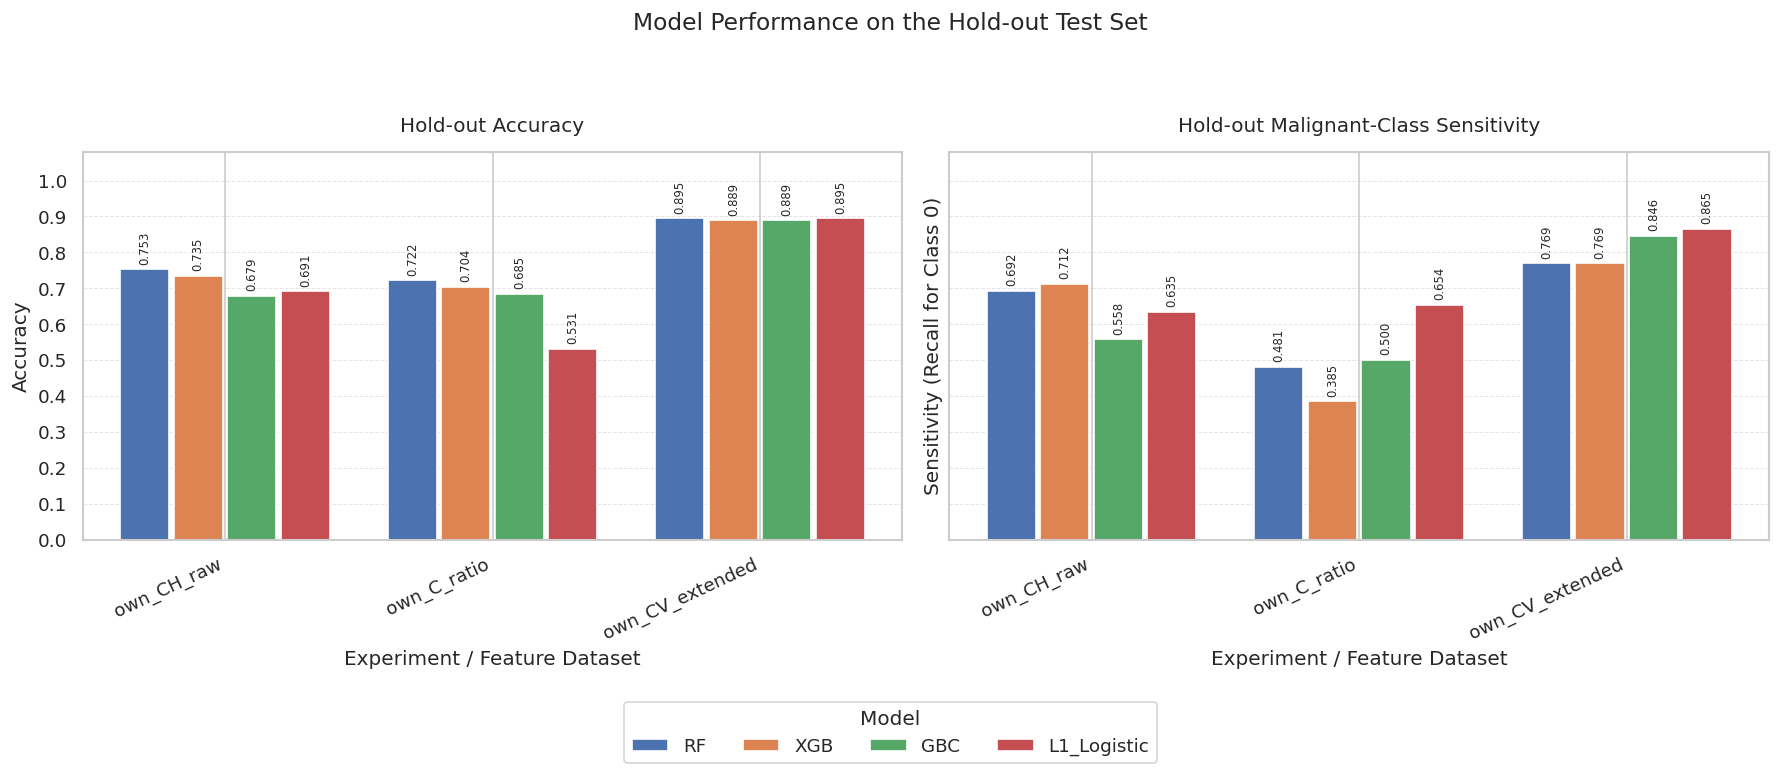

Saved figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/holdout_model_comparison.png
Saved figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/holdout_model_comparison.pdf

DETAILED HOLD-OUT CLASSIFICATION REPORTS

EXPERIMENT: own_CH_raw

Model: RF
------------------------------------------------------------
Confusion matrix (rows = true class; columns = predicted class):


,Predicted: Malignant (0),Predicted: Benign (1)
True: Malignant (0),36,16
True: Benign (1),24,86


Classification report:
               precision    recall  f1-score   support

Malignant (0)     0.6000    0.6923    0.6429        52
   Benign (1)     0.8431    0.7818    0.8113       110

     accuracy                         0.7531       162
    macro avg     0.7216    0.7371    0.7271       162
 weighted avg     0.7651    0.7531    0.7572       162


Model: XGB
------------------------------------------------------------
Confusion matrix (rows = true class; columns = predicted class):


,Predicted: Malignant (0),Predicted: Benign (1)
True: Malignant (0),37,15
True: Benign (1),28,82


Classification report:
               precision    recall  f1-score   support

Malignant (0)     0.5692    0.7115    0.6325        52
   Benign (1)     0.8454    0.7455    0.7923       110

     accuracy                         0.7346       162
    macro avg     0.7073    0.7285    0.7124       162
 weighted avg     0.7567    0.7346    0.7410       162


Model: GBC
------------------------------------------------------------
Confusion matrix (rows = true class; columns = predicted class):


...

Classification report:
               precision    recall  f1-score   support

Malignant (0)     0.8182    0.8654    0.8411        52
   Benign (1)     0.9346    0.9091    0.9217       110

     accuracy                         0.8951       162
    macro avg     0.8764    0.8872    0.8814       162
 weighted avg     0.8972    0.8951    0.8958       162


CELL 12 — REPORTING SUMMARY
Models successfully reported: 12
Model/reporting errors: 0

Saved output files:
  Plot data CSV:          /content/drive/MyDrive/BUSI_paper_reproduction/csv/holdout_metrics_used_for_visualization.csv
  Classification CSV:     /content/drive/MyDrive/BUSI_paper_reproduction/csv/holdout_classification_reports.csv
  Confusion-matrix CSV:   /content/drive/MyDrive/BUSI_paper_reproduction/csv/holdout_confusion_matrices.csv
  Classification JSON:    /content/drive/MyDrive/BUSI_paper_reproduction/csv/holdout_classification_reports.json
  Reporting errors CSV:   /content/drive/MyDrive/BUSI_paper_reproduction/csv/holdo

,experiment,model,report_entry,precision,recall,f1_score,support,holdout_accuracy,malignant_sensitivity,benign_specificity,n_test_samples
0,own_CH_raw,GBC,Benign (1),0.778846,0.736364,0.757009,110.0,0.679012,0.557692,0.736364,162
1,own_CH_raw,GBC,Malignant (0),0.500000,0.557692,0.527273,52.0,0.679012,0.557692,0.736364,162
2,own_CH_raw,GBC,accuracy,NaN,NaN,NaN,162.0,0.679012,0.557692,0.736364,162
3,own_CH_raw,GBC,macro avg,0.639423,0.647028,0.642141,162.0,0.679012,0.557692,0.736364,162
4,own_CH_raw,GBC,weighted avg,0.689340,0.679012,0.683267,162.0,0.679012,0.557692,0.736364,162
5,own_CH_raw,L1_Logistic,Benign (1),0.806122,0.718182,0.759615,110.0,0.691358,0.634615,0.718182,162
6,own_CH_raw,L1_Logistic,Malignant (0),0.515625,0.634615,0.568966,52.0,0.691358,0.634615,0.718182,162
7,own_CH_raw,L1_Logistic,accuracy,NaN,NaN,NaN,162.0,0.691358,0.634615,0.718182,162
8,own_CH_raw,L1_Logistic,macro avg,0.660874,0.676399,0.664290,162.0,0.691358,0.634615,0.718182,162
9,own_CH_raw,L1_Logistic,weighted avg,0.712876,0.691358,0.698419,162.0,0.691358,0.634615,0.718182,162



Recomputed confusion-matrix cells:


,experiment,model,true_label,true_class,predicted_label,predicted_class,count
0,own_CH_raw,GBC,0,Malignant (0),0,Malignant (0),29
1,own_CH_raw,GBC,0,Malignant (0),1,Benign (1),23
2,own_CH_raw,GBC,1,Benign (1),0,Malignant (0),29
3,own_CH_raw,GBC,1,Benign (1),1,Benign (1),81
4,own_CH_raw,L1_Logistic,0,Malignant (0),0,Malignant (0),33
5,own_CH_raw,L1_Logistic,0,Malignant (0),1,Benign (1),19
6,own_CH_raw,L1_Logistic,1,Benign (1),0,Malignant (0),31
7,own_CH_raw,L1_Logistic,1,Benign (1),1,Benign (1),79
8,own_CH_raw,RF,0,Malignant (0),0,Malignant (0),36
9,own_CH_raw,RF,0,Malignant (0),1,Benign (1),16



No per-model reporting errors were recorded.

Cell 12 completed.


In [18]:
# ============================================================
# Cell 12 — Hold-out Visualization and Detailed Model Reporting
# ============================================================
# Purpose:
#   1. Validate the aggregated evaluation results from Cell 11.
#   2. Visualize hold-out accuracy and malignant-class sensitivity.
#   3. Recompute confusion matrices from the actual hold-out predictions.
#   4. Generate detailed classification reports for every available model.
#   5. Verify prediction and sample-order consistency within each experiment.
#   6. Export evaluation tables, confusion matrices, figures, and JSON reports.
#
# Class convention:
#   0 = Malignant
#   1 = Benign
#
# Methodological safeguards:
#   - Hold-out metrics are for final reporting, not model selection.
#   - Sensitivity for malignancy is recall for class 0.
#   - Confusion matrices always use the explicit class order [0, 1].
#   - Author-table results and independently extracted BUSI results
#     are presented as separate feature-data experiments.
#   - Different experiments are not assumed to share source-image IDs.
#   - Predictions are validated before metrics are computed.
#   - Reporting failures are logged rather than silently ignored.
#   - Evaluation remains sample-level unless patient-group splitting
#     was implemented upstream.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and dependency validation
# ------------------------------------------------------------

from pathlib import Path
import json
import traceback
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

from IPython.display import display


_REQUIRED_GLOBALS = [
    "metrics_df",
    "experiment_results",
    "CSV_DIR",
    "FIG_DIR",
]

_missing_globals = [
    variable_name
    for variable_name in _REQUIRED_GLOBALS
    if variable_name not in globals()
]

if _missing_globals:
    raise RuntimeError(
        "Required objects are missing. Run Cell 11 successfully first. "
        f"Missing objects: {_missing_globals}"
    )

if not isinstance(metrics_df, pd.DataFrame):
    raise TypeError("metrics_df must be a pandas DataFrame.")

if not isinstance(experiment_results, dict):
    raise TypeError("experiment_results must be a dictionary.")

CSV_DIR = Path(CSV_DIR)
FIG_DIR = Path(FIG_DIR)

CSV_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Use one consistent class ordering throughout this cell.
CLASS_LABELS = [0, 1]
CLASS_NAMES = ["Malignant (0)", "Benign (1)"]

# Define the principal artifacts created by this cell.
PLOT_DATA_PATH = CSV_DIR / "holdout_metrics_used_for_visualization.csv"

REPORTS_CSV_PATH = CSV_DIR / "holdout_classification_reports.csv"
CONFUSION_CSV_PATH = CSV_DIR / "holdout_confusion_matrices.csv"
REPORTS_JSON_PATH = CSV_DIR / "holdout_classification_reports.json"
REPORT_ERRORS_PATH = CSV_DIR / "holdout_reporting_errors.csv"

PLOT_PNG_PATH = FIG_DIR / "holdout_model_comparison.png"
PLOT_PDF_PATH = FIG_DIR / "holdout_model_comparison.pdf"


# ------------------------------------------------------------
# 2. Prepare and validate the hold-out metrics table
# ------------------------------------------------------------

REQUIRED_METRIC_COLUMNS = {
    "experiment",
    "model",
    "test_accuracy",
    "test_sensitivity_malignant",
}

if metrics_df.empty:

    # Preserve an explicit schema when Cell 11 produced no completed runs.
    plot_metrics_df = pd.DataFrame(
        columns=sorted(REQUIRED_METRIC_COLUMNS)
    )

    warnings.warn(
        "metrics_df is empty. No model-comparison plot can be generated "
        "from aggregate metrics. Detailed reporting will still inspect "
        "experiment_results.",
        RuntimeWarning,
    )

else:

    missing_metric_columns = (
        REQUIRED_METRIC_COLUMNS - set(metrics_df.columns)
    )

    if missing_metric_columns:
        raise ValueError(
            "metrics_df is missing required hold-out metric columns: "
            f"{sorted(missing_metric_columns)}. "
            "Verify the summary schema generated by Cell 9."
        )

    plot_metrics_df = metrics_df.copy()

    # Remove rows that cannot be associated with a specific experiment/model.
    plot_metrics_df = plot_metrics_df.dropna(
        subset=["experiment", "model"]
    ).copy()

    plot_metrics_df["experiment"] = (
        plot_metrics_df["experiment"].astype(str).str.strip()
    )

    plot_metrics_df["model"] = (
        plot_metrics_df["model"].astype(str).str.strip()
    )

    if (
        plot_metrics_df["experiment"].eq("").any()
        or plot_metrics_df["model"].eq("").any()
    ):
        raise ValueError(
            "Blank experiment or model identifiers were found in metrics_df."
        )

    # Convert the two plotted metrics to numeric values.
    # Invalid values are retained as NaN for plotting, not replaced with zero.
    for metric_column in [
        "test_accuracy",
        "test_sensitivity_malignant",
    ]:
        plot_metrics_df[metric_column] = pd.to_numeric(
            plot_metrics_df[metric_column],
            errors="coerce",
        )

    # Each experiment/model pair should have exactly one aggregate row.
    duplicate_pairs = plot_metrics_df.duplicated(
        subset=["experiment", "model"],
        keep=False,
    )

    if duplicate_pairs.any():

        duplicate_details = (
            plot_metrics_df.loc[
                duplicate_pairs,
                ["experiment", "model"],
            ]
            .drop_duplicates()
            .sort_values(["experiment", "model"])
        )

        raise ValueError(
            "Duplicate experiment/model combinations were found in "
            "metrics_df. Resolve these duplicates before reporting:\n"
            f"{duplicate_details.to_string(index=False)}"
        )

    # Warn about out-of-range or non-finite metrics.
    for metric_column in [
        "test_accuracy",
        "test_sensitivity_malignant",
    ]:
        values = plot_metrics_df[metric_column]

        finite_mask = pd.Series(
            np.isfinite(values.to_numpy(dtype=float, na_value=np.nan)),
            index=values.index,
        )

        invalid_mask = values.notna() & (
            ~finite_mask | ~values.between(0.0, 1.0)
        )

        if invalid_mask.any():
            warnings.warn(
                f"{metric_column} contains invalid values. These values "
                "will be excluded from visualization but retained in the "
                "saved source table for auditing.",
                RuntimeWarning,
            )

# Save the table supplied to the plotting stage.
plot_metrics_df.to_csv(
    PLOT_DATA_PATH,
    index=False,
)

print("=" * 78)
print("HOLD-OUT METRICS SUMMARY")
print("=" * 78)

if plot_metrics_df.empty:
    print("No aggregate metric rows are available.")
else:
    display(
        plot_metrics_df.sort_values(
            ["experiment", "model"]
        ).reset_index(drop=True)
    )


# ------------------------------------------------------------
# 3. Determine deterministic experiment and model order
# ------------------------------------------------------------

observed_experiments = (
    plot_metrics_df["experiment"].drop_duplicates().tolist()
    if not plot_metrics_df.empty
    else []
)

observed_models = (
    plot_metrics_df["model"].drop_duplicates().tolist()
    if not plot_metrics_df.empty
    else []
)

# Prefer the documented experiment order when available.
preferred_order = globals().get(
    "PREFERRED_EXPERIMENT_ORDER",
    [],
)

if not isinstance(preferred_order, (list, tuple)):
    preferred_order = []

experiment_order = [
    name
    for name in preferred_order
    if name in observed_experiments
]

experiment_order.extend([
    name
    for name in observed_experiments
    if name not in experiment_order
])

# Preserve model order from the aggregated metrics table.
model_order = observed_models


# ------------------------------------------------------------
# 4. Plot hold-out accuracy and malignant-class sensitivity
# ------------------------------------------------------------

if not plot_metrics_df.empty and experiment_order and model_order:

    number_of_experiments = len(experiment_order)
    number_of_models = len(model_order)

    figure_width = max(
        15,
        min(26, 2.2 * number_of_experiments),
    )

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(figure_width, 6.5),
        sharey=True,
    )

    metric_plot_specs = [
        {
            "column": "test_accuracy",
            "title": "Hold-out Accuracy",
            "ylabel": "Accuracy",
        },
        {
            "column": "test_sensitivity_malignant",
            "title": "Hold-out Malignant-Class Sensitivity",
            "ylabel": "Sensitivity (Recall for Class 0)",
        },
    ]

    # Create an indexed lookup to avoid repeated DataFrame filtering.
    metric_lookup = {}

    for _, metric_row in plot_metrics_df.iterrows():
        metric_lookup[
            (metric_row["experiment"], metric_row["model"])
        ] = metric_row

    x_positions = np.arange(number_of_experiments)

    # Allocate a fixed width to the complete group of model bars.
    group_width = 0.80
    bar_width = group_width / max(number_of_models, 1)

    model_offsets = (
        np.arange(number_of_models)
        - (number_of_models - 1) / 2
    ) * bar_width

    for axis_index, (ax, spec) in enumerate(
        zip(axes, metric_plot_specs)
    ):

        metric_column = spec["column"]

        plotted_any_values = False

        for model_index, model_name in enumerate(model_order):

            values_for_model = []

            # Use NaN for missing or invalid scores; never substitute zero.
            for experiment_name in experiment_order:

                row = metric_lookup.get(
                    (experiment_name, model_name)
                )

                if row is None:
                    values_for_model.append(np.nan)
                    continue

                raw_value = row[metric_column]

                if pd.isna(raw_value):
                    values_for_model.append(np.nan)
                    continue

                numeric_value = float(raw_value)

                if (
                    not np.isfinite(numeric_value)
                    or not 0.0 <= numeric_value <= 1.0
                ):
                    values_for_model.append(np.nan)
                    continue

                values_for_model.append(numeric_value)

            values_array = np.asarray(
                values_for_model,
                dtype=float,
            )

            if np.isfinite(values_array).any():
                plotted_any_values = True

            bar_positions = (
                x_positions + model_offsets[model_index]
            )

            bars = ax.bar(
                bar_positions,
                values_array,
                width=bar_width * 0.92,
                label=model_name,
                align="center",
            )

            # Add numeric labels only when the plot is not too dense.
            if (
                number_of_experiments * number_of_models <= 18
            ):
                for bar in bars:

                    height = bar.get_height()

                    if not np.isfinite(height):
                        continue

                    ax.annotate(
                        f"{height:.3f}",
                        xy=(
                            bar.get_x() + bar.get_width() / 2,
                            height,
                        ),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha="center",
                        va="bottom",
                        fontsize=7,
                        rotation=90 if number_of_models >= 4 else 0,
                    )

        if not plotted_any_values:
            ax.text(
                0.5,
                0.5,
                "No valid values available",
                ha="center",
                va="center",
                transform=ax.transAxes,
            )

        ax.set_title(
            spec["title"],
            fontsize=12,
            pad=12,
        )

        ax.set_xlabel("Experiment / Feature Dataset")
        ax.set_ylabel(spec["ylabel"])

        ax.set_xticks(x_positions)
        ax.set_xticklabels(
            experiment_order,
            rotation=25,
            ha="right",
        )

        ax.set_ylim(0.0, 1.08)
        ax.set_yticks(np.arange(0.0, 1.01, 0.1))

        ax.grid(
            axis="y",
            linestyle="--",
            linewidth=0.6,
            alpha=0.5,
        )

        ax.set_axisbelow(True)

    # Use one figure-level legend rather than duplicate legends in both panels.
    legend_handles, legend_labels = axes[0].get_legend_handles_labels()

    for ax in axes:
        existing_legend = ax.get_legend()

        if existing_legend is not None:
            existing_legend.remove()

    if legend_handles:
        fig.legend(
            legend_handles,
            legend_labels,
            title="Model",
            loc="lower center",
            bbox_to_anchor=(0.5, 0.015),
            ncol=min(number_of_models, 4),
            frameon=True,
        )

    fig.suptitle(
        "Model Performance on the Hold-out Test Set",
        fontsize=14,
        y=0.99,
    )

    fig.tight_layout(
        rect=(0, 0.12, 1, 0.94)
    )

    # Export both raster and vector formats.
    fig.savefig(
        PLOT_PNG_PATH,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        PLOT_PDF_PATH,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Saved figure: {PLOT_PNG_PATH}")
    print(f"Saved figure: {PLOT_PDF_PATH}")

else:
    print(
        "Skipping hold-out plots because no usable experiment/model "
        "metric rows are available."
    )


# ------------------------------------------------------------
# 5. Helper functions for robust prediction validation
# ------------------------------------------------------------

def extract_prediction_vector(
    prediction_info,
    candidate_keys,
    field_description,
):
    """
    Extract a one-dimensional prediction vector from a prediction record.

    Different versions of the evaluation function may use different
    names for the same hold-out target or prediction vector.
    """

    for candidate_key in candidate_keys:

        if candidate_key not in prediction_info:
            continue

        value = prediction_info[candidate_key]

        if value is None:
            continue

        raw_values = np.asarray(value)

        if raw_values.ndim != 1:
            raise ValueError(
                f"{field_description} must be one-dimensional. "
                f"Received shape {raw_values.shape} "
                f"from key '{candidate_key}'."
            )

        if raw_values.size == 0:
            raise ValueError(
                f"{field_description} is empty in key '{candidate_key}'."
            )

        numeric_values = pd.to_numeric(
            pd.Series(raw_values),
            errors="coerce",
        )

        if numeric_values.isna().any():
            raise ValueError(
                f"{field_description} contains missing or non-numeric values."
            )

        numeric_array = numeric_values.to_numpy(dtype=float)

        if not np.isfinite(numeric_array).all():
            raise ValueError(
                f"{field_description} contains non-finite values."
            )

        return numeric_array, candidate_key

    raise KeyError(
        f"Could not locate {field_description}. "
        f"Expected one of the keys: {list(candidate_keys)}."
    )


def make_json_safe(value):
    """
    Convert common NumPy and pandas values to JSON-compatible Python values.
    """

    if isinstance(value, dict):
        return {
            str(key): make_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return make_json_safe(value.tolist())

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        numeric_value = float(value)
        return numeric_value if np.isfinite(numeric_value) else None

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, float):
        return value if np.isfinite(value) else None

    if value is pd.NA:
        return None

    return value


# ------------------------------------------------------------
# 6. Generate detailed hold-out classification reports
# ------------------------------------------------------------

report_rows = []
confusion_matrix_rows = []
json_report_records = []
report_errors = []

# Keep a reference hold-out target order for within-experiment consistency.
experiment_holdout_reference = {}

print("\n" + "=" * 78)
print("DETAILED HOLD-OUT CLASSIFICATION REPORTS")
print("=" * 78)

if not experiment_results:
    print(
        "experiment_results is empty. No per-model hold-out predictions "
        "are available for detailed reporting."
    )

for experiment_name, result in experiment_results.items():

    print("\n" + "=" * 78)
    print(f"EXPERIMENT: {experiment_name}")
    print("=" * 78)

    if not isinstance(result, dict):

        error_message = (
            "The experiment result must be a dictionary."
        )

        warnings.warn(
            f"{experiment_name}: {error_message}",
            RuntimeWarning,
        )

        report_errors.append({
            "experiment": experiment_name,
            "model": None,
            "error": error_message,
            "traceback": None,
        })

        continue

    test_predictions = result.get(
        "test_predictions",
        None,
    )

    if not isinstance(test_predictions, dict) or not test_predictions:

        error_message = (
            "Missing or invalid 'test_predictions' dictionary."
        )

        warnings.warn(
            f"{experiment_name}: {error_message}",
            RuntimeWarning,
        )

        report_errors.append({
            "experiment": experiment_name,
            "model": None,
            "error": error_message,
            "traceback": None,
        })

        continue

    for model_name, prediction_info in test_predictions.items():

        print(f"\nModel: {model_name}")
        print("-" * 60)

        try:

            if not isinstance(prediction_info, dict):
                raise TypeError(
                    "Each model prediction record must be a dictionary."
                )

            # Support the principal key names used by common evaluator versions.
            y_true_numeric, y_true_source_key = extract_prediction_vector(
                prediction_info,
                candidate_keys=("y_true", "y_test"),
                field_description="true hold-out labels",
            )

            y_pred_numeric, y_pred_source_key = extract_prediction_vector(
                prediction_info,
                candidate_keys=(
                    "y_pred",
                    "y_test_pred",
                    "test_predictions",
                ),
                field_description="predicted hold-out labels",
            )

            if y_true_numeric.size != y_pred_numeric.size:
                raise ValueError(
                    "The number of true labels differs from the number "
                    "of predicted labels."
                )

            # This notebook uses the binary encoding 0 = malignant, 1 = benign.
            allowed_labels = {0.0, 1.0}

            observed_true_labels = set(y_true_numeric.tolist())
            observed_predicted_labels = set(y_pred_numeric.tolist())

            if not observed_true_labels.issubset(allowed_labels):
                raise ValueError(
                    "Unexpected true labels were found. Expected only "
                    f"{sorted(allowed_labels)}, observed "
                    f"{sorted(observed_true_labels)}."
                )

            if not observed_predicted_labels.issubset(allowed_labels):
                raise ValueError(
                    "Unexpected predicted labels were found. Expected only "
                    f"{sorted(allowed_labels)}, observed "
                    f"{sorted(observed_predicted_labels)}."
                )

            y_true = y_true_numeric.astype(int)
            y_pred = y_pred_numeric.astype(int)

            # Warn if the hold-out set does not contain both classes.
            if set(np.unique(y_true).tolist()) != {0, 1}:
                warnings.warn(
                    f"{experiment_name}/{model_name}: the hold-out target "
                    "contains fewer than two classes. Some class-specific "
                    "metrics cannot be reliably estimated.",
                    RuntimeWarning,
                )

            # Verify that all models within the same experiment use the
            # same hold-out target values and ordering.
            current_reference = experiment_holdout_reference.get(
                experiment_name
            )

            if current_reference is None:

                experiment_holdout_reference[experiment_name] = {
                    "y_true": y_true.copy(),
                    "n_samples": int(y_true.size),
                    "test_ids": None,
                }

            else:

                if not np.array_equal(
                    current_reference["y_true"],
                    y_true,
                ):
                    raise ValueError(
                        "The true hold-out labels or their ordering differ "
                        "between models within the same experiment. "
                        "The model results cannot be safely compared."
                    )

                if current_reference["n_samples"] != int(y_true.size):
                    raise ValueError(
                        "The hold-out sample count is inconsistent across "
                        "models within the same experiment."
                    )

            # Validate optional test IDs, when supplied by Cell 9.
            test_ids = None

            for id_key in ("test_ids", "sample_ids_test"):
                if id_key in prediction_info and prediction_info[id_key] is not None:

                    candidate_ids = np.asarray(
                        prediction_info[id_key],
                        dtype=object,
                    )

                    if candidate_ids.ndim != 1:
                        raise ValueError(
                            f"{id_key} must be one-dimensional."
                        )

                    if candidate_ids.size != y_true.size:
                        raise ValueError(
                            f"{id_key} length does not match the "
                            "hold-out prediction count."
                        )

                    candidate_ids_series = pd.Series(candidate_ids)

                    if candidate_ids_series.isna().any():
                        raise ValueError(
                            f"{id_key} contains missing sample identifiers."
                        )

                    candidate_ids = (
                        candidate_ids_series.astype(str).str.strip().to_numpy()
                    )

                    if np.any(candidate_ids == ""):
                        raise ValueError(
                            f"{id_key} contains blank sample identifiers."
                        )

                    test_ids = candidate_ids
                    break

            # If IDs are provided for more than one model, ensure their
            # order agrees within that experiment.
            if test_ids is not None:

                stored_ids = experiment_holdout_reference[
                    experiment_name
                ]["test_ids"]

                if stored_ids is None:
                    experiment_holdout_reference[
                        experiment_name
                    ]["test_ids"] = test_ids.copy()

                elif not np.array_equal(stored_ids, test_ids):
                    raise ValueError(
                        "The hold-out sample IDs or their ordering differ "
                        "between models in the same experiment."
                    )

            # Compute the confusion matrix using the canonical class order.
            cm = confusion_matrix(
                y_true,
                y_pred,
                labels=CLASS_LABELS,
            )

            cm_df = pd.DataFrame(
                cm,
                index=[
                    "True: Malignant (0)",
                    "True: Benign (1)",
                ],
                columns=[
                    "Predicted: Malignant (0)",
                    "Predicted: Benign (1)",
                ],
            )

            print(
                "Confusion matrix "
                "(rows = true class; columns = predicted class):"
            )
            display(cm_df)

            # Compare against the stored confusion matrix if the evaluator
            # provided one. The recomputed matrix remains authoritative.
            stored_cm = prediction_info.get("confusion_matrix")

            if stored_cm is not None:

                stored_cm_array = np.asarray(stored_cm)

                if (
                    stored_cm_array.shape != cm.shape
                    or not np.array_equal(stored_cm_array, cm)
                ):
                    warnings.warn(
                        f"{experiment_name}/{model_name}: the stored "
                        "confusion matrix does not match the matrix "
                        "recomputed from y_true and y_pred. The recomputed "
                        "matrix will be exported.",
                        RuntimeWarning,
                    )

            # Generate the standard classification report with a fixed order.
            report_dict = classification_report(
                y_true,
                y_pred,
                labels=CLASS_LABELS,
                target_names=CLASS_NAMES,
                zero_division=0,
                output_dict=True,
            )

            report_text = classification_report(
                y_true,
                y_pred,
                labels=CLASS_LABELS,
                target_names=CLASS_NAMES,
                zero_division=0,
                digits=4,
            )

            print("Classification report:")
            print(report_text)

            holdout_accuracy = float(
                accuracy_score(y_true, y_pred)
            )

            # Malignant sensitivity is recall for class 0.
            malignant_recall = report_dict[
                CLASS_NAMES[0]
            ]["recall"]

            # Specificity for malignant detection is the true-negative rate
            # when malignant is treated as the positive class.
            malignant_support = int((y_true == 0).sum())
            benign_support = int((y_true == 1).sum())

            tn_malignant = int(cm[1, 1])
            fp_malignant = int(cm[1, 0])

            benign_specificity = (
                float(tn_malignant / (tn_malignant + fp_malignant))
                if (tn_malignant + fp_malignant) > 0
                else np.nan
            )

            # Add one row for each class or aggregate entry in the report.
            for report_key, report_values in report_dict.items():

                if isinstance(report_values, dict):

                    report_rows.append({
                        "experiment": str(experiment_name),
                        "model": str(model_name),
                        "report_entry": str(report_key),
                        "precision": report_values.get("precision"),
                        "recall": report_values.get("recall"),
                        "f1_score": report_values.get("f1-score"),
                        "support": report_values.get("support"),
                        "holdout_accuracy": holdout_accuracy,
                        "malignant_sensitivity": malignant_recall,
                        "benign_specificity": benign_specificity,
                        "n_test_samples": int(y_true.size),
                    })

                else:
                    # The sklearn report stores overall accuracy as a scalar.
                    report_rows.append({
                        "experiment": str(experiment_name),
                        "model": str(model_name),
                        "report_entry": str(report_key),
                        "precision": np.nan,
                        "recall": np.nan,
                        "f1_score": np.nan,
                        "support": int(y_true.size),
                        "holdout_accuracy": float(report_values),
                        "malignant_sensitivity": malignant_recall,
                        "benign_specificity": benign_specificity,
                        "n_test_samples": int(y_true.size),
                    })

            # Export each confusion-matrix cell as a separate tidy record.
            for true_position, true_label in enumerate(CLASS_LABELS):

                for predicted_position, predicted_label in enumerate(
                    CLASS_LABELS
                ):

                    confusion_matrix_rows.append({
                        "experiment": str(experiment_name),
                        "model": str(model_name),
                        "true_label": int(true_label),
                        "true_class": CLASS_NAMES[true_position],
                        "predicted_label": int(predicted_label),
                        "predicted_class": CLASS_NAMES[predicted_position],
                        "count": int(
                            cm[true_position, predicted_position]
                        ),
                    })

            # Save an audit-ready JSON record for this model.
            json_report_records.append({
                "experiment": str(experiment_name),
                "model": str(model_name),
                "class_order": {
                    "0": "Malignant",
                    "1": "Benign",
                },
                "n_test_samples": int(y_true.size),
                "source_key_for_true_labels": y_true_source_key,
                "source_key_for_predictions": y_pred_source_key,
                "holdout_accuracy": holdout_accuracy,
                "malignant_sensitivity": (
                    float(malignant_recall)
                    if malignant_recall is not None
                    else None
                ),
                "benign_specificity": (
                    float(benign_specificity)
                    if np.isfinite(benign_specificity)
                    else None
                ),
                "classification_report": report_dict,
                "confusion_matrix": cm.tolist(),
                "confusion_matrix_axis_order": {
                    "rows": ["Malignant (0)", "Benign (1)"],
                    "columns": ["Malignant (0)", "Benign (1)"],
                },
            })

        except Exception as exc:

            error_message = f"{type(exc).__name__}: {exc}"

            warnings.warn(
                f"Could not generate the report for "
                f"{experiment_name}/{model_name}: {error_message}",
                RuntimeWarning,
            )

            report_errors.append({
                "experiment": str(experiment_name),
                "model": str(model_name),
                "error": error_message,
                "traceback": traceback.format_exc(),
            })


# ------------------------------------------------------------
# 7. Convert reports into DataFrames and export artifacts
# ------------------------------------------------------------

report_columns = [
    "experiment",
    "model",
    "report_entry",
    "precision",
    "recall",
    "f1_score",
    "support",
    "holdout_accuracy",
    "malignant_sensitivity",
    "benign_specificity",
    "n_test_samples",
]

confusion_columns = [
    "experiment",
    "model",
    "true_label",
    "true_class",
    "predicted_label",
    "predicted_class",
    "count",
]

error_columns = [
    "experiment",
    "model",
    "error",
    "traceback",
]

reports_df = pd.DataFrame(
    report_rows,
    columns=report_columns,
)

confusion_matrices_df = pd.DataFrame(
    confusion_matrix_rows,
    columns=confusion_columns,
)

report_errors_df = pd.DataFrame(
    report_errors,
    columns=error_columns,
)

# Save CSV outputs even if some models could not be reported.
reports_df.to_csv(
    REPORTS_CSV_PATH,
    index=False,
)

confusion_matrices_df.to_csv(
    CONFUSION_CSV_PATH,
    index=False,
)

report_errors_df.to_csv(
    REPORT_ERRORS_PATH,
    index=False,
)

# Convert NumPy values to native Python types before JSON serialization.
json_report_records_safe = make_json_safe(
    json_report_records
)

with open(
    REPORTS_JSON_PATH,
    "w",
    encoding="utf-8",
) as json_file:

    json.dump(
        json_report_records_safe,
        json_file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False,
    )


# ------------------------------------------------------------
# 8. Display the final reporting tables and artifact locations
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("CELL 12 — REPORTING SUMMARY")
print("=" * 78)

print(
    f"Models successfully reported: {len(json_report_records)}"
)

print(
    f"Model/reporting errors: {len(report_errors)}"
)

print("\nSaved output files:")
print(f"  Plot data CSV:          {PLOT_DATA_PATH}")
print(f"  Classification CSV:     {REPORTS_CSV_PATH}")
print(f"  Confusion-matrix CSV:   {CONFUSION_CSV_PATH}")
print(f"  Classification JSON:    {REPORTS_JSON_PATH}")
print(f"  Reporting errors CSV:   {REPORT_ERRORS_PATH}")

if PLOT_PNG_PATH.exists():
    print(f"  Comparison figure PNG:  {PLOT_PNG_PATH}")

if PLOT_PDF_PATH.exists():
    print(f"  Comparison figure PDF:  {PLOT_PDF_PATH}")

if not reports_df.empty:

    print("\nDetailed classification-report table:")

    display(
        reports_df.sort_values(
            ["experiment", "model", "report_entry"]
        ).reset_index(drop=True)
    )

if not confusion_matrices_df.empty:

    print("\nRecomputed confusion-matrix cells:")

    display(
        confusion_matrices_df.sort_values(
            [
                "experiment",
                "model",
                "true_label",
                "predicted_label",
            ]
        ).reset_index(drop=True)
    )

if not report_errors_df.empty:

    print("\nReporting errors requiring inspection:")

    display(report_errors_df)

else:
    print("\nNo per-model reporting errors were recorded.")

print("\nCell 12 completed.")

##Cell 13 — Permutation Importance and Native Feature Importance

HOLD-OUT PERMUTATION IMPORTANCE

EXPERIMENT: own_CH_raw

Model: RF
Completed successfully: 8 features, 30 repeats, 162 hold-out samples.

Model: XGB
Completed successfully: 8 features, 30 repeats, 162 hold-out samples.

Model: GBC
Completed successfully: 8 features, 30 repeats, 162 hold-out samples.

Model: L1_Logistic
Completed successfully: 8 features, 30 repeats, 162 hold-out samples.

EXPERIMENT: own_C_ratio

Model: RF
Completed successfully: 8 features, 30 repeats, 162 hold-out samples.

Model: XGB
Completed successfully: 8 features, 30 repeats, 162 hold-out samples.

Model: GBC
Completed successfully: 8 features, 30 repeats, 162 hold-out samples.

Model: L1_Logistic
Completed successfully: 8 features, 30 repeats, 162 hold-out samples.

EXPERIMENT: own_CV_extended

Model: RF
Completed successfully: 13 features, 30 repeats, 162 hold-out samples.

Model: XGB
Completed successfully: 13 features, 30 repeats, 162 hold-out samples.

Model: GBC
Completed successfully: 13 features, 30 rep

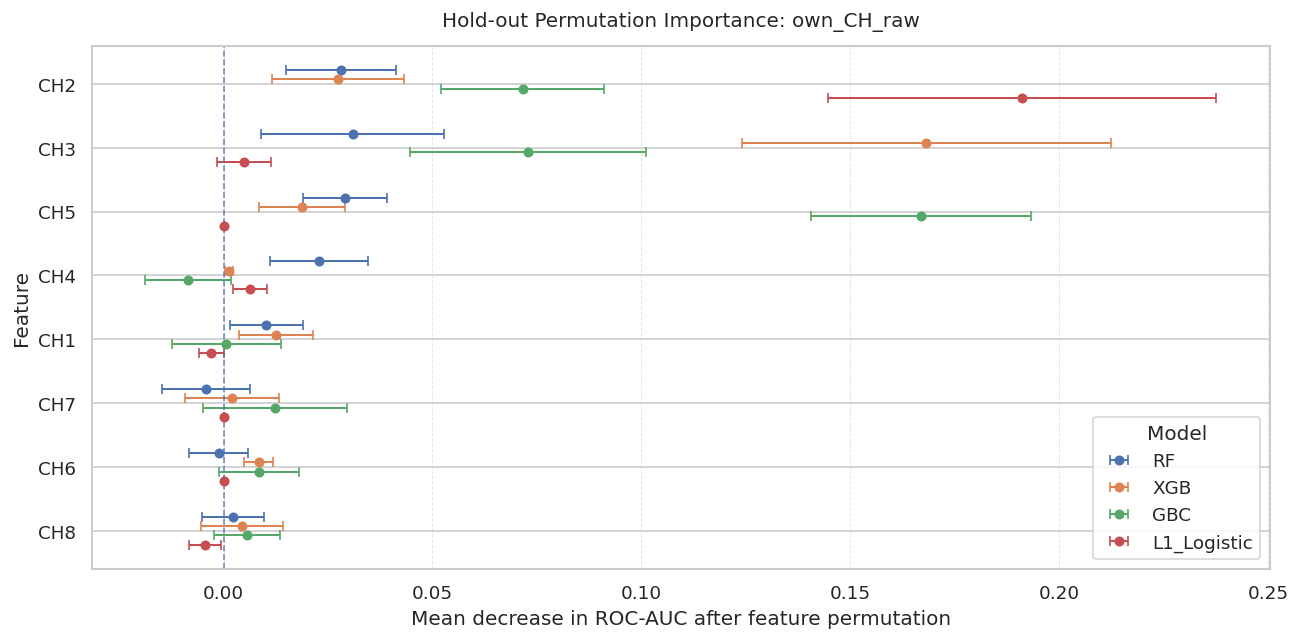

Saved permutation figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/permutation_importance_own_CH_raw.png
Saved permutation figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/permutation_importance_own_CH_raw.pdf


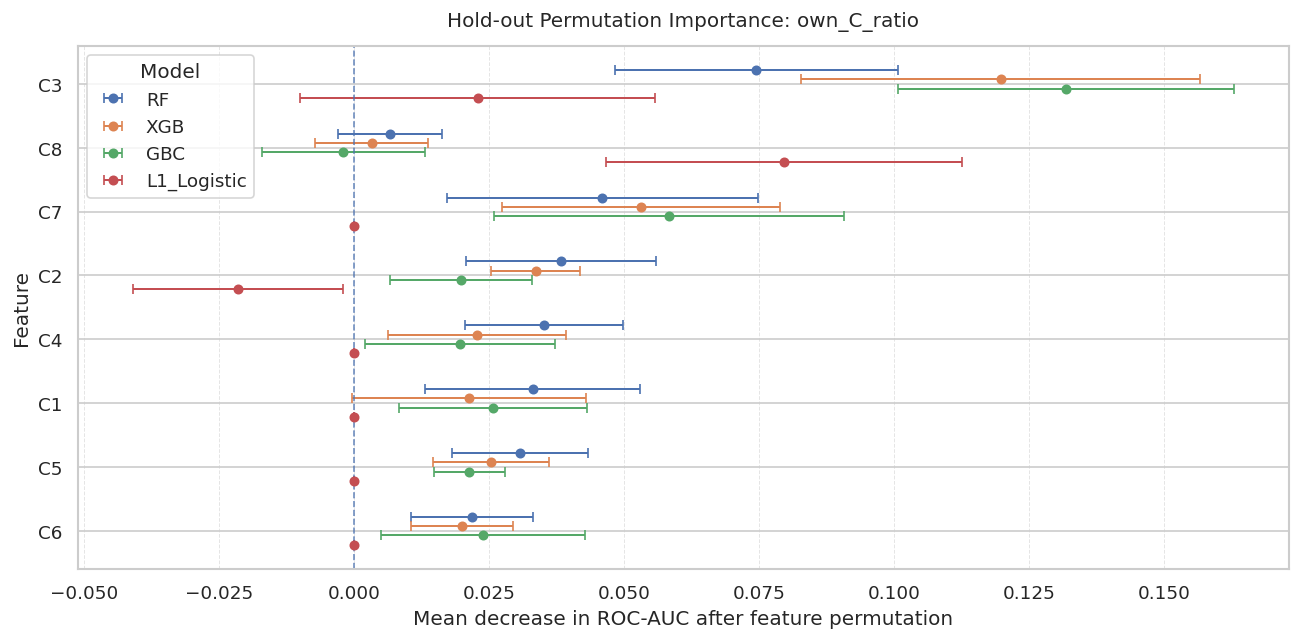

Saved permutation figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/permutation_importance_own_C_ratio.png
Saved permutation figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/permutation_importance_own_C_ratio.pdf


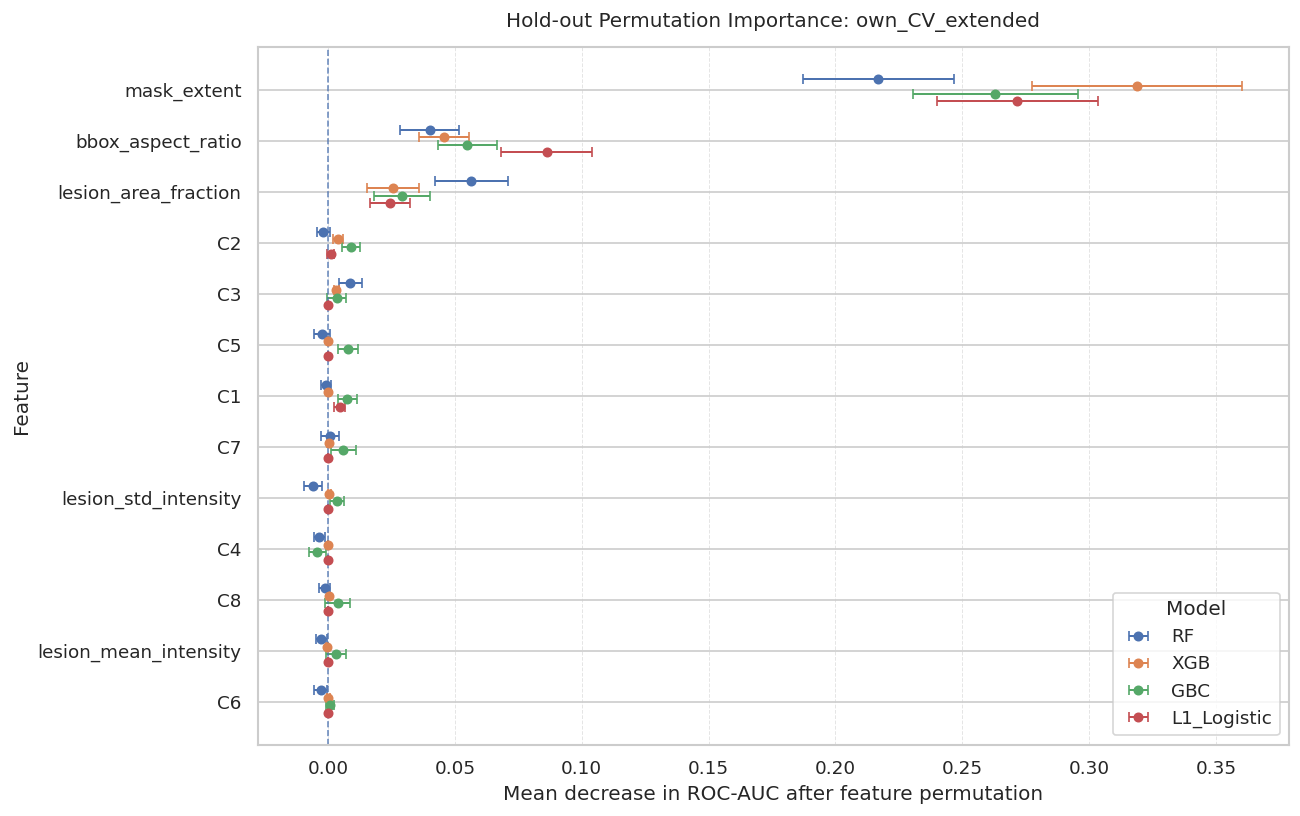

Saved permutation figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/permutation_importance_own_CV_extended.png
Saved permutation figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/permutation_importance_own_CV_extended.pdf

NATIVE TREE-BASED FEATURE IMPORTANCE
Native importance rows: 87
Native importance CSV: /content/drive/MyDrive/BUSI_paper_reproduction/csv/native_tree_importance.csv


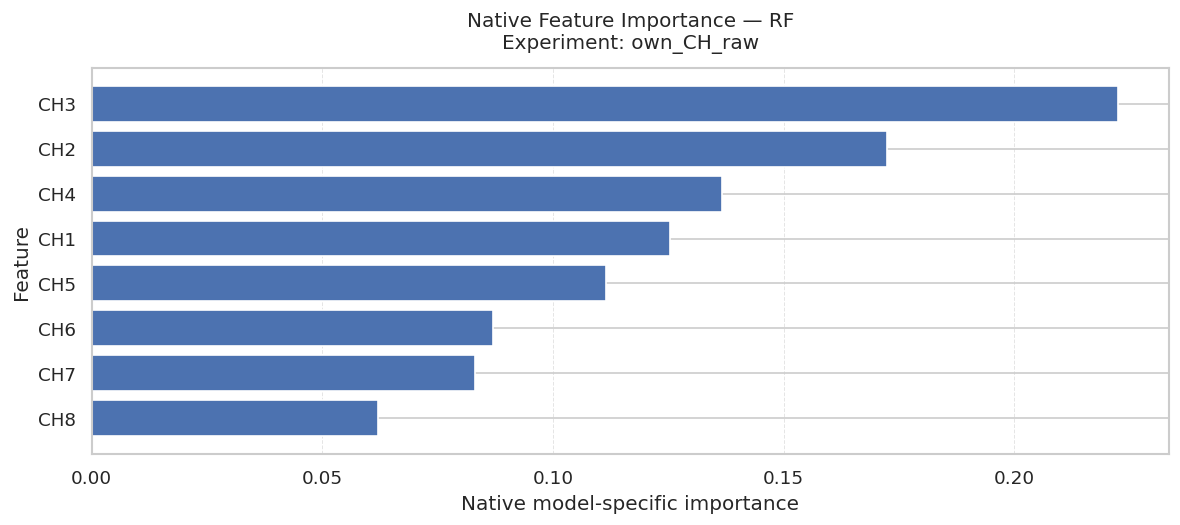

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CH_raw_RF.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CH_raw_RF.pdf


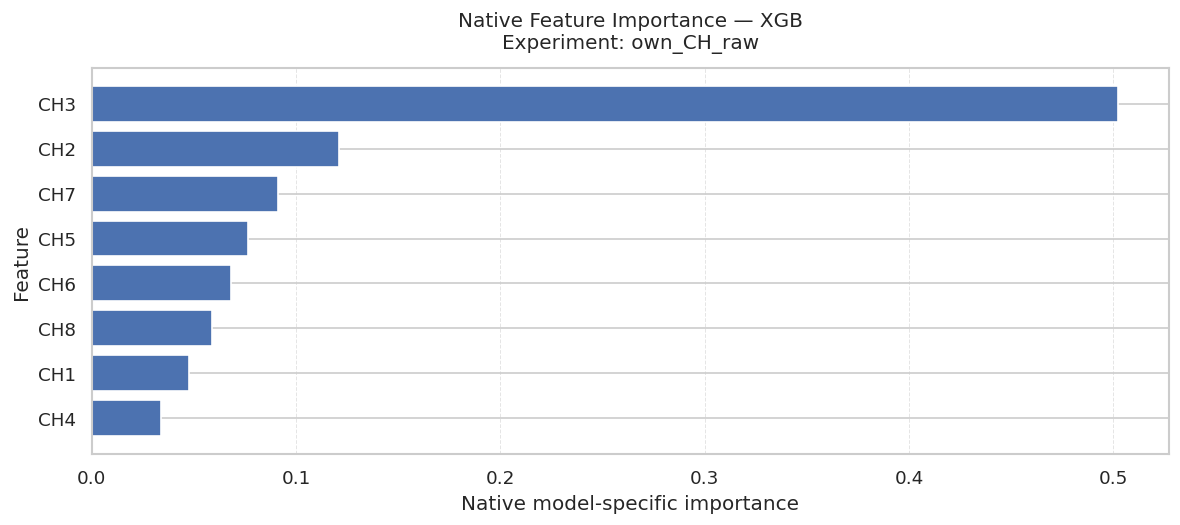

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CH_raw_XGB.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CH_raw_XGB.pdf


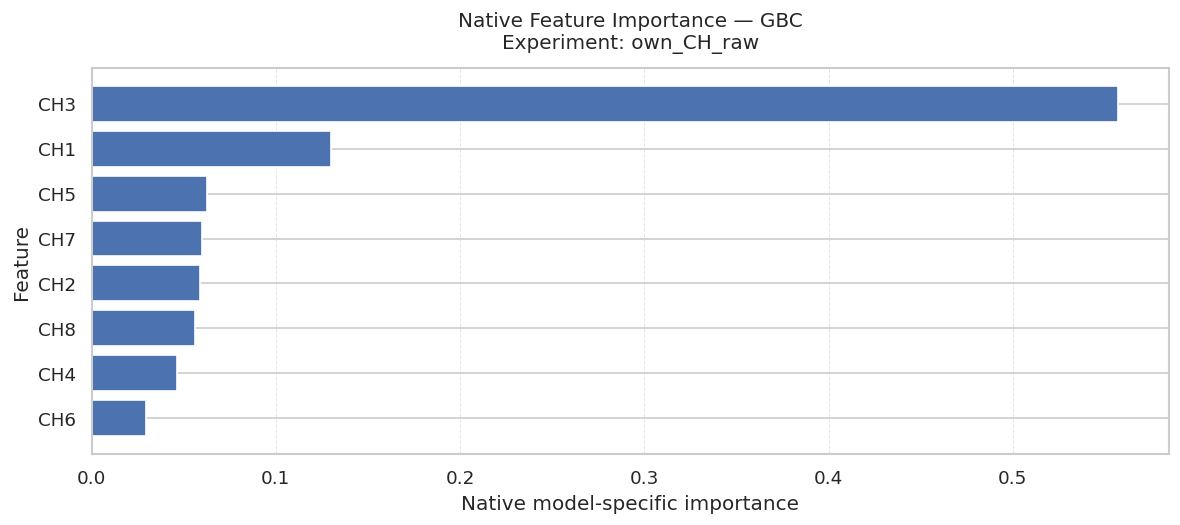

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CH_raw_GBC.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CH_raw_GBC.pdf


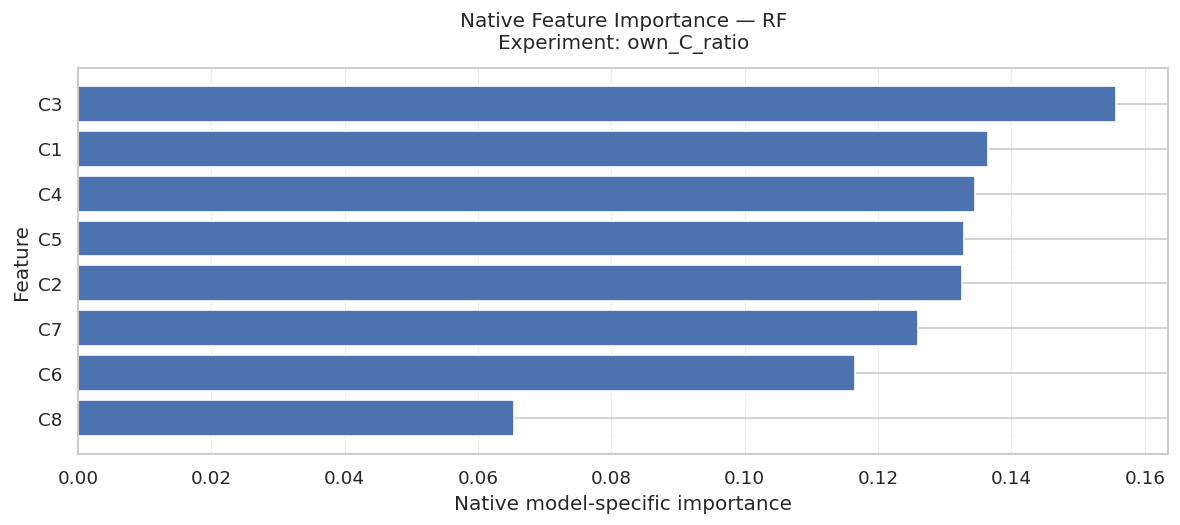

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_C_ratio_RF.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_C_ratio_RF.pdf


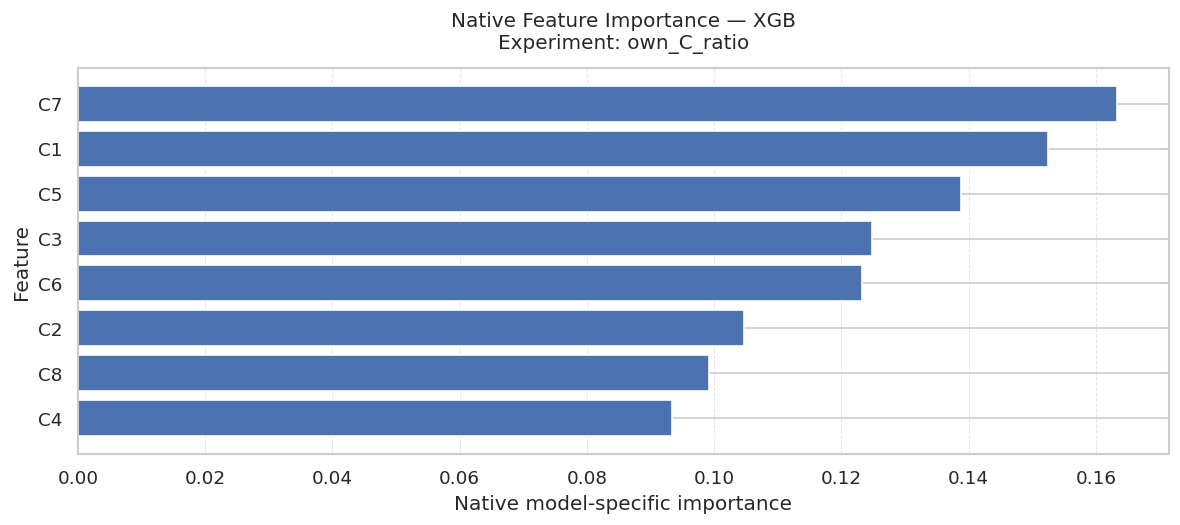

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_C_ratio_XGB.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_C_ratio_XGB.pdf


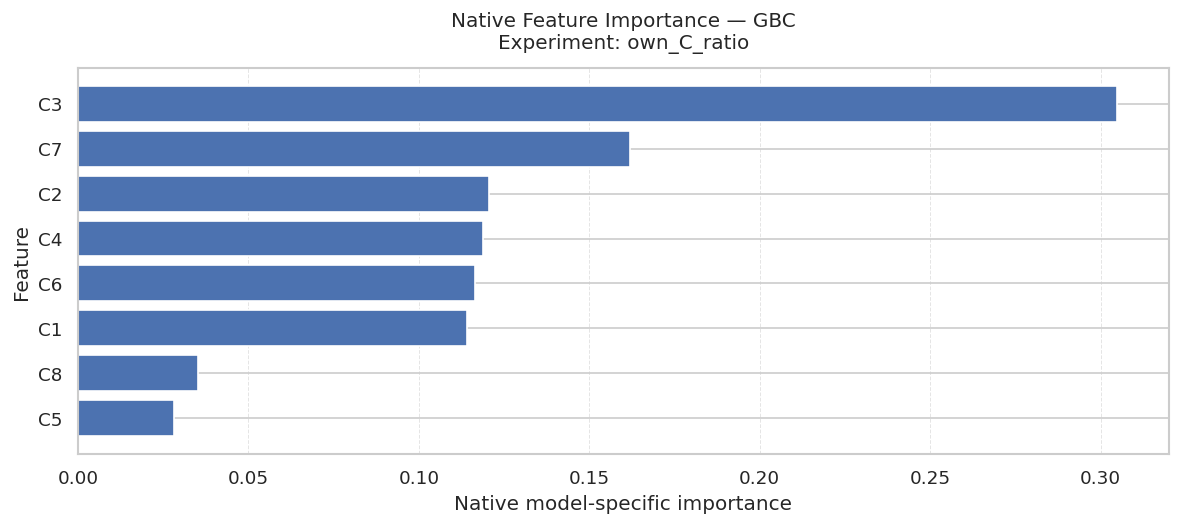

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_C_ratio_GBC.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_C_ratio_GBC.pdf


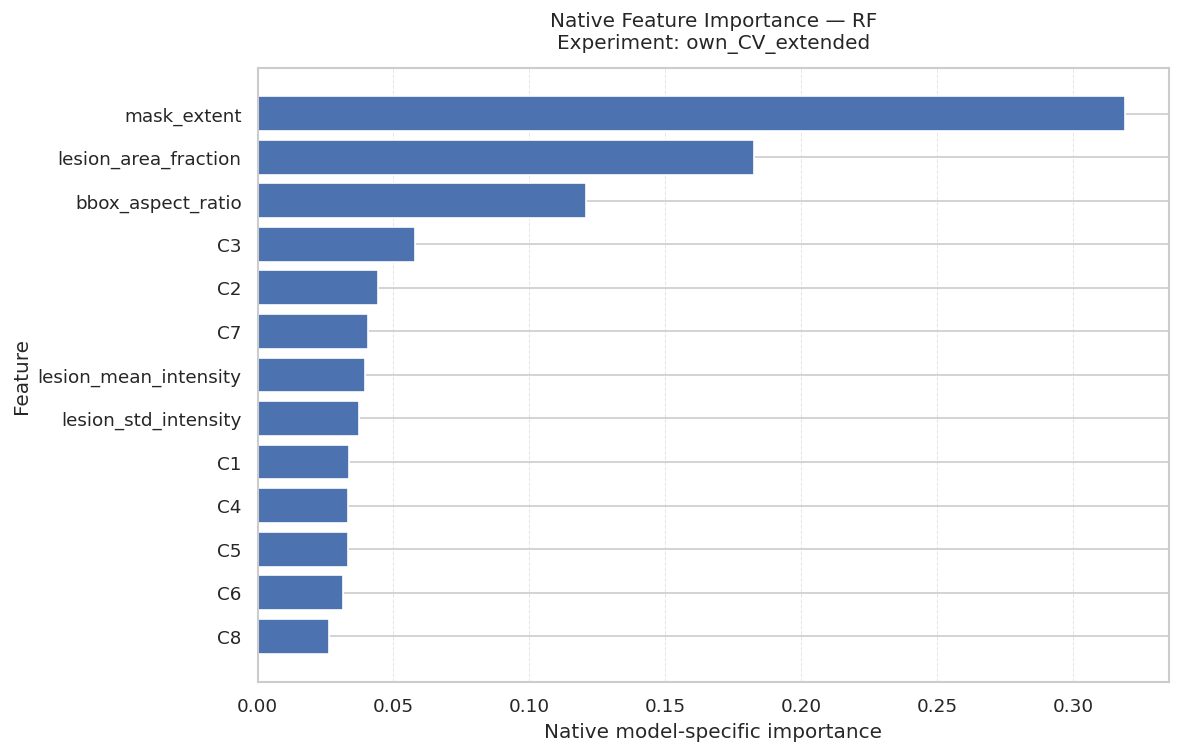

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CV_extended_RF.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CV_extended_RF.pdf


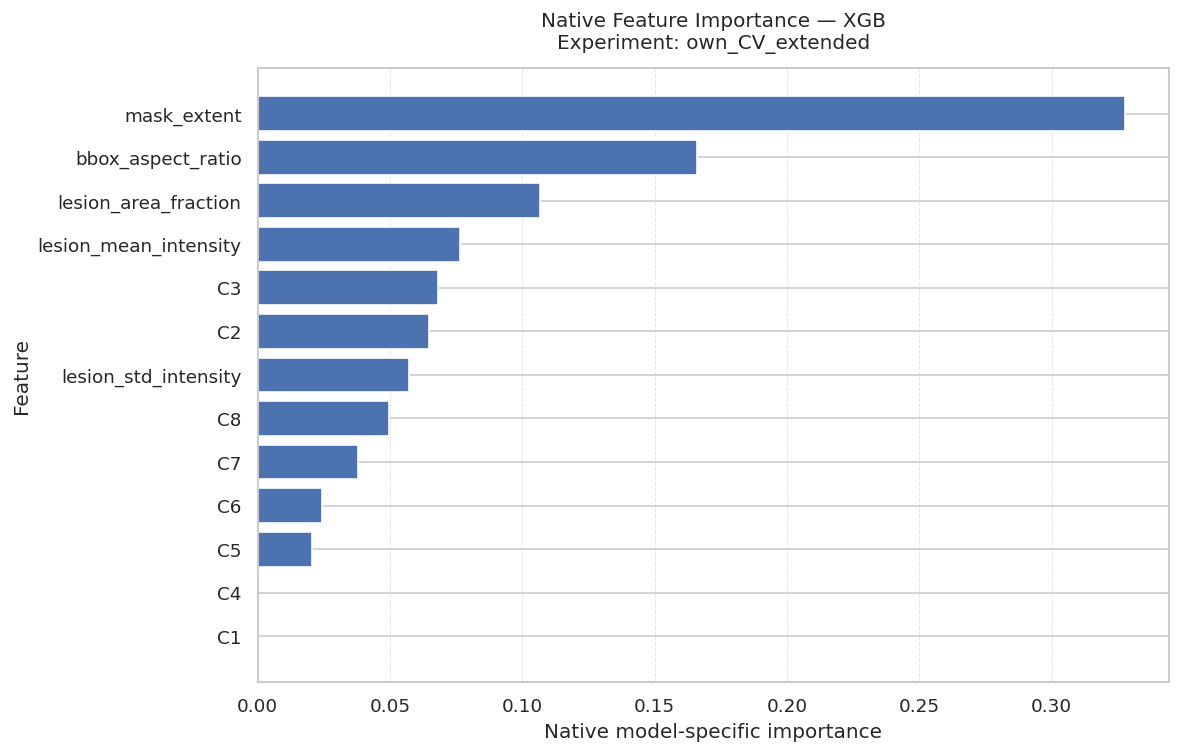

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CV_extended_XGB.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CV_extended_XGB.pdf


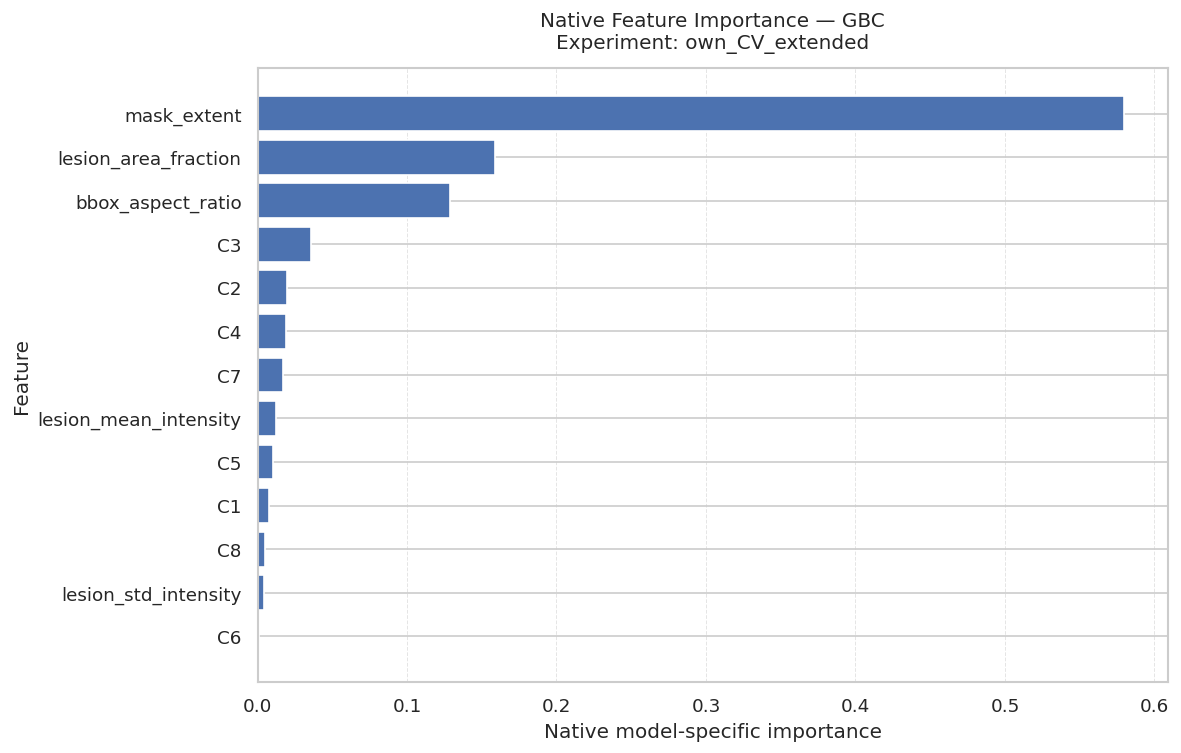

Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CV_extended_GBC.png
Saved native-importance figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/native_importance_own_CV_extended_GBC.pdf

TOP PERMUTATION-IMPORTANCE FEATURES


,experiment,model,feature,permutation_auc_importance_mean,permutation_auc_importance_sd,permutation_auc_importance_median,permutation_auc_importance_min,permutation_auc_importance_max,n_permutation_repeats,n_test_samples,n_features,scoring,positive_class_for_scoring,evaluation_split
0,own_CH_raw,GBC,CH5,0.166900,0.026354,0.167920,0.112762,0.228497,30,162,8,roc_auc,Benign (1),holdout
1,own_CH_raw,GBC,CH3,0.072855,0.028339,0.072378,0.010140,0.127797,30,162,8,roc_auc,Benign (1),holdout
2,own_CH_raw,GBC,CH2,0.071655,0.019507,0.070192,0.031818,0.101224,30,162,8,roc_auc,Benign (1),holdout
3,own_CH_raw,GBC,CH7,0.012340,0.017156,0.010358,-0.021329,0.047378,30,162,8,roc_auc,Benign (1),holdout
4,own_CH_raw,GBC,CH6,0.008479,0.009604,0.008304,-0.008916,0.029371,30,162,8,roc_auc,Benign (1),holdout
5,own_CH_raw,L1_Logistic,CH2,0.191113,0.046424,0.190472,0.071329,0.277098,30,162,8,roc_auc,Benign (1),holdout
6,own_CH_raw,L1_Logistic,CH4,0.006369,0.004000,0.007168,-0.002448,0.014161,30,162,8,roc_auc,Benign (1),holdout
7,own_CH_raw,L1_Logistic,CH3,0.004959,0.006487,0.004545,-0.007168,0.016958,30,162,8,roc_auc,Benign (1),holdout
8,own_CH_raw,L1_Logistic,CH5,0.000000,0.000000,0.000000,0.000000,0.000000,30,162,8,roc_auc,Benign (1),holdout
9,own_CH_raw,L1_Logistic,CH6,0.000000,0.000000,0.000000,0.000000,0.000000,30,162,8,roc_auc,Benign (1),holdout



Note: the table above sorts by mean importance, not absolute importance. Negative values remain available in the complete summary and repeat-level CSV files.

NATIVE TREE-IMPORTANCE TABLE


,experiment,model,feature,importance,importance_normalized,importance_method,recognized_eight_bin_baseline,paper_threshold_applicable,paper_threshold_0_125_selected
0,own_CH_raw,GBC,CH3,0.556791,0.556791,native_tree_importance,True,True,True
1,own_CH_raw,GBC,CH1,0.129947,0.129947,native_tree_importance,True,True,True
2,own_CH_raw,GBC,CH5,0.062721,0.062721,native_tree_importance,True,True,False
3,own_CH_raw,GBC,CH7,0.059993,0.059993,native_tree_importance,True,True,False
4,own_CH_raw,GBC,CH2,0.058896,0.058896,native_tree_importance,True,True,False
...,...,...,...,...,...,...,...,...,...
82,own_C_ratio,XGB,C3,0.124754,0.124754,native_tree_importance,True,True,False
83,own_C_ratio,XGB,C6,0.123204,0.123204,native_tree_importance,True,True,False
84,own_C_ratio,XGB,C2,0.104734,0.104734,native_tree_importance,True,True,False
85,own_C_ratio,XGB,C8,0.099257,0.099257,native_tree_importance,True,True,False



CELL 13 — OUTPUT SUMMARY
Permutation summary CSV : /content/drive/MyDrive/BUSI_paper_reproduction/csv/permutation_importance_holdout.csv
Permutation repeats CSV : /content/drive/MyDrive/BUSI_paper_reproduction/csv/permutation_importance_repeats.csv
Permutation errors CSV  : /content/drive/MyDrive/BUSI_paper_reproduction/csv/permutation_importance_errors.csv
Native importance CSV   : /content/drive/MyDrive/BUSI_paper_reproduction/csv/native_tree_importance.csv

Permutation summary rows: 116
Permutation repeat rows:  3480
Native importance rows:   87
Recorded errors:           0

Cell 13 completed. Treat hold-out feature importance as post-hoc interpretation; do not use these results to select features or tune models.


In [19]:
# ============================================================
# Cell 13 — Permutation Importance and Native Feature Importance
# ============================================================
# Purpose:
#   1. Compute hold-out permutation importance for evaluated models.
#   2. Quantify the change in ROC-AUC caused by permuting each feature.
#   3. Save individual permutation-repeat results for reproducibility.
#   4. Visualize mean permutation importance and repeat variability.
#   5. Extract and visualize native importance from tree-based classifiers.
#   6. Save structured outputs and detailed computation-error reports.
#
# Class convention:
#   0 = Malignant
#   1 = Benign
#
# Interpretation:
#   - Positive importance: shuffling the feature decreases ROC-AUC.
#   - Near-zero importance: shuffling the feature has little effect.
#   - Negative importance: shuffling the feature increases ROC-AUC.
#   - Repeat SD describes variability across permutations; it is not a CI.
#   - Native importance is model-dependent and is not causal importance.
#
# Methodological safeguards:
#   - Hold-out importance is post-hoc interpretation, not feature selection.
#   - The model must already have been fitted in Cell 9.
#   - Features, labels, IDs, and fitted-model inputs are validated.
#   - Different experiments are not aligned by row position.
#   - Permutation scores and native importance are stored separately.
#   - Native importance is plotted separately for each model.
#   - Failed computations are logged instead of being silently omitted.
#
# ROC-AUC convention:
#   sklearn's "roc_auc" scorer uses the score for class 1 by default.
#   Here, class 1 is Benign. Reversing both labels and corresponding
#   class probabilities preserves ROC-AUC, provided the reversal is
#   performed consistently.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and prerequisite validation
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
import re
import traceback
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance


_REQUIRED_GLOBALS = [
    "experiment_results",
    "SEED",
    "FIG_DIR",
    "CSV_DIR",
]

_missing_globals = [
    variable_name
    for variable_name in _REQUIRED_GLOBALS
    if variable_name not in globals()
]

if _missing_globals:
    raise RuntimeError(
        "Required objects are missing. Run the preceding cells first. "
        f"Missing objects: {_missing_globals}"
    )

if not isinstance(experiment_results, dict):
    raise TypeError(
        "experiment_results must be a dictionary created by Cell 11."
    )

SEED = int(SEED)

FIG_DIR = Path(FIG_DIR)
CSV_DIR = Path(CSV_DIR)

FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Analysis configuration and output schemas
# ------------------------------------------------------------

# Increase the number of repeats for more stable estimates at additional cost.
N_PERMUTATION_REPEATS = 30

# Maximum number of features displayed in each importance figure.
TOP_N_FEATURES = 20

# These names correspond to the tree-based classifiers in the evaluation
# pipeline. Common aliases are recognized later if the names differ.
TREE_MODEL_NAMES = ["RF", "XGB", "GBC"]

# Fix the scoring convention for reproducibility.
PERMUTATION_SCORING = "roc_auc"

# Do not use this post-hoc importance analysis to select features or models.
IMPORTANCE_EVALUATION_SPLIT = "holdout"

PERMUTATION_SUMMARY_COLUMNS = [
    "experiment",
    "model",
    "feature",
    "permutation_auc_importance_mean",
    "permutation_auc_importance_sd",
    "permutation_auc_importance_median",
    "permutation_auc_importance_min",
    "permutation_auc_importance_max",
    "n_permutation_repeats",
    "n_test_samples",
    "n_features",
    "scoring",
    "positive_class_for_scoring",
    "evaluation_split",
]

PERMUTATION_REPEAT_COLUMNS = [
    "experiment",
    "model",
    "feature",
    "repeat_index",
    "permutation_auc_importance",
    "scoring",
]

PERMUTATION_ERROR_COLUMNS = [
    "experiment",
    "model",
    "stage",
    "error_type",
    "error_message",
    "traceback",
    "recorded_at_utc",
]

permutation_rows = []
permutation_repeat_rows = []
permutation_error_rows = []


# ------------------------------------------------------------
# 3. Define output paths
# ------------------------------------------------------------

PERMUTATION_SUMMARY_PATH = (
    CSV_DIR / "permutation_importance_holdout.csv"
)

PERMUTATION_REPEATS_PATH = (
    CSV_DIR / "permutation_importance_repeats.csv"
)

PERMUTATION_ERRORS_PATH = (
    CSV_DIR / "permutation_importance_errors.csv"
)

NATIVE_IMPORTANCE_PATH = (
    CSV_DIR / "native_tree_importance.csv"
)


# ------------------------------------------------------------
# 4. Define reusable validation and persistence functions
# ------------------------------------------------------------

def record_permutation_error(
    experiment_name,
    model_name,
    stage,
    exception,
):
    """Store a complete, traceable computation error."""

    permutation_error_rows.append({
        "experiment": str(experiment_name),
        "model": (
            None if model_name is None else str(model_name)
        ),
        "stage": str(stage),
        "error_type": type(exception).__name__,
        "error_message": str(exception),
        "traceback": traceback.format_exc(),
        "recorded_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
    })


def persist_permutation_outputs():
    """
    Incrementally save the current permutation results and computation errors.

    This protects already completed model results if a later model fails.
    """

    current_summary = pd.DataFrame(
        permutation_rows,
        columns=PERMUTATION_SUMMARY_COLUMNS,
    )

    current_repeats = pd.DataFrame(
        permutation_repeat_rows,
        columns=PERMUTATION_REPEAT_COLUMNS,
    )

    current_errors = pd.DataFrame(
        permutation_error_rows,
        columns=PERMUTATION_ERROR_COLUMNS,
    )

    current_summary.to_csv(
        PERMUTATION_SUMMARY_PATH,
        index=False,
    )

    current_repeats.to_csv(
        PERMUTATION_REPEATS_PATH,
        index=False,
    )

    current_errors.to_csv(
        PERMUTATION_ERRORS_PATH,
        index=False,
    )


def get_first_available_key(mapping, candidate_keys, description):
    """
    Return the first available non-None value from a prediction dictionary.
    """

    for key in candidate_keys:

        if key in mapping and mapping[key] is not None:
            return mapping[key], key

    raise KeyError(
        f"Could not locate {description}. "
        f"Expected one of these keys: {list(candidate_keys)}."
    )


def normalize_binary_targets(y_raw, description):
    """
    Validate a binary target vector using the fixed encoding:
    0 = Malignant, 1 = Benign.
    """

    y_array = np.asarray(y_raw)

    if y_array.ndim != 1:
        raise ValueError(
            f"{description} must be one-dimensional; "
            f"received shape {y_array.shape}."
        )

    if y_array.size == 0:
        raise ValueError(
            f"{description} contains no observations."
        )

    numeric_series = pd.to_numeric(
        pd.Series(y_array),
        errors="coerce",
    )

    if numeric_series.isna().any():
        raise ValueError(
            f"{description} contains missing or non-numeric labels."
        )

    y_numeric = numeric_series.to_numpy(dtype=float)

    if not np.isfinite(y_numeric).all():
        raise ValueError(
            f"{description} contains non-finite labels."
        )

    if not np.isin(y_numeric, [0.0, 1.0]).all():
        raise ValueError(
            f"{description} must contain only labels 0 and 1. "
            f"Observed labels: {sorted(np.unique(y_numeric).tolist())}."
        )

    observed_classes = set(
        np.unique(y_numeric).astype(int).tolist()
    )

    if observed_classes != {0, 1}:
        raise ValueError(
            "ROC-AUC permutation importance requires both classes in the "
            f"hold-out set. Observed classes: {observed_classes}."
        )

    return y_numeric.astype(int)


def validate_permutation_inputs(
    experiment_name,
    model_name,
    fitted_model,
    prediction_info,
):
    """
    Validate hold-out data and compatibility with the fitted estimator.

    The feature matrix is copied before numeric validation. Its column names
    and order are preserved so that the fitted estimator receives the same
    features used during training.
    """

    if not isinstance(prediction_info, dict):
        raise TypeError(
            "The model prediction record must be a dictionary."
        )

    X_test_raw, x_source_key = get_first_available_key(
        prediction_info,
        candidate_keys=("X_test",),
        description="hold-out feature matrix",
    )

    y_test_raw, y_source_key = get_first_available_key(
        prediction_info,
        candidate_keys=("y_test", "y_true"),
        description="hold-out target labels",
    )

    if not isinstance(X_test_raw, pd.DataFrame):
        raise TypeError(
            "X_test must be a pandas DataFrame so feature names and "
            "column ordering remain explicit."
        )

    if X_test_raw.empty:
        raise ValueError(
            "X_test contains no samples or no feature columns."
        )

    if not X_test_raw.columns.is_unique:
        raise ValueError(
            "X_test contains duplicate feature names."
        )

    if X_test_raw.columns.isna().any():
        raise ValueError(
            "X_test contains missing feature names."
        )

    if not all(
        isinstance(column, str)
        for column in X_test_raw.columns
    ):
        raise TypeError(
            "All X_test feature names must be strings. This avoids "
            "inconsistent column-name comparisons against the fitted model."
        )

    if any(
        not column.strip()
        for column in X_test_raw.columns
    ):
        raise ValueError(
            "X_test contains blank feature names."
        )

    # Validate numeric values without modifying the original registered data.
    X_test = X_test_raw.copy().apply(
        pd.to_numeric,
        errors="raise",
    )

    X_array = X_test.to_numpy(dtype=np.float64)

    if not np.isfinite(X_array).all():
        raise ValueError(
            "X_test contains NaN or infinite feature values."
        )

    y_test = normalize_binary_targets(
        y_test_raw,
        description=f"{experiment_name}/{model_name} hold-out labels",
    )

    if len(X_test) != len(y_test):
        raise ValueError(
            f"X_test has {len(X_test)} rows, but y_test has "
            f"{len(y_test)} labels."
        )

    # Confirm that the number of features matches the fitted model.
    if hasattr(fitted_model, "n_features_in_"):

        expected_n_features = int(
            fitted_model.n_features_in_
        )

        if expected_n_features != X_test.shape[1]:
            raise ValueError(
                f"The fitted model expects {expected_n_features} features, "
                f"but X_test contains {X_test.shape[1]}."
            )

    # When feature names are exposed by the estimator, verify their exact order.
    if hasattr(fitted_model, "feature_names_in_"):

        fitted_feature_names = list(
            fitted_model.feature_names_in_
        )

        holdout_feature_names = list(
            X_test.columns
        )

        if fitted_feature_names != holdout_feature_names:
            raise ValueError(
                "X_test feature names or feature ordering do not match "
                "the names/order used when the estimator was fitted."
            )

    # Check the fitted class labels if the estimator exposes them.
    if hasattr(fitted_model, "classes_"):

        fitted_classes = set(
            np.asarray(fitted_model.classes_).tolist()
        )

        if fitted_classes != {0, 1}:
            raise ValueError(
                "The fitted estimator does not expose the expected binary "
                f"class labels {{0, 1}}. Observed: {fitted_classes}."
            )

    # Validate optional hold-out IDs. These are used only to compare model
    # records within the same experiment, never to align different datasets.
    test_ids = None
    ids_source_key = None

    for ids_key in ("test_ids", "sample_ids_test"):

        if (
            ids_key in prediction_info
            and prediction_info[ids_key] is not None
        ):

            ids_array = np.asarray(
                prediction_info[ids_key],
                dtype=object,
            )

            if ids_array.ndim != 1:
                raise ValueError(
                    f"{ids_key} must be one-dimensional."
                )

            if ids_array.size != len(X_test):
                raise ValueError(
                    f"{ids_key} length does not match X_test."
                )

            ids_series = pd.Series(ids_array)

            if ids_series.isna().any():
                raise ValueError(
                    f"{ids_key} contains missing identifiers."
                )

            ids_series = ids_series.astype(str).str.strip()

            if ids_series.eq("").any():
                raise ValueError(
                    f"{ids_key} contains blank identifiers."
                )

            if ids_series.duplicated().any():
                raise ValueError(
                    f"{ids_key} contains duplicated hold-out identifiers."
                )

            test_ids = ids_series.to_numpy(dtype=str)
            ids_source_key = ids_key
            break

    return {
        "X_test": X_test,
        "y_test": y_test,
        "test_ids": test_ids,
        "x_source_key": x_source_key,
        "y_source_key": y_source_key,
        "ids_source_key": ids_source_key,
    }


# ------------------------------------------------------------
# 5. Compute hold-out permutation importance
# ------------------------------------------------------------

print("=" * 78)
print("HOLD-OUT PERMUTATION IMPORTANCE")
print("=" * 78)

# Retain a reference for checking hold-out order within each experiment.
holdout_references = {}

for experiment_name, experiment_result in experiment_results.items():

    print("\n" + "=" * 78)
    print(f"EXPERIMENT: {experiment_name}")
    print("=" * 78)

    if not isinstance(experiment_result, dict):

        exception = TypeError(
            "Experiment result must be a dictionary."
        )

        record_permutation_error(
            experiment_name,
            None,
            "validate_experiment_result",
            exception,
        )

        persist_permutation_outputs()

        warnings.warn(
            f"Skipping {experiment_name}: invalid experiment-result structure.",
            RuntimeWarning,
        )

        continue

    fitted_models = experiment_result.get("models", {})
    test_predictions = experiment_result.get("test_predictions", {})

    if not isinstance(fitted_models, dict):

        exception = TypeError(
            "The experiment's 'models' entry must be a dictionary."
        )

        record_permutation_error(
            experiment_name,
            None,
            "validate_model_registry",
            exception,
        )

        persist_permutation_outputs()
        continue

    if not isinstance(test_predictions, dict):

        exception = TypeError(
            "The experiment's 'test_predictions' entry must be a dictionary."
        )

        record_permutation_error(
            experiment_name,
            None,
            "validate_prediction_registry",
            exception,
        )

        persist_permutation_outputs()
        continue

    if not test_predictions:

        exception = ValueError(
            "No per-model hold-out prediction records were stored."
        )

        record_permutation_error(
            experiment_name,
            None,
            "validate_prediction_registry",
            exception,
        )

        persist_permutation_outputs()
        continue

    for model_name, prediction_info in test_predictions.items():

        print(f"\nModel: {model_name}")

        try:

            # Match each prediction record to its fitted estimator.
            if model_name not in fitted_models:
                raise KeyError(
                    f"Fitted model '{model_name}' is missing from "
                    "the experiment's model registry."
                )

            fitted_model = fitted_models[model_name]

            if fitted_model is None:
                raise ValueError(
                    "The fitted estimator is None."
                )

            prepared = validate_permutation_inputs(
                experiment_name=experiment_name,
                model_name=model_name,
                fitted_model=fitted_model,
                prediction_info=prediction_info,
            )

            X_test = prepared["X_test"]
            y_test = prepared["y_test"]
            test_ids = prepared["test_ids"]

            # Models within an experiment must share the same hold-out
            # target ordering. Do not compare IDs across unrelated datasets.
            current_reference = holdout_references.get(
                experiment_name
            )

            if current_reference is None:

                holdout_references[experiment_name] = {
                    "y_test": y_test.copy(),
                    "test_ids": (
                        None if test_ids is None else test_ids.copy()
                    ),
                }

            else:

                if not np.array_equal(
                    current_reference["y_test"],
                    y_test,
                ):
                    raise ValueError(
                        "True hold-out labels/order differ across models "
                        "within the same experiment."
                    )

                reference_ids = current_reference["test_ids"]

                if (
                    reference_ids is not None
                    and test_ids is not None
                    and not np.array_equal(reference_ids, test_ids)
                ):
                    raise ValueError(
                        "Hold-out sample IDs/order differ across models "
                        "within the same experiment."
                    )

                if (
                    (reference_ids is None) != (test_ids is None)
                ):
                    warnings.warn(
                        f"{experiment_name}/{model_name}: hold-out IDs are "
                        "not stored consistently across all models. Label "
                        "ordering has been checked, but ID-level consistency "
                        "cannot be fully verified.",
                        RuntimeWarning,
                    )

            # Compute permutation importance on the held-out data.
            # This is an interpretation step, not a feature-selection step.
            permutation_result = permutation_importance(
                estimator=fitted_model,
                X=X_test,
                y=y_test,
                scoring=PERMUTATION_SCORING,
                n_repeats=N_PERMUTATION_REPEATS,
                random_state=SEED,
                n_jobs=1,
            )

            # Raw importances have shape (n_features, n_repeats).
            raw_importances = np.asarray(
                permutation_result.importances,
                dtype=float,
            )

            expected_shape = (
                X_test.shape[1],
                N_PERMUTATION_REPEATS,
            )

            if raw_importances.shape != expected_shape:
                raise RuntimeError(
                    "Unexpected permutation-result shape. "
                    f"Expected {expected_shape}; "
                    f"received {raw_importances.shape}."
                )

            if not np.isfinite(raw_importances).all():
                raise ValueError(
                    "The permutation-importance matrix contains "
                    "non-finite values."
                )

            # Recompute summary statistics from the raw repeat values so
            # the saved repeat table and summary table remain consistent.
            for feature_index, feature_name in enumerate(X_test.columns):

                repeat_values = raw_importances[feature_index, :]

                feature_mean = float(
                    np.mean(repeat_values)
                )

                feature_sd = float(
                    np.std(repeat_values, ddof=0)
                )

                feature_median = float(
                    np.median(repeat_values)
                )

                feature_min = float(
                    np.min(repeat_values)
                )

                feature_max = float(
                    np.max(repeat_values)
                )

                permutation_rows.append({
                    "experiment": str(experiment_name),
                    "model": str(model_name),
                    "feature": str(feature_name),
                    "permutation_auc_importance_mean": feature_mean,
                    "permutation_auc_importance_sd": feature_sd,
                    "permutation_auc_importance_median": feature_median,
                    "permutation_auc_importance_min": feature_min,
                    "permutation_auc_importance_max": feature_max,
                    "n_permutation_repeats": int(
                        N_PERMUTATION_REPEATS
                    ),
                    "n_test_samples": int(len(X_test)),
                    "n_features": int(X_test.shape[1]),
                    "scoring": PERMUTATION_SCORING,
                    "positive_class_for_scoring": "Benign (1)",
                    "evaluation_split": IMPORTANCE_EVALUATION_SPLIT,
                })

                # Preserve each repeat, not only its aggregate statistics.
                for repeat_index, repeat_importance in enumerate(
                    repeat_values,
                    start=1,
                ):

                    permutation_repeat_rows.append({
                        "experiment": str(experiment_name),
                        "model": str(model_name),
                        "feature": str(feature_name),
                        "repeat_index": int(repeat_index),
                        "permutation_auc_importance": float(
                            repeat_importance
                        ),
                        "scoring": PERMUTATION_SCORING,
                    })

            # Save completed results immediately.
            persist_permutation_outputs()

            print(
                f"Completed successfully: {X_test.shape[1]} features, "
                f"{N_PERMUTATION_REPEATS} repeats, "
                f"{len(X_test)} hold-out samples."
            )

        except Exception as exc:

            record_permutation_error(
                experiment_name,
                model_name,
                "compute_permutation_importance",
                exc,
            )

            persist_permutation_outputs()

            warnings.warn(
                f"Permutation importance failed for "
                f"{experiment_name}/{model_name}: "
                f"{type(exc).__name__}: {exc}",
                RuntimeWarning,
            )


# ------------------------------------------------------------
# 6. Finalize permutation tables
# ------------------------------------------------------------

perm_df = pd.DataFrame(
    permutation_rows,
    columns=PERMUTATION_SUMMARY_COLUMNS,
)

perm_repeats_df = pd.DataFrame(
    permutation_repeat_rows,
    columns=PERMUTATION_REPEAT_COLUMNS,
)

perm_errors_df = pd.DataFrame(
    permutation_error_rows,
    columns=PERMUTATION_ERROR_COLUMNS,
)

# Save final versions even when no model completed successfully.
perm_df.to_csv(
    PERMUTATION_SUMMARY_PATH,
    index=False,
)

perm_repeats_df.to_csv(
    PERMUTATION_REPEATS_PATH,
    index=False,
)

perm_errors_df.to_csv(
    PERMUTATION_ERRORS_PATH,
    index=False,
)

print("\n" + "=" * 78)
print("PERMUTATION-IMPORTANCE SUMMARY")
print("=" * 78)
print(f"Feature-level summary rows: {len(perm_df)}")
print(f"Individual repeat rows:     {len(perm_repeats_df)}")
print(f"Recorded computation errors: {len(perm_errors_df)}")
print(f"Summary CSV: {PERMUTATION_SUMMARY_PATH}")
print(f"Repeats CSV: {PERMUTATION_REPEATS_PATH}")
print(f"Errors CSV:  {PERMUTATION_ERRORS_PATH}")


# ------------------------------------------------------------
# 7. Plot permutation importance by experiment
# ------------------------------------------------------------

if not perm_df.empty:

    for experiment_name in perm_df["experiment"].drop_duplicates():

        experiment_perm = perm_df[
            perm_df["experiment"] == experiment_name
        ].copy()

        if experiment_perm.empty:
            continue

        # Select a shared plotting subset by the largest absolute mean
        # decrease in ROC-AUC across the models in this experiment.
        # Negative importance values are retained in the visualization.
        feature_priority = (
            experiment_perm.assign(
                absolute_mean_importance=lambda frame: (
                    frame["permutation_auc_importance_mean"].abs()
                )
            )
            .groupby(
                "feature",
                as_index=False,
            )["absolute_mean_importance"]
            .max()
            .sort_values(
                "absolute_mean_importance",
                ascending=False,
            )
        )

        selected_features = feature_priority[
            "feature"
        ].head(TOP_N_FEATURES).tolist()

        plot_df = experiment_perm[
            experiment_perm["feature"].isin(selected_features)
        ].copy()

        if plot_df.empty:
            continue

        feature_order = [
            feature
            for feature in selected_features
            if feature in set(plot_df["feature"])
        ]

        model_order = plot_df["model"].drop_duplicates().tolist()

        n_features = len(feature_order)
        n_models = len(model_order)

        fig_height = max(
            5.5,
            0.42 * n_features + 1.5,
        )

        fig, ax = plt.subplots(
            figsize=(11, fig_height)
        )

        y_positions = np.arange(n_features)

        # Keep model estimates close to each feature's central row.
        vertical_offsets = (
            np.array([0.0])
            if n_models == 1
            else np.linspace(-0.22, 0.22, n_models)
        )

        for offset, model_name in zip(
            vertical_offsets,
            model_order,
        ):

            model_df = plot_df[
                plot_df["model"] == model_name
            ].set_index("feature")

            x_values = []
            x_errors = []
            y_values = []

            for feature_position, feature_name in enumerate(
                feature_order
            ):

                if feature_name not in model_df.index:
                    continue

                feature_record = model_df.loc[feature_name]

                # Defensive handling in case duplicate keys survived upstream.
                if isinstance(feature_record, pd.DataFrame):
                    feature_record = feature_record.iloc[0]

                mean_value = float(
                    feature_record[
                        "permutation_auc_importance_mean"
                    ]
                )

                sd_value = float(
                    feature_record[
                        "permutation_auc_importance_sd"
                    ]
                )

                x_values.append(mean_value)
                x_errors.append(sd_value)
                y_values.append(
                    feature_position + offset
                )

            if x_values:

                ax.errorbar(
                    x=x_values,
                    y=y_values,
                    xerr=x_errors,
                    fmt="o",
                    markersize=5,
                    capsize=3,
                    linewidth=1.2,
                    label=model_name,
                )

        # Zero represents no mean decrease in ROC-AUC after permutation.
        ax.axvline(
            0.0,
            linestyle="--",
            linewidth=1,
            alpha=0.8,
        )

        ax.set_yticks(y_positions)
        ax.set_yticklabels(feature_order)
        ax.invert_yaxis()

        ax.set_xlabel(
            "Mean decrease in ROC-AUC after feature permutation"
        )
        ax.set_ylabel("Feature")

        ax.set_title(
            f"Hold-out Permutation Importance: {experiment_name}",
            fontsize=12,
            pad=12,
        )

        ax.grid(
            axis="x",
            linestyle="--",
            linewidth=0.6,
            alpha=0.5,
        )

        ax.set_axisbelow(True)

        ax.legend(
            title="Model",
            loc="best",
        )

        fig.tight_layout()

        # Sanitize names so output paths remain portable.
        experiment_slug = re.sub(
            r"[^A-Za-z0-9_.-]+",
            "_",
            str(experiment_name),
        ).strip("._")

        if not experiment_slug:
            experiment_slug = "experiment"

        figure_png_path = (
            FIG_DIR
            / f"permutation_importance_{experiment_slug}.png"
        )

        figure_pdf_path = (
            FIG_DIR
            / f"permutation_importance_{experiment_slug}.pdf"
        )

        fig.savefig(
            figure_png_path,
            dpi=300,
            bbox_inches="tight",
        )

        fig.savefig(
            figure_pdf_path,
            bbox_inches="tight",
        )

        plt.show()
        plt.close(fig)

        print(f"Saved permutation figure: {figure_png_path}")
        print(f"Saved permutation figure: {figure_pdf_path}")

else:
    print(
        "No permutation-importance estimates are available. "
        "Permutation plots have been skipped."
    )


# ------------------------------------------------------------
# 8. Validate native feature importance from the evaluation pipeline
# ------------------------------------------------------------

# Native tree-based importance is obtained from Cell 11's aggregate table.
# It is kept separate from permutation importance because their definitions
# and numerical scales are different.

NATIVE_IMPORTANCE_COLUMNS = {
    "experiment",
    "model",
    "feature",
    "importance",
}

if (
    "importance_df" in globals()
    and isinstance(importance_df, pd.DataFrame)
):

    missing_native_columns = (
        NATIVE_IMPORTANCE_COLUMNS - set(importance_df.columns)
    )

    if missing_native_columns:

        warnings.warn(
            "Native importance plotting is unavailable because "
            "importance_df is missing required columns: "
            f"{sorted(missing_native_columns)}.",
            RuntimeWarning,
        )

        native_df = pd.DataFrame(
            columns=[
                "experiment",
                "model",
                "feature",
                "importance",
            ]
        )

    else:
        native_df = importance_df.copy()

else:

    warnings.warn(
        "importance_df is missing or has an unexpected type. "
        "Native-importance analysis will be skipped.",
        RuntimeWarning,
    )

    native_df = pd.DataFrame(
        columns=[
            "experiment",
            "model",
            "feature",
            "importance",
        ]
    )


def is_tree_model_name(model_name):
    """
    Recognize common names for the three evaluated tree-based classifiers.
    """

    compact_name = re.sub(
        r"[^A-Za-z0-9]+",
        "",
        str(model_name),
    ).upper()

    recognized_names = {
        "RF",
        "RANDOMFOREST",
        "RANDOMFORESTCLASSIFIER",
        "XGB",
        "XGBOOST",
        "XGBOOSTCLASSIFIER",
        "GBC",
        "GRADIENTBOOSTING",
        "GRADIENTBOOSTINGCLASSIFIER",
    }

    return compact_name in recognized_names


if not native_df.empty:

    native_df["experiment"] = native_df["experiment"].astype(str)
    native_df["model"] = native_df["model"].astype(str)
    native_df["feature"] = native_df["feature"].astype(str)

    native_df["importance"] = pd.to_numeric(
        native_df["importance"],
        errors="coerce",
    )

    # Restrict this analysis to RF, XGB, and GBC native importance records.
    native_df = native_df[
        native_df["model"].apply(is_tree_model_name)
        & native_df["importance"].notna()
        & np.isfinite(native_df["importance"])
    ].copy()

    # A tree's native impurity-based importance should generally be
    # non-negative. Negative values may indicate that the upstream table
    # actually contains signed coefficients or a different importance type.
    if (native_df["importance"] < 0).any():

        warnings.warn(
            "Negative values were found in native tree-importance records. "
            "Check the 'importance' definition generated by Cell 9. The "
            "values will be preserved in the exported table.",
            RuntimeWarning,
        )

    # Consolidate exact duplicate experiment/model/feature records.
    # If Cell 11 accidentally duplicated the same record, this prevents
    # duplicate bars. Aggregation is recorded in the exported data.
    duplicate_native_records = native_df.duplicated(
        subset=["experiment", "model", "feature"],
        keep=False,
    )

    if duplicate_native_records.any():

        warnings.warn(
            "Repeated native-importance rows were found. Their values will "
            "be averaged per experiment/model/feature for plotting and "
            "export; inspect the upstream importance table if repetitions "
            "were not expected.",
            RuntimeWarning,
        )

        native_df = (
            native_df.groupby(
                ["experiment", "model", "feature"],
                as_index=False,
            )["importance"]
            .mean()
        )

# Save the validated native-importance table used below.
native_df.to_csv(
    NATIVE_IMPORTANCE_PATH,
    index=False,
)

print("\n" + "=" * 78)
print("NATIVE TREE-BASED FEATURE IMPORTANCE")
print("=" * 78)
print(f"Native importance rows: {len(native_df)}")
print(f"Native importance CSV: {NATIVE_IMPORTANCE_PATH}")


# ------------------------------------------------------------
# 9. Plot native importance separately for each model
# ------------------------------------------------------------

if not native_df.empty:

    for (experiment_name, model_name), model_native_df in (
        native_df.groupby(
            ["experiment", "model"],
            sort=False,
        )
    ):

        if model_native_df.empty:
            continue

        # Native feature-importance scales depend on the estimator.
        # Therefore, each model gets its own figure and ranking.
        model_native_df = model_native_df.sort_values(
            "importance",
            ascending=False,
        ).head(TOP_N_FEATURES)

        # Reverse rows so the largest importance is at the top of the plot.
        model_native_df = model_native_df.iloc[::-1].copy()

        figure_height = max(
            4.5,
            0.38 * len(model_native_df) + 1.5,
        )

        fig, ax = plt.subplots(
            figsize=(10, figure_height)
        )

        ax.barh(
            model_native_df["feature"],
            model_native_df["importance"],
        )

        ax.set_xlabel(
            "Native model-specific importance"
        )

        ax.set_ylabel("Feature")

        ax.set_title(
            f"Native Feature Importance — {model_name}\n"
            f"Experiment: {experiment_name}",
            fontsize=12,
            pad=12,
        )

        ax.grid(
            axis="x",
            linestyle="--",
            linewidth=0.6,
            alpha=0.5,
        )

        ax.set_axisbelow(True)
        fig.tight_layout()

        experiment_slug = re.sub(
            r"[^A-Za-z0-9_.-]+",
            "_",
            str(experiment_name),
        ).strip("._") or "experiment"

        model_slug = re.sub(
            r"[^A-Za-z0-9_.-]+",
            "_",
            str(model_name),
        ).strip("._") or "model"

        native_png_path = (
            FIG_DIR
            / f"native_importance_{experiment_slug}_{model_slug}.png"
        )

        native_pdf_path = (
            FIG_DIR
            / f"native_importance_{experiment_slug}_{model_slug}.pdf"
        )

        fig.savefig(
            native_png_path,
            dpi=300,
            bbox_inches="tight",
        )

        fig.savefig(
            native_pdf_path,
            bbox_inches="tight",
        )

        plt.show()
        plt.close(fig)

        print(f"Saved native-importance figure: {native_png_path}")
        print(f"Saved native-importance figure: {native_pdf_path}")

else:
    print(
        "No valid RF/XGB/GBC native-importance records are available "
        "for visualization."
    )


# ------------------------------------------------------------
# 10. Display consolidated results
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("TOP PERMUTATION-IMPORTANCE FEATURES")
print("=" * 78)

if not perm_df.empty:

    # Sort within each experiment/model. Positive and negative effects
    # are preserved in the full CSV; this table shows the largest positive
    # mean decreases in ROC-AUC first.
    top_positive_rows = (
        perm_df.sort_values(
            [
                "experiment",
                "model",
                "permutation_auc_importance_mean",
            ],
            ascending=[True, True, False],
        )
        .groupby(
            ["experiment", "model"],
            sort=False,
            group_keys=False,
        )
        .head(5)
        .reset_index(drop=True)
    )

    display(top_positive_rows)

    print(
        "\nNote: the table above sorts by mean importance, not absolute "
        "importance. Negative values remain available in the complete "
        "summary and repeat-level CSV files."
    )

else:
    print("No permutation-importance rows are available.")

print("\n" + "=" * 78)
print("NATIVE TREE-IMPORTANCE TABLE")
print("=" * 78)

if not native_df.empty:

    display(
        native_df.sort_values(
            ["experiment", "model", "importance"],
            ascending=[True, True, False],
        ).reset_index(drop=True)
    )

else:
    print("No native tree-importance rows are available.")


# ------------------------------------------------------------
# 11. Final output summary
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("CELL 13 — OUTPUT SUMMARY")
print("=" * 78)

print(f"Permutation summary CSV : {PERMUTATION_SUMMARY_PATH}")
print(f"Permutation repeats CSV : {PERMUTATION_REPEATS_PATH}")
print(f"Permutation errors CSV  : {PERMUTATION_ERRORS_PATH}")
print(f"Native importance CSV   : {NATIVE_IMPORTANCE_PATH}")

print(f"\nPermutation summary rows: {len(perm_df)}")
print(f"Permutation repeat rows:  {len(perm_repeats_df)}")
print(f"Native importance rows:   {len(native_df)}")
print(f"Recorded errors:           {len(perm_errors_df)}")

if not perm_errors_df.empty:
    print("\nPermutation-importance errors requiring review:")
    display(perm_errors_df)

print(
    "\nCell 13 completed. Treat hold-out feature importance as post-hoc "
    "interpretation; do not use these results to select features or tune models."
)

##Cell 14 — Algebraic Feature Validation and Correlation Analysis

FEATURE SOURCE
Selected source: own_df
Number of rows:  647
CH features:     ['CH1', 'CH2', 'CH3', 'CH4', 'CH5', 'CH6', 'CH7', 'CH8']
C features:      ['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8']

ALGEBRAIC FEATURE-IDENTITY VALIDATION


,feature_source,n_rows_total,n_rows_numeric_valid,n_rows_with_invalid_numeric_values,n_rows_eligible_for_algebraic_checks,n_rows_passing_all_checks,n_rows_failing_or_not_evaluated,n_CH_features,n_C_features,identity_tolerance_atol,...,all_evaluable_C_match_CH_over_area,all_evaluable_CH_sums_match_mask_area,all_evaluable_C_rows_sum_to_1,n_identity_failures,n_histogram_area_failures,n_ratio_sum_failures,n_ratio_range_failures,n_noninteger_histogram_rows,n_noninteger_mask_area_rows,all_evaluable_rows_pass_all_checks
0,own_df,647,647,0,647,647,0,8,8,1.000000e-08,...,True,True,True,0,0,0,0,0,0,True


Summary CSV:       /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_identity_checks.csv
Row-level audit:   /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_identity_row_audit.csv
Failed rows:       /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_identity_failed_rows.csv
Invalid cells:     /content/drive/MyDrive/BUSI_paper_reproduction/csv/feature_identity_invalid_values.csv
Every row passed numeric validation and all specified algebraic/physical consistency checks.

SPEARMAN CORRELATION ANALYSIS
Rows available for correlation: 647 / 647
Spearman correlation estimates monotonic association. Because C is derived from CH and mask area, correlation values do not establish independent information or causal relevance.
Correlation matrix: /content/drive/MyDrive/BUSI_paper_reproduction/csv/own_feature_spearman_correlation.csv
Pairwise counts:    /content/drive/MyDrive/BUSI_paper_reproduction/csv/own_feature_spearman_pairwise_n.csv


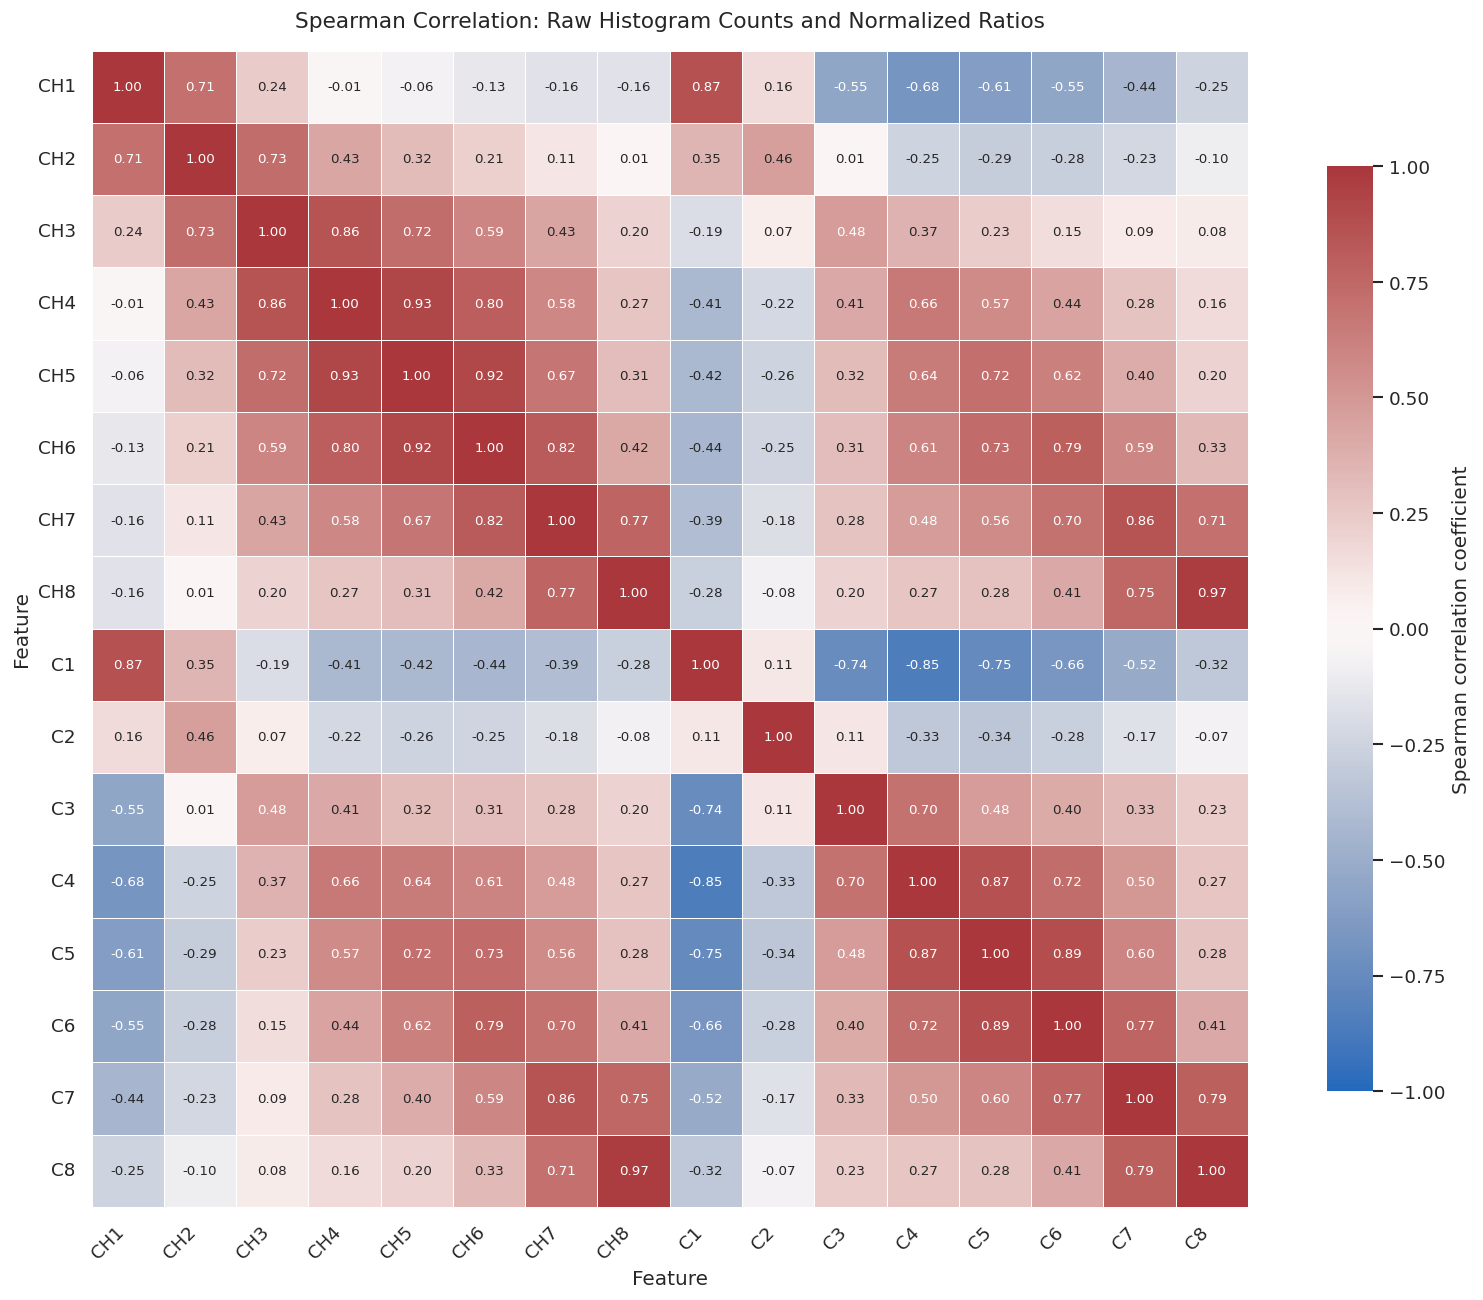

Saved correlation figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/own_feature_spearman_correlation.png
Saved correlation PDF:   /content/drive/MyDrive/BUSI_paper_reproduction/figures/own_feature_spearman_correlation.pdf

FINAL ALGEBRAIC VALIDATION REPORT
Feature source: own_df
Total rows: 647
Rows eligible for identities: 647
Rows passing every check: 647

Identity: C_i = CH_i / mask_area_px
Maximum absolute identity error: 0
Mean absolute identity error: 0
All evaluable rows satisfy C_i = CH_i / mask_area_px: True

Identity: sum(CH_i) = mask_area_px
Rows failing histogram-area identity: 0

Identity: sum(C_i) = 1
Rows failing normalized-ratio sum: 0

Cell 14 completed. Review the exported validation report before using these features in subsequent model comparisons.


In [20]:
# ============================================================
# Cell 14 — Algebraic Feature Validation and Correlation Analysis
# ============================================================
# Purpose:
#   1. Validate the mathematical relationship between raw histogram
#      counts (CH1-CH8) and normalized intensity ratios (C1-C8).
#   2. Verify that the sum of histogram counts equals the lesion-mask area.
#   3. Verify that normalized intensity ratios sum to one.
#   4. Produce row-level diagnostics with traceable source-row identifiers.
#   5. Compute and visualize Spearman correlations between CH and C features.
#   6. Export validation summaries, failed rows, correlation matrices,
#      and pairwise observation counts.
#
# Mathematical identities:
#   C_i = CH_i / mask_area_px
#   sum(CH_i) = mask_area_px
#   sum(C_i) = 1
#
# Methodological safeguards:
#   - Validate the independently extracted BUSI feature table.
#   - Never align records across datasets by row position.
#   - Do not silently delete invalid rows or repair feature values.
#   - Separate algebraic validation from correlation analysis.
#   - Report invalid and unevaluated rows explicitly.
#   - Preserve raw count features and normalized ratio features separately.
#
# Important interpretation:
#   CH and C are algebraically dependent feature representations.
#   They must not be interpreted as independent sources of information.
#   Spearman correlation measures monotonic association; it does not
#   establish independence, causation, or clinical validity.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and prerequisite validation
# ------------------------------------------------------------

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display


_REQUIRED_GLOBALS_CELL14 = [
    "CH_COLS",
    "C_COLS",
    "CSV_DIR",
    "FIG_DIR",
]

_missing_globals_cell14 = [
    variable_name
    for variable_name in _REQUIRED_GLOBALS_CELL14
    if variable_name not in globals()
]

if _missing_globals_cell14:
    raise RuntimeError(
        "Required variables are missing. Run the preceding cells first. "
        f"Missing variables: {_missing_globals_cell14}"
    )


# ------------------------------------------------------------
# 2. Define feature columns, tolerances, and output paths
# ------------------------------------------------------------

# Copy the feature-name lists locally to avoid unintentionally modifying
# the global feature configuration used by earlier notebook cells.
_CH_COLS = list(CH_COLS)
_C_COLS = list(C_COLS)

if len(_CH_COLS) != 8 or len(_C_COLS) != 8:
    raise ValueError(
        "This validation expects exactly eight raw histogram features "
        "and eight normalized ratio features."
    )

if len(set(_CH_COLS)) != len(_CH_COLS):
    raise ValueError("CH_COLS contains duplicate feature names.")

if len(set(_C_COLS)) != len(_C_COLS):
    raise ValueError("C_COLS contains duplicate feature names.")

if set(_CH_COLS).intersection(_C_COLS):
    raise ValueError(
        "Raw-count and normalized-ratio feature names must be distinct."
    )

# Verify that paired features refer to matching histogram-bin suffixes.
# For example, CH1 must correspond to C1, CH2 to C2, and so on.
def _extract_feature_suffix(feature_name, prefix):
    """Extract the numerical suffix from a name such as CH3 or C3."""

    match = re.fullmatch(
        rf"{re.escape(prefix)}(\d+)",
        str(feature_name),
    )

    return match.group(1) if match else None


_ch_suffixes = [
    _extract_feature_suffix(name, "CH")
    for name in _CH_COLS
]

_c_suffixes = [
    _extract_feature_suffix(name, "C")
    for name in _C_COLS
]

if (
    all(suffix is not None for suffix in _ch_suffixes)
    and all(suffix is not None for suffix in _c_suffixes)
    and _ch_suffixes != _c_suffixes
):
    raise ValueError(
        "CH and C feature lists are not paired in the same order. "
        f"CH suffixes: {_ch_suffixes}; C suffixes: {_c_suffixes}."
    )

# Numerical tolerances for floating-point identity checks.
IDENTITY_ATOL = 1e-8
IDENTITY_RTOL = 0.0

# Define the exact columns needed for algebraic validation.
REQUIRED_FEATURE_COLUMNS = (
    _CH_COLS
    + _C_COLS
    + ["mask_area_px"]
)

CSV_DIR = Path(CSV_DIR)
FIG_DIR = Path(FIG_DIR)

CSV_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

IDENTITY_SUMMARY_PATH = CSV_DIR / "feature_identity_checks.csv"
IDENTITY_ROW_AUDIT_PATH = CSV_DIR / "feature_identity_row_audit.csv"
IDENTITY_FAILED_ROWS_PATH = CSV_DIR / "feature_identity_failed_rows.csv"
INVALID_VALUES_PATH = CSV_DIR / "feature_identity_invalid_values.csv"

SPEARMAN_CORRELATION_PATH = (
    CSV_DIR / "own_feature_spearman_correlation.csv"
)

SPEARMAN_PAIRWISE_N_PATH = (
    CSV_DIR / "own_feature_spearman_pairwise_n.csv"
)

SPEARMAN_FIGURE_PATH = (
    FIG_DIR / "own_feature_spearman_correlation.png"
)

SPEARMAN_FIGURE_PDF_PATH = (
    FIG_DIR / "own_feature_spearman_correlation.pdf"
)


# ------------------------------------------------------------
# 3. Resolve the independently extracted feature table
# ------------------------------------------------------------

# Prefer own_df because it should represent the output of independent
# feature extraction. Use own_model_df only if it also retains every
# column required for direct algebraic validation.
#
# Do not use an author-provided CSV as a substitute for this table:
# this cell validates internal identities in the independently extracted
# BUSI features, not the provenance or correctness of the authors' CSVs.

_candidate_feature_sources = [
    ("own_df", globals().get("own_df")),
    ("own_model_df", globals().get("own_model_df")),
]

feature_source_name = None
feature_df = None
source_schema_diagnostics = []

for candidate_name, candidate_df in _candidate_feature_sources:

    if not isinstance(candidate_df, pd.DataFrame):
        source_schema_diagnostics.append(
            f"{candidate_name}: not available as a pandas DataFrame."
        )
        continue

    if not candidate_df.columns.is_unique:
        source_schema_diagnostics.append(
            f"{candidate_name}: duplicate column names detected."
        )
        continue

    missing_candidate_columns = [
        column
        for column in REQUIRED_FEATURE_COLUMNS
        if column not in candidate_df.columns
    ]

    if missing_candidate_columns:
        source_schema_diagnostics.append(
            f"{candidate_name}: missing columns "
            f"{missing_candidate_columns}."
        )
        continue

    feature_source_name = candidate_name
    feature_df = candidate_df.copy()
    break


if feature_df is None:

    diagnostic_message = "\n".join(
        source_schema_diagnostics
    )

    raise RuntimeError(
        "Could not find a usable independently extracted BUSI feature table. "
        "A table must contain CH1-CH8, C1-C8, and mask_area_px.\n"
        f"{diagnostic_message}"
    )

if feature_df.empty:
    raise ValueError(
        f"{feature_source_name} contains no rows to validate."
    )

print("=" * 78)
print("FEATURE SOURCE")
print("=" * 78)

print(f"Selected source: {feature_source_name}")
print(f"Number of rows:  {len(feature_df)}")
print(f"CH features:     {_CH_COLS}")
print(f"C features:      {_C_COLS}")


# ------------------------------------------------------------
# 4. Convert required columns and identify invalid numeric values
# ------------------------------------------------------------

# Coerce malformed values to NaN so they can be explicitly recorded.
# No values are imputed, interpolated, rounded, or otherwise repaired.
numeric_df = feature_df[
    REQUIRED_FEATURE_COLUMNS
].apply(
    pd.to_numeric,
    errors="coerce",
)

numeric_values = numeric_df.to_numpy(
    dtype=np.float64
)

# A cell is invalid if it is missing, non-numeric, NaN, or infinite.
invalid_cell_mask = ~np.isfinite(numeric_values)

invalid_value_rows = []

for row_position, column_position in np.argwhere(
    invalid_cell_mask
):

    column_name = REQUIRED_FEATURE_COLUMNS[column_position]

    invalid_record = {
        "source_row_position": int(row_position),
        "source_row_index": str(feature_df.index[row_position]),
        "column": str(column_name),
        "raw_value": repr(
            feature_df.iloc[row_position][column_name]
        ),
    }

    # Include the source-image identifier where available.
    if "image_relpath" in feature_df.columns:
        invalid_record["image_relpath"] = str(
            feature_df.iloc[row_position]["image_relpath"]
        )

    invalid_value_rows.append(invalid_record)


invalid_value_columns = [
    "source_row_position",
    "source_row_index",
    "column",
    "raw_value",
]

if "image_relpath" in feature_df.columns:
    invalid_value_columns.append("image_relpath")

invalid_values_df = pd.DataFrame(
    invalid_value_rows,
    columns=invalid_value_columns,
)

invalid_values_df.to_csv(
    INVALID_VALUES_PATH,
    index=False,
)

finite_required_row = np.isfinite(
    numeric_values
).all(axis=1)

n_rows = int(len(feature_df))
n_numeric_valid_rows = int(finite_required_row.sum())
n_rows_with_invalid_numeric_values = int(
    (~finite_required_row).sum()
)

if n_rows_with_invalid_numeric_values:
    warnings.warn(
        f"{n_rows_with_invalid_numeric_values} rows contain one or more "
        "missing, non-numeric, or non-finite required values. Those rows "
        "will remain in the audit output but cannot pass algebraic validation.",
        RuntimeWarning,
    )

    print(f"Invalid-value report: {INVALID_VALUES_PATH}")


# ------------------------------------------------------------
# 5. Extract feature arrays and evaluate basic physical constraints
# ------------------------------------------------------------

ch_values = numeric_df[_CH_COLS].to_numpy(
    dtype=np.float64
)

c_values = numeric_df[_C_COLS].to_numpy(
    dtype=np.float64
)

mask_areas = numeric_df["mask_area_px"].to_numpy(
    dtype=np.float64
)

finite_ch_row = np.isfinite(ch_values).all(axis=1)
finite_c_row = np.isfinite(c_values).all(axis=1)
finite_area_row = np.isfinite(mask_areas)

# Basic physical constraints:
#   - A lesion mask must contain at least one pixel.
#   - Histogram counts cannot be negative.
#   - Normalized intensity ratios cannot be negative.
mask_area_positive = (
    finite_area_row
    & (mask_areas > 0)
)

histogram_counts_nonnegative = (
    finite_ch_row
    & (ch_values >= 0).all(axis=1)
)

ratios_nonnegative = (
    finite_c_row
    & (c_values >= 0).all(axis=1)
)

# Rows eligible for algebraic calculations must have finite numeric values,
# positive area, and non-negative counts and ratios.
eligible_for_algebraic_checks = (
    finite_required_row
    & mask_area_positive
    & histogram_counts_nonnegative
    & ratios_nonnegative
)

# Histogram counts and binary-mask areas should be integer-valued pixel counts.
counts_are_integer_by_row = np.zeros(
    n_rows,
    dtype=bool,
)

mask_area_is_integer_by_row = np.zeros(
    n_rows,
    dtype=bool,
)

counts_are_integer_by_row[finite_ch_row] = np.isclose(
    ch_values[finite_ch_row],
    np.round(ch_values[finite_ch_row]),
    atol=IDENTITY_ATOL,
    rtol=IDENTITY_RTOL,
).all(axis=1)

mask_area_is_integer_by_row[finite_area_row] = np.isclose(
    mask_areas[finite_area_row],
    np.round(mask_areas[finite_area_row]),
    atol=IDENTITY_ATOL,
    rtol=IDENTITY_RTOL,
)

# Normalized ratios should lie in [0, 1].
ratios_in_unit_interval = np.zeros(
    n_rows,
    dtype=bool,
)

ratios_in_unit_interval[finite_c_row] = (
    (c_values[finite_c_row] >= -IDENTITY_ATOL)
    & (c_values[finite_c_row] <= 1.0 + IDENTITY_ATOL)
).all(axis=1)

# Preserve warnings about fractional pixel counts instead of rounding them.
if (
    finite_ch_row.any()
    and not counts_are_integer_by_row[finite_ch_row].all()
):
    warnings.warn(
        "Some raw histogram features are not integer-valued. "
        "Verify that CH1-CH8 store raw pixel counts rather than transformed "
        "or rounded values.",
        RuntimeWarning,
    )

if (
    finite_area_row.any()
    and not mask_area_is_integer_by_row[finite_area_row].all()
):
    warnings.warn(
        "Some mask_area_px values are not integer-valued. Verify how "
        "the lesion-mask area was calculated.",
        RuntimeWarning,
    )


# ------------------------------------------------------------
# 6. Validate C_i = CH_i / mask_area_px
# ------------------------------------------------------------

# Initialize arrays with NaN so rows that cannot be evaluated remain explicit.
normalized_ch = np.full(
    shape=(n_rows, len(_CH_COLS)),
    fill_value=np.nan,
    dtype=np.float64,
)

identity_residual = np.full_like(
    normalized_ch,
    fill_value=np.nan,
)

absolute_identity_error = np.full_like(
    normalized_ch,
    fill_value=np.nan,
)

max_abs_identity_error_by_row = np.full(
    n_rows,
    fill_value=np.nan,
    dtype=np.float64,
)

identity_pass_by_row = np.zeros(
    n_rows,
    dtype=bool,
)

if eligible_for_algebraic_checks.any():

    eligible_rows = eligible_for_algebraic_checks

    normalized_ch[eligible_rows] = (
        ch_values[eligible_rows]
        / mask_areas[eligible_rows, np.newaxis]
    )

    identity_residual[eligible_rows] = (
        c_values[eligible_rows]
        - normalized_ch[eligible_rows]
    )

    absolute_identity_error[eligible_rows] = np.abs(
        identity_residual[eligible_rows]
    )

    max_abs_identity_error_by_row[eligible_rows] = (
        absolute_identity_error[eligible_rows].max(axis=1)
    )

    identity_pass_by_row[eligible_rows] = np.isclose(
        c_values[eligible_rows],
        normalized_ch[eligible_rows],
        atol=IDENTITY_ATOL,
        rtol=IDENTITY_RTOL,
    ).all(axis=1)

all_C_match_CH_over_area = bool(
    eligible_for_algebraic_checks.any()
    and identity_pass_by_row[eligible_for_algebraic_checks].all()
)

if eligible_for_algebraic_checks.any():

    max_abs_identity_error = float(
        np.max(
            absolute_identity_error[
                eligible_for_algebraic_checks
            ]
        )
    )

    mean_abs_identity_error = float(
        np.mean(
            absolute_identity_error[
                eligible_for_algebraic_checks
            ]
        )
    )

else:

    max_abs_identity_error = np.nan
    mean_abs_identity_error = np.nan


# ------------------------------------------------------------
# 7. Validate histogram totals and normalized-ratio totals
# ------------------------------------------------------------

histogram_sums = np.full(
    n_rows,
    np.nan,
    dtype=np.float64,
)

ratio_sums = np.full(
    n_rows,
    np.nan,
    dtype=np.float64,
)

histogram_area_abs_error = np.full(
    n_rows,
    np.nan,
    dtype=np.float64,
)

histogram_area_pass_by_row = np.zeros(
    n_rows,
    dtype=bool,
)

ratio_sum_pass_by_row = np.zeros(
    n_rows,
    dtype=bool,
)

if eligible_for_algebraic_checks.any():

    eligible_rows = eligible_for_algebraic_checks

    histogram_sums[eligible_rows] = (
        ch_values[eligible_rows].sum(axis=1)
    )

    ratio_sums[eligible_rows] = (
        c_values[eligible_rows].sum(axis=1)
    )

    histogram_area_abs_error[eligible_rows] = np.abs(
        histogram_sums[eligible_rows]
        - mask_areas[eligible_rows]
    )

    histogram_area_pass_by_row[eligible_rows] = np.isclose(
        histogram_sums[eligible_rows],
        mask_areas[eligible_rows],
        atol=IDENTITY_ATOL,
        rtol=IDENTITY_RTOL,
    )

    ratio_sum_pass_by_row[eligible_rows] = np.isclose(
        ratio_sums[eligible_rows],
        1.0,
        atol=IDENTITY_ATOL,
        rtol=IDENTITY_RTOL,
    )

all_CH_sums_match_mask_area = bool(
    eligible_for_algebraic_checks.any()
    and histogram_area_pass_by_row[
        eligible_for_algebraic_checks
    ].all()
)

all_C_rows_sum_to_1 = bool(
    eligible_for_algebraic_checks.any()
    and ratio_sum_pass_by_row[
        eligible_for_algebraic_checks
    ].all()
)

n_eligible_rows = int(
    eligible_for_algebraic_checks.sum()
)

n_identity_failures = int(
    (
        eligible_for_algebraic_checks
        & ~identity_pass_by_row
    ).sum()
)

n_histogram_area_failures = int(
    (
        eligible_for_algebraic_checks
        & ~histogram_area_pass_by_row
    ).sum()
)

n_ratio_sum_failures = int(
    (
        eligible_for_algebraic_checks
        & ~ratio_sum_pass_by_row
    ).sum()
)

n_ratio_range_failures = int(
    (
        finite_c_row
        & ~ratios_in_unit_interval
    ).sum()
)

n_noninteger_histogram_rows = int(
    (
        finite_ch_row
        & ~counts_are_integer_by_row
    ).sum()
)

n_noninteger_mask_area_rows = int(
    (
        finite_area_row
        & ~mask_area_is_integer_by_row
    ).sum()
)

if n_eligible_rows:

    min_sum_C = float(
        np.min(ratio_sums[eligible_for_algebraic_checks])
    )

    max_sum_C = float(
        np.max(ratio_sums[eligible_for_algebraic_checks])
    )

    max_abs_histogram_area_error = float(
        np.max(
            histogram_area_abs_error[
                eligible_for_algebraic_checks
            ]
        )
    )

else:

    min_sum_C = np.nan
    max_sum_C = np.nan
    max_abs_histogram_area_error = np.nan


# ------------------------------------------------------------
# 8. Build an image-level validation audit
# ------------------------------------------------------------

# Give every row an unambiguous positional identifier, even if the original
# pandas index contains duplicates.
row_audit = pd.DataFrame({
    "source_row_position": np.arange(n_rows, dtype=int),
    "source_row_index": feature_df.index.astype(str),
    "input_numeric_valid": finite_required_row,
    "eligible_for_algebraic_checks": eligible_for_algebraic_checks,
    "mask_area_positive": mask_area_positive,
    "histogram_counts_nonnegative": histogram_counts_nonnegative,
    "ratios_nonnegative": ratios_nonnegative,
    "histogram_counts_are_integer": counts_are_integer_by_row,
    "mask_area_is_integer": mask_area_is_integer_by_row,
    "ratios_in_0_1_range": ratios_in_unit_interval,
    "mask_area_px": mask_areas,
    "sum_CH": histogram_sums,
    "sum_C": ratio_sums,
    "max_abs_C_minus_CH_over_area": max_abs_identity_error_by_row,
    "abs_sum_CH_minus_mask_area": histogram_area_abs_error,
    "passes_C_equals_CH_over_area": identity_pass_by_row,
    "passes_CH_sum_equals_mask_area": histogram_area_pass_by_row,
    "passes_C_sum_equals_1": ratio_sum_pass_by_row,
})

# Include the source-image path when the extraction pipeline provides one.
if "image_relpath" in feature_df.columns:
    row_audit["image_relpath"] = (
        feature_df["image_relpath"].astype(str).to_numpy()
    )

# Add any available stable sample identifier for traceability.
if (
    "sample_id" in feature_df.columns
    and "image_relpath" not in feature_df.columns
):
    row_audit["sample_id"] = (
        feature_df["sample_id"].astype(str).to_numpy()
    )

# A row passes all checks only when the data are physically plausible,
# integral where required, and satisfy all three algebraic identities.
all_checks_pass_by_row = (
    eligible_for_algebraic_checks
    & counts_are_integer_by_row
    & mask_area_is_integer_by_row
    & ratios_in_unit_interval
    & identity_pass_by_row
    & histogram_area_pass_by_row
    & ratio_sum_pass_by_row
)

row_audit["passes_all_checks"] = all_checks_pass_by_row

row_audit["validation_status"] = np.where(
    all_checks_pass_by_row,
    "PASS",
    np.where(
        eligible_for_algebraic_checks,
        "FAIL",
        "NOT_EVALUATED_INVALID_INPUT",
    ),
)

# Arrange identifiers before diagnostics for easier manual inspection.
identifier_columns = [
    column
    for column in [
        "image_relpath",
        "sample_id",
        "source_row_position",
        "source_row_index",
    ]
    if column in row_audit.columns
]

diagnostic_columns = [
    column
    for column in row_audit.columns
    if column not in identifier_columns
]

row_audit = row_audit[
    identifier_columns + diagnostic_columns
]

row_audit.to_csv(
    IDENTITY_ROW_AUDIT_PATH,
    index=False,
)

# Store rows that fail or cannot be evaluated in a dedicated file.
failed_rows_mask = ~all_checks_pass_by_row

identity_failures_df = row_audit.loc[
    failed_rows_mask
].copy()

identity_failures_df.to_csv(
    IDENTITY_FAILED_ROWS_PATH,
    index=False,
)

n_rows_passing_all_checks = int(
    all_checks_pass_by_row.sum()
)

n_rows_failing_or_not_evaluated = int(
    failed_rows_mask.sum()
)


# ------------------------------------------------------------
# 9. Export the consolidated identity-validation summary
# ------------------------------------------------------------

identity_summary = {
    "feature_source": feature_source_name,
    "n_rows_total": n_rows,
    "n_rows_numeric_valid": n_numeric_valid_rows,
    "n_rows_with_invalid_numeric_values": (
        n_rows_with_invalid_numeric_values
    ),
    "n_rows_eligible_for_algebraic_checks": n_eligible_rows,
    "n_rows_passing_all_checks": n_rows_passing_all_checks,
    "n_rows_failing_or_not_evaluated": (
        n_rows_failing_or_not_evaluated
    ),
    "n_CH_features": len(_CH_COLS),
    "n_C_features": len(_C_COLS),
    "identity_tolerance_atol": IDENTITY_ATOL,
    "identity_tolerance_rtol": IDENTITY_RTOL,
    "max_abs_C_minus_CH_over_area": max_abs_identity_error,
    "mean_abs_C_minus_CH_over_area": mean_abs_identity_error,
    "min_sum_C": min_sum_C,
    "max_sum_C": max_sum_C,
    "max_abs_sum_CH_minus_mask_area": max_abs_histogram_area_error,
    "all_evaluable_C_match_CH_over_area": all_C_match_CH_over_area,
    "all_evaluable_CH_sums_match_mask_area": (
        all_CH_sums_match_mask_area
    ),
    "all_evaluable_C_rows_sum_to_1": all_C_rows_sum_to_1,
    "n_identity_failures": n_identity_failures,
    "n_histogram_area_failures": n_histogram_area_failures,
    "n_ratio_sum_failures": n_ratio_sum_failures,
    "n_ratio_range_failures": n_ratio_range_failures,
    "n_noninteger_histogram_rows": n_noninteger_histogram_rows,
    "n_noninteger_mask_area_rows": n_noninteger_mask_area_rows,
    "all_evaluable_rows_pass_all_checks": bool(
        n_eligible_rows > 0
        and all_checks_pass_by_row[eligible_for_algebraic_checks].all()
        and (
            n_eligible_rows == n_rows
        )
    ),
}

identity_df = pd.DataFrame([identity_summary])

identity_df.to_csv(
    IDENTITY_SUMMARY_PATH,
    index=False,
)

print("\n" + "=" * 78)
print("ALGEBRAIC FEATURE-IDENTITY VALIDATION")
print("=" * 78)

display(identity_df)

print(f"Summary CSV:       {IDENTITY_SUMMARY_PATH}")
print(f"Row-level audit:   {IDENTITY_ROW_AUDIT_PATH}")
print(f"Failed rows:       {IDENTITY_FAILED_ROWS_PATH}")
print(f"Invalid cells:     {INVALID_VALUES_PATH}")

if n_rows_failing_or_not_evaluated:

    warnings.warn(
        f"{n_rows_failing_or_not_evaluated} rows failed at least one "
        "required check or could not be evaluated. Inspect the row-level "
        "audit and failed-row CSV before interpreting the feature tables.",
        RuntimeWarning,
    )

else:

    print(
        "Every row passed numeric validation and all specified "
        "algebraic/physical consistency checks."
    )


# ------------------------------------------------------------
# 10. Compute Spearman correlations using auditable input rows
# ------------------------------------------------------------

# Correlation analysis uses rows with:
#   - finite values for all required variables,
#   - positive mask area,
#   - non-negative raw counts and ratios,
#   - integer-valued raw counts and mask area,
#   - ratios within [0, 1].
#
# Importantly, rows are NOT excluded merely because an algebraic identity
# failed. Keeping those rows in the correlation analysis helps avoid masking
# a CH/C inconsistency. The validation flags remain available for interpretation.

correlation_input_mask = (
    eligible_for_algebraic_checks
    & counts_are_integer_by_row
    & mask_area_is_integer_by_row
    & ratios_in_unit_interval
)

correlation_columns = _CH_COLS + _C_COLS

correlation_data = numeric_df.loc[
    correlation_input_mask,
    correlation_columns,
].copy()

n_correlation_rows = int(
    len(correlation_data)
)

print("\n" + "=" * 78)
print("SPEARMAN CORRELATION ANALYSIS")
print("=" * 78)

print(
    f"Rows available for correlation: {n_correlation_rows} / {n_rows}"
)

print(
    "Spearman correlation estimates monotonic association. Because C is "
    "derived from CH and mask area, correlation values do not establish "
    "independent information or causal relevance."
)

if n_correlation_rows >= 2:

    # min_periods=2 avoids reporting a correlation from a single pair.
    corr = correlation_data.corr(
        method="spearman",
        min_periods=2,
    )

    # Calculate the number of paired, non-missing observations for each
    # feature pair. This helps audit correlations affected by missing values.
    observed_indicators = (
        correlation_data.notna().astype(np.int64)
    )

    correlation_n_df = (
        observed_indicators.T.dot(observed_indicators)
    )

    correlation_n_df.index.name = "feature"
    correlation_n_df.columns.name = "feature"

else:

    # Keep a full, predictable schema even when correlation estimation
    # is not statistically possible.
    corr = pd.DataFrame(
        np.nan,
        index=correlation_columns,
        columns=correlation_columns,
        dtype=float,
    )

    correlation_n_df = pd.DataFrame(
        0,
        index=correlation_columns,
        columns=correlation_columns,
        dtype=np.int64,
    )

    warnings.warn(
        "Fewer than two eligible rows are available for correlation "
        "analysis. Correlations will be saved as undefined (NaN).",
        RuntimeWarning,
    )

# Save the correlation matrix and pairwise observation counts.
corr.to_csv(
    SPEARMAN_CORRELATION_PATH,
    index=True,
)

correlation_n_df.to_csv(
    SPEARMAN_PAIRWISE_N_PATH,
    index=True,
)

print(f"Correlation matrix: {SPEARMAN_CORRELATION_PATH}")
print(f"Pairwise counts:    {SPEARMAN_PAIRWISE_N_PATH}")


# ------------------------------------------------------------
# 11. Plot the Spearman correlation matrix
# ------------------------------------------------------------

if n_correlation_rows >= 2:

    # Mask undefined coefficients, for example where a feature is constant.
    correlation_mask = corr.isna()

    fig, ax = plt.subplots(
        figsize=(14, 11),
    )

    sns.heatmap(
        corr,
        mask=correlation_mask,
        cmap="vlag",
        vmin=-1.0,
        vmax=1.0,
        center=0.0,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8},
        linewidths=0.4,
        square=True,
        cbar_kws={
            "label": "Spearman correlation coefficient",
            "shrink": 0.8,
        },
        ax=ax,
    )

    ax.set_title(
        "Spearman Correlation: Raw Histogram Counts and Normalized Ratios",
        fontsize=13,
        pad=14,
    )

    ax.set_xlabel("Feature")
    ax.set_ylabel("Feature")

    ax.tick_params(
        axis="x",
        labelrotation=45,
    )

    ax.tick_params(
        axis="y",
        labelrotation=0,
    )

    for tick_label in ax.get_xticklabels():
        tick_label.set_horizontalalignment("right")

    fig.tight_layout()

    fig.savefig(
        SPEARMAN_FIGURE_PATH,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        SPEARMAN_FIGURE_PDF_PATH,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Saved correlation figure: {SPEARMAN_FIGURE_PATH}")
    print(f"Saved correlation PDF:   {SPEARMAN_FIGURE_PDF_PATH}")

else:

    print(
        "Correlation visualization skipped because fewer than two "
        "eligible rows are available."
    )


# ------------------------------------------------------------
# 12. Final diagnostics and explicit algebraic-identity report
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("FINAL ALGEBRAIC VALIDATION REPORT")
print("=" * 78)

print(f"Feature source: {feature_source_name}")
print(f"Total rows: {n_rows}")
print(f"Rows eligible for identities: {n_eligible_rows}")
print(f"Rows passing every check: {n_rows_passing_all_checks}")

print(
    "\nIdentity: C_i = CH_i / mask_area_px"
)

print(
    "Maximum absolute identity error: "
    f"{max_abs_identity_error:.12g}"
    if np.isfinite(max_abs_identity_error)
    else "Maximum absolute identity error: undefined"
)

print(
    "Mean absolute identity error: "
    f"{mean_abs_identity_error:.12g}"
    if np.isfinite(mean_abs_identity_error)
    else "Mean absolute identity error: undefined"
)

print(
    "All evaluable rows satisfy C_i = CH_i / mask_area_px: "
    f"{all_C_match_CH_over_area}"
)

print(
    "\nIdentity: sum(CH_i) = mask_area_px"
)

print(
    f"Rows failing histogram-area identity: "
    f"{n_histogram_area_failures}"
)

print(
    "\nIdentity: sum(C_i) = 1"
)

print(
    f"Rows failing normalized-ratio sum: {n_ratio_sum_failures}"
)

print(
    "\nCell 14 completed. Review the exported validation report before "
    "using these features in subsequent model comparisons."
)

##cell 15 — SHAP and LIME Explainability with Class-Output Validation

In [21]:
# ============================================================
# Cell 15 — SHAP and LIME Explainability Analysis
# ============================================================
# Purpose:
#   1. Explain P(Malignant = 0) for the fitted classifiers.
#   2. Validate SHAP dimensions and additive reconstruction.
#   3. Fall back to model-agnostic Permutation SHAP whenever TreeSHAP fails.
#   4. Generate global SHAP summary and mean-absolute-attribution plots.
#   5. Save observation-level SHAP attributions and prediction metadata.
#   6. Generate reproducible, class-specific LIME explanations.
#   7. Record method selection, failures, and run configuration.
#
# Class convention:
#   0 = Malignant
#   1 = Benign
#
# Important methodological safeguards:
#   - Explanations use fitted models from Cell 11; models are not refitted.
#   - TreeSHAP is accepted only after checking output orientation and
#     additive reconstruction against the fitted pipeline's P(Malignant).
#   - If TreeSHAP raises any exception, a model-agnostic SHAP fallback
#     is attempted independently.
#   - The model-agnostic fallback explains the complete fitted pipeline.
#   - LIME's predict_proba wrapper preserves the fitted class ordering.
#   - LIME sample-selection rules are deterministic and recorded.
#   - All explanations are post-hoc analyses, not causal explanations.
#   - These explanations do not establish clinical validity.
# ============================================================


# ------------------------------------------------------------
# 1. Imports, prerequisites, and configuration
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import traceback
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from lime.lime_tabular import LimeTabularExplainer


_REQUIRED_GLOBALS_CELL15 = [
    "experiment_results",
    "SEED",
    "FIG_DIR",
    "CSV_DIR",
]

_missing_globals_cell15 = [
    name
    for name in _REQUIRED_GLOBALS_CELL15
    if name not in globals()
]

if _missing_globals_cell15:
    raise RuntimeError(
        "Required notebook variables are missing. Run the preceding "
        f"cells first. Missing: {_missing_globals_cell15}"
    )

if not isinstance(experiment_results, dict):
    raise TypeError(
        "experiment_results must be a dictionary produced by Cell 11."
    )

SEED = int(SEED)

FIG_DIR = Path(FIG_DIR)
CSV_DIR = Path(CSV_DIR)

FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR.mkdir(parents=True, exist_ok=True)

# Preserve the classifier names used in Cell 9.
XAI_MODELS = ("RF", "XGB", "GBC")

# Set to None to process every successfully evaluated experiment.
XAI_EXPERIMENTS = None

# TreeSHAP background sample size.
SHAP_BACKGROUND_SIZE = 100

# Model-agnostic fallback configuration.
SHAP_FALLBACK_BACKGROUND_SIZE = 80
SHAP_FALLBACK_MAX_EVALS = 500

# Maximum permitted difference between the reconstructed and actual
# P(Malignant = 0). Invalid explanations are not exported as successful.
SHAP_ADDITIVITY_TOL = 1e-4

SHAP_MAX_DISPLAY = 20

# LIME configuration.
LIME_NUM_SAMPLES = 2000
LIME_MAX_FEATURES = 20

# Enable observation-level attributions.
SAVE_SHAP_LOCAL_VALUES = True

CLASS_LABELS = [0, 1]

CLASS_NAMES = {
    0: "Malignant (0)",
    1: "Benign (1)",
}

print(f"SHAP version: {shap.__version__}")
print(f"Experiments available: {len(experiment_results)}")
print(f"Selected XAI models: {list(XAI_MODELS)}")
print(f"SHAP additive tolerance: {SHAP_ADDITIVITY_TOL}")


# ------------------------------------------------------------
# 2. Output paths and result registries
# ------------------------------------------------------------

SHAP_SUMMARY_PATH = (
    CSV_DIR / "shap_global_summary_all_experiments.csv"
)

SHAP_LOCAL_PATH = (
    CSV_DIR / "shap_local_values_all_experiments.csv"
)

LIME_RULES_PATH = (
    CSV_DIR / "lime_local_rules_all_experiments.csv"
)

XAI_ERRORS_PATH = (
    CSV_DIR / "xai_errors.csv"
)

XAI_STATUS_PATH = (
    CSV_DIR / "xai_model_status.csv"
)

XAI_MANIFEST_PATH = (
    CSV_DIR / "xai_run_manifest.json"
)

SHAP_SUMMARY_COLUMNS = [
    "experiment",
    "model",
    "feature",
    "mean_abs_shap_malignant_output",
    "mean_signed_shap_malignant_output",
    "median_abs_shap_malignant_output",
    "mean_test_probability_malignant",
    "shap_method",
    "additivity_max_abs_error",
    "n_test_samples",
    "n_background_samples",
]

SHAP_LOCAL_COLUMNS = [
    "experiment",
    "model",
    "sample_id",
    "test_row_position",
    "true_label",
    "predicted_label",
    "probability_malignant",
    "base_value_malignant",
    "feature",
    "feature_value",
    "shap_value_malignant_output",
    "shap_method",
    "additivity_max_abs_error",
]

LIME_COLUMNS = [
    "experiment",
    "model",
    "sample_id",
    "test_row_position",
    "actual_label",
    "predicted_label",
    "explained_class_label",
    "explained_class_name",
    "selection_basis",
    "sample_reused",
    "probability_malignant",
    "probability_benign",
    "rule_rank",
    "lime_rule",
    "lime_weight",
    "n_lime_samples",
]

XAI_ERROR_COLUMNS = [
    "experiment",
    "model",
    "stage",
    "error_type",
    "error_message",
    "traceback",
    "recorded_at_utc",
]

XAI_STATUS_COLUMNS = [
    "experiment",
    "model",
    "input_status",
    "tree_shap_status",
    "shap_status",
    "shap_method",
    "shap_additivity_max_abs_error",
    "tree_shap_error",
    "lime_status",
    "lime_observations_explained",
    "status_message",
]

ALL_SHAP_SUMMARY_ROWS = []
ALL_SHAP_LOCAL_ROWS = []
ALL_LIME_ROWS = []
ALL_XAI_ERROR_ROWS = []
ALL_XAI_STATUS_ROWS = []


# ------------------------------------------------------------
# 3. Shared utilities
# ------------------------------------------------------------

def safe_filename(value):
    """Convert an identifier into a portable filename component."""

    result = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(value),
    ).strip("._")

    return result or "unnamed"


def record_xai_error(
    experiment,
    model,
    stage,
    exception,
):
    """Record an exception and its traceback for reproducibility."""

    ALL_XAI_ERROR_ROWS.append({
        "experiment": str(experiment),
        "model": str(model),
        "stage": str(stage),
        "error_type": type(exception).__name__,
        "error_message": str(exception),
        "traceback": traceback.format_exc(),
        "recorded_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
    })


def persist_xai_outputs():
    """Incrementally persist current explainability results and diagnostics."""

    pd.DataFrame(
        ALL_SHAP_SUMMARY_ROWS,
        columns=SHAP_SUMMARY_COLUMNS,
    ).to_csv(
        SHAP_SUMMARY_PATH,
        index=False,
    )

    pd.DataFrame(
        ALL_SHAP_LOCAL_ROWS,
        columns=SHAP_LOCAL_COLUMNS,
    ).to_csv(
        SHAP_LOCAL_PATH,
        index=False,
    )

    pd.DataFrame(
        ALL_LIME_ROWS,
        columns=LIME_COLUMNS,
    ).to_csv(
        LIME_RULES_PATH,
        index=False,
    )

    pd.DataFrame(
        ALL_XAI_ERROR_ROWS,
        columns=XAI_ERROR_COLUMNS,
    ).to_csv(
        XAI_ERRORS_PATH,
        index=False,
    )

    pd.DataFrame(
        ALL_XAI_STATUS_ROWS,
        columns=XAI_STATUS_COLUMNS,
    ).to_csv(
        XAI_STATUS_PATH,
        index=False,
    )

    manifest = {
        "created_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "shap_version": str(shap.__version__),
        "random_seed": int(SEED),
        "class_mapping": {
            "0": "Malignant",
            "1": "Benign",
        },
        "configuration": {
            "models": list(XAI_MODELS),
            "experiments_requested": (
                None
                if XAI_EXPERIMENTS is None
                else list(XAI_EXPERIMENTS)
            ),
            "tree_background_size": int(
                SHAP_BACKGROUND_SIZE
            ),
            "fallback_background_size": int(
                SHAP_FALLBACK_BACKGROUND_SIZE
            ),
            "fallback_max_evals": int(
                SHAP_FALLBACK_MAX_EVALS
            ),
            "additivity_tolerance": float(
                SHAP_ADDITIVITY_TOL
            ),
            "lime_num_samples": int(
                LIME_NUM_SAMPLES
            ),
            "lime_selection_strategy": (
                "Choose a deterministic observation whose target-class "
                "probability is closest to the median among eligible "
                "predicted-class candidates; use true-class fallback "
                "when no predicted-class candidate is available."
            ),
        },
        "counts": {
            "shap_summary_rows": len(ALL_SHAP_SUMMARY_ROWS),
            "shap_local_rows": len(ALL_SHAP_LOCAL_ROWS),
            "lime_rule_rows": len(ALL_LIME_ROWS),
            "xai_errors": len(ALL_XAI_ERROR_ROWS),
            "model_status_records": len(ALL_XAI_STATUS_ROWS),
        },
        "model_status": ALL_XAI_STATUS_ROWS,
    }

    with open(
        XAI_MANIFEST_PATH,
        "w",
        encoding="utf-8",
    ) as manifest_file:

        json.dump(
            manifest,
            manifest_file,
            indent=2,
            ensure_ascii=False,
            default=str,
        )


def as_numeric_dataframe(data, description):
    """Validate numeric input while preserving feature names and row order."""

    if not isinstance(data, pd.DataFrame):
        raise TypeError(
            f"{description} must be a pandas DataFrame."
        )

    if data.empty:
        raise ValueError(
            f"{description} is empty."
        )

    if not data.columns.is_unique:
        raise ValueError(
            f"{description} contains duplicate feature names."
        )

    if data.columns.isna().any():
        raise ValueError(
            f"{description} contains missing feature names."
        )

    if not all(
        isinstance(column, str)
        for column in data.columns
    ):
        raise TypeError(
            f"{description} must use string-valued feature names."
        )

    if any(
        not column.strip()
        for column in data.columns
    ):
        raise ValueError(
            f"{description} contains blank feature names."
        )

    numeric_data = data.copy().apply(
        pd.to_numeric,
        errors="raise",
    )

    numeric_array = numeric_data.to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(numeric_array).all():
        raise ValueError(
            f"{description} contains NaN or infinite values."
        )

    return numeric_data


def as_label_array(labels, description):
    """Validate one-dimensional binary labels using the fixed encoding."""

    array = np.asarray(labels)

    if array.ndim != 1:
        raise ValueError(
            f"{description} must be one-dimensional; "
            f"received shape {array.shape}."
        )

    if array.size == 0:
        raise ValueError(
            f"{description} contains no labels."
        )

    if pd.isna(array).any():
        raise ValueError(
            f"{description} contains missing labels."
        )

    numeric_series = pd.to_numeric(
        pd.Series(array),
        errors="coerce",
    )

    if numeric_series.isna().any():
        raise ValueError(
            f"{description} contains non-numeric labels."
        )

    numeric_array = numeric_series.to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(numeric_array).all():
        raise ValueError(
            f"{description} contains non-finite labels."
        )

    if not np.isin(
        numeric_array,
        CLASS_LABELS,
    ).all():
        raise ValueError(
            f"{description} must contain only labels {CLASS_LABELS}."
        )

    return numeric_array.astype(int)


def sample_background(data, max_samples, seed):
    """Select a deterministic background sample without replacement."""

    array = np.asarray(
        data,
        dtype=np.float64,
    )

    if array.ndim != 2 or array.shape[0] == 0:
        raise ValueError(
            "The background matrix must be a non-empty two-dimensional array."
        )

    if not np.isfinite(array).all():
        raise ValueError(
            "The background matrix contains non-finite values."
        )

    sample_count = min(
        int(max_samples),
        array.shape[0],
    )

    rng = np.random.default_rng(
        int(seed)
    )

    selected_indices = rng.choice(
        array.shape[0],
        size=sample_count,
        replace=False,
    )

    return array[selected_indices]


def get_estimator_classes(estimator):
    """Obtain class labels from a fitted estimator or fitted pipeline."""

    if hasattr(estimator, "classes_"):
        return list(
            np.asarray(estimator.classes_).tolist()
        )

    if hasattr(estimator, "steps") and estimator.steps:
        final_estimator = estimator.steps[-1][1]

        if hasattr(final_estimator, "classes_"):
            return list(
                np.asarray(final_estimator.classes_).tolist()
            )

    raise AttributeError(
        "The fitted estimator does not expose a usable classes_ attribute."
    )


def class_probability(estimator, X, target_label=0):
    """Predict the probability associated with an explicit class label."""

    if not hasattr(estimator, "predict_proba"):
        raise TypeError(
            "The fitted estimator must expose predict_proba()."
        )

    classes = get_estimator_classes(
        estimator
    )

    if target_label not in classes:
        raise ValueError(
            f"Target class {target_label} is absent from estimator classes "
            f"{classes}."
        )

    probability_matrix = np.asarray(
        estimator.predict_proba(X),
        dtype=np.float64,
    )

    if probability_matrix.ndim != 2:
        raise ValueError(
            "predict_proba() must return a two-dimensional array."
        )

    if probability_matrix.shape != (
        len(X),
        len(classes),
    ):
        raise ValueError(
            "The probability matrix dimensions do not match the number "
            "of observations and fitted classes."
        )

    if not np.isfinite(probability_matrix).all():
        raise ValueError(
            "The predicted probability matrix contains non-finite values."
        )

    if np.any(probability_matrix < -1e-8) or np.any(
        probability_matrix > 1.0 + 1e-8
    ):
        raise ValueError(
            "Predicted probabilities must lie within [0, 1]."
        )

    row_sums = probability_matrix.sum(axis=1)

    if not np.allclose(
        row_sums,
        1.0,
        atol=1e-5,
        rtol=0.0,
    ):
        raise ValueError(
            "Predicted class probabilities do not sum to one."
        )

    target_column = classes.index(target_label)

    return probability_matrix[:, target_column]


def resolve_test_sample_id(
    prediction_info,
    row_position,
    experiment_name,
    result=None,
):
    """Recover a hold-out sample identifier when one was stored upstream."""

    # Prefer explicit hold-out IDs stored with the model's predictions.
    for key in (
        "test_ids",
        "sample_ids_test",
        "test_sample_ids",
    ):

        stored_ids = prediction_info.get(key)

        if stored_ids is not None:

            stored_ids_array = np.asarray(
                stored_ids,
                dtype=object,
            )

            if (
                stored_ids_array.ndim == 1
                and len(stored_ids_array) > row_position
            ):
                return str(
                    stored_ids_array[row_position]
                )

    # If the prediction record stores a subset index and the complete ID
    # list, recover the original source ID without aligning datasets by row.
    sample_ids = prediction_info.get(
        "sample_ids",
        None,
    )

    if sample_ids is None and isinstance(result, dict):
        sample_ids = result.get(
            "sample_ids",
            None,
        )

    test_indices = prediction_info.get(
        "test_idx",
        None,
    )

    if test_indices is None and isinstance(result, dict):
        test_indices = result.get(
            "test_idx",
            None,
        )

    if sample_ids is not None and test_indices is not None:

        if len(test_indices) > row_position:

            original_position = int(
                test_indices[row_position]
            )

            if 0 <= original_position < len(sample_ids):
                return str(
                    sample_ids[original_position]
                )

    # A full-length ID vector may also be stored directly in the record.
    if sample_ids is not None and len(sample_ids) == len(
        prediction_info.get("X_test", [])
    ):
        if len(sample_ids) > row_position:
            return str(
                sample_ids[row_position]
            )

    # The fallback is intentionally labelled synthetic, not a source ID.
    return (
        f"{safe_filename(experiment_name)}"
        f"__synthetic_test_row_{row_position}"
    )


# ------------------------------------------------------------
# 4. Extract the fitted tree model and its model-space features
# ------------------------------------------------------------

def get_tree_model_and_inputs(
    fitted_estimator,
    X_train,
    X_test,
):
    """
    Extract the final fitted estimator without refitting or rebuilding it.

    If the fitted model is a pipeline, apply its fitted preprocessing steps
    to create model-space inputs for TreeSHAP. The complete pipeline remains
    intact and is used for probability predictions and model-agnostic SHAP.
    """

    if hasattr(fitted_estimator, "steps") and fitted_estimator.steps:

        # Do not call final_pipeline() here. The supplied estimator has
        # already been fitted and must not be wrapped or refitted.
        underlying_model = fitted_estimator.steps[-1][1]

        if len(fitted_estimator.steps) > 1:

            fitted_preprocessor = fitted_estimator[:-1]

            X_train_model_space = fitted_preprocessor.transform(
                X_train
            )

            X_test_model_space = fitted_preprocessor.transform(
                X_test
            )

        else:

            X_train_model_space = X_train
            X_test_model_space = X_test

    else:

        underlying_model = fitted_estimator

        X_train_model_space = X_train
        X_test_model_space = X_test

    X_train_model_space = np.asarray(
        X_train_model_space,
        dtype=np.float64,
    )

    X_test_model_space = np.asarray(
        X_test_model_space,
        dtype=np.float64,
    )

    if X_train_model_space.ndim != 2:
        raise ValueError(
            "Transformed training features must be two-dimensional."
        )

    if X_test_model_space.ndim != 2:
        raise ValueError(
            "Transformed test features must be two-dimensional."
        )

    if X_train_model_space.shape[1] != X_test_model_space.shape[1]:
        raise ValueError(
            "Transformed training and test feature dimensions differ."
        )

    # This implementation preserves a one-to-one correspondence between
    # the original features and the features explained by TreeSHAP.
    # For a transformation that changes feature dimensionality, fall back
    # to model-agnostic SHAP on the original feature representation.
    if X_train_model_space.shape[1] != X_train.shape[1]:
        raise ValueError(
            "The fitted preprocessing steps change the number of features. "
            "TreeSHAP cannot preserve the original one-to-one feature mapping "
            "with this implementation; use the model-agnostic fallback."
        )

    if not np.isfinite(X_train_model_space).all():
        raise ValueError(
            "Transformed training data contain non-finite values."
        )

    if not np.isfinite(X_test_model_space).all():
        raise ValueError(
            "Transformed test data contain non-finite values."
        )

    return (
        underlying_model,
        X_train_model_space,
        X_test_model_space,
    )


# ------------------------------------------------------------
# 5. Align TreeSHAP values with P(Malignant = 0)
# ------------------------------------------------------------

def align_shap_to_malignant(
    explainer,
    raw_shap_values,
    fitted_estimator,
    X_test_raw,
    feature_names,
):
    """
    Identify the valid SHAP output that reconstructs P(Malignant = 0).

    The function supports list-based binary outputs and array-based SHAP
    outputs. It tests the class orientation against actual model probabilities
    instead of blindly assuming the order of a SHAP output array.
    """

    expected_values = np.asarray(
        explainer.expected_value,
        dtype=np.float64,
    ).reshape(-1)

    if expected_values.size == 0:
        raise ValueError(
            "TreeSHAP returned no expected value."
        )

    actual_malignant_probabilities = class_probability(
        fitted_estimator,
        X_test_raw,
        target_label=0,
    )

    candidate_outputs = []

    if isinstance(raw_shap_values, list):

        for output_index, output_values in enumerate(
            raw_shap_values
        ):

            output_array = np.asarray(
                output_values,
                dtype=np.float64,
            )

            if output_array.ndim != 2:
                continue

            if expected_values.size == len(raw_shap_values):
                base_candidates = [
                    float(expected_values[output_index])
                ]
            else:
                base_candidates = [
                    float(value)
                    for value in expected_values
                ]

            candidate_outputs.append(
                (
                    output_array,
                    base_candidates,
                    f"list_output_{output_index}",
                )
            )

    else:

        output_array = np.asarray(
            raw_shap_values,
            dtype=np.float64,
        )

        if output_array.ndim == 2:

            candidate_outputs.append(
                (
                    output_array,
                    [
                        float(value)
                        for value in expected_values
                    ],
                    "single_output",
                )
            )

        elif output_array.ndim == 3:

            # Common recent SHAP layout: samples x features x outputs.
            for output_index in range(output_array.shape[2]):

                class_values = output_array[:, :, output_index]

                if expected_values.size == output_array.shape[2]:
                    base_candidates = [
                        float(expected_values[output_index])
                    ]
                else:
                    base_candidates = [
                        float(value)
                        for value in expected_values
                    ]

                candidate_outputs.append(
                    (
                        class_values,
                        base_candidates,
                        f"multi_output_{output_index}",
                    )
                )

        else:
            raise ValueError(
                "Unsupported TreeSHAP dimensions: "
                f"{output_array.shape}."
            )

    valid_candidates = []

    expected_shape = (
        len(X_test_raw),
        len(feature_names),
    )

    for values, base_candidates, source_name in candidate_outputs:

        if values.shape != expected_shape:
            continue

        if not np.isfinite(values).all():
            continue

        for base_value in base_candidates:

            # Candidate 1: values directly explain P(Malignant = 0).
            direct_reconstruction = (
                float(base_value) + values.sum(axis=1)
            )

            direct_error = float(
                np.max(
                    np.abs(
                        direct_reconstruction
                        - actual_malignant_probabilities
                    )
                )
            )

            valid_candidates.append(
                (
                    direct_error,
                    values,
                    np.full(
                        len(X_test_raw),
                        float(base_value),
                    ),
                    f"{source_name}_direct",
                )
            )

            # Candidate 2: the output explains P(Benign = 1).
            # Since P(Malignant) = 1 - P(Benign), negate contributions
            # and complement the base value to obtain malignant attribution.
            complementary_values = -values
            complementary_base = 1.0 - float(base_value)

            complementary_reconstruction = (
                complementary_base
                + complementary_values.sum(axis=1)
            )

            complementary_error = float(
                np.max(
                    np.abs(
                        complementary_reconstruction
                        - actual_malignant_probabilities
                    )
                )
            )

            valid_candidates.append(
                (
                    complementary_error,
                    complementary_values,
                    np.full(
                        len(X_test_raw),
                        complementary_base,
                    ),
                    f"{source_name}_complement",
                )
            )

    if not valid_candidates:
        raise ValueError(
            "No candidate TreeSHAP output had the required "
            "sample-by-feature dimensions."
        )

    best_error, best_values, best_base_values, best_method = min(
        valid_candidates,
        key=lambda item: item[0],
    )

    if best_error > SHAP_ADDITIVITY_TOL:
        raise ValueError(
            "TreeSHAP orientation failed the additive reconstruction check "
            f"for P(Malignant = 0). Error={best_error:.8g}; "
            f"tolerance={SHAP_ADDITIVITY_TOL:.8g}."
        )

    return (
        np.asarray(best_values, dtype=np.float64),
        np.asarray(best_base_values, dtype=np.float64),
        float(best_error),
        str(best_method),
    )


# ------------------------------------------------------------
# 6. Model-agnostic Permutation SHAP fallback
# ------------------------------------------------------------

def run_model_agnostic_shap(
    fitted_estimator,
    X_train,
    X_test,
    feature_names,
    seed,
):
    """
    Explain P(Malignant = 0) through the complete fitted estimator/pipeline.

    The masker and prediction function operate on the original input
    representation, so this fallback does not depend on XGBoost TreeSHAP.
    """

    background = sample_background(
        X_train,
        max_samples=SHAP_FALLBACK_BACKGROUND_SIZE,
        seed=seed,
    )

    test_array = X_test.to_numpy(
        dtype=np.float64
    )

    def predict_malignant(raw_array):
        raw_array = np.asarray(
            raw_array,
            dtype=np.float64,
        )

        if raw_array.ndim == 1:
            raw_array = raw_array.reshape(1, -1)

        if raw_array.shape[1] != len(feature_names):
            raise ValueError(
                "The SHAP prediction function received an unexpected "
                "number of features."
            )

        raw_frame = pd.DataFrame(
            raw_array,
            columns=feature_names,
        )

        return class_probability(
            fitted_estimator,
            raw_frame,
            target_label=0,
        )

    masker = shap.maskers.Independent(
        background,
        max_samples=len(background),
    )

    model_agnostic_explainer = shap.Explainer(
        predict_malignant,
        masker,
        algorithm="permutation",
        feature_names=feature_names,
    )

    # Ensure enough evaluations for at least one forward/reverse permutation
    # cycle across all features. The configured limit may be higher.
    effective_max_evals = max(
        int(SHAP_FALLBACK_MAX_EVALS),
        2 * len(feature_names) + 1,
    )

    explanation = model_agnostic_explainer(
        test_array,
        max_evals=effective_max_evals,
    )

    shap_values = np.asarray(
        explanation.values,
        dtype=np.float64,
    )

    # Normalize a singleton output axis, if one is present.
    if (
        shap_values.ndim == 3
        and shap_values.shape[-1] == 1
    ):
        shap_values = shap_values[:, :, 0]

    expected_shape = (
        len(X_test),
        len(feature_names),
    )

    if shap_values.shape != expected_shape:
        raise ValueError(
            "Model-agnostic SHAP returned unexpected dimensions. "
            f"Expected {expected_shape}; received {shap_values.shape}."
        )

    if not np.isfinite(shap_values).all():
        raise ValueError(
            "Model-agnostic SHAP values contain non-finite values."
        )

    base_values = np.asarray(
        explanation.base_values,
        dtype=np.float64,
    )

    if base_values.ndim == 2:

        if base_values.shape[1] != 1:
            raise ValueError(
                "Model-agnostic SHAP returned unexpected multi-output "
                "base values."
            )

        base_values = base_values[:, 0]

    if base_values.ndim == 0:
        base_values = np.full(
            len(X_test),
            float(base_values),
        )
    else:
        base_values = base_values.reshape(-1)

    if base_values.shape != (len(X_test),):
        raise ValueError(
            "The SHAP base-value vector does not match the test-set size."
        )

    if not np.isfinite(base_values).all():
        raise ValueError(
            "The SHAP base values contain non-finite values."
        )

    actual_probabilities = predict_malignant(
        test_array
    )

    reconstructed_probabilities = (
        base_values + shap_values.sum(axis=1)
    )

    max_additivity_error = float(
        np.max(
            np.abs(
                reconstructed_probabilities
                - actual_probabilities
            )
        )
    )

    if max_additivity_error > SHAP_ADDITIVITY_TOL:
        raise ValueError(
            "Model-agnostic SHAP did not pass the additive reconstruction "
            "check. "
            f"Error={max_additivity_error:.8g}; "
            f"tolerance={SHAP_ADDITIVITY_TOL:.8g}."
        )

    return (
        shap_values,
        base_values,
        max_additivity_error,
        "model_agnostic_permutation",
        len(background),
    )


# ------------------------------------------------------------
# 7. Plot validated SHAP values
# ------------------------------------------------------------

def save_shap_figures(
    experiment_name,
    model_name,
    shap_values,
    X_test,
    feature_names,
):
    """Save a SHAP beeswarm plot and a global mean-absolute-SHAP plot."""

    experiment_slug = safe_filename(
        experiment_name
    )

    model_slug = safe_filename(
        model_name
    )

    display_count = min(
        int(SHAP_MAX_DISPLAY),
        len(feature_names),
    )

    plot_data = X_test.to_numpy(
        dtype=np.float64
    )

    # Beeswarm summary plot.
    try:

        plt.figure(
            figsize=(
                10,
                max(5, 0.38 * display_count + 2),
            )
        )

        shap.summary_plot(
            shap_values,
            plot_data,
            feature_names=feature_names,
            plot_type="dot",
            max_display=display_count,
            show=False,
        )

        figure = plt.gcf()

        figure.suptitle(
            f"SHAP Summary for P(Malignant = 0)\n"
            f"{experiment_name} / {model_name}",
            fontsize=12,
            y=1.02,
        )

        figure.tight_layout(
            rect=[0, 0, 1, 0.96]
        )

        png_path = (
            FIG_DIR
            / f"shap_summary_{experiment_slug}_{model_slug}.png"
        )

        pdf_path = (
            FIG_DIR
            / f"shap_summary_{experiment_slug}_{model_slug}.pdf"
        )

        figure.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
        )

        figure.savefig(
            pdf_path,
            bbox_inches="tight",
        )

        plt.close(figure)

    except Exception:
        plt.close("all")
        raise

    # Mean-absolute-SHAP bar plot.
    try:

        plt.figure(
            figsize=(
                10,
                max(5, 0.38 * display_count + 2),
            )
        )

        shap.summary_plot(
            shap_values,
            plot_data,
            feature_names=feature_names,
            plot_type="bar",
            max_display=display_count,
            show=False,
        )

        figure = plt.gcf()

        figure.suptitle(
            f"Mean Absolute SHAP for P(Malignant = 0)\n"
            f"{experiment_name} / {model_name}",
            fontsize=12,
            y=1.02,
        )

        figure.tight_layout(
            rect=[0, 0, 1, 0.96]
        )

        bar_png_path = (
            FIG_DIR
            / f"shap_bar_{experiment_slug}_{model_slug}.png"
        )

        bar_pdf_path = (
            FIG_DIR
            / f"shap_bar_{experiment_slug}_{model_slug}.pdf"
        )

        figure.savefig(
            bar_png_path,
            dpi=300,
            bbox_inches="tight",
        )

        figure.savefig(
            bar_pdf_path,
            bbox_inches="tight",
        )

        plt.close(figure)

    except Exception:
        plt.close("all")
        raise

    return {
        "summary_png": str(png_path),
        "summary_pdf": str(pdf_path),
        "bar_png": str(bar_png_path),
        "bar_pdf": str(bar_pdf_path),
    }


# ------------------------------------------------------------
# 8. Generate SHAP and LIME explanations for one experiment
# ------------------------------------------------------------

def run_xai_for_experiment(
    experiment_name,
    models_to_explain=XAI_MODELS,
    num_lime_samples=LIME_NUM_SAMPLES,
):
    """Run SHAP and LIME independently for each available fitted classifier."""

    if experiment_name not in experiment_results:

        warnings.warn(
            f"Experiment '{experiment_name}' is not in experiment_results.",
            RuntimeWarning,
        )

        return

    experiment_result = experiment_results[
        experiment_name
    ]

    if not isinstance(experiment_result, dict):

        warnings.warn(
            f"Experiment '{experiment_name}' has an invalid result structure.",
            RuntimeWarning,
        )

        return

    fitted_models = experiment_result.get(
        "models",
        {},
    )

    prediction_records = experiment_result.get(
        "test_predictions",
        {},
    )

    if not isinstance(fitted_models, dict) or not isinstance(
        prediction_records, dict
    ):

        warnings.warn(
            f"Experiment '{experiment_name}' must contain dictionary-valued "
            "'models' and 'test_predictions' entries.",
            RuntimeWarning,
        )

        return

    print("\n" + "=" * 88)
    print(f"EXPLAINABILITY ANALYSIS: {experiment_name}")
    print("=" * 88)

    for model_name in models_to_explain:

        model_status = {
            "experiment": str(experiment_name),
            "model": str(model_name),
            "input_status": "pending",
            "tree_shap_status": "not_attempted",
            "shap_status": "not_attempted",
            "shap_method": None,
            "shap_additivity_max_abs_error": None,
            "tree_shap_error": None,
            "lime_status": "not_attempted",
            "lime_observations_explained": 0,
            "status_message": None,
        }

        if model_name not in fitted_models:

            model_status.update({
                "input_status": "model_unavailable",
                "status_message": (
                    "Fitted model was not found in result['models']."
                ),
            })

            ALL_XAI_STATUS_ROWS.append(
                model_status
            )

            persist_xai_outputs()

            print(
                f"Skipping {experiment_name}/{model_name}: "
                "fitted model unavailable."
            )

            continue

        if model_name not in prediction_records:

            model_status.update({
                "input_status": "prediction_record_unavailable",
                "status_message": (
                    "Model-specific hold-out data were not stored."
                ),
            })

            ALL_XAI_STATUS_ROWS.append(
                model_status
            )

            persist_xai_outputs()

            print(
                f"Skipping {experiment_name}/{model_name}: "
                "hold-out prediction record unavailable."
            )

            continue

        prediction_info = prediction_records[
            model_name
        ]

        fitted_estimator = fitted_models[
            model_name
        ]

        print(f"\nModel: {model_name}")

        # ----------------------------------------------------
        # 8A. Validate the input data and fitted model
        # ----------------------------------------------------

        try:

            for required_key in (
                "X_train",
                "X_test",
                "y_train",
                "y_test",
            ):

                if required_key not in prediction_info:
                    raise KeyError(
                        f"Prediction record is missing '{required_key}'."
                    )

            X_train = as_numeric_dataframe(
                prediction_info["X_train"],
                "X_train",
            )

            X_test = as_numeric_dataframe(
                prediction_info["X_test"],
                "X_test",
            )

            y_train = as_label_array(
                prediction_info["y_train"],
                "y_train",
            )

            y_test = as_label_array(
                prediction_info["y_test"],
                "y_test",
            )

            if list(X_train.columns) != list(X_test.columns):
                raise ValueError(
                    "Training and test feature names or their order differ."
                )

            if len(X_train) != len(y_train):
                raise ValueError(
                    "X_train and y_train have different sample counts."
                )

            if len(X_test) != len(y_test):
                raise ValueError(
                    "X_test and y_test have different sample counts."
                )

            if set(np.unique(y_train).tolist()) != {0, 1}:
                raise ValueError(
                    "Both classes must be represented in the training labels."
                )

            if not hasattr(fitted_estimator, "predict_proba"):
                raise TypeError(
                    "The fitted model must support probability predictions."
                )

            fitted_classes = get_estimator_classes(
                fitted_estimator
            )

            if set(fitted_classes) != {0, 1}:
                raise ValueError(
                    f"Expected fitted classes {{0, 1}}, got {fitted_classes}."
                )

            # Verify that the model can generate finite probabilities
            # for the current hold-out data before attempting explanations.
            malignant_probabilities = class_probability(
                fitted_estimator,
                X_test,
                target_label=0,
            )

            benign_probabilities = class_probability(
                fitted_estimator,
                X_test,
                target_label=1,
            )

            predicted_labels = np.asarray(
                fitted_estimator.predict(X_test)
            ).reshape(-1)

            predicted_labels = as_label_array(
                predicted_labels,
                "model predictions",
            )

            if len(predicted_labels) != len(X_test):
                raise ValueError(
                    "The fitted model returned an unexpected number "
                    "of predictions."
                )

            feature_names = list(
                X_train.columns
            )

            model_status["input_status"] = "valid"

        except Exception as exc:

            model_status.update({
                "input_status": "failed",
                "shap_status": "not_run",
                "lime_status": "not_run",
                "status_message": str(exc),
            })

            record_xai_error(
                experiment_name,
                model_name,
                "input_validation",
                exc,
            )

            ALL_XAI_STATUS_ROWS.append(
                model_status
            )

            persist_xai_outputs()

            warnings.warn(
                f"Input validation failed for "
                f"{experiment_name}/{model_name}: "
                f"{type(exc).__name__}: {exc}",
                RuntimeWarning,
            )

            continue

        # ----------------------------------------------------
        # 8B. Attempt TreeSHAP first
        # ----------------------------------------------------

        shap_values = None
        base_values = None
        additivity_error = None
        shap_method = None
        shap_background_size = None
        tree_shap_exception = None

        try:

            (
                underlying_model,
                X_train_model_space,
                X_test_model_space,
            ) = get_tree_model_and_inputs(
                fitted_estimator,
                X_train,
                X_test,
            )

            tree_background = sample_background(
                X_train_model_space,
                max_samples=SHAP_BACKGROUND_SIZE,
                seed=SEED,
            )

            tree_explainer = shap.TreeExplainer(
                underlying_model,
                data=tree_background,
                feature_perturbation="interventional",
                model_output="probability",
            )

            # Disable the library's internal check where supported because
            # the explicit reconstruction check below verifies the target
            # probability against the complete fitted pipeline.
            try:

                raw_tree_shap_values = tree_explainer.shap_values(
                    X_test_model_space,
                    check_additivity=False,
                )

            except TypeError:

                # Compatibility fallback for versions whose shap_values()
                # does not accept the check_additivity argument.
                raw_tree_shap_values = tree_explainer.shap_values(
                    X_test_model_space
                )

            (
                shap_values,
                base_values,
                additivity_error,
                shap_method,
            ) = align_shap_to_malignant(
                explainer=tree_explainer,
                raw_shap_values=raw_tree_shap_values,
                fitted_estimator=fitted_estimator,
                X_test_raw=X_test,
                feature_names=feature_names,
            )

            shap_background_size = len(
                tree_background
            )

            model_status.update({
                "tree_shap_status": "success",
                "shap_status": "success",
                "shap_method": shap_method,
                "shap_additivity_max_abs_error": float(
                    additivity_error
                ),
            })

            print(
                f"TreeSHAP succeeded. Method: {shap_method}; "
                f"max additive error: {additivity_error:.8g}"
            )

        except Exception as tree_exception:

            tree_shap_exception = tree_exception

            model_status.update({
                "tree_shap_status": "failed",
                "tree_shap_error": (
                    f"{type(tree_exception).__name__}: "
                    f"{tree_exception}"
                ),
            })

            # Record the TreeSHAP failure even if the alternative succeeds.
            record_xai_error(
                experiment_name,
                model_name,
                "tree_shap_attempt",
                tree_exception,
            )

            print(
                "TreeSHAP failed; attempting model-agnostic Permutation SHAP.\n"
                f"Reason: {type(tree_exception).__name__}: "
                f"{tree_exception}"
            )

        # ----------------------------------------------------
        # 8C. Fall back to model-agnostic SHAP if necessary
        # ----------------------------------------------------

        if shap_values is None:

            try:

                (
                    shap_values,
                    base_values,
                    additivity_error,
                    shap_method,
                    shap_background_size,
                ) = run_model_agnostic_shap(
                    fitted_estimator=fitted_estimator,
                    X_train=X_train,
                    X_test=X_test,
                    feature_names=feature_names,
                    seed=SEED,
                )

                model_status.update({
                    "shap_status": "success_with_fallback",
                    "shap_method": shap_method,
                    "shap_additivity_max_abs_error": float(
                        additivity_error
                    ),
                })

                warnings.warn(
                    f"{experiment_name}/{model_name}: model-agnostic SHAP "
                    "was used because TreeSHAP failed. Interpret this result "
                    "as a fallback explanation, not as a successful TreeSHAP run.",
                    RuntimeWarning,
                )

                print(
                    "Model-agnostic SHAP succeeded. "
                    f"Max additive error: {additivity_error:.8g}"
                )

            except Exception as fallback_exception:

                model_status.update({
                    "shap_status": "failed",
                    "status_message": (
                        "TreeSHAP and model-agnostic SHAP both failed."
                    ),
                })

                record_xai_error(
                    experiment_name,
                    model_name,
                    "model_agnostic_shap_fallback",
                    fallback_exception,
                )

                warnings.warn(
                    f"Both SHAP routes failed for "
                    f"{experiment_name}/{model_name}. "
                    f"Fallback error: {type(fallback_exception).__name__}: "
                    f"{fallback_exception}",
                    RuntimeWarning,
                )

                shap_values = None
                base_values = None

        # ----------------------------------------------------
        # 8D. Validate and export successful SHAP results
        # ----------------------------------------------------

        if shap_values is not None:

            try:

                expected_shap_shape = (
                    len(X_test),
                    len(feature_names),
                )

                if shap_values.shape != expected_shap_shape:
                    raise ValueError(
                        f"Unexpected SHAP shape {shap_values.shape}; "
                        f"expected {expected_shap_shape}."
                    )

                if not np.isfinite(shap_values).all():
                    raise ValueError(
                        "SHAP values contain non-finite entries."
                    )

                if np.asarray(base_values).shape != (
                    len(X_test),
                ):
                    raise ValueError(
                        "The SHAP base-value vector does not match "
                        "the hold-out sample count."
                    )

                if not np.isfinite(base_values).all():
                    raise ValueError(
                        "SHAP base values contain non-finite entries."
                    )

                if (
                    additivity_error is None
                    or additivity_error > SHAP_ADDITIVITY_TOL
                ):
                    raise ValueError(
                        "SHAP output did not pass the required additive "
                        "reconstruction check."
                    )

                mean_abs_shap = np.mean(
                    np.abs(shap_values),
                    axis=0,
                )

                mean_signed_shap = np.mean(
                    shap_values,
                    axis=0,
                )

                median_abs_shap = np.median(
                    np.abs(shap_values),
                    axis=0,
                )

                experiment_slug = safe_filename(
                    experiment_name
                )

                model_slug = safe_filename(
                    model_name
                )

                # Generate a model-level global SHAP summary.
                for feature_index, feature_name in enumerate(
                    feature_names
                ):

                    summary_row = {
                        "experiment": str(experiment_name),
                        "model": str(model_name),
                        "feature": str(feature_name),
                        "mean_abs_shap_malignant_output": float(
                            mean_abs_shap[feature_index]
                        ),
                        "mean_signed_shap_malignant_output": float(
                            mean_signed_shap[feature_index]
                        ),
                        "median_abs_shap_malignant_output": float(
                            median_abs_shap[feature_index]
                        ),
                        "mean_test_probability_malignant": float(
                            malignant_probabilities.mean()
                        ),
                        "shap_method": str(shap_method),
                        "additivity_max_abs_error": float(
                            additivity_error
                        ),
                        "n_test_samples": int(len(X_test)),
                        "n_background_samples": int(
                            shap_background_size
                        ),
                    }

                    ALL_SHAP_SUMMARY_ROWS.append(
                        summary_row
                    )

                # Save observation-level values for later auditing.
                if SAVE_SHAP_LOCAL_VALUES:

                    model_local_rows = []

                    for row_position in range(len(X_test)):

                        sample_id = resolve_test_sample_id(
                            prediction_info=prediction_info,
                            row_position=row_position,
                            experiment_name=experiment_name,
                            result=experiment_result,
                        )

                        for feature_index, feature_name in enumerate(
                            feature_names
                        ):

                            local_row = {
                                "experiment": str(experiment_name),
                                "model": str(model_name),
                                "sample_id": str(sample_id),
                                "test_row_position": int(row_position),
                                "true_label": int(y_test[row_position]),
                                "predicted_label": int(
                                    predicted_labels[row_position]
                                ),
                                "probability_malignant": float(
                                    malignant_probabilities[row_position]
                                ),
                                "base_value_malignant": float(
                                    base_values[row_position]
                                ),
                                "feature": str(feature_name),
                                "feature_value": float(
                                    X_test.iloc[
                                        row_position,
                                        feature_index,
                                    ]
                                ),
                                "shap_value_malignant_output": float(
                                    shap_values[
                                        row_position,
                                        feature_index,
                                    ]
                                ),
                                "shap_method": str(shap_method),
                                "additivity_max_abs_error": float(
                                    additivity_error
                                ),
                            }

                            ALL_SHAP_LOCAL_ROWS.append(
                                local_row
                            )

                            model_local_rows.append(
                                local_row
                            )

                    local_model_path = (
                        CSV_DIR
                        / f"shap_values_{experiment_slug}_"
                          f"{model_slug}.csv"
                    )

                    pd.DataFrame(
                        model_local_rows,
                        columns=SHAP_LOCAL_COLUMNS,
                    ).to_csv(
                        local_model_path,
                        index=False,
                    )

                # Save figures independently so a plotting error does not
                # invalidate SHAP values that have already passed validation.
                try:

                    figure_paths = save_shap_figures(
                        experiment_name=experiment_name,
                        model_name=model_name,
                        shap_values=shap_values,
                        X_test=X_test,
                        feature_names=feature_names,
                    )

                    print(
                        "Saved SHAP figures: "
                        f"{figure_paths['summary_png']} and "
                        f"{figure_paths['bar_png']}"
                    )

                except Exception as plot_exception:

                    record_xai_error(
                        experiment_name,
                        model_name,
                        "shap_visualization",
                        plot_exception,
                    )

                    warnings.warn(
                        f"SHAP values were computed successfully, but a "
                        f"plot failed for {experiment_name}/{model_name}: "
                        f"{type(plot_exception).__name__}: {plot_exception}",
                        RuntimeWarning,
                    )

                # Persist successful SHAP values before continuing to LIME.
                persist_xai_outputs()

            except Exception as shap_export_exception:

                model_status["status_message"] = (
                    "SHAP computation completed, but validation or export "
                    "failed."
                )

                record_xai_error(
                    experiment_name,
                    model_name,
                    "shap_validation_or_export",
                    shap_export_exception,
                )

                model_status["shap_status"] = "validation_or_export_failed"

                # Prevent invalid/incomplete explanations from being passed
                # to any later code path as successful results.
                shap_values = None
                base_values = None

        # ----------------------------------------------------
        # 8E. Generate deterministic, class-specific LIME explanations
        # ----------------------------------------------------

        try:

            fitted_classes = get_estimator_classes(
                fitted_estimator
            )

            if set(fitted_classes) != {0, 1}:
                raise ValueError(
                    "LIME requires both classes 0 and 1 in the fitted model."
                )

            lime_class_names = [
                CLASS_NAMES[int(label)]
                for label in fitted_classes
            ]

            # LIME operates on original input values and predicts through
            # the complete fitted model/pipeline.
            def lime_predict_proba(raw_array):

                raw_array = np.asarray(
                    raw_array,
                    dtype=np.float64,
                )

                if raw_array.ndim == 1:
                    raw_array = raw_array.reshape(1, -1)

                if raw_array.shape[1] != len(feature_names):
                    raise ValueError(
                        "LIME passed an unexpected feature dimension."
                    )

                raw_frame = pd.DataFrame(
                    raw_array,
                    columns=feature_names,
                )

                return np.asarray(
                    fitted_estimator.predict_proba(raw_frame),
                    dtype=np.float64,
                )

            lime_explainer = LimeTabularExplainer(
                training_data=X_train.to_numpy(
                    dtype=np.float64
                ),
                feature_names=feature_names,
                class_names=lime_class_names,
                mode="classification",
                discretize_continuous=True,
                random_state=int(SEED),
            )

            probability_matrix = np.asarray(
                fitted_estimator.predict_proba(X_test),
                dtype=np.float64,
            )

            if probability_matrix.shape != (
                len(X_test),
                len(fitted_classes),
            ):
                raise ValueError(
                    "The probability matrix is inconsistent with "
                    "the fitted model's classes."
                )

            predicted_class_index = np.argmax(
                probability_matrix,
                axis=1,
            )

            predicted_labels_for_lime = np.asarray(
                fitted_classes
            )[predicted_class_index].astype(int)

            explained_test_indices = set()
            model_lime_rows = []

            for target_label in CLASS_LABELS:

                target_column = fitted_classes.index(
                    target_label
                )

                # First, prefer observations predicted as the target class.
                candidates = np.flatnonzero(
                    predicted_labels_for_lime == target_label
                )

                selection_basis = (
                    "predicted_class_median_probability"
                )

                if candidates.size == 0:

                    # If no observation is predicted as the target class,
                    # use observations whose known label is the target class.
                    candidates = np.flatnonzero(
                        y_test == target_label
                    )

                    selection_basis = (
                        "true_class_fallback_median_probability"
                    )

                if candidates.size == 0:

                    # This last fallback keeps the explanation procedure
                    # auditable in unusual test splits, but is not a
                    # representative class-specific observation.
                    candidates = np.arange(
                        len(X_test)
                    )

                    selection_basis = (
                        "all_test_rows_fallback"
                    )

                unused_candidates = [
                    int(index)
                    for index in candidates
                    if int(index) not in explained_test_indices
                ]

                sample_reused = False

                if unused_candidates:
                    candidates = np.asarray(
                        unused_candidates,
                        dtype=int,
                    )
                else:
                    candidates = np.asarray(
                        candidates,
                        dtype=int,
                    )
                    sample_reused = True

                # Select the row with target-class probability closest
                # to the median probability among eligible candidates.
                candidate_probabilities = probability_matrix[
                    candidates,
                    target_column,
                ]

                median_target_probability = float(
                    np.median(candidate_probabilities)
                )

                selection_distance = np.abs(
                    candidate_probabilities
                    - median_target_probability
                )

                selected_candidate_position = int(
                    np.argmin(selection_distance)
                )

                row_position = int(
                    candidates[selected_candidate_position]
                )

                explained_test_indices.add(
                    row_position
                )

                row_values = X_test.iloc[
                    row_position
                ].to_numpy(dtype=np.float64)

                sample_id = resolve_test_sample_id(
                    prediction_info=prediction_info,
                    row_position=row_position,
                    experiment_name=experiment_name,
                    result=experiment_result,
                )

                target_class_index = fitted_classes.index(
                    target_label
                )

                lime_explanation = lime_explainer.explain_instance(
                    data_row=row_values,
                    predict_fn=lime_predict_proba,
                    num_features=min(
                        int(LIME_MAX_FEATURES),
                        len(feature_names),
                    ),
                    num_samples=int(num_lime_samples),
                    labels=tuple(
                        range(len(fitted_classes))
                    ),
                )

                actual_label = int(
                    y_test[row_position]
                )

                predicted_label = int(
                    predicted_labels_for_lime[row_position]
                )

                probability_malignant = float(
                    probability_matrix[
                        row_position,
                        fitted_classes.index(0),
                    ]
                )

                probability_benign = float(
                    probability_matrix[
                        row_position,
                        fitted_classes.index(1),
                    ]
                )

                local_rules = lime_explanation.as_list(
                    label=target_class_index
                )

                # Each row represents one local rule for one explained sample.
                for rule_rank, (rule_text, rule_weight) in enumerate(
                    local_rules,
                    start=1,
                ):

                    lime_row = {
                        "experiment": str(experiment_name),
                        "model": str(model_name),
                        "sample_id": str(sample_id),
                        "test_row_position": int(row_position),
                        "actual_label": actual_label,
                        "predicted_label": predicted_label,
                        "explained_class_label": int(target_label),
                        "explained_class_name": (
                            CLASS_NAMES[target_label]
                        ),
                        "selection_basis": selection_basis,
                        "sample_reused": bool(sample_reused),
                        "probability_malignant": probability_malignant,
                        "probability_benign": probability_benign,
                        "rule_rank": int(rule_rank),
                        "lime_rule": str(rule_text),
                        "lime_weight": float(rule_weight),
                        "n_lime_samples": int(num_lime_samples),
                    }

                    ALL_LIME_ROWS.append(
                        lime_row
                    )

                    model_lime_rows.append(
                        lime_row
                    )

                experiment_slug = safe_filename(
                    experiment_name
                )

                model_slug = safe_filename(
                    model_name
                )

                lime_slug = (
                    f"{experiment_slug}_{model_slug}"
                    f"_target{target_label}_row{row_position}"
                )

                # Save a graphical view of the local explanation.
                lime_figure = lime_explanation.as_pyplot_figure(
                    label=target_class_index
                )

                try:

                    lime_figure.suptitle(
                        f"LIME Local Explanation\n"
                        f"Actual={actual_label}, "
                        f"Predicted={predicted_label}, "
                        f"Explained={CLASS_NAMES[target_label]}\n"
                        f"{experiment_name} / {model_name}",
                        fontsize=10,
                    )

                    lime_figure.tight_layout(
                        rect=[0, 0, 1, 0.88]
                    )

                    lime_png_path = (
                        FIG_DIR / f"lime_{lime_slug}.png"
                    )

                    lime_pdf_path = (
                        FIG_DIR / f"lime_{lime_slug}.pdf"
                    )

                    lime_figure.savefig(
                        lime_png_path,
                        dpi=300,
                        bbox_inches="tight",
                    )

                    lime_figure.savefig(
                        lime_pdf_path,
                        bbox_inches="tight",
                    )

                finally:
                    plt.close(lime_figure)

                # Save an HTML version for interactive inspection.
                lime_html_path = (
                    FIG_DIR / f"lime_{lime_slug}.html"
                )

                lime_explanation.save_to_file(
                    str(lime_html_path)
                )

                print(
                    f"LIME: sample_id={sample_id}; "
                    f"actual={actual_label}; "
                    f"predicted={predicted_label}; "
                    f"explained={target_label}; "
                    f"selection={selection_basis}; "
                    f"reused={sample_reused}"
                )

                print(
                    f"  P(Malignant)={probability_malignant:.4f}; "
                    f"P(Benign)={probability_benign:.4f}"
                )

            # Save the current model's local LIME rules immediately.
            model_lime_path = (
                CSV_DIR
                / f"lime_local_rules_{safe_filename(experiment_name)}_"
                  f"{safe_filename(model_name)}.csv"
            )

            pd.DataFrame(
                model_lime_rows,
                columns=LIME_COLUMNS,
            ).to_csv(
                model_lime_path,
                index=False,
            )

            model_status.update({
                "lime_status": "success",
                "lime_observations_explained": int(
                    len(explained_test_indices)
                ),
            })

        except Exception as lime_exception:

            model_status.update({
                "lime_status": "failed",
            })

            record_xai_error(
                experiment_name,
                model_name,
                "lime",
                lime_exception,
            )

            warnings.warn(
                f"LIME failed for {experiment_name}/{model_name}: "
                f"{type(lime_exception).__name__}: {lime_exception}",
                RuntimeWarning,
            )

        # ----------------------------------------------------
        # 8F. Finalize this model's status and persist results
        # ----------------------------------------------------

        if model_status["shap_status"] == "not_attempted":
            model_status["shap_status"] = "not_run"

        if model_status["lime_status"] == "not_attempted":
            model_status["lime_status"] = "not_run"

        if (
            model_status["shap_status"] in {
                "success",
                "success_with_fallback",
            }
            and model_status["lime_status"] == "success"
        ):
            model_status["status_message"] = (
                "SHAP and LIME completed."
            )

        elif model_status["shap_status"] in {
            "success",
            "success_with_fallback",
        }:
            model_status["status_message"] = (
                "SHAP completed; LIME did not complete successfully."
            )

        elif model_status["lime_status"] == "success":
            model_status["status_message"] = (
                "LIME completed; SHAP did not complete successfully."
            )

        elif model_status["status_message"] is None:
            model_status["status_message"] = (
                "Neither SHAP nor LIME completed successfully."
            )

        ALL_XAI_STATUS_ROWS.append(
            model_status
        )

        persist_xai_outputs()


# ------------------------------------------------------------
# 9. Execute the selected explainability experiments
# ------------------------------------------------------------

if XAI_EXPERIMENTS is None:
    experiments_to_run = list(
        experiment_results.keys()
    )
else:
    experiments_to_run = list(
        XAI_EXPERIMENTS
    )

if len(experiments_to_run) != len(set(experiments_to_run)):
    raise ValueError(
        "XAI_EXPERIMENTS contains duplicate experiment names."
    )

unknown_experiments = [
    name
    for name in experiments_to_run
    if name not in experiment_results
]

if unknown_experiments:
    raise KeyError(
        "Some requested XAI experiments are missing from "
        f"experiment_results: {unknown_experiments}"
    )

if not experiments_to_run:
    raise ValueError(
        "No experiments were selected for explainability analysis."
    )

for experiment_name in experiments_to_run:

    run_xai_for_experiment(
        experiment_name=experiment_name,
        models_to_explain=XAI_MODELS,
        num_lime_samples=LIME_NUM_SAMPLES,
    )


# ------------------------------------------------------------
# 10. Export final consolidated tables
# ------------------------------------------------------------

# Persist final copies even when some or all explanations failed.
persist_xai_outputs()

all_shap_summary_df = pd.DataFrame(
    ALL_SHAP_SUMMARY_ROWS,
    columns=SHAP_SUMMARY_COLUMNS,
)

all_shap_local_df = pd.DataFrame(
    ALL_SHAP_LOCAL_ROWS,
    columns=SHAP_LOCAL_COLUMNS,
)

all_lime_df = pd.DataFrame(
    ALL_LIME_ROWS,
    columns=LIME_COLUMNS,
)

all_xai_errors_df = pd.DataFrame(
    ALL_XAI_ERROR_ROWS,
    columns=XAI_ERROR_COLUMNS,
)

all_xai_status_df = pd.DataFrame(
    ALL_XAI_STATUS_ROWS,
    columns=XAI_STATUS_COLUMNS,
)


# ------------------------------------------------------------
# 11. Display global SHAP results
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("GLOBAL SHAP SUMMARY")
print("=" * 88)

if not all_shap_summary_df.empty:

    top_shap_rows = (
        all_shap_summary_df.sort_values(
            [
                "experiment",
                "model",
                "mean_abs_shap_malignant_output",
            ],
            ascending=[True, True, False],
        )
        .groupby(
            ["experiment", "model"],
            sort=False,
            group_keys=False,
        )
        .head(5)
        .reset_index(drop=True)
    )

    display(top_shap_rows)

else:
    print(
        "No valid SHAP summaries were produced. "
        "Inspect xai_errors.csv and xai_model_status.csv."
    )


# ------------------------------------------------------------
# 12. Display LIME results, status records, and failures
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("LIME LOCAL EXPLANATIONS")
print("=" * 88)

if not all_lime_df.empty:

    display(
        all_lime_df.sort_values(
            [
                "experiment",
                "model",
                "sample_id",
                "explained_class_label",
                "rule_rank",
            ]
        ).head(50)
    )

else:
    print("No LIME rules were produced.")


print("\n" + "=" * 88)
print("MODEL-LEVEL XAI STATUS")
print("=" * 88)

if not all_xai_status_df.empty:
    display(all_xai_status_df)
else:
    print("No model-level XAI status records are available.")


print("\n" + "=" * 88)
print("XAI ERRORS")
print("=" * 88)

if not all_xai_errors_df.empty:

    display(
        all_xai_errors_df[
            [
                "experiment",
                "model",
                "stage",
                "error_type",
                "error_message",
            ]
        ]
    )

else:
    print("No XAI computation errors were recorded.")


# ------------------------------------------------------------
# 13. Final artifact summary
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("CELL 15 — OUTPUT SUMMARY")
print("=" * 88)

print(f"Experiments processed: {len(experiments_to_run)}")
print(f"SHAP global rows:      {len(all_shap_summary_df)}")
print(f"SHAP local rows:       {len(all_shap_local_df)}")
print(f"LIME rule rows:        {len(all_lime_df)}")
print(f"Model status records:  {len(all_xai_status_df)}")
print(f"Recorded errors:       {len(all_xai_errors_df)}")

print("\nSaved outputs:")
print(f"SHAP global summary : {SHAP_SUMMARY_PATH}")
print(f"SHAP local values   : {SHAP_LOCAL_PATH}")
print(f"LIME local rules    : {LIME_RULES_PATH}")
print(f"XAI errors          : {XAI_ERRORS_PATH}")
print(f"XAI model status    : {XAI_STATUS_PATH}")
print(f"XAI run manifest    : {XAI_MANIFEST_PATH}")

print(
    "\nCell 15 completed. Review the model-level status and error logs "
    "before interpreting SHAP/LIME results or proceeding to Cell 16."
)

SHAP version: 0.52.0
Experiments available: 3
Selected XAI models: ['RF', 'XGB', 'GBC']
SHAP additive tolerance: 0.0001

EXPLAINABILITY ANALYSIS: own_CH_raw

Model: RF
TreeSHAP succeeded. Method: multi_output_0_direct; max additive error: 6.5527913e-09


/tmp/ipykernel_15760/2197910588.py:1222: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
/tmp/ipykernel_15760/2197910588.py:1281: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Saved SHAP figures: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_summary_own_CH_raw_RF.png and /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_bar_own_CH_raw_RF.png
LIME: sample_id=malignant/malignant (196).png; actual=0; predicted=0; explained=0; selection=predicted_class_median_probability; reused=False
  P(Malignant)=0.7100; P(Benign)=0.2900
LIME: sample_id=benign/benign (437).png; actual=1; predicted=1; explained=1; selection=predicted_class_median_probability; reused=False
  P(Malignant)=0.1150; P(Benign)=0.8850

Model: XGB
TreeSHAP failed; attempting model-agnostic Permutation SHAP.
Reason: NotImplementedError: Categorical split is not yet supported. You can still use TreeExplainer with `feature_perturbation=tree_path_dependent`.


PermutationExplainer explainer: 163it [00:36,  4.42it/s]
/tmp/ipykernel_15760/2197910588.py:1746: RuntimeWarning: own_CH_raw/XGB: model-agnostic SHAP was used because TreeSHAP failed. Interpret this result as a fallback explanation, not as a successful TreeSHAP run.
  warnings.warn(
/tmp/ipykernel_15760/2197910588.py:1222: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


Model-agnostic SHAP succeeded. Max additive error: 2.220446e-16


...


MODEL-LEVEL XAI STATUS


,experiment,model,input_status,tree_shap_status,shap_status,shap_method,shap_additivity_max_abs_error,tree_shap_error,lime_status,lime_observations_explained,status_message
0,own_CH_raw,RF,valid,success,success,multi_output_0_direct,6.552791e-09,None,success,2,SHAP and LIME completed.
1,own_CH_raw,XGB,valid,failed,success_with_fallback,model_agnostic_permutation,2.220446e-16,NotImplementedError: Categorical split is not ...,success,2,SHAP and LIME completed.
2,own_CH_raw,GBC,valid,success,success,single_output_complement,5.646751e-08,None,success,2,SHAP and LIME completed.
3,own_C_ratio,RF,valid,success,success,multi_output_0_direct,5.780559e-09,None,success,2,SHAP and LIME completed.
4,own_C_ratio,XGB,valid,failed,success_with_fallback,model_agnostic_permutation,1.110223e-16,NotImplementedError: Categorical split is not ...,success,2,SHAP and LIME completed.
5,own_C_ratio,GBC,valid,success,success,single_output_complement,2.505177e-08,None,success,2,SHAP and LIME completed.
6,own_CV_extended,RF,valid,success,success,multi_output_0_direct,8.781125e-09,None,success,2,SHAP and LIME completed.
7,own_CV_extended,XGB,valid,failed,success_with_fallback,model_agnostic_permutation,2.220446e-16,NotImplementedError: Categorical split is not ...,success,2,SHAP and LIME completed.
8,own_CV_extended,GBC,valid,success,success,single_output_complement,2.445020e-08,None,success,2,SHAP and LIME completed.



XAI ERRORS


,experiment,model,stage,error_type,error_message
0,own_CH_raw,XGB,tree_shap_attempt,NotImplementedError,Categorical split is not yet supported. You ca...
1,own_C_ratio,XGB,tree_shap_attempt,NotImplementedError,Categorical split is not yet supported. You ca...
2,own_CV_extended,XGB,tree_shap_attempt,NotImplementedError,Categorical split is not yet supported. You ca...



CELL 15 — OUTPUT SUMMARY
Experiments processed: 3
SHAP global rows:      87
SHAP local rows:       14094
LIME rule rows:        174
Model status records:  9
Recorded errors:       3

Saved outputs:
SHAP global summary : /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_global_summary_all_experiments.csv
SHAP local values   : /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_local_values_all_experiments.csv
LIME local rules    : /content/drive/MyDrive/BUSI_paper_reproduction/csv/lime_local_rules_all_experiments.csv
XAI errors          : /content/drive/MyDrive/BUSI_paper_reproduction/csv/xai_errors.csv
XAI model status    : /content/drive/MyDrive/BUSI_paper_reproduction/csv/xai_model_status.csv
XAI run manifest    : /content/drive/MyDrive/BUSI_paper_reproduction/csv/xai_run_manifest.json

Cell 15 completed. Review the model-level status and error logs before interpreting SHAP/LIME results or proceeding to Cell 16.


##Cell 16 — SHAP vs. Permutation Importance: Rank Agreement Analysis

SHAP–PERMUTATION RANK AGREEMENT ANALYSIS
Registered experiments: 3
Models considered:      ['RF', 'XGB', 'GBC']
Minimum matched features: 3
SHAP source: current in-memory all_shap_summary_df.
Permutation source: current in-memory perm_df.

Input diagnostics:
Invalid rows excluded: 0
Duplicate rows excluded: 0
Input issues CSV: /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_permutation_rank_agreement_input_issues.csv
Duplicate audit CSV: /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_permutation_rank_agreement_duplicates.csv

Requested experiment/model comparisons:
Total pairs: 9


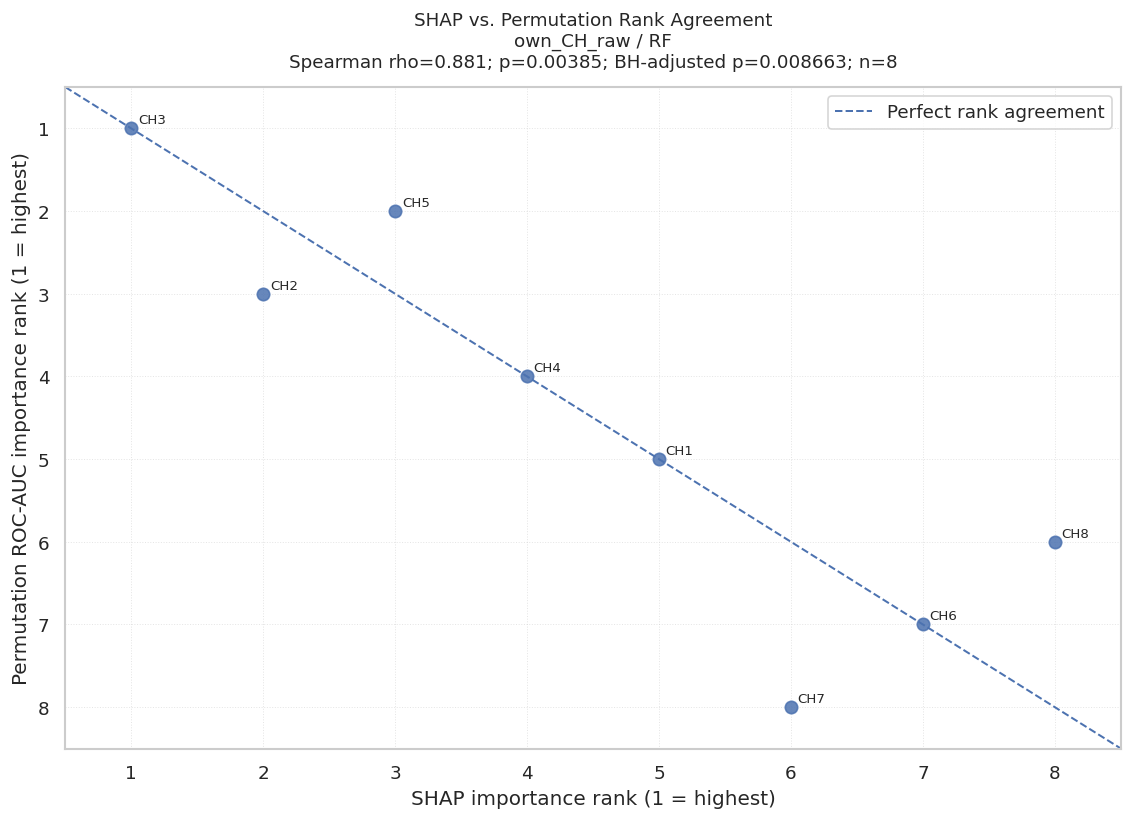

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CH_raw_RF.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CH_raw_RF.pdf


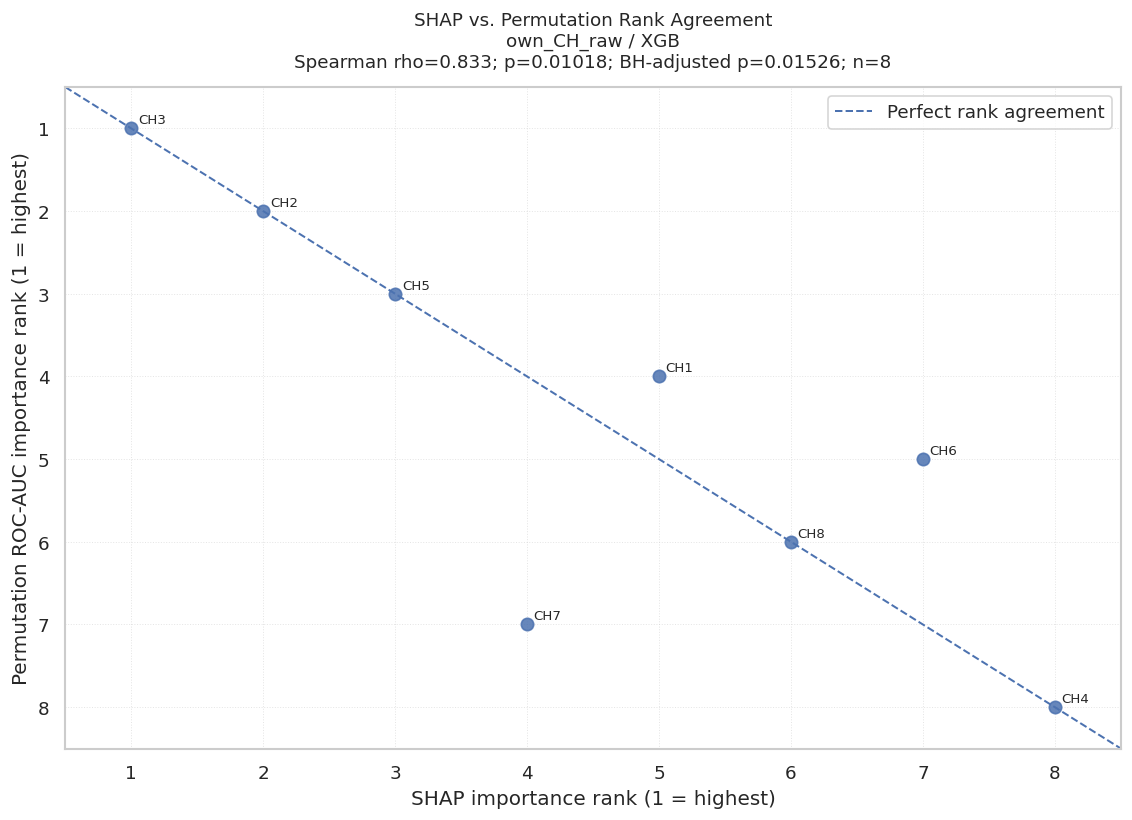

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CH_raw_XGB.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CH_raw_XGB.pdf


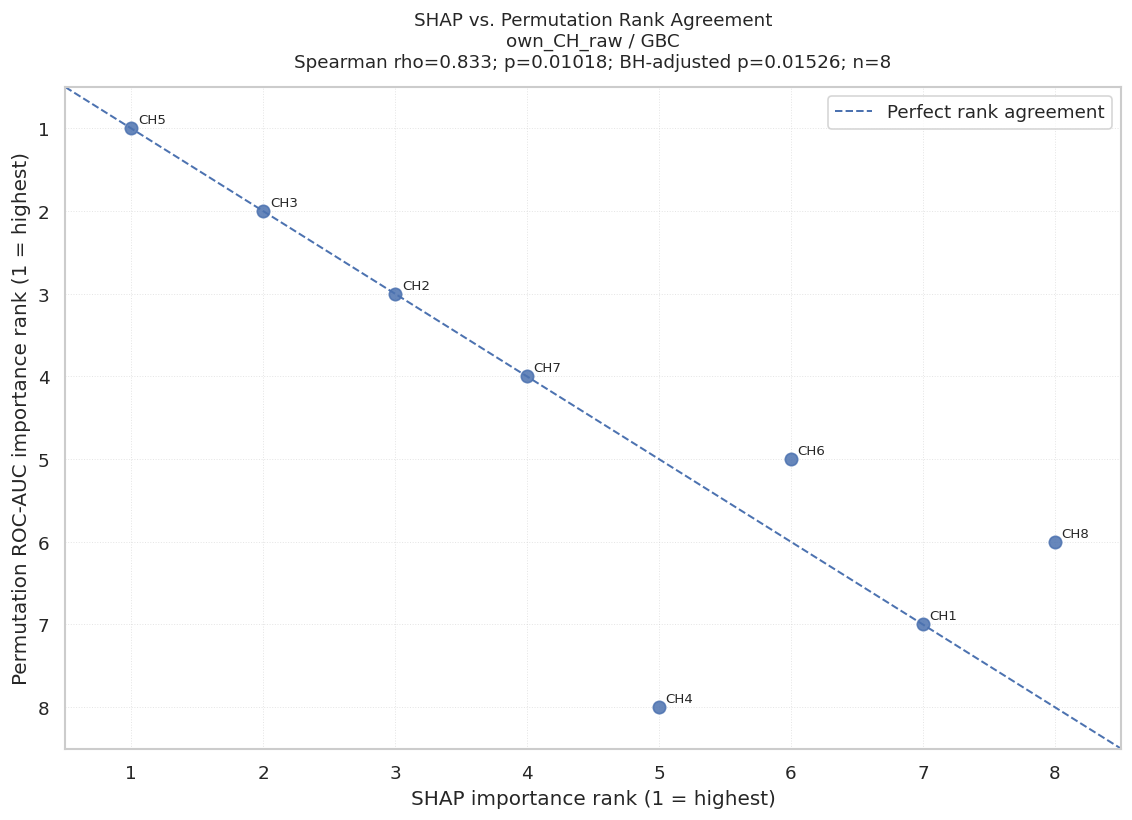

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CH_raw_GBC.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CH_raw_GBC.pdf


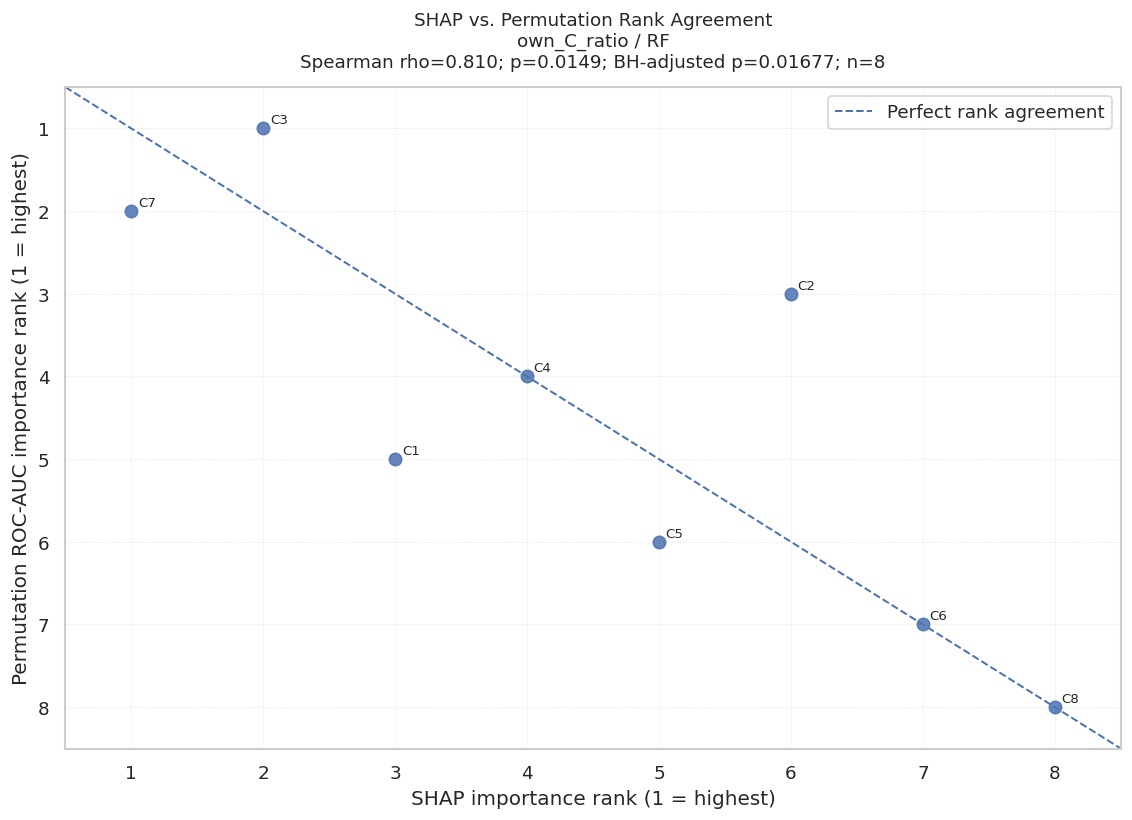

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_C_ratio_RF.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_C_ratio_RF.pdf


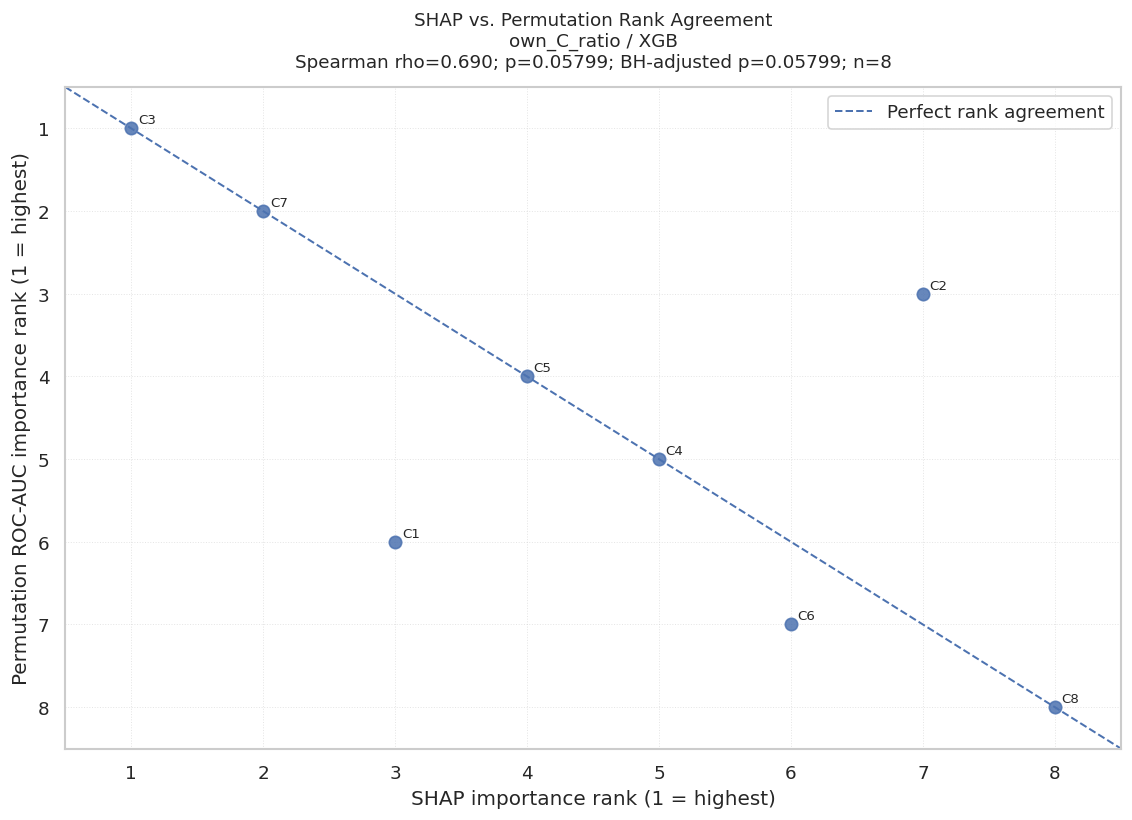

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_C_ratio_XGB.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_C_ratio_XGB.pdf


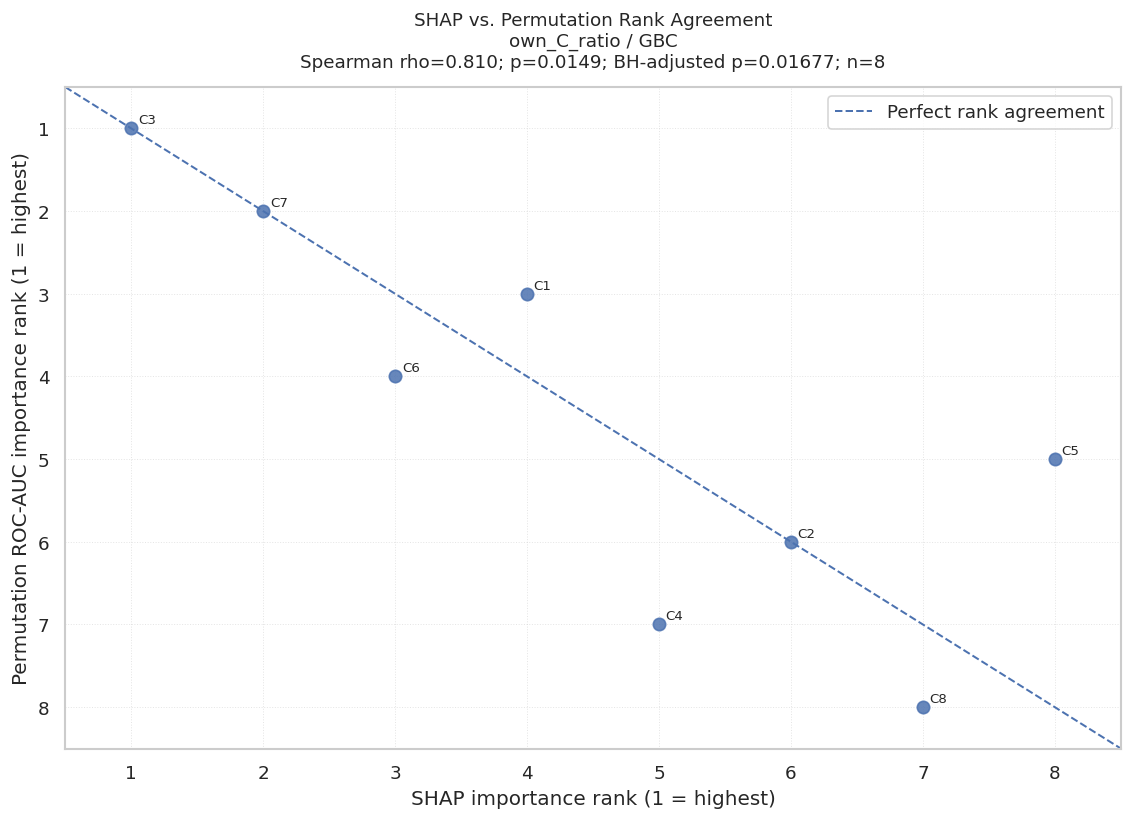

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_C_ratio_GBC.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_C_ratio_GBC.pdf


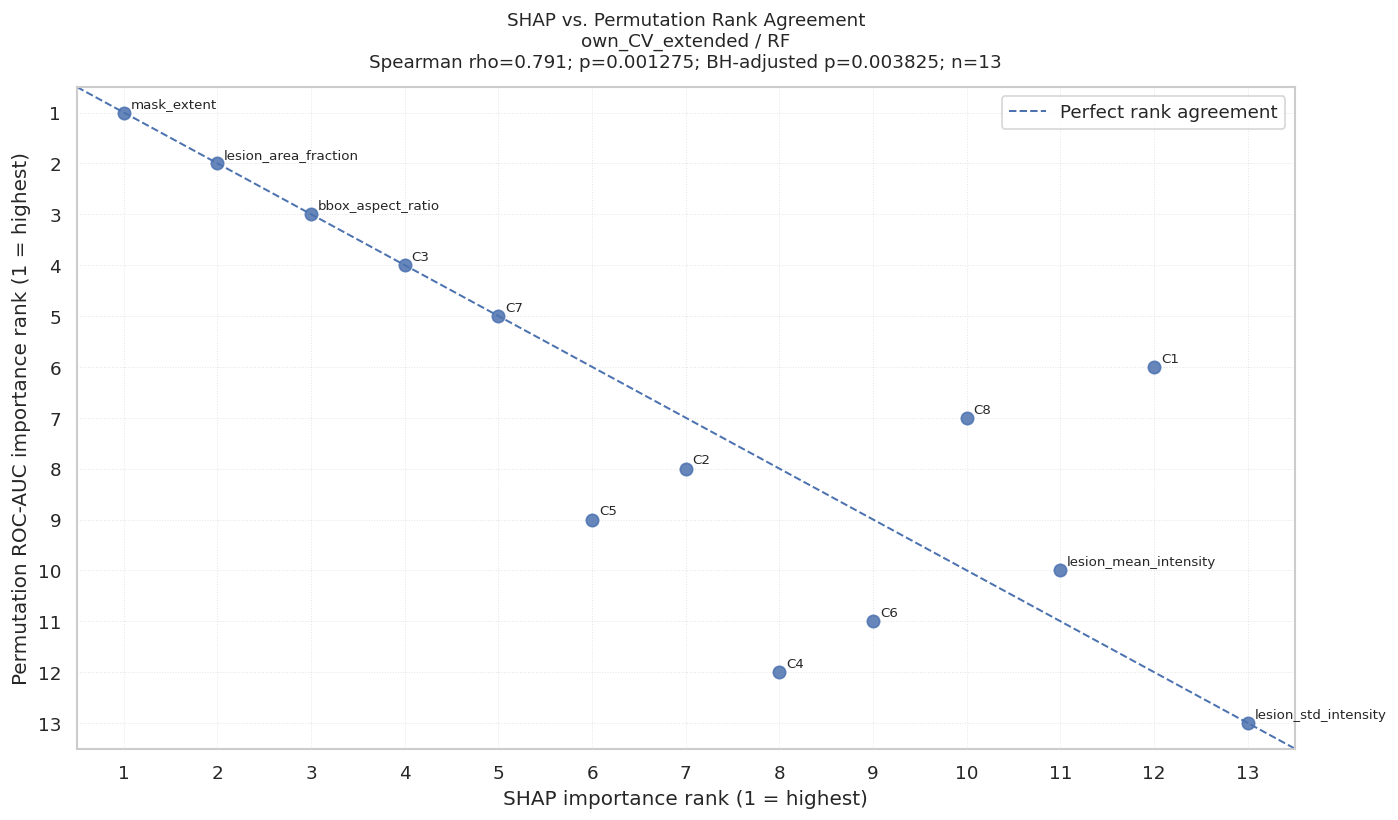

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CV_extended_RF.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CV_extended_RF.pdf


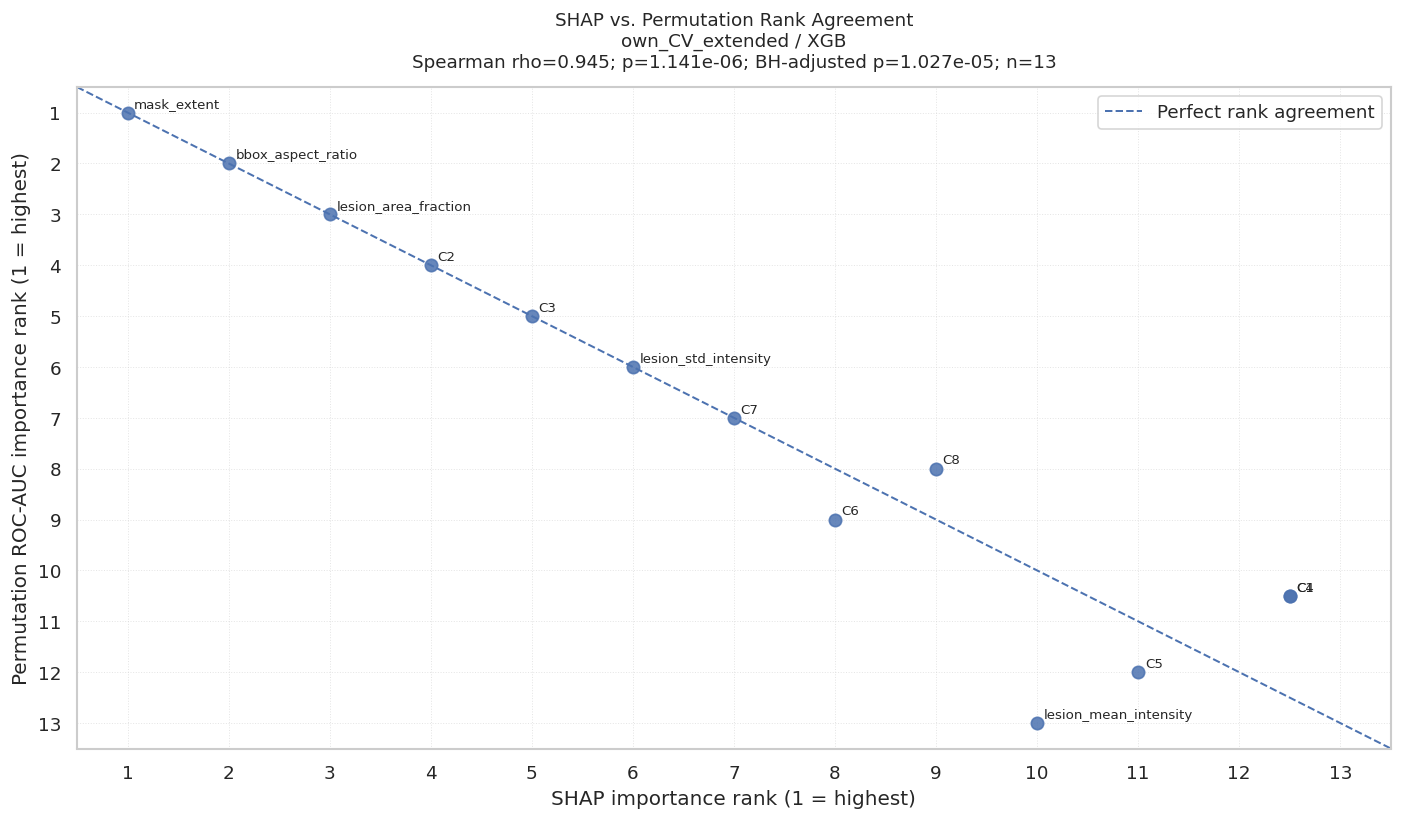

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CV_extended_XGB.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CV_extended_XGB.pdf


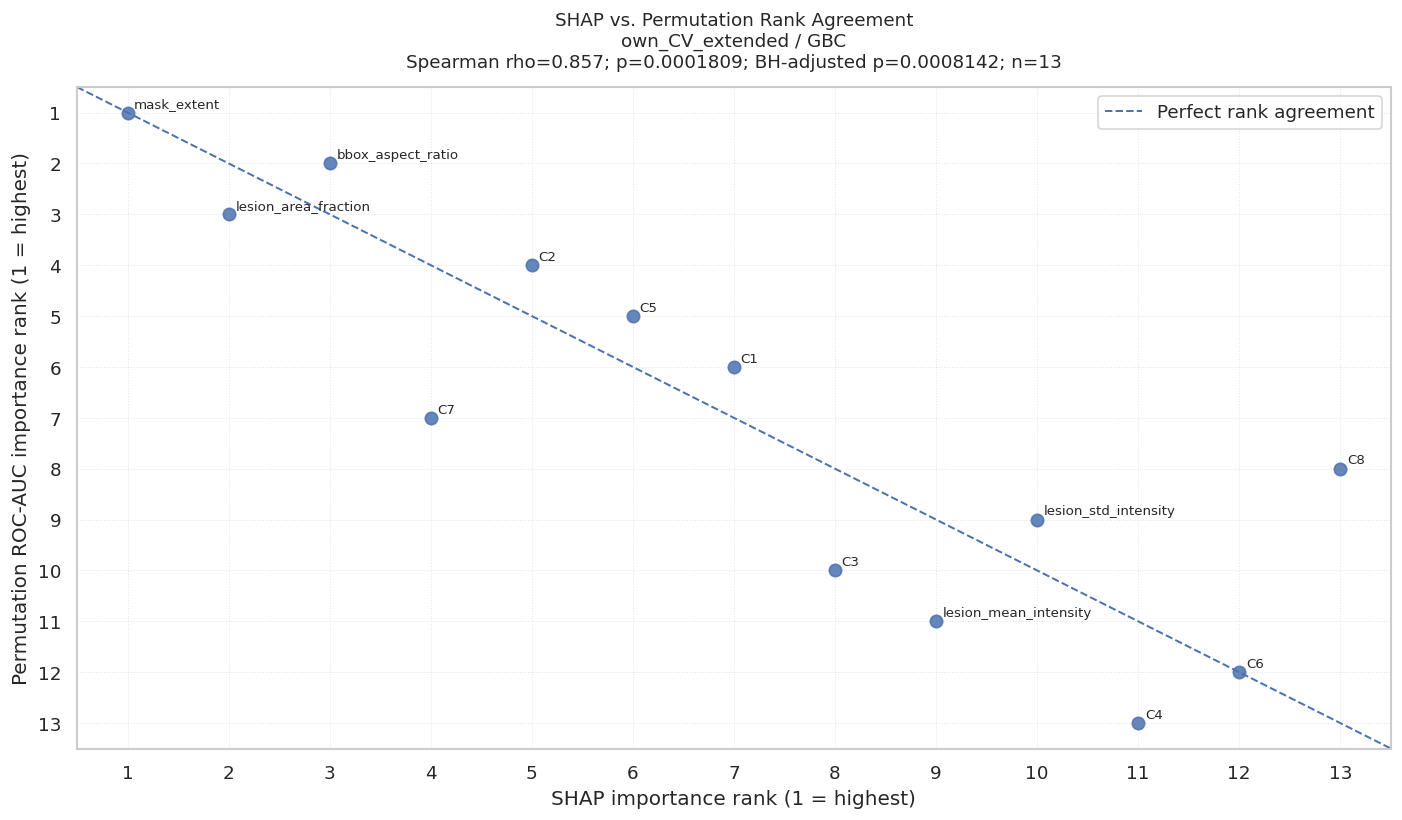

Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CV_extended_GBC.png
Saved rank plot: /content/drive/MyDrive/BUSI_paper_reproduction/figures/shap_permutation_rank_own_CV_extended_GBC.pdf

RANK AGREEMENT SUMMARY


,experiment,model,spearman_rank_correlation,p_value_not_adjusted,p_value_BH_adjusted,n_shap_features,n_permutation_features,n_features_matched,n_features_unmatched_shap,n_features_unmatched_permutation,...,n_duplicate_permutation_features_excluded,n_invalid_shap_rows_excluded,n_invalid_permutation_rows_excluded,low_feature_count_warning,n_tests_BH_family,comparison_outcome,status,error_message,small_feature_set_warning,interpretation_policy
0,own_CH_raw,GBC,0.833333,0.010176,0.015263,8,8,8,0,0,...,0,0,0,True,9,success,computed_low_n,None,True,Exploratory rank agreement only; not evidence ...
1,own_CH_raw,RF,0.880952,0.003850,0.008663,8,8,8,0,0,...,0,0,0,True,9,success,computed_low_n,None,True,Exploratory rank agreement only; not evidence ...
2,own_CH_raw,XGB,0.833333,0.010176,0.015263,8,8,8,0,0,...,0,0,0,True,9,success,computed_low_n,None,True,Exploratory rank agreement only; not evidence ...
3,own_CV_extended,GBC,0.857143,0.000181,0.000814,13,13,13,0,0,...,0,0,0,False,9,success,computed,None,False,Exploratory rank agreement only; not evidence ...
4,own_CV_extended,RF,0.791209,0.001275,0.003825,13,13,13,0,0,...,0,0,0,False,9,success,computed,None,False,Exploratory rank agreement only; not evidence ...
5,own_CV_extended,XGB,0.944904,0.000001,0.000010,13,13,13,0,0,...,0,0,0,False,9,success,computed,None,False,Exploratory rank agreement only; not evidence ...
6,own_C_ratio,GBC,0.809524,0.014903,0.016766,8,8,8,0,0,...,0,0,0,True,9,success,computed_low_n,None,True,Exploratory rank agreement only; not evidence ...
7,own_C_ratio,RF,0.809524,0.014903,0.016766,8,8,8,0,0,...,0,0,0,True,9,success,computed_low_n,None,True,Exploratory rank agreement only; not evidence ...
8,own_C_ratio,XGB,0.690476,0.057990,0.057990,8,8,8,0,0,...,0,0,0,True,9,success,computed_low_n,None,True,Exploratory rank agreement only; not evidence ...



FEATURE-LEVEL MATCHING AUDIT


,experiment,model,feature,feature_match_status,matched_for_rank_comparison,shap_mean_abs_importance,permutation_auc_importance_mean,shap_rank,permutation_auc_rank,shap_method
0,own_CH_raw,GBC,CH1,matched,True,0.062183,0.000618,7.0,7.0,single_output_complement
1,own_CH_raw,GBC,CH2,matched,True,0.112982,0.071655,3.0,3.0,single_output_complement
2,own_CH_raw,GBC,CH3,matched,True,0.170104,0.072855,2.0,2.0,single_output_complement
3,own_CH_raw,GBC,CH4,matched,True,0.067825,-0.008549,5.0,8.0,single_output_complement
4,own_CH_raw,GBC,CH5,matched,True,0.198053,0.166900,1.0,1.0,single_output_complement
...,...,...,...,...,...,...,...,...,...,...
82,own_C_ratio,XGB,C4,matched,True,0.020841,0.022745,5.0,5.0,model_agnostic_permutation
83,own_C_ratio,XGB,C5,matched,True,0.023282,0.025370,4.0,4.0,model_agnostic_permutation
84,own_C_ratio,XGB,C6,matched,True,0.019625,0.019953,6.0,7.0,model_agnostic_permutation
85,own_C_ratio,XGB,C7,matched,True,0.068640,0.053188,2.0,2.0,model_agnostic_permutation



COMPARISON STATUS COUNTS


,comparison_outcome,status,n_comparisons
0,success,computed,3
1,success,computed_low_n,6



CELL 16 — FINAL SUMMARY
Requested comparisons:       9
Successful comparisons:      9
Non-computable comparisons:  0
Failed comparisons:          0
Successful comparisons with fewer than 10 features: 6
Comparisons missing SHAP:    0
Comparisons missing permutation importance: 0
Valid p-values in BH family: 9

Saved files:
Rank summary:       /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_permutation_rank_agreement.csv
Feature audit:      /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_permutation_rank_agreement_feature_audit.csv
Input issues:       /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_permutation_rank_agreement_input_issues.csv
Duplicate records:  /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_permutation_rank_agreement_duplicates.csv
Status counts:      /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_permutation_rank_agreement_status_counts.csv
Run manifest:       /content/drive/MyDrive/BUSI_paper_reproduction/csv/shap_permutation_

In [22]:
# ============================================================
# Cell 16 — SHAP–Permutation Importance Rank Agreement
# ============================================================
# Purpose:
#   1. Compare global SHAP importance with permutation ROC-AUC importance.
#   2. Calculate Spearman rank correlation for each experiment/model pair.
#   3. Apply Benjamini-Hochberg FDR correction to valid p-values.
#   4. Audit matched, unmatched, invalid, and ambiguous feature records.
#   5. Generate feature-rank agreement plots for valid comparisons.
#   6. Report successful, non-computable, and failed comparisons separately.
#   7. Preserve the SHAP method used for each model, including fallback SHAP.
#
# Importance definitions:
#   SHAP:
#       Mean absolute SHAP contribution to P(Malignant = 0).
#
#   Permutation:
#       Mean decrease in ROC-AUC after randomly permuting a feature.
#
# Class convention:
#   0 = Malignant
#   1 = Benign
#
# Interpretation:
#   - Spearman rho near +1 indicates similar rankings.
#   - Spearman rho near 0 indicates weak monotonic rank agreement.
#   - Spearman rho near -1 indicates opposing rankings.
#   - Negative permutation importance values are retained.
#   - SHAP magnitudes and permutation effects are different quantities;
#     only their feature rankings are compared here.
#   - A small feature count can yield unstable correlation estimates.
#   - Statistical significance does not establish clinical relevance.
#
# Methodological safeguards:
#   - Failed SHAP explanations are not fabricated or imputed.
#   - Features must match by exact normalized feature name.
#   - SHAP and permutation rows are never aligned by row position.
#   - Ambiguous duplicate keys are excluded and reported explicitly.
#   - Multiple-testing correction includes only finite, calculable p-values.
#   - Rank agreement is an auxiliary analysis, not a reproduction metric.
# ============================================================


# ------------------------------------------------------------
# 1. Imports, prerequisites, and output configuration
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, rankdata


_REQUIRED_GLOBALS_CELL16 = [
    "experiment_results",
    "CSV_DIR",
    "FIG_DIR",
]

_missing_globals_cell16 = [
    variable_name
    for variable_name in _REQUIRED_GLOBALS_CELL16
    if variable_name not in globals()
]

if _missing_globals_cell16:
    raise RuntimeError(
        "Required variables are missing. Run the preceding cells first. "
        f"Missing variables: {_missing_globals_cell16}"
    )

if not isinstance(experiment_results, dict):
    raise TypeError(
        "experiment_results must be a dictionary created by Cell 11."
    )

CSV_DIR = Path(CSV_DIR)
FIG_DIR = Path(FIG_DIR)

CSV_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Define the analysis configuration and output files
# ------------------------------------------------------------

MIN_MATCHED_FEATURES = 3

# Comparisons below this threshold can be calculated but must be flagged
# because a small number of features yields fragile rank-correlation estimates.
LOW_FEATURE_COUNT_THRESHOLD = 10

# Use the same model selection as Cell 15 when that variable is available.
if "XAI_MODELS" in globals():
    MODELS_TO_COMPARE = [
        str(model_name)
        for model_name in XAI_MODELS
    ]
else:
    MODELS_TO_COMPARE = sorted({
        str(model_name)
        for result in experiment_results.values()
        if isinstance(result, dict)
        for model_name in (
            list(result.get("models", {}).keys())
            + list(result.get("test_predictions", {}).keys())
        )
    })

SHAP_VALUE_COLUMN = "mean_abs_shap_malignant_output"
PERMUTATION_VALUE_COLUMN = "permutation_auc_importance_mean"

KEY_COLUMNS = [
    "experiment",
    "model",
    "feature",
]

RANK_SUMMARY_PATH = (
    CSV_DIR / "shap_permutation_rank_agreement.csv"
)

FEATURE_AUDIT_PATH = (
    CSV_DIR / "shap_permutation_rank_agreement_feature_audit.csv"
)

INPUT_ISSUES_PATH = (
    CSV_DIR / "shap_permutation_rank_agreement_input_issues.csv"
)

DUPLICATE_RECORDS_PATH = (
    CSV_DIR / "shap_permutation_rank_agreement_duplicates.csv"
)

STATUS_COUNTS_PATH = (
    CSV_DIR / "shap_permutation_rank_agreement_status_counts.csv"
)

RANK_MANIFEST_PATH = (
    CSV_DIR / "shap_permutation_rank_agreement_manifest.json"
)

print("=" * 78)
print("SHAP–PERMUTATION RANK AGREEMENT ANALYSIS")
print("=" * 78)
print(f"Registered experiments: {len(experiment_results)}")
print(f"Models considered:      {MODELS_TO_COMPARE}")
print(f"Minimum matched features: {MIN_MATCHED_FEATURES}")


# ------------------------------------------------------------
# 3. Shared utilities
# ------------------------------------------------------------

def safe_filename(value):
    """Convert a label into a portable filename component."""

    cleaned = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(value),
    ).strip("._")

    return cleaned or "unnamed"


def normalize_identifier_columns(data):
    """Normalize feature-table identifiers without changing feature semantics."""

    output = data.copy()

    for column in KEY_COLUMNS:
        output[column] = (
            output[column]
            .astype("string")
            .str.strip()
        )

    return output


def finite_numeric_array(series):
    """Convert a series to float values, preserving invalid entries as NaN."""

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )

    return numeric.to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    )


def get_experiment_model_pairs():
    """
    Enumerate requested model pairs from the experiment registry.

    The registry is used to retain pairs whose SHAP output or permutation
    output is missing, so incomplete comparisons remain visible in the report.
    """

    pairs = []

    for experiment_name, result in experiment_results.items():

        if not isinstance(result, dict):
            continue

        available_models = (
            set(result.get("models", {}).keys())
            | set(result.get("test_predictions", {}).keys())
        )

        for model_name in MODELS_TO_COMPARE:

            if model_name in available_models:
                pairs.append(
                    (
                        str(experiment_name),
                        str(model_name),
                    )
                )

    return list(
        dict.fromkeys(pairs)
    )


# ------------------------------------------------------------
# 4. Load the SHAP global-importance data from Cell 15
# ------------------------------------------------------------

SHAP_REQUIRED_COLUMNS = {
    "experiment",
    "model",
    "feature",
    SHAP_VALUE_COLUMN,
}


def load_shap_summary():
    """
    Prefer current in-memory Cell 15 results.

    If the current in-memory result exists but is empty, do not silently
    replace it with an older file from a previous run. If no in-memory
    summary exists, try the consolidated output file and then legacy
    experiment-level summaries.
    """

    if (
        "all_shap_summary_df" in globals()
        and isinstance(all_shap_summary_df, pd.DataFrame)
    ):

        current_data = all_shap_summary_df.copy()

        if current_data.empty:
            print(
                "Current in-memory SHAP summary is empty. "
                "Older SHAP files will not be loaded automatically."
            )

        else:
            print(
                "SHAP source: current in-memory all_shap_summary_df."
            )

        return current_data

    consolidated_path = (
        CSV_DIR / "shap_global_summary_all_experiments.csv"
    )

    if consolidated_path.exists():

        loaded = pd.read_csv(
            consolidated_path
        )

        print(
            f"SHAP source: {consolidated_path}"
        )

        return loaded

    # Legacy compatibility: load experiment-specific SHAP summaries only
    # when the consolidated source is absent.
    shap_frames = []

    for experiment_name in experiment_results:

        experiment_slug = safe_filename(
            experiment_name
        )

        legacy_candidates = [
            CSV_DIR / f"shap_mean_abs_{experiment_slug}.csv",
            CSV_DIR / f"shap_mean_abs_{experiment_name}.csv",
        ]

        existing_path = next(
            (
                path
                for path in legacy_candidates
                if path.exists()
            ),
            None,
        )

        if existing_path is None:
            continue

        try:

            current_df = pd.read_csv(
                existing_path
            )

            if "experiment" not in current_df.columns:
                current_df["experiment"] = str(
                    experiment_name
                )

            shap_frames.append(
                current_df
            )

            print(
                f"Loaded legacy SHAP summary: {existing_path}"
            )

        except Exception as exc:

            warnings.warn(
                f"Could not load {existing_path}: "
                f"{type(exc).__name__}: {exc}",
                RuntimeWarning,
            )

    if not shap_frames:
        return pd.DataFrame(
            columns=sorted(SHAP_REQUIRED_COLUMNS)
        )

    return pd.concat(
        shap_frames,
        ignore_index=True,
    )


shap_source_df = load_shap_summary()

if not shap_source_df.empty:

    missing_shap_columns = (
        SHAP_REQUIRED_COLUMNS - set(shap_source_df.columns)
    )

    if missing_shap_columns:
        raise ValueError(
            "The SHAP table is missing required columns: "
            f"{sorted(missing_shap_columns)}"
        )

else:
    # Preserve the required schema when there are no valid SHAP results.
    shap_source_df = pd.DataFrame(
        columns=sorted(SHAP_REQUIRED_COLUMNS)
    )


# Retain method metadata when Cell 15 provides it.
SHAP_OPTIONAL_COLUMNS = [
    column
    for column in [
        "shap_method",
        "additivity_max_abs_error",
        "n_test_samples",
        "n_background_samples",
    ]
    if column in shap_source_df.columns
]

shap_columns_to_keep = (
    KEY_COLUMNS
    + [SHAP_VALUE_COLUMN]
    + SHAP_OPTIONAL_COLUMNS
)

shap_data_raw = shap_source_df[
    shap_columns_to_keep
].copy()


# ------------------------------------------------------------
# 5. Load permutation importance data from Cell 13
# ------------------------------------------------------------

PERMUTATION_REQUIRED_COLUMNS = {
    "experiment",
    "model",
    "feature",
    PERMUTATION_VALUE_COLUMN,
}

if (
    "perm_df" in globals()
    and isinstance(perm_df, pd.DataFrame)
):

    # An existing in-memory table is authoritative for this notebook run,
    # even when empty.
    permutation_source_df = perm_df.copy()

    print(
        "Permutation source: current in-memory perm_df."
    )

else:

    permutation_path = (
        CSV_DIR / "permutation_importance_holdout.csv"
    )

    if permutation_path.exists():

        permutation_source_df = pd.read_csv(
            permutation_path
        )

        print(
            f"Permutation source: {permutation_path}"
        )

    else:

        permutation_source_df = pd.DataFrame(
            columns=sorted(PERMUTATION_REQUIRED_COLUMNS)
        )


if not permutation_source_df.empty:

    missing_permutation_columns = (
        PERMUTATION_REQUIRED_COLUMNS
        - set(permutation_source_df.columns)
    )

    if missing_permutation_columns:
        raise ValueError(
            "The permutation-importance table is missing required columns: "
            f"{sorted(missing_permutation_columns)}"
        )

else:
    permutation_source_df = pd.DataFrame(
        columns=sorted(PERMUTATION_REQUIRED_COLUMNS)
    )


permutation_data_raw = permutation_source_df[
    [
        "experiment",
        "model",
        "feature",
        PERMUTATION_VALUE_COLUMN,
    ]
].copy()


# ------------------------------------------------------------
# 6. Validate importance records and audit unusable rows
# ------------------------------------------------------------

def prepare_importance_table(
    data,
    value_column,
    source_name,
):
    """
    Validate a source table and remove invalid rows with an audit trail.

    Negative permutation importance is valid and is preserved.
    Negative mean-absolute-SHAP importance is invalid and is excluded.
    """

    table = data.copy().reset_index(
        names="source_row_index"
    )

    table["source_table"] = str(
        source_name
    )

    if table.empty:

        # Return the expected output schema even when no usable records exist.
        if "source_row_index" not in table.columns:
            table["source_row_index"] = pd.Series(
                dtype="object"
            )

        if "source_table" not in table.columns:
            table["source_table"] = pd.Series(
                dtype="object"
            )

        for key_column in KEY_COLUMNS:
            if key_column not in table.columns:
                table[key_column] = pd.Series(
                    dtype="object"
                )

        if value_column not in table.columns:
            table[value_column] = pd.Series(
                dtype="float64"
            )

        return (
            table,
            pd.DataFrame(),
        )

    # Normalize the comparison keys.
    table = normalize_identifier_columns(
        table
    )

    # Convert the selected importance value to numeric.
    importance_values = finite_numeric_array(
        table[value_column]
    )

    table[value_column] = importance_values

    invalid_reason = np.full(
        len(table),
        "",
        dtype=object,
    )

    invalid_key_mask = (
        table[KEY_COLUMNS].isna().any(axis=1).to_numpy()
        | table[KEY_COLUMNS].eq("").any(axis=1).to_numpy()
    )

    nonfinite_value_mask = ~np.isfinite(
        importance_values
    )

    invalid_reason[invalid_key_mask] = (
        "missing_or_blank_comparison_key"
    )

    invalid_reason[
        nonfinite_value_mask
    ] = "missing_or_nonfinite_importance_value"

    # Mean absolute SHAP must not be negative.
    if value_column == SHAP_VALUE_COLUMN:

        negative_shap_mask = (
            np.isfinite(importance_values)
            & (importance_values < 0)
        )

        invalid_reason[
            negative_shap_mask
        ] = "negative_mean_absolute_shap_value"

    invalid_mask = invalid_reason != ""

    invalid_rows = table.loc[
        invalid_mask
    ].copy()

    if not invalid_rows.empty:

        invalid_rows["issue_reason"] = invalid_reason[
            invalid_mask
        ]

    valid_rows = table.loc[
        ~invalid_mask
    ].copy()

    return (
        valid_rows,
        invalid_rows,
    )


shap_data, shap_invalid_rows = prepare_importance_table(
    shap_data_raw,
    SHAP_VALUE_COLUMN,
    "SHAP",
)

permutation_data, permutation_invalid_rows = (
    prepare_importance_table(
        permutation_data_raw,
        PERMUTATION_VALUE_COLUMN,
        "Permutation",
    )
)


# ------------------------------------------------------------
# 7. Exclude ambiguous duplicate keys rather than averaging them
# ------------------------------------------------------------

def remove_ambiguous_duplicate_keys(
    table,
    value_column,
    source_name,
):
    """
    Remove every experiment/model/feature key with duplicate source records.

    Duplicate keys are not averaged because repeated records may represent
    duplicated exports, stale runs, or conflicting measurements. Their
    resolution should happen upstream.
    """

    if table.empty:
        return (
            table.copy(),
            pd.DataFrame(),
            {},
        )

    duplicate_mask = table.duplicated(
        subset=KEY_COLUMNS,
        keep=False,
    )

    duplicate_rows = table.loc[
        duplicate_mask
    ].copy()

    duplicate_feature_sets = {}

    if not duplicate_rows.empty:

        duplicate_rows["issue_reason"] = (
            "duplicate_experiment_model_feature_key"
        )

        for _, row in duplicate_rows.iterrows():

            pair_key = (
                str(row["experiment"]),
                str(row["model"]),
            )

            duplicate_feature_sets.setdefault(
                pair_key,
                set(),
            ).add(
                str(row["feature"])
            )

        warnings.warn(
            f"{source_name}: {len(duplicate_rows)} source rows belong to "
            "duplicate experiment/model/feature keys. All ambiguous keys "
            "will be excluded from rank comparisons and saved for inspection.",
            RuntimeWarning,
        )

    valid_rows = table.loc[
        ~duplicate_mask
    ].copy()

    return (
        valid_rows,
        duplicate_rows,
        duplicate_feature_sets,
    )


shap_data, shap_duplicate_rows, shap_duplicate_features = (
    remove_ambiguous_duplicate_keys(
        shap_data,
        SHAP_VALUE_COLUMN,
        "SHAP",
    )
)

permutation_data, permutation_duplicate_rows, permutation_duplicate_features = (
    remove_ambiguous_duplicate_keys(
        permutation_data,
        PERMUTATION_VALUE_COLUMN,
        "Permutation importance",
    )
)


# ------------------------------------------------------------
# 8. Export invalid-input and duplicate-record diagnostics
# ------------------------------------------------------------

input_issue_frames = []

if not shap_invalid_rows.empty:
    input_issue_frames.append(
        shap_invalid_rows.copy()
    )

if not permutation_invalid_rows.empty:
    input_issue_frames.append(
        permutation_invalid_rows.copy()
    )

if input_issue_frames:
    input_issues_df = pd.concat(
        input_issue_frames,
        ignore_index=True,
        sort=False,
    )
else:
    input_issues_df = pd.DataFrame(
        columns=[
            "source_table",
            "source_row_index",
            "issue_reason",
        ]
    )

input_issues_df.to_csv(
    INPUT_ISSUES_PATH,
    index=False,
)


duplicate_frames = []

if not shap_duplicate_rows.empty:
    duplicate_frames.append(
        shap_duplicate_rows.copy()
    )

if not permutation_duplicate_rows.empty:
    duplicate_frames.append(
        permutation_duplicate_rows.copy()
    )

if duplicate_frames:
    duplicate_records_df = pd.concat(
        duplicate_frames,
        ignore_index=True,
        sort=False,
    )
else:
    duplicate_records_df = pd.DataFrame(
        columns=[
            "source_table",
            "source_row_index",
            "issue_reason",
        ]
    )

duplicate_records_df.to_csv(
    DUPLICATE_RECORDS_PATH,
    index=False,
)

print("\nInput diagnostics:")
print(f"Invalid rows excluded: {len(input_issues_df)}")
print(f"Duplicate rows excluded: {len(duplicate_records_df)}")
print(f"Input issues CSV: {INPUT_ISSUES_PATH}")
print(f"Duplicate audit CSV: {DUPLICATE_RECORDS_PATH}")


# ------------------------------------------------------------
# 9. Enumerate all comparisons that should be reported
# ------------------------------------------------------------

# Include registered models even when an explanation source is missing.
comparison_pairs = get_experiment_model_pairs()

# Also include selected models found in the importance tables. This ensures
# that orphaned or unmatched source records are visible in the final audit.
data_pairs = (
    set(
        zip(
            shap_data["experiment"].astype(str),
            shap_data["model"].astype(str),
        )
    )
    | set(
        zip(
            permutation_data["experiment"].astype(str),
            permutation_data["model"].astype(str),
        )
    )
)

# Retain only models requested for this analysis.
selected_model_names = set(
    MODELS_TO_COMPARE
)

data_pairs = {
    pair
    for pair in data_pairs
    if pair[1] in selected_model_names
}

comparison_pairs = list(
    dict.fromkeys(
        comparison_pairs + sorted(data_pairs)
    )
)

print("\nRequested experiment/model comparisons:")
print(f"Total pairs: {len(comparison_pairs)}")


# ------------------------------------------------------------
# 10. Define Benjamini-Hochberg FDR adjustment
# ------------------------------------------------------------

def benjamini_hochberg_adjust(p_values):
    """
    Adjust a vector of p-values using the Benjamini-Hochberg procedure.

    Non-finite values remain NaN and are not included in the correction family.
    """

    p_values = np.asarray(
        p_values,
        dtype=np.float64,
    )

    adjusted = np.full(
        p_values.shape,
        np.nan,
        dtype=np.float64,
    )

    valid_indices = np.flatnonzero(
        np.isfinite(p_values)
    )

    if valid_indices.size == 0:
        return adjusted

    valid_p_values = p_values[
        valid_indices
    ]

    if np.any(
        (valid_p_values < 0)
        | (valid_p_values > 1)
    ):
        raise ValueError(
            "All p-values must lie within [0, 1]."
        )

    order = np.argsort(
        valid_p_values
    )

    sorted_p_values = valid_p_values[
        order
    ]

    number_of_tests = len(
        sorted_p_values
    )

    adjusted_sorted = (
        sorted_p_values
        * number_of_tests
        / np.arange(
            1,
            number_of_tests + 1,
        )
    )

    # Enforce monotonicity from the largest p-value toward the smallest.
    adjusted_sorted = np.minimum.accumulate(
        adjusted_sorted[::-1]
    )[::-1]

    adjusted_sorted = np.clip(
        adjusted_sorted,
        0.0,
        1.0,
    )

    adjusted_valid = np.empty_like(
        adjusted_sorted
    )

    adjusted_valid[order] = adjusted_sorted

    adjusted[valid_indices] = adjusted_valid

    return adjusted


# ------------------------------------------------------------
# 11. Build feature-level audit and calculate Spearman agreement
# ------------------------------------------------------------

summary_rows = []
feature_audit_rows = []

# Store valid comparison data for plotting.
plot_data_by_pair = {}

for experiment_name, model_name in comparison_pairs:

    shap_subset = shap_data[
        (shap_data["experiment"] == experiment_name)
        & (shap_data["model"] == model_name)
    ].copy()

    permutation_subset = permutation_data[
        (permutation_data["experiment"] == experiment_name)
        & (permutation_data["model"] == model_name)
    ].copy()

    shap_features = set(
        shap_subset["feature"].astype(str)
    )

    permutation_features = set(
        permutation_subset["feature"].astype(str)
    )

    matched_features = sorted(
        shap_features & permutation_features
    )

    unmatched_shap_features = sorted(
        shap_features - permutation_features
    )

    unmatched_permutation_features = sorted(
        permutation_features - shap_features
    )

    pair_key = (
        str(experiment_name),
        str(model_name),
    )

    shap_duplicate_set = shap_duplicate_features.get(
        pair_key,
        set(),
    )

    permutation_duplicate_set = permutation_duplicate_features.get(
        pair_key,
        set(),
    )

    shap_invalid_pair_count = int(
        (
            shap_invalid_rows.get("experiment", pd.Series(dtype=str))
            .astype(str)
            .eq(str(experiment_name))
            &
            shap_invalid_rows.get("model", pd.Series(dtype=str))
            .astype(str)
            .eq(str(model_name))
        ).sum()
    ) if not shap_invalid_rows.empty else 0

    permutation_invalid_pair_count = int(
        (
            permutation_invalid_rows.get("experiment", pd.Series(dtype=str))
            .astype(str)
            .eq(str(experiment_name))
            &
            permutation_invalid_rows.get("model", pd.Series(dtype=str))
            .astype(str)
            .eq(str(model_name))
        ).sum()
    ) if not permutation_invalid_rows.empty else 0

    # Resolve source availability, including cases in which all rows were
    # excluded because their keys were duplicated or values were invalid.
    if shap_subset.empty and permutation_subset.empty:

        if (
            shap_duplicate_set
            or permutation_duplicate_set
            or shap_invalid_pair_count
            or permutation_invalid_pair_count
        ):
            status = "sources_unusable_after_input_audit"
        else:
            status = "missing_both_sources"

    elif shap_subset.empty:

        if shap_duplicate_set or shap_invalid_pair_count:
            status = "shap_unusable_after_input_audit"
        else:
            status = "missing_shap_data"

    elif permutation_subset.empty:

        if permutation_duplicate_set or permutation_invalid_pair_count:
            status = "permutation_unusable_after_input_audit"
        else:
            status = "missing_permutation_data"

    else:
        status = "pending"

    summary_row = {
        "experiment": str(experiment_name),
        "model": str(model_name),
        "spearman_rank_correlation": np.nan,
        "p_value_not_adjusted": np.nan,
        "p_value_BH_adjusted": np.nan,
        "n_shap_features": int(len(shap_features)),
        "n_permutation_features": int(len(permutation_features)),
        "n_features_matched": int(len(matched_features)),
        "n_features_unmatched_shap": int(
            len(unmatched_shap_features)
        ),
        "n_features_unmatched_permutation": int(
            len(unmatched_permutation_features)
        ),
        "n_duplicate_shap_features_excluded": int(
            len(shap_duplicate_set)
        ),
        "n_duplicate_permutation_features_excluded": int(
            len(permutation_duplicate_set)
        ),
        "n_invalid_shap_rows_excluded": shap_invalid_pair_count,
        "n_invalid_permutation_rows_excluded": (
            permutation_invalid_pair_count
        ),
        "low_feature_count_warning": True,
        "n_tests_BH_family": 0,
        "comparison_outcome": "not_computable",
        "status": status,
        "error_message": None,
    }

    shap_lookup = {
        str(row["feature"]): row
        for _, row in shap_subset.iterrows()
    }

    permutation_lookup = {
        str(row["feature"]): row
        for _, row in permutation_subset.iterrows()
    }

    pair_audit_rows = []

    # Build an outer-union audit: every feature from either source is retained.
    all_pair_features = sorted(
        shap_features | permutation_features
    )

    for feature_name in all_pair_features:

        shap_record = shap_lookup.get(
            feature_name
        )

        permutation_record = permutation_lookup.get(
            feature_name
        )

        matched = (
            shap_record is not None
            and permutation_record is not None
        )

        if matched:
            match_status = "matched"
        elif shap_record is not None:
            match_status = "missing_permutation_feature"
        else:
            match_status = "missing_shap_feature"

        audit_row = {
            "experiment": str(experiment_name),
            "model": str(model_name),
            "feature": str(feature_name),
            "feature_match_status": match_status,
            "matched_for_rank_comparison": bool(matched),
            "shap_mean_abs_importance": (
                float(shap_record[SHAP_VALUE_COLUMN])
                if shap_record is not None
                else np.nan
            ),
            "permutation_auc_importance_mean": (
                float(permutation_record[PERMUTATION_VALUE_COLUMN])
                if permutation_record is not None
                else np.nan
            ),
            "shap_rank": np.nan,
            "permutation_auc_rank": np.nan,
            "shap_method": (
                str(shap_record["shap_method"])
                if (
                    shap_record is not None
                    and "shap_method" in shap_record.index
                    and pd.notna(shap_record["shap_method"])
                )
                else None
            ),
            "shap_additivity_max_abs_error": (
                float(shap_record["additivity_max_abs_error"])
                if (
                    shap_record is not None
                    and "additivity_max_abs_error" in shap_record.index
                    and pd.notna(
                        shap_record["additivity_max_abs_error"]
                    )
                )
                else np.nan
            ),
        }

        pair_audit_rows.append(
            audit_row
        )

    # Calculate ranks only for feature keys with both importance measures.
    if matched_features:

        matched_shap_values = np.array(
            [
                shap_lookup[feature][SHAP_VALUE_COLUMN]
                for feature in matched_features
            ],
            dtype=np.float64,
        )

        matched_permutation_values = np.array(
            [
                permutation_lookup[feature][
                    PERMUTATION_VALUE_COLUMN
                ]
                for feature in matched_features
            ],
            dtype=np.float64,
        )

        shap_ranks = rankdata(
            -matched_shap_values,
            method="average",
        )

        permutation_ranks = rankdata(
            -matched_permutation_values,
            method="average",
        )

        shap_rank_lookup = dict(
            zip(
                matched_features,
                shap_ranks,
            )
        )

        permutation_rank_lookup = dict(
            zip(
                matched_features,
                permutation_ranks,
            )
        )

        for audit_row in pair_audit_rows:

            feature_name = audit_row["feature"]

            if feature_name in shap_rank_lookup:

                audit_row["shap_rank"] = float(
                    shap_rank_lookup[feature_name]
                )

                audit_row["permutation_auc_rank"] = float(
                    permutation_rank_lookup[feature_name]
                )

    # Calculate the rank correlation only when both sources are valid.
    if status == "pending":

        if len(matched_features) < MIN_MATCHED_FEATURES:

            status = "insufficient_matched_features"

        else:

            shap_values = matched_shap_values
            permutation_values = matched_permutation_values

            if (
                np.unique(shap_values).size < 2
                or np.unique(permutation_values).size < 2
            ):

                status = "constant_importance_values"

            else:

                try:

                    with warnings.catch_warnings(record=True) as captured:
                        warnings.simplefilter("always")

                        spearman_result = spearmanr(
                            shap_values,
                            permutation_values,
                        )

                    rho = float(
                        spearman_result.statistic
                    )

                    p_value = float(
                        spearman_result.pvalue
                    )

                    if not (
                        np.isfinite(rho)
                        and np.isfinite(p_value)
                    ):

                        status = "undefined_spearman_result"

                    else:

                        low_feature_count = (
                            len(matched_features)
                            < LOW_FEATURE_COUNT_THRESHOLD
                        )

                        status = (
                            "computed_low_n"
                            if low_feature_count
                            else "computed"
                        )

                        summary_row[
                            "spearman_rank_correlation"
                        ] = rho

                        summary_row[
                            "p_value_not_adjusted"
                        ] = p_value

                        summary_row[
                            "low_feature_count_warning"
                        ] = bool(
                            low_feature_count
                        )

                        # Retain the successful comparison data for plotting.
                        plot_df = pd.DataFrame({
                            "feature": matched_features,
                            "shap_mean_abs_importance": shap_values,
                            "permutation_auc_importance_mean": (
                                permutation_values
                            ),
                            "shap_rank": shap_ranks,
                            "permutation_auc_rank": (
                                permutation_ranks
                            ),
                        })

                        plot_data_by_pair[
                            pair_key
                        ] = plot_df.copy()

                except Exception as exc:

                    status = "comparison_processing_error"

                    summary_row["comparison_outcome"] = "failed"

                    summary_row["error_message"] = (
                        f"{type(exc).__name__}: {exc}"
                    )

    summary_row["status"] = status

    if status in {"computed", "computed_low_n"}:
        summary_row["comparison_outcome"] = "success"

    elif status == "comparison_processing_error":
        summary_row["comparison_outcome"] = "failed"

    else:
        summary_row["comparison_outcome"] = "not_computable"

    summary_rows.append(
        summary_row
    )

    feature_audit_rows.extend(
        pair_audit_rows
    )


# ------------------------------------------------------------
# 12. Build the rank-agreement summary and adjust p-values
# ------------------------------------------------------------

SUMMARY_COLUMNS = [
    "experiment",
    "model",
    "spearman_rank_correlation",
    "p_value_not_adjusted",
    "p_value_BH_adjusted",
    "n_shap_features",
    "n_permutation_features",
    "n_features_matched",
    "n_features_unmatched_shap",
    "n_features_unmatched_permutation",
    "n_duplicate_shap_features_excluded",
    "n_duplicate_permutation_features_excluded",
    "n_invalid_shap_rows_excluded",
    "n_invalid_permutation_rows_excluded",
    "low_feature_count_warning",
    "n_tests_BH_family",
    "comparison_outcome",
    "status",
    "error_message",
]

rank_agreement_df = pd.DataFrame(
    summary_rows,
    columns=SUMMARY_COLUMNS,
)

if not rank_agreement_df.empty:

    valid_p_mask = (
        rank_agreement_df["p_value_not_adjusted"].notna()
        & np.isfinite(
            pd.to_numeric(
                rank_agreement_df["p_value_not_adjusted"],
                errors="coerce",
            )
        )
    )

    n_valid_p_values = int(
        valid_p_mask.sum()
    )

    if n_valid_p_values > 0:

        adjusted_p_values = benjamini_hochberg_adjust(
            rank_agreement_df.loc[
                valid_p_mask,
                "p_value_not_adjusted",
            ].to_numpy(dtype=np.float64)
        )

        rank_agreement_df.loc[
            valid_p_mask,
            "p_value_BH_adjusted",
        ] = adjusted_p_values

        rank_agreement_df.loc[
            :,
            "n_tests_BH_family",
        ] = n_valid_p_values

    else:
        n_valid_p_values = 0

    rank_agreement_df = (
        rank_agreement_df
        .sort_values(
            ["experiment", "model"]
        )
        .reset_index(drop=True)
    )

else:
    n_valid_p_values = 0


# ------------------------------------------------------------
# 13. Export summary, feature audit, and status counts
# ------------------------------------------------------------

rank_agreement_audit_df = pd.DataFrame(
    feature_audit_rows,
    columns=[
        "experiment",
        "model",
        "feature",
        "feature_match_status",
        "matched_for_rank_comparison",
        "shap_mean_abs_importance",
        "permutation_auc_importance_mean",
        "shap_rank",
        "permutation_auc_rank",
        "shap_method",
        "shap_additivity_max_abs_error",
    ],
)

if not rank_agreement_audit_df.empty:

    rank_agreement_audit_df = (
        rank_agreement_audit_df
        .sort_values(
            [
                "experiment",
                "model",
                "feature_match_status",
                "feature",
            ]
        )
        .reset_index(drop=True)
    )

# Add an explicit inferential-caution field. Rank correlation across a small
# number of correlated engineered features is exploratory, even after BH FDR.
if not rank_agreement_df.empty:
    _n_col = next((c for c in ["n_features_matched", "n_matched_features"] if c in rank_agreement_df.columns), None)
    if _n_col is not None:
        rank_agreement_df["small_feature_set_warning"] = (
            pd.to_numeric(rank_agreement_df[_n_col], errors="coerce")
            < LOW_FEATURE_COUNT_THRESHOLD
        )
    else:
        rank_agreement_df["small_feature_set_warning"] = rank_agreement_df["status"].eq("computed_low_n")
    rank_agreement_df["interpretation_policy"] = (
        "Exploratory rank agreement only; not evidence of explanation correctness, "
        "causality, or independent clinical validity. BH FDR does not correct small-n dependence."
    )

rank_agreement_df.to_csv(
    RANK_SUMMARY_PATH,
    index=False,
)

rank_agreement_audit_df.to_csv(
    FEATURE_AUDIT_PATH,
    index=False,
)

if rank_agreement_df.empty:

    status_counts_df = pd.DataFrame(
        columns=[
            "comparison_outcome",
            "status",
            "n_comparisons",
        ]
    )

else:

    status_counts_df = (
        rank_agreement_df.groupby(
            [
                "comparison_outcome",
                "status",
            ],
            dropna=False,
        )
        .size()
        .reset_index(
            name="n_comparisons"
        )
        .sort_values(
            [
                "comparison_outcome",
                "status",
            ]
        )
        .reset_index(drop=True)
    )

status_counts_df.to_csv(
    STATUS_COUNTS_PATH,
    index=False,
)


# ------------------------------------------------------------
# 14. Summarize valid, non-computable, and failed comparisons
# ------------------------------------------------------------

n_comparisons_requested = int(
    len(rank_agreement_df)
)

n_comparisons_successful = int(
    rank_agreement_df["comparison_outcome"]
    .eq("success")
    .sum()
) if not rank_agreement_df.empty else 0

n_comparisons_not_computable = int(
    rank_agreement_df["comparison_outcome"]
    .eq("not_computable")
    .sum()
) if not rank_agreement_df.empty else 0

n_comparisons_failed = int(
    rank_agreement_df["comparison_outcome"]
    .eq("failed")
    .sum()
) if not rank_agreement_df.empty else 0

# The values below distinguish absent/invalid comparisons from pairs that
# were successfully analysed with a low number of matched features.
n_low_n_comparisons = int(
    rank_agreement_df["status"]
    .eq("computed_low_n")
    .sum()
) if not rank_agreement_df.empty else 0

n_missing_shap = int(
    rank_agreement_df["status"]
    .isin([
        "missing_shap_data",
        "shap_unusable_after_input_audit",
    ])
    .sum()
) if not rank_agreement_df.empty else 0

n_missing_permutation = int(
    rank_agreement_df["status"]
    .isin([
        "missing_permutation_data",
        "permutation_unusable_after_input_audit",
    ])
    .sum()
) if not rank_agreement_df.empty else 0

manifest = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "analysis": "SHAP–Permutation feature-rank agreement",
    "shap_importance_column": SHAP_VALUE_COLUMN,
    "permutation_importance_column": PERMUTATION_VALUE_COLUMN,
    "rank_correlation": "Spearman",
    "multiple_testing_correction": "Benjamini-Hochberg FDR",
    "interpretation_policy": (
        "Exploratory only: rank correlation with 8 or 13 matched engineered features is small-sample "
        "and dependence-sensitive. FDR adjustment does not make feature ranks independent and does not "
        "establish that SHAP explanations are correct or clinically valid."
    ),
    "minimum_matched_features": int(
        MIN_MATCHED_FEATURES
    ),
    "low_feature_count_threshold": int(
        LOW_FEATURE_COUNT_THRESHOLD
    ),
    "counts": {
        "comparisons_requested": n_comparisons_requested,
        "comparisons_successful": n_comparisons_successful,
        "comparisons_not_computable": n_comparisons_not_computable,
        "comparisons_failed": n_comparisons_failed,
        "comparisons_computed_with_low_feature_count": (
            n_low_n_comparisons
        ),
        "comparisons_missing_shap": n_missing_shap,
        "comparisons_missing_permutation": n_missing_permutation,
        "p_values_in_bh_family": n_valid_p_values,
        "matched_feature_audit_rows": int(
            rank_agreement_audit_df[
                "matched_for_rank_comparison"
            ].sum()
        ) if not rank_agreement_audit_df.empty else 0,
        "input_issue_rows": int(
            len(input_issues_df)
        ),
        "duplicate_source_rows": int(
            len(duplicate_records_df)
        ),
    },
    "outputs": {
        "rank_summary": str(RANK_SUMMARY_PATH),
        "feature_audit": str(FEATURE_AUDIT_PATH),
        "input_issues": str(INPUT_ISSUES_PATH),
        "duplicate_records": str(DUPLICATE_RECORDS_PATH),
        "status_counts": str(STATUS_COUNTS_PATH),
    },
}

with open(
    RANK_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as manifest_file:

    json.dump(
        manifest,
        manifest_file,
        indent=2,
        ensure_ascii=False,
        default=str,
    )


# ------------------------------------------------------------
# 15. Plot feature-rank agreement for each valid comparison
# ------------------------------------------------------------

for pair_key, plot_df in plot_data_by_pair.items():

    experiment_name, model_name = pair_key

    summary_match = rank_agreement_df[
        (rank_agreement_df["experiment"] == experiment_name)
        & (rank_agreement_df["model"] == model_name)
    ]

    if summary_match.empty:
        continue

    summary = summary_match.iloc[0]

    rho = summary["spearman_rank_correlation"]
    p_value = summary["p_value_not_adjusted"]
    adjusted_p_value = summary["p_value_BH_adjusted"]

    if not np.isfinite(rho):
        continue

    n_features = len(plot_df)

    if n_features < MIN_MATCHED_FEATURES:
        continue

    plot_df = plot_df.sort_values(
        "shap_rank"
    ).copy()

    figure_width = max(
        8,
        min(
            12,
            0.45 * n_features + 6,
        ),
    )

    fig, ax = plt.subplots(
        figsize=(figure_width, 7),
    )

    ax.scatter(
        plot_df["shap_rank"],
        plot_df["permutation_auc_rank"],
        s=55,
        alpha=0.85,
    )

    # Perfect agreement corresponds to the diagonal line.
    ax.plot(
        [0.5, n_features + 0.5],
        [0.5, n_features + 0.5],
        linestyle="--",
        linewidth=1.2,
        label="Perfect rank agreement",
    )

    # Annotate points only; the full feature-level values are in the audit CSV.
    for _, row in plot_df.iterrows():

        ax.annotate(
            str(row["feature"]),
            (
                row["shap_rank"],
                row["permutation_auc_rank"],
            ),
            xytext=(4, 3),
            textcoords="offset points",
            fontsize=8,
        )

    ax.set_xlim(
        0.5,
        n_features + 0.5,
    )

    ax.set_ylim(
        n_features + 0.5,
        0.5,
    )

    ax.set_xticks(
        np.arange(
            1,
            n_features + 1,
        )
    )

    ax.set_yticks(
        np.arange(
            1,
            n_features + 1,
        )
    )

    ax.set_xlabel(
        "SHAP importance rank (1 = highest)"
    )

    ax.set_ylabel(
        "Permutation ROC-AUC importance rank (1 = highest)"
    )

    ax.set_title(
        f"SHAP vs. Permutation Rank Agreement\n"
        f"{experiment_name} / {model_name}\n"
        f"Spearman rho={rho:.3f}; "
        f"p={p_value:.4g}; "
        f"BH-adjusted p={adjusted_p_value:.4g}; "
        f"n={n_features}",
        fontsize=11,
        pad=12,
    )

    ax.grid(
        linestyle=":",
        linewidth=0.6,
        alpha=0.5,
    )

    ax.legend(
        loc="best",
        frameon=True,
    )

    fig.tight_layout()

    experiment_slug = safe_filename(
        experiment_name
    )

    model_slug = safe_filename(
        model_name
    )

    figure_path = (
        FIG_DIR
        / f"shap_permutation_rank_{experiment_slug}_{model_slug}.png"
    )

    figure_pdf_path = (
        FIG_DIR
        / f"shap_permutation_rank_{experiment_slug}_{model_slug}.pdf"
    )

    fig.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        figure_pdf_path,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Saved rank plot: {figure_path}")
    print(f"Saved rank plot: {figure_pdf_path}")


# ------------------------------------------------------------
# 16. Display the final comparison tables and diagnostic counts
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("RANK AGREEMENT SUMMARY")
print("=" * 78)

display(
    rank_agreement_df
)

print("\n" + "=" * 78)
print("FEATURE-LEVEL MATCHING AUDIT")
print("=" * 78)

if not rank_agreement_audit_df.empty:

    display(
        rank_agreement_audit_df[
            [
                "experiment",
                "model",
                "feature",
                "feature_match_status",
                "matched_for_rank_comparison",
                "shap_mean_abs_importance",
                "permutation_auc_importance_mean",
                "shap_rank",
                "permutation_auc_rank",
                "shap_method",
            ]
        ]
    )

else:
    print(
        "No feature-level records are available for matching."
    )

print("\n" + "=" * 78)
print("COMPARISON STATUS COUNTS")
print("=" * 78)

display(
    status_counts_df
)

print("\n" + "=" * 78)
print("CELL 16 — FINAL SUMMARY")
print("=" * 78)

print(f"Requested comparisons:       {n_comparisons_requested}")
print(f"Successful comparisons:      {n_comparisons_successful}")
print(f"Non-computable comparisons:  {n_comparisons_not_computable}")
print(f"Failed comparisons:          {n_comparisons_failed}")
print(f"Successful comparisons with fewer than "
      f"{LOW_FEATURE_COUNT_THRESHOLD} features: {n_low_n_comparisons}")
print(f"Comparisons missing SHAP:    {n_missing_shap}")
print(f"Comparisons missing permutation importance: "
      f"{n_missing_permutation}")
print(f"Valid p-values in BH family: {n_valid_p_values}")

print("\nSaved files:")
print(f"Rank summary:       {RANK_SUMMARY_PATH}")
print(f"Feature audit:      {FEATURE_AUDIT_PATH}")
print(f"Input issues:       {INPUT_ISSUES_PATH}")
print(f"Duplicate records:  {DUPLICATE_RECORDS_PATH}")
print(f"Status counts:      {STATUS_COUNTS_PATH}")
print(f"Run manifest:       {RANK_MANIFEST_PATH}")

print(
    "\nCell 16 completed. Interpret rank agreement as a supplementary "
    "analysis, and verify SHAP method/status before comparing models."
)


##Cell 17 — Exact McNemar Tests for Paired Model Comparisons

In [23]:
# ============================================================
# Cell 17 — Exact McNemar Tests for Paired Model Comparisons
# ============================================================
# Purpose:
#   1. Compare classifier correctness on identical hold-out observations.
#   2. Apply the exact McNemar test to paired binary correctness outcomes.
#   3. Validate sample identity and ground-truth alignment before testing.
#   4. Compare the selected classifiers within each experiment.
#   5. Compare independent BUSI feature representations only when shared
#      test observations can be verified using explicit sample identifiers.
#   6. Apply Holm's correction across all valid paired comparisons.
#   7. Export comparison results, pairing diagnostics, and a run manifest.
#
# Class convention:
#   0 = Malignant
#   1 = Benign
#
# McNemar contingency table:
#
#                         Model B correct   Model B incorrect
#   Model A correct           n00                 n01
#   Model A incorrect         n10                 n11
#
#   n01 = Model A correct, Model B incorrect
#   n10 = Model A incorrect, Model B correct
#
# Statistical interpretation:
#   - Exact McNemar testing uses the two discordant counts (n01 and n10).
#   - The exact-test statistic returned by statsmodels is not the same
#     as the chi-square statistic typically reported in research papers.
#   - Both exact p-values and descriptive chi-square statistics are saved.
#   - Holm correction is applied across the complete family of valid tests
#     in this cell.
#
# Methodological safeguards:
#   - Predictions must correspond to paired observations.
#   - Within-experiment positional pairing is permitted only when the
#     shared evaluator split and true-label order are verified.
#   - Cross-experiment comparisons require explicit shared sample IDs.
#   - Author-provided CSV rows are never matched by row number.
#   - McNemar compares correctness, not ROC-AUC, sensitivity, or F1.
#   - Sample-level pairing does not establish patient-level independence.
#   - These analyses are supplementary and do not, by themselves,
#     reproduce the paper's reported chi-square results.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and prerequisite validation
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
import json
import warnings

import numpy as np
import pandas as pd

from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests


_REQUIRED_GLOBALS_CELL17 = [
    "experiment_results",
    "CSV_DIR",
]

_missing_globals_cell17 = [
    name
    for name in _REQUIRED_GLOBALS_CELL17
    if name not in globals()
]

if _missing_globals_cell17:
    raise RuntimeError(
        "Required objects are missing. Run Cells 9 and 11 first. "
        f"Missing objects: {_missing_globals_cell17}"
    )

if not isinstance(experiment_results, dict):
    raise TypeError(
        "experiment_results must be a dictionary created by Cell 11."
    )

CSV_DIR = Path(CSV_DIR)
CSV_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CLASS_LABELS = {0, 1}

# Define the main within-experiment comparisons.
WITHIN_EXPERIMENT_MODEL_PAIRS = [
    ("RF", "GBC"),
    ("RF", "XGB"),
    ("GBC", "XGB"),
]

# Compare only independently extracted BUSI feature families.
# Do not add authors_CH versus authors_C: their row identities cannot
# be assumed to represent the same observations.
FEATURE_FAMILY_COMPARISONS = [
    (
        "own_CH_raw",
        "own_C_ratio",
        "raw_vs_normalized_histogram",
    ),
    (
        "own_C_ratio",
        "own_CV_extended",
        "baseline_vs_CV_extension",
    ),
]

PREFERRED_FEATURE_COMPARISON_MODELS = [
    "RF",
    "XGB",
    "GBC",
    "L1_Logistic",
    "L1",
    "LASSO",
]

# Exact McNemar test is the primary test.
MCNEMAR_EXACT = True

# Holm correction will be applied across all valid tests from this cell.
HOLM_CORRECTION_SCOPE = "all_valid_comparisons_in_cell17"

# Output files.
MCNEMAR_RESULTS_PATH = (
    CSV_DIR / "mcnemar_paired_comparisons.csv"
)

PAIRING_AUDIT_PATH = (
    CSV_DIR / "mcnemar_pairing_audit.csv"
)

MCNEMAR_MANIFEST_PATH = (
    CSV_DIR / "mcnemar_run_manifest.json"
)

mcnemar_rows = []
pairing_audit_rows = []


# ------------------------------------------------------------
# 2. Validate labels and prediction arrays
# ------------------------------------------------------------

def validate_binary_labels(values, description):
    """
    Validate one-dimensional labels and return integer values.

    The expected label encoding is:
        0 = Malignant
        1 = Benign
    """

    array = np.asarray(values)

    if array.ndim != 1:
        raise ValueError(
            f"{description} must be one-dimensional. "
            f"Received shape: {array.shape}."
        )

    if array.size == 0:
        raise ValueError(
            f"{description} contains no observations."
        )

    if pd.isna(array).any():
        raise ValueError(
            f"{description} contains missing labels."
        )

    numeric_series = pd.to_numeric(
        pd.Series(array),
        errors="coerce",
    )

    if numeric_series.isna().any():
        raise ValueError(
            f"{description} contains non-numeric labels."
        )

    numeric_array = numeric_series.to_numpy(
        dtype=np.float64
    )

    if not np.isfinite(numeric_array).all():
        raise ValueError(
            f"{description} contains non-finite values."
        )

    if not np.isin(
        numeric_array,
        [0.0, 1.0],
    ).all():
        raise ValueError(
            f"{description} must contain only labels 0 and 1. "
            f"Observed labels: {sorted(np.unique(numeric_array).tolist())}."
        )

    return numeric_array.astype(int)


def extract_first_available_vector(
    prediction_info,
    candidate_keys,
    description,
):
    """
    Retrieve the first available valid field from a prediction record.

    This supports the key conventions used by the preceding notebook cells:
      - True labels: y_true or y_test
      - Predictions: y_pred or y_test_pred
    """

    for key in candidate_keys:

        if key not in prediction_info:
            continue

        value = prediction_info[key]

        if value is None:
            continue

        return value, key

    raise KeyError(
        f"Could not find {description}. "
        f"Expected one of the keys: {list(candidate_keys)}."
    )


def extract_prediction_arrays(
    prediction_info,
    model_name,
):
    """Extract validated true labels and predicted labels for one model."""

    if not isinstance(prediction_info, dict):
        raise TypeError(
            f"Prediction record for '{model_name}' must be a dictionary."
        )

    y_true_raw, y_true_source_key = extract_first_available_vector(
        prediction_info,
        candidate_keys=("y_true", "y_test"),
        description="true hold-out labels",
    )

    y_pred_raw, y_pred_source_key = extract_first_available_vector(
        prediction_info,
        candidate_keys=(
            "y_pred",
            "y_test_pred",
            "test_pred",
        ),
        description="predicted hold-out labels",
    )

    y_true = validate_binary_labels(
        y_true_raw,
        f"{model_name}.{y_true_source_key}",
    )

    y_pred = validate_binary_labels(
        y_pred_raw,
        f"{model_name}.{y_pred_source_key}",
    )

    if len(y_true) != len(y_pred):
        raise ValueError(
            f"{model_name}: y_true and y_pred have different lengths."
        )

    return y_true, y_pred


# ------------------------------------------------------------
# 3. Recover and validate explicit test-sample identifiers
# ------------------------------------------------------------

def normalize_sample_ids(ids, expected_length, description):
    """
    Normalize sample identifiers and validate uniqueness.

    This function never invents IDs from row numbers. Synthetic identifiers
    are accepted only if the previous cells explicitly stored them; however,
    different experiments still require genuinely shared identities to pair.
    """

    ids_array = np.asarray(
        ids,
        dtype=object,
    )

    if ids_array.ndim != 1:
        raise ValueError(
            f"{description} must be one-dimensional."
        )

    if len(ids_array) != expected_length:
        raise ValueError(
            f"{description} contains {len(ids_array)} IDs, but "
            f"{expected_length} observations were expected."
        )

    ids_series = pd.Series(
        ids_array,
        dtype="object",
    )

    if ids_series.isna().any():
        raise ValueError(
            f"{description} contains missing IDs."
        )

    normalized_ids = (
        ids_series.astype(str)
        .str.strip()
        .to_numpy(dtype=str)
    )

    if np.any(normalized_ids == ""):
        raise ValueError(
            f"{description} contains blank IDs."
        )

    if len(np.unique(normalized_ids)) != len(normalized_ids):
        raise ValueError(
            f"{description} contains duplicate IDs."
        )

    return normalized_ids


def extract_test_sample_ids(
    experiment_result,
    prediction_info,
    expected_length,
):
    """
    Recover IDs in the exact order of the stored prediction arrays.

    Preferred source:
      1. Model-specific test IDs.
      2. Test indices plus the complete source-ID array.

    If no reliable ID source is available, return None. Cross-experiment
    comparisons will then be rejected rather than paired by row position.
    """

    # Prefer model-specific hold-out IDs.
    direct_id_keys = [
        "test_ids",
        "sample_ids_test",
        "test_sample_ids",
    ]

    for ids_key in direct_id_keys:

        if (
            ids_key in prediction_info
            and prediction_info[ids_key] is not None
        ):

            return normalize_sample_ids(
                prediction_info[ids_key],
                expected_length=expected_length,
                description=f"prediction_info['{ids_key}']",
            )

    # Some evaluator versions may store complete IDs and test indices
    # in each model's prediction record.
    possible_id_sources = [
        prediction_info.get("sample_ids"),
        experiment_result.get("sample_ids"),
    ]

    possible_index_sources = [
        prediction_info.get("test_idx"),
        prediction_info.get("test_indices"),
        experiment_result.get("test_idx"),
        experiment_result.get("test_indices"),
    ]

    for full_ids in possible_id_sources:

        if full_ids is None:
            continue

        full_ids_array = np.asarray(
            full_ids,
            dtype=object,
        )

        if full_ids_array.ndim != 1:
            continue

        # If IDs are already the test-specific IDs, they can be used directly.
        if len(full_ids_array) == expected_length:

            try:
                return normalize_sample_ids(
                    full_ids_array,
                    expected_length=expected_length,
                    description="stored sample_ids",
                )
            except ValueError:
                # Try a test-index mapping below if available.
                pass

        # Find a compatible index vector, preferring the model-specific one.
        compatible_indices = None

        for index_source in possible_index_sources:

            if index_source is None:
                continue

            index_array = np.asarray(
                index_source,
            )

            if (
                index_array.ndim == 1
                and len(index_array) == expected_length
            ):
                compatible_indices = index_array
                break

        if compatible_indices is None:
            continue

        # Validate test indices instead of silently truncating or rounding them.
        try:
            numeric_indices = np.asarray(
                compatible_indices,
                dtype=np.float64,
            )
        except (TypeError, ValueError):
            continue

        if not np.isfinite(numeric_indices).all():
            continue

        if not np.equal(
            numeric_indices,
            np.floor(numeric_indices),
        ).all():
            continue

        test_indices = numeric_indices.astype(int)

        if (
            np.any(test_indices < 0)
            or np.any(test_indices >= len(full_ids_array))
        ):
            continue

        recovered_ids = full_ids_array[
            test_indices
        ]

        return normalize_sample_ids(
            recovered_ids,
            expected_length=expected_length,
            description="IDs recovered using test indices",
        )

    # No trustworthy IDs were available.
    return None


# ------------------------------------------------------------
# 4. Align two sets of predictions before paired testing
# ------------------------------------------------------------

def align_paired_predictions(
    result_a,
    prediction_a,
    result_b,
    prediction_b,
    allow_verified_same_experiment_order=False,
    require_explicit_ids=False,
):
    """
    Verify that predictions A and B correspond to the same test observations.

    If both ID lists are available, the second prediction record is reordered
    to match the first. The ground-truth labels must then agree exactly.

    Cross-experiment comparisons require explicit IDs. Positional matching
    is allowed only for two models evaluated by the same experiment-level
    evaluator, with equal test-label sequences and an explicitly authorized
    shared split.
    """

    y_true_a, y_pred_a = extract_prediction_arrays(
        prediction_a,
        "Model A",
    )

    y_true_b, y_pred_b = extract_prediction_arrays(
        prediction_b,
        "Model B",
    )

    if len(y_true_a) != len(y_true_b):
        raise ValueError(
            "The two prediction records have different hold-out sizes."
        )

    ids_a = extract_test_sample_ids(
        result_a,
        prediction_a,
        len(y_true_a),
    )

    ids_b = extract_test_sample_ids(
        result_b,
        prediction_b,
        len(y_true_b),
    )

    # Strongest pairing: explicitly align by shared sample identifiers.
    if ids_a is not None and ids_b is not None:

        if set(ids_a.tolist()) != set(ids_b.tolist()):

            missing_from_b = sorted(
                set(ids_a.tolist()) - set(ids_b.tolist())
            )

            missing_from_a = sorted(
                set(ids_b.tolist()) - set(ids_a.tolist())
            )

            raise ValueError(
                "The test records do not contain identical sample-ID sets. "
                f"Missing from B: {missing_from_b[:5]}; "
                f"missing from A: {missing_from_a[:5]}."
            )

        position_b = {
            sample_id: position
            for position, sample_id in enumerate(
                ids_b.tolist()
            )
        }

        order_b = np.asarray(
            [
                position_b[sample_id]
                for sample_id in ids_a.tolist()
            ],
            dtype=int,
        )

        y_true_b_aligned = y_true_b[
            order_b
        ]

        y_pred_b_aligned = y_pred_b[
            order_b
        ]

        if not np.array_equal(
            y_true_a,
            y_true_b_aligned,
        ):
            raise ValueError(
                "Ground-truth labels differ after sample-ID alignment."
            )

        return {
            "y_true": y_true_a,
            "y_pred_a": y_pred_a,
            "y_pred_b": y_pred_b_aligned,
            "sample_ids": ids_a,
            "pairing_method": "explicit_sample_id_alignment",
            "n_test": int(len(y_true_a)),
            "ids_verified": True,
        }

    # Cross-experiment comparisons must never rely on row positions.
    if require_explicit_ids:
        raise ValueError(
            "Explicit shared sample IDs are unavailable for at least one "
            "prediction record. Cross-experiment pairing is rejected."
        )

    # Positional matching is only allowed within a verified shared evaluator
    # split. The caller explicitly confirms both records came from the same
    # experiment and the true-label vectors must have identical order.
    if allow_verified_same_experiment_order:

        if not np.array_equal(
            y_true_a,
            y_true_b,
        ):
            raise ValueError(
                "The within-experiment true-label vectors differ in value "
                "or order; positional pairing is rejected."
            )

        pairing_method = (
            "shared_within_experiment_test_order_no_ids"
        )

        warnings.warn(
            "Within-experiment positional pairing is being used because "
            "explicit IDs are unavailable. This is valid only if Cell 9 "
            "used one shared train/test split for all classifiers in "
            "this experiment.",
            RuntimeWarning,
        )

        return {
            "y_true": y_true_a,
            "y_pred_a": y_pred_a,
            "y_pred_b": y_pred_b,
            "sample_ids": None,
            "pairing_method": pairing_method,
            "n_test": int(len(y_true_a)),
            "ids_verified": False,
        }

    raise ValueError(
        "Pairing could not be verified; the statistical comparison "
        "was not executed."
    )


# ------------------------------------------------------------
# 5. Calculate McNemar statistics for paired correctness outcomes
# ------------------------------------------------------------

def mcnemar_on_correctness(
    y_true,
    pred_a,
    pred_b,
    label_a,
    label_b,
    experiment_name,
    comparison_type,
    sample_ids=None,
    pairing_method="not_recorded",
):
    """
    Compare two classifiers using paired correct/incorrect outcomes.

    Contingency table layout:
        [[both_correct, A_correct_B_wrong],
         [A_wrong_B_correct, both_wrong]]
    """

    y_true = validate_binary_labels(
        y_true,
        "McNemar y_true",
    )

    pred_a = validate_binary_labels(
        pred_a,
        f"{label_a}.y_pred",
    )

    pred_b = validate_binary_labels(
        pred_b,
        f"{label_b}.y_pred",
    )

    if not (
        len(y_true) == len(pred_a) == len(pred_b)
    ):
        raise ValueError(
            "y_true and both prediction arrays must have equal lengths."
        )

    correct_a = (
        y_true == pred_a
    )

    correct_b = (
        y_true == pred_b
    )

    # This table is defined over model correctness, not predicted class labels.
    contingency_table = np.array(
        [
            [
                np.sum(correct_a & correct_b),
                np.sum(correct_a & ~correct_b),
            ],
            [
                np.sum(~correct_a & correct_b),
                np.sum(~correct_a & ~correct_b),
            ],
        ],
        dtype=int,
    )

    n_both_correct = int(
        contingency_table[0, 0]
    )

    n_a_correct_b_wrong = int(
        contingency_table[0, 1]
    )

    n_a_wrong_b_correct = int(
        contingency_table[1, 0]
    )

    n_both_wrong = int(
        contingency_table[1, 1]
    )

    n_discordant = (
        n_a_correct_b_wrong
        + n_a_wrong_b_correct
    )

    accuracy_a = float(
        np.mean(correct_a)
    )

    accuracy_b = float(
        np.mean(correct_b)
    )

    # Handle zero discordant pairs explicitly: the exact two-sided p-value
    # is 1 because no paired disagreement is observed.
    if n_discordant == 0:

        exact_statistic = 0.0
        exact_p_value = 1.0

    else:

        test_result = mcnemar(
            contingency_table,
            exact=True,
        )

        # In statsmodels exact mode, statistic is min(b, c), not chi-square.
        exact_statistic = float(
            test_result.statistic
        )

        exact_p_value = float(
            test_result.pvalue
        )

    # Compute conventional chi-square summaries for descriptive comparison.
    # These are not substituted for the exact McNemar p-value.
    chi_square_uncorrected = (
        float(
            (n_a_correct_b_wrong - n_a_wrong_b_correct) ** 2
            / n_discordant
        )
        if n_discordant > 0
        else np.nan
    )

    corrected_numerator = max(
        abs(
            n_a_correct_b_wrong
            - n_a_wrong_b_correct
        ) - 1,
        0,
    )

    chi_square_continuity_corrected = (
        float(
            corrected_numerator**2
            / n_discordant
        )
        if n_discordant > 0
        else np.nan
    )

    if sample_ids is not None:
        if len(sample_ids) != len(y_true):
            raise ValueError(
                "sample_ids length does not match the paired observations."
            )

    return {
        "experiment": str(experiment_name),
        "comparison_type": str(comparison_type),
        "model_A": str(label_a),
        "model_B": str(label_b),
        "comparison": f"{label_a} vs {label_b}",
        "n_test": int(len(y_true)),
        "n_both_correct": n_both_correct,
        "A_correct_B_wrong": n_a_correct_b_wrong,
        "A_wrong_B_correct": n_a_wrong_b_correct,
        "n_both_wrong": n_both_wrong,
        "n_discordant_pairs": int(n_discordant),
        "accuracy_A": accuracy_a,
        "accuracy_B": accuracy_b,
        "accuracy_difference_A_minus_B": float(
            accuracy_a - accuracy_b
        ),
        "exact_mcnemar_statistic": exact_statistic,
        "exact_mcnemar_statistic_definition": (
            "min(discordant_counts); zero when there are no discordant pairs"
        ),
        "p_value_not_adjusted": exact_p_value,
        "p_value_holm_adjusted": np.nan,
        "chi_square_statistic_uncorrected": (
            chi_square_uncorrected
        ),
        "chi_square_statistic_continuity_corrected": (
            chi_square_continuity_corrected
        ),
        "exact_test": True,
        "pairing_method": str(pairing_method),
        "ids_verified": bool(sample_ids is not None),
        "contingency_table": json.dumps(
            contingency_table.tolist()
        ),
    }


# ------------------------------------------------------------
# 6. Safely execute a paired comparison and record pairing status
# ------------------------------------------------------------

def execute_paired_comparison(
    experiment_record_a,
    prediction_a,
    experiment_record_b,
    prediction_b,
    label_a,
    label_b,
    comparison_name,
    comparison_type,
    require_explicit_ids,
    allow_same_experiment_order=False,
):
    """Validate pairing, run McNemar, and append one pairing-audit record."""

    result_a = experiment_record_a["result"]
    result_b = experiment_record_b["result"]

    audit_row = {
        "comparison_name": str(comparison_name),
        "comparison_type": str(comparison_type),
        "experiment_A": str(
            experiment_record_a["name"]
        ),
        "experiment_B": str(
            experiment_record_b["name"]
        ),
        "model_A": str(label_a),
        "model_B": str(label_b),
        "require_explicit_ids": bool(require_explicit_ids),
        "pairing_status": "not_checked",
        "n_test": np.nan,
        "pairing_method": None,
        "ids_verified": False,
        "error_type": None,
        "error_message": None,
    }

    try:

        paired = align_paired_predictions(
            result_a=result_a,
            prediction_a=prediction_a,
            result_b=result_b,
            prediction_b=prediction_b,
            allow_verified_same_experiment_order=(
                allow_same_experiment_order
            ),
            require_explicit_ids=require_explicit_ids,
        )

        result_row = mcnemar_on_correctness(
            y_true=paired["y_true"],
            pred_a=paired["y_pred_a"],
            pred_b=paired["y_pred_b"],
            label_a=label_a,
            label_b=label_b,
            experiment_name=comparison_name,
            comparison_type=comparison_type,
            sample_ids=paired["sample_ids"],
            pairing_method=paired["pairing_method"],
        )

        mcnemar_rows.append(
            result_row
        )

        audit_row.update({
            "pairing_status": "valid",
            "n_test": int(paired["n_test"]),
            "pairing_method": paired["pairing_method"],
            "ids_verified": bool(
                paired["ids_verified"]
            ),
        })

        print(
            f"VALID: {comparison_name} | "
            f"{label_a} vs {label_b} | "
            f"n={paired['n_test']} | "
            f"exact p={result_row['p_value_not_adjusted']:.6g}"
        )

    except Exception as exc:

        audit_row.update({
            "pairing_status": "rejected",
            "error_type": type(exc).__name__,
            "error_message": str(exc),
        })

        print(
            f"REJECTED: {comparison_name} | "
            f"{label_a} vs {label_b} | "
            f"{type(exc).__name__}: {exc}"
        )

    pairing_audit_rows.append(
        audit_row
    )


def record_skipped_comparison(
    comparison_name,
    comparison_type,
    experiment_a,
    experiment_b,
    model_a,
    model_b,
    reason,
):
    """Record comparisons that cannot be attempted because required objects are missing."""

    pairing_audit_rows.append({
        "comparison_name": str(comparison_name),
        "comparison_type": str(comparison_type),
        "experiment_A": str(experiment_a),
        "experiment_B": str(experiment_b),
        "model_A": model_a,
        "model_B": model_b,
        "require_explicit_ids": None,
        "pairing_status": "skipped_missing_inputs",
        "n_test": np.nan,
        "pairing_method": None,
        "ids_verified": False,
        "error_type": "MissingComparisonInputs",
        "error_message": str(reason),
    })


# ------------------------------------------------------------
# 7. Compare classifiers within each experiment
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("WITHIN-EXPERIMENT CLASSIFIER COMPARISONS")
print("=" * 88)

for experiment_name, experiment_result in experiment_results.items():

    if not isinstance(experiment_result, dict):

        record_skipped_comparison(
            comparison_name=experiment_name,
            comparison_type="within_experiment_classifier",
            experiment_a=experiment_name,
            experiment_b=experiment_name,
            model_a=None,
            model_b=None,
            reason="Experiment result is not a dictionary.",
        )

        continue

    test_predictions = experiment_result.get(
        "test_predictions",
        {},
    )

    if not isinstance(test_predictions, dict):

        record_skipped_comparison(
            comparison_name=experiment_name,
            comparison_type="within_experiment_classifier",
            experiment_a=experiment_name,
            experiment_b=experiment_name,
            model_a=None,
            model_b=None,
            reason="The test_predictions entry is not a dictionary.",
        )

        continue

    experiment_record = {
        "name": str(experiment_name),
        "result": experiment_result,
    }

    for model_a, model_b in WITHIN_EXPERIMENT_MODEL_PAIRS:

        # Missing models are explicitly logged.
        if (
            model_a not in test_predictions
            or model_b not in test_predictions
        ):

            record_skipped_comparison(
                comparison_name=experiment_name,
                comparison_type="within_experiment_classifier",
                experiment_a=experiment_name,
                experiment_b=experiment_name,
                model_a=model_a,
                model_b=model_b,
                reason=(
                    f"Both models were not available. "
                    f"Available prediction records: "
                    f"{list(test_predictions.keys())}"
                ),
            )

            continue

        execute_paired_comparison(
            experiment_record_a=experiment_record,
            prediction_a=test_predictions[model_a],
            experiment_record_b=experiment_record,
            prediction_b=test_predictions[model_b],
            label_a=model_a,
            label_b=model_b,
            comparison_name=experiment_name,
            comparison_type="within_experiment_classifier",
            require_explicit_ids=False,
            allow_same_experiment_order=True,
        )


# ------------------------------------------------------------
# 8. Compare independent BUSI feature representations
# ------------------------------------------------------------

def get_common_model_names(result_a, result_b):
    """Return common model names in a stable, documented order."""

    predictions_a = result_a.get(
        "test_predictions",
        {},
    )

    predictions_b = result_b.get(
        "test_predictions",
        {},
    )

    if not isinstance(predictions_a, dict) or not isinstance(
        predictions_b, dict
    ):
        return []

    common_models = (
        set(predictions_a.keys())
        & set(predictions_b.keys())
    )

    ordered_models = [
        name
        for name in PREFERRED_FEATURE_COMPARISON_MODELS
        if name in common_models
    ]

    # Preserve additional common model names rather than silently dropping them.
    ordered_models.extend(
        sorted(
            common_models - set(ordered_models)
        )
    )

    return ordered_models


print("\n" + "=" * 88)
print("INDEPENDENT BUSI FEATURE-FAMILY COMPARISONS")
print("=" * 88)

for (
    experiment_name_a,
    experiment_name_b,
    comparison_type,
) in FEATURE_FAMILY_COMPARISONS:

    if (
        experiment_name_a not in experiment_results
        or experiment_name_b not in experiment_results
    ):

        record_skipped_comparison(
            comparison_name=(
                f"{experiment_name_a} vs {experiment_name_b}"
            ),
            comparison_type=comparison_type,
            experiment_a=experiment_name_a,
            experiment_b=experiment_name_b,
            model_a=None,
            model_b=None,
            reason=(
                "At least one feature-family experiment is absent "
                "from experiment_results."
            ),
        )

        continue

    result_a = experiment_results[
        experiment_name_a
    ]

    result_b = experiment_results[
        experiment_name_b
    ]

    if not isinstance(result_a, dict) or not isinstance(result_b, dict):

        record_skipped_comparison(
            comparison_name=(
                f"{experiment_name_a} vs {experiment_name_b}"
            ),
            comparison_type=comparison_type,
            experiment_a=experiment_name_a,
            experiment_b=experiment_name_b,
            model_a=None,
            model_b=None,
            reason="One or both experiment results are malformed.",
        )

        continue

    common_models = get_common_model_names(
        result_a,
        result_b,
    )

    if not common_models:

        record_skipped_comparison(
            comparison_name=(
                f"{experiment_name_a} vs {experiment_name_b}"
            ),
            comparison_type=comparison_type,
            experiment_a=experiment_name_a,
            experiment_b=experiment_name_b,
            model_a=None,
            model_b=None,
            reason="No shared classifier names are available.",
        )

        continue

    experiment_record_a = {
        "name": experiment_name_a,
        "result": result_a,
    }

    experiment_record_b = {
        "name": experiment_name_b,
        "result": result_b,
    }

    predictions_a = result_a.get(
        "test_predictions",
        {},
    )

    predictions_b = result_b.get(
        "test_predictions",
        {},
    )

    for model_name in common_models:

        # Explicit sample IDs are mandatory across feature representations.
        # Shared row order or matching labels alone cannot establish identity.
        execute_paired_comparison(
            experiment_record_a=experiment_record_a,
            prediction_a=predictions_a[model_name],
            experiment_record_b=experiment_record_b,
            prediction_b=predictions_b[model_name],
            label_a=f"{experiment_name_a}/{model_name}",
            label_b=f"{experiment_name_b}/{model_name}",
            comparison_name=(
                f"{experiment_name_a} vs {experiment_name_b} / {model_name}"
            ),
            comparison_type=comparison_type,
            require_explicit_ids=True,
            allow_same_experiment_order=False,
        )


# ------------------------------------------------------------
# 9. Assemble results and apply Holm's multiple-testing correction
# ------------------------------------------------------------

RESULT_COLUMNS = [
    "experiment",
    "comparison_type",
    "model_A",
    "model_B",
    "comparison",
    "n_test",
    "n_both_correct",
    "A_correct_B_wrong",
    "A_wrong_B_correct",
    "n_both_wrong",
    "n_discordant_pairs",
    "accuracy_A",
    "accuracy_B",
    "accuracy_difference_A_minus_B",
    "exact_mcnemar_statistic",
    "exact_mcnemar_statistic_definition",
    "p_value_not_adjusted",
    "p_value_holm_adjusted",
    "chi_square_statistic_uncorrected",
    "chi_square_statistic_continuity_corrected",
    "exact_test",
    "pairing_method",
    "ids_verified",
    "contingency_table",
]

mcnemar_df = pd.DataFrame(
    mcnemar_rows,
    columns=RESULT_COLUMNS,
)

if not mcnemar_df.empty:

    raw_p_values = mcnemar_df[
        "p_value_not_adjusted"
    ].to_numpy(dtype=np.float64)

    finite_p_mask = np.isfinite(
        raw_p_values
    )

    n_valid_p_values = int(
        finite_p_mask.sum()
    )

    if n_valid_p_values:

        # Apply Holm correction to every valid paired test in this cell.
        adjusted_p_values = multipletests(
            raw_p_values[finite_p_mask],
            method="holm",
        )[1]

        mcnemar_df.loc[
            finite_p_mask,
            "p_value_holm_adjusted",
        ] = adjusted_p_values

    # This indicates which model had the higher observed hold-out accuracy.
    # It is descriptive and does not replace the McNemar hypothesis test.
    mcnemar_df["observed_accuracy_winner"] = np.select(
        [
            mcnemar_df["accuracy_difference_A_minus_B"] > 0,
            mcnemar_df["accuracy_difference_A_minus_B"] < 0,
        ],
        [
            mcnemar_df["model_A"],
            mcnemar_df["model_B"],
        ],
        default="Tie",
    )

    mcnemar_df = (
        mcnemar_df
        .sort_values(
            [
                "comparison_type",
                "experiment",
                "comparison",
            ]
        )
        .reset_index(drop=True)
    )

else:

    n_valid_p_values = 0

    mcnemar_df["observed_accuracy_winner"] = pd.Series(
        dtype="object"
    )


# ------------------------------------------------------------
# 10. Assemble the pairing audit
# ------------------------------------------------------------

PAIRING_AUDIT_COLUMNS = [
    "comparison_name",
    "comparison_type",
    "experiment_A",
    "experiment_B",
    "model_A",
    "model_B",
    "require_explicit_ids",
    "pairing_status",
    "n_test",
    "pairing_method",
    "ids_verified",
    "error_type",
    "error_message",
]

pairing_audit_df = pd.DataFrame(
    pairing_audit_rows,
)

if pairing_audit_df.empty:
    pairing_audit_df = pd.DataFrame(
        columns=PAIRING_AUDIT_COLUMNS
    )
else:
    for column in PAIRING_AUDIT_COLUMNS:

        if column not in pairing_audit_df.columns:
            pairing_audit_df[column] = np.nan

    pairing_audit_df = pairing_audit_df[
        PAIRING_AUDIT_COLUMNS
    ]


# ------------------------------------------------------------
# 11. Export the test results, pairing audit, and run manifest
# ------------------------------------------------------------

mcnemar_df.to_csv(
    MCNEMAR_RESULTS_PATH,
    index=False,
)

pairing_audit_df.to_csv(
    PAIRING_AUDIT_PATH,
    index=False,
)

pairing_status_counts = (
    pairing_audit_df["pairing_status"]
    .value_counts(dropna=False)
    .to_dict()
    if not pairing_audit_df.empty
    else {}
)

manifest = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "cell": "Cell 17 — Exact McNemar Tests",
    "class_mapping": {
        "0": "Malignant",
        "1": "Benign",
    },
    "test": {
        "primary_test": "Exact McNemar test",
        "multiple_testing_correction": "Holm",
        "holm_scope": HOLM_CORRECTION_SCOPE,
    "comparison_interpretation": (
        "McNemar tests compare paired correctness indicators on matched holdout samples, not ROC-AUC/F1. "
        "Cross-representation comparisons are paired comparisons over the same sample IDs, not independent datasets. "
        "Results are supplementary and do not alone reproduce the paper's reported chi-square analysis."
    ),
        "number_of_valid_tests": int(
            n_valid_p_values
        ),
        "exact_mcnemar_statistic_definition": (
            "The exact-test statistic returned by statsmodels is "
            "the smaller discordant count; it is not the chi-square statistic."
        ),
        "descriptive_chi_square_statistics": [
            "Uncorrected McNemar chi-square statistic",
            "Continuity-corrected McNemar chi-square statistic",
        ],
    },
    "methodological_notes": {
        "within_experiment_pairing": (
            "Explicit IDs are used when available. Positional pairing is "
            "permitted only with identical true-label order and the assumption "
            "that a shared evaluator split generated the model records."
        ),
        "cross_experiment_pairing": (
            "Explicit shared sample IDs are mandatory. Different datasets "
            "are never paired by row number or label sequence alone."
        ),
        "author_csv_pairing": (
            "No paired feature-family test is run between authors_CH and "
            "authors_C because their rows lack verified shared image identities."
        ),
        "patient_level_independence": (
            "Not established unless patient-level group splitting and "
            "patient-level identifiers are available."
        ),
        "article_reproduction": (
            "The exact McNemar tests and descriptive chi-square statistics "
            "are supplementary analyses. They do not automatically reproduce "
            "the paper's reported chi-square statistic."
        ),
    },
    "counts": {
        "valid_mcnemar_comparisons": int(len(mcnemar_df)),
        "pairing_audit_rows": int(len(pairing_audit_df)),
        "p_values_adjusted_with_holm": int(n_valid_p_values),
        "pairing_status_counts": pairing_status_counts,
    },
    "outputs": {
        "mcnemar_results": str(MCNEMAR_RESULTS_PATH),
        "pairing_audit": str(PAIRING_AUDIT_PATH),
    },
}

with open(
    MCNEMAR_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as manifest_file:

    json.dump(
        manifest,
        manifest_file,
        indent=2,
        ensure_ascii=False,
        default=str,
    )


# ------------------------------------------------------------
# 12. Display results and audit summaries
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("MCNEMAR ANALYSIS SUMMARY")
print("=" * 88)

print(f"Valid paired comparisons: {len(mcnemar_df)}")
print(f"Pairing audit records:    {len(pairing_audit_df)}")
print(f"P-values Holm-adjusted:   {n_valid_p_values}")

print(f"\nResults CSV: {MCNEMAR_RESULTS_PATH}")
print(f"Pairing audit CSV: {PAIRING_AUDIT_PATH}")
print(f"Run manifest: {MCNEMAR_MANIFEST_PATH}")

if not mcnemar_df.empty:

    display(
        mcnemar_df[
            [
                "experiment",
                "comparison_type",
                "comparison",
                "n_test",
                "A_correct_B_wrong",
                "A_wrong_B_correct",
                "accuracy_A",
                "accuracy_B",
                "accuracy_difference_A_minus_B",
                "exact_mcnemar_statistic",
                "p_value_not_adjusted",
                "p_value_holm_adjusted",
                "observed_accuracy_winner",
                "pairing_method",
                "ids_verified",
            ]
        ]
    )

else:

    print(
        "No valid paired McNemar tests were available. "
        "Review the pairing audit for rejection reasons."
    )

print("\n" + "=" * 88)
print("PAIRING AUDIT")
print("=" * 88)

if not pairing_audit_df.empty:
    display(pairing_audit_df)
else:
    print("No pairing attempts were recorded.")

if not pairing_audit_df.empty:

    print("\nPairing-status counts:")

    display(
        pairing_audit_df["pairing_status"]
        .value_counts(dropna=False)
        .rename_axis("pairing_status")
        .reset_index(name="n_comparisons")
    )

print("\n" + "=" * 88)
print("CELL 17 COMPLETED")
print("=" * 88)



WITHIN-EXPERIMENT CLASSIFIER COMPARISONS
VALID: own_CH_raw | RF vs GBC | n=162 | exact p=0.0289593
VALID: own_CH_raw | RF vs XGB | n=162 | exact p=0.607239
VALID: own_CH_raw | GBC vs XGB | n=162 | exact p=0.122078
VALID: own_C_ratio | RF vs GBC | n=162 | exact p=0.307456
VALID: own_C_ratio | RF vs XGB | n=162 | exact p=0.663624
VALID: own_C_ratio | GBC vs XGB | n=162 | exact p=0.701108
VALID: own_CV_extended | RF vs GBC | n=162 | exact p=1
VALID: own_CV_extended | RF vs XGB | n=162 | exact p=1
VALID: own_CV_extended | GBC vs XGB | n=162 | exact p=1

INDEPENDENT BUSI FEATURE-FAMILY COMPARISONS
VALID: own_CH_raw vs own_C_ratio / RF | own_CH_raw/RF vs own_C_ratio/RF | n=162 | exact p=0.48685
VALID: own_CH_raw vs own_C_ratio / XGB | own_CH_raw/XGB vs own_C_ratio/XGB | n=162 | exact p=0.532709
VALID: own_CH_raw vs own_C_ratio / GBC | own_CH_raw/GBC vs own_C_ratio/GBC | n=162 | exact p=1
VALID: own_CH_raw vs own_C_ratio / L1_Logistic | own_CH_raw/L1_Logistic vs own_C_ratio/L1_Logistic | n=1

,experiment,comparison_type,comparison,n_test,A_correct_B_wrong,A_wrong_B_correct,accuracy_A,accuracy_B,accuracy_difference_A_minus_B,exact_mcnemar_statistic,p_value_not_adjusted,p_value_holm_adjusted,observed_accuracy_winner,pairing_method,ids_verified
0,own_C_ratio vs own_CV_extended / GBC,baseline_vs_CV_extension,own_C_ratio/GBC vs own_CV_extended/GBC,162,6,39,0.685185,0.888889,-0.203704,6.0,5.417769e-07,8.668430e-06,own_CV_extended/GBC,explicit_sample_id_alignment,True
1,own_C_ratio vs own_CV_extended / L1_Logistic,baseline_vs_CV_extension,own_C_ratio/L1_Logistic vs own_CV_extended/L1_...,162,11,70,0.530864,0.895062,-0.364198,11.0,1.182822e-11,2.010798e-10,own_CV_extended/L1_Logistic,explicit_sample_id_alignment,True
2,own_C_ratio vs own_CV_extended / RF,baseline_vs_CV_extension,own_C_ratio/RF vs own_CV_extended/RF,162,6,34,0.722222,0.895062,-0.172840,6.0,8.364585e-06,1.254688e-04,own_CV_extended/RF,explicit_sample_id_alignment,True
3,own_C_ratio vs own_CV_extended / XGB,baseline_vs_CV_extension,own_C_ratio/XGB vs own_CV_extended/XGB,162,8,38,0.703704,0.888889,-0.185185,8.0,9.247700e-06,1.294678e-04,own_CV_extended/XGB,explicit_sample_id_alignment,True
4,own_CH_raw vs own_C_ratio / GBC,raw_vs_normalized_histogram,own_CH_raw/GBC vs own_C_ratio/GBC,162,23,24,0.679012,0.685185,-0.006173,23.0,1.000000e+00,1.000000e+00,own_C_ratio/GBC,explicit_sample_id_alignment,True
5,own_CH_raw vs own_C_ratio / L1_Logistic,raw_vs_normalized_histogram,own_CH_raw/L1_Logistic vs own_C_ratio/L1_Logistic,162,43,17,0.691358,0.530864,0.160494,17.0,1.065766e-03,1.385496e-02,own_CH_raw/L1_Logistic,explicit_sample_id_alignment,True
6,own_CH_raw vs own_C_ratio / RF,raw_vs_normalized_histogram,own_CH_raw/RF vs own_C_ratio/RF,162,19,14,0.753086,0.722222,0.030864,14.0,4.868502e-01,1.000000e+00,own_CH_raw/RF,explicit_sample_id_alignment,True
7,own_CH_raw vs own_C_ratio / XGB,raw_vs_normalized_histogram,own_CH_raw/XGB vs own_C_ratio/XGB,162,23,18,0.734568,0.703704,0.030864,18.0,5.327093e-01,1.000000e+00,own_CH_raw/XGB,explicit_sample_id_alignment,True
8,own_CH_raw,within_experiment_classifier,GBC vs XGB,162,9,18,0.679012,0.734568,-0.055556,9.0,1.220781e-01,1.000000e+00,XGB,explicit_sample_id_alignment,True
9,own_CH_raw,within_experiment_classifier,RF vs GBC,162,19,7,0.753086,0.679012,0.074074,7.0,2.895927e-02,3.475113e-01,RF,explicit_sample_id_alignment,True



PAIRING AUDIT


,comparison_name,comparison_type,experiment_A,experiment_B,model_A,model_B,require_explicit_ids,pairing_status,n_test,pairing_method,ids_verified,error_type,error_message
0,own_CH_raw,within_experiment_classifier,own_CH_raw,own_CH_raw,RF,GBC,False,valid,162,explicit_sample_id_alignment,True,None,None
1,own_CH_raw,within_experiment_classifier,own_CH_raw,own_CH_raw,RF,XGB,False,valid,162,explicit_sample_id_alignment,True,None,None
2,own_CH_raw,within_experiment_classifier,own_CH_raw,own_CH_raw,GBC,XGB,False,valid,162,explicit_sample_id_alignment,True,None,None
3,own_C_ratio,within_experiment_classifier,own_C_ratio,own_C_ratio,RF,GBC,False,valid,162,explicit_sample_id_alignment,True,None,None
4,own_C_ratio,within_experiment_classifier,own_C_ratio,own_C_ratio,RF,XGB,False,valid,162,explicit_sample_id_alignment,True,None,None
5,own_C_ratio,within_experiment_classifier,own_C_ratio,own_C_ratio,GBC,XGB,False,valid,162,explicit_sample_id_alignment,True,None,None
6,own_CV_extended,within_experiment_classifier,own_CV_extended,own_CV_extended,RF,GBC,False,valid,162,explicit_sample_id_alignment,True,None,None
7,own_CV_extended,within_experiment_classifier,own_CV_extended,own_CV_extended,RF,XGB,False,valid,162,explicit_sample_id_alignment,True,None,None
8,own_CV_extended,within_experiment_classifier,own_CV_extended,own_CV_extended,GBC,XGB,False,valid,162,explicit_sample_id_alignment,True,None,None
9,own_CH_raw vs own_C_ratio / RF,raw_vs_normalized_histogram,own_CH_raw,own_C_ratio,own_CH_raw/RF,own_C_ratio/RF,True,valid,162,explicit_sample_id_alignment,True,None,None



Pairing-status counts:


,pairing_status,n_comparisons
0,valid,17



CELL 17 COMPLETED


##Cell 18 — Final Model and Feature-Dataset Comparison

FINAL MODEL AND FEATURE-DATASET COMPARISON
Input metric rows: 12

Author-CSV reference authorization:
Authorized: False
  - AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED is not True.
  - AUTHOR_CSV_CROSS_TABLE_BLOCKER is not explicitly False.
  - AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY is not True.
  - AUTHOR_CSV_BLOCK_REASONS contains unresolved items.

CONSOLIDATED COMPARISON TABLE
Rows: 12
Full comparison table: /content/drive/MyDrive/BUSI_paper_reproduction/csv/final_comparison_table.csv
Metric validation log: /content/drive/MyDrive/BUSI_paper_reproduction/csv/final_comparison_metric_validation.csv


,experiment,model,cv_accuracy_mean,cv_accuracy_sd,cv_auc_mean,cv_auc_sd,test_accuracy,test_roc_auc_benign_class1,test_f1_malignant,test_f1_benign,...,holdout_exact_feature_overlap_rows,test_precision_malignant,test_average_precision_malignant,test_precision_benign,test_sensitivity_benign,test_average_precision_benign,test_brier_score_benign_class1,test_malignant_prevalence,test_benign_prevalence,best_inner_cv_roc_auc
0,own_CH_raw,GBC,0.741259,0.043950,0.786895,0.042654,0.679012,0.738811,0.527273,0.757009,...,0,0.500000,0.532234,0.778846,0.736364,0.867313,0.220249,0.320988,0.679012,NaN
1,own_CH_raw,L1_Logistic,0.743320,0.045435,0.791419,0.045971,0.691358,0.724825,0.568966,0.759615,...,0,0.515625,0.512741,0.806122,0.718182,0.823634,0.222814,0.320988,0.679012,0.788254
2,own_CH_raw,RF,0.805498,0.035467,0.864733,0.027833,0.753086,0.793794,0.642857,0.811321,...,0,0.600000,0.563278,0.843137,0.781818,0.900252,0.175521,0.320988,0.679012,NaN
3,own_CH_raw,XGB,0.772272,0.028055,0.847491,0.022256,0.734568,0.788112,0.632479,0.792271,...,0,0.569231,0.577844,0.845361,0.745455,0.899646,0.171976,0.320988,0.679012,NaN
4,own_C_ratio,GBC,0.687521,0.038940,0.698952,0.035693,0.685185,0.701049,0.504854,0.769231,...,0,0.509804,0.513142,0.765766,0.772727,0.843957,0.213022,0.320988,0.679012,NaN
5,own_C_ratio,L1_Logistic,0.559107,0.048934,0.582194,0.064404,0.530864,0.599301,0.472222,0.577778,...,0,0.369565,0.378397,0.742857,0.472727,0.765994,0.240929,0.320988,0.679012,0.581805
6,own_C_ratio,RF,0.730842,0.027339,0.784630,0.038672,0.722222,0.740997,0.526316,0.803493,...,0,0.581395,0.579115,0.773109,0.836364,0.853493,0.185698,0.320988,0.679012,NaN
7,own_C_ratio,XGB,0.708054,0.036910,0.755226,0.034423,0.703704,0.706469,0.454545,0.796610,...,0,0.555556,0.505044,0.746032,0.854545,0.831991,0.194948,0.320988,0.679012,NaN
8,own_CV_extended,GBC,0.888209,0.022436,0.953401,0.015775,0.888889,0.948427,0.830189,0.917431,...,0,0.814815,0.895535,0.925926,0.909091,0.975402,0.084368,0.320988,0.679012,NaN
9,own_CV_extended,L1_Logistic,0.879854,0.030214,0.942626,0.020190,0.895062,0.954545,0.841121,0.921659,...,0,0.818182,0.915094,0.934579,0.909091,0.978365,0.087325,0.320988,0.679012,0.944137



AUTHOR-CSV REFERENCE CANDIDATES
No authorized author-CSV reference candidates are available.

INDEPENDENT BUSI BASELINE REPRESENTATIONS
own_CH_raw and own_C_ratio are derived from the same independently extracted BUSI feature family. Their comparison is descriptive; they must not be presented as independent information sources.


,experiment,model,cv_accuracy_mean,cv_auc_mean,test_accuracy,test_roc_auc_benign_class1,test_f1_malignant,interpretation_note
0,own_CH_raw,GBC,0.741259,0.786895,0.679012,0.738811,0.527273,Independently extracted BUSI features. Raw cou...
1,own_CH_raw,L1_Logistic,0.743320,0.791419,0.691358,0.724825,0.568966,Independently extracted BUSI features. Raw cou...
2,own_CH_raw,RF,0.805498,0.864733,0.753086,0.793794,0.642857,Independently extracted BUSI features. Raw cou...
3,own_CH_raw,XGB,0.772272,0.847491,0.734568,0.788112,0.632479,Independently extracted BUSI features. Raw cou...
4,own_C_ratio,GBC,0.687521,0.698952,0.685185,0.701049,0.504854,Independently extracted BUSI features. Raw cou...
5,own_C_ratio,L1_Logistic,0.559107,0.582194,0.530864,0.599301,0.472222,Independently extracted BUSI features. Raw cou...
6,own_C_ratio,RF,0.730842,0.784630,0.722222,0.740997,0.526316,Independently extracted BUSI features. Raw cou...
7,own_C_ratio,XGB,0.708054,0.755226,0.703704,0.706469,0.454545,Independently extracted BUSI features. Raw cou...



INDEPENDENT EXTENSION: own_CV_extended
The following results belong to an independently developed feature extension. They are not presented as a direct reproduction of Table 3.


,experiment,model,cv_accuracy_mean,cv_auc_mean,test_accuracy,test_roc_auc_benign_class1,test_f1_malignant,interpretation_note
8,own_CV_extended,GBC,0.888209,0.953401,0.888889,0.948427,0.830189,Report separately as an independently develope...
9,own_CV_extended,L1_Logistic,0.879854,0.942626,0.895062,0.954545,0.841121,Report separately as an independently develope...
10,own_CV_extended,RF,0.919265,0.968103,0.895062,0.950350,0.824742,Report separately as an independently develope...
11,own_CV_extended,XGB,0.877857,0.950159,0.888889,0.953497,0.816327,Report separately as an independently develope...


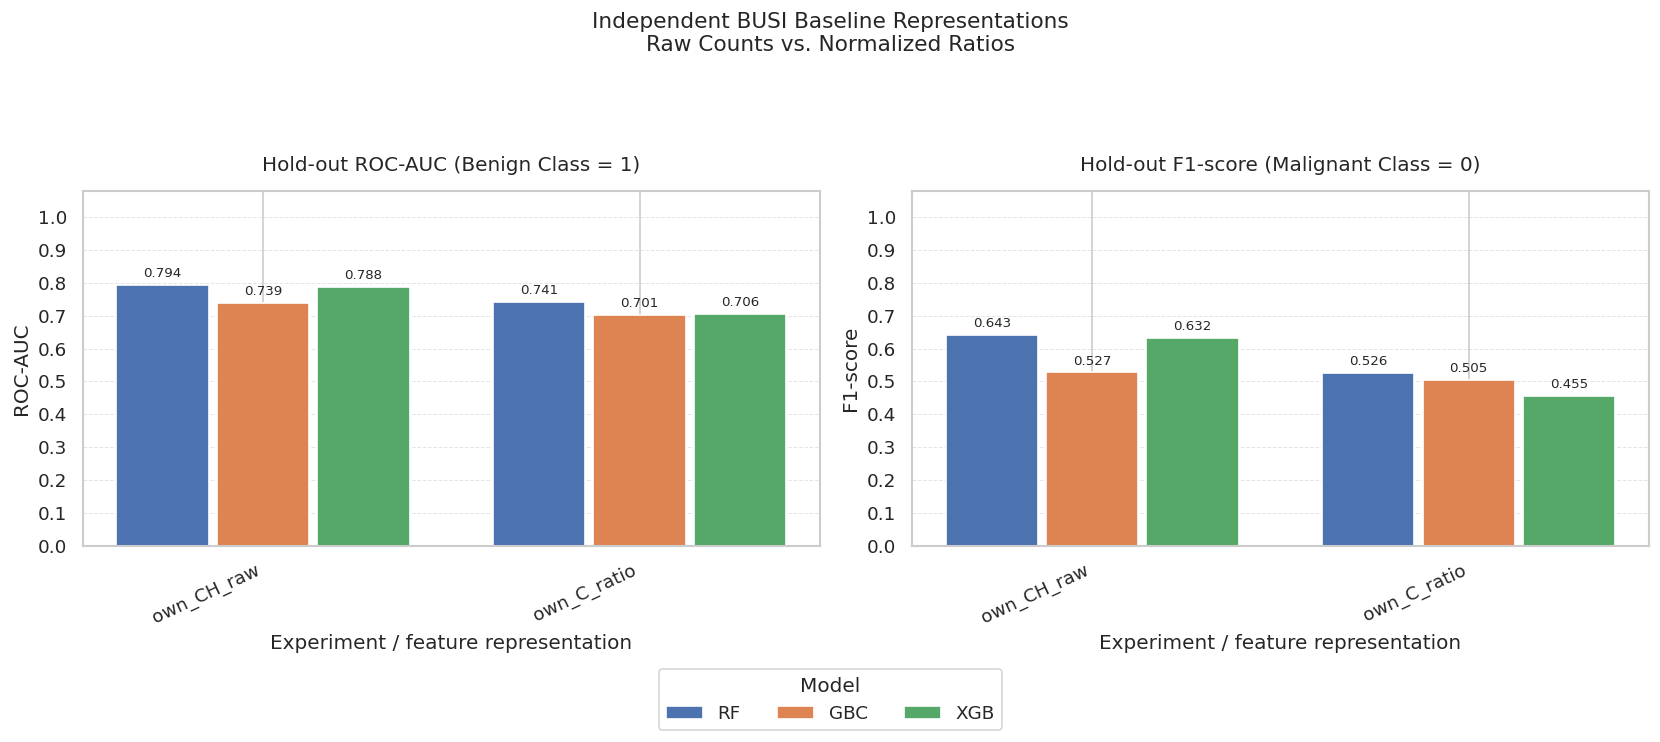

Baseline comparison figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/independent_busi_baseline_comparison.png
Baseline comparison PDF:    /content/drive/MyDrive/BUSI_paper_reproduction/figures/independent_busi_baseline_comparison.pdf
ROC-AUC panel available:    True
Malignant F1 panel available: True


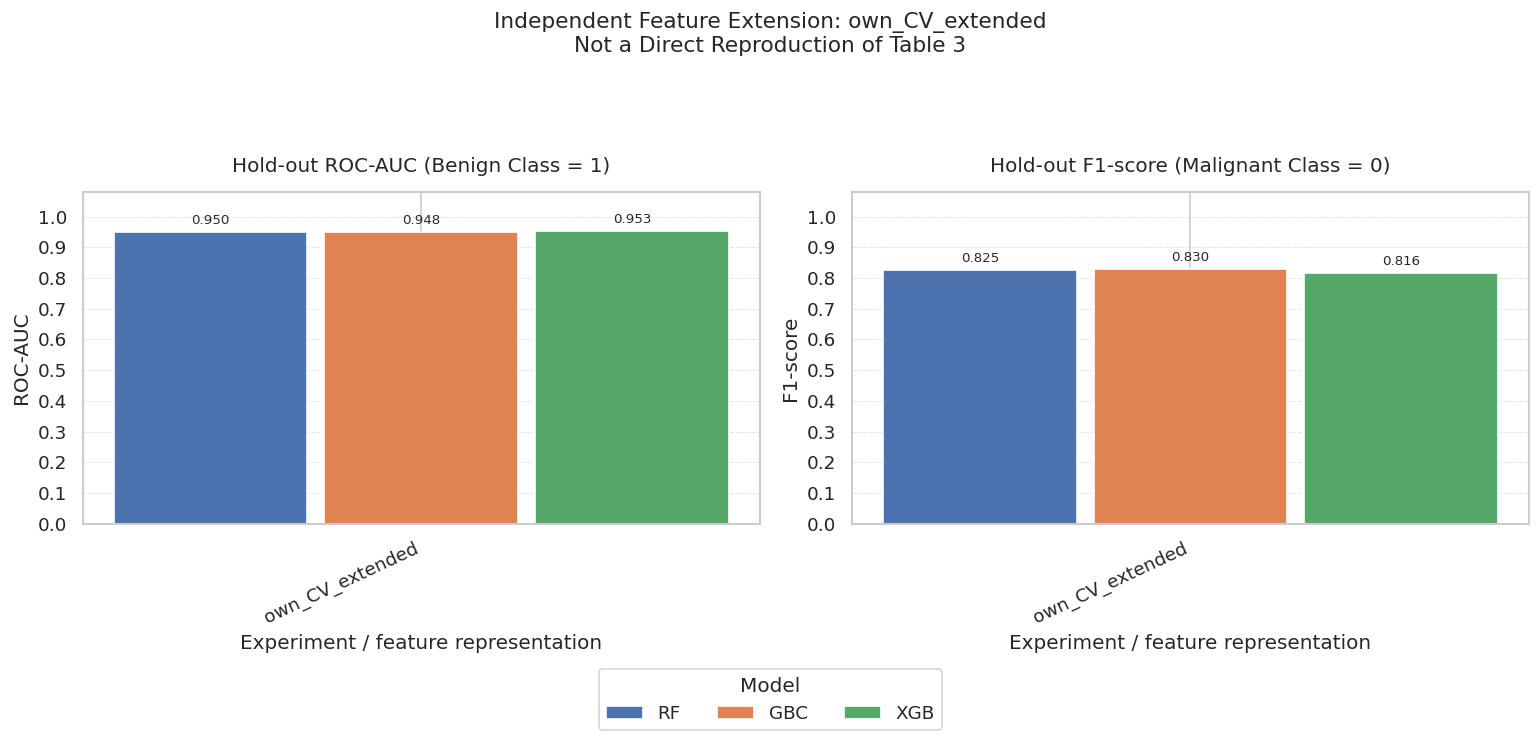

Extension figure: /content/drive/MyDrive/BUSI_paper_reproduction/figures/independent_extension_own_CV_extended.png
Extension PDF:    /content/drive/MyDrive/BUSI_paper_reproduction/figures/independent_extension_own_CV_extended.pdf

FOCUSED TREE-BASED MODEL METRICS


,experiment,model,cv_accuracy_mean,cv_accuracy_sd,cv_auc_mean,cv_auc_sd,test_accuracy,test_roc_auc_benign_class1,test_f1_malignant,test_f1_benign,test_sensitivity_malignant,test_specificity_malignant,test_balanced_accuracy,test_mcc,analysis_group,author_csv_gate_status,interpretation_note
0,own_CH_raw,GBC,0.741259,0.043950,0.786895,0.042654,0.679012,0.738811,0.527273,0.757009,0.557692,0.736364,0.647028,0.286350,independent_busi_baseline,not_applicable,Independently extracted BUSI features. Raw cou...
1,own_CH_raw,RF,0.805498,0.035467,0.864733,0.027833,0.753086,0.793794,0.642857,0.811321,0.692308,0.781818,0.737063,0.458370,independent_busi_baseline,not_applicable,Independently extracted BUSI features. Raw cou...
2,own_CH_raw,XGB,0.772272,0.028055,0.847491,0.022256,0.734568,0.788112,0.632479,0.792271,0.711538,0.745455,0.728497,0.435276,independent_busi_baseline,not_applicable,Independently extracted BUSI features. Raw cou...
3,own_C_ratio,GBC,0.687521,0.038940,0.698952,0.035693,0.685185,0.701049,0.504854,0.769231,0.500000,0.772727,0.636364,0.274145,independent_busi_baseline,not_applicable,Independently extracted BUSI features. Raw cou...
4,own_C_ratio,RF,0.730842,0.027339,0.784630,0.038672,0.722222,0.740997,0.526316,0.803493,0.480769,0.836364,0.658566,0.335298,independent_busi_baseline,not_applicable,Independently extracted BUSI features. Raw cou...
5,own_C_ratio,XGB,0.708054,0.036910,0.755226,0.034423,0.703704,0.706469,0.454545,0.796610,0.384615,0.854545,0.619580,0.268566,independent_busi_baseline,not_applicable,Independently extracted BUSI features. Raw cou...
6,own_CV_extended,GBC,0.888209,0.022436,0.953401,0.015775,0.888889,0.948427,0.830189,0.917431,0.846154,0.909091,0.877622,0.747958,independent_busi_extension,not_applicable,Report separately as an independently develope...
7,own_CV_extended,RF,0.919265,0.013449,0.968103,0.018603,0.895062,0.950350,0.824742,0.925110,0.769231,0.954545,0.861888,0.754403,independent_busi_extension,not_applicable,Report separately as an independently develope...
8,own_CV_extended,XGB,0.877857,0.022281,0.950159,0.015718,0.888889,0.953497,0.816327,0.920354,0.769231,0.945455,0.857343,0.739954,independent_busi_extension,not_applicable,Report separately as an independently develope...



CELL 18 — FINAL SUMMARY
All comparison rows:               12
Authorized author-CSV candidates:  0
Quarantined author-CSV rows:       0
Independent BUSI baseline rows:    8
Independent extension rows:        4
Other experiment rows:             0
Metric-validation issues:          0

Saved CSV files:
  Final comparison:       /content/drive/MyDrive/BUSI_paper_reproduction/csv/final_comparison_table.csv
  Metric validation:      /content/drive/MyDrive/BUSI_paper_reproduction/csv/final_comparison_metric_validation.csv
  Author-CSV candidates:  /content/drive/MyDrive/BUSI_paper_reproduction/csv/author_csv_reference_candidates.csv
  Author-CSV quarantine:  /content/drive/MyDrive/BUSI_paper_reproduction/csv/author_csv_quarantined_results.csv
  BUSI baseline table:    /content/drive/MyDrive/BUSI_paper_reproduction/csv/independent_busi_baseline_comparison.csv
  Independent extension:  /content/drive/MyDrive/BUSI_paper_reproduction/csv/independent_busi_extension_results.csv
  Other experiment

In [24]:
# ============================================================
# Cell 18 — Final Model and Feature-Dataset Comparison
# ============================================================
# Purpose:
#   1. Construct a consolidated, reproducible model-comparison table.
#   2. Preserve cross-validation and hold-out metrics in separate columns.
#   3. Classify experiments according to their methodological role.
#   4. Separate author-CSV reference candidates from independent BUSI results.
#   5. Keep own_CV_extended in a separate independent-extension section.
#   6. Validate metric values, identifiers, and experiment/model uniqueness.
#   7. Plot hold-out ROC-AUC and malignant-class F1-score for explicitly
#      defined independent BUSI experiments.
#   8. Export structured tables, diagnostic logs, figures, and a manifest.
#
# Experiment groups:
#   authors_CH / authors_C:
#       Author-provided CSV reference candidates. These tables are not treated
#       as independent feature families and are not plotted as a direct
#       feature-family comparison.
#
#   own_CH_raw / own_C_ratio:
#       Independently extracted BUSI representations. These are mathematically
#       related through the histogram normalization identity and must not be
#       described as independent sources of information.
#
#   own_CV_extended:
#       Independent extension experiment. Report separately from the
#       paper-reproduction candidates.
#
# Class convention:
#   0 = Malignant
#   1 = Benign
#
# Metric conventions:
#   - CV metrics describe validation within the training partition.
#   - Hold-out metrics describe the reserved test partition.
#   - test_roc_auc_benign_class1 uses the benign-class probability.
#   - test_f1_malignant refers to the malignant class, label 0.
#
# Methodological safeguards:
#   - Do not rank or select models by repeated optimization on hold-out data.
#   - Do not silently drop malformed rows or overwrite source metric values.
#   - Do not claim exact reproduction solely because the pipeline ran.
#   - Do not interpret author-CSV results as validated if the upstream
#     reference-data authorization gate is closed or unresolved.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and prerequisite validation
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


_REQUIRED_GLOBALS_CELL18 = [
    "metrics_df",
    "CSV_DIR",
    "FIG_DIR",
]

_missing_globals_cell18 = [
    variable_name
    for variable_name in _REQUIRED_GLOBALS_CELL18
    if variable_name not in globals()
]

if _missing_globals_cell18:
    raise RuntimeError(
        "Required objects are missing. Run Cell 11 before Cell 18. "
        f"Missing variables: {_missing_globals_cell18}"
    )

if not isinstance(metrics_df, pd.DataFrame):
    raise TypeError(
        "metrics_df must be a pandas DataFrame generated by Cell 11."
    )

CSV_DIR = Path(CSV_DIR)
FIG_DIR = Path(FIG_DIR)

CSV_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 2. Define the standardized comparison schema
# ------------------------------------------------------------

# Keep these columns in a stable order, even when some metrics are unavailable.
COMPARISON_COLUMNS = [
    "experiment",
    "model",
    "cv_accuracy_mean",
    "cv_accuracy_sd",
    "cv_auc_mean",
    "cv_auc_sd",
    "test_accuracy",
    "test_roc_auc_benign_class1",
    "test_f1_malignant",
    "test_f1_benign",
    "test_sensitivity_malignant",
    "test_specificity_malignant",
    "test_balanced_accuracy",
    "test_mcc",
    "best_C",
]

IDENTIFIER_COLUMNS = [
    "experiment",
    "model",
]

# Expected metrics and their numerical domains.
BOUNDED_ZERO_TO_ONE_METRICS = [
    "cv_accuracy_mean",
    "cv_accuracy_sd",
    "cv_auc_mean",
    "cv_auc_sd",
    "test_accuracy",
    "test_roc_auc_benign_class1",
    "test_f1_malignant",
    "test_f1_benign",
    "test_sensitivity_malignant",
    "test_specificity_malignant",
    "test_balanced_accuracy",
]

SIGNED_METRICS = [
    "test_mcc",
]

NUMERIC_METRICS = (
    BOUNDED_ZERO_TO_ONE_METRICS
    + SIGNED_METRICS
    + ["best_C"]
)

print("=" * 88)
print("FINAL MODEL AND FEATURE-DATASET COMPARISON")
print("=" * 88)
print(f"Input metric rows: {len(metrics_df)}")


# ------------------------------------------------------------
# 3. Evaluate the author-CSV methodological gate
# ------------------------------------------------------------

def inspect_author_csv_gate():
    """
    Evaluate whether author-provided reference tables are explicitly authorized.

    Missing authorization variables are treated as unresolved, not as approval.
    This matches the conservative gate used in the updated Cell 11.
    """

    allowed = globals().get(
        "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED",
        False,
    )

    cross_table_blocker = globals().get(
        "AUTHOR_CSV_CROSS_TABLE_BLOCKER",
        True,
    )

    ready_variable_exists = (
        "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY" in globals()
    )

    ready = globals().get(
        "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY",
        False,
    )

    block_reasons = globals().get(
        "AUTHOR_CSV_BLOCK_REASONS",
        None,
    )

    blockers = []

    if allowed is not True:
        blockers.append(
            "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED is not True."
        )

    if cross_table_blocker is not False:
        blockers.append(
            "AUTHOR_CSV_CROSS_TABLE_BLOCKER is not explicitly False."
        )

    if ready_variable_exists and ready is not True:
        blockers.append(
            "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY is not True."
        )

    if block_reasons:
        blockers.append(
            "AUTHOR_CSV_BLOCK_REASONS contains unresolved items."
        )

    is_authorized = len(blockers) == 0

    return {
        "authorized": bool(is_authorized),
        "allowed_variable": allowed,
        "cross_table_blocker": cross_table_blocker,
        "ready_variable_present": bool(ready_variable_exists),
        "ready_variable": ready,
        "block_reasons": block_reasons,
        "blockers": blockers,
    }


author_gate = inspect_author_csv_gate()

print("\nAuthor-CSV reference authorization:")
print(f"Authorized: {author_gate['authorized']}")

if author_gate["blockers"]:
    for blocker in author_gate["blockers"]:
        print(f"  - {blocker}")

# Do not interpret author-table results as reference candidates if the
# upstream gate is not explicitly satisfied. Any such rows are quarantined
# into a separate output for audit, without silently deleting them.


# ------------------------------------------------------------
# 4. Define experiment groups and interpretation labels
# ------------------------------------------------------------

AUTHOR_REFERENCE_EXPERIMENTS = {
    "authors_CH",
    "authors_C",
}

OWN_BASELINE_EXPERIMENTS = {
    "own_CH_raw",
    "own_C_ratio",
}

OWN_EXTENSION_EXPERIMENTS = {
    "own_CV_extended",
}


def classify_experiment(experiment_name):
    """
    Assign a methodological category without claiming exact reproduction.
    """

    experiment_name = str(experiment_name)

    if experiment_name in AUTHOR_REFERENCE_EXPERIMENTS:

        if author_gate["authorized"]:
            return {
                "analysis_group": "author_csv_reference_candidate",
                "comparison_scope": (
                    "Author CSV reference candidate; not verified as exact reproduction"
                ),
                "author_csv_gate_status": "authorized",
                "eligible_for_reference_summary": True,
                "exact_reproduction_verified": False,
                "interpretation_note": (
                    "Report this table as an author-CSV reference candidate. "
                    "Do not treat authors_CH and authors_C as independent "
                    "feature families or assume that the reported metrics "
                    "reproduce the paper's exact results."
                ),
            }

        return {
            "analysis_group": "author_csv_quarantined",
            "comparison_scope": (
                "Unverified author-CSV result; excluded from reference summaries"
            ),
            "author_csv_gate_status": "blocked_or_unresolved",
            "eligible_for_reference_summary": False,
            "exact_reproduction_verified": False,
            "interpretation_note": (
                "The author-CSV authorization gate is not explicitly satisfied. "
                "Retain the row for audit only; do not interpret it as a valid "
                "reference result."
            ),
        }

    if experiment_name in OWN_BASELINE_EXPERIMENTS:
        return {
            "analysis_group": "independent_busi_baseline",
            "comparison_scope": (
                "Independent BUSI baseline representation"
            ),
            "author_csv_gate_status": "not_applicable",
            "eligible_for_reference_summary": False,
            "exact_reproduction_verified": False,
            "interpretation_note": (
                "Independently extracted BUSI features. Raw counts and "
                "normalized ratios are algebraically related representations, "
                "not independent information sources."
            ),
        }

    if experiment_name in OWN_EXTENSION_EXPERIMENTS:
        return {
            "analysis_group": "independent_busi_extension",
            "comparison_scope": (
                "Independent extension; not a direct paper-reproduction result"
            ),
            "author_csv_gate_status": "not_applicable",
            "eligible_for_reference_summary": False,
            "exact_reproduction_verified": False,
            "interpretation_note": (
                "Report separately as an independently developed feature "
                "extension. Do not use this result as a reproduction of Table 3."
            ),
        }

    return {
        "analysis_group": "other_experiment",
        "comparison_scope": (
            "Other experiment; interpretation requires separate verification"
        ),
        "author_csv_gate_status": "not_applicable",
        "eligible_for_reference_summary": False,
        "exact_reproduction_verified": False,
        "interpretation_note": (
            "This experiment is not part of the predefined author-reference, "
            "BUSI baseline, or independent-extension groups."
        ),
    }


# ------------------------------------------------------------
# 5. Normalize identifiers and build the consolidated table
# ------------------------------------------------------------

# Preserve all original columns from metrics_df, including any additional
# metrics created by Cell 9, while adding the standardized comparison schema.
comparison_df = metrics_df.copy()

# Required identifier columns must be present.
missing_identifier_columns = [
    column
    for column in IDENTIFIER_COLUMNS
    if column not in comparison_df.columns
]

if missing_identifier_columns:
    raise ValueError(
        "metrics_df is missing required identifier columns: "
        f"{missing_identifier_columns}"
    )

# Add standardized metric columns when they were not emitted by the evaluator.
missing_optional_columns = [
    column
    for column in COMPARISON_COLUMNS
    if column not in comparison_df.columns
]

if missing_optional_columns:
    warnings.warn(
        "The following standardized metrics are unavailable in metrics_df "
        "and will be represented as NaN rather than fabricated: "
        f"{missing_optional_columns}",
        RuntimeWarning,
    )

    for column in missing_optional_columns:
        comparison_df[column] = np.nan

# Normalize experiment/model identifiers.
for column in IDENTIFIER_COLUMNS:
    comparison_df[column] = (
        comparison_df[column]
        .astype("string")
        .str.strip()
    )

invalid_identifier_mask = (
    comparison_df[IDENTIFIER_COLUMNS].isna().any(axis=1)
    | comparison_df[IDENTIFIER_COLUMNS].eq("").any(axis=1)
)

if invalid_identifier_mask.any():

    invalid_identifier_path = (
        CSV_DIR / "final_comparison_invalid_identifiers.csv"
    )

    comparison_df.loc[
        invalid_identifier_mask
    ].to_csv(
        invalid_identifier_path,
        index=False,
    )

    raise ValueError(
        "Missing or empty experiment/model identifiers were detected. "
        f"Review: {invalid_identifier_path}"
    )


# ------------------------------------------------------------
# 6. Validate experiment/model uniqueness
# ------------------------------------------------------------

# Each experiment/model pair must have at most one final aggregate result.
duplicate_mask = comparison_df.duplicated(
    subset=IDENTIFIER_COLUMNS,
    keep=False,
)

DUPLICATE_ROWS_PATH = (
    CSV_DIR / "final_comparison_duplicate_rows.csv"
)

if duplicate_mask.any():

    duplicate_rows_df = (
        comparison_df.loc[duplicate_mask]
        .sort_values(
            IDENTIFIER_COLUMNS
        )
        .reset_index(drop=True)
    )

    duplicate_rows_df.to_csv(
        DUPLICATE_ROWS_PATH,
        index=False,
    )

    raise ValueError(
        "Duplicate experiment/model combinations were detected. "
        "The cell will not silently average or select among these records. "
        f"Inspect: {DUPLICATE_ROWS_PATH}"
    )


# ------------------------------------------------------------
# 7. Convert metrics to numeric and create a value-validation audit
# ------------------------------------------------------------

metric_validation_rows = []

for metric_column in NUMERIC_METRICS:

    if metric_column not in comparison_df.columns:
        continue

    original_values = comparison_df[
        metric_column
    ].copy()

    converted_values = pd.to_numeric(
        original_values,
        errors="coerce",
    )

    # Log non-empty values that cannot be converted to numbers.
    conversion_failure_mask = (
        original_values.notna()
        & converted_values.isna()
    )

    for row_index in comparison_df.index[
        conversion_failure_mask
    ]:

        metric_validation_rows.append({
            "source_row_index": str(row_index),
            "experiment": comparison_df.at[
                row_index, "experiment"
            ],
            "model": comparison_df.at[
                row_index, "model"
            ],
            "metric": metric_column,
            "source_value": str(
                original_values.loc[row_index]
            ),
            "issue": "non_numeric_value",
        })

    # Do not replace missing values with zero.
    comparison_df[metric_column] = converted_values

    numeric_array = comparison_df[
        metric_column
    ].to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    )

    infinite_mask = (
        comparison_df[metric_column].notna().to_numpy()
        & ~np.isfinite(numeric_array)
    )

    for row_position in np.flatnonzero(infinite_mask):

        row_index = comparison_df.index[
            row_position
        ]

        metric_validation_rows.append({
            "source_row_index": str(row_index),
            "experiment": comparison_df.at[
                row_index, "experiment"
            ],
            "model": comparison_df.at[
                row_index, "model"
            ],
            "metric": metric_column,
            "source_value": str(
                comparison_df.at[
                    row_index,
                    metric_column,
                ]
            ),
            "issue": "non_finite_value",
        })

    # Preserve the original metric for auditing, but replace infinite
    # values with NaN so that plots and summaries cannot treat them as scores.
    comparison_df.loc[
        infinite_mask,
        metric_column,
    ] = np.nan


# ------------------------------------------------------------
# 8. Validate bounded metric ranges
# ------------------------------------------------------------

for metric_column in BOUNDED_ZERO_TO_ONE_METRICS:

    if metric_column not in comparison_df.columns:
        continue

    values = comparison_df[
        metric_column
    ]

    out_of_range_mask = (
        values.notna()
        & ~values.between(0.0, 1.0)
    )

    for row_index in comparison_df.index[
        out_of_range_mask
    ]:

        metric_validation_rows.append({
            "source_row_index": str(row_index),
            "experiment": comparison_df.at[
                row_index, "experiment"
            ],
            "model": comparison_df.at[
                row_index, "model"
            ],
            "metric": metric_column,
            "source_value": str(
                values.loc[row_index]
            ),
            "issue": "value_outside_expected_0_to_1_range",
        })

    if out_of_range_mask.any():

        warnings.warn(
            f"{metric_column} contains values outside [0, 1]. "
            "Source values will be retained for auditing, but excluded "
            "from visualizations and interpretation as valid scores.",
            RuntimeWarning,
        )


for metric_column in SIGNED_METRICS:

    if metric_column not in comparison_df.columns:
        continue

    values = comparison_df[
        metric_column
    ]

    out_of_range_mask = (
        values.notna()
        & ~values.between(-1.0, 1.0)
    )

    for row_index in comparison_df.index[
        out_of_range_mask
    ]:

        metric_validation_rows.append({
            "source_row_index": str(row_index),
            "experiment": comparison_df.at[
                row_index, "experiment"
            ],
            "model": comparison_df.at[
                row_index, "model"
            ],
            "metric": metric_column,
            "source_value": str(
                values.loc[row_index]
            ),
            "issue": "value_outside_expected_minus1_to_1_range",
        })

    if out_of_range_mask.any():

        warnings.warn(
            f"{metric_column} contains values outside [-1, 1]. "
            "Review the upstream evaluation outputs.",
            RuntimeWarning,
        )


# ------------------------------------------------------------
# 9. Add explicit methodological metadata
# ------------------------------------------------------------

metadata_records = [
    classify_experiment(experiment_name)
    for experiment_name in comparison_df["experiment"]
]

metadata_df = pd.DataFrame(
    metadata_records,
    index=comparison_df.index,
)

for column in metadata_df.columns:
    comparison_df[column] = metadata_df[column]

# Mark metrics as final-reporting outputs, not model-selection criteria.
comparison_df["holdout_use"] = (
    "Final reporting only; not for repeated model selection"
)

comparison_df["comparison_grouping_rule"] = (
    "Compare only within explicitly defined methodological groups"
)

# Stable column ordering: standardized metrics, then methodological metadata,
# then any additional evaluator columns retained from the input.
metadata_columns = [
    "analysis_group",
    "comparison_scope",
    "author_csv_gate_status",
    "eligible_for_reference_summary",
    "exact_reproduction_verified",
    "interpretation_note",
    "holdout_use",
    "comparison_grouping_rule",
]

standard_columns = [
    column
    for column in COMPARISON_COLUMNS
    if column in comparison_df.columns
]

extra_columns = [
    column
    for column in comparison_df.columns
    if column not in standard_columns
    and column not in metadata_columns
]

comparison_df = comparison_df[
    standard_columns
    + metadata_columns
    + extra_columns
].copy()

comparison_df = (
    comparison_df
    .sort_values(
        ["analysis_group", "experiment", "model"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 10. Export the complete final comparison table and metric audit
# ------------------------------------------------------------

FINAL_COMPARISON_PATH = (
    CSV_DIR / "final_comparison_table.csv"
)

METRIC_VALIDATION_PATH = (
    CSV_DIR / "final_comparison_metric_validation.csv"
)

comparison_df.to_csv(
    FINAL_COMPARISON_PATH,
    index=False,
)

metric_validation_df = pd.DataFrame(
    metric_validation_rows,
    columns=[
        "source_row_index",
        "experiment",
        "model",
        "metric",
        "source_value",
        "issue",
    ],
)

metric_validation_df.to_csv(
    METRIC_VALIDATION_PATH,
    index=False,
)

print("\n" + "=" * 88)
print("CONSOLIDATED COMPARISON TABLE")
print("=" * 88)
print(f"Rows: {len(comparison_df)}")
print(f"Full comparison table: {FINAL_COMPARISON_PATH}")
print(f"Metric validation log: {METRIC_VALIDATION_PATH}")

if comparison_df.empty:
    print("No completed experiment/model metric rows are available.")
else:
    display(comparison_df)


# ------------------------------------------------------------
# 11. Split the results by methodological role
# ------------------------------------------------------------

# Author-CSV results are kept outside the independent BUSI model-comparison
# plots. Their inclusion here is controlled by the upstream authorization gate.
author_reference_df = comparison_df[
    comparison_df["analysis_group"]
    == "author_csv_reference_candidate"
].copy()

author_quarantined_df = comparison_df[
    comparison_df["analysis_group"]
    == "author_csv_quarantined"
].copy()

# These independently extracted feature families are algebraically related.
busi_baseline_df = comparison_df[
    comparison_df["analysis_group"]
    == "independent_busi_baseline"
].copy()

# Report the extended feature set separately as an independent development.
busi_extension_df = comparison_df[
    comparison_df["analysis_group"]
    == "independent_busi_extension"
].copy()

other_experiments_df = comparison_df[
    comparison_df["analysis_group"]
    == "other_experiment"
].copy()


AUTHOR_REFERENCE_PATH = (
    CSV_DIR / "author_csv_reference_candidates.csv"
)

AUTHOR_QUARANTINE_PATH = (
    CSV_DIR / "author_csv_quarantined_results.csv"
)

BUSI_BASELINE_PATH = (
    CSV_DIR / "independent_busi_baseline_comparison.csv"
)

BUSI_EXTENSION_PATH = (
    CSV_DIR / "independent_busi_extension_results.csv"
)

OTHER_EXPERIMENTS_PATH = (
    CSV_DIR / "other_experiment_results.csv"
)

# Write every group even if it is empty, preserving a predictable output layout.
author_reference_df.to_csv(
    AUTHOR_REFERENCE_PATH,
    index=False,
)

author_quarantined_df.to_csv(
    AUTHOR_QUARANTINE_PATH,
    index=False,
)

busi_baseline_df.to_csv(
    BUSI_BASELINE_PATH,
    index=False,
)

busi_extension_df.to_csv(
    BUSI_EXTENSION_PATH,
    index=False,
)

other_experiments_df.to_csv(
    OTHER_EXPERIMENTS_PATH,
    index=False,
)


# ------------------------------------------------------------
# 12. Display author-CSV candidates separately
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("AUTHOR-CSV REFERENCE CANDIDATES")
print("=" * 88)

if not author_reference_df.empty:

    print(
        "These are reference candidates only. authors_CH and authors_C "
        "are not treated as independent feature families, and exact "
        "reproduction of the paper has not been established."
    )

    display(
        author_reference_df[
            [
                column
                for column in [
                    "experiment",
                    "model",
                    "cv_accuracy_mean",
                    "cv_auc_mean",
                    "test_accuracy",
                    "test_roc_auc_benign_class1",
                    "test_f1_malignant",
                    "author_csv_gate_status",
                    "exact_reproduction_verified",
                ]
                if column in author_reference_df.columns
            ]
        ]
    )

else:

    print(
        "No authorized author-CSV reference candidates are available."
    )

if not author_quarantined_df.empty:

    print("\nAuthor-CSV rows blocked from reference interpretation:")

    display(
        author_quarantined_df[
            [
                column
                for column in [
                    "experiment",
                    "model",
                    "test_accuracy",
                    "author_csv_gate_status",
                    "interpretation_note",
                ]
                if column in author_quarantined_df.columns
            ]
        ]
    )


# ------------------------------------------------------------
# 13. Display the independent BUSI baseline and extension separately
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("INDEPENDENT BUSI BASELINE REPRESENTATIONS")
print("=" * 88)

if not busi_baseline_df.empty:

    print(
        "own_CH_raw and own_C_ratio are derived from the same independently "
        "extracted BUSI feature family. Their comparison is descriptive; "
        "they must not be presented as independent information sources."
    )

    display(
        busi_baseline_df[
            [
                column
                for column in [
                    "experiment",
                    "model",
                    "cv_accuracy_mean",
                    "cv_auc_mean",
                    "test_accuracy",
                    "test_roc_auc_benign_class1",
                    "test_f1_malignant",
                    "interpretation_note",
                ]
                if column in busi_baseline_df.columns
            ]
        ]
    )

else:
    print("No independent BUSI baseline results are available.")


print("\n" + "=" * 88)
print("INDEPENDENT EXTENSION: own_CV_extended")
print("=" * 88)

if not busi_extension_df.empty:

    print(
        "The following results belong to an independently developed "
        "feature extension. They are not presented as a direct reproduction "
        "of Table 3."
    )

    display(
        busi_extension_df[
            [
                column
                for column in [
                    "experiment",
                    "model",
                    "cv_accuracy_mean",
                    "cv_auc_mean",
                    "test_accuracy",
                    "test_roc_auc_benign_class1",
                    "test_f1_malignant",
                    "interpretation_note",
                ]
                if column in busi_extension_df.columns
            ]
        ]
    )

else:
    print("No own_CV_extended results are available.")


# ------------------------------------------------------------
# 14. Define safe plotting utilities
# ------------------------------------------------------------

FOCUSED_MODELS = [
    "RF",
    "GBC",
    "XGB",
]

ROC_AUC_COLUMN = "test_roc_auc_benign_class1"
MALIGNANT_F1_COLUMN = "test_f1_malignant"

FOCUSED_METRICS = [
    ROC_AUC_COLUMN,
    MALIGNANT_F1_COLUMN,
]


def sanitize_plot_metric_values(
    data,
    metric_column,
):
    """Return the rows with valid metric values for plotting."""

    if metric_column not in data.columns:
        return data.iloc[0:0].copy()

    output = data.copy()

    output[metric_column] = pd.to_numeric(
        output[metric_column],
        errors="coerce",
    )

    values = output[metric_column].to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    )

    valid_mask = (
        np.isfinite(values)
        & (values >= 0.0)
        & (values <= 1.0)
    )

    invalid_count = int(
        (~valid_mask).sum()
    )

    if invalid_count:

        warnings.warn(
            f"{metric_column}: {invalid_count} rows contain missing, "
            "non-finite, or out-of-range scores. These rows will not be "
            "plotted, but remain in the exported comparison table.",
            RuntimeWarning,
        )

    return output.loc[
        valid_mask
    ].copy()


def plot_metric_grouped_bars(
    data,
    experiment_order,
    model_order,
    metric_column,
    metric_title,
    y_label,
    axis,
):
    """
    Plot a metric across one predefined experiment group.

    This function does not automatically mix author-CSV results, independent
    baselines, and the independent extension. The caller selects the group.
    """

    if data.empty:
        axis.text(
            0.5,
            0.5,
            "No data available",
            ha="center",
            va="center",
            transform=axis.transAxes,
        )

        axis.set_title(metric_title)
        axis.set_axis_off()

        return False

    panel_df = sanitize_plot_metric_values(
        data,
        metric_column,
    )

    if panel_df.empty:

        axis.text(
            0.5,
            0.5,
            f"No valid values for\n{metric_column}",
            ha="center",
            va="center",
            transform=axis.transAxes,
        )

        axis.set_title(metric_title)
        axis.set_axis_off()

        return False

    # Retain only categories that actually occur in this group.
    present_experiments = set(
        panel_df["experiment"].astype(str)
    )

    present_models = set(
        panel_df["model"].astype(str)
    )

    actual_experiment_order = [
        name
        for name in experiment_order
        if name in present_experiments
    ]

    actual_model_order = [
        name
        for name in model_order
        if name in present_models
    ]

    x_positions = np.arange(
        len(actual_experiment_order)
    )

    model_count = max(
        len(actual_model_order),
        1,
    )

    group_width = 0.80

    bar_width = (
        group_width / model_count
    )

    offsets = (
        np.arange(model_count)
        - (model_count - 1) / 2
    ) * bar_width

    # Unique experiment/model combinations were validated upstream.
    value_lookup = {
        (
            str(row["experiment"]),
            str(row["model"]),
        ): float(row[metric_column])
        for _, row in panel_df.iterrows()
    }

    n_bars = len(actual_experiment_order) * len(
        actual_model_order
    )

    for model_index, model_name in enumerate(
        actual_model_order
    ):

        heights = []

        for experiment_name in actual_experiment_order:

            value = value_lookup.get(
                (
                    experiment_name,
                    model_name,
                ),
                np.nan,
            )

            heights.append(
                value
            )

        heights_array = np.asarray(
            heights,
            dtype=np.float64,
        )

        bars = axis.bar(
            x_positions + offsets[model_index],
            heights_array,
            width=bar_width * 0.92,
            label=model_name,
        )

        # Add compact numerical labels when the plot is not too dense.
        if n_bars <= 18:

            for bar in bars:

                height = bar.get_height()

                if not np.isfinite(height):
                    continue

                axis.annotate(
                    f"{height:.3f}",
                    xy=(
                        bar.get_x() + bar.get_width() / 2,
                        height,
                    ),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                )

    axis.set_title(
        metric_title,
        fontsize=12,
        pad=12,
    )

    axis.set_xlabel(
        "Experiment / feature representation"
    )

    axis.set_ylabel(
        y_label
    )

    axis.set_ylim(
        0.0,
        1.08,
    )

    axis.set_yticks(
        np.arange(
            0.0,
            1.01,
            0.1,
        )
    )

    axis.set_xticks(
        x_positions
    )

    axis.set_xticklabels(
        actual_experiment_order,
        rotation=25,
        ha="right",
    )

    axis.grid(
        axis="y",
        linestyle="--",
        linewidth=0.6,
        alpha=0.5,
    )

    axis.set_axisbelow(True)

    return True


# ------------------------------------------------------------
# 15. Prepare deterministic ordering for independent BUSI comparisons
# ------------------------------------------------------------

PREFERRED_EXPERIMENT_ORDER = [
    "own_CH_raw",
    "own_C_ratio",
    "own_CV_extended",
]

# The two baseline representations may be compared descriptively in one
# figure. The extension is intentionally excluded from this baseline plot.
BASELINE_PLOT_EXPERIMENTS = [
    "own_CH_raw",
    "own_C_ratio",
]

baseline_plot_df = busi_baseline_df.copy()

baseline_model_order = [
    model
    for model in FOCUSED_MODELS
    if model in set(
        baseline_plot_df["model"].astype(str)
    )
]

baseline_experiment_order = [
    name
    for name in BASELINE_PLOT_EXPERIMENTS
    if name in set(
        baseline_plot_df["experiment"].astype(str)
    )
]

baseline_plot_path = (
    FIG_DIR / "independent_busi_baseline_comparison.png"
)

baseline_plot_pdf_path = (
    FIG_DIR / "independent_busi_baseline_comparison.pdf"
)


# ------------------------------------------------------------
# 16. Plot the independent BUSI baseline comparison
# ------------------------------------------------------------

if (
    not baseline_plot_df.empty
    and baseline_experiment_order
    and baseline_model_order
):

    fig_width = max(
        14,
        min(
            22,
            2.4 * len(baseline_experiment_order),
        ),
    )

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(fig_width, 6),
    )

    roc_auc_available = plot_metric_grouped_bars(
        data=baseline_plot_df,
        experiment_order=baseline_experiment_order,
        model_order=baseline_model_order,
        metric_column=ROC_AUC_COLUMN,
        metric_title="Hold-out ROC-AUC (Benign Class = 1)",
        y_label="ROC-AUC",
        axis=axes[0],
    )

    malignant_f1_available = plot_metric_grouped_bars(
        data=baseline_plot_df,
        experiment_order=baseline_experiment_order,
        model_order=baseline_model_order,
        metric_column=MALIGNANT_F1_COLUMN,
        metric_title="Hold-out F1-score (Malignant Class = 0)",
        y_label="F1-score",
        axis=axes[1],
    )

    # Use a single legend where possible.
    handles, labels = axes[0].get_legend_handles_labels()

    for axis in axes:

        if axis.get_legend() is not None:
            axis.get_legend().remove()

    if handles:

        fig.legend(
            handles,
            labels,
            title="Model",
            loc="lower center",
            bbox_to_anchor=(0.5, 0.01),
            ncol=min(
                len(labels),
                4,
            ),
        )

    fig.suptitle(
        "Independent BUSI Baseline Representations\n"
        "Raw Counts vs. Normalized Ratios",
        fontsize=13,
        y=1.02,
    )

    fig.tight_layout(
        rect=[0, 0.10, 1, 0.94]
    )

    fig.savefig(
        baseline_plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        baseline_plot_pdf_path,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Baseline comparison figure: {baseline_plot_path}")
    print(f"Baseline comparison PDF:    {baseline_plot_pdf_path}")
    print(f"ROC-AUC panel available:    {roc_auc_available}")
    print(f"Malignant F1 panel available: {malignant_f1_available}")

else:
    print(
        "The independent BUSI baseline plot was skipped because no valid "
        "own_CH_raw / own_C_ratio results were available."
    )


# ------------------------------------------------------------
# 17. Plot own_CV_extended separately as an independent extension
# ------------------------------------------------------------

extension_plot_df = busi_extension_df.copy()

extension_model_order = [
    model
    for model in FOCUSED_MODELS
    if model in set(
        extension_plot_df["model"].astype(str)
    )
]

extension_experiment_order = [
    "own_CV_extended"
] if (
    not extension_plot_df.empty
    and "own_CV_extended" in set(
        extension_plot_df["experiment"].astype(str)
    )
) else []

extension_plot_path = (
    FIG_DIR / "independent_extension_own_CV_extended.png"
)

extension_plot_pdf_path = (
    FIG_DIR / "independent_extension_own_CV_extended.pdf"
)

if (
    not extension_plot_df.empty
    and extension_model_order
    and extension_experiment_order
):

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(13, 6),
    )

    plot_metric_grouped_bars(
        data=extension_plot_df,
        experiment_order=extension_experiment_order,
        model_order=extension_model_order,
        metric_column=ROC_AUC_COLUMN,
        metric_title="Hold-out ROC-AUC (Benign Class = 1)",
        y_label="ROC-AUC",
        axis=axes[0],
    )

    plot_metric_grouped_bars(
        data=extension_plot_df,
        experiment_order=extension_experiment_order,
        model_order=extension_model_order,
        metric_column=MALIGNANT_F1_COLUMN,
        metric_title="Hold-out F1-score (Malignant Class = 0)",
        y_label="F1-score",
        axis=axes[1],
    )

    handles, labels = axes[0].get_legend_handles_labels()

    for axis in axes:

        if axis.get_legend() is not None:
            axis.get_legend().remove()

    if handles:

        fig.legend(
            handles,
            labels,
            title="Model",
            loc="lower center",
            bbox_to_anchor=(0.5, 0.01),
            ncol=min(
                len(labels),
                4,
            ),
        )

    fig.suptitle(
        "Independent Feature Extension: own_CV_extended\n"
        "Not a Direct Reproduction of Table 3",
        fontsize=13,
        y=1.02,
    )

    fig.tight_layout(
        rect=[0, 0.10, 1, 0.94]
    )

    fig.savefig(
        extension_plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        extension_plot_pdf_path,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(f"Extension figure: {extension_plot_path}")
    print(f"Extension PDF:    {extension_plot_pdf_path}")

else:
    print(
        "The own_CV_extended figure was skipped because no valid extension "
        "results were available for the selected models."
    )


# ------------------------------------------------------------
# 18. Export focused model tables
# ------------------------------------------------------------

FOCUSED_DISPLAY_COLUMNS = [
    "experiment",
    "model",
    "cv_accuracy_mean",
    "cv_accuracy_sd",
    "cv_auc_mean",
    "cv_auc_sd",
    "test_accuracy",
    "test_roc_auc_benign_class1",
    "test_f1_malignant",
    "test_f1_benign",
    "test_sensitivity_malignant",
    "test_specificity_malignant",
    "test_balanced_accuracy",
    "test_mcc",
]

available_focused_columns = [
    column
    for column in FOCUSED_DISPLAY_COLUMNS
    if column in comparison_df.columns
]

# Filter to the requested model set without ranking models by hold-out results.
tree_model_comparison_df = comparison_df[
    comparison_df["model"].astype(str).isin(
        FOCUSED_MODELS
    )
].copy()

TREE_MODEL_COMPARISON_PATH = (
    CSV_DIR / "final_tree_model_comparison.csv"
)

tree_model_comparison_df.to_csv(
    TREE_MODEL_COMPARISON_PATH,
    index=False,
)

if not tree_model_comparison_df.empty:

    print("\n" + "=" * 88)
    print("FOCUSED TREE-BASED MODEL METRICS")
    print("=" * 88)

    display(
        tree_model_comparison_df[
            available_focused_columns
            + [
                column
                for column in [
                    "analysis_group",
                    "author_csv_gate_status",
                    "interpretation_note",
                ]
                if column in tree_model_comparison_df.columns
            ]
        ].sort_values(
            ["analysis_group", "experiment", "model"]
        ).reset_index(drop=True)
    )

else:
    print(
        "No RF/GBC/XGB metric rows are available in the final table."
    )


# ------------------------------------------------------------
# 19. Write the final run manifest
# ------------------------------------------------------------

FINAL_COMPARISON_MANIFEST_PATH = (
    CSV_DIR / "final_comparison_manifest.json"
)

manifest = {
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "cell": "Cell 18 — Final Model and Feature-Dataset Comparison",
    "class_mapping": {
        "0": "Malignant",
        "1": "Benign",
    },
    "metric_conventions": {
        "cross_validation": (
            "CV metrics refer to validation within the training partition."
        ),
        "holdout": (
            "Hold-out metrics are for final reporting and must not be used "
            "for repeated model selection or hyperparameter tuning."
        ),
        "test_roc_auc_benign_class1": (
            "ROC-AUC according to the evaluation convention in Cell 9; "
            "benign is label 1."
        ),
        "test_f1_malignant": (
            "F1-score for malignant class, label 0."
        ),
    },
    "author_csv_gate": {
        "authorized": author_gate["authorized"],
        "allowed_variable": author_gate["allowed_variable"],
        "cross_table_blocker": author_gate["cross_table_blocker"],
        "ready_variable_present": author_gate["ready_variable_present"],
        "ready_variable": author_gate["ready_variable"],
        "blockers": author_gate["blockers"],
    },
    "interpretation_rules": {
        "authors_CH_and_authors_C": (
            "Keep as separate author-CSV reference candidates when the "
            "authorization gate is satisfied. Do not treat them as two "
            "independent feature families. Exact reproduction is not inferred "
            "from successful execution alone."
        ),
        "own_CH_raw_and_own_C_ratio": (
            "Independently extracted BUSI baseline representations that are "
            "algebraically related by histogram normalization."
        ),
        "own_CV_extended": (
            "Independent extension, reported separately and not as a direct "
            "reproduction of Table 3."
        ),
    },
    "counts": {
        "total_comparison_rows": int(len(comparison_df)),
        "author_reference_candidates": int(len(author_reference_df)),
        "author_quarantined_rows": int(len(author_quarantined_df)),
        "independent_busi_baseline_rows": int(len(busi_baseline_df)),
        "independent_busi_extension_rows": int(len(busi_extension_df)),
        "other_experiment_rows": int(len(other_experiments_df)),
        "metric_validation_issues": int(
            len(metric_validation_df)
        ),
        "focused_tree_model_rows": int(
            len(tree_model_comparison_df)
        ),
    },
    "outputs": {
        "final_comparison_table": str(FINAL_COMPARISON_PATH),
        "metric_validation": str(METRIC_VALIDATION_PATH),
        "author_reference_candidates": str(AUTHOR_REFERENCE_PATH),
        "author_quarantined_results": str(AUTHOR_QUARANTINE_PATH),
        "independent_busi_baseline": str(BUSI_BASELINE_PATH),
        "independent_busi_extension": str(BUSI_EXTENSION_PATH),
        "other_experiments": str(OTHER_EXPERIMENTS_PATH),
        "tree_model_comparison": str(TREE_MODEL_COMPARISON_PATH),
    },
}

with open(
    FINAL_COMPARISON_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as manifest_file:

    json.dump(
        manifest,
        manifest_file,
        indent=2,
        ensure_ascii=False,
        default=str,
    )


# ------------------------------------------------------------
# 20. Final status and output summary
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("CELL 18 — FINAL SUMMARY")
print("=" * 88)

print(f"All comparison rows:               {len(comparison_df)}")
print(f"Authorized author-CSV candidates:  {len(author_reference_df)}")
print(f"Quarantined author-CSV rows:       {len(author_quarantined_df)}")
print(f"Independent BUSI baseline rows:    {len(busi_baseline_df)}")
print(f"Independent extension rows:        {len(busi_extension_df)}")
print(f"Other experiment rows:             {len(other_experiments_df)}")
print(f"Metric-validation issues:          {len(metric_validation_df)}")

print("\nSaved CSV files:")
print(f"  Final comparison:       {FINAL_COMPARISON_PATH}")
print(f"  Metric validation:      {METRIC_VALIDATION_PATH}")
print(f"  Author-CSV candidates:  {AUTHOR_REFERENCE_PATH}")
print(f"  Author-CSV quarantine:  {AUTHOR_QUARANTINE_PATH}")
print(f"  BUSI baseline table:    {BUSI_BASELINE_PATH}")
print(f"  Independent extension:  {BUSI_EXTENSION_PATH}")
print(f"  Other experiments:      {OTHER_EXPERIMENTS_PATH}")
print(f"  Focused tree models:    {TREE_MODEL_COMPARISON_PATH}")

print("\nSaved figures, when valid data were available:")
print(f"  BUSI baseline PNG:      {baseline_plot_path}")
print(f"  BUSI baseline PDF:      {baseline_plot_pdf_path}")
print(f"  Extension PNG:          {extension_plot_path}")
print(f"  Extension PDF:          {extension_plot_pdf_path}")

print(
    f"\nRun manifest: {FINAL_COMPARISON_MANIFEST_PATH}"
)

print(
    "\nCell 18 completed. Successful evaluation, valid author-reference "
    "authorization, and exact reproduction of the paper are separate "
    "claims and must be verified independently."
)

##Cell 19 — Model Serialization, Integrity Verification, and Final Run Metadata

In [25]:
# ============================================================
# Cell 19 — Model Serialization, Integrity Verification, and Metadata
# ============================================================
# Purpose:
#   1. Serialize the fitted estimators produced by Cell 11.
#   2. Verify that saved artifacts can be loaded again.
#   3. Compare original and reloaded predictions on a deterministic probe.
#   4. Compute SHA-256 checksums before and after deserialization.
#   5. Record feature schemas, fitted classes, parameters, and evaluation metrics.
#   6. Record experiment-specific methodological validity separately from
#      technical artifact integrity.
#   7. Export complete manifests, environment metadata, and error diagnostics.
#
# Artifact verification:
#   - Successful serialization means the artifact was written to disk.
#   - Integrity verification means the artifact hash remained unchanged.
#   - Round-trip verification means the loaded model reproduces the original
#     model's predictions and, where available, probability estimates.
#
# Methodological verification:
#   - Serialization does not establish correct labels, valid features,
#     exact paper reproduction, or clinical validity.
#   - Author-CSV models remain flagged as unverified if the author-data
#     authorization gate is unresolved.
#   - Algebraic feature validation applies only to the independently extracted
#     BUSI feature source that was actually audited in Cell 14.
#
# Security:
#   - joblib/pickle artifacts should be loaded only from trusted sources.
#   - SHA-256 verifies file integrity, not safety or clinical correctness.
#   - Models are saved as fitted; this cell does not refit or select models.
# ============================================================


# ------------------------------------------------------------
# 1. Imports and prerequisite validation
# ------------------------------------------------------------

from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata as importlib_metadata

import hashlib
import json
import os
import platform
import re
import sys
import traceback
import warnings

import joblib
import numpy as np
import pandas as pd


_REQUIRED_GLOBALS_CELL19 = [
    "experiment_results",
    "SEED",
    "OUTPUT_DIR",
]

_missing_globals_cell19 = [
    name
    for name in _REQUIRED_GLOBALS_CELL19
    if name not in globals()
]

if _missing_globals_cell19:
    raise RuntimeError(
        "Required objects are missing. Run the preceding cells first. "
        f"Missing variables: {_missing_globals_cell19}"
    )

if not isinstance(experiment_results, dict):
    raise TypeError(
        "experiment_results must be a dictionary."
    )

SEED = int(SEED)

OUTPUT_DIR = Path(OUTPUT_DIR)

MODEL_DIR = Path(
    globals().get(
        "MODEL_DIR",
        OUTPUT_DIR / "models",
    )
)

CSV_DIR = Path(
    globals().get(
        "CSV_DIR",
        OUTPUT_DIR / "csv",
    )
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CSV_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("=" * 88)
print("MODEL SERIALIZATION AND ARTIFACT VERIFICATION")
print("=" * 88)
print(f"Output directory: {OUTPUT_DIR}")
print(f"Model directory:  {MODEL_DIR}")
print(f"CSV directory:    {CSV_DIR}")
print(f"Experiments:      {len(experiment_results)}")


# ------------------------------------------------------------
# 2. Configuration and output paths
# ------------------------------------------------------------

JOBLIB_COMPRESSION = 3

# Use the same subset of observations for all original/reloaded comparisons.
# None means that every stored holdout observation is checked. Use an integer
# only for a deliberate smoke test; final integrity reporting should use None.
ROUNDTRIP_PROBE_SIZE = None

PROBABILITY_ATOL = 1e-8
PROBABILITY_RTOL = 1e-7

EXPECTED_CLASS_MAPPING = {
    "Malignant": 0,
    "Benign": 1,
}

MODEL_MANIFEST_CSV_PATH = (
    CSV_DIR / "model_manifest.csv"
)

MODEL_MANIFEST_JSON_PATH = (
    OUTPUT_DIR / "model_manifest.json"
)

MODEL_ERRORS_CSV_PATH = (
    CSV_DIR / "model_serialization_errors.csv"
)

MODEL_METADATA_DIR = (
    OUTPUT_DIR / "model_metadata"
)

MODEL_METADATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

ENVIRONMENT_METADATA_PATH = (
    OUTPUT_DIR / "environment_metadata.json"
)

RUN_METADATA_PATH = (
    OUTPUT_DIR / "run_metadata.json"
)

RUN_SUMMARY_PATH = (
    OUTPUT_DIR / "run_summary.json"
)

# Store all completed artifact records and errors for the current execution.
model_manifest_records = []
model_error_records = []


# ------------------------------------------------------------
# 3. Reusable utilities
# ------------------------------------------------------------

def safe_filename(value):
    """Convert an identifier into a portable filename component."""

    cleaned = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(value),
    ).strip("._")

    return cleaned or "unnamed"


def sha256_file(file_path, chunk_size=1024 * 1024):
    """Compute a SHA-256 checksum without loading the whole file into memory."""

    digest = hashlib.sha256()

    with open(file_path, "rb") as file_handle:

        while True:

            chunk = file_handle.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


def json_safe(value):
    """Convert common NumPy, pandas, datetime, and path values to JSON-safe values."""

    if value is None or value is pd.NA or value is pd.NaT:
        return None

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, np.ndarray):
        return json_safe(
            value.tolist()
        )

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):

        numeric_value = float(value)

        return (
            numeric_value
            if np.isfinite(numeric_value)
            else None
        )

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()

    if isinstance(value, dict):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            json_safe(item)
            for item in value
        ]

    if isinstance(value, set):
        return sorted(
            [
                json_safe(item)
                for item in value
            ],
            key=str,
        )

    if isinstance(value, float):
        return (
            value
            if np.isfinite(value)
            else None
        )

    if isinstance(value, (str, int, bool)):
        return value

    try:
        json.dumps(value)
        return value

    except (TypeError, ValueError):
        return repr(value)


def write_json_atomic(file_path, payload):
    """Write JSON to a temporary file before replacing the target file."""

    file_path = Path(file_path)

    temporary_path = file_path.with_suffix(
        file_path.suffix + ".tmp"
    )

    try:

        with open(
            temporary_path,
            "w",
            encoding="utf-8",
        ) as file_handle:

            json.dump(
                json_safe(payload),
                file_handle,
                indent=2,
                ensure_ascii=False,
                allow_nan=False,
            )

        os.replace(
            temporary_path,
            file_path,
        )

    finally:

        if temporary_path.exists():

            try:
                temporary_path.unlink()
            except OSError:
                pass


def get_package_version(distribution_name):
    """Return the installed distribution version, or None when unavailable."""

    try:

        return importlib_metadata.version(
            distribution_name
        )

    except importlib_metadata.PackageNotFoundError:
        return None

    except Exception:
        return None


def get_fitted_estimator_classes(estimator):
    """Return the fitted class labels from an estimator or its fitted pipeline."""

    classes = getattr(
        estimator,
        "classes_",
        None,
    )

    if classes is None and hasattr(
        estimator,
        "best_estimator_",
    ):

        classes = getattr(
            estimator.best_estimator_,
            "classes_",
            None,
        )

    if (
        classes is None
        and hasattr(estimator, "steps")
        and estimator.steps
    ):

        final_estimator = estimator.steps[-1][1]

        classes = getattr(
            final_estimator,
            "classes_",
            None,
        )

    if classes is None:
        return None

    return np.asarray(
        classes
    ).tolist()


def get_feature_schema(
    prediction_info,
    estimator,
):
    """
    Recover feature names without inventing original image-feature semantics.

    If only n_features_in_ is available, return positional placeholders and
    explicitly mark that the original feature names are unavailable.
    """

    X_train = (
        prediction_info.get("X_train")
        if isinstance(prediction_info, dict)
        else None
    )

    if isinstance(X_train, pd.DataFrame):

        feature_names = [
            str(column)
            for column in X_train.columns
        ]

        return {
            "feature_names": feature_names,
            "feature_schema_source": "X_train_dataframe",
            "feature_names_are_placeholders": False,
        }

    feature_names = getattr(
        estimator,
        "feature_names_in_",
        None,
    )

    if feature_names is None and hasattr(
        estimator,
        "best_estimator_",
    ):

        feature_names = getattr(
            estimator.best_estimator_,
            "feature_names_in_",
            None,
        )

    if feature_names is not None:

        return {
            "feature_names": [
                str(name)
                for name in feature_names
            ],
            "feature_schema_source": "estimator_feature_names_in_",
            "feature_names_are_placeholders": False,
        }

    n_features = getattr(
        estimator,
        "n_features_in_",
        None,
    )

    if n_features is None and hasattr(
        estimator,
        "best_estimator_",
    ):

        n_features = getattr(
            estimator.best_estimator_,
            "n_features_in_",
            None,
        )

    if n_features is not None:

        return {
            "feature_names": [
                f"feature_index_{index}"
                for index in range(int(n_features))
            ],
            "feature_schema_source": "n_features_in_positional_fallback",
            "feature_names_are_placeholders": True,
        }

    return {
        "feature_names": None,
        "feature_schema_source": "unavailable",
        "feature_names_are_placeholders": None,
    }


def validate_probability_matrix(
    probabilities,
    description,
):
    """Validate a predicted probability matrix before comparison."""

    values = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    if values.ndim != 2:
        raise ValueError(
            f"{description}: expected a 2D probability matrix."
        )

    if not np.isfinite(values).all():
        raise ValueError(
            f"{description}: probabilities contain non-finite values."
        )

    if (
        np.any(values < -1e-8)
        or np.any(values > 1.0 + 1e-8)
    ):
        raise ValueError(
            f"{description}: probabilities fall outside [0, 1]."
        )

    row_sums = values.sum(axis=1)

    if not np.allclose(
        row_sums,
        1.0,
        atol=1e-5,
        rtol=0.0,
    ):
        raise ValueError(
            f"{description}: probability rows do not sum to one."
        )

    return values


def get_package_environment():
    """Capture core runtime and ML package versions."""

    package_distributions = {
        "numpy": "numpy",
        "pandas": "pandas",
        "scipy": "scipy",
        "scikit_learn": "scikit-learn",
        "xgboost": "xgboost",
        "shap": "shap",
        "lime": "lime",
        "statsmodels": "statsmodels",
        "joblib": "joblib",
        "matplotlib": "matplotlib",
        "seaborn": "seaborn",
        "Pillow": "Pillow",
        "scikit_image": "scikit-image",
    }

    return {
        "created_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "python_version": sys.version,
        "python_implementation": platform.python_implementation(),
        "platform": platform.platform(),
        "machine": platform.machine(),
        "processor": platform.processor(),
        "packages": {
            package_name: get_package_version(distribution_name)
            for package_name, distribution_name
            in package_distributions.items()
        },
    }


# ------------------------------------------------------------
# 4. Evaluate methodological status separately from artifact integrity
# ------------------------------------------------------------

def inspect_author_csv_gate():
    """
    Check whether author-CSV reference experiments are explicitly authorized.

    Missing authorization is treated as unresolved, not as approval.
    """

    allowed = globals().get(
        "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED",
        False,
    )

    cross_table_blocker = globals().get(
        "AUTHOR_CSV_CROSS_TABLE_BLOCKER",
        True,
    )

    ready_present = (
        "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY" in globals()
    )

    ready = globals().get(
        "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY",
        False,
    )

    block_reasons = globals().get(
        "AUTHOR_CSV_BLOCK_REASONS",
        None,
    )

    blockers = []

    if allowed is not True:
        blockers.append(
            "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED is not True."
        )

    if cross_table_blocker is not False:
        blockers.append(
            "AUTHOR_CSV_CROSS_TABLE_BLOCKER is not explicitly False."
        )

    if ready_present and ready is not True:
        blockers.append(
            "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY is not True."
        )

    if block_reasons:
        blockers.append(
            "AUTHOR_CSV_BLOCK_REASONS contains unresolved items."
        )

    return {
        "authorized": bool(
            not blockers
        ),
        "allowed_variable": allowed,
        "cross_table_blocker": cross_table_blocker,
        "ready_variable_present": bool(ready_present),
        "ready_variable": ready,
        "block_reasons": block_reasons,
        "blockers": blockers,
    }


def load_feature_identity_summary():
    """
    Read the Cell 14 identity summary without treating it as proof that
    author-provided CSVs match the independent feature extraction.
    """

    identity_info = globals().get(
        "identity_summary",
        None,
    )

    if isinstance(identity_info, dict):
        return identity_info.copy()

    identity_table = globals().get(
        "identity_df",
        None,
    )

    if isinstance(identity_table, pd.DataFrame) and not identity_table.empty:
        return identity_table.iloc[0].to_dict()

    return None


def assess_experiment_methodology(
    experiment_name,
    n_train_samples,
    n_test_samples,
):
    """
    Return a conservative methodological label for a saved model.

    These labels describe provenance and validation status. They do not
    establish exact reproduction, generalization, or clinical validity.
    """

    experiment_name = str(
        experiment_name
    )

    author_gate = inspect_author_csv_gate()

    if experiment_name.startswith("authors_"):

        if author_gate["authorized"]:

            return {
                "experiment_role": "author_csv_reference_candidate",
                "methodological_status": (
                    "authorized_reference_candidate_not_exactly_verified"
                ),
                "author_csv_gate_status": "authorized",
                "independent_feature_identity_status": "not_applicable",
                "feature_identity_source": None,
                "paper_exact_reproduction_verified": False,
                "methodological_warnings": [
                    (
                        "Successful serialization does not establish exact "
                        "reproduction of the paper's metrics."
                    ),
                    (
                        "Author-CSV row identifiers must not be interpreted "
                        "as verified source-image identifiers."
                    ),
                ],
            }

        return {
            "experiment_role": "author_csv_reference_candidate",
            "methodological_status": (
                "quarantined_author_csv_unresolved"
            ),
            "author_csv_gate_status": "blocked_or_unresolved",
            "independent_feature_identity_status": "not_applicable",
            "feature_identity_source": None,
            "paper_exact_reproduction_verified": False,
            "methodological_warnings": [
                (
                    "The author-CSV authorization gate is unresolved. "
                    "This model must not be presented as a verified "
                    "paper-reproduction result."
                ),
                (
                    "Model serialization does not resolve label or feature "
                    "provenance discrepancies."
                ),
            ],
        }

    if experiment_name in {
        "own_CH_raw",
        "own_C_ratio",
        "own_CV_extended",
    }:

        identity_info = load_feature_identity_summary()

        if identity_info is None:

            identity_status = "not_assessed"
            identity_source = None

            identity_warning = (
                "No Cell 14 feature-identity summary was available."
            )

        else:

            identity_source = identity_info.get(
                "feature_source",
                None,
            )

            audited_rows = identity_info.get(
                "n_rows_total",
                identity_info.get(
                    "n_images",
                    None,
                ),
            )

            expected_rows = None

            if (
                n_train_samples is not None
                and n_test_samples is not None
            ):
                expected_rows = (
                    int(n_train_samples)
                    + int(n_test_samples)
                )

            # A feature identity can only be considered relevant if the
            # audited table corresponds to the sample count used by the model.
            same_sample_count = (
                audited_rows is not None
                and expected_rows is not None
                and int(audited_rows) == int(expected_rows)
            )

            # Support both the updated Cell 14 field names and earlier
            # summary versions without silently weakening the check.
            all_checks_flag = identity_info.get(
                "all_evaluable_rows_pass_all_checks",
                None,
            )

            if all_checks_flag is None:

                identity_checks = [
                    identity_info.get(
                        "all_C_match_CH_over_area",
                        False,
                    ),
                    identity_info.get(
                        "all_CH_sums_match_mask_area",
                        False,
                    ),
                    identity_info.get(
                        "all_C_rows_sum_to_1",
                        False,
                    ),
                ]

                identity_failures = [
                    identity_info.get(
                        "n_identity_failures",
                        None,
                    ),
                    identity_info.get(
                        "n_histogram_area_failures",
                        None,
                    ),
                    identity_info.get(
                        "n_ratio_sum_failures",
                        None,
                    ),
                ]

                all_checks_flag = (
                    all(
                        value is True
                        for value in identity_checks
                    )
                    and all(
                        value is not None and int(value) == 0
                        for value in identity_failures
                    )
                )

            if not same_sample_count:

                identity_status = (
                    "audited_table_not_verified_as_same_model_population"
                )

                identity_warning = (
                    "The feature-identity audit could not be linked to the "
                    "exact sample population used by the fitted model."
                )

            elif all_checks_flag is True:

                identity_status = "passed_for_independent_feature_table"

                identity_warning = (
                    "The algebraic checks passed for the matched independent "
                    "feature table only. They do not verify correspondence "
                    "with the author's CSV feature values."
                )

            else:

                identity_status = "failed_or_incomplete"

                identity_warning = (
                    "The feature-identity summary did not establish that all "
                    "algebraic checks passed for the matched model population."
                )

        return {
            "experiment_role": (
                "independent_busi_extension"
                if experiment_name == "own_CV_extended"
                else "independent_busi_baseline"
            ),
            "methodological_status": "independent_experiment_not_paper_reproduction",
            "author_csv_gate_status": "not_applicable",
            "independent_feature_identity_status": identity_status,
            "feature_identity_source": identity_source,
            "paper_exact_reproduction_verified": False,
            "methodological_warnings": [
                identity_warning,
                (
                    "The algebraic feature check does not establish that "
                    "independently extracted features equal the author's CSV."
                ),
                (
                    "The experiment remains a sample-level analysis unless "
                    "patient-level grouping was explicitly enforced."
                ),
            ],
        }

    return {
        "experiment_role": "other_experiment",
        "methodological_status": "requires_separate_verification",
        "author_csv_gate_status": "not_applicable",
        "independent_feature_identity_status": "not_assessed",
        "feature_identity_source": None,
        "paper_exact_reproduction_verified": False,
        "methodological_warnings": [
            (
                "The experimental role has not been verified by this cell."
            ),
        ],
    }


# ------------------------------------------------------------
# 5. Recover evaluation metrics for one experiment/model
# ------------------------------------------------------------

def get_evaluation_metric_record(
    experiment_name,
    model_name,
):
    """
    Retrieve the aggregate metric row associated with a fitted estimator.

    Metrics are included as provenance metadata only. They are not recomputed
    here, and hold-out metrics are not used to select or retrain a model.
    """

    current_metrics_df = globals().get(
        "metrics_df",
        None,
    )

    if not isinstance(current_metrics_df, pd.DataFrame):
        return {
            "metric_record_status": "metrics_df_unavailable",
            "metrics": None,
        }

    required_columns = {
        "experiment",
        "model",
    }

    if not required_columns.issubset(
        current_metrics_df.columns
    ):
        return {
            "metric_record_status": "metrics_df_schema_unavailable",
            "metrics": None,
        }

    matches = current_metrics_df[
        current_metrics_df["experiment"].astype(str).str.strip()
        .eq(str(experiment_name))
        &
        current_metrics_df["model"].astype(str).str.strip()
        .eq(str(model_name))
    ]

    if len(matches) == 0:
        return {
            "metric_record_status": "no_matching_metric_record",
            "metrics": None,
        }

    if len(matches) > 1:
        return {
            "metric_record_status": "ambiguous_multiple_metric_records",
            "metrics": None,
        }

    metric_row = matches.iloc[0].to_dict()

    return {
        "metric_record_status": "matched",
        "metrics": json_safe(metric_row),
    }


# ------------------------------------------------------------
# 6. Configure package metadata and serialization settings
# ------------------------------------------------------------

environment_metadata = get_package_environment()

PACKAGE_VERSIONS = environment_metadata["packages"]

print("\nInstalled package versions:")
for package_name, package_version in PACKAGE_VERSIONS.items():
    print(f"  {package_name}: {package_version}")


# ------------------------------------------------------------
# 7. Serialize each fitted estimator and check artifact integrity
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("SERIALIZING FITTED MODELS")
print("=" * 88)

for experiment_name, experiment_result in experiment_results.items():

    if not isinstance(experiment_result, dict):

        model_error_records.append({
            "experiment": str(experiment_name),
            "model": None,
            "stage": "experiment_validation",
            "error_type": "InvalidExperimentResult",
            "error_message": (
                "The experiment result is not a dictionary."
            ),
            "traceback": None,
            "artifact_path": None,
        })

        warnings.warn(
            f"Skipping malformed experiment: {experiment_name}",
            RuntimeWarning,
        )

        continue

    fitted_models = experiment_result.get(
        "models",
        {},
    )

    test_predictions = experiment_result.get(
        "test_predictions",
        {},
    )

    if not isinstance(fitted_models, dict):

        model_error_records.append({
            "experiment": str(experiment_name),
            "model": None,
            "stage": "model_registry_validation",
            "error_type": "InvalidModelRegistry",
            "error_message": (
                "result['models'] must be a dictionary."
            ),
            "traceback": None,
            "artifact_path": None,
        })

        continue

    if not isinstance(test_predictions, dict):
        test_predictions = {}

    for model_name, fitted_estimator in fitted_models.items():

        model_name = str(model_name)

        print(
            f"\nExperiment: {experiment_name} | Model: {model_name}"
        )

        artifact_path = None
        temporary_artifact_path = None
        artifact_saved = False
        artifact_hash_before_load = None
        artifact_hash_after_load = None
        artifact_integrity_verified = False
        roundtrip_status = "not_tested"
        roundtrip_verified = None
        loaded_estimator = None
        feature_schema = None
        classes_original = None
        n_train_samples = None
        n_test_samples = None

        # Determine the deterministic final filename before saving so that
        # the actual name can always be included in an error record.
        identity = (
            f"{str(experiment_name)}::{str(model_name)}"
        )

        identity_hash = hashlib.sha256(
            identity.encode("utf-8")
        ).hexdigest()[:12]

        artifact_filename = (
            f"{safe_filename(experiment_name)}__"
            f"{safe_filename(model_name)}__"
            f"{identity_hash}.joblib"
        )

        artifact_path = (
            MODEL_DIR / artifact_filename
        )

        try:

            if fitted_estimator is None:
                raise ValueError(
                    "The fitted estimator is None."
                )

            # ------------------------------------------------
            # 7A. Extract model inputs and metadata
            # ------------------------------------------------

            prediction_info = test_predictions.get(
                model_name,
                {},
            )

            if not isinstance(prediction_info, dict):
                prediction_info = {}

            X_train = prediction_info.get(
                "X_train",
                None,
            )

            X_test = prediction_info.get(
                "X_test",
                None,
            )

            if X_train is not None:
                n_train_samples = int(
                    len(X_train)
                )

            if X_test is not None:
                n_test_samples = int(
                    len(X_test)
                )

            feature_schema = get_feature_schema(
                prediction_info,
                fitted_estimator,
            )

            original_estimator_class = (
                f"{type(fitted_estimator).__module__}."
                f"{type(fitted_estimator).__qualname__}"
            )

            classes_original = get_fitted_estimator_classes(
                fitted_estimator
            )

            evaluation_metric_record = (
                get_evaluation_metric_record(
                    experiment_name,
                    model_name,
                )
            )

            experiment_methodology = (
                assess_experiment_methodology(
                    experiment_name=experiment_name,
                    n_train_samples=n_train_samples,
                    n_test_samples=n_test_samples,
                )
            )

            # ------------------------------------------------
            # 7B. Write the serialized artifact to a temporary file
            # ------------------------------------------------

            temporary_artifact_path = (
                MODEL_DIR
                / f".{artifact_filename}.tmp"
            )

            joblib.dump(
                fitted_estimator,
                temporary_artifact_path,
                compress=JOBLIB_COMPRESSION,
            )

            if (
                not temporary_artifact_path.exists()
                or temporary_artifact_path.stat().st_size <= 0
            ):
                raise OSError(
                    "The temporary serialized model was not created correctly."
                )

            # Atomically move the complete artifact to its final path.
            os.replace(
                temporary_artifact_path,
                artifact_path,
            )

            artifact_saved = True

            if artifact_path.stat().st_size <= 0:
                raise OSError(
                    "The final serialized model artifact is empty."
                )

            artifact_size_bytes = int(
                artifact_path.stat().st_size
            )

            # Record the hash before deserialization.
            artifact_hash_before_load = sha256_file(
                artifact_path
            )

            # ------------------------------------------------
            # 7C. Load the model and verify estimator identity
            # ------------------------------------------------

            loaded_estimator = joblib.load(
                artifact_path
            )

            loaded_estimator_class = (
                f"{type(loaded_estimator).__module__}."
                f"{type(loaded_estimator).__qualname__}"
            )

            estimator_class_matches = (
                original_estimator_class
                == loaded_estimator_class
            )

            classes_loaded = get_fitted_estimator_classes(
                loaded_estimator
            )

            classes_match = (
                classes_original == classes_loaded
            )

            # Compute the checksum again after loading.
            artifact_hash_after_load = sha256_file(
                artifact_path
            )

            artifact_integrity_verified = (
                artifact_hash_before_load
                == artifact_hash_after_load
            )

            # ------------------------------------------------
            # 7D. Compare original/reloaded predictions on a fixed probe
            # ------------------------------------------------

            roundtrip_messages = []

            predictions_match = None
            probabilities_match = None
            n_probe_samples = 0

            if X_test is None or len(X_test) == 0:

                roundtrip_status = "unavailable_no_test_features"

                roundtrip_messages.append(
                    "No stored X_test was available."
                )

            else:

                n_probe_samples = (
                    int(len(X_test))
                    if ROUNDTRIP_PROBE_SIZE is None
                    else min(int(ROUNDTRIP_PROBE_SIZE), int(len(X_test)))
                )
                if n_probe_samples <= 0:
                    raise ValueError(
                        "ROUNDTRIP_PROBE_SIZE must be None or a positive integer."
                    )

                if isinstance(X_test, pd.DataFrame):

                    probe_X = X_test.iloc[
                        :n_probe_samples
                    ].copy()

                else:

                    probe_X = np.asarray(
                        X_test
                    )[:n_probe_samples]

                # Reproduce predicted labels before and after loading.
                original_predictions = np.asarray(
                    fitted_estimator.predict(
                        probe_X
                    )
                ).reshape(-1)

                reloaded_predictions = np.asarray(
                    loaded_estimator.predict(
                        probe_X
                    )
                ).reshape(-1)

                predictions_match = bool(
                    np.array_equal(
                        original_predictions,
                        reloaded_predictions,
                    )
                )

                if not predictions_match:
                    roundtrip_messages.append(
                        "Predicted labels differ after model reloading."
                    )

                # Compare probabilities if both estimators provide them.
                original_has_proba = callable(
                    getattr(
                        fitted_estimator,
                        "predict_proba",
                        None,
                    )
                )

                loaded_has_proba = callable(
                    getattr(
                        loaded_estimator,
                        "predict_proba",
                        None,
                    )
                )

                if original_has_proba and loaded_has_proba:

                    original_probabilities = (
                        validate_probability_matrix(
                            fitted_estimator.predict_proba(
                                probe_X
                            ),
                            "Original model",
                        )
                    )

                    reloaded_probabilities = (
                        validate_probability_matrix(
                            loaded_estimator.predict_proba(
                                probe_X
                            ),
                            "Reloaded model",
                        )
                    )

                    probabilities_match = bool(
                        original_probabilities.shape
                        == reloaded_probabilities.shape
                        and np.allclose(
                            original_probabilities,
                            reloaded_probabilities,
                            atol=PROBABILITY_ATOL,
                            rtol=PROBABILITY_RTOL,
                        )
                    )

                    if not probabilities_match:
                        roundtrip_messages.append(
                            "Predicted probabilities differ after reloading."
                        )

                elif original_has_proba != loaded_has_proba:

                    probabilities_match = False

                    roundtrip_messages.append(
                        "predict_proba availability changed after reloading."
                    )

                else:

                    # A prediction-only estimator can still be checked for
                    # label equivalence, but probability equivalence is not tested.
                    probabilities_match = None

                if not estimator_class_matches:
                    roundtrip_messages.append(
                        "Original and reloaded estimator classes differ."
                    )

                if not classes_match:
                    roundtrip_messages.append(
                        "Original and reloaded class labels differ."
                    )

                if not artifact_integrity_verified:
                    roundtrip_messages.append(
                        "SHA-256 changed between pre-load and post-load checks."
                    )

                checks = [
                    predictions_match is True,
                    estimator_class_matches,
                    classes_match,
                    artifact_integrity_verified,
                ]

                if probabilities_match is not None:
                    checks.append(
                        probabilities_match is True
                    )

                roundtrip_verified = bool(
                    all(checks)
                )

                roundtrip_status = (
                    "passed"
                    if roundtrip_verified
                    else "failed"
                )

                if roundtrip_verified:
                    roundtrip_messages.append(
                        "Label and available probability predictions match."
                    )

            # ------------------------------------------------
            # 7E. Create a complete artifact record
            # ------------------------------------------------

            if roundtrip_verified is True:

                save_status = "saved_and_roundtrip_verified"

            elif roundtrip_verified is False:

                save_status = "saved_but_roundtrip_verification_failed"

            else:

                save_status = (
                    "saved_and_loaded_roundtrip_not_fully_tested"
                )

            feature_names = feature_schema[
                "feature_names"
            ]

            feature_schema_json = (
                json.dumps(
                    feature_names,
                    ensure_ascii=False,
                )
                if feature_names is not None
                else None
            )

            feature_schema_hash = (
                hashlib.sha256(
                    feature_schema_json.encode("utf-8")
                ).hexdigest()
                if feature_schema_json is not None
                else None
            )

            model_record = {
                "experiment": str(experiment_name),
                "model": str(model_name),
                "artifact_path": str(artifact_path),
                "artifact_filename": artifact_path.name,
                "artifact_format": "joblib",
                "artifact_size_bytes": artifact_size_bytes,
                "artifact_sha256": artifact_hash_before_load,
                "artifact_sha256_after_load": artifact_hash_after_load,
                "artifact_integrity_verified": bool(
                    artifact_integrity_verified
                ),
                "original_estimator_class": original_estimator_class,
                "loaded_estimator_class": loaded_estimator_class,
                "estimator_class_matches": bool(
                    estimator_class_matches
                ),
                "classes_original": json_safe(
                    classes_original
                ),
                "classes_loaded": json_safe(
                    classes_loaded
                ),
                "classes_match": bool(
                    classes_match
                ),
                "feature_names": feature_names,
                "feature_schema_source": (
                    feature_schema["feature_schema_source"]
                ),
                "feature_names_are_placeholders": (
                    feature_schema["feature_names_are_placeholders"]
                ),
                "n_features": (
                    len(feature_names)
                    if feature_names is not None
                    else None
                ),
                "feature_schema_sha256": feature_schema_hash,
                "n_train_samples": n_train_samples,
                "n_test_samples": n_test_samples,
                "roundtrip_probe_samples": int(
                    n_probe_samples
                ),
                "prediction_labels_match": predictions_match,
                "probabilities_match": probabilities_match,
                "probability_atol": PROBABILITY_ATOL,
                "probability_rtol": PROBABILITY_RTOL,
                "roundtrip_status": roundtrip_status,
                "roundtrip_verified": roundtrip_verified,
                "roundtrip_messages": roundtrip_messages,
                "joblib_compression": JOBLIB_COMPRESSION,
                "estimator_parameters": (
                    json_safe(
                        fitted_estimator.get_params(deep=True)
                    )
                    if callable(
                        getattr(
                            fitted_estimator,
                            "get_params",
                            None,
                        )
                    )
                    else {}
                ),
                "evaluation_metric_record": evaluation_metric_record,
                "methodological_provenance": experiment_methodology,
                "saved_at_utc": datetime.now(
                    timezone.utc
                ).isoformat(),
                "save_status": save_status,
            }

            model_manifest_records.append(
                model_record
            )

            # ------------------------------------------------
            # 7F. Save model-specific metadata
            # ------------------------------------------------

            metadata_filename = (
                f"{safe_filename(experiment_name)}__"
                f"{safe_filename(model_name)}__"
                f"{identity_hash}.metadata.json"
            )

            model_metadata_path = (
                MODEL_METADATA_DIR / metadata_filename
            )

            model_record["metadata_path"] = str(
                model_metadata_path
            )

            try:

                write_json_atomic(
                    model_metadata_path,
                    model_record,
                )

            except Exception as metadata_exception:

                model_error_records.append({
                    "experiment": str(experiment_name),
                    "model": str(model_name),
                    "stage": "model_metadata_export",
                    "error_type": type(metadata_exception).__name__,
                    "error_message": str(metadata_exception),
                    "traceback": traceback.format_exc(),
                    "artifact_path": str(artifact_path),
                })

                warnings.warn(
                    f"Model artifact was saved, but its metadata file "
                    f"could not be written for {experiment_name}/{model_name}.",
                    RuntimeWarning,
                )

            print(
                f"Artifact: {artifact_path.name}"
            )

            print(
                f"Size: {artifact_size_bytes:,} bytes"
            )

            print(
                f"SHA-256: {artifact_hash_before_load}"
            )

            print(
                f"Integrity verified: {artifact_integrity_verified}"
            )

            print(
                f"Round-trip status: {roundtrip_status}"
            )

            print(
                f"Methodological status: "
                f"{experiment_methodology['methodological_status']}"
            )

            if roundtrip_messages:
                for message in roundtrip_messages:
                    print(f"  - {message}")

            if experiment_methodology["methodological_warnings"]:
                for message in experiment_methodology[
                    "methodological_warnings"
                ]:
                    print(f"  Methodological note: {message}")

        except Exception as exc:

            # Record every model that failed before a complete manifest record
            # could be generated. If the final artifact already exists, retain
            # its file path and checksum as partial evidence.
            artifact_exists = bool(
                artifact_path is not None
                and artifact_path.exists()
            )

            partial_hash = None
            partial_size = None

            if artifact_exists:

                try:
                    partial_hash = sha256_file(
                        artifact_path
                    )

                    partial_size = int(
                        artifact_path.stat().st_size
                    )

                except Exception:
                    pass

            methodological_status = (
                assess_experiment_methodology(
                    experiment_name=experiment_name,
                    n_train_samples=n_train_samples,
                    n_test_samples=n_test_samples,
                )
                if "n_train_samples" in locals()
                else {
                    "methodological_status": (
                        "not_fully_assessed"
                    )
                }
            )

            failed_record = {
                "experiment": str(experiment_name),
                "model": str(model_name),
                "artifact_path": (
                    str(artifact_path)
                    if artifact_path is not None
                    else None
                ),
                "artifact_filename": (
                    artifact_path.name
                    if artifact_path is not None
                    else None
                ),
                "artifact_sha256": partial_hash,
                "artifact_size_bytes": partial_size,
                "artifact_integrity_verified": False,
                "roundtrip_status": "failed_or_incomplete",
                "roundtrip_verified": False,
                "save_status": (
                    "artifact_present_but_validation_failed"
                    if artifact_exists
                    else "serialization_or_validation_failed"
                ),
                "methodological_provenance": methodological_status,
                "error_type": type(exc).__name__,
                "error_message": str(exc),
                "failed_at_utc": datetime.now(
                    timezone.utc
                ).isoformat(),
            }

            model_manifest_records.append(
                failed_record
            )

            model_error_records.append({
                "experiment": str(experiment_name),
                "model": str(model_name),
                "stage": "serialization_or_roundtrip_verification",
                "error_type": type(exc).__name__,
                "error_message": str(exc),
                "traceback": traceback.format_exc(),
                "artifact_path": (
                    str(artifact_path)
                    if artifact_path is not None
                    else None
                ),
            })

            print(
                f"FAILED: {experiment_name}/{model_name}: "
                f"{type(exc).__name__}: {exc}"
            )

        finally:

            # Remove incomplete temporary files; keep completed final artifacts.
            if (
                temporary_artifact_path is not None
                and temporary_artifact_path.exists()
            ):

                try:
                    temporary_artifact_path.unlink()
                except OSError:
                    pass


# ------------------------------------------------------------
# 8. Create and export the model manifest
# ------------------------------------------------------------

# Use a stable minimum schema while preserving additional metadata fields.
MODEL_MANIFEST_MINIMUM_COLUMNS = [
    "experiment",
    "model",
    "artifact_path",
    "artifact_filename",
    "artifact_sha256",
    "artifact_size_bytes",
    "artifact_integrity_verified",
    "roundtrip_status",
    "roundtrip_verified",
    "save_status",
]

model_manifest_df = pd.DataFrame(
    model_manifest_records
)

for column in MODEL_MANIFEST_MINIMUM_COLUMNS:

    if column not in model_manifest_df.columns:
        model_manifest_df[column] = np.nan

if not model_manifest_df.empty:

    model_manifest_df = (
        model_manifest_df
        .sort_values(
            [
                "experiment",
                "model",
            ]
        )
        .reset_index(drop=True)
    )

# Preserve nested details in JSON and retain the principal audit fields in CSV.
model_manifest_csv_df = model_manifest_df[
    [
        column
        for column in [
            "experiment",
            "model",
            "artifact_path",
            "artifact_filename",
            "artifact_sha256",
            "artifact_size_bytes",
            "artifact_integrity_verified",
            "original_estimator_class",
            "n_features",
            "n_train_samples",
            "n_test_samples",
            "roundtrip_probe_samples",
            "prediction_labels_match",
            "probabilities_match",
            "roundtrip_status",
            "roundtrip_verified",
            "experiment_role",
            "save_status",
        ]
        if column in model_manifest_df.columns
    ]
].copy()

model_manifest_csv_df.to_csv(
    MODEL_MANIFEST_CSV_PATH,
    index=False,
)

write_json_atomic(
    MODEL_MANIFEST_JSON_PATH,
    model_manifest_records,
)


# ------------------------------------------------------------
# 9. Export serialization errors
# ------------------------------------------------------------

ERROR_COLUMNS = [
    "experiment",
    "model",
    "stage",
    "error_type",
    "error_message",
    "traceback",
    "artifact_path",
]

model_errors_df = pd.DataFrame(
    model_error_records,
)

for column in ERROR_COLUMNS:

    if column not in model_errors_df.columns:
        model_errors_df[column] = np.nan

model_errors_df = model_errors_df[
    ERROR_COLUMNS
].copy()

model_errors_df.to_csv(
    MODEL_ERRORS_CSV_PATH,
    index=False,
)


# ------------------------------------------------------------
# 10. Capture the software environment
# ------------------------------------------------------------

environment_metadata = {
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "python_version": sys.version,
    "python_implementation": platform.python_implementation(),
    "platform": platform.platform(),
    "machine": platform.machine(),
    "processor": platform.processor(),
    "package_versions": PACKAGE_VERSIONS,
    "random_seed": int(SEED),
    "artifact_format": "joblib",
    "joblib_compression": JOBLIB_COMPRESSION,
    "hash_algorithm": "SHA-256",
}

write_json_atomic(
    ENVIRONMENT_METADATA_PATH,
    environment_metadata,
)


# ------------------------------------------------------------
# 11. Record dataset, feature, and methodological provenance
# ------------------------------------------------------------

# Read the author-CSV authorization state once more for the global run metadata.
author_gate_summary = inspect_author_csv_gate()

# Collect any cached author-file download metadata, if present.
author_manifest_path = (
    OUTPUT_DIR
    / "author_csvs"
    / "author_csv_manifest.json"
)

author_csv_manifest = None

if author_manifest_path.exists():

    try:

        with open(
            author_manifest_path,
            "r",
            encoding="utf-8",
        ) as manifest_file:

            author_csv_manifest = json.load(
                manifest_file
            )

    except Exception as exc:

        author_csv_manifest = {
            "read_error": (
                f"{type(exc).__name__}: {exc}"
            )
        }

# Record any source-data counts available in memory.
own_df = globals().get(
    "own_df",
    None,
)

own_model_df = globals().get(
    "own_model_df",
    None,
)

own_feature_count = (
    int(len(own_df))
    if isinstance(own_df, pd.DataFrame)
    else (
        int(len(own_model_df))
        if isinstance(own_model_df, pd.DataFrame)
        else None
    )
)

author_dfs = globals().get(
    "author_dfs",
    {},
)

if not isinstance(author_dfs, dict):
    author_dfs = {}

author_ch_rows = (
    int(len(author_dfs["authors_CH"]))
    if isinstance(
        author_dfs.get("authors_CH"),
        pd.DataFrame,
    )
    else None
)

author_c_rows = (
    int(len(author_dfs["authors_C"]))
    if isinstance(
        author_dfs.get("authors_C"),
        pd.DataFrame,
    )
    else None
)

# The exact feature-identity status is stored separately from author-CSV
# validity. Cell 14's algebraic validation is not proof of feature provenance.
feature_identity_summary = load_feature_identity_summary()

if feature_identity_summary is not None:

    identity_source = feature_identity_summary.get(
        "feature_source",
        None,
    )

    identity_rows = feature_identity_summary.get(
        "n_rows_total",
        feature_identity_summary.get(
            "n_images",
            None,
        ),
    )

    identity_all_passed = feature_identity_summary.get(
        "all_evaluable_rows_pass_all_checks",
        None,
    )

    if identity_all_passed is None:

        identity_all_passed = (
            feature_identity_summary.get(
                "all_C_match_CH_over_area",
                False,
            ) is True
            and feature_identity_summary.get(
                "all_CH_sums_match_mask_area",
                False,
            ) is True
            and feature_identity_summary.get(
                "all_C_rows_sum_to_1",
                False,
            ) is True
            and int(
                feature_identity_summary.get(
                    "n_identity_failures",
                    -1,
                )
            ) == 0
            and int(
                feature_identity_summary.get(
                    "n_histogram_area_failures",
                    -1,
                )
            ) == 0
            and int(
                feature_identity_summary.get(
                    "n_ratio_sum_failures",
                    -1,
                )
            ) == 0
        )

else:

    identity_source = None
    identity_rows = None
    identity_all_passed = None

dataset_metadata = {
    "dataset_dir": str(
        globals().get(
            "DATASET_DIR",
            "",
        )
    ),
    "output_dir": str(OUTPUT_DIR),
    "model_dir": str(MODEL_DIR),
    "csv_dir": str(CSV_DIR),
    "independent_feature_table_rows": own_feature_count,
    "author_csv_CH_rows": author_ch_rows,
    "author_csv_C_rows": author_c_rows,
    "author_csv_manifest": author_csv_manifest,
    "independent_feature_identity_audit": {
        "available": feature_identity_summary is not None,
        "feature_source": identity_source,
        "n_rows_audited": identity_rows,
        "algebraic_checks_passed": identity_all_passed,
        "scope_note": (
            "This audit applies to the independently extracted feature table "
            "tested in Cell 14. It does not establish numerical agreement with "
            "the author-provided CSVs."
        ),
    },
}

paper_metadata = {
    "paper_doi": "10.3390/jimaging11050135",
    "paper_title": (
        "Breast Lesion Detection Using Weakly Dependent Customized "
        "Features and Machine Learning Models with Explainable "
        "Artificial Intelligence"
    ),
    "class_mapping": EXPECTED_CLASS_MAPPING,
    "reproduction_status": (
        "Not established by serialization. Exact reproduction requires "
        "separate verification of source data, labels, feature definitions, "
        "split protocol, model parameters, and numerical results."
    ),
    "important_methodological_notes": [
        (
            "Author-provided CSV rows are not paired across tables unless "
            "verified shared image identifiers exist."
        ),
        (
            "The independently extracted CH count features and C ratio "
            "features are algebraically related."
        ),
        (
            "An algebraic feature-identity check does not prove correspondence "
            "with the numerical feature values in the author CSVs."
        ),
        (
            "L1-regularized logistic regression should not automatically be "
            "described as ordinary least-squares Lasso regression."
        ),
        (
            "Sample-level splitting does not establish patient-level "
            "independence when patient identifiers or group splits are absent."
        ),
        (
            "Hold-out scores and explainability artifacts do not establish "
            "clinical validity."
        ),
        (
            "Model serialization and successful reload tests are technical "
            "integrity checks, not evidence of exact paper reproduction."
        ),
    ],
}


# ------------------------------------------------------------
# 12. Build run-level metadata and verification summary
# ------------------------------------------------------------

def safe_count(dataframe, condition):
    """Count rows satisfying a boolean condition in a DataFrame."""

    if not isinstance(dataframe, pd.DataFrame) or dataframe.empty:
        return 0

    return int(
        condition
    )


if not model_manifest_df.empty:

    n_artifacts_saved = int(
        model_manifest_df["artifact_path"].notna().sum()
    )

    n_integrity_verified = int(
        model_manifest_df["artifact_integrity_verified"]
        .eq(True)
        .sum()
    )

    n_roundtrip_verified = int(
        model_manifest_df["roundtrip_verified"]
        .eq(True)
        .sum()
    )

    n_roundtrip_failed = int(
        model_manifest_df["roundtrip_verified"]
        .eq(False)
        .sum()
    )

    n_roundtrip_unavailable = int(
        model_manifest_df["roundtrip_verified"]
        .isna()
        .sum()
    )

    n_saved_and_verified = int(
        model_manifest_df["save_status"]
        .eq("saved_and_roundtrip_verified")
        .sum()
    )

else:

    n_artifacts_saved = 0
    n_integrity_verified = 0
    n_roundtrip_verified = 0
    n_roundtrip_failed = 0
    n_roundtrip_unavailable = 0
    n_saved_and_verified = 0


# Count models by methodological role.
if (
    not model_manifest_df.empty
    and "experiment_role" in model_manifest_df.columns
):

    model_role_counts = (
        model_manifest_df["experiment_role"]
        .fillna("unknown")
        .value_counts()
        .to_dict()
    )

else:

    model_role_counts = {}

# Metadata from previously executed evaluation and interpretation cells.
metrics_df_current = globals().get(
    "metrics_df",
    None,
)

perm_df_current = globals().get(
    "perm_df",
    None,
)

importance_df_current = globals().get(
    "importance_df",
    None,
)

rank_agreement_df_current = globals().get(
    "rank_agreement_df",
    None,
)

mcnemar_df_current = globals().get(
    "mcnemar_df",
    None,
)

all_shap_summary_df_current = globals().get(
    "all_shap_summary_df",
    None,
)

all_lime_df_current = globals().get(
    "all_lime_df",
    None,
)


def dataframe_length_or_none(value):
    """Return DataFrame row count when available."""

    if isinstance(value, pd.DataFrame):
        return int(len(value))

    return None


experiment_model_counts = {}

for experiment_name, experiment_result in experiment_results.items():

    models = (
        experiment_result.get(
            "models",
            {},
        )
        if isinstance(experiment_result, dict)
        else {}
    )

    experiment_model_counts[str(experiment_name)] = (
        int(len(models))
        if isinstance(models, dict)
        else 0
    )

run_metadata = {
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "paper": paper_metadata,
    "random_seed": int(SEED),
    "dataset": dataset_metadata,
    "author_csv_gate": author_gate_summary,
    "environment": environment_metadata,
    "artifact_verification": {
        "hash_algorithm": "SHA-256",
        "joblib_compression": JOBLIB_COMPRESSION,
        "roundtrip_probe_size": ROUNDTRIP_PROBE_SIZE,
        "roundtrip_coverage": (
            "entire_holdout_set" if ROUNDTRIP_PROBE_SIZE is None else "deterministic_prefix_probe"
        ),
        "probability_atol": PROBABILITY_ATOL,
        "probability_rtol": PROBABILITY_RTOL,
    },
    "experiment_model_counts": experiment_model_counts,
    "model_artifact_count": n_artifacts_saved,
    "models_integrity_verified": n_integrity_verified,
    "models_roundtrip_verified": n_roundtrip_verified,
    "models_roundtrip_failed": n_roundtrip_failed,
    "models_roundtrip_not_tested": n_roundtrip_unavailable,
    "models_saved_and_roundtrip_verified": n_saved_and_verified,
    "model_serialization_error_count": int(
        len(model_errors_df)
    ),
    "previous_cell_artifact_counts": {
        "evaluation_metric_rows": dataframe_length_or_none(
            metrics_df_current
        ),
        "permutation_importance_rows": dataframe_length_or_none(
            perm_df_current
        ),
        "native_importance_rows": dataframe_length_or_none(
            importance_df_current
        ),
        "rank_agreement_rows": dataframe_length_or_none(
            rank_agreement_df_current
        ),
        "mcnemar_comparisons": dataframe_length_or_none(
            mcnemar_df_current
        ),
        "shap_summary_rows": dataframe_length_or_none(
            all_shap_summary_df_current
        ),
        "lime_rule_rows": dataframe_length_or_none(
            all_lime_df_current
        ),
    },
    "outputs": {
        "model_manifest_csv": str(MODEL_MANIFEST_CSV_PATH),
        "model_manifest_json": str(MODEL_MANIFEST_JSON_PATH),
        "model_errors_csv": str(MODEL_ERRORS_CSV_PATH),
        "environment_metadata": str(ENVIRONMENT_METADATA_PATH),
        "run_metadata": str(RUN_METADATA_PATH),
        "run_summary": str(RUN_SUMMARY_PATH),
    },
}

write_json_atomic(
    RUN_METADATA_PATH,
    run_metadata,
)

run_summary = {
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "output_dir": str(OUTPUT_DIR),
    "model_dir": str(MODEL_DIR),
    "models_fitted_in_registry": int(
        sum(experiment_model_counts.values())
    ),
    "models_serialized_or_recorded": n_artifacts_saved,
    "models_integrity_verified": n_integrity_verified,
    "models_roundtrip_verified": n_roundtrip_verified,
    "models_roundtrip_failed": n_roundtrip_failed,
    "models_roundtrip_not_tested": n_roundtrip_unavailable,
    "models_saved_and_roundtrip_verified": n_saved_and_verified,
    "serialization_or_metadata_errors": int(
        len(model_errors_df)
    ),
    "experiment_model_counts": experiment_model_counts,
    "author_csv_gate_status": (
        "authorized"
        if author_gate_summary["authorized"]
        else "blocked_or_unresolved"
    ),
    "independent_feature_identity_audit": {
        "available": feature_identity_summary is not None,
        "source": identity_source,
        "n_rows_audited": identity_rows,
        "algebraic_checks_passed": identity_all_passed,
        "interpretation": (
            "Algebraic consistency of the independent feature table only; "
            "not proof of author-CSV feature correspondence."
        ),
    },
    "model_manifest_csv": str(MODEL_MANIFEST_CSV_PATH),
    "model_manifest_json": str(MODEL_MANIFEST_JSON_PATH),
    "model_errors_csv": str(MODEL_ERRORS_CSV_PATH),
    "environment_metadata": str(ENVIRONMENT_METADATA_PATH),
    "run_metadata": str(RUN_METADATA_PATH),
}

write_json_atomic(
    RUN_SUMMARY_PATH,
    run_summary,
)


# ------------------------------------------------------------
# 13. Display the model artifact audit
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("MODEL ARTIFACT AUDIT")
print("=" * 88)

if not model_manifest_csv_df.empty:

    display(
        model_manifest_csv_df.sort_values(
            ["experiment", "model"]
        ).reset_index(drop=True)
    )

else:
    print("No model artifacts were successfully recorded.")


# ------------------------------------------------------------
# 14. Display serialization errors
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("SERIALIZATION / VALIDATION ERRORS")
print("=" * 88)

if not model_errors_df.empty:

    display(
        model_errors_df[
            [
                "experiment",
                "model",
                "stage",
                "error_type",
                "error_message",
                "artifact_path",
            ]
        ]
    )

else:
    print("No serialization or metadata-export errors were recorded.")


# ------------------------------------------------------------
# 15. Final reproducibility and integrity summary
# ------------------------------------------------------------

print("\n" + "=" * 88)
print("CELL 19 — FINAL SUMMARY")
print("=" * 88)

print(f"Models in experiment registry: {sum(experiment_model_counts.values())}")
print(f"Artifacts saved/recorded:      {n_artifacts_saved}")
print(f"SHA-256 integrity verified:    {n_integrity_verified}")
print(f"Round-trip fully verified:     {n_roundtrip_verified}")
print(f"Round-trip failed:             {n_roundtrip_failed}")
print(f"Round-trip not fully tested:   {n_roundtrip_unavailable}")
print(f"Serialization/metadata errors: {len(model_errors_df)}")

print("\nSaved files:")
print(f"Model manifest CSV:  {MODEL_MANIFEST_CSV_PATH}")
print(f"Model manifest JSON: {MODEL_MANIFEST_JSON_PATH}")
print(f"Error log CSV:       {MODEL_ERRORS_CSV_PATH}")
print(f"Environment JSON:    {ENVIRONMENT_METADATA_PATH}")
print(f"Run metadata JSON:   {RUN_METADATA_PATH}")
print(f"Run summary JSON:    {RUN_SUMMARY_PATH}")

print(
    "\nImportant: model integrity verification is separate from "
    "methodological validity. Author-CSV discrepancies remain unresolved "
    "until explicitly cleared in the upstream data audit."
)

print("\nCELL 19 COMPLETED")


MODEL SERIALIZATION AND ARTIFACT VERIFICATION
Output directory: /content/drive/MyDrive/BUSI_paper_reproduction
Model directory:  /content/drive/MyDrive/BUSI_paper_reproduction/models
CSV directory:    /content/drive/MyDrive/BUSI_paper_reproduction/csv
Experiments:      3

Installed package versions:
  numpy: 2.1.3
  pandas: 2.2.3
  scipy: 1.16.3
  scikit_learn: 1.6.1
  xgboost: 3.4.1
  shap: 0.52.0
  lime: 0.2.0.1
  statsmodels: 0.15.0
  joblib: 1.6.0
  matplotlib: 3.10.0
  seaborn: 0.13.2
  Pillow: 11.3.0
  scikit_image: 0.25.2

SERIALIZING FITTED MODELS

Experiment: own_CH_raw | Model: RF
Artifact: own_CH_raw__RF__6b032bba7057.joblib
Size: 416,788 bytes
SHA-256: 85a73a52f2a2cecb8710fd1cac0f2bf7353fc1ef288617341dc0327cc6439362
Integrity verified: True
Round-trip status: passed
Methodological status: independent_experiment_not_paper_reproduction
  - Label and available probability predictions match.
  Methodological note: The feature-identity audit could not be linked to the exact samp

,experiment,model,artifact_path,artifact_filename,artifact_sha256,artifact_size_bytes,artifact_integrity_verified,original_estimator_class,n_features,n_train_samples,n_test_samples,roundtrip_probe_samples,prediction_labels_match,probabilities_match,roundtrip_status,roundtrip_verified,save_status
0,own_CH_raw,GBC,/content/drive/MyDrive/BUSI_paper_reproduction...,own_CH_raw__GBC__c1b2d580f572.joblib,4e688d9b9f5121b28a53c773f657b8a3d9b4d8e7c7cc35...,15087,True,sklearn.pipeline.Pipeline,8,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
1,own_CH_raw,L1_Logistic,/content/drive/MyDrive/BUSI_paper_reproduction...,own_CH_raw__L1_Logistic__678004119898.joblib,d654b36d1809bcf42a9cb19e82217eb0f7bc6bbdbd81b0...,2468,True,sklearn.model_selection._search.GridSearchCV,8,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
2,own_CH_raw,RF,/content/drive/MyDrive/BUSI_paper_reproduction...,own_CH_raw__RF__6b032bba7057.joblib,85a73a52f2a2cecb8710fd1cac0f2bf7353fc1ef288617...,416788,True,sklearn.pipeline.Pipeline,8,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
3,own_CH_raw,XGB,/content/drive/MyDrive/BUSI_paper_reproduction...,own_CH_raw__XGB__37848ebf1340.joblib,0f2a242599a0e8e91deff4c14d47dac973cd89e731736e...,25210,True,sklearn.pipeline.Pipeline,8,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
4,own_CV_extended,GBC,/content/drive/MyDrive/BUSI_paper_reproduction...,own_CV_extended__GBC__8fd610988f82.joblib,785e673ad0dbb69045a89d09f4d5c4e323aa1a29039ca4...,15280,True,sklearn.pipeline.Pipeline,13,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
5,own_CV_extended,L1_Logistic,/content/drive/MyDrive/BUSI_paper_reproduction...,own_CV_extended__L1_Logistic__d658db87278c.joblib,c8cc7cad655c957833abfb3f1527ecbf8630e7f216e445...,2700,True,sklearn.model_selection._search.GridSearchCV,13,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
6,own_CV_extended,RF,/content/drive/MyDrive/BUSI_paper_reproduction...,own_CV_extended__RF__642afe74a89d.joblib,db2dfcb37ce9228a83c850fc76b8d7ffe320416c6ea905...,303907,True,sklearn.pipeline.Pipeline,13,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
7,own_CV_extended,XGB,/content/drive/MyDrive/BUSI_paper_reproduction...,own_CV_extended__XGB__8e9cd89eda01.joblib,7c1c206bc2e424be314f883983704a3fa1589ccd39f410...,24833,True,sklearn.pipeline.Pipeline,13,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
8,own_C_ratio,GBC,/content/drive/MyDrive/BUSI_paper_reproduction...,own_C_ratio__GBC__df0d61f1029a.joblib,db63a476e51d370f9a16e6ebc8fa507d6621a2bcde4cee...,15375,True,sklearn.pipeline.Pipeline,8,483,162,162,True,True,passed,True,saved_and_roundtrip_verified
9,own_C_ratio,L1_Logistic,/content/drive/MyDrive/BUSI_paper_reproduction...,own_C_ratio__L1_Logistic__84e0b3798c07.joblib,c331caf508b3c64fc7404b7aa8104cd1244354d18e43e2...,2452,True,sklearn.model_selection._search.GridSearchCV,8,483,162,162,True,True,passed,True,saved_and_roundtrip_verified



SERIALIZATION / VALIDATION ERRORS
No serialization or metadata-export errors were recorded.

CELL 19 — FINAL SUMMARY
Models in experiment registry: 12
Artifacts saved/recorded:      12
SHA-256 integrity verified:    12
Round-trip fully verified:     12
Round-trip failed:             0
Round-trip not fully tested:   0
Serialization/metadata errors: 0

Saved files:
Model manifest CSV:  /content/drive/MyDrive/BUSI_paper_reproduction/csv/model_manifest.csv
Model manifest JSON: /content/drive/MyDrive/BUSI_paper_reproduction/model_manifest.json
Error log CSV:       /content/drive/MyDrive/BUSI_paper_reproduction/csv/model_serialization_errors.csv
Environment JSON:    /content/drive/MyDrive/BUSI_paper_reproduction/environment_metadata.json
Run metadata JSON:   /content/drive/MyDrive/BUSI_paper_reproduction/run_metadata.json
Run summary JSON:    /content/drive/MyDrive/BUSI_paper_reproduction/run_summary.json

Important: model integrity verification is separate from methodological validity. Aut

##Cell 20 — End-to-End Reproduction Audit and Final Research Validation

In [26]:
# ============================================================
# CELL 20 — FINAL PAPER-REPRODUCTION AUDIT AND RESEARCH REPORT
# ============================================================
# Purpose:
#   1. Record the performance values reported in the paper.
#   2. Audit available notebook experiments and evaluation results.
#   3. Verify saved model artifacts using Cell 19's manifest.
#   4. Recheck the algebraic identities of independently extracted features.
#   5. Audit available SHAP, LIME, permutation-importance, and statistical outputs.
#   6. Enforce the author-CSV authorization gate before numerical comparison.
#   7. Export machine-readable audit files and a human-readable report.
#
# Important methodological safeguards:
#   - This cell does not train models or modify existing predictions.
#   - Model-file existence is not equivalent to checksum verification.
#   - Checksum verification is not equivalent to prediction round-trip verification.
#   - Feature identities do not prove correspondence with the authors' CSV files.
#   - Published metrics are reference values, not acceptance thresholds.
#   - Exact reproduction of the published paper is NOT certified by this cell.
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import re
import sys
import warnings

import numpy as np
import pandas as pd
import sklearn

try:
    from IPython.display import display
except ImportError:
    display = print


# ------------------------------------------------------------
# 1. Validate the required notebook state
# ------------------------------------------------------------

required_globals = [
    "OUTPUT_DIR",
    "CSV_DIR",
    "FIG_DIR",
    "MODEL_DIR",
    "SEED",
    "experiment_results",
    "metrics_df",
    "importance_df",
    "own_df",
    "CH_COLS",
    "C_COLS",
]

missing_globals = [
    name for name in required_globals
    if name not in globals()
]

if missing_globals:
    raise RuntimeError(
        "Required notebook variables are missing. "
        "Run the preceding cells first. Missing variables: "
        + ", ".join(missing_globals)
    )

OUTPUT_DIR = Path(OUTPUT_DIR)
CSV_DIR = Path(CSV_DIR)
FIG_DIR = Path(FIG_DIR)
MODEL_DIR = Path(MODEL_DIR)

for directory in (OUTPUT_DIR, CSV_DIR, FIG_DIR, MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

audit_timestamp = datetime.now(timezone.utc).isoformat()


# ------------------------------------------------------------
# 2. Define defensive utility functions
# ------------------------------------------------------------

def _json_safe(value):
    """Convert common scientific-Python values into JSON-safe objects."""
    if isinstance(value, dict):
        return {str(k): _json_safe(v) for k, v in value.items()}

    if isinstance(value, (list, tuple)):
        return [_json_safe(v) for v in value]

    if isinstance(value, Path):
        return str(value)

    if isinstance(value, (np.integer,)):
        return int(value)

    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None

    if isinstance(value, (np.bool_,)):
        return bool(value)

    if isinstance(value, np.ndarray):
        return _json_safe(value.tolist())

    if value is None:
        return None

    if isinstance(value, float) and not np.isfinite(value):
        return None

    if isinstance(value, (str, int, float, bool)):
        return value

    return str(value)


def _write_json(path, payload):
    """Write JSON safely and consistently."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    with path.open("w", encoding="utf-8") as file:
        json.dump(
            _json_safe(payload),
            file,
            ensure_ascii=False,
            indent=2,
        )


def _parse_bool(value):
    """Parse Boolean values stored as Python, NumPy, or CSV values."""
    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if value is None:
        return None

    if isinstance(value, (int, np.integer)) and value in (0, 1):
        return bool(value)

    if isinstance(value, (float, np.floating)):
        if np.isfinite(value) and value in (0.0, 1.0):
            return bool(value)
        return None

    if isinstance(value, str):
        normalized = value.strip().lower()

        if normalized in {"true", "1", "yes", "verified", "passed"}:
            return True

        if normalized in {"false", "0", "no", "failed", "not_verified"}:
            return False

    return None


def _normalize_token(value):
    """Normalize identifiers for robust experiment/model matching."""
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())


def _safe_filename_token(value):
    """Create a filename-safe token consistent with common model naming."""
    token = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("._")
    return token or "unnamed"


def _canonical_model_name(value):
    """Map common aliases to a shared model identifier."""
    token = _normalize_token(value)

    aliases = {
        "randomforest": "rf",
        "randomforestclassifier": "rf",
        "rfclassifier": "rf",

        "xgbclassifier": "xgb",
        "xgboost": "xgb",
        "xgboostclassifier": "xgb",

        "gradientboosting": "gbc",
        "gradientboostingclassifier": "gbc",
        "gbclassifier": "gbc",

        "lasso": "l1logistic",
        "logisticlasso": "l1logistic",
        "l1logistic": "l1logistic",
        "l1logisticregression": "l1logistic",
        "logisticregressionl1": "l1logistic",
    }

    return aliases.get(token, token)


def _first_existing_column(dataframe, candidates):
    """Return the first matching DataFrame column, ignoring case."""
    if not isinstance(dataframe, pd.DataFrame):
        return None

    lookup = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:
        matched = lookup.get(str(candidate).strip().lower())
        if matched is not None:
            return matched

    return None


def _sha256_file(path, chunk_size=1024 * 1024):
    """Compute the SHA-256 checksum of a file without loading it entirely."""
    digest = hashlib.sha256()

    with Path(path).open("rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()


def _to_reason_list(value):
    """Normalize a gate-reason field to a list of non-empty strings."""
    if value is None:
        return []

    if isinstance(value, str):
        return [value.strip()] if value.strip() else []

    if isinstance(value, dict):
        return [
            f"{key}: {item}"
            for key, item in value.items()
            if str(item).strip()
        ]

    if isinstance(value, (list, tuple, set, np.ndarray, pd.Series)):
        output = []
        for item in value:
            if item is None:
                continue
            try:
                if pd.isna(item):
                    continue
            except (TypeError, ValueError):
                pass

            item_text = str(item).strip()
            if item_text:
                output.append(item_text)

        return output

    try:
        if pd.isna(value):
            return []
    except (TypeError, ValueError):
        pass

    return [str(value)]


# ------------------------------------------------------------
# 3. Record the reference metrics reported in the paper
# ------------------------------------------------------------
# These values are transcribed from the supplied Table 3 values.
# They are reference values, not values recomputed in this notebook.
#
# The paper's "LASSO" terminology is preserved in the reference table.
# The notebook's L1-regularized logistic regression is a separate
# implementation choice that must be documented in interpretation.

paper_reference_rows = [
    # Feature family, model, accuracy, F1, ROC-AUC
    ("CH", "XGB",         0.851, 0.739, 0.728),
    ("CH", "RF",          0.969, 0.950, 0.965),
    ("CH", "GBC",         0.919, 0.863, 0.872),
    ("CH", "L1_Logistic", 0.776, 0.834, 0.798),

    ("C",  "XGB",         0.882, 0.822, 0.816),
    ("C",  "RF",          0.969, 0.957, 0.967),
    ("C",  "GBC",         0.938, 0.901, 0.916),
    ("C",  "L1_Logistic", 0.761, 0.818, 0.812),
]

paper_reference_df = pd.DataFrame(
    paper_reference_rows,
    columns=[
        "paper_feature_family",
        "model",
        "paper_cv_accuracy",
        "paper_f1_reported",
        "paper_roc_auc_reported",
    ],
)

paper_reference_df["reference_source"] = (
    "Moldovanu et al., Journal of Imaging (2025), 11, 135, Table 3"
)

paper_reference_df["comparison_caveat"] = (
    "Reported paper values are reference metrics. The notebook's split, "
    "feature provenance, preprocessing, and CV protocol may differ."
)

paper_reference_path = CSV_DIR / "paper_published_reference_metrics.csv"
paper_reference_df.to_csv(paper_reference_path, index=False)


# ------------------------------------------------------------
# 4. Audit the author-CSV authorization gate
# ------------------------------------------------------------
# Author-CSV-based experiments must not be treated as validated reference
# experiments unless the notebook's explicit authorization gate passes.
#
# This gate is separate from feature identity checks performed on own_df.

gate_variable_names = [
    "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED",
    "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY",
    "AUTHOR_CSV_CROSS_TABLE_BLOCKER",
    "AUTHOR_CSV_BLOCK_REASONS",
]

gate_variables_present = {
    name: name in globals()
    for name in gate_variable_names
}

gate_allowed_raw = globals().get(
    "AUTHOR_CSV_REFERENCE_EXPERIMENTS_ALLOWED"
)
gate_ready_raw = globals().get(
    "AUTHOR_CSV_REFERENCE_EXPERIMENTS_READY"
)
gate_blocker_raw = globals().get(
    "AUTHOR_CSV_CROSS_TABLE_BLOCKER"
)
gate_reasons_raw = globals().get(
    "AUTHOR_CSV_BLOCK_REASONS"
)

gate_allowed = _parse_bool(gate_allowed_raw)
gate_ready = _parse_bool(gate_ready_raw)
gate_blocker = _parse_bool(gate_blocker_raw)
gate_reasons = _to_reason_list(gate_reasons_raw)

gate_inputs_complete = all(gate_variables_present.values())

author_csv_gate_passed = bool(
    gate_inputs_complete
    and gate_allowed is True
    and gate_ready is True
    and gate_blocker is False
    and len(gate_reasons) == 0
)

author_csv_gate_audit = {
    "gate_inputs_present": gate_variables_present,
    "gate_inputs_complete": gate_inputs_complete,
    "reference_experiments_allowed": gate_allowed,
    "reference_experiments_ready": gate_ready,
    "cross_table_blocker": gate_blocker,
    "block_reasons": gate_reasons,
    "author_csv_reference_gate_passed": author_csv_gate_passed,
    "interpretation": (
        "The gate permits author-CSV-based reference experiments."
        if author_csv_gate_passed
        else
        "The gate did not explicitly pass. Author-CSV-based results remain "
        "unapproved for direct numerical comparison with the paper."
    ),
}

_write_json(
    OUTPUT_DIR / "author_csv_reference_gate_audit.json",
    author_csv_gate_audit,
)


# ------------------------------------------------------------
# 5. Compare notebook metrics with published reference values
# ------------------------------------------------------------
# Numerical differences are only calculated if the author-CSV gate passes.
# Even then, the comparison remains descriptive because the published
# evaluation protocol may not be identical to the notebook protocol.

experiment_to_family = {
    "authors_CH": "CH",
    "authors_C": "C",
}

comparison_rows = []

metrics_has_required_columns = (
    isinstance(metrics_df, pd.DataFrame)
    and not metrics_df.empty
    and {"experiment", "model"}.issubset(metrics_df.columns)
)

if metrics_has_required_columns:
    for experiment_name, feature_family in experiment_to_family.items():

        experiment_metrics = metrics_df[
            metrics_df["experiment"].astype(str) == experiment_name
        ].copy()

        for _, reference in paper_reference_df[
            paper_reference_df["paper_feature_family"] == feature_family
        ].iterrows():

            reference_model = _canonical_model_name(reference["model"])

            matching_rows = experiment_metrics[
                experiment_metrics["model"].map(
                    _canonical_model_name
                ) == reference_model
            ]

            if matching_rows.empty:
                comparison_rows.append({
                    "experiment": experiment_name,
                    "feature_family": feature_family,
                    "model": reference["model"],
                    "result_available": False,
                    "author_csv_gate_passed": author_csv_gate_passed,
                    "paper_cv_accuracy": reference["paper_cv_accuracy"],
                    "notebook_cv_accuracy": np.nan,
                    "accuracy_difference_descriptive": np.nan,
                    "comparison_status": "Notebook result unavailable",
                })
                continue

            # A single aggregate row is expected for each experiment/model.
            # Multiple rows are flagged rather than silently averaged.
            if len(matching_rows) > 1:
                comparison_rows.append({
                    "experiment": experiment_name,
                    "feature_family": feature_family,
                    "model": reference["model"],
                    "result_available": True,
                    "author_csv_gate_passed": author_csv_gate_passed,
                    "paper_cv_accuracy": reference["paper_cv_accuracy"],
                    "notebook_cv_accuracy": np.nan,
                    "accuracy_difference_descriptive": np.nan,
                    "comparison_status": (
                        "Ambiguous: multiple metric rows for the same model"
                    ),
                })
                continue

            metric_row = matching_rows.iloc[0]

            notebook_accuracy = pd.to_numeric(
                pd.Series([
                    metric_row.get("cv_accuracy_mean", np.nan)
                ]),
                errors="coerce",
            ).iloc[0]

            if not author_csv_gate_passed:
                comparison_difference = np.nan
                comparison_status = (
                    "Quarantined: author-CSV authorization gate did not pass"
                )
            elif pd.notna(notebook_accuracy):
                comparison_difference = float(
                    notebook_accuracy - reference["paper_cv_accuracy"]
                )
                comparison_status = (
                    "Descriptive comparison only; protocol equivalence unverified"
                )
            else:
                comparison_difference = np.nan
                comparison_status = (
                    "CV accuracy unavailable in the notebook summary"
                )

            comparison_rows.append({
                "experiment": experiment_name,
                "feature_family": feature_family,
                "model": reference["model"],
                "result_available": True,
                "author_csv_gate_passed": author_csv_gate_passed,
                "paper_cv_accuracy": reference["paper_cv_accuracy"],
                "notebook_cv_accuracy": notebook_accuracy,
                "accuracy_difference_descriptive": comparison_difference,
                "comparison_status": comparison_status,
            })

reference_comparison_df = pd.DataFrame(comparison_rows)

if reference_comparison_df.empty:
    reference_comparison_df = pd.DataFrame(columns=[
        "experiment",
        "feature_family",
        "model",
        "result_available",
        "author_csv_gate_passed",
        "paper_cv_accuracy",
        "notebook_cv_accuracy",
        "accuracy_difference_descriptive",
        "comparison_status",
    ])

reference_comparison_path = (
    CSV_DIR / "paper_vs_notebook_accuracy_audit.csv"
)
reference_comparison_df.to_csv(reference_comparison_path, index=False)


# ------------------------------------------------------------
# 6. Recheck independent feature-table algebraic identities
# ------------------------------------------------------------
# These checks evaluate internal consistency only.
# They cannot establish that the independent feature extraction matches
# the authors' feature tables or the paper's exact implementation.

feature_identity_audit = {
    "identity_check_available": False,
    "identity_check_passed": False,
    "feature_source": "own_df",
    "n_rows_total": (
        int(len(own_df))
        if isinstance(own_df, pd.DataFrame)
        else None
    ),
    "n_valid_rows": 0,
    "n_invalid_rows": None,
    "max_abs_CH_sum_minus_mask_area": None,
    "max_abs_C_minus_CH_over_area": None,
    "min_sum_C": None,
    "max_sum_C": None,
    "all_CH_bins_sum_to_mask_area": None,
    "all_C_rows_match_CH_over_area": None,
    "all_C_rows_sum_to_one": None,
    "all_features_nonnegative": None,
    "identity_summary_from_previous_cell": globals().get(
        "identity_summary"
    ),
    "interpretation": (
        "Not evaluated. Required feature columns or valid rows are unavailable."
    ),
}

required_feature_columns = (
    list(CH_COLS)
    + list(C_COLS)
    + ["mask_area_px"]
)

if (
    isinstance(own_df, pd.DataFrame)
    and len(own_df) > 0
    and all(column in own_df.columns for column in required_feature_columns)
):
    area = pd.to_numeric(
        own_df["mask_area_px"], errors="coerce"
    ).to_numpy(dtype=float)

    ch_values = own_df[list(CH_COLS)].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=float)

    c_values = own_df[list(C_COLS)].apply(
        pd.to_numeric, errors="coerce"
    ).to_numpy(dtype=float)

    valid_rows = (
        np.isfinite(area)
        & (area > 0)
        & np.isfinite(ch_values).all(axis=1)
        & np.isfinite(c_values).all(axis=1)
    )

    n_valid = int(valid_rows.sum())
    n_invalid = int((~valid_rows).sum())

    feature_identity_audit["n_valid_rows"] = n_valid
    feature_identity_audit["n_invalid_rows"] = n_invalid

    if n_valid > 0:
        area_valid = area[valid_rows]
        ch_valid = ch_values[valid_rows]
        c_valid = c_values[valid_rows]

        ch_sum = ch_valid.sum(axis=1)
        c_sum = c_valid.sum(axis=1)
        normalized_ch = ch_valid / area_valid[:, None]

        max_ch_area_error = float(
            np.max(np.abs(ch_sum - area_valid))
        )

        max_c_ratio_error = float(
            np.max(np.abs(normalized_ch - c_valid))
        )

        all_ch_sum_match_area = bool(
            np.allclose(
                ch_sum,
                area_valid,
                atol=1e-6,
                rtol=0.0,
            )
        )

        all_c_match_ch_over_area = bool(
            np.allclose(
                normalized_ch,
                c_valid,
                atol=1e-6,
                rtol=0.0,
            )
        )

        all_c_sum_to_one = bool(
            np.allclose(
                c_sum,
                1.0,
                atol=1e-6,
                rtol=0.0,
            )
        )

        all_features_nonnegative = bool(
            np.all(ch_valid >= 0)
            and np.all(c_valid >= -1e-12)
        )

        checks_passed = bool(
            all_ch_sum_match_area
            and all_c_match_ch_over_area
            and all_c_sum_to_one
            and all_features_nonnegative
            and n_invalid == 0
        )

        feature_identity_audit.update({
            "identity_check_available": True,
            "identity_check_passed": checks_passed,
            "max_abs_CH_sum_minus_mask_area": max_ch_area_error,
            "max_abs_C_minus_CH_over_area": max_c_ratio_error,
            "min_sum_C": float(np.min(c_sum)),
            "max_sum_C": float(np.max(c_sum)),
            "all_CH_bins_sum_to_mask_area": all_ch_sum_match_area,
            "all_C_rows_match_CH_over_area": all_c_match_ch_over_area,
            "all_C_rows_sum_to_one": all_c_sum_to_one,
            "all_features_nonnegative": all_features_nonnegative,
            "interpretation": (
                "All evaluated algebraic checks passed for the independent "
                "feature table. This does not prove numerical correspondence "
                "with the authors' CSV files or exact reproduction of the paper."
                if checks_passed
                else
                "At least one algebraic check failed, or invalid rows remain. "
                "Inspect the feature extraction and mask-area definitions."
            ),
        })

_write_json(
    OUTPUT_DIR / "feature_identity_audit.json",
    feature_identity_audit,
)


# ------------------------------------------------------------
# 7. Audit dataset counts, author tables, and extraction issues
# ------------------------------------------------------------

dataset_audit = {
    "independent_feature_rows": (
        int(len(own_df))
        if isinstance(own_df, pd.DataFrame)
        else None
    ),
    "author_CH_rows": None,
    "author_C_rows": None,
    "author_csv_gate_passed": author_csv_gate_passed,
}

author_dfs_obj = globals().get("author_dfs")

if isinstance(author_dfs_obj, dict):
    for key, output_key in [
        ("authors_CH", "author_CH_rows"),
        ("authors_C", "author_C_rows"),
    ]:
        candidate = author_dfs_obj.get(key)

        if isinstance(candidate, pd.DataFrame):
            dataset_audit[output_key] = int(len(candidate))

# Record the observed class distribution when an appropriate label column exists.
label_column = _first_existing_column(
    own_df,
    ["label", "class", "target", "clasa", "diagnosis"],
)

if isinstance(own_df, pd.DataFrame) and label_column is not None:
    class_counts = (
        own_df[label_column]
        .astype(str)
        .value_counts(dropna=False)
        .to_dict()
    )
    dataset_audit["independent_feature_class_counts"] = {
        str(k): int(v) for k, v in class_counts.items()
    }
else:
    dataset_audit["independent_feature_class_counts"] = None

issues_df_obj = globals().get("issues_df")

if isinstance(issues_df_obj, pd.DataFrame):
    dataset_audit["feature_extraction_issue_rows"] = int(len(issues_df_obj))
else:
    issue_candidates = [
        CSV_DIR / "feature_extraction_issues.csv",
        OUTPUT_DIR / "feature_extraction_issues.csv",
    ]
    issue_file = next(
        (path for path in issue_candidates if path.exists()),
        None,
    )

    if issue_file is not None:
        try:
            dataset_audit["feature_extraction_issue_rows"] = int(
                len(pd.read_csv(issue_file))
            )
        except Exception:
            dataset_audit["feature_extraction_issue_rows"] = None
    else:
        dataset_audit["feature_extraction_issue_rows"] = None

pairing_manifest_obj = globals().get("pairing_manifest_df")

if isinstance(pairing_manifest_obj, pd.DataFrame):
    dataset_audit["pairing_manifest_rows"] = int(
        len(pairing_manifest_obj)
    )
else:
    dataset_audit["pairing_manifest_rows"] = None


# ------------------------------------------------------------
# 8. Load Cell 19's model manifest
# ------------------------------------------------------------
# Cell 19 uses hash-suffixed names such as:
#   authors_CH__RF__<sha12>.joblib
#
# Consequently, a lookup for "authors_CH_RF.joblib" is not reliable.
# The manifest is the primary source of model-path information.
# A filename-pattern fallback is used only when a manifest record
# cannot resolve to an existing file.

manifest_csv_candidates = [
    OUTPUT_DIR / "model_manifest.csv",
    CSV_DIR / "model_manifest.csv",
    MODEL_DIR / "model_manifest.csv",
]

manifest_json_candidates = [
    OUTPUT_DIR / "model_manifest.json",
    CSV_DIR / "model_manifest.json",
    MODEL_DIR / "model_manifest.json",
]


def _load_model_manifest():
    """Load Cell 19's model manifest from CSV first, then JSON."""
    for path in manifest_csv_candidates:
        if path.exists():
            try:
                dataframe = pd.read_csv(path)
                if not dataframe.empty:
                    return dataframe, str(path), "csv"
            except Exception as exc:
                warnings.warn(
                    f"Could not read manifest CSV {path}: {exc}"
                )

    for path in manifest_json_candidates:
        if not path.exists():
            continue

        try:
            with path.open("r", encoding="utf-8") as file:
                payload = json.load(file)

            if isinstance(payload, list):
                dataframe = pd.DataFrame(payload)

            elif isinstance(payload, dict):
                records = None

                for key in (
                    "models",
                    "model_records",
                    "artifacts",
                    "records",
                    "manifest",
                ):
                    if isinstance(payload.get(key), list):
                        records = payload[key]
                        break

                if records is not None:
                    dataframe = pd.DataFrame(records)
                else:
                    dataframe = pd.DataFrame([payload])

            else:
                continue

            if not dataframe.empty:
                return dataframe, str(path), "json"

        except Exception as exc:
            warnings.warn(
                f"Could not read manifest JSON {path}: {exc}"
            )

    return pd.DataFrame(), None, "unavailable"


model_manifest_df, model_manifest_source, model_manifest_format = (
    _load_model_manifest()
)

if not model_manifest_df.empty:
    model_manifest_df.columns = [
        str(column).strip()
        for column in model_manifest_df.columns
    ]

manifest_experiment_column = _first_existing_column(
    model_manifest_df,
    ["experiment", "experiment_name", "experiment_id"],
)

manifest_model_column = _first_existing_column(
    model_manifest_df,
    ["model", "model_name", "classifier", "estimator"],
)

manifest_path_column = _first_existing_column(
    model_manifest_df,
    [
        "artifact_path",
        "model_path",
        "saved_path",
        "filepath",
        "file_path",
        "path",
        "artifact",
        "filename",
    ],
)

manifest_hash_column = _first_existing_column(
    model_manifest_df,
    [
        "sha256_after_save",
        "artifact_sha256_post_save",
        "post_save_sha256",
        "saved_file_sha256",
        "artifact_sha256",
        "serialized_sha256",
        "file_sha256",
        "sha256",
    ],
)

manifest_integrity_column = _first_existing_column(
    model_manifest_df,
    [
        "artifact_integrity_verified",
        "integrity_verified",
        "checksum_verified",
    ],
)

manifest_roundtrip_column = _first_existing_column(
    model_manifest_df,
    [
        "roundtrip_verified",
        "serialization_roundtrip_verified",
        "round_trip_verified",
    ],
)

manifest_roundtrip_status_column = _first_existing_column(
    model_manifest_df,
    ["roundtrip_status", "serialization_status"],
)


def _resolve_manifest_path(value):
    """Resolve an artifact path stored in the manifest."""
    if value is None:
        return None

    value_text = str(value).strip()

    if not value_text or value_text.lower() in {"nan", "none", "null"}:
        return None

    raw_path = Path(value_text)

    possible_paths = []

    if raw_path.is_absolute():
        possible_paths.append(raw_path)
    else:
        possible_paths.extend([
            MODEL_DIR / raw_path,
            OUTPUT_DIR / raw_path,
            CSV_DIR / raw_path,
            Path.cwd() / raw_path,
        ])

    for candidate in possible_paths:
        if candidate.exists() and candidate.is_file():
            return candidate.resolve()

    return None


def _find_manifest_row(experiment_name, model_name):
    """Return the matching manifest row, if matching columns exist."""
    if (
        model_manifest_df.empty
        or manifest_experiment_column is None
        or manifest_model_column is None
    ):
        return None

    experiment_key = _normalize_token(experiment_name)
    model_key = _canonical_model_name(model_name)

    matching = model_manifest_df[
        model_manifest_df[manifest_experiment_column].astype(str).map(
            _normalize_token
        ) == experiment_key
    ]

    matching = matching[
        matching[manifest_model_column].astype(str).map(
            _canonical_model_name
        ) == model_key
    ]

    if matching.empty:
        return None

    if len(matching) > 1:
        # Prefer the most recent record when a manifest contains multiple
        # records for the same experiment/model pair.
        timestamp_column = _first_existing_column(
            matching,
            ["saved_at_utc", "timestamp_utc", "created_at", "timestamp"],
        )

        if timestamp_column is not None:
            matching = matching.sort_values(
                timestamp_column,
                ascending=False,
                kind="stable",
            )

    return matching.iloc[0]


def _find_model_file(experiment_name, model_name, manifest_row):
    """
    Resolve the model artifact using the manifest first.
    Return (path, manifest_path_resolved).
    """
    manifest_path_resolved = False

    if manifest_row is not None and manifest_path_column is not None:
        path_from_manifest = _resolve_manifest_path(
            manifest_row.get(manifest_path_column)
        )

        if path_from_manifest is not None:
            manifest_path_resolved = True
            return path_from_manifest, manifest_path_resolved

    # Fallback for older or incomplete manifests.
    safe_experiment = _safe_filename_token(experiment_name)
    safe_model = _safe_filename_token(model_name)

    glob_patterns = [
        f"{safe_experiment}__{safe_model}__*.joblib",
        f"{safe_experiment}_{safe_model}_*.joblib",
        f"{safe_experiment}_{safe_model}.joblib",
    ]

    candidates = []

    for pattern in glob_patterns:
        candidates.extend(MODEL_DIR.glob(pattern))

    # Remove duplicates while preserving valid file paths.
    unique_candidates = list({
        path.resolve(): path.resolve()
        for path in candidates
        if path.exists() and path.is_file()
    }.values())

    if not unique_candidates:
        return None, manifest_path_resolved

    # If several versions exist, choose the newest file, but mark that
    # the path was discovered by fallback rather than resolved by manifest.
    unique_candidates.sort(
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    )

    return unique_candidates[0], manifest_path_resolved


def _get_manifest_hash(manifest_row):
    """Extract a plausible saved-artifact SHA-256 from a manifest row."""
    if manifest_row is None or manifest_hash_column is None:
        return None

    value = manifest_row.get(manifest_hash_column)

    if value is None:
        return None

    value = str(value).strip().lower()

    if value in {"", "nan", "none", "null"}:
        return None

    # SHA-256 consists of 64 hexadecimal characters.
    if re.fullmatch(r"[0-9a-f]{64}", value):
        return value

    return None


def _get_manifest_roundtrip_status(manifest_row):
    """Read the stored serialization round-trip status, if available."""
    if manifest_row is None:
        return None

    if manifest_roundtrip_column is not None:
        parsed = _parse_bool(
            manifest_row.get(manifest_roundtrip_column)
        )
        if parsed is not None:
            return parsed

    if manifest_roundtrip_status_column is not None:
        status = str(
            manifest_row.get(manifest_roundtrip_status_column, "")
        ).strip().lower()

        if status in {
            "verified",
            "passed",
            "success",
            "successful",
            "roundtrip_verified",
        }:
            return True

        if status in {
            "failed",
            "error",
            "mismatch",
            "not_verified",
            "not verified",
        }:
            return False

    return None


def _get_manifest_integrity_status(manifest_row):
    """Read Cell 19's artifact-integrity flag, if available."""
    if manifest_row is None or manifest_integrity_column is None:
        return None

    return _parse_bool(
        manifest_row.get(manifest_integrity_column)
    )


# ------------------------------------------------------------
# 9. Audit model files, SHA-256 checksums, and round-trip status
# ------------------------------------------------------------

expected_experiments_base = [
    "authors_CH",
    "authors_C",
    "own_CH_raw",
    "own_C_ratio",
    "own_CV_extended",
]

actual_result_experiments = (
    list(experiment_results.keys())
    if isinstance(experiment_results, dict)
    else []
)

expected_experiments = list(dict.fromkeys(
    expected_experiments_base + [
        str(name) for name in actual_result_experiments
    ]
))

expected_model_names = [
    "RF",
    "XGB",
    "GBC",
    "L1_Logistic",
]

model_artifact_audit_rows = []
experiment_audit_rows = []

for experiment_name in expected_experiments:

    result_exists = (
        isinstance(experiment_results, dict)
        and experiment_name in experiment_results
    )

    experiment_result = (
        experiment_results.get(experiment_name, {})
        if result_exists
        else {}
    )

    if not isinstance(experiment_result, dict):
        experiment_result = {}

    trained_models = experiment_result.get("models", {})
    holdout_predictions = experiment_result.get("test_predictions", {})

    if not isinstance(trained_models, dict):
        trained_models = {}

    if not isinstance(holdout_predictions, dict):
        holdout_predictions = {}

    per_model_records = []

    for model_name in expected_model_names:
        model_present_in_results = model_name in trained_models
        prediction_present = model_name in holdout_predictions

        manifest_row = _find_manifest_row(
            experiment_name,
            model_name,
        )

        artifact_path, path_resolved_from_manifest = _find_model_file(
            experiment_name,
            model_name,
            manifest_row,
        )

        artifact_exists = (
            artifact_path is not None
            and artifact_path.exists()
            and artifact_path.is_file()
        )

        expected_hash = _get_manifest_hash(manifest_row)

        actual_hash = None
        if artifact_exists:
            try:
                actual_hash = _sha256_file(artifact_path)
            except Exception as exc:
                warnings.warn(
                    f"Could not hash model artifact {artifact_path}: {exc}"
                )

        # Do not apply a hash from an unrelated manifest path to a file
        # discovered through the fallback glob pattern.
        manifest_artifact_name = None

        if manifest_row is not None and manifest_path_column is not None:
            raw_manifest_path = manifest_row.get(manifest_path_column)

            if raw_manifest_path is not None:
                raw_manifest_text = str(raw_manifest_path).strip()
                if raw_manifest_text and raw_manifest_text.lower() not in {
                    "nan", "none", "null"
                }:
                    manifest_artifact_name = Path(
                        raw_manifest_text
                    ).name

        chosen_artifact_name = (
            artifact_path.name if artifact_exists else None
        )

        same_manifest_artifact = (
            path_resolved_from_manifest
            or (
                manifest_artifact_name is not None
                and chosen_artifact_name == manifest_artifact_name
            )
        )

        if expected_hash is not None and actual_hash is not None:
            if same_manifest_artifact:
                checksum_verified = bool(actual_hash == expected_hash)
            else:
                checksum_verified = None
        else:
            checksum_verified = None

        if checksum_verified is True:
            checksum_status = "Verified"
        elif checksum_verified is False:
            checksum_status = "FAILED: SHA-256 mismatch"
        else:
            checksum_status = "Not verifiable from an applicable manifest hash"

        manifest_roundtrip = _get_manifest_roundtrip_status(manifest_row)
        manifest_integrity = _get_manifest_integrity_status(manifest_row)

        if not artifact_exists:
            artifact_status = "Missing"
        elif checksum_verified is False:
            artifact_status = "Present; checksum mismatch"
        elif checksum_verified is True:
            artifact_status = "Present; checksum verified"
        elif manifest_integrity is True:
            artifact_status = "Present; manifest integrity flag only"
        else:
            artifact_status = "Present; integrity not independently verified"

        model_record = {
            "experiment": experiment_name,
            "model": model_name,
            "model_present_in_experiment_results": bool(
                model_present_in_results
            ),
            "holdout_predictions_present": bool(prediction_present),
            "artifact_exists": bool(artifact_exists),
            "artifact_path": (
                str(artifact_path) if artifact_exists else None
            ),
            "path_resolved_from_manifest": bool(
                path_resolved_from_manifest
            ),
            "manifest_record_found": manifest_row is not None,
            "manifest_artifact_integrity_flag": manifest_integrity,
            "expected_sha256": expected_hash,
            "actual_sha256": actual_hash,
            "checksum_verified": checksum_verified,
            "checksum_status": checksum_status,
            "roundtrip_verified_in_manifest": manifest_roundtrip,
            "artifact_status": artifact_status,
        }

        model_artifact_audit_rows.append(model_record)
        per_model_records.append(model_record)

    saved_files_count = sum(
        bool(row["artifact_exists"])
        for row in per_model_records
    )

    checksum_verified_count = sum(
        row["checksum_verified"] is True
        for row in per_model_records
    )

    checksum_failed_count = sum(
        row["checksum_verified"] is False
        for row in per_model_records
    )

    roundtrip_verified_count = sum(
        row["roundtrip_verified_in_manifest"] is True
        for row in per_model_records
    )

    roundtrip_failed_count = sum(
        row["roundtrip_verified_in_manifest"] is False
        for row in per_model_records
    )

    experiment_audit_rows.append({
        "experiment": experiment_name,
        "result_available": bool(result_exists),
        "trained_model_count": int(len(trained_models)),
        "holdout_prediction_model_count": int(len(holdout_predictions)),
        "expected_model_count": len(expected_model_names),
        "all_expected_models_present_in_results": bool(
            all(name in trained_models for name in expected_model_names)
        ),
        "all_holdout_predictions_present": bool(
            all(name in holdout_predictions for name in expected_model_names)
        ),
        "saved_model_files_present": int(saved_files_count),
        "expected_model_files": len(expected_model_names),
        "model_files_missing": int(
            len(expected_model_names) - saved_files_count
        ),
        "saved_model_hash_verified_count": int(checksum_verified_count),
        "saved_model_hash_failed_count": int(checksum_failed_count),
        "saved_model_roundtrip_verified_count": int(roundtrip_verified_count),
        "saved_model_roundtrip_failed_count": int(roundtrip_failed_count),
        "all_expected_files_present": bool(
            saved_files_count == len(expected_model_names)
        ),
        "all_existing_file_hashes_verified": bool(
            saved_files_count > 0
            and checksum_verified_count == saved_files_count
            and checksum_failed_count == 0
        ),
        "all_expected_roundtrips_verified": bool(
            roundtrip_verified_count == len(expected_model_names)
        ),
    })

model_artifact_audit_df = pd.DataFrame(model_artifact_audit_rows)
experiment_audit_df = pd.DataFrame(experiment_audit_rows)

model_artifact_audit_df.to_csv(
    CSV_DIR / "model_artifact_verification_audit.csv",
    index=False,
)

experiment_audit_df.to_csv(
    CSV_DIR / "final_experiment_artifact_audit.csv",
    index=False,
)

model_manifest_audit_metadata = {
    "manifest_source": model_manifest_source,
    "manifest_format": model_manifest_format,
    "manifest_rows_loaded": int(len(model_manifest_df)),
    "experiment_column_found": manifest_experiment_column,
    "model_column_found": manifest_model_column,
    "artifact_path_column_found": manifest_path_column,
    "hash_column_found": manifest_hash_column,
    "integrity_column_found": manifest_integrity_column,
    "roundtrip_column_found": manifest_roundtrip_column,
    "roundtrip_status_column_found": manifest_roundtrip_status_column,
    "interpretation": (
        "Artifact presence, checksum verification, and serialization "
        "round-trip verification are reported as separate checks."
    ),
}

_write_json(
    OUTPUT_DIR / "model_manifest_audit_metadata.json",
    model_manifest_audit_metadata,
)


# ------------------------------------------------------------
# 10. Audit SHAP, LIME, permutation-importance, and statistical outputs
# ------------------------------------------------------------
# In-memory summaries are checked where available.
# File checks use actual paths rather than assuming one exact filename.
# Artifact presence does not establish that an explanation is valid or stable.

xai_dataframe_candidates = {
    "all_shap_summary_df": globals().get("all_shap_summary_df"),
    "rank_agreement_df": globals().get("rank_agreement_df"),
    "mcnemar_df": globals().get("mcnemar_df"),
    "pairing_audit_df": globals().get("pairing_audit_df"),
    "importance_df": globals().get("importance_df"),
}

def _count_rows_for_experiment(dataframe, experiment_name):
    """Count rows associated with an experiment, including either side of paired tests."""
    if not isinstance(dataframe, pd.DataFrame):
        return None

    candidate_columns = [
        "experiment", "experiment_name", "experiment_id",
        "experiment_A", "experiment_B", "experiment_a", "experiment_b",
    ]
    available_columns = [column for column in candidate_columns if column in dataframe.columns]
    if not available_columns:
        return None

    target = _normalize_token(experiment_name)
    row_mask = pd.Series(False, index=dataframe.index)
    for column in available_columns:
        row_mask |= dataframe[column].astype(str).map(_normalize_token).eq(target)

    # Count a paired row once even when both sides refer to the same experiment.
    return int(row_mask.sum())


all_artifact_paths = set()

for root in (CSV_DIR, FIG_DIR, OUTPUT_DIR):
    if root.exists():
        for path in root.rglob("*"):
            if path.is_file():
                all_artifact_paths.add(path.resolve())

# Shared statistical artifacts intentionally do not contain one experiment token
# in their filename. Track them separately rather than misreporting their absence.
_shared_artifact_candidates = {
    "permutation_summary": CSV_DIR / "permutation_importance_holdout.csv",
    "permutation_repeats": CSV_DIR / "permutation_importance_repeats.csv",
    "mcnemar_results": CSV_DIR / "mcnemar_paired_comparisons.csv",
    "mcnemar_pairing_audit": CSV_DIR / "mcnemar_pairing_audit.csv",
}
_shared_artifact_status = {
    name: {
        "path": str(path),
        "exists": bool(path.is_file()),
        "size_bytes": int(path.stat().st_size) if path.is_file() else None,
    }
    for name, path in _shared_artifact_candidates.items()
}
_shared_artifact_status_path = CSV_DIR / "shared_statistical_artifact_audit_cell20.json"
_write_json(_shared_artifact_status_path, {
    "created_at_utc": audit_timestamp,
    "artifacts": _shared_artifact_status,
    "note": "Shared filenames are audited independently of experiment-specific filenames.",
})

xai_audit_rows = []

for experiment_name in expected_experiments:

    normalized_experiment = _normalize_token(experiment_name)

    shap_rows_in_memory = _count_rows_for_experiment(
        xai_dataframe_candidates["all_shap_summary_df"],
        experiment_name,
    )

    rank_agreement_rows = _count_rows_for_experiment(
        xai_dataframe_candidates["rank_agreement_df"],
        experiment_name,
    )

    mcnemar_rows = _count_rows_for_experiment(
        xai_dataframe_candidates["mcnemar_df"],
        experiment_name,
    )

    pairing_audit_rows = _count_rows_for_experiment(
        xai_dataframe_candidates["pairing_audit_df"],
        experiment_name,
    )

    matching_paths = []

    for path in all_artifact_paths:
        filename_normalized = _normalize_token(path.name)

        if (
            normalized_experiment in filename_normalized
            and any(
                keyword in filename_normalized
                for keyword in (
                    "shap",
                    "lime",
                    "permutation",
                    "rankagreement",
                    "mcnemar",
                    "pairing",
                )
            )
        ):
            matching_paths.append(path)

    shap_csv_files = [
        path for path in matching_paths
        if "shap" in _normalize_token(path.name)
        and path.suffix.lower() == ".csv"
    ]

    shap_plot_files = [
        path for path in matching_paths
        if "shap" in _normalize_token(path.name)
        and path.suffix.lower() in {".png", ".jpg", ".jpeg", ".svg", ".pdf"}
    ]

    lime_png_files = [
        path for path in matching_paths
        if "lime" in _normalize_token(path.name)
        and path.suffix.lower() in {".png", ".jpg", ".jpeg"}
    ]

    lime_html_files = [
        path for path in matching_paths
        if "lime" in _normalize_token(path.name)
        and path.suffix.lower() == ".html"
    ]

    permutation_files = [
        path for path in matching_paths
        if "permutation" in _normalize_token(path.name)
        and path.suffix.lower() in {".csv", ".json"}
    ]

    mcnemar_files = [
        path for path in matching_paths
        if "mcnemar" in _normalize_token(path.name)
        and path.suffix.lower() in {".csv", ".json"}
    ]

    xai_audit_rows.append({
        "experiment": experiment_name,
        "shap_rows_in_memory": shap_rows_in_memory,
        "rank_agreement_rows_in_memory": rank_agreement_rows,
        "mcnemar_rows_in_memory": mcnemar_rows,
        "pairing_audit_rows_in_memory": pairing_audit_rows,
        "shap_csv_file_count": int(len(shap_csv_files)),
        "shap_plot_file_count": int(len(shap_plot_files)),
        "lime_png_count": int(len(lime_png_files)),
        "lime_html_count": int(len(lime_html_files)),
        "permutation_summary_file_count": int(len(permutation_files)),
        "mcnemar_file_count": int(len(mcnemar_files)),
        # These are run-level shared files; the booleans are repeated per row
        # for convenience and must not be summed as experiment-specific artifacts.
        "shared_permutation_summary_exists": _shared_artifact_status["permutation_summary"]["exists"],
        "shared_permutation_repeats_exists": _shared_artifact_status["permutation_repeats"]["exists"],
        "shared_mcnemar_results_exists": _shared_artifact_status["mcnemar_results"]["exists"],
        "shared_mcnemar_pairing_audit_exists": _shared_artifact_status["mcnemar_pairing_audit"]["exists"],
        "shared_artifact_count_run_level": int(sum(
            item["exists"] for item in _shared_artifact_status.values()
        )),
        "shared_artifact_status_json": str(_shared_artifact_status_path),
        "related_xai_and_statistical_artifact_count": int(len(matching_paths)),
    })

xai_audit_df = pd.DataFrame(xai_audit_rows)

xai_audit_df.to_csv(
    CSV_DIR / "final_xai_artifact_audit.csv",
    index=False,
)


# ------------------------------------------------------------
# 11. Record methodological differences and limitations
# ------------------------------------------------------------

methodology_audit = [
    {
        "topic": "BUSI sample counts",
        "status": "Requires dataset-level verification",
        "finding": (
            "The paper reports 438 benign and 211 malignant samples. "
            "The local dataset inventory may differ because of dataset "
            "version, excluded files, image-mask naming, and selection rules. "
            "Report the counts actually used by the experiment."
        ),
    },
    {
        "topic": "CH feature definition",
        "status": "Explicit independent implementation",
        "finding": (
            "CH1-CH8 are defined in this notebook as pixel counts in eight "
            "non-overlapping 32-level grayscale bins within the lesion mask. "
            "Exact equivalence to the article's implementation remains unverified."
        ),
    },
    {
        "topic": "C feature definition",
        "status": (
            "Algebraically audited"
            if feature_identity_audit["identity_check_passed"]
            else "Not fully verified"
        ),
        "finding": (
            "The independent pipeline calculates C_i = CH_i / mask_area_px. "
            "These ratios should sum to one when the mask is non-empty and "
            "all grayscale pixels fall into exactly one histogram bin. "
            "This identity does not establish equivalence to the authors' CSV."
        ),
    },
    {
        "topic": "Author CSV correspondence",
        "status": (
            "Authorization gate passed"
            if author_csv_gate_passed
            else "Not authorized by the current gate"
        ),
        "finding": (
            "Author-derived feature tables must not be considered aligned to "
            "the independent dataset by row order alone. A passed gate allows "
            "the configured reference experiment, but does not by itself prove "
            "that every sample, label, or preprocessing choice matches the paper."
        ),
    },
    {
        "topic": "Train/test protocol",
        "status": "Protocol equivalence unverified",
        "finding": (
            "The notebook uses the configured stratified holdout and "
            "cross-validation workflow. Matching the reported 75:25 split "
            "and five-fold wording does not prove identical split membership "
            "or identical evaluation nesting."
        ),
    },
    {
        "topic": "Patient-level independence",
        "status": "Not established unless verified patient identifiers exist",
        "finding": (
            "A sample-level stratified split is not evidence of patient-level "
            "independence. Use patient-grouped splitting only when reliable "
            "patient identifiers and their mapping are available."
        ),
    },
    {
        "topic": "LASSO classifier",
        "status": "Estimator terminology distinction",
        "finding": (
            "The notebook's L1-regularized logistic regression classifier is "
            "not the same estimator as ordinary Lasso regression. Preserve "
            "this distinction when describing the implementation."
        ),
    },
    {
        "topic": "Feature-importance methods",
        "status": "Separate interpretation required",
        "finding": (
            "Native tree importance, permutation importance, SHAP values, "
            "and LIME local weights measure different quantities and should "
            "not be reported as interchangeable scores."
        ),
    },
    {
        "topic": "Model artifact verification",
        "status": "Reported per artifact",
        "finding": (
            "File existence, checksum equality, and prediction round-trip "
            "verification are separate checks. A missing checksum or missing "
            "round-trip status is reported as unverified, not as passed."
        ),
    },
    {
        "topic": "Clinical interpretation",
        "status": "Research-only",
        "finding": (
            "Classification based on ground-truth mask-derived features is "
            "not equivalent to detecting lesions from unmasked images. "
            "This workflow does not establish clinical validity."
        ),
    },
]

methodology_audit_df = pd.DataFrame(methodology_audit)

methodology_audit_df.to_csv(
    CSV_DIR / "methodology_reproduction_audit.csv",
    index=False,
)


# ------------------------------------------------------------
# 12. Assemble the final machine-readable audit
# ------------------------------------------------------------

available_experiments = (
    list(experiment_results.keys())
    if isinstance(experiment_results, dict)
    else []
)

experiments_with_results = int(
    experiment_audit_df["result_available"].sum()
)

experiments_with_all_expected_models = int(
    experiment_audit_df[
        "all_expected_models_present_in_results"
    ].sum()
)

experiments_with_all_files_present = int(
    experiment_audit_df["all_expected_files_present"].sum()
)

experiments_with_all_checksums_verified = int(
    experiment_audit_df["all_existing_file_hashes_verified"].sum()
)

metrics_row_count = (
    int(len(metrics_df))
    if isinstance(metrics_df, pd.DataFrame)
    else 0
)

importance_row_count = (
    int(len(importance_df))
    if isinstance(importance_df, pd.DataFrame)
    else 0
)

final_audit = {
    "audit_timestamp_utc": audit_timestamp,

    "paper": {
        "title": (
            "Breast Lesion Detection Using Weakly Dependent Customized "
            "Features and Machine Learning Models with XAI"
        ),
        "doi": "10.3390/jimaging11050135",
        "journal": "Journal of Imaging",
        "year": 2025,
        "reference_metrics_source": "Table 3 values supplied for this audit",
    },

    "environment": {
        "python_version": sys.version,
        "platform": platform.platform(),
        "scikit_learn_version": sklearn.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "seed": int(SEED),
    },

    "output_paths": {
        "output_directory": str(OUTPUT_DIR),
        "csv_directory": str(CSV_DIR),
        "figure_directory": str(FIG_DIR),
        "model_directory": str(MODEL_DIR),
    },

    "dataset_audit": dataset_audit,

    "author_csv_gate": author_csv_gate_audit,

    "experiment_summary": {
        "available_experiments_in_results": available_experiments,
        "experiments_audited": int(len(experiment_audit_df)),
        "experiments_with_results": experiments_with_results,
        "experiments_with_all_expected_models_in_results": (
            experiments_with_all_expected_models
        ),
        "experiments_with_all_model_files_present": (
            experiments_with_all_files_present
        ),
        "experiments_with_all_existing_hashes_verified": (
            experiments_with_all_checksums_verified
        ),
    },

    "model_manifest": model_manifest_audit_metadata,

    "model_artifact_summary": {
        "model_artifact_audit_rows": int(len(model_artifact_audit_df)),
        "files_present": int(
            model_artifact_audit_df["artifact_exists"].sum()
        ),
        "checksums_verified": int(
            (model_artifact_audit_df["checksum_verified"] == True).sum()
        ),
        "checksums_failed": int(
            (model_artifact_audit_df["checksum_verified"] == False).sum()
        ),
        "roundtrips_verified_in_manifest": int(
            (
                model_artifact_audit_df[
                    "roundtrip_verified_in_manifest"
                ] == True
            ).sum()
        ),
        "roundtrips_failed_in_manifest": int(
            (
                model_artifact_audit_df[
                    "roundtrip_verified_in_manifest"
                ] == False
            ).sum()
        ),
    },

    "metrics_and_importance": {
        "metrics_rows": metrics_row_count,
        "importance_rows": importance_row_count,
        "paper_reference_rows": int(len(paper_reference_df)),
        "paper_vs_notebook_comparison_rows": int(
            len(reference_comparison_df)
        ),
    },

    "feature_identity_audit": feature_identity_audit,

    "xai_audit": {
        "experiment_rows": int(len(xai_audit_df)),
        "total_related_artifact_files": int(
            xai_audit_df[
                "related_xai_and_statistical_artifact_count"
            ].sum()
        ) if not xai_audit_df.empty else 0,
        "shared_run_level_artifacts": _shared_artifact_status,
        "shared_artifact_audit_json": str(_shared_artifact_status_path),
    },

    "methodological_status": {
        "author_csv_reference_gate_passed": author_csv_gate_passed,
        "independent_feature_identities_passed": bool(
            feature_identity_audit["identity_check_passed"]
        ),
        "exact_paper_reproduction_verified": False,
        "patient_level_independence_verified": False,
        "clinical_validity_established": False,
    },

    "limitations": [
        "Exact reproduction of the published results has not been established.",
        "The independent feature-table identities do not prove correspondence "
        "with the authors' feature tables.",
        "Any paper-versus-notebook metric comparison is descriptive unless "
        "sample provenance, feature definitions, preprocessing, data splits, "
        "and model configurations are demonstrably equivalent.",
        "A sample-level stratified split does not establish patient-level "
        "independence.",
        "Ground-truth lesion masks are used for the independent feature "
        "pipeline; this is not end-to-end detection from raw images.",
        "The paper's published metrics are preserved as reported reference "
        "values and are not used as automatic acceptance thresholds.",
    ],
}

final_audit_json_path = (
    OUTPUT_DIR / "final_paper_reproduction_audit.json"
)

_write_json(final_audit_json_path, final_audit)


# ------------------------------------------------------------
# 13. Generate a human-readable Markdown report
# ------------------------------------------------------------

report_lines = [
    "# Final Paper-Reproduction Audit",
    "",
    f"- Audit time (UTC): {audit_timestamp}",
    "- DOI: 10.3390/jimaging11050135",
    "- Scope: feature extraction, classification, evaluation, model artifacts, and XAI",
    "- Exact paper reproduction certified: **No**",
    "",
    "## 1. Author-CSV authorization gate",
    "",
    "```json",
    json.dumps(
        _json_safe(author_csv_gate_audit),
        ensure_ascii=False,
        indent=2,
    ),
    "```",
    "",
    "## 2. Experiment and model-artifact audit",
    "",
    experiment_audit_df.to_string(index=False),
    "",
    "## 3. Per-model artifact verification",
    "",
    model_artifact_audit_df.to_string(index=False),
    "",
    "## 4. Published reference metrics",
    "",
    paper_reference_df.to_string(index=False),
    "",
    "## 5. Notebook-versus-paper accuracy audit",
    "",
    (
        reference_comparison_df.to_string(index=False)
        if not reference_comparison_df.empty
        else "No comparable notebook metrics were available."
    ),
    "",
    "## 6. Independent feature identity audit",
    "",
    "```json",
    json.dumps(
        _json_safe(feature_identity_audit),
        ensure_ascii=False,
        indent=2,
    ),
    "```",
    "",
    "The feature-identity checks evaluate algebraic consistency in the "
    "independently extracted feature table. They do not prove that the "
    "independent features numerically reproduce the authors' CSV features.",
    "",
    "## 7. XAI and statistical artifact audit",
    "",
    (
        xai_audit_df.to_string(index=False)
        if not xai_audit_df.empty
        else "No experiment-level XAI audit rows were available."
    ),
    "",
    "## 8. Methodological caveats",
    "",
]

for _, row in methodology_audit_df.iterrows():
    report_lines.extend([
        f"### {row['topic']}",
        f"**Status:** {row['status']}",
        "",
        str(row["finding"]),
        "",
    ])

report_lines.extend([
    "## 9. Interpretation",
    "",
    "This audit documents which notebook results and artifacts are available "
    "and which checks passed. It does not certify exact reproduction of the "
    "paper's reported performance.",
    "",
    "A valid reproduction claim requires evidence that the sample selection, "
    "feature definitions, label mapping, preprocessing, split construction, "
    "cross-validation protocol, model configuration, and metric definitions "
    "are equivalent to those used in the paper.",
    "",
    "For the independent pipeline, the reported classification task must be "
    "described in accordance with its inputs: lesion features are extracted "
    "using ground-truth masks. The experiment is therefore not equivalent "
    "to end-to-end lesion detection from unmasked images.",
    "",
    "Model-file existence, checksum verification, and serialization "
    "round-trip verification are reported separately. Missing verification "
    "evidence is not treated as a successful check.",
    "",
    "## 10. Output files",
    "",
    f"- Final JSON audit: `{final_audit_json_path}`",
    f"- Model artifact audit: `{CSV_DIR / 'model_artifact_verification_audit.csv'}`",
    f"- Experiment audit: `{CSV_DIR / 'final_experiment_artifact_audit.csv'}`",
    f"- Paper reference metrics: `{paper_reference_path}`",
    f"- Accuracy comparison: `{reference_comparison_path}`",
    f"- Feature identity audit: `{OUTPUT_DIR / 'feature_identity_audit.json'}`",
    f"- XAI artifact audit: `{CSV_DIR / 'final_xai_artifact_audit.csv'}`",
    f"- Shared statistical artifact audit: `{_shared_artifact_status_path}`",
    f"- Methodology audit: `{CSV_DIR / 'methodology_reproduction_audit.csv'}`",
    "",
])

report_path = OUTPUT_DIR / "FINAL_PAPER_REPRODUCTION_AUDIT.md"

report_path.write_text(
    "\n".join(report_lines),
    encoding="utf-8",
)


# ------------------------------------------------------------
# 14. Display the final audit summary
# ------------------------------------------------------------

print("=" * 88)
print("FINAL PAPER-REPRODUCTION AUDIT")
print("=" * 88)
print(f"Audit timestamp (UTC): {audit_timestamp}")
print(f"Experiments with results: {experiments_with_results}")
print(
    "Experiments with all expected models in results: "
    f"{experiments_with_all_expected_models}"
)
print(
    "Experiments with all model files present: "
    f"{experiments_with_all_files_present}"
)
print(
    "Experiments with all existing artifact hashes verified: "
    f"{experiments_with_all_checksums_verified}"
)
print(
    "Author-CSV reference gate passed: "
    f"{author_csv_gate_passed}"
)
print(
    "Independent feature identity checks passed: "
    f"{feature_identity_audit['identity_check_passed']}"
)
print("Exact paper reproduction verified: False")
print(f"Model manifest source: {model_manifest_source}")
print(f"Markdown report saved to: {report_path}")
print(f"JSON audit saved to: {final_audit_json_path}")

print("\n--- Experiment audit ---")
display(experiment_audit_df)

print("\n--- Per-model artifact verification ---")
display(model_artifact_audit_df)

print("\n--- Paper reference metrics ---")
display(paper_reference_df)

print("\n--- Paper-versus-notebook comparison ---")
display(reference_comparison_df)

print("\n--- Feature identity audit ---")
display(pd.DataFrame([feature_identity_audit]))

print("\n--- XAI artifact audit ---")
display(xai_audit_df)

print("\n--- Methodology audit ---")
display(methodology_audit_df)


FINAL PAPER-REPRODUCTION AUDIT
Audit timestamp (UTC): 2026-10-11T16:02:57.296065+00:00
Experiments with results: 3
Experiments with all expected models in results: 3
Experiments with all model files present: 3
Experiments with all existing artifact hashes verified: 3
Author-CSV reference gate passed: False
Independent feature identity checks passed: True
Exact paper reproduction verified: False
Model manifest source: /content/drive/MyDrive/BUSI_paper_reproduction/csv/model_manifest.csv
Markdown report saved to: /content/drive/MyDrive/BUSI_paper_reproduction/FINAL_PAPER_REPRODUCTION_AUDIT.md
JSON audit saved to: /content/drive/MyDrive/BUSI_paper_reproduction/final_paper_reproduction_audit.json

--- Experiment audit ---


,experiment,result_available,trained_model_count,holdout_prediction_model_count,expected_model_count,all_expected_models_present_in_results,all_holdout_predictions_present,saved_model_files_present,expected_model_files,model_files_missing,saved_model_hash_verified_count,saved_model_hash_failed_count,saved_model_roundtrip_verified_count,saved_model_roundtrip_failed_count,all_expected_files_present,all_existing_file_hashes_verified,all_expected_roundtrips_verified
0,authors_CH,False,0,0,4,False,False,0,4,4,0,0,0,0,False,False,False
1,authors_C,False,0,0,4,False,False,0,4,4,0,0,0,0,False,False,False
2,own_CH_raw,True,4,4,4,True,True,4,4,0,4,0,4,0,True,True,True
3,own_C_ratio,True,4,4,4,True,True,4,4,0,4,0,4,0,True,True,True
4,own_CV_extended,True,4,4,4,True,True,4,4,0,4,0,4,0,True,True,True



--- Per-model artifact verification ---


,experiment,model,model_present_in_experiment_results,holdout_predictions_present,artifact_exists,artifact_path,path_resolved_from_manifest,manifest_record_found,manifest_artifact_integrity_flag,expected_sha256,actual_sha256,checksum_verified,checksum_status,roundtrip_verified_in_manifest,artifact_status
0,authors_CH,RF,False,False,False,None,False,False,None,None,None,None,Not verifiable from an applicable manifest hash,None,Missing
1,authors_CH,XGB,False,False,False,None,False,False,None,None,None,None,Not verifiable from an applicable manifest hash,None,Missing
2,authors_CH,GBC,False,False,False,None,False,False,None,None,None,None,Not verifiable from an applicable manifest hash,None,Missing
3,authors_CH,L1_Logistic,False,False,False,None,False,False,None,None,None,None,Not verifiable from an applicable manifest hash,None,Missing
4,authors_C,RF,False,False,False,None,False,False,None,None,None,None,Not verifiable from an applicable manifest hash,None,Missing
5,authors_C,XGB,False,False,False,None,False,False,None,None,None,None,Not verifiable from an applicable manifest hash,None,Missing
6,authors_C,GBC,False,False,False,None,False,False,None,None,None,None,Not verifiable from an applicable manifest hash,None,Missing
7,authors_C,L1_Logistic,False,False,False,None,False,False,None,None,None,None,Not verifiable from an applicable manifest hash,None,Missing
8,own_CH_raw,RF,True,True,True,/content/drive/MyDrive/BUSI_paper_reproduction...,True,True,True,85a73a52f2a2cecb8710fd1cac0f2bf7353fc1ef288617...,85a73a52f2a2cecb8710fd1cac0f2bf7353fc1ef288617...,True,Verified,True,Present; checksum verified
9,own_CH_raw,XGB,True,True,True,/content/drive/MyDrive/BUSI_paper_reproduction...,True,True,True,0f2a242599a0e8e91deff4c14d47dac973cd89e731736e...,0f2a242599a0e8e91deff4c14d47dac973cd89e731736e...,True,Verified,True,Present; checksum verified



--- Paper reference metrics ---


...

,identity_check_available,identity_check_passed,feature_source,n_rows_total,n_valid_rows,n_invalid_rows,max_abs_CH_sum_minus_mask_area,max_abs_C_minus_CH_over_area,min_sum_C,max_sum_C,all_CH_bins_sum_to_mask_area,all_C_rows_match_CH_over_area,all_C_rows_sum_to_one,all_features_nonnegative,identity_summary_from_previous_cell,interpretation
0,True,True,own_df,647,647,0,0.0,0.0,1.0,1.0,True,True,True,True,"{'feature_source': 'own_df', 'n_rows_total': 6...",All evaluated algebraic checks passed for the ...



--- XAI artifact audit ---


,experiment,shap_rows_in_memory,rank_agreement_rows_in_memory,mcnemar_rows_in_memory,pairing_audit_rows_in_memory,shap_csv_file_count,shap_plot_file_count,lime_png_count,lime_html_count,permutation_summary_file_count,mcnemar_file_count,shared_permutation_summary_exists,shared_permutation_repeats_exists,shared_mcnemar_results_exists,shared_mcnemar_pairing_audit_exists,shared_artifact_count_run_level,shared_artifact_status_json,related_xai_and_statistical_artifact_count
0,authors_CH,0,0,0,0,0,0,0,0,0,0,True,True,True,True,4,/content/drive/MyDrive/BUSI_paper_reproduction...,0
1,authors_C,0,0,0,0,0,0,0,0,0,0,True,True,True,True,4,/content/drive/MyDrive/BUSI_paper_reproduction...,0
2,own_CH_raw,24,3,3,7,3,18,6,6,0,0,True,True,True,True,4,/content/drive/MyDrive/BUSI_paper_reproduction...,44
3,own_C_ratio,24,3,3,11,3,18,6,6,0,0,True,True,True,True,4,/content/drive/MyDrive/BUSI_paper_reproduction...,44
4,own_CV_extended,39,3,3,7,3,18,6,6,0,0,True,True,True,True,4,/content/drive/MyDrive/BUSI_paper_reproduction...,44



--- Methodology audit ---


,topic,status,finding
0,BUSI sample counts,Requires dataset-level verification,The paper reports 438 benign and 211 malignant...
1,CH feature definition,Explicit independent implementation,CH1-CH8 are defined in this notebook as pixel ...
2,C feature definition,Algebraically audited,The independent pipeline calculates C_i = CH_i...
3,Author CSV correspondence,Not authorized by the current gate,Author-derived feature tables must not be cons...
4,Train/test protocol,Protocol equivalence unverified,The notebook uses the configured stratified ho...
5,Patient-level independence,Not established unless verified patient identi...,A sample-level stratified split is not evidenc...
6,LASSO classifier,Estimator terminology distinction,The notebook's L1-regularized logistic regress...
7,Feature-importance methods,Separate interpretation required,"Native tree importance, permutation importance..."
8,Model artifact verification,Reported per artifact,"File existence, checksum equality, and predict..."
9,Clinical interpretation,Research-only,Classification based on ground-truth mask-deri...
